#**LIBRARIES**

In [744]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')
try:
  from emgio.importers.xdf import summarize_xdf as emgio_summarize_xdf
except:
  !pip install emgio
  from emgio.importers.xdf import summarize_xdf as emgio_summarize_xdf
try:
  import pyxdf
except:
  !pip install pyxdf
  import pyxdf

from matplotlib import colors
import plotly.express as px
import matplotlib.image as mpimg
import inspect
from scipy.stats import zscore
# To open a google sheets
from google.colab import auth
auth.authenticate_user()

import gspread
from google.auth import default
creds, _ = default()
gc = gspread.authorize(creds)
from scipy.stats import spearmanr
import seaborn as sns
from collections import Counter
import math

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [745]:
#@title get_info_id(id)
ROOT_IMPORTANT_DATASETS = Path(f"/content/drive/My Drive/M2_Project_Master/Data/Participants data/Important_datasets/")

def get_info_participants():
  worksheet = gc.open("ID participants").sheet1
  rows = worksheet.get_all_values()
  columns = rows[0]
  info_participants = pd.DataFrame(rows[1:])
  info_participants.columns = columns
  info_participants.columns = info_participants.columns.str.strip()
  #print(columns)
  return info_participants

def get_gender(id):
  info_participants = get_info_participants()
  return info_participants["GENDER"][id-1]

def get_asrs_score(id):
  info_participants = get_info_participants()
  return info_participants["ASRS"][id-1]

def get_info_id(id):
  for f in ROOT_IMPORTANT_DATASETS.rglob(f"ID{id} - Sheet1.csv"):
    final_dataset = pd.read_csv(f)
    final_dataset["GENDER"] = get_gender(id = id)
    final_dataset["ASRS"] = get_asrs_score(id = id)
    final_dataset["TIRED"] = final_dataset["TIRED"].replace("A BIT ", "BIT")
    #print(final_dataset["TIRED"].unique())
    return final_dataset

#for id in get_id_list_participants():
display(get_info_id(id = 6))

,DATE,VOLUME,BRIGHTNESS,PHASE,MOOD,HRS_SLEEP,TIRED,IT,F_ORDER,SESSION,GENDER,ASRS
0,2026-04-13,NaN,100,A,NaN,NaN,NaN,NaN,NaN,AFTERNOON,F,4/6
1,2026-04-15,35.0,100,A,NaN,NaN,NaN,NaN,NaN,AFTERNOON,F,4/6
2,2026-04-22,25.0,100,A,NaN,NaN,NaN,NaN,NaN,AFTERNOON,F,4/6
3,2026-04-24,25.0,100,A,NaN,NaN,NaN,NaN,NaN,AFTERNOON,F,4/6
4,2026-04-28,40.0,100,A,5.0,8.0,NO,NaN,NaN,AFTERNOON,F,4/6
5,2026-04-30,40.0,100,A,3.0,9.0,NO,NaN,NaN,AFTERNOON,F,4/6
6,2026-05-07,40.0,100,A,4.0,8.0,NO,NaN,NaN,AFTERNOON,F,4/6
7,2026-05-11,40.0,100,B,4.0,8.0,BIT,10.0,"12,30,30,12,20,20",AFTERNOON,F,4/6
8,2026-05-13,40.0,100,B,4.0,6.0,YES,10.0,"30,12,20,30,12,20",AFTERNOON,F,4/6
9,2026-05-19,40.0,100,B,4.0,8.0,YES,10.0,"12,12,20,30,20,30",AFTERNOON,F,4/6


In [746]:
#@title get_id_list_participants()
def get_id_list_participants():
  return [2,5,6,8,10,13]
#get_list_participants()

In [747]:
#@title Phase A and B count session
ROOT_PATH = Path(f"/content/drive/My Drive/M2_Project_Master/Data/Participants data/Second Phase/")

def get_final_df():
  final_dataset = []
  rows = []

  for f in ROOT_PATH.rglob("*.csv"):
    parts = f.stem.split("_")
    #print(parts)

    rows.append({
          "PATH": str(f),
          "ID": int(f.parent.name.replace("ID", "")),
          "WEEK": f.parent.parent.name,
          "DATE": pd.to_datetime(parts[1], format="%d-%m-%y", errors='coerce'),
          "PHASE": parts[2]
      })

  final_dataset = pd.DataFrame(rows)
  final_dataset = final_dataset.sort_values(["ID", "DATE"]).reset_index(drop=True)

  #display(final_dataset.head(5))
  return final_dataset
final_df = get_final_df()
#display(final_df)
#pd.read_csv(final_df["PATH"][0])
for id in get_id_list_participants():
  print(f"ID{id}")
  print(Counter(final_df[final_df["ID"] == id]["PHASE"]))

ID2
Counter({'A': 11, 'B': 4})
ID5
Counter({'A': 12, 'B': 4})
ID6
Counter({'A': 7, 'B': 6})
ID8
Counter({'A': 12, 'B': 5})
ID10
Counter({'A': 11, 'B': 4})
ID13
Counter({'A': 9, 'B': 7})


In [748]:
def get_list_participants(week):
  root_path_weeks = Path(f"/content/drive/My Drive/M2_Project_Master/Data/Participants data/Second Phase/{week}")
  list_participants = os.listdir(root_path_weeks)
  return list_participants
#week = "W1"
#list_participants = get_list_participants(week)
def get_path_rooth(week):
  root_path_weeks = Path(f"/content/drive/My Drive/M2_Project_Master/Data/Participants data/Second Phase/{week}")
  list_participants = os.listdir(root_path_weeks)
  print(list_participants)
  return root_path_weeks
print(get_path_rooth(week = "W2"))
def get_pathlist_behavior_eeg(week):
  root_path_weeks = get_path_rooth(week)
  participants = os.listdir(root_path_weeks)
  participants_data = {}
  for participant in participants:
    content = os.listdir(root_path_weeks/participant)
    list_xdf = [root_path_weeks/participant/a for a in content if a.endswith(".xdf")]
    list_behavior = [root_path_weeks/participant/a for a in content if a.endswith(".csv")]
    participants_data[participant] = {
        "xdf": list_xdf,
        "behavior": list_behavior
    }
  return participants_data
#participants_data = get_pathlist_behavior_eeg(week = "W1")
#participants_data["ID2"]["behavior"]

['ID2', 'ID5', 'ID6', 'ID8', 'ID10', 'ID13']
/content/drive/My Drive/M2_Project_Master/Data/Participants data/Second Phase/W2


#**XDF FUNCTIONS**

In [749]:
def get_xdf_s(xdf):
  summary = emgio_summarize_xdf(xdf)
  print(summary)
def read_xdf(xdf):
  streams, header = pyxdf.load_xdf(xdf)
  return streams, header

#**BEHAVIOR FUNCTIONS**

In [940]:
def clean_all_data(df):
    df = df.drop(["fc(hz)", "fb(hz)", "stimulus_code"], axis=1)
    df["rt(s)"] = df["rt(s)"].astype(float)
    df["trial"] = range(df.shape[0])
    return df
def add_omission_comission(df):
    df["is_omission"] = ((df["stimulus_type"] == "Go") & (df["resp_key"].isna()))
    df["is_comission"] = ((df["stimulus_type"] == "No_Go") & (df["resp_key"].notna()))
    return df
def add_column_id(id, df):
  df["ID"] =  id
  return df

In [941]:
#@title get_pandas_beh(id)
def get_pandas_beh(id):
    list_beh = []
    participants_data = get_final_df()
    participant_behavior = participants_data[participants_data["ID"] == id]

    for _, row in participant_behavior.iterrows():
        pd_participant = pd.read_csv(row["PATH"])
        if pd_participant.shape[1] == 1:
            pd_participant = pd.read_csv(row["PATH"], sep=";")
        pd_participant = clean_all_data(df = pd_participant)
        pd_participant = add_omission_comission(df = pd_participant)
        pd_participant = add_column_id(id,pd_participant)

        list_beh.append({
            "df": pd_participant,
            "week": row["WEEK"],
            "date": row["DATE"],
            "phase": row["PHASE"],
            "path": row["PATH"]
        })

    return list_beh
#print((get_pandas_beh(id = 6)[0]))
display(get_pandas_beh(id = 10)[0])
print(f"Omission: {Counter(get_pandas_beh(id = 6)[0]["df"]["is_omission"])}\nComission: {Counter(get_pandas_beh(id = 6)[0]["df"]["is_comission"])}")

{'df':      block_index  trial  trial_onset(s) stimulus_type resp_key     rt(s)  \
 0              1      0      255.681165            Go      NaN       NaN   
 1              1      1      256.675194            Go      NaN       NaN   
 2              1      2      257.657825            Go      NaN       NaN   
 3              1      3      258.641636            Go      NaN       NaN   
 4              1      4      259.628052            Go      NaN       NaN   
 ..           ...    ...             ...           ...      ...       ...   
 535            6    535      888.396458            Go    space  0.348847   
 536            6    536      889.378587            Go    space  0.416690   
 537            6    537      890.363271            Go    space  0.448664   
 538            6    538      891.345186            Go    space  0.416811   
 539            6    539      892.328415         No_Go    space  0.318205   
 
        correct  is_omission  is_comission  ID  
 0    Incorrect    

Omission: Counter({False: 537, True: 3})
Comission: Counter({False: 532, True: 8})


In [942]:
list_part = get_id_list_participants()
for id in list_part:
  pd_df = get_pandas_beh(id = id)
  print(f"ID: {id}, Number of sessions: {len(pd_df)}")
  a = 0
  for df in pd_df:
    if df["df"].shape[0] == 540:
      a += 1
    else:
      print(False)
  print(f"540 trials x {a} sessions")
id = 6
df = get_pandas_beh(id=id)[0]["df"]
print(df["block_index"].value_counts())

# for session in get_pandas_beh(id=id):
#     df = session["df"]
#     print(session["date"], df["block_index"].isna().sum())

ID: 2, Number of sessions: 15
540 trials x 15 sessions
ID: 5, Number of sessions: 16
540 trials x 16 sessions
ID: 6, Number of sessions: 13
540 trials x 13 sessions
ID: 8, Number of sessions: 17
540 trials x 17 sessions
ID: 10, Number of sessions: 15
540 trials x 15 sessions
ID: 13, Number of sessions: 16
540 trials x 16 sessions
block_index
1    90
2    90
3    90
4    90
5    90
6    90
Name: count, dtype: int64


In [943]:
def get_first_last_phaseA_sessions(dic_results, id):

    info_df = get_info_id(id)
    phaseA_dates = (
        info_df[info_df["PHASE"] == "A"]
        .sort_values("DATE")
        ["DATE"]
        .tolist()
    )

    first3_dates = phaseA_dates[:3]
    last3_dates = phaseA_dates[-3:]

    first3_sessions = [
        s for s in dic_results
        if pd.to_datetime(s["DATE"]) in pd.to_datetime(first3_dates).values
    ]

    last3_sessions = [
        s for s in dic_results
        if pd.to_datetime(s["DATE"]) in pd.to_datetime(last3_dates).values
    ]

    return first3_sessions, last3_sessions

In [944]:
def get_phaseA_block_metric(metric_name, dic_results, id):

    first3, last3 = get_first_last_phaseA_sessions(
        dic_results,
        id
    )

    first3_values = []
    last3_values = []

    for session in first3:
        first3_values.extend(session[metric_name])

    for session in last3:
        last3_values.extend(session[metric_name])

    return np.array(first3_values), np.array(last3_values)

In [945]:
def get_first_last_phaseA(dic_results):

    phaseA = [
        s for s in dic_results
        if s["PHASE"] == "A"
    ]

    phaseA = sorted(
        phaseA,
        key=lambda x: pd.to_datetime(x["DATE"])
    )

    first3 = phaseA[:3]
    last3 = phaseA[-3:]

    return first3, last3

In [946]:
def get_safe_nanstd(series):
    clean_series = series.dropna()
    if len(clean_series) < 2:
        return np.nan
    return np.nanstd(clean_series, ddof=1)

def plot_reaccion_time_dots(df, id, gender, asrs):
  x_values = df["trial"] # time
  y_values = df["rt(s)"]

  #x_values_wrong = df[df["correct"] == "Incorrect"]["trial"]
  #y_values_wrong = df[df["correct"] == "Incorrect"]["rt(s)"]

  x_values_right = df[df["correct"] == "Correct"]["trial"]
  y_values_right = df[df["correct"] == "Correct"]["rt(s)"]

  x_values_omission = df[df["is_omission"] == True]["trial"]
  #y_values_omission = df[df["is_omission"] == True]["rt(s)"]
  y_values_omission = np.zeros(len(x_values_omission))

  x_values_comission = df[df["is_comission"] == True]["trial"]
  y_values_comission = df[df["is_comission"] == True]["rt(s)"]

  plt.figure(figsize=(20, 6))
  plt.scatter(x_values, y_values, color = "gray")
  plt.scatter(x_values_right, y_values_right, color = "green", label = "Right Answers")
  #plt.plot(x_values_wrong, y_values_wrong, "ro")
  plt.scatter(x_values_omission, y_values_omission, color = "blue", label = "Omission Errors")
  plt.scatter(x_values_comission, y_values_comission, color = "red", label = "Comission Errors")

  plt.xlabel("Trial Number")
  plt.ylabel("Reaction Time (s)")
  plt.title(f"Reaction Time per Trial - ID{id} - Gender : {gender} - ASRS: {asrs}")
  plt.grid(True)

  for x in [90, 180, 270, 360, 450]:
    plt.axvline(
        x=x,
        color="darkcyan",
        linestyle="--"
    )
  plt.legend()
  plt.show()

def split_data(df):
    return [df[df["block_index"] == block] for block in range(1,7)]

def plot_variability_rt(df, id, gender, asrs, week, date, phase): # variability = std(rt_1block)
  [block_1,block_2,block_3,block_4,block_5,block_6] = split_data(df)

  #std_trial_No_Go = np.nanstd(trial[trial["stimulus_type"] == "No_Go"]["rt(s)"])
  std_block_1_No_Go = get_safe_nanstd(block_1[block_1["stimulus_type"] == "No_Go"]["rt(s)"])
  std_block_2_No_Go = get_safe_nanstd(block_2[block_2["stimulus_type"] == "No_Go"]["rt(s)"])
  std_block_3_No_Go = get_safe_nanstd(block_3[block_3["stimulus_type"] == "No_Go"]["rt(s)"])
  std_block_4_No_Go = get_safe_nanstd(block_4[block_4["stimulus_type"] == "No_Go"]["rt(s)"])
  std_block_5_No_Go = get_safe_nanstd(block_5[block_5["stimulus_type"] == "No_Go"]["rt(s)"])
  std_block_6_No_Go = get_safe_nanstd(block_6[block_6["stimulus_type"] == "No_Go"]["rt(s)"])

  #std_trial_go = np.nanstd(trial[trial["stimulus_type"] == "Go"]["rt(s)"])
  std_block_1_go = get_safe_nanstd(block_1[block_1["stimulus_type"] == "Go"]["rt(s)"])
  std_block_2_go = get_safe_nanstd(block_2[block_2["stimulus_type"] == "Go"]["rt(s)"])
  std_block_3_go = get_safe_nanstd(block_3[block_3["stimulus_type"] == "Go"]["rt(s)"])
  std_block_4_go = get_safe_nanstd(block_4[block_4["stimulus_type"] == "Go"]["rt(s)"])
  std_block_5_go = get_safe_nanstd(block_5[block_5["stimulus_type"] == "Go"]["rt(s)"])
  std_block_6_go = get_safe_nanstd(block_6[block_6["stimulus_type"] == "Go"]["rt(s)"])

  #std_overall_trial = np.nanstd(trial["rt(s)"])
  std_overall_block_1 = get_safe_nanstd(block_1["rt(s)"])
  std_overall_block_2 = get_safe_nanstd(block_2["rt(s)"])
  std_overall_block_3 = get_safe_nanstd(block_3["rt(s)"])
  std_overall_block_4 = get_safe_nanstd(block_4["rt(s)"])
  std_overall_block_5 = get_safe_nanstd(block_5["rt(s)"])
  std_overall_block_6 = get_safe_nanstd(block_6["rt(s)"])

  y_vals_No_Go = [std_block_1_No_Go,std_block_2_No_Go,std_block_3_No_Go,std_block_4_No_Go,std_block_5_No_Go,std_block_6_No_Go]
  y_vals_go = [std_block_1_go,std_block_2_go,std_block_3_go,std_block_4_go,std_block_5_go,std_block_6_go]
  y_vals_overall = [std_overall_block_1,std_overall_block_2,std_overall_block_3,std_overall_block_4,std_overall_block_5,std_overall_block_6]
  #print(y_vals)
  x_vals = [f"Block {i}" for i in range(1,7)]
  plt.figure(figsize=(20, 6))
  plt.plot(x_vals, y_vals_No_Go, color = "dodgerblue", label = "Variability No Go (Pain au chocolat)")
  plt.plot(x_vals, y_vals_go,   color = "darkviolet", label = "Variability Go")
  plt.plot(x_vals, y_vals_overall,   color = "aquamarine", label = "Overall Variability (Go + No Go)")

  plt.xlabel("Phases")
  plt.ylabel("std(Reaction Time (s))")
  date_str = date.strftime("%d-%m-%Y")
  #plt.title(f"Reaction Time Variability per Trial- ID{id} - Gender : {gender} - ASRS: {asrs}")
  plt.title( f"Reaction Time Variability\n" f"ID{id} | Week {week} | {date_str} | Phase {phase}\n" f"Gender: {gender} | ASRS: {asrs}")
  plt.grid(True)
  plt.legend()
  plt.savefig(f"plot_RT_var_ID{id}.png")
  plt.show()
  return y_vals_No_Go, y_vals_go, y_vals_overall

def plot_total_histogramme(df):
  rt = df["rt(s)"]
  plt.hist(rt, 100, edgecolor = "white", color='skyblue') # Added color
  plt.xlabel("RT(s)")
  plt.ylabel("Frequency")
  plt.title("Overall Trial + Main Task")
  plt.show()

def plot_histogramme_per_block(df):

    n_bins = 100
    blocks = split_data(df)

    fig, axs = plt.subplots(
        3, 2,
        figsize=(20,10),
        tight_layout=True
    )

    axs = axs.flatten()

    for i, block_df in enumerate(blocks):

        axs[i].hist(
            block_df["rt(s)"],
            n_bins,
            edgecolor="white",
            color="skyblue"
        )

        axs[i].set_title(f"Block {i+1}")
        axs[i].set_xlabel("RT (s)")
        axs[i].set_ylabel("Frequency")

    plt.show()

def plot_3_histogramme_per_block(df, id, gender, asrs):

    n_bins = 100
    blocks_list = split_data(df)

    for i, block_df in enumerate(blocks_list):

        block_num = i + 1

        fig, axs = plt.subplots(1, 3, figsize=(20,5), tight_layout=True)

        axs[0].hist(block_df["rt(s)"],n_bins, edgecolor="white", color="aquamarine")
        axs[0].set_title(f"Block {block_num} - Overall RT")

        no_go_df = block_df[block_df["stimulus_type"] == "No_Go"]

        axs[1].hist(
            no_go_df["rt(s)"],
            n_bins,
            edgecolor="white",
            color="darkviolet"
        )
        axs[1].set_title(f"Block {block_num} - No Go RT")

        go_df = block_df[block_df["stimulus_type"] == "Go"]

        axs[2].hist(
            go_df["rt(s)"],
            n_bins,
            edgecolor="white",
            color="dodgerblue"
        )
        axs[2].set_title(
            f"Block {block_num} - Go RT"
        )

        for ax in axs:
            ax.set_xlabel("RT (s)")
            ax.set_ylabel("Frequency")
            ax.grid(True)

        plt.suptitle(
            f"Histograms for Block {block_num} - ID{id} - Gender: {gender} - ASRS: {asrs}",fontsize=16)

        plt.show()


In [947]:
#@title boxplots
def plot_reaccion_time_boxplot(df, id, gender, asrs, phase):
  if phase == "A":
    ax = sns.boxplot(
      x="block_index",
      y="rt(s)",
      data=df,
      color = "pink"
    )
  else:
    ax = sns.boxplot(
    x="block_index",
    y="rt(s)",
    data=df,
    color = "lavender")
  means = (df.groupby("block_index")["rt(s)"].mean().reset_index())

  ax.plot(
      range(len(means)),
      means["rt(s)"],
      marker="D",
      color="red",
      zorder=10,
      label="Mean RT",
      markersize = 5
  )

  median = (df.groupby("block_index")["rt(s)"].median().reset_index())

  ax.plot(
      range(len(median)),
      median["rt(s)"],
      marker="s",
      color="blue",
      zorder=10,
      label="Median RT",
      markersize = 5
  )

  sns.swarmplot(
      x="block_index",
      y="rt(s)",
      data=df,
      color="black",
      alpha=0.5,
      size=3,
      ax = ax
  )
  block_1 = df[df["block_index"] == 1]["rt(s)"].dropna().values
  block_6 = df[df["block_index"] == 6]["rt(s)"].dropna().values
  n = len(block_1)
  m = len(block_6)
  B = 10000
  dif, p = bootstrap_test(block_1,block_6,n,m,B,flag_plot=False)
  x1 = 0
  x2 = 5
  y = df["rt(s)"].max() + 0.03
  h = 0.01
  plt.plot(
    [x1, x1, x2, x2],
    [y, y+h, y+h, y],
    lw=1.5,
    color="black"
  )
  if p < 0.001:
    text = "***"
  elif p < 0.01:
    text = "**"
  elif p < 0.05:
    text = "*"
  elif p < 0.1:
    text = "trend"
  else:
      text = "ns"

  plt.text(
      (x1+x2)/2,
      y+h,
      text,
      ha="center",
      va="bottom",
      fontsize=12
  )

  if p <= 0.05:
    plt.title(f"Boxplot Reaction time (s) vs Blocks - ID{id} - Gender : {gender} - ASRS: {asrs}\n Block 1 vs Block 6 Bootstrap p = {p:.4f}", color = "red")
  elif p <=0.1:
    plt.title(f"Boxplot Reaction time (s) vs Blocks - ID{id} - Gender : {gender} - ASRS: {asrs}\n Block 1 vs Block 6 Bootstrap p = {p:.4f}", color = "blue")
  else:
    plt.title(f"Boxplot Reaction time (s) vs Blocks - ID{id} - Gender : {gender} - ASRS: {asrs}\n Block 1 vs Block 6 Bootstrap p = {p:.4f}")
  plt.xlabel("Block Index")
  plt.ylabel("Reaction Time (s)")
  plt.legend(loc="upper right")
  plt.grid(True)
  plt.show()

In [948]:
def plot_reaccion_time_boxplot_all_sessions(id):
  df = concat_all_sessions(id)
  info_id = get_info_id(id)
  gender = info_id["GENDER"][0]
  asrs = info_id["ASRS"][0]

  palette = {
    "A": "pink",
    "B": "lavender"
  }

  plt.figure(figsize=(40,15))

  ax = sns.boxplot(
      x="block_index",
      y="rt(s)",
      hue="phase",
      data=df,
      palette=palette
  )

  means = (df.groupby("block_index")["rt(s)"].mean().reset_index())

  ax.plot(
      range(len(means)),
      means["rt(s)"],
      marker="D",
      color="red",
      zorder=10,
      label="Mean RT",
      markersize = 2
  )

  median = (df.groupby("block_index")["rt(s)"].median().reset_index())

  ax.plot(
      range(len(median)),
      median["rt(s)"],
      marker="s",
      color="blue",
      zorder=10,
      label="Median RT",
      markersize = 2
  )

  sns.stripplot(
      x="block_index",
      y="rt(s)",
      data=df,
      color="black",
      alpha=0.5,
      size=2,
      ax = ax
  )
  blocks = sorted(df["block_index"].unique())
  groups = [blocks[i:i+6] for i in range(0, len(blocks), 6)]
  max_y = df["rt(s)"].max()

  for i, group in enumerate(groups):
    first_block = group[0]
    last_block  = group[-1]

    X = (df.loc[df["block_index"] == first_block,"rt(s)"].dropna().values)

    Y = (df.loc[df["block_index"] == last_block,"rt(s)"].dropna().values)

    dmean, p = bootstrap_test(
        X,
        Y,
        len(X),
        len(Y),
        B=10000
    )
    x1 = first_block - 1
    x2 = last_block - 1
    y = max_y + 0.02 + i*0.02
    h = 0.01

    if p < 0.001:
      text = "***"
      color_line = "red"
    elif p < 0.01:
      text = "**"
      color_line = "red"
    elif p < 0.05:
      text = "*"
      color_line = "red"
    elif p < 0.10:
      text = "trend"
      color_line = "blue"
    else:
      text = "ns"
      color_line = "black"
    ax.plot([x1, x1, x2, x2],[y, y+h, y+h, y],color=color_line, linewidth = 2)
    ax.text(
        (x1+x2)/2,
        y+h,
        text,
        ha="center",
        fontsize=20,
        color = color_line)

  plt.title(f"Boxplot Reaction time (s) vs Blocks - ID{id} - Gender : {gender} - ASRS: {asrs}", size = 30)
  plt.xlabel("Block Index")
  plt.ylabel("Reaction Time (s)")
  plt.grid(True)
  plt.show()

In [949]:
def plot_reaccion_time_boxplot_all_blocks(id):
  df = concat_all_sessions(id)
  info_id = get_info_id(id)
  gender = info_id["GENDER"][0]
  asrs = info_id["ASRS"][0]
  #df["date"] = pd.to_datetime(df["date"]).dt.strftime("%d-%m")

  palette = {
    "A": "pink",
    "B": "lavender"
  }

  plt.figure(figsize=(40,15))

  ax = sns.boxplot(
      x="date",
      y="rt(s)",
      hue="phase",
      data=df,
      palette=palette
  )

  means = (df.groupby("date")["rt(s)"].mean().reset_index())

  ax.plot(
      range(len(means)),
      means["rt(s)"],
      marker="D",
      color="red",
      zorder=10,
      label="Mean RT",
      markersize = 10
  )

  median = (df.groupby("date")["rt(s)"].median().reset_index())

  ax.plot(
      range(len(median)),
      median["rt(s)"],
      marker="s",
      color="blue",
      zorder=10,
      label="Median RT",
      markersize = 10
  )

  sns.stripplot(
      x="date",
      y="rt(s)",
      data=df,
      color="black",
      alpha=0.5,
      size=2,
      ax = ax
  )
  plt.title(f"Boxplot Reaction time (s) vs Sessions - ID{id} - Gender : {gender} - ASRS: {asrs}", size = 25)
  plt.xlabel("Date")
  #plt.xticks(rotation = 45)
  plt.xticks(ticks=ax.get_xticks(),labels=[d.strftime("%d-%m") for d in pd.to_datetime(df["date"].drop_duplicates())],
             rotation=45)
  plt.ylabel("Reaction Time (s)")
  plt.grid(True)
  plt.show()

In [950]:
def compute_accuracy(df, trial):
  df_go_trials = df[df["stimulus_type"] == "Go"]
  n_total_go = df_go_trials.shape[0]
  #print(f"n_total_go: {n_total_go}")
  n_correct_go = df_go_trials[df_go_trials["correct"] == "Correct"].shape[0]
  accuracy_go = n_correct_go / n_total_go if n_total_go > 0 else 0

  df_No_Go_trials = df[df["stimulus_type"] == "No_Go"]
  n_total_No_Go = df_No_Go_trials.shape[0]
  #print(f"n_total_No_Go: {n_total_No_Go}")
  n_correct_No_Go = df_No_Go_trials[df_No_Go_trials["correct"] == "Correct"].shape[0]
  accuracy_No_Go = n_correct_No_Go / n_total_No_Go if n_total_No_Go > 0 else 0

  #print(f"Accuracy Go: {accuracy_go} \nAccuracy No Go (pain_au_chocolat): {accuracy_No_Go}")
  return accuracy_go, accuracy_No_Go

def compute_both_accuracy(df):
    all_accuracy_data = []
    for block in range(1, 7):
        block_df = df[df["block_index"] == block]

        accuracy_go, accuracy_No_Go = compute_accuracy(df=block_df,trial=False)

        all_accuracy_data.append(
            {
                "Block": f"Block {block}",
                "Accuracy Go": accuracy_go,
                "Accuracy No Go": accuracy_No_Go
            }
        )
    display(all_accuracy_data)
    return all_accuracy_data

def plot_accuracy(data, id, merge, gender, asrs, week, date, phase):
  labels = [x["Block"] for x in data]

  if phase == "B":
      info_df = get_info_id(id)
      row = info_df[pd.to_datetime(info_df["DATE"])== pd.to_datetime(date)]

      if len(row) > 0:
          print("SESSION DATE:", date)
          print("MATCHED ROW:")
          display(row[["DATE","PHASE","F_ORDER"]])
          f_order = row.iloc[0]["F_ORDER"]
          freqs = [int(x) for x in str(f_order).split(",")]

          #labels = ["Trial"] + [f"Block {i+1}\n({freq} Hz)" for i, freq in enumerate(freqs)]
          labels = [f"Block {i+1}\n({freq} Hz)" for i, freq in enumerate(freqs)]
  list_accuracy_go = [x["Accuracy Go"] for x in data]
  list_accuracy_No_Go = [x["Accuracy No Go"]for x in data]
  #print(list_accuracy_go)
  if merge != True:
    plt.figure(figsize=(20, 6))
    plt.plot(labels, list_accuracy_go, color = "darkviolet")
    plt.xlabel("Block")
    plt.ylabel("Accuracy (%)")
    plt.title(f"Accuracy Go per Block - ID{id}")
    plt.grid(True)
    plt.show()


    plt.figure(figsize=(20, 6))
    plt.plot(labels, list_accuracy_No_Go, color = "dodgerblue")
    plt.xlabel("Block")
    plt.ylabel("Accuracy (%)")
    plt.title(f"Accuracy No-Go (Pain Au Chocolat) per Block - ID{id} - Gender : {gender}")
    plt.grid(True)
    plt.show()
  else:
    plt.figure(figsize=(20, 6))
    plt.plot(labels, list_accuracy_go, label = "Accuracy Go per Block", color = "darkviolet")
    plt.plot(labels, list_accuracy_No_Go, label = "Accuracy No Go (pain au chocolat) per Block", color = "dodgerblue")
    plt.xlabel("Block")
    plt.ylabel("Accuracy")
    #plt.title(f"Accuracy per trial - ID{id} - Gender : {gender}- ASRS: {asrs}")
    date_str = date.strftime("%d-%m-%Y")
    plt.title(
    f"ID{id} | Week {week} | Date {date_str} | Phase {phase}\n"
    f"Gender: {gender} | ASRS: {asrs}")
    plt.grid(True)
    plt.legend()
    plt.show()
    return list_accuracy_go, list_accuracy_No_Go

In [951]:
from scipy.stats import mannwhitneyu


def pipeline_statistical_test(id, week):

    df_clean_list = []
    df_raw_list = get_pandas_beh(id, week)

    for df_raw in df_raw_list:
        df_clean = clean_all_data(df_raw)
        df = add_omission_comission(df_clean)
        df_clean_list.append(df)

    df_s1 = df_clean_list[0]
    df_s2 = df_clean_list[1]

    results = {}

    #RT
    rt_s1 = df_s1[df_s1["stimulus_type"]=="Go"]["rt(s)"].dropna()
    rt_s2 = df_s2[df_s2["stimulus_type"]=="Go"]["rt(s)"].dropna()

    stat, p_rt = mannwhitneyu(rt_s1, rt_s2, alternative='two-sided')
    results["RT_Go"] = p_rt

    # improvement (lower RT is better)
    results["RT_Go_improved"] = np.median(rt_s2) < np.median(rt_s1)

    #OMISSION
    om_s1 = df_s1["is_omission"].astype(int)
    om_s2 = df_s2["is_omission"].astype(int)

    stat, p_om = mannwhitneyu(om_s1, om_s2, alternative='two-sided')
    results["Omission"] = p_om

    # improvement (lower omission is better)
    results["Omission_improved"] = om_s2.mean() < om_s1.mean()

    #COMISSION
    com_s1 = df_s1["is_comission"].astype(int)
    com_s2 = df_s2["is_comission"].astype(int)

    stat, p_com = mannwhitneyu(com_s1, com_s2, alternative='two-sided')
    results["Commission"] = p_com

    # improvement (lower commission is better)
    results["Commission_improved"] = com_s2.mean() < com_s1.mean()

    #ACCURACY
    acc_s1 = (df_s1["correct"] == "Correct").astype(int)
    acc_s2 = (df_s2["correct"] == "Correct").astype(int)

    stat, p_acc = mannwhitneyu(acc_s1, acc_s2, alternative='two-sided')
    results["Accuracy"] = p_acc

    # improvement (higher accuracy is better)
    results["Accuracy_improved"] = acc_s2.mean() > acc_s1.mean()

    return results

In [1032]:
#@title Go -No Go accuracy vs time
def session_frequency_accuracy(session, id):
    date = session["DATE"]
    info_df = get_info_id(id)
    row = info_df[pd.to_datetime(info_df["DATE"])== pd.to_datetime(date)]
    f_order = row.iloc[0]["F_ORDER"]
    freqs = [int(x) for x in f_order.split(",")]

    acc_go = session["Accuracy_Go"]
    acc_nogo = session["Accuracy_NoGo"]
    results = {"DATE": date}
    print("DATE:", date)
    #print("freqs:", freqs)
    #print("len(freqs):", len(freqs))

    #print("acc_go:", acc_go)
    #print("len(acc_go):", len(acc_go))

    #print("acc_nogo:", acc_nogo)
    #print("len(acc_nogo):", len(acc_nogo))
    for freq in sorted(set(freqs)):
        idx = [i for i,f in enumerate(freqs) if f == freq]
        results[f"Go_{freq}"] = np.mean([acc_go[i] for i in idx])
        results[f"NoGo_{freq}"] = np.mean([acc_nogo[i] for i in idx])
    results["MeanGo"] = np.nanmean(acc_go)
    results["MeanNoGo"] = np.nanmean(acc_nogo)
    return results

def build_frequency_accuracy_with_baseline_dataframe(dic_results, id):

    rows = []
    for session in dic_results:
        if session["PHASE"] == "A":
            rows.append({
                "DATE": session["DATE"],
                "PHASE": "A",
                "Go_12": np.nanmean(session["Accuracy_Go"]),
                "Go_20": np.nanmean(session["Accuracy_Go"]),
                "Go_30": np.nanmean(session["Accuracy_Go"]),
                "NoGo_12": np.nanmean(session["Accuracy_NoGo"]),
                "NoGo_20": np.nanmean(session["Accuracy_NoGo"]),
                "NoGo_30": np.nanmean(session["Accuracy_NoGo"])
            })

        else:
            result = session_frequency_accuracy(session, id)
            result["PHASE"] = "B"
            rows.append(result)

    df = pd.DataFrame(rows)
    df["DATE"] = pd.to_datetime(df["DATE"])
    return df.sort_values("DATE")

def plot_frequency_accuracy_with_baseline_over_time(dic_results, id):

    df = build_frequency_accuracy_with_baseline_dataframe(dic_results, id)
    display(df)

    df_A = df[df["PHASE"] == "A"]
    df_B = df[df["PHASE"] == "B"]
    #print(f"df_A\n{display(df_A)}")
    #print(f"df_B\n{display(df_B)}")
    #print(f"N_points A: {len(df_A)}\n N_points B: {len(df_B)}")

    p_go = bootstrap_phaseA_accuracy(dic_results,"Accuracy_Go")
    p_nogo = bootstrap_phaseA_accuracy(dic_results,"Accuracy_NoGo")
    p_nogo_ab = bootstrap_A_vs_B(dic_results,"Accuracy_NoGo")
    p_go_ab = bootstrap_A_vs_B(dic_results,"Accuracy_Go")
    #bootstrap_phaseB_accuracy(dic_results, metric)
    p_go_bb = bootstrap_phaseB_accuracy(dic_results,"Accuracy_Go")
    p_nogo_bb = bootstrap_phaseB_accuracy(dic_results,"Accuracy_NoGo")


    print(f"Go A-A   p = {p_go:.4f}")
    print(f"Go A-B   p = {p_go_ab:.4f}")
    print(f"Go B-B   p = {p_go_bb:.4f}")
    print(f"NoGo A-A p = {p_nogo:.4f}")
    print(f"NoGo A-B p = {p_nogo_ab:.4f}")
    print(f"NoGo B-B p = {p_nogo_bb:.4f}")

    fig, axs = plt.subplots(2, 1, figsize=(15, 8), sharex=False)
    # GO
    axs[0].plot(
        df_A["DATE"].dt.strftime("%d-%m"),
        df_A["Go_12"],
        color="black",
        marker="o",
        linewidth=3,
        label="Baseline (Phase A)"
    )
    sns.regplot(x=np.arange(len(df_A)), y=df_A["Go_12"], scatter = False, ax = axs[0], ci = None)
    color = ["purple", "green", "orange"]
    for index, freq in enumerate([12, 20, 30]):
        axs[0].plot(
            df_B["DATE"].dt.strftime("%d-%m"),
            df_B[f"Go_{freq}"],
            marker="o",
            label=f"{freq} Hz",
            color = color[index]
        )

    axs[0].plot(
        df_B["DATE"].dt.strftime("%d-%m"),
        df_B["MeanGo"],
        color="red",
        linewidth=3,
        #linestyle="--",
        marker="o",
        label="Overall Phase B"
    )
    # NO GO
    axs[1].plot(
        df_A["DATE"].dt.strftime("%d-%m"),
        df_A["NoGo_12"],
        color="black",
        marker="o",
        linewidth=3,
        #linewidth=3,
        label="Baseline (Phase A)"
    )

    sns.regplot(x=np.arange(len(df_A)), y=df_A["NoGo_12"], scatter = False, ax = axs[1], ci = None)

    axs[1].plot(
        df_B["DATE"].dt.strftime("%d-%m"),
        df_B["MeanNoGo"],
        color="red",
        #linewidth=3,
        linewidth=3,
        #linestyle="--",
        marker="o",
        label="Overall Phase B"
    )
    color = ["purple", "green", "orange"]
    for index,freq in enumerate([12, 20, 30]):
        axs[1].plot(
            df_B["DATE"].dt.strftime("%d-%m"),
            df_B[f"NoGo_{freq}"],
            marker="o",
            label=f"{freq} Hz",
            color = color[index]
        )

    if p_go <= 0.05 or p_go_ab <= 0.05 or p_go_bb <=0.05:
      color_title_go = "red"
    elif p_go <= 0.1 or p_go_ab <= 0.1 or p_go_bb <=0.1:
      color_title_go = "blue"
    else:
      color_title_go = "black"

    if p_nogo <= 0.05 or p_nogo_ab <= 0.05 or p_nogo_bb <=0.05:
      color_title_nogo = "red"
    elif p_nogo <= 0.1 or p_nogo_ab <= 0.1 or p_nogo_bb <=0.1:
      color_title_nogo = "blue"
    else:
      color_title_nogo = "black"


    axs[1].set_title(
    f"No-Go Accuracy vs Time - ID{id}\n"
    f"A-A p={p_nogo:.4f} | "
    f"A-B p={p_nogo_ab:.4f} | "
    f"B-B p={p_nogo_bb:.4f}",color = color_title_nogo)


    axs[0].set_title(
        f"Go Accuracy vs Time - ID{id}\n"
        f"A-A p={p_go:.4f} | "
        f"A-B p={p_go_ab:.4f} | "
        f"B-B p={p_go_bb:.4f}" , color = color_title_go)
    axs[0].set_ylabel("Accuracy")
    axs[1].set_ylabel("Accuracy")
    axs[1].set_xlabel("Date")

    axs[0].grid(True)
    axs[1].grid(True)

    axs[0].legend()
    axs[1].legend()

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [953]:
'''def plot_frequency_accuracy_with_baseline_over_time(dic_results, id):

    df = build_frequency_accuracy_with_baseline_dataframe(dic_results, id)
    display(df)
    df_A = df[df["PHASE"] == "A"]
    df_B = df[df["PHASE"] == "B"]
    fig, axs = plt.subplots(2, 1, figsize=(15, 8), sharex=False)
    # GO
    axs[0].plot(
        df_A["DATE"].dt.strftime("%d-%m"),
        df_A["Go_12"],
        color="black",
        marker="o",
        linewidth=3,
        label="Baseline (Phase A)"
    )

    for freq in [12, 20, 30]:
        axs[0].plot(
            df_B["DATE"].dt.strftime("%d-%m"),
            df_B[f"Go_{freq}"],
            marker="o",
            label=f"{freq} Hz"
        )

    # NO GO
    axs[1].plot(
        df_A["DATE"].dt.strftime("%d-%m"),
        df_A["NoGo_12"],
        color="black",
        marker="o",
        #linewidth=3,
        label="Baseline (Phase A)"
    )

    for freq in [12, 20, 30]:
        axs[1].plot(
            df_B["DATE"].dt.strftime("%d-%m"),
            df_B[f"NoGo_{freq}"],
            marker="o",
            label=f"{freq} Hz"
        )

    axs[0].set_title(f"Go Accuracy vs Time - ID{id}")
    axs[1].set_title(f"No-Go Accuracy vs Time - ID{id}")

    axs[0].set_ylabel("Accuracy")
    axs[1].set_ylabel("Accuracy")
    axs[1].set_xlabel("Date")

    axs[0].grid(True)
    axs[1].grid(True)

    axs[0].legend()
    axs[1].legend()

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()'''

'def plot_frequency_accuracy_with_baseline_over_time(dic_results, id):\n\n    df = build_frequency_accuracy_with_baseline_dataframe(dic_results, id)\n    display(df)\n    df_A = df[df["PHASE"] == "A"]\n    df_B = df[df["PHASE"] == "B"]\n    fig, axs = plt.subplots(2, 1, figsize=(15, 8), sharex=False)\n    # GO\n    axs[0].plot(\n        df_A["DATE"].dt.strftime("%d-%m"),\n        df_A["Go_12"],\n        color="black",\n        marker="o",\n        linewidth=3,\n        label="Baseline (Phase A)"\n    )\n\n    for freq in [12, 20, 30]:\n        axs[0].plot(\n            df_B["DATE"].dt.strftime("%d-%m"),\n            df_B[f"Go_{freq}"],\n            marker="o",\n            label=f"{freq} Hz"\n        )\n\n    # NO GO\n    axs[1].plot(\n        df_A["DATE"].dt.strftime("%d-%m"),\n        df_A["NoGo_12"],\n        color="black",\n        marker="o",\n        #linewidth=3,\n        label="Baseline (Phase A)"\n    )\n\n    for freq in [12, 20, 30]:\n        axs[1].plot(\n            df_B["

In [954]:
def plot_all_accuracy(dic_results, id):

    labels = [f"Block {i}" for i in range(1,7)]
    fig, axs = plt.subplots(2, 1, figsize=(20,10))
    phase_colors = {
        "A": "dodgerblue",
        "B": "crimson"
    }

    for session in dic_results:

        week = session["WEEK"]
        phase = session["PHASE"]
        color = phase_colors[phase]

        axs[0].plot(
            labels,
            session["Accuracy_Go"],
            marker="o",
            color=color,
            alpha=0.7,
            label=f"W{week}-{phase}"
        )

        axs[1].plot(
            labels,
            session["Accuracy_NoGo"],
            marker="o",
            color=color,
            alpha=0.7,
            label=f"W{week}-{phase}"
        )

    axs[0].set_title(f"Accuracy Go - ID{id}")
    axs[1].set_title(f"Accuracy No-Go - ID{id}")

    axs[0].set_ylabel("Accuracy")
    axs[1].set_ylabel("Accuracy")

    axs[0].grid(True)
    axs[1].grid(True)

    axs[0].legend()
    axs[1].legend()

    plt.tight_layout()
    plt.show()

In [955]:
def plot_session_accuracy(dic_results, id):

    phase_colors = {
        "A": "dodgerblue",
        "B": "crimson"
    }

    dic_results = sorted(dic_results,key=lambda x: x["DATE"])

    dates = []
    mean_go = []
    mean_nogo = []
    colors = []

    for session in dic_results:

        dates.append(session["DATE"].strftime("%d-%m"))
        mean_go.append(np.mean(session["Accuracy_Go"][1:])) # Exclude trial
        mean_nogo.append(np.mean(session["Accuracy_NoGo"][1:])) # Exclude trial
        colors.append(phase_colors[session["PHASE"]])

    fig, axs = plt.subplots(2, 1, figsize=(15,8), sharex=True)

    axs[0].plot(dates, mean_go, color="gray", alpha=0.4)
    axs[0].scatter(dates, mean_go, c=colors,s=100)

    axs[0].set_title(f"Mean Go Accuracy per Session - ID{id}")
    axs[0].grid()

    axs[1].plot(dates, mean_nogo, color="gray", alpha=0.4)
    axs[1].scatter(dates, mean_nogo, c=colors,s=100)

    axs[1].grid()
    axs[1].set_title(f"Mean No-Go Accuracy per Session - ID{id}")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [956]:
def session_frequency_accuracy(session, id):
    date = session["DATE"]
    info_df = get_info_id(id)
    row = info_df[pd.to_datetime(info_df["DATE"])== pd.to_datetime(date)]
    f_order = row.iloc[0]["F_ORDER"]
    freqs = [int(x) for x in f_order.split(",")]

    acc_go = session["Accuracy_Go"]
    acc_nogo = session["Accuracy_NoGo"]
    results = {"DATE": date}

    for freq in sorted(set(freqs)):
        idx = [i for i,f in enumerate(freqs) if f == freq]
        results[f"Go_{freq}"] = np.mean([acc_go[i] for i in idx])
        results[f"NoGo_{freq}"] = np.mean([acc_nogo[i] for i in idx])
    results["MeanGo"] = np.nanmean(acc_go)
    results["MeanNoGo"] = np.nanmean(acc_nogo)
    return results

def build_frequency_dataframe(dic_results, id):

    rows = []
    for session in dic_results:
        if session["PHASE"] != "B":
            continue
        rows.append(session_frequency_accuracy(session,id))
    return pd.DataFrame(rows).sort_values("DATE")

def plot_frequency_accuracy_over_time(dic_results, id):
    df = build_frequency_dataframe(dic_results,id)
    display(df)
    fig, axs = plt.subplots(2,1, figsize=(15,8), sharex=True)
    dates = df["DATE"].dt.strftime("%d-%m")

    for freq in [12,20,30]:
        axs[0].plot(dates,
            df[f"Go_{freq}"],
            marker="o",
            label=f"{freq} Hz"
        )

        axs[1].plot(
            dates,
            df[f"NoGo_{freq}"],
            marker="o",
            label=f"{freq} Hz"
        )
    axs[1].plot(
        dates,
        df["MeanNoGo"],
        color="red",
        marker="o",
        label="Overall"
    )
    axs[0].plot(
    dates,
    df["MeanGo"],
    color="red",
    marker="o",
    label="Overall"
    )

    axs[0].set_title(f"Go Accuracy vs Time - ID{id}")
    axs[1].set_title(f"No-Go Accuracy vs Time - ID{id}")
    axs[0].legend()
    axs[1].legend()
    #plt.xticks(45)
    axs[0].grid()
    axs[1].grid()
    plt.xticks(rotation = 45)
    plt.show()

In [957]:
def session_frequency_go_rt(session, id):

    df = session["DF"]

    date = session["DATE"]

    info_df = get_info_id(id)

    row = info_df[
        pd.to_datetime(info_df["DATE"])
        == pd.to_datetime(date)
    ]

    f_order = row.iloc[0]["F_ORDER"]

    freqs = [int(x) for x in f_order.split(",")]

    b1,b2,b3,b4,b5,b6 = split_data(df)

    blocks = [b1,b2,b3,b4,b5,b6]

    freq_to_rts = {
        12: [],
        20: [],
        30: []
    }
    all_go_rts = []

    for block_df, freq in zip(blocks, freqs):

        go_rts = block_df.loc[
            (block_df["stimulus_type"]=="Go")
            &
            (~block_df["rt(s)"].isna()),
            "rt(s)"
        ]

        freq_to_rts[freq].extend(go_rts.tolist())
        all_go_rts.extend(go_rts.tolist())

    results = {
        "DATE": date
    }

    for freq in [12,20,30]:

        results[f"MeanGoRT_{freq}"] = np.nanmean(
            freq_to_rts[freq]
        )

    return results

In [1029]:
#@title Mean GO RT vs time
def compute_mean_go_rt_blocks(df):

    b1,b2,b3,b4,b5,b6 = split_data(df)
    blocks = [b1,b2,b3,b4,b5,b6]
    mean_rts = []
    for block_df in blocks:
        go_rts = block_df.loc[
            (block_df["stimulus_type"]=="Go")
            &
            (~block_df["rt(s)"].isna()),
            "rt(s)"
        ]

        mean_rts.append(
            np.nanmean(go_rts)
        )

    return mean_rts

def session_frequency_go_rt(session, id):

    df = session["DF"]
    date = session["DATE"]
    info_df = get_info_id(id)
    row = info_df[pd.to_datetime(info_df["DATE"])== pd.to_datetime(date)]
    f_order = row.iloc[0]["F_ORDER"]
    freqs = [int(x) for x in f_order.split(",")]
    b1,b2,b3,b4,b5,b6 = split_data(df)
    blocks = [b1,b2,b3,b4,b5,b6]
    freq_to_rts = {
        12: [],
        20: [],
        30: []
    }
    all_go_rts = []

    for block_df, freq in zip(blocks, freqs):

        go_rts = block_df.loc[
            (block_df["stimulus_type"]=="Go")
            &
            (~block_df["rt(s)"].isna()),
            "rt(s)"
        ]

        freq_to_rts[freq].extend(go_rts.tolist())
        all_go_rts.extend(go_rts.tolist())

    results = {
        "DATE": date
    }

    for freq in [12,20,30]:

        results[f"MeanGoRT_{freq}"] = np.nanmean(
            freq_to_rts[freq]
        )
    results["MeanGoRT_All"] = np.nanmean(all_go_rts)

    return results

def build_frequency_go_rt_dataframe(dic_results,id):

    rows = []
    for session in dic_results:
        if session["PHASE"] == "A":
            df = session["DF"]
            go_rts = df.loc[df["stimulus_type"]=="Go","rt(s)"].dropna()

            mean_go_rt = np.nanmean(go_rts)

            rows.append({
                "DATE": session["DATE"],
                "PHASE": "A",
                "MeanGoRT_12": mean_go_rt,
                "MeanGoRT_20": mean_go_rt,
                "MeanGoRT_30": mean_go_rt,
                "MeanGoRT_All": mean_go_rt
            })

        else:

            result = session_frequency_go_rt(session,id)
            result["PHASE"] = "B"
            rows.append(result)

    df = pd.DataFrame(rows)

    df["DATE"] = pd.to_datetime(df["DATE"])

    return df.sort_values("DATE")

def plot_frequency_go_rt_over_time(dic_results,id):

    df = build_frequency_go_rt_dataframe(dic_results,id)

    df_A = df[df["PHASE"]=="A"]
    df_B = df[df["PHASE"]=="B"]
    p_rt_aa = bootstrap_phaseA_accuracy(dic_results,"MeanGoRT")
    p_rt_ab = bootstrap_A_vs_B(dic_results,"MeanGoRT")
    p_rt_bb = bootstrap_phaseB_accuracy(dic_results,"MeanGoRT")

    plt.figure(figsize=(12,6))

    # Phase A
    plt.plot(
        df_A["DATE"].dt.strftime("%d-%m"),
        df_A["MeanGoRT_12"],
        color="black",
        marker="o",
        linewidth=3,
        #linewidth=3,
        label="Baseline (Phase A)"
    )
    sns.regplot(x=np.arange(len(df_A)), y=df_A["MeanGoRT_12"], scatter = False, ci = None)

    plt.plot(
        df_B["DATE"].dt.strftime("%d-%m"),
        df_B["MeanGoRT_All"],
        color="red",
        #linestyle="--",
        linewidth=3,
        marker="o",
        label="Overall Phase B"
    )

    # Frequencies
    color = ["purple", "green", "orange"]
    for index, freq in enumerate([12, 20, 30]):
        plt.plot(
            df_B["DATE"].dt.strftime("%d-%m"),
            df_B[f"MeanGoRT_{freq}"],
            marker="o",
            label=f"{freq} Hz",
            color = color[index]
        )
    if p_rt_aa <= 0.05 or p_rt_ab <= 0.05 or p_rt_bb <=0.05:
      color = "red"
    elif p_rt_aa <= 0.1 or p_rt_ab <= 0.1 or p_rt_bb <=0.1:
      color = "blue"
    else:
      color = "black"
    plt.title(f"Mean Go RT vs Time - ID{id}\n"
    f"A-A p={p_rt_aa:.4f} | "
    f"A-B p={p_rt_ab:.4f} | "
    f"B-B p={p_rt_bb:.4f}",color = color)

    plt.xlabel("Date")
    plt.ylabel("Reaction Time (s)")

    plt.grid(True)
    plt.legend()

    plt.xticks(rotation=45)

    plt.tight_layout()

    plt.show()

In [1028]:
#@title GO RT variability vs time
def get_safe_nanstd_list(data_list):
    # np.nanstd works on lists, but let's ensure it's treated as an array for len check
    data_array = np.array(data_list)
    clean_array = data_array[~np.isnan(data_array)] # Filter NaNs
    if len(clean_array) < 2:
        return np.nan
    return np.nanstd(clean_array, ddof=1)

def session_frequency_go_variability(session, id):

    df = session["DF"]
    date = session["DATE"]

    info_df = get_info_id(id)
    row = info_df[
        pd.to_datetime(info_df["DATE"]) == pd.to_datetime(date)
    ]

    f_order = row.iloc[0]["F_ORDER"]
    freqs = [int(x) for x in f_order.split(",")]

    b1, b2, b3, b4, b5, b6 = split_data(df)
    blocks = [b1, b2, b3, b4, b5, b6]

    freq_to_rts = {
        12: [],
        20: [],
        30: []
    }

    all_go_rts = []

    for block_df, freq in zip(blocks, freqs):

        go_rts = block_df.loc[
            block_df["stimulus_type"] == "Go",
            "rt(s)"
        ].dropna()

        freq_to_rts[freq].extend(go_rts.tolist())
        all_go_rts.extend(go_rts.tolist())

    results = {"DATE": date}

    for freq in [12,20,30]:
        results[f"VarGoRT_{freq}"] = get_safe_nanstd_list(
            freq_to_rts[freq]
        )

    results["VarGoRT_All"] = get_safe_nanstd_list(
        all_go_rts
    )
    return results

def build_frequency_go_variability_dataframe(dic_results,id):

    rows = []

    for session in dic_results:
        if session["PHASE"] == "A":
            df = session["DF"]
            go_rts = df.loc[df["stimulus_type"] == "Go","rt(s)"].dropna()

            var_go = get_safe_nanstd_list(go_rts.tolist())

            rows.append({
                "DATE": session["DATE"],
                "PHASE": "A",
                "VarGoRT_12": var_go,
                "VarGoRT_20": var_go,
                "VarGoRT_30": var_go,
                "VarGoRT_All": var_go
            })

        else:

            result = session_frequency_go_variability(
                session,
                id
            )

            result["PHASE"] = "B"

            rows.append(result)

    df = pd.DataFrame(rows)

    df["DATE"] = pd.to_datetime(df["DATE"])

    return df.sort_values("DATE")

def plot_frequency_go_variability_over_time(dic_results,id):

    df = build_frequency_go_variability_dataframe(dic_results,id)

    df_A = df[df["PHASE"]=="A"]
    df_B = df[df["PHASE"]=="B"]


    p_rt_var_aa = bootstrap_phaseA_accuracy(dic_results,"Variability_Go")
    p_rt_var_ab = bootstrap_A_vs_B(dic_results,"Variability_Go")
    p_rt_var_bb = bootstrap_phaseB_accuracy(dic_results,"Variability_Go")

    plt.figure(figsize=(12,6))

    # baseline
    plt.plot(
        df_A["DATE"].dt.strftime("%d-%m"),
        df_A["VarGoRT_12"],
        color="black",
        marker="o",
        linewidth=3,
        label="Baseline (Phase A)"
    )
    sns.regplot(x=np.arange(len(df_A)), y=df_A["VarGoRT_12"], scatter = False, ci = None)

    plt.plot(
        df_B["DATE"].dt.strftime("%d-%m"),
        df_B["VarGoRT_All"],
        color="red",
        #linestyle="--",
        marker="o",
        linewidth=3,
        label="Overall Phase B"
    )

    # frequencies
    color = ["purple", "green", "orange"]
    for index, freq in enumerate([12, 20, 30]):

        plt.plot(
            df_B["DATE"].dt.strftime("%d-%m"),
            df_B[f"VarGoRT_{freq}"],
            marker="o",
            label=f"{freq} Hz",
            color = color[index]
        )

    if p_rt_var_aa <= 0.05 or p_rt_var_ab <= 0.05 or p_rt_var_bb <=0.05:
      color = "red"
    elif p_rt_var_aa <= 0.1 or p_rt_var_ab <= 0.1 or p_rt_var_bb <=0.1:
      color = "blue"
    else:
      color = "black"

    plt.title(f"Go RT Variability vs Time - ID{id}\n"
    f"A-A p={p_rt_var_aa:.4f} | "
    f"A-B p={p_rt_var_ab:.4f} | "
    f"B-B p={p_rt_var_bb:.4f}",color = color)


    plt.xlabel("Date")
    plt.ylabel("STD RT (s)")

    plt.grid(True)
    plt.legend()

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()


In [1027]:
#@title D-PRIME vs time
from scipy.stats import norm

def compute_d_prime(df):
  list_d = []
  for block in sorted(df["block_index"].unique()):
    df_t = df[df["block_index"]== block]
    n_go = (df_t["stimulus_type"] == "Go").sum()
    n_nogo = (df_t["stimulus_type"] == "No_Go").sum()
    hits = ((df_t["stimulus_type"] == "Go") & (df_t["correct"] == "Correct")).sum()
    false_alarms = ((df_t["stimulus_type"] == "No_Go")& (df_t["is_comission"] == True)).sum()

    # Hautus correction
    hit_rate = (hits + 0.5) / (n_go + 1)
    fa_rate = (false_alarms + 0.5) / (n_nogo + 1)
    d_prime = (norm.ppf(hit_rate)- norm.ppf(fa_rate))
    list_d.append(d_prime)

  n_go = (df["stimulus_type"] == "Go").sum()
  n_nogo = (df["stimulus_type"] == "No_Go").sum()
  hits = ((df["stimulus_type"] == "Go") & (df["correct"] == "Correct")).sum()
  false_alarms = ((df["stimulus_type"] == "No_Go")& (df["is_comission"] == True)).sum()

  # Hautus correction
  hit_rate = (hits + 0.5) / (n_go + 1)
  fa_rate = (false_alarms + 0.5) / (n_nogo + 1)
  d_prime_all = (norm.ppf(hit_rate)- norm.ppf(fa_rate))
  return list_d, d_prime_all

def session_frequency_dprime(session, id):

    df = session["DF"]
    date = session["DATE"]

    info_df = get_info_id(id)
    row = info_df[
        pd.to_datetime(info_df["DATE"])
        == pd.to_datetime(date)
    ]

    f_order = row.iloc[0]["F_ORDER"]
    freqs = [int(x) for x in f_order.split(",")]

    b1,b2,b3,b4,b5,b6 = split_data(df)
    blocks = [b1,b2,b3,b4,b5,b6]

    freq_to_df = {
        12: [],
        20: [],
        30: []
    }

    for block_df, freq in zip(blocks, freqs):
        freq_to_df[freq].append(block_df)

    results = {"DATE": date}

    for freq in [12,20,30]:

        df_freq = pd.concat(freq_to_df[freq])

        _, dprime_freq = compute_d_prime(df_freq)

        results[f"DPrime_{freq}"] = dprime_freq

    _, dprime_all = compute_d_prime(df)

    results["DPrime_All"] = dprime_all

    return results

def build_frequency_dprime_dataframe(dic_results,id):

    rows = []

    for session in dic_results:
      if session["PHASE"] == "A":
        rows.append({
        "DATE": session["DATE"],
        "PHASE": "A",
        "BaselineDPrime": session["DPrime_All"],
        "DPrime_All": session["DPrime_All"]})
      else:

          result = session_frequency_dprime(
              session,
              id
          )

          result["PHASE"] = "B"

          rows.append(result)

    df = pd.DataFrame(rows)

    df["DATE"] = pd.to_datetime(df["DATE"])

    return df.sort_values("DATE")
def plot_frequency_dprime_over_time(dic_results,id):

    df = build_frequency_dprime_dataframe(dic_results,id)

    df_A = df[df["PHASE"]=="A"]
    df_B = df[df["PHASE"]=="B"]

    p_dprime_aa = bootstrap_phaseA_accuracy(dic_results,"DPrime_Blocks")
    p_dprime_ab = bootstrap_A_vs_B(dic_results,"DPrime_Blocks")
    p_dprime_bb = bootstrap_phaseB_accuracy(dic_results,"DPrime_Blocks")

    plt.figure(figsize=(12,6))

    # Phase A baseline
    plt.plot(
        df_A["DATE"].dt.strftime("%d-%m"),
        df_A["BaselineDPrime"],
        color="black",
        marker="o",
        linewidth=3,
        #linewidth=3,
        label="Baseline (Phase A)"
    )
    sns.regplot(x=np.arange(len(df_A)), y=df_A["BaselineDPrime"], scatter = False, ci = None)

    plt.plot(
        df_B["DATE"].dt.strftime("%d-%m"),
        df_B["DPrime_All"],
        color="red",
        #linestyle="--",
        linewidth=3,
        marker="o",
        label="Overall Phase B"
    )

    # Phase B frequencies
    color = ["purple", "green", "orange"]
    for index, freq in enumerate([12,20,30]):

        plt.plot(
            df_B["DATE"].dt.strftime("%d-%m"),
            df_B[f"DPrime_{freq}"],
            marker="o",
            label=f"{freq} Hz",
            color = color[index]
        )
    if p_dprime_aa <= 0.05 or p_dprime_ab <= 0.05 or p_dprime_bb <=0.05:
      color = "red"
    elif p_dprime_aa <= 0.1 or p_dprime_ab <= 0.1 or p_dprime_bb <=0.1:
      color = "blue"
    else:
      color = "black"

    plt.title(f"D-prime vs Time - ID{id}\n"
    f"A-A p={p_dprime_aa:.4f} | "
    f"A-B p={p_dprime_ab:.4f} | "
    f"B-B p={p_dprime_bb:.4f}",color = color)

    plt.xlabel("Date")
    plt.ylabel("d'")
    plt.grid(True)
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [961]:
def compute_nap(A, B, improvement):

    favorable = 0
    ties = 0

    for a in A:
        for b in B:

            if improvement == "increase":

                if b > a:
                    favorable += 1

                elif b == a:
                    ties += 1

            elif improvement == "decrease":

                if b < a:
                    favorable += 1

                elif b == a:
                    ties += 1

    nap = (
        favorable + 0.5 * ties
    ) / (len(A) * len(B))

    return nap
def compute_tau_u(A, B, improvement):

    nap = compute_nap(
        A,
        B,
        improvement
    )

    tau_u = 2 * nap - 1

    return tau_u

In [962]:
def flatten_metric_by_phase(df_subject, metric):
    A = df_subject.loc[df_subject["PHASE"] == "A", metric].explode().dropna().astype(float).values
    B = df_subject.loc[df_subject["PHASE"] == "B", metric].explode().dropna().astype(float).values
    return A, B

In [963]:
def observed_difference(A, B, improvement):

    if improvement == "increase":

        return np.mean(B) - np.mean(A)

    elif improvement == "decrease":

        return np.mean(A) - np.mean(B)

In [964]:
def permutation_test(
    A,
    B,
    improvement,
    n_permutations=10000,
    seed=42
):

    rng = np.random.default_rng(seed)

    observed = observed_difference(
        A,
        B,
        improvement
    )

    combined = np.concatenate([A, B])

    n_A = len(A)

    count = 0

    for _ in range(n_permutations):

        shuffled = rng.permutation(combined)

        A_perm = shuffled[:n_A]
        B_perm = shuffled[n_A:]

        permuted_diff = observed_difference(
            A_perm,
            B_perm,
            improvement
        )

        if permuted_diff >= observed:

            count += 1

    p_value = count / n_permutations

    return observed, p_value

In [965]:
def mean_metric_by_phase(df_subject, metric):

    A = (
        df_subject
        .loc[df_subject["PHASE"] == "A", metric]
        .apply(np.nanmean)
        .values
    )

    B = (
        df_subject
        .loc[df_subject["PHASE"] == "B", metric]
        .apply(np.nanmean)
        .values
    )

    return A, B

In [966]:
def phase_effect(df_subject, metric, improvement):
    if metric == "DPrime_All":
      A = (
          df_subject
          .loc[df_subject["PHASE"] == "A", metric]
          .dropna()
          .values
      )

      B = (
          df_subject
          .loc[df_subject["PHASE"] == "B", metric]
          .dropna()
          .values
      )
    else:
      #A, B = flatten_metric_by_phase(df_subject, metric)
      A, B = mean_metric_by_phase(
            df_subject,
            metric
        )

    nap = compute_nap(A, B, improvement)
    tau_u = compute_tau_u(A, B, improvement)
    observed_diff, p_perm = permutation_test(A,B,improvement)


    return {
        "Metric": metric,
        "n_A": len(A),
        "n_B": len(B),
        "Mean_A": np.mean(A),
        "Mean_B": np.mean(B),
        "Observed_Diff": observed_diff,
        "NAP": nap,
        "TauU": tau_u,
        "Permutation_p": p_perm
    }


In [967]:
def sced_metrics(df_subject):

    results = []

    metrics = [
        ("DPrime_All", "increase"),
        ("Variability_Go", "decrease"),
        ("Accuracy_NoGo", "increase")
    ]

    for metric, improvement in metrics:

        results.append(
            phase_effect(
                df_subject,
                metric=metric,
                improvement=improvement
            )
        )

    return pd.DataFrame(results)

In [968]:
from scipy.stats import mannwhitneyu

def statistical_difference(A, B, improvement):

    if improvement == "increase":

        stat, p = mannwhitneyu(
            A,
            B,
            alternative="less"
        )

    elif improvement == "decrease":

        stat, p = mannwhitneyu(
            A,
            B,
            alternative="greater"
        )

    return stat, p

In [969]:
#@title Mood, Sleep correlations
def build_sleep_mood_tired_dataframe(dic_results, id):
    info_df = get_info_id(id)
    rows = []
    tired_number = None
    for session in dic_results:
        date = pd.to_datetime(session["DATE"])
        asrs = session["ASRS"]
        row_info = info_df[pd.to_datetime(info_df["DATE"]) == date]
        if len(row_info) == 0:
            continue
        sleep = row_info.iloc[0]["HRS_SLEEP"]
        mood = row_info.iloc[0]["MOOD"]
        tired = row_info.iloc[0]["TIRED"]
        if tired == "YES":
          tired_number = 5
        elif (tired == "BIT")| (tired == "A BIT"):
          tired_number = 3
        elif tired == "NO":
          tired_number = 0
        #MOOD
        rows.append({
            "DATE": date,
            "PHASE": session["PHASE"],
            "ASRS": asrs,
            "HRS_SLEEP": sleep,
            "MOOD": mood,
            "TIRED": tired_number,
            "DPrime_All": session["DPrime_All"],
            "GoAccuracy": np.nanmean(session["Accuracy_Go"][1:]),
            "NoGoAccuracy": np.nanmean(session["Accuracy_NoGo"][1:]),
            "GoRTVariability": np.nanmean(session["Variability_Go"][1:])
        })

    df = pd.DataFrame(rows)
    display(df)
    return df

In [970]:
def plot_sleep_correlations(dic_results, id):

    df = build_sleep_mood_tired_dataframe(dic_results,id)
    asrs = df["ASRS"].iloc[0]
    df = df.dropna(subset=["HRS_SLEEP"])

    metrics = [
        "DPrime_All",
        "GoAccuracy",
        "NoGoAccuracy",
        "GoRTVariability"
    ]

    fig, axs = plt.subplots(2,2,figsize=(12,10))
    axs = axs.flatten()
    for ax, metric in zip(axs, metrics):
        rho, p = spearmanr(df["HRS_SLEEP"],df[metric], nan_policy = "omit")
        ax.scatter(df["HRS_SLEEP"],df[metric])
        if p <= 0.05:
          m,b = np.polyfit(x = df["HRS_SLEEP"], y = df[metric], deg = 1)
          sns.regplot(x=df["HRS_SLEEP"], y=df[metric], ci=95, scatter = False, ax = ax)
          ax.set_title(f"{metric}\nρ={rho:.2f}, p={p:.3f}", color = "red")
        else:
          ax.set_title(f"{metric}\n p={p:.3f}")
        ax.set_xlabel("Hours Sleep")
        ax.set_ylabel(metric)
        ax.grid(True)

    plt.suptitle(f"Sleep vs Behaviour - ID{id} | ASRS {asrs}")
    plt.tight_layout()
    plt.show()

In [971]:
def plot_mood_correlations(dic_results, id):

    df = build_sleep_mood_tired_dataframe(dic_results,id)
    asrs = df["ASRS"].iloc[0]
    df = df.dropna(subset=["MOOD"])
    metrics = [
        "DPrime_All",
        "GoAccuracy",
        "NoGoAccuracy",
        "GoRTVariability"
    ]

    fig, axs = plt.subplots(2,2,figsize=(12,10))

    axs = axs.flatten()

    for ax, metric in zip(axs, metrics):

        rho, p = spearmanr(df["MOOD"],df[metric])
        ax.scatter(df["MOOD"],df[metric])
        if p<=0.05:
          m,b = np.polyfit(x = df["MOOD"], y =df[metric], deg = 1)
          sns.regplot(x=df["MOOD"], y=df[metric], ci=95, scatter = False, ax = ax)
          #sns.regplot(x = df["MOOD"], y = df[metric], ci = 95)
          ax.set_title(f"{metric}\nρ={rho:.2f}, p={p:.3f}", color = "red")
        else:
          ax.set_title(f"{metric}\n p = {p:.3f}")
        ax.set_xlabel("Mood")
        ax.set_ylabel(metric)
        ax.grid(True)

    plt.suptitle(f"Mood vs Behaviour - ID{id} | ASRS {asrs}")
    plt.tight_layout()
    plt.show()

t=-6.053094
bootstrap p-value=0.000000


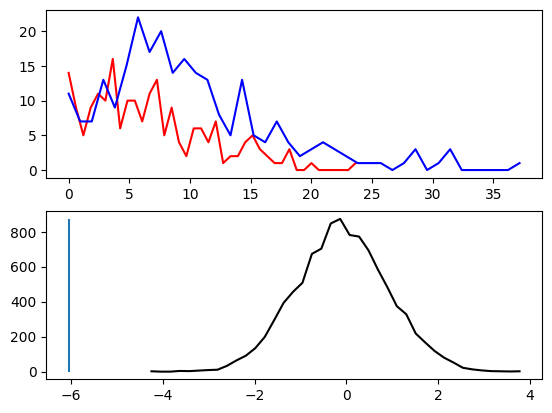

 difference of means:-3.372199   p-value=0 < 0.050000 ----> significantly different


In [972]:
#@title Bootstrap
N=200
M=250
X = np.random.normal(2.5,1.0,N)**2
Y = np.random.normal(3.0,1.0,M)**2
B=10000
flag_plot=True
alpha = 0.05

def bootstrap_test(X,Y,n,m,B,flag_plot=False):
  def draw_samples(data,data_drawn):
    for nn in range(len(data_drawn)):
      rand = np.random.randint(0,len(data))
      data_drawn[nn] = data[rand]
    return data_drawn # Moved this line inside the function



  N = len(X)
  M = len(Y)


  #print("X =", X)
  #print("Y =", Y)

  #print("NaN X =", np.isnan(X).sum())
  #print("NaN Y =", np.isnan(Y).sum())

  X = np.asarray(X, dtype=float)
  Y = np.asarray(Y, dtype=float)
  X = [a for a in X if not math.isnan(a)]
  Y = [a for a in Y if not math.isnan(a)]

  bins = 40

  hist_X,bin_edges_X = np.histogram(X,bins=bins)
  hist_Y,bin_edges_Y = np.histogram(Y,bins=bins)

  xmean = np.mean(X)
  ymean = np.mean(Y)
  xvar  = np.var(X)
  yvar  = np.var(Y)
  dmean = xmean-ymean
  if (len(np.unique(X)) == 1 and len(np.unique(Y)) == 1 and np.isclose(X[0], Y[0])):
    return 0.0, 1.0
  #print(xmean)
  #print(ymean)

  #print(xvar)
  #print(yvar)

  #print(np.unique(X))
  #print(np.unique(Y))

  t = (dmean)/np.sqrt(xvar/N+yvar/M)

  print("t=%f"%t)



  zmean = (xmean+ymean)/2

  xstar = X-xmean+zmean

  ystar = Y-ymean+zmean



  ## now let us bootstrap

  #B = 10000

  #n = 50

  #m = 50

  draw_x = np.zeros(n)

  draw_y = np.zeros(m)

  t_distrib = np.zeros(B)

  p = 0

  for b in range(B):

    draw_x=draw_samples(xstar,draw_x)

    draw_y=draw_samples(ystar,draw_y)

    t_distrib[b] = (np.mean(draw_x)-np.mean(draw_y))/np.sqrt(np.var(draw_x)/n+np.var(draw_y)/m)

    if t_distrib[b]>t and t>0:

      p += 1/B

    #print("%g > %g   p=%g"%(t_distrib[b],t,p))

    if t_distrib[b]<=t and t<=0:

      p += 1/B

    #print("%g <= %g    p=%g"%(t_distrib[b],t,p))



  if flag_plot==True:
    fig_label = "bootstrap p-value=%f"%p
    print(fig_label)
    plt.figure(fig_label)
    ax1 = plt.subplot(2,1,1)
    plt.plot(bin_edges_X[:bins],hist_X,'r')
    plt.plot(bin_edges_Y[:bins],hist_Y,'b')
    hist_tstar,edges_tstar = np.histogram(t_distrib,bins=bins)
    ax2 = plt.subplot(2,1,2)
    plt.plot(edges_tstar[:bins],hist_tstar,"k")
    ax2.vlines(t,0,hist_tstar.max()) # Corrected typo
    plt.show()

  return dmean,2*p

dmean,p=bootstrap_test(X,Y,N,M,B,flag_plot)

if p<alpha:
 print(" difference of means:%f   p-value=%g < %f ----> significantly different"%(dmean,p,alpha))
else:
 print(" difference of means:%f   p-value=%g >= %f ----> not different"%(dmean,p,alpha))

In [973]:
def bootstrap_phaseA_accuracy(dic_results, metric):
    phaseA = [s for s in dic_results if s["PHASE"] == "A"]
    phaseA = sorted(phaseA,key=lambda x: pd.to_datetime(x["DATE"]))

    first3 = []
    last3 = []

    for session in phaseA[:3]:
        first3.extend(session[metric])

    for session in phaseA[-3:]:
        last3.extend(session[metric])

    dmean, p = bootstrap_test(
        np.array(first3),
        np.array(last3),
        len(first3),
        len(last3),
        B=10000
    )
    return p
def bootstrap_A_vs_B(dic_results, metric):

    phaseA = sorted([s for s in dic_results if s["PHASE"] == "A"], key=lambda x: pd.to_datetime(x["DATE"]))

    phaseB = sorted([s for s in dic_results if s["PHASE"] == "B"], key=lambda x: pd.to_datetime(x["DATE"]))

    A_values = []
    B_values = []

    for session in phaseA[-3:]:
        A_values.extend(session[metric])

    for session in phaseB[:3]:
        B_values.extend(session[metric])

    dmean, p = bootstrap_test(
        np.array(A_values),
        np.array(B_values),
        len(A_values),
        len(B_values),
        B=10000
    )
    return p

def bootstrap_phaseB_accuracy(dic_results, metric):

    phaseB = [s for s in dic_results if s["PHASE"] == "B"]
    if len(phaseB) < 6:
      n = 2
    else:
      n = 3
    phaseB = sorted(phaseB,key=lambda x: pd.to_datetime(x["DATE"]))

    first3 = []
    last3 = []

    for session in phaseB[:n]:
        first3.extend(session[metric])

    for session in phaseB[-n:]:
        last3.extend(session[metric])

    dmean, p = bootstrap_test(
        np.array(first3),
        np.array(last3),
        len(first3),
        len(last3),
        B=10000
    )
    return p

In [974]:
def concat_all_sessions(id):
  sessions = get_pandas_beh(id)
  final_df = []
  for index, session in enumerate(sessions):
    df = session["df"]
    df["week"] = session["week"]
    df["date"] = session["date"]
    df["phase"] = session["phase"]
    df["block_index"] = df["block_index"] + 6*index
    final_df.append(df)
    #print(session)
    # week = session["week"]
    # date = session["date"]
    # phase = session["phase"]
  all_df = pd.concat(final_df, ignore_index=True)
  return all_df
df = concat_all_sessions(id = 10)
display(df)
print(Counter(df["block_index"].keys()))
print(set(df["block_index"]))
#concat_all_sessions(id = 10).to_csv("data_10.csv")
#def plot_reaccion_time_boxplot_all_sessions(id, gender, asrs):

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID,week,date,phase
0,1,0,255.681165,Go,NaN,NaN,Incorrect,True,False,10,W1,2026-04-13,A
1,1,1,256.675194,Go,NaN,NaN,Incorrect,True,False,10,W1,2026-04-13,A
2,1,2,257.657825,Go,NaN,NaN,Incorrect,True,False,10,W1,2026-04-13,A
3,1,3,258.641636,Go,NaN,NaN,Incorrect,True,False,10,W1,2026-04-13,A
4,1,4,259.628052,Go,NaN,NaN,Incorrect,True,False,10,W1,2026-04-13,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8095,90,535,1234.922996,Go,space,0.433065,Correct,False,False,10,W9,2026-06-12,B
8096,90,536,1235.939503,Go,space,0.416605,Correct,False,False,10,W9,2026-06-12,B
8097,90,537,1236.956728,Go,space,0.399117,Correct,False,False,10,W9,2026-06-12,B
8098,90,538,1237.972765,Go,space,0.383017,Correct,False,False,10,W9,2026-06-12,B


Counter({0: 1, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1, 10: 1, 11: 1, 12: 1, 13: 1, 14: 1, 15: 1, 16: 1, 17: 1, 18: 1, 19: 1, 20: 1, 21: 1, 22: 1, 23: 1, 24: 1, 25: 1, 26: 1, 27: 1, 28: 1, 29: 1, 30: 1, 31: 1, 32: 1, 33: 1, 34: 1, 35: 1, 36: 1, 37: 1, 38: 1, 39: 1, 40: 1, 41: 1, 42: 1, 43: 1, 44: 1, 45: 1, 46: 1, 47: 1, 48: 1, 49: 1, 50: 1, 51: 1, 52: 1, 53: 1, 54: 1, 55: 1, 56: 1, 57: 1, 58: 1, 59: 1, 60: 1, 61: 1, 62: 1, 63: 1, 64: 1, 65: 1, 66: 1, 67: 1, 68: 1, 69: 1, 70: 1, 71: 1, 72: 1, 73: 1, 74: 1, 75: 1, 76: 1, 77: 1, 78: 1, 79: 1, 80: 1, 81: 1, 82: 1, 83: 1, 84: 1, 85: 1, 86: 1, 87: 1, 88: 1, 89: 1, 90: 1, 91: 1, 92: 1, 93: 1, 94: 1, 95: 1, 96: 1, 97: 1, 98: 1, 99: 1, 100: 1, 101: 1, 102: 1, 103: 1, 104: 1, 105: 1, 106: 1, 107: 1, 108: 1, 109: 1, 110: 1, 111: 1, 112: 1, 113: 1, 114: 1, 115: 1, 116: 1, 117: 1, 118: 1, 119: 1, 120: 1, 121: 1, 122: 1, 123: 1, 124: 1, 125: 1, 126: 1, 127: 1, 128: 1, 129: 1, 130: 1, 131: 1, 132: 1, 133: 1, 134: 1, 135: 1, 136: 1, 137: 

In [975]:
#@title pipeline(id)
def pipeline(id):
  df_clean_list = []
  dic_results = []
  #df_raw = get_pandas_dataset(id)
  #df_raw_list = get_pandas_beh(id)
  sessions = get_pandas_beh(id)
  for session in sessions:

    df = session["df"]
    week = session["week"]
    date = session["date"]
    phase = session["phase"]


    gender = get_gender(id)
    asrs = get_asrs_score(id)
    df_clean_list.append(df)
    display(df)
    plot_reaccion_time_dots(df, id, gender, asrs)
    plot_reaccion_time_boxplot(df, id, gender, asrs, phase)

    all_accuracy_data = compute_both_accuracy(df)
    accuracy_go, accuracy_nogo = plot_accuracy(data=all_accuracy_data, id=id, merge=True, gender=gender, asrs=asrs, week=week, date=date, phase=phase)

    var_nogo, var_go, var_overall  = plot_variability_rt(df,id,gender,asrs,week,date,phase)
    mean_go_rt_blocks = compute_mean_go_rt_blocks(df)
    list_d, d_prime_all = compute_d_prime(df)

    dic_results.append({
            "ID": id,
            "WEEK": week,
            "DATE": date,
            "PHASE": phase,
            "Gender": gender,
            "ASRS": asrs,
            "Accuracy_Go": accuracy_go,
            "Accuracy_NoGo": accuracy_nogo,
            "Variability_Go": var_go,
            "Variability_NoGo": var_nogo,
            "Variability_Overall": var_overall,
            "DPrime_Blocks": list_d,
            "DPrime_All": d_prime_all,
            "MeanGoRT": mean_go_rt_blocks,
            "DF": df
        })

  plot_all_accuracy(dic_results,id)

  plot_frequency_accuracy_with_baseline_over_time(dic_results, id)
  plot_session_accuracy(dic_results, id)
  plot_frequency_accuracy_over_time(dic_results, id)
  #-
  #display(dic_results)
  plot_frequency_go_rt_over_time(dic_results,id) #***
  #plot_frequency_go_rt_over_time_median(dic_results,id)
  plot_frequency_go_variability_over_time(dic_results,id)
  #-
  plot_frequency_dprime_over_time(dic_results,id)
  plot_sleep_correlations(dic_results,id)
  plot_mood_correlations(dic_results, id)



    #plot_variability_rt(df, id, gender, asrs)
  return pd.DataFrame(dic_results)
    #plot_3_histogramme_per_block(df, id, gender, asrs)

#**Plot all graphs**

t=5.867341
t=6.230624
t=1.880090
t=-11.404677
t=1.447101
t=-2.349559
t=1.335942
t=-0.285117
t=-2.890928
t=4.140647
t=-0.161325
t=-2.911398
t=-2.290894
t=-5.030950
t=-0.892404


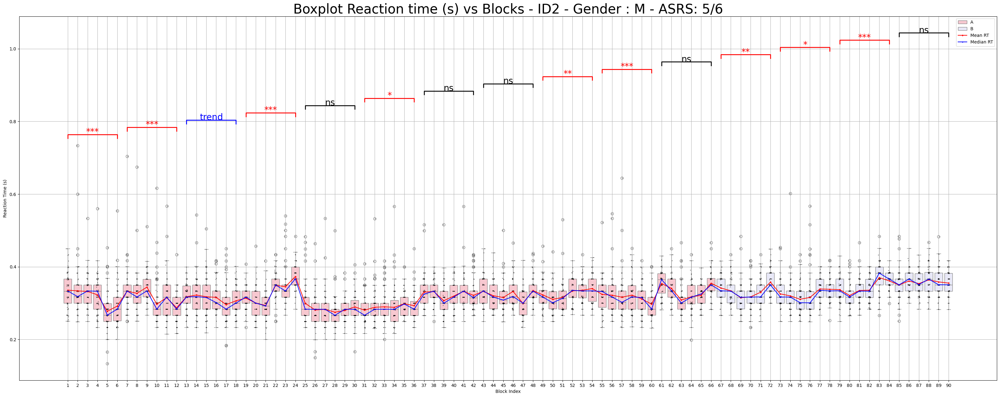

t=4.634002
t=5.664157
t=-2.779164
t=1.064893
t=-4.558215
t=0.639964
t=4.329961
t=9.784412
t=7.240290
t=-0.229717
t=1.771798
t=-8.144879
t=5.475039
t=6.604931
t=-0.139741
t=4.475984


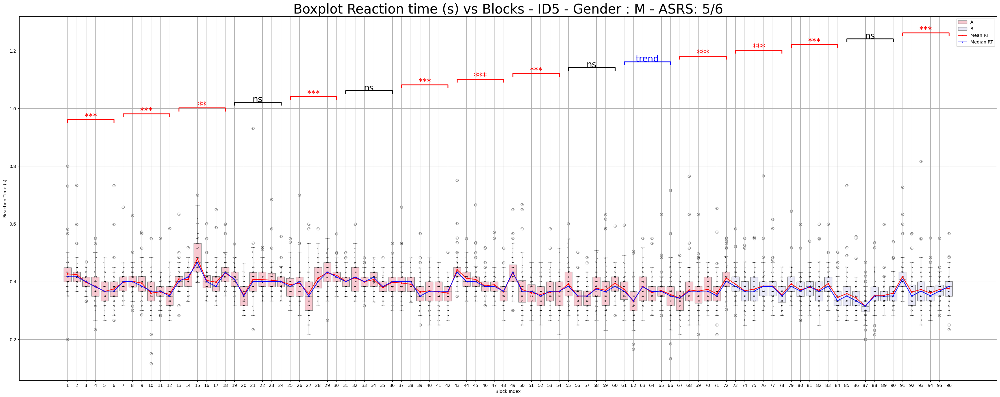

t=1.366095
t=5.760384
t=0.263849
t=-5.168689
t=3.611030
t=-0.894554
t=-0.747381
t=2.583336
t=-2.636223
t=-0.267793
t=1.319194
t=2.471077
t=4.391684


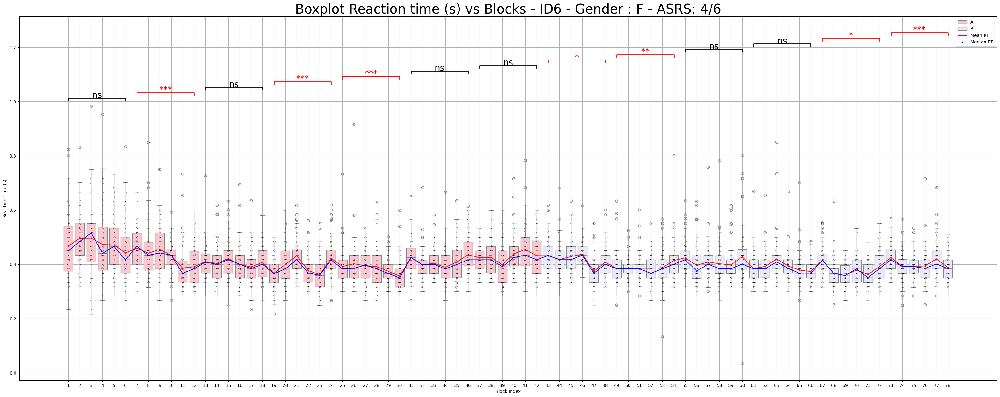

t=6.291313
t=-5.477084
t=3.510890
t=-0.607852
t=0.574342
t=-3.125338
t=-1.472615
t=-2.456501
t=-2.101416
t=4.075988
t=-0.140260
t=-2.273706
t=3.663736
t=-2.423869
t=0.340136
t=0.325957
t=-1.662600


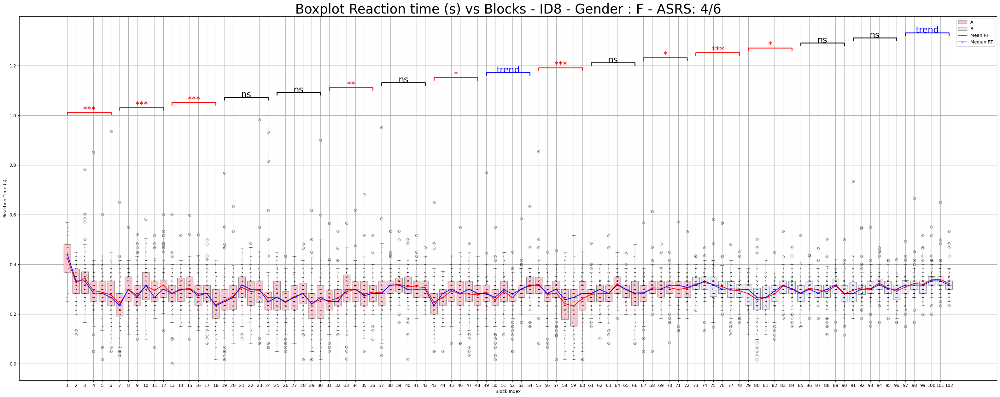

t=7.107285
t=7.712322
t=1.170066
t=6.359207
t=6.275562
t=8.316205
t=4.056196
t=6.777951
t=1.541610
t=5.273936
t=2.213438
t=4.140351
t=-0.713645
t=2.223734
t=3.422406


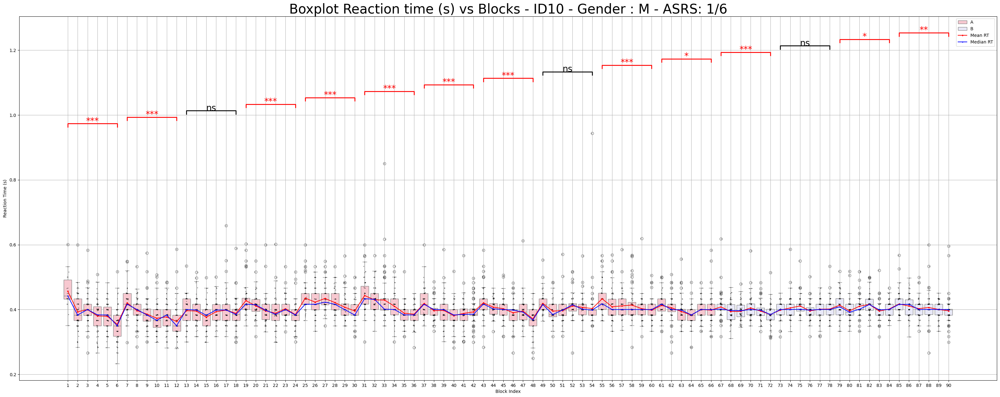

t=-3.632247
t=-0.163506
t=6.393135
t=-1.568212
t=5.541547
t=4.375492
t=2.677005
t=1.352907
t=2.534956
t=-1.081791
t=-1.707976
t=4.058423
t=0.372044
t=2.031707
t=6.382071
t=5.091161


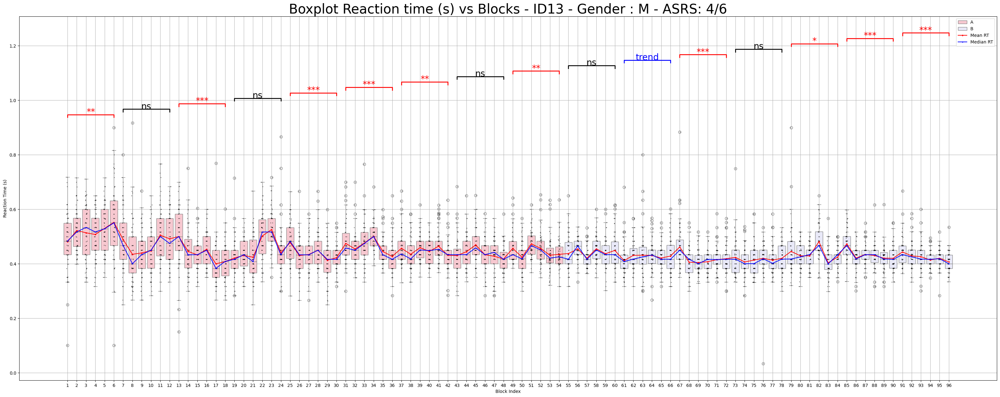

In [569]:
for id in get_id_list_participants():
  plot_reaccion_time_boxplot_all_sessions(id = id)

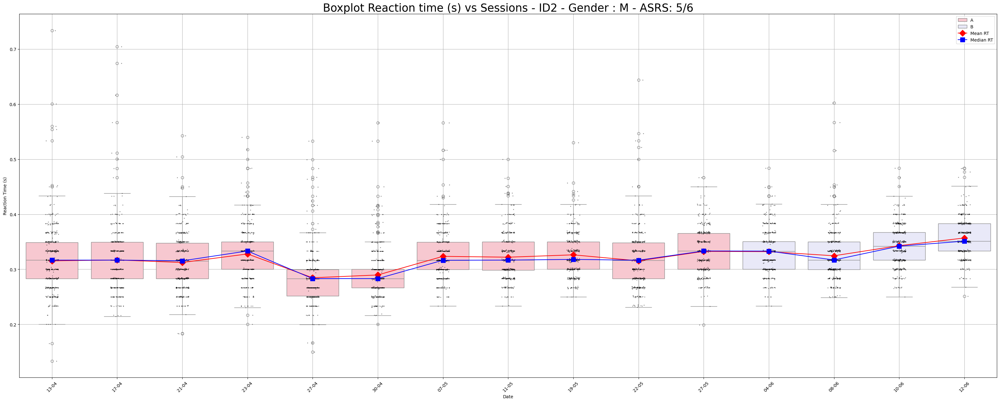

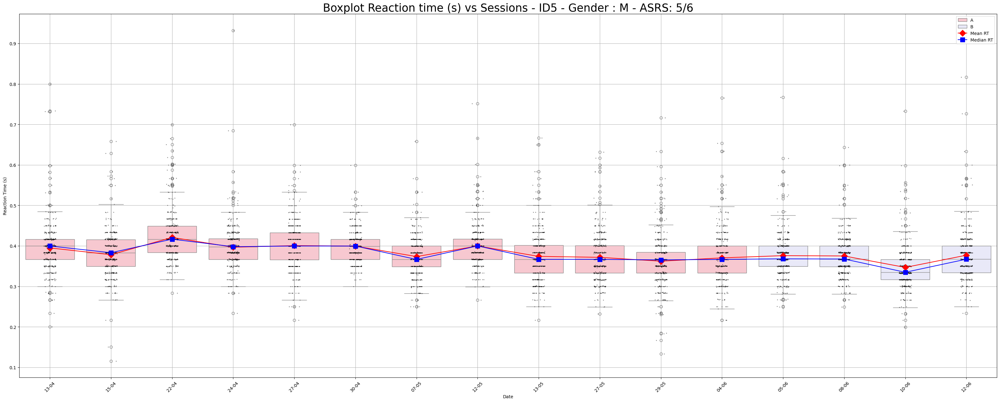

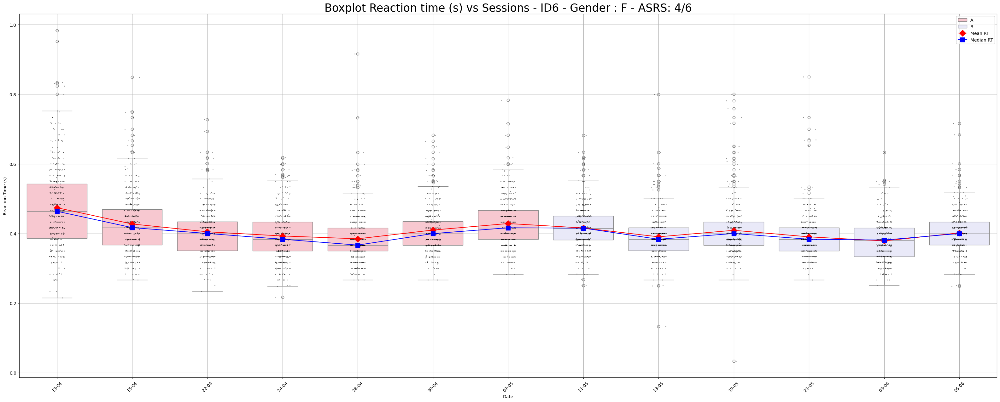

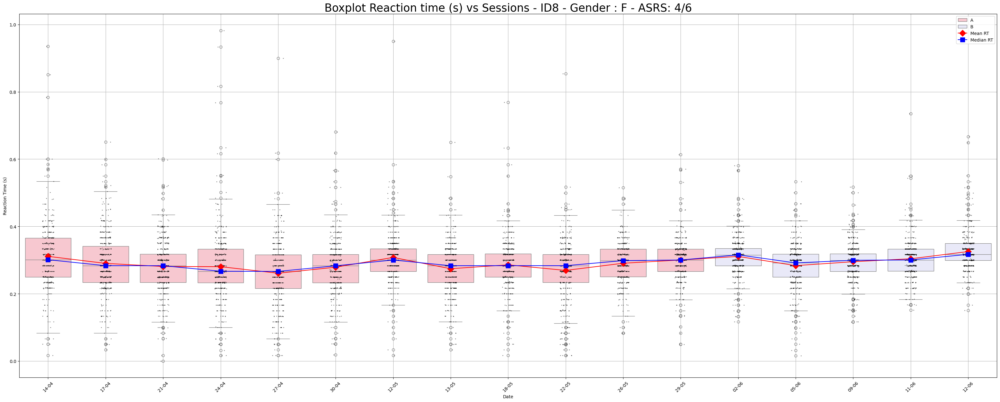

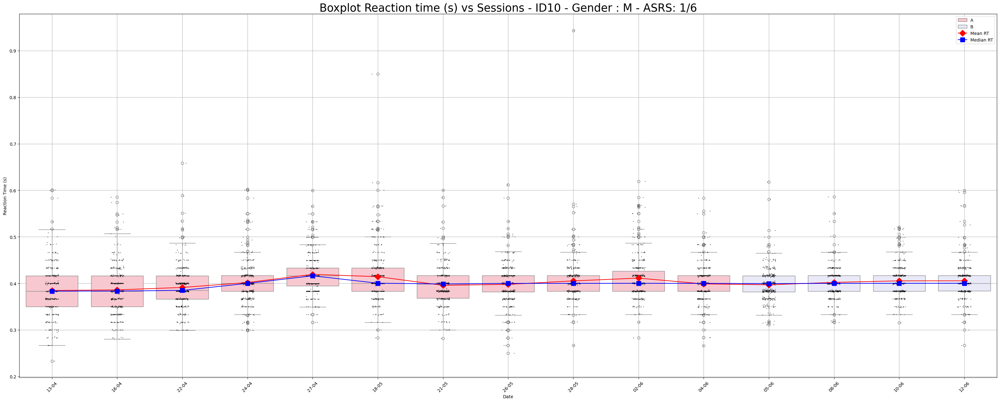

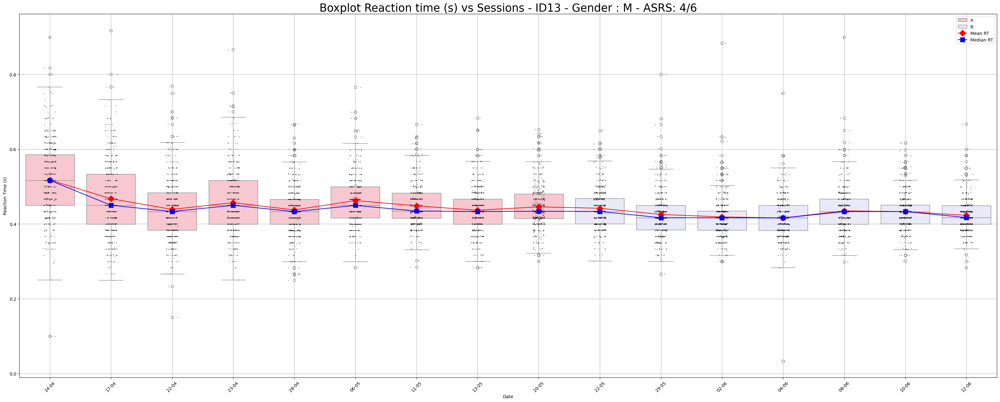

In [570]:
for id in get_id_list_participants():
  plot_reaccion_time_boxplot_all_blocks(id)

#**TRIALS**

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,402.840200,Go,space,0.823969,Correct,False,False,6
1,1,1,403.864159,Go,space,0.416709,Correct,False,False,6
2,1,2,404.880699,No_Go,space,0.333501,Incorrect,False,True,6
3,1,3,405.897801,Go,space,0.316254,Correct,False,False,6
4,1,4,406.914069,Go,space,0.368002,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1055.292639,Go,space,0.516893,Correct,False,False,6
536,6,536,1056.310719,Go,space,0.665414,Correct,False,False,6
537,6,537,1057.326103,No_Go,NaN,NaN,Correct,False,False,6
538,6,538,1058.342952,Go,space,0.533065,Correct,False,False,6


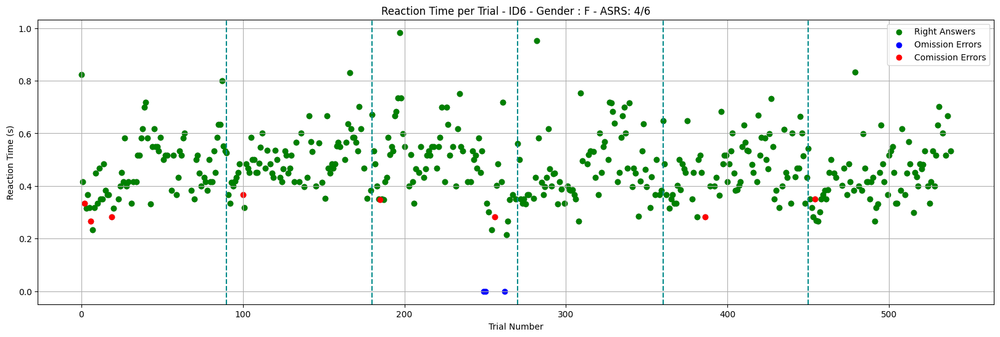

t=1.366095


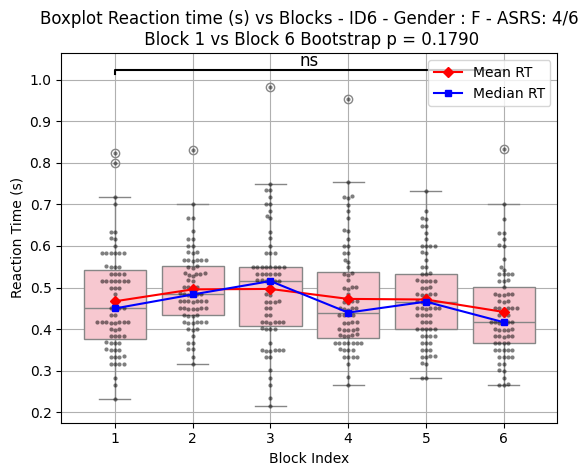

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 0.9583333333333334,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

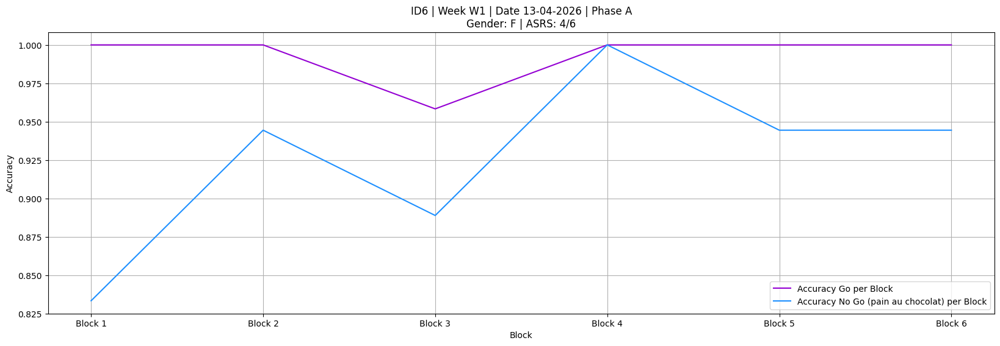

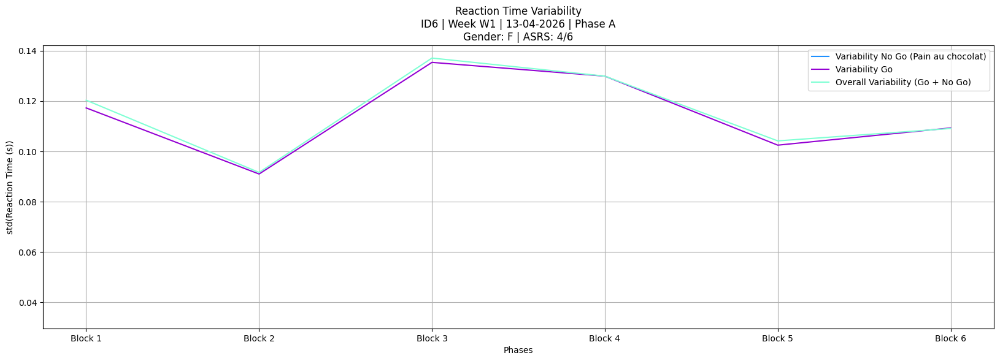

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,363.030833,Go,space,0.518396,Correct,False,False,6
1,1,1,364.049294,Go,space,0.466610,Correct,False,False,6
2,1,2,365.065816,No_Go,NaN,NaN,Correct,False,False,6
3,1,3,366.083182,Go,space,0.482889,Correct,False,False,6
4,1,4,367.099856,Go,space,0.533103,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1017.088975,Go,space,0.349952,Correct,False,False,6
536,6,536,1018.105656,Go,space,0.417028,Correct,False,False,6
537,6,537,1019.122511,Go,space,0.435145,Correct,False,False,6
538,6,538,1020.138866,Go,space,0.416529,Correct,False,False,6


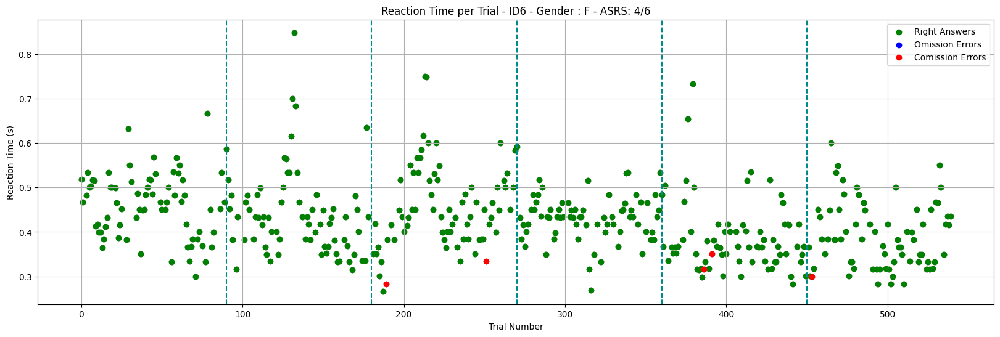

t=5.760384


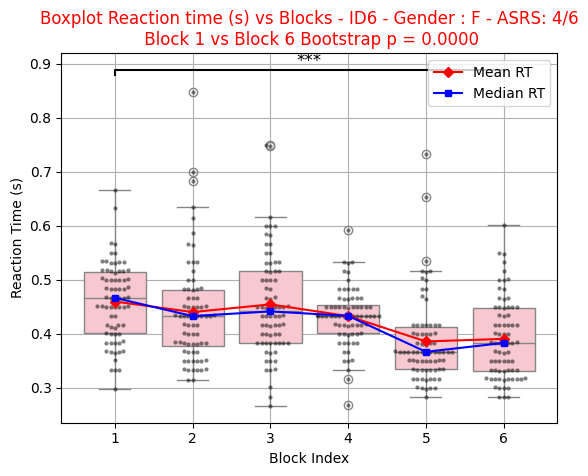

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

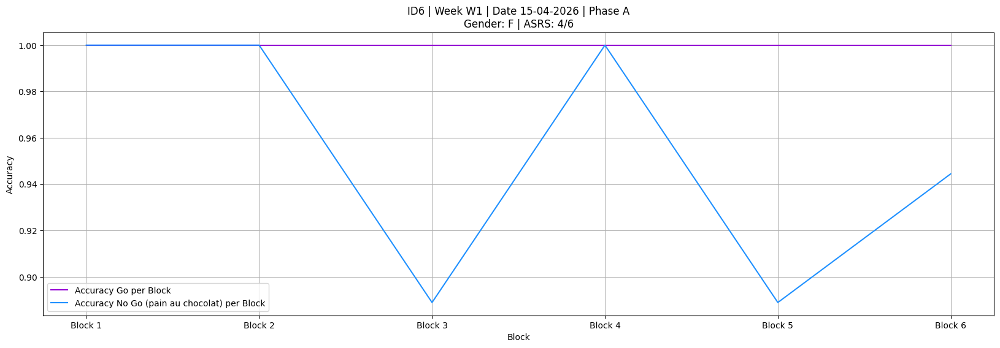

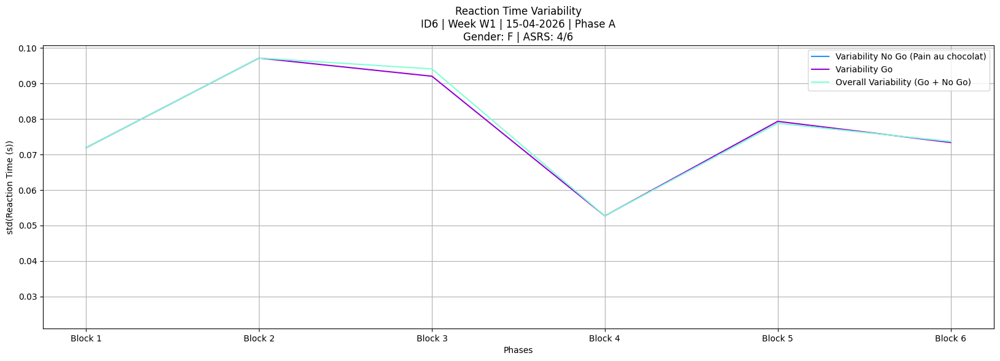

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,252.659066,Go,space,0.727354,Correct,False,False,6
1,1,1,253.636425,Go,space,0.516563,Correct,False,False,6
2,1,2,254.619867,No_Go,NaN,NaN,Correct,False,False,6
3,1,3,255.604465,Go,space,0.350047,Correct,False,False,6
4,1,4,256.586345,Go,space,0.433508,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,885.859136,No_Go,NaN,NaN,Correct,False,False,6
536,6,536,886.843594,No_Go,NaN,NaN,Correct,False,False,6
537,6,537,887.825801,Go,space,0.399936,Correct,False,False,6
538,6,538,888.810486,Go,space,0.398866,Correct,False,False,6


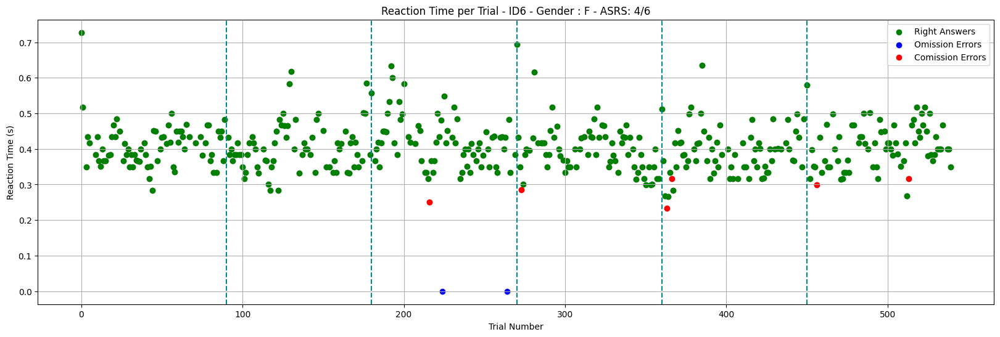

t=0.263849


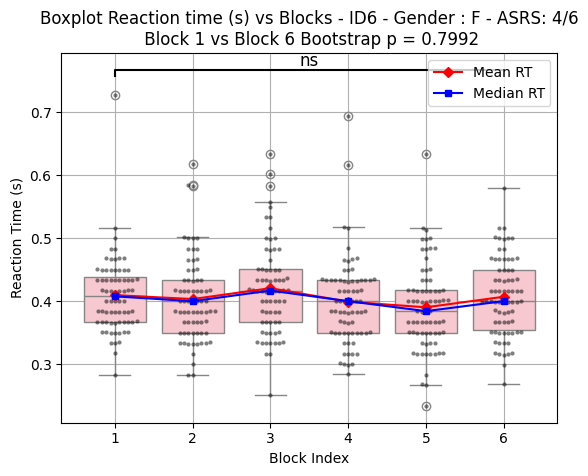

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3',
  'Accuracy Go': 0.9722222222222222,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

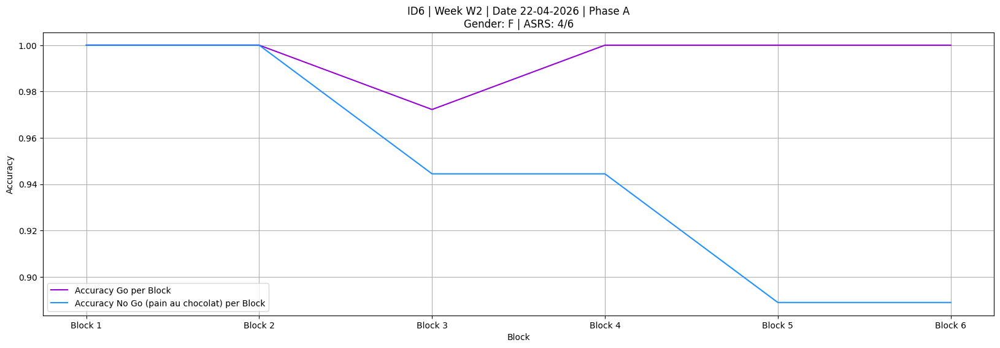

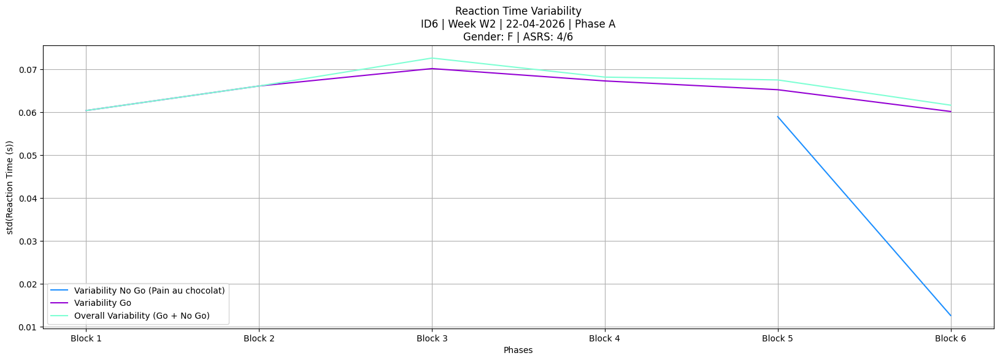

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,15.811564,Go,NaN,NaN,Incorrect,True,False,6
1,1,1,16.831659,No_Go,space,0.216703,Incorrect,False,True,6
2,1,2,17.849186,Go,space,0.315535,Correct,False,False,6
3,1,3,18.864730,Go,space,0.350044,Correct,False,False,6
4,1,4,19.882531,Go,space,0.333265,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,672.983334,Go,space,0.366525,Correct,False,False,6
536,6,536,674.002358,Go,space,0.381191,Correct,False,False,6
537,6,537,675.016708,Go,space,0.450149,Correct,False,False,6
538,6,538,676.034142,Go,space,0.351619,Correct,False,False,6


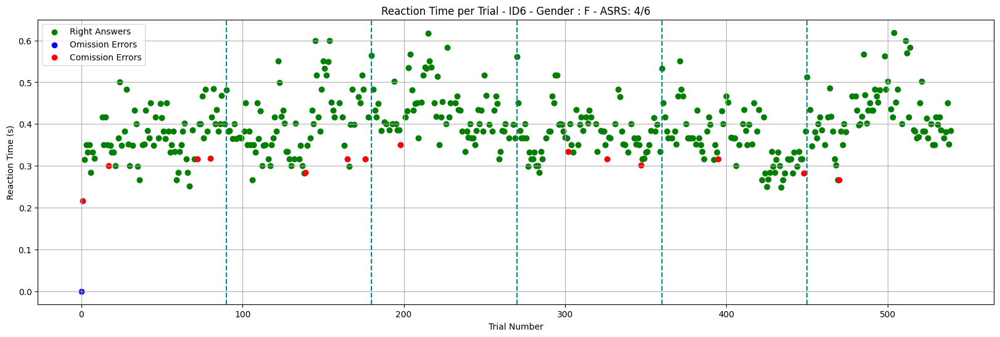

t=-5.168689


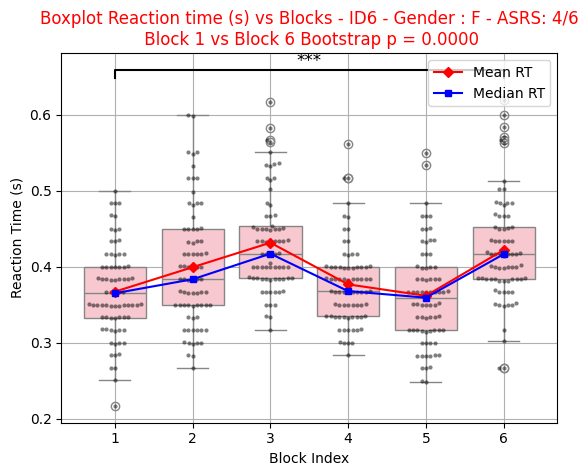

[{'Block': 'Block 1',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

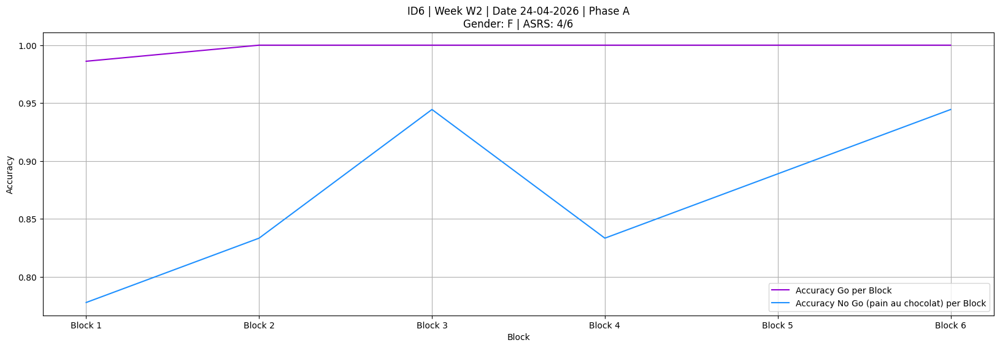

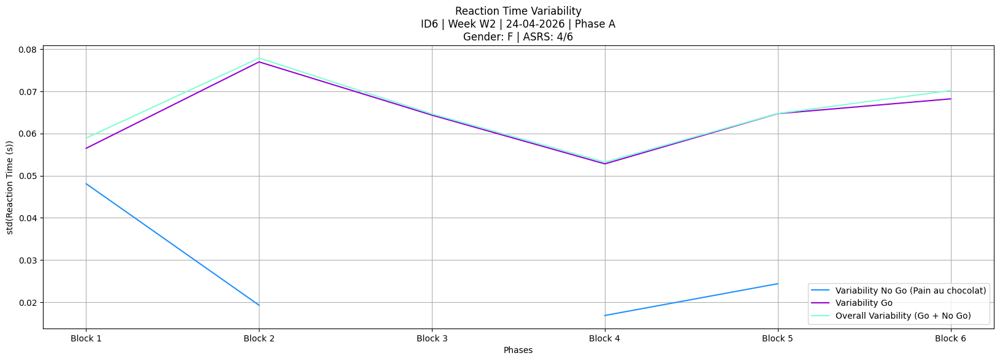

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,26.056760,Go,space,0.515049,Correct,False,False,6
1,1,1,27.071313,Go,space,0.366333,Correct,False,False,6
2,1,2,28.086935,Go,space,0.333366,Correct,False,False,6
3,1,3,29.103026,No_Go,NaN,NaN,Correct,False,False,6
4,1,4,30.119928,Go,space,0.349707,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,680.491841,Go,space,0.299828,Correct,False,False,6
536,6,536,681.507663,Go,space,0.333094,Correct,False,False,6
537,6,537,682.523489,Go,space,0.333065,Correct,False,False,6
538,6,538,683.539088,No_Go,NaN,NaN,Correct,False,False,6


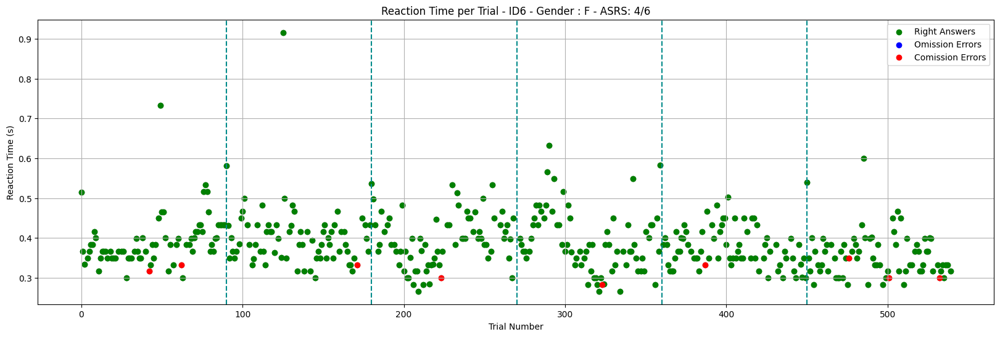

t=3.611030


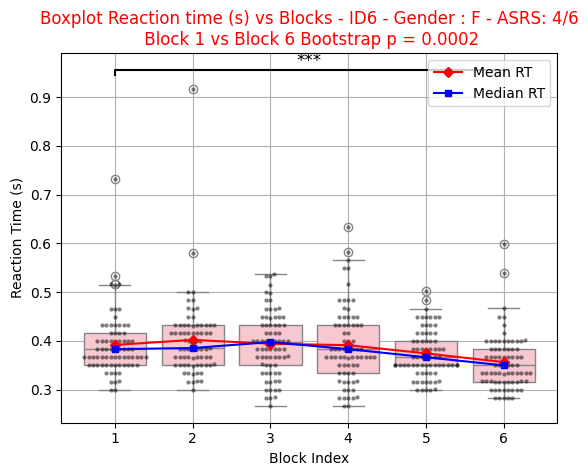

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334}]

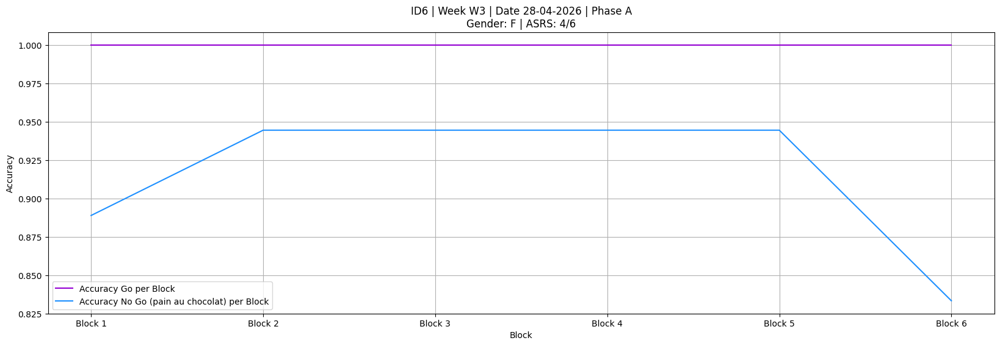

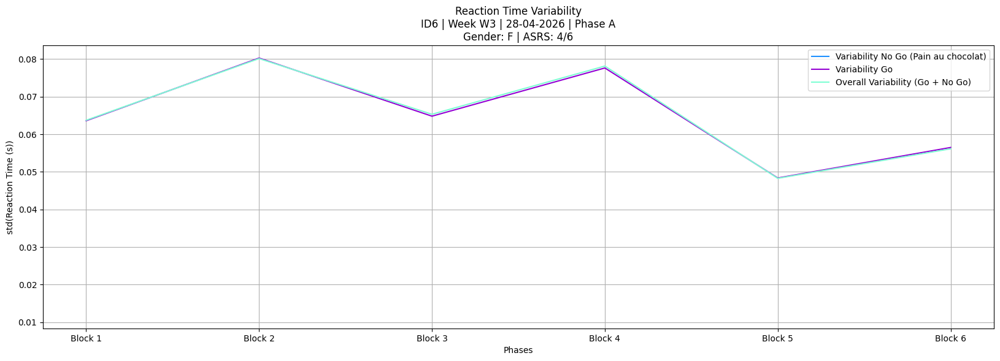

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,33.115609,Go,space,0.441387,Correct,False,False,6
1,1,1,34.122955,Go,space,0.433026,Correct,False,False,6
2,1,2,35.105302,No_Go,NaN,NaN,Correct,False,False,6
3,1,3,36.090023,Go,space,0.416164,Correct,False,False,6
4,1,4,37.070631,No_Go,NaN,NaN,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,668.271148,Go,space,0.399600,Correct,False,False,6
536,6,536,669.253309,No_Go,NaN,NaN,Correct,False,False,6
537,6,537,670.235819,Go,space,0.449686,Correct,False,False,6
538,6,538,671.218274,Go,space,0.449545,Correct,False,False,6


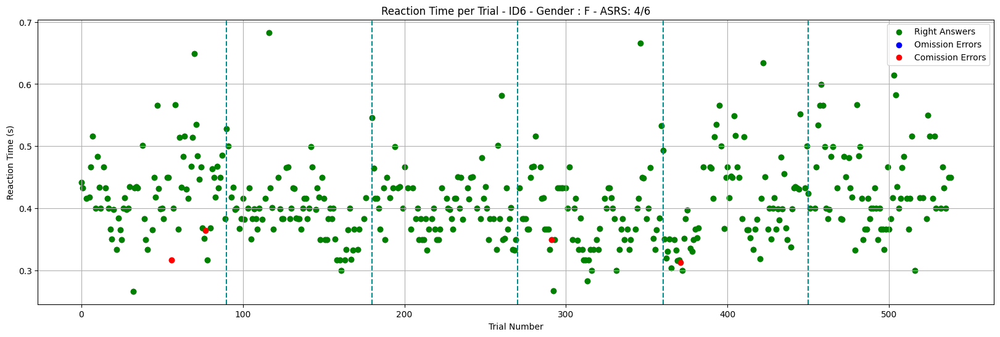

t=-0.894554


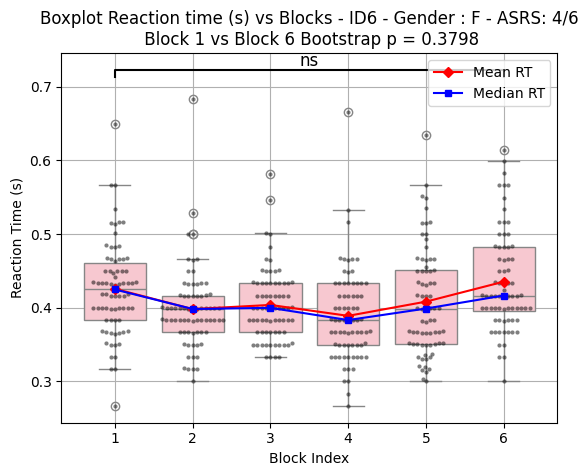

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

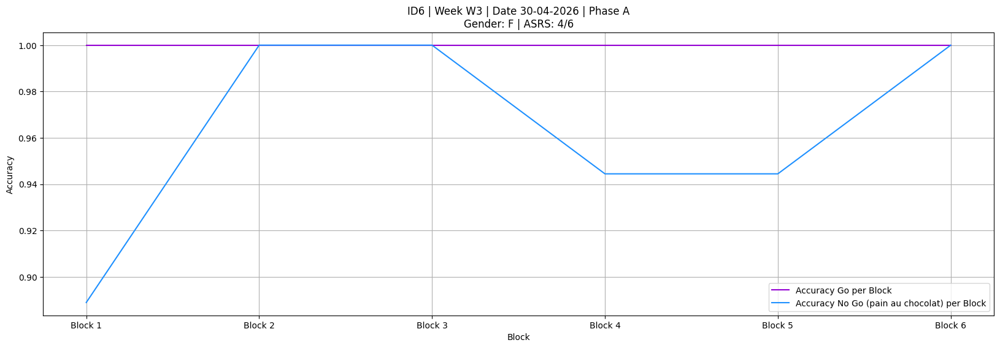

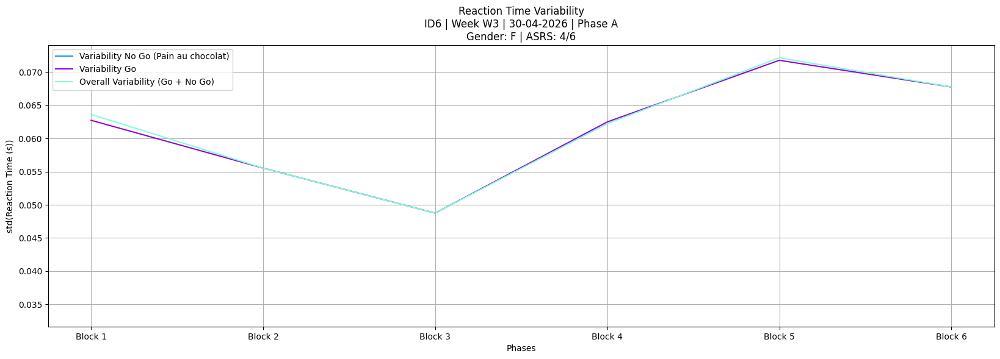

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,25.540388,No_Go,NaN,NaN,Correct,False,False,6
1,1,1,26.556784,Go,space,0.366277,Correct,False,False,6
2,1,2,27.572526,Go,space,0.449639,Correct,False,False,6
3,1,3,28.588272,Go,space,0.466114,Correct,False,False,6
4,1,4,29.603842,Go,space,0.499686,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,679.792564,Go,space,0.383184,Correct,False,False,6
536,6,536,680.808390,Go,space,0.349621,Correct,False,False,6
537,6,537,681.824260,No_Go,NaN,NaN,Correct,False,False,6
538,6,538,682.839823,Go,space,0.399721,Correct,False,False,6


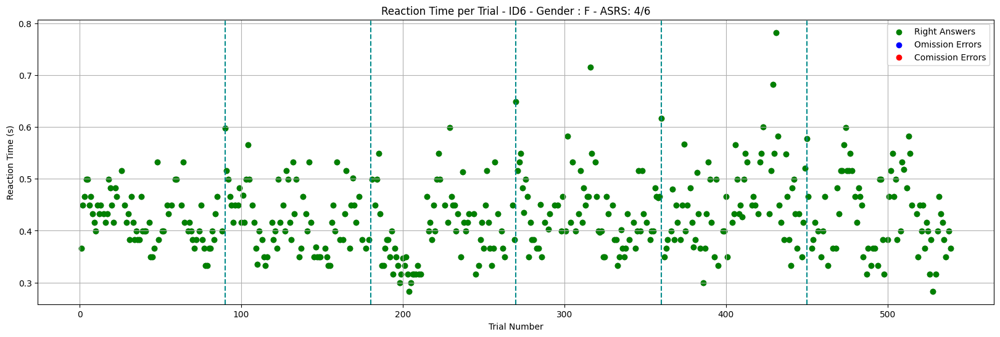

t=-0.747381


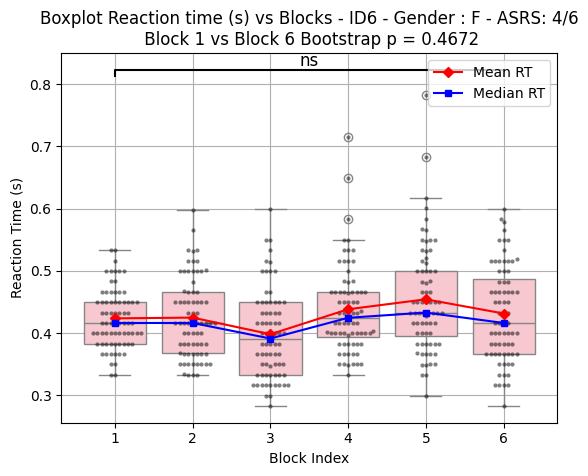

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

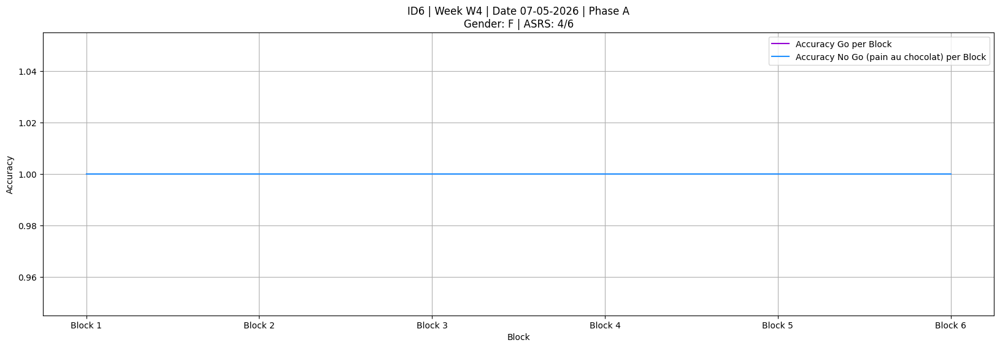

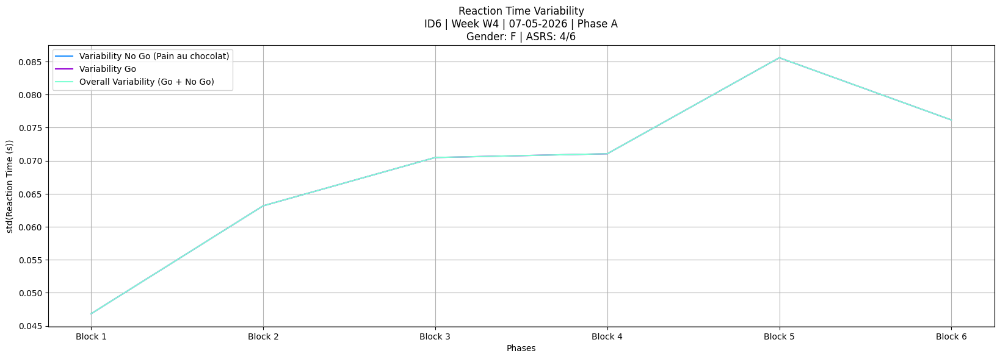

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,390.931595,Go,space,0.521550,Correct,False,False,6
1,1,1,391.969621,No_Go,NaN,NaN,Correct,False,False,6
2,1,2,392.986371,Go,space,0.383487,Correct,False,False,6
3,1,3,394.003323,No_Go,NaN,NaN,Correct,False,False,6
4,1,4,395.021961,Go,space,0.333120,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1044.009399,Go,space,0.451128,Correct,False,False,6
536,6,536,1045.025837,No_Go,NaN,NaN,Correct,False,False,6
537,6,537,1046.042765,Go,space,0.400057,Correct,False,False,6
538,6,538,1047.059323,Go,space,0.400182,Correct,False,False,6


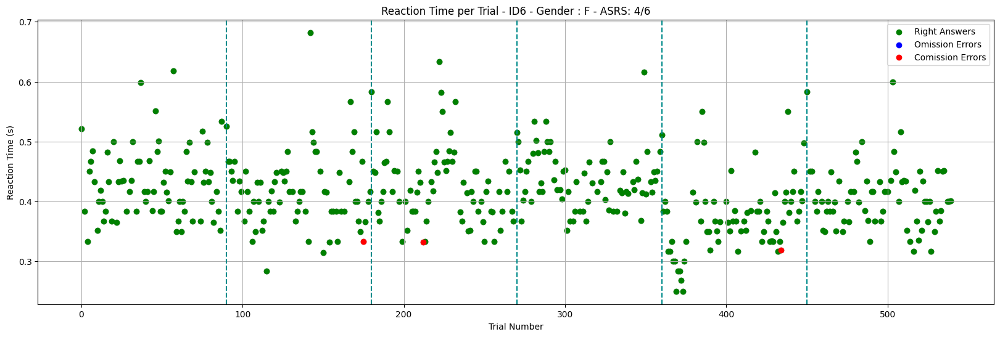

t=2.583336


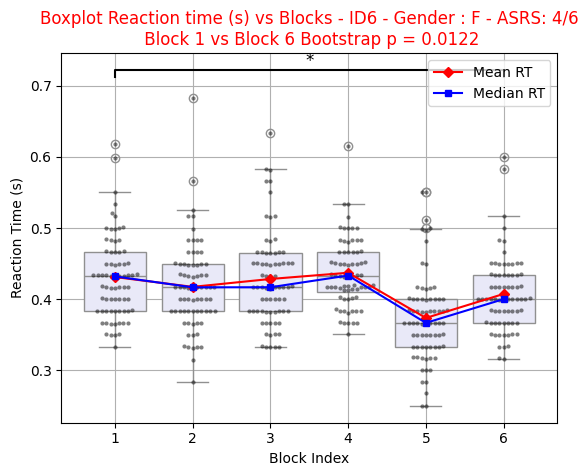

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

SESSION DATE: 2026-05-11 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
7,2026-05-11,B,"12,30,30,12,20,20"


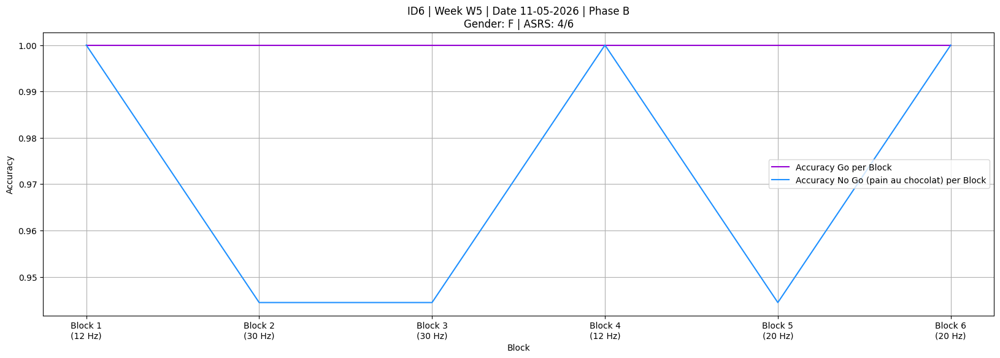

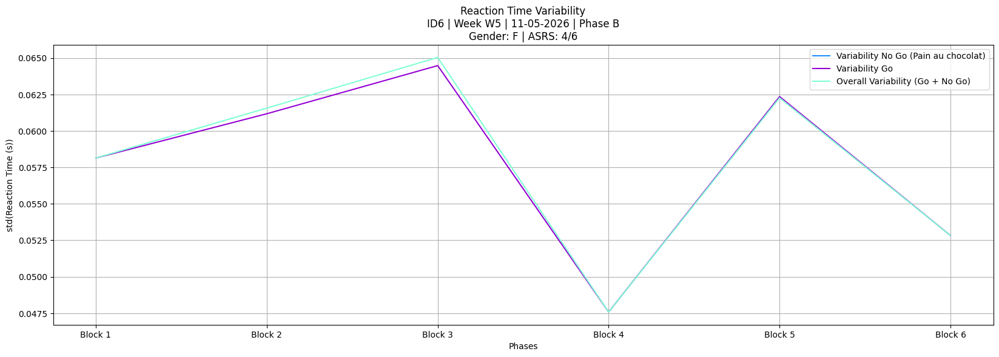

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,280.935981,Go,space,0.587403,Correct,False,False,6
1,1,1,281.973358,Go,space,0.400012,Correct,False,False,6
2,1,2,282.989954,Go,space,0.383426,Correct,False,False,6
3,1,3,284.006594,Go,space,0.316729,Correct,False,False,6
4,1,4,285.024154,Go,space,0.283552,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,940.394907,Go,space,0.466557,Correct,False,False,6
536,6,536,941.411519,Go,space,0.383395,Correct,False,False,6
537,6,537,942.428048,Go,space,0.400297,Correct,False,False,6
538,6,538,943.444852,Go,space,0.400083,Correct,False,False,6


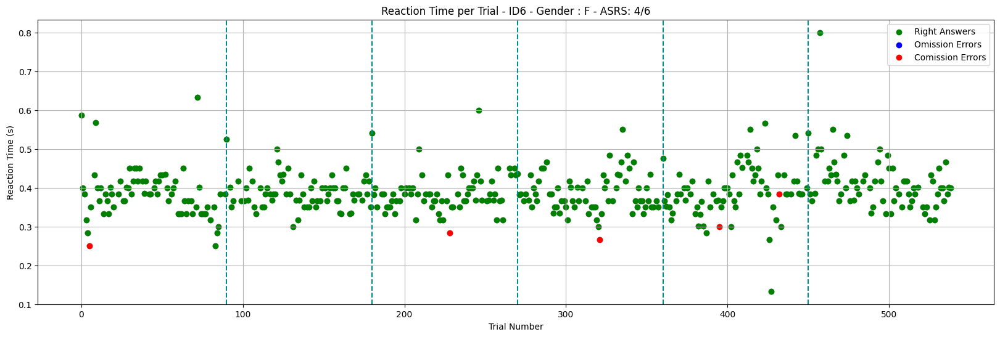

t=-2.636223


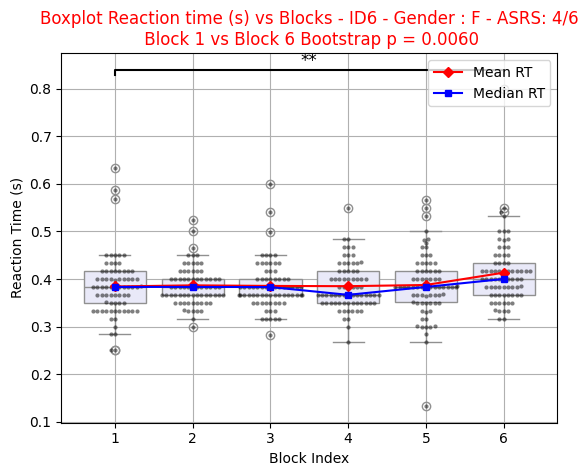

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

SESSION DATE: 2026-05-13 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
8,2026-05-13,B,"30,12,20,30,12,20"


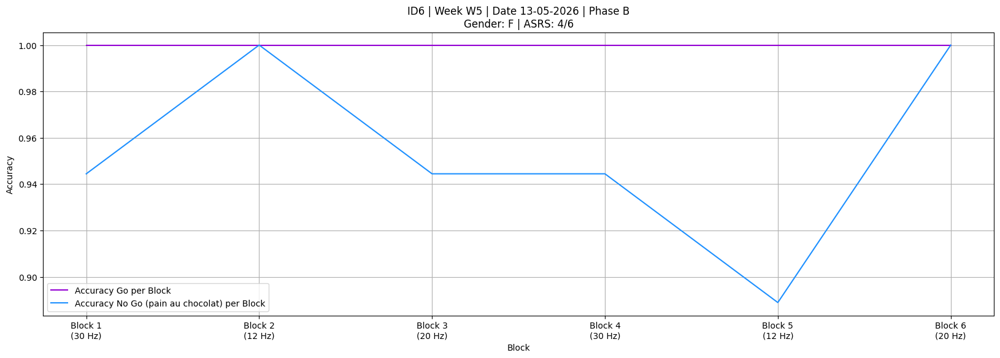

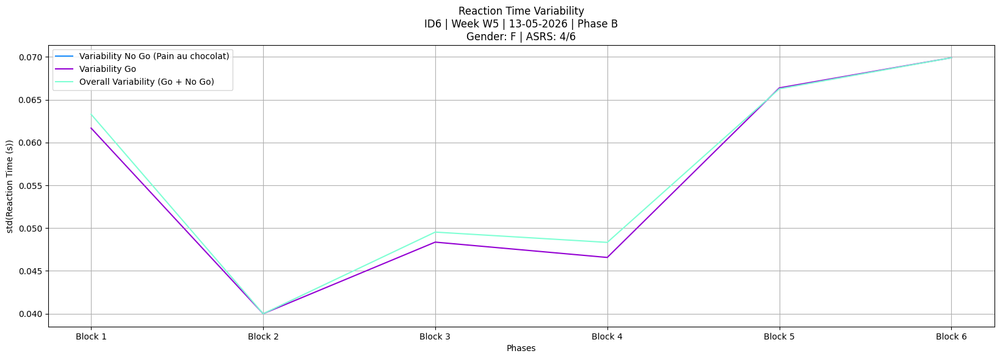

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,305.332489,Go,space,0.533189,Correct,False,False,6
1,1,1,306.382245,Go,space,0.433177,Correct,False,False,6
2,1,2,307.398883,Go,space,0.466848,Correct,False,False,6
3,1,3,308.416009,Go,space,0.449762,Correct,False,False,6
4,1,4,309.432513,Go,space,0.401639,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,955.069956,Go,space,0.717055,Correct,False,False,6
536,6,536,956.086924,Go,space,0.800009,Correct,False,False,6
537,6,537,957.103467,Go,NaN,NaN,Incorrect,True,False,6
538,6,538,958.119987,Go,space,0.033345,Correct,False,False,6


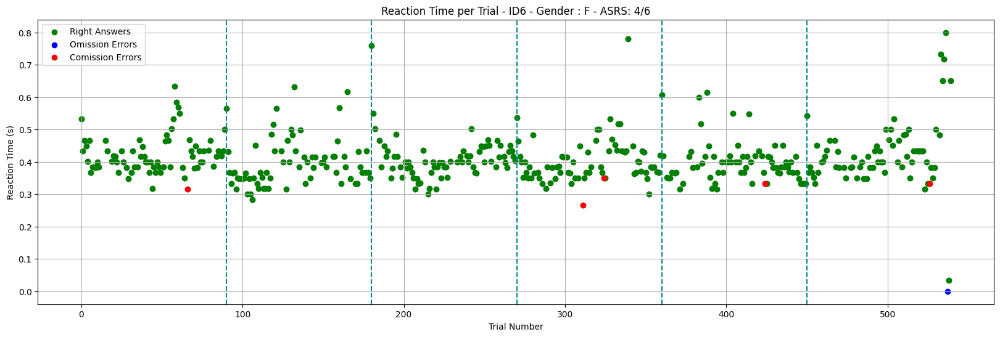

t=-0.267793


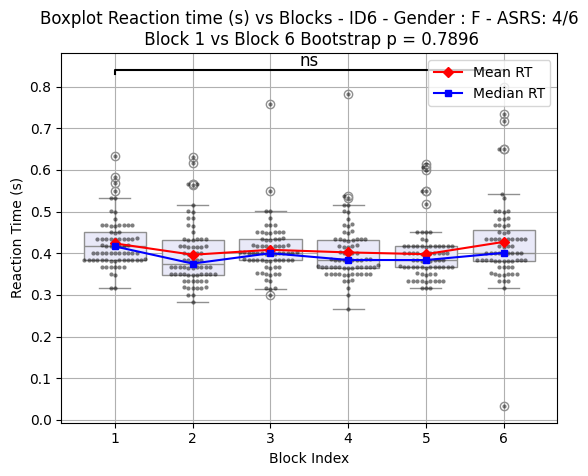

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.9444444444444444}]

SESSION DATE: 2026-05-19 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
9,2026-05-19,B,"12,12,20,30,20,30"


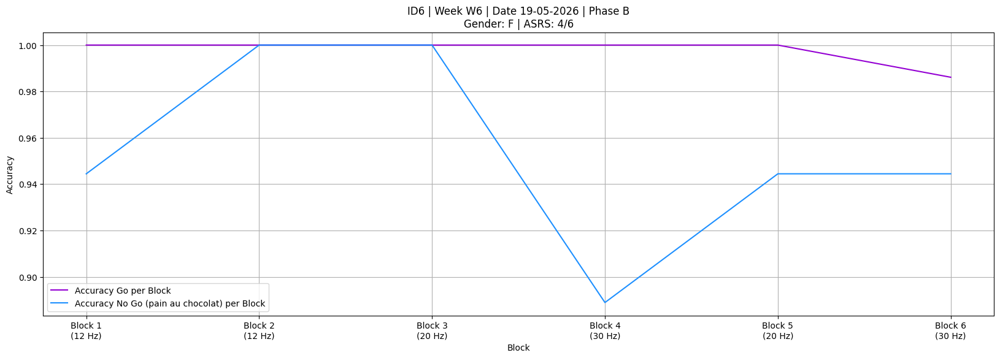

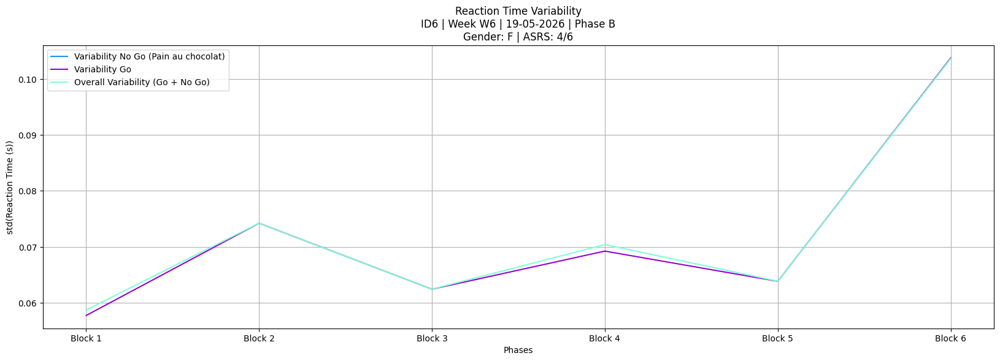

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,268.862164,Go,space,0.669426,Correct,False,False,6
1,1,1,269.864890,Go,space,0.450063,Correct,False,False,6
2,1,2,270.881271,Go,space,0.383463,Correct,False,False,6
3,1,3,271.897959,Go,space,0.349891,Correct,False,False,6
4,1,4,272.914486,Go,space,0.316967,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,934.389132,No_Go,NaN,NaN,Correct,False,False,6
536,6,536,935.405766,Go,space,0.366578,Correct,False,False,6
537,6,537,936.422262,Go,space,0.483258,Correct,False,False,6
538,6,538,937.438941,Go,space,0.399953,Correct,False,False,6


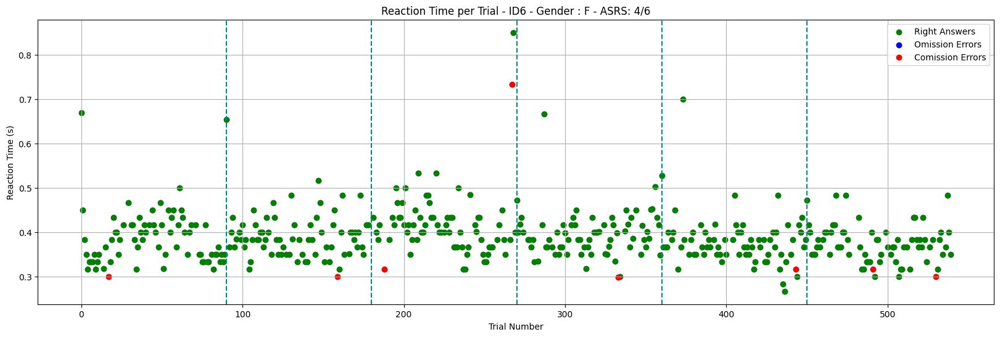

t=1.319194


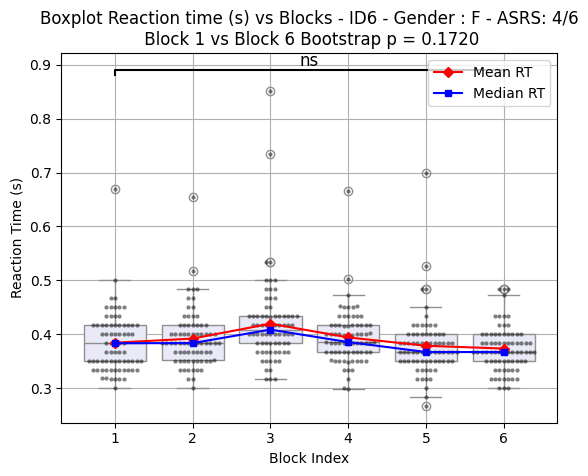

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

SESSION DATE: 2026-05-21 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
10,2026-05-21,B,"20,20,30,30,12,12"


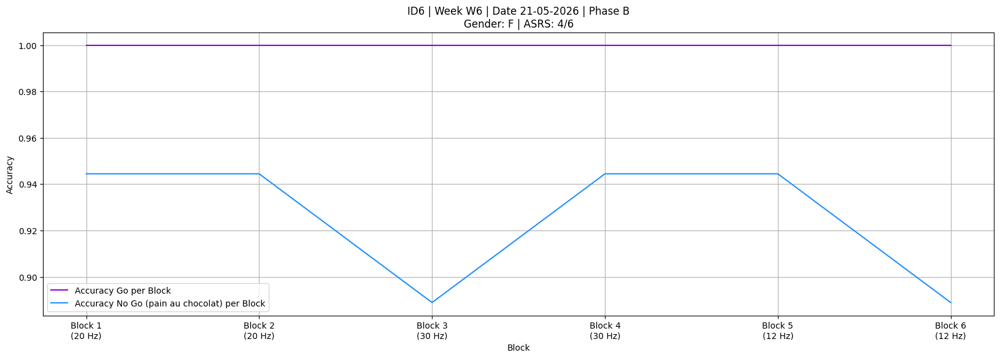

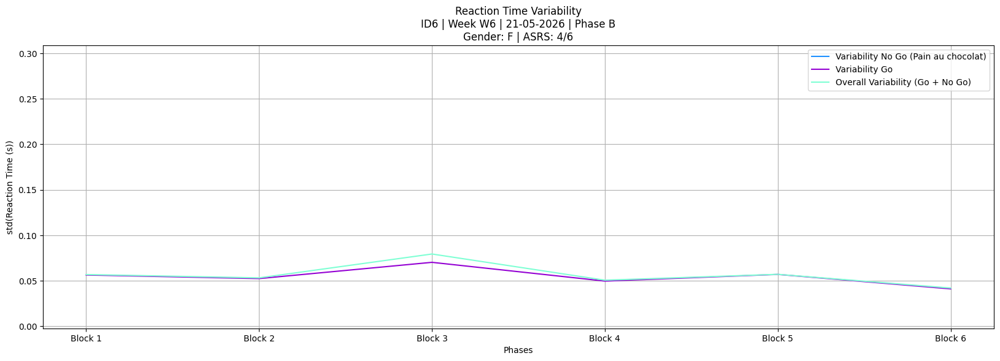

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,1602.653337,Go,space,0.553860,Correct,False,False,6
1,1,1,1603.706888,Go,space,0.400131,Correct,False,False,6
2,1,2,1604.723520,No_Go,NaN,NaN,Correct,False,False,6
3,1,3,1605.740424,Go,space,0.350004,Correct,False,False,6
4,1,4,1606.757003,Go,space,0.434915,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,2254.354176,Go,space,0.497684,Correct,False,False,6
536,6,536,2255.368743,Go,space,0.466816,Correct,False,False,6
537,6,537,2256.387525,Go,space,0.464984,Correct,False,False,6
538,6,538,2257.402387,No_Go,NaN,NaN,Correct,False,False,6


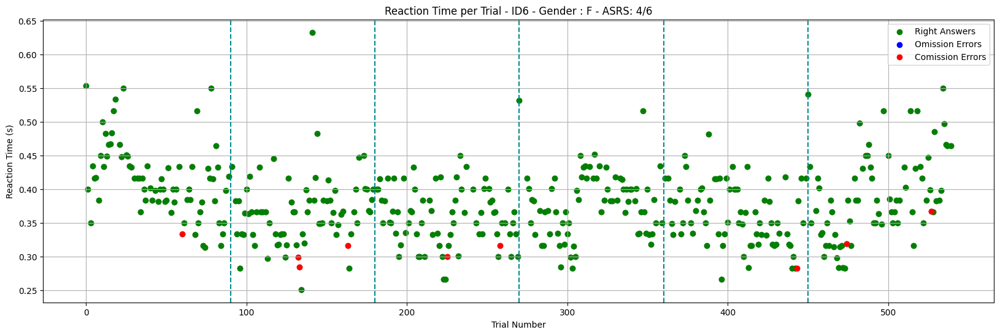

t=2.471077


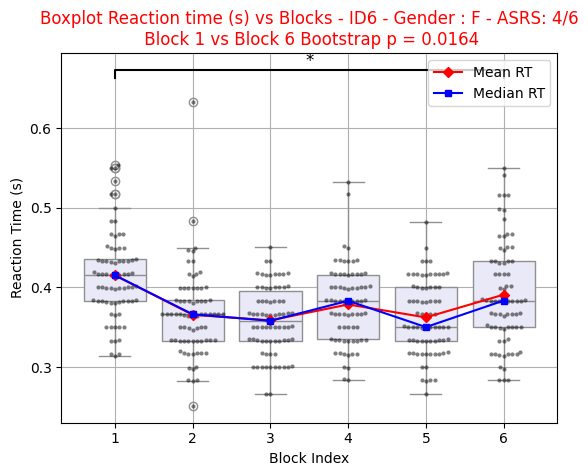

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

SESSION DATE: 2026-06-03 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
11,2026-06-03,B,"12,12,20,30,30,20"


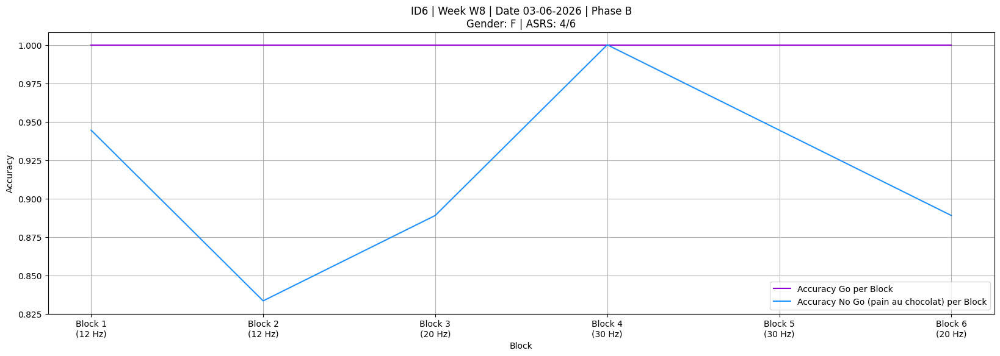

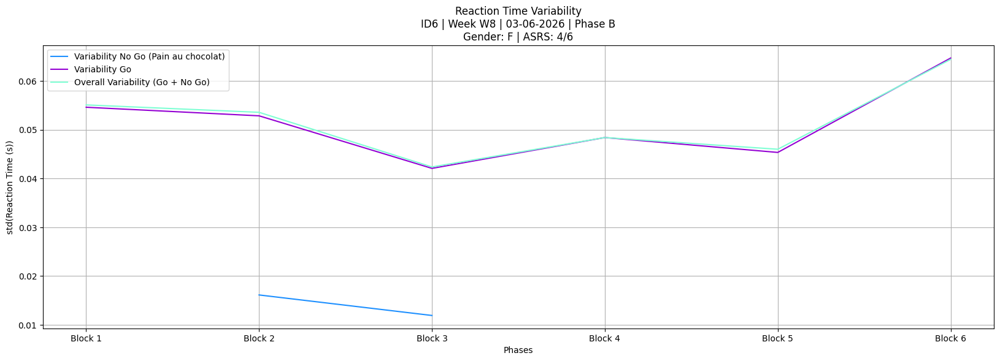

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,323.256771,Go,space,0.489754,Correct,False,False,6
1,1,1,324.263648,Go,space,0.416349,Correct,False,False,6
2,1,2,325.279949,Go,space,0.417129,Correct,False,False,6
3,1,3,326.297091,No_Go,NaN,NaN,Correct,False,False,6
4,1,4,327.314726,Go,space,0.382171,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,982.968693,No_Go,NaN,NaN,Correct,False,False,6
536,6,536,983.985482,Go,space,0.349501,Correct,False,False,6
537,6,537,985.002729,No_Go,NaN,NaN,Correct,False,False,6
538,6,538,986.018920,Go,space,0.316664,Correct,False,False,6


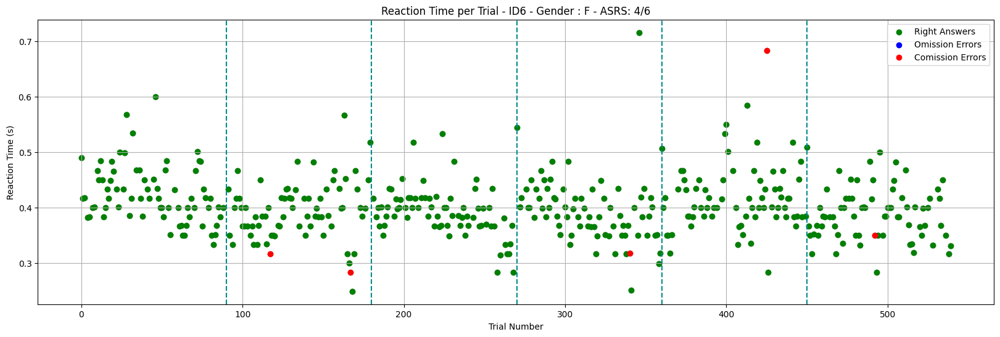

t=4.391684


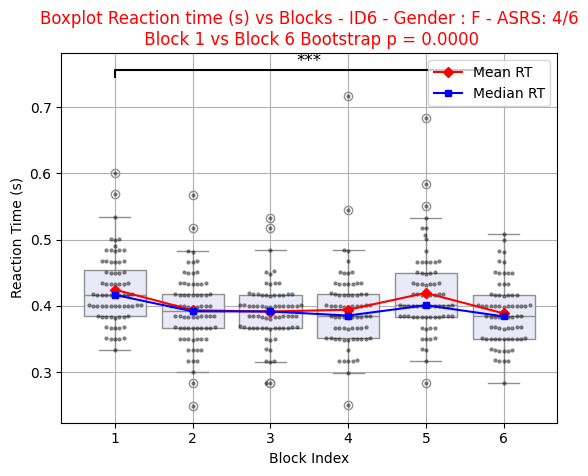

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

SESSION DATE: 2026-06-05 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
12,2026-06-05,B,"12,20,12,20,30,30"


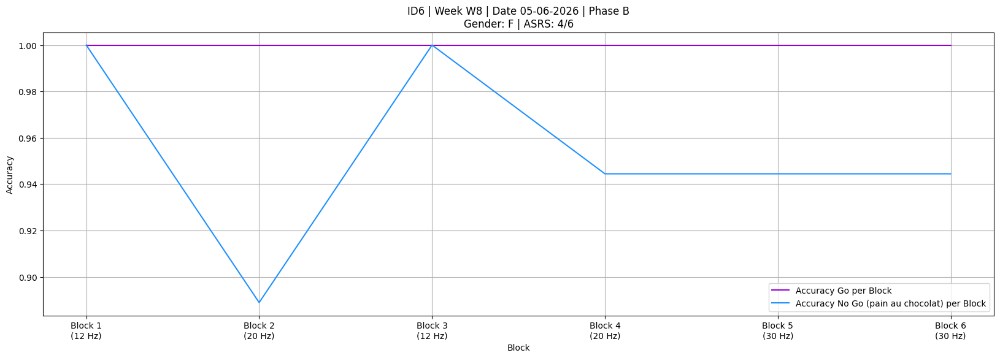

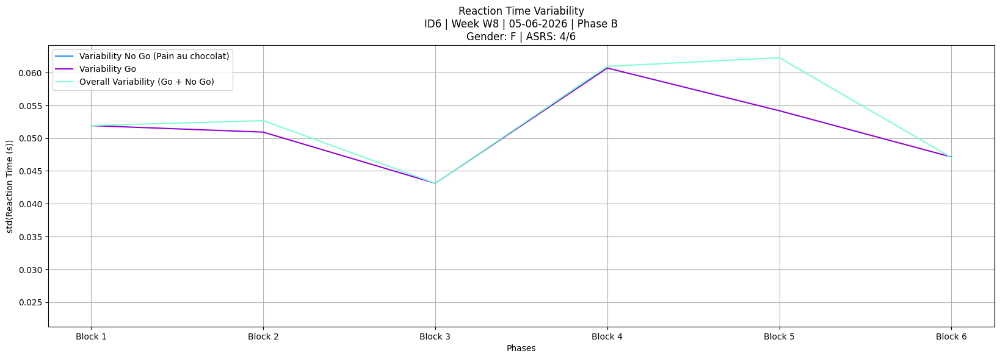

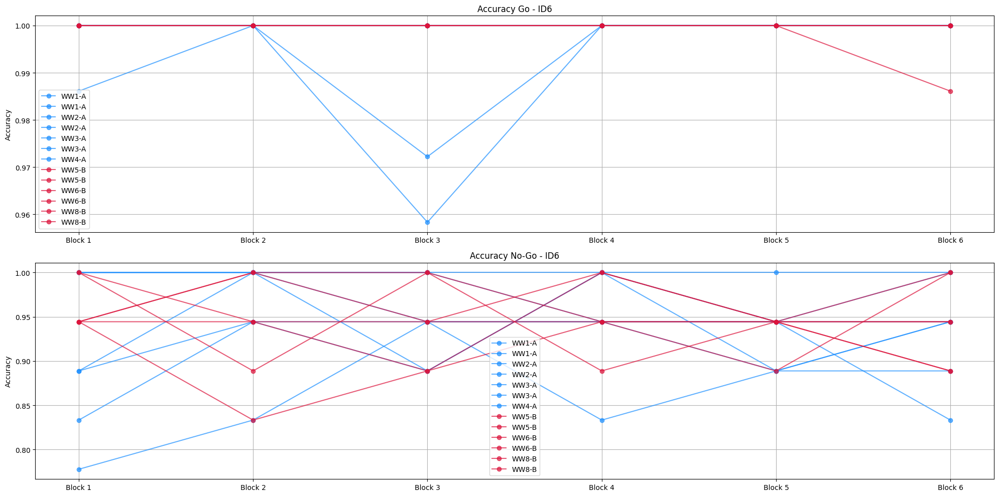

DATE: 2026-05-11 00:00:00
DATE: 2026-05-13 00:00:00
DATE: 2026-05-19 00:00:00
DATE: 2026-05-21 00:00:00
DATE: 2026-06-03 00:00:00
DATE: 2026-06-05 00:00:00


,DATE,PHASE,Go_12,Go_20,Go_30,NoGo_12,NoGo_20,NoGo_30,MeanGo,MeanNoGo
0,2026-04-13,A,0.993056,0.993056,0.993056,0.925926,0.925926,0.925926,NaN,NaN
1,2026-04-15,A,1.000000,1.000000,1.000000,0.953704,0.953704,0.953704,NaN,NaN
2,2026-04-22,A,0.995370,0.995370,0.995370,0.944444,0.944444,0.944444,NaN,NaN
3,2026-04-24,A,0.997685,0.997685,0.997685,0.870370,0.870370,0.870370,NaN,NaN
4,2026-04-28,A,1.000000,1.000000,1.000000,0.916667,0.916667,0.916667,NaN,NaN
5,2026-04-30,A,1.000000,1.000000,1.000000,0.962963,0.962963,0.962963,NaN,NaN
6,2026-05-07,A,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,NaN
7,2026-05-11,B,1.000000,1.000000,1.000000,1.000000,0.972222,0.944444,1.000000,0.972222
8,2026-05-13,B,1.000000,1.000000,1.000000,0.944444,0.972222,0.944444,1.000000,0.953704
9,2026-05-19,B,1.000000,1.000000,0.993056,0.972222,0.972222,0.916667,0.997685,0.953704


t=-1.467348
t=-1.122809
t=0.000000
t=1.028992


/tmp/ipykernel_1316/346653522.py:91: RuntimeWarning: divide by zero encountered in scalar divide
  t_distrib[b] = (np.mean(draw_x)-np.mean(draw_y))/np.sqrt(np.var(draw_x)/n+np.var(draw_y)/m)


t=-1.028992
t=2.080002
Go A-A   p = 0.0768
Go A-B   p = 0.1470
Go B-B   p = 0.1512
NoGo A-A p = 0.3072
NoGo A-B p = 0.9444
NoGo B-B p = 0.0508


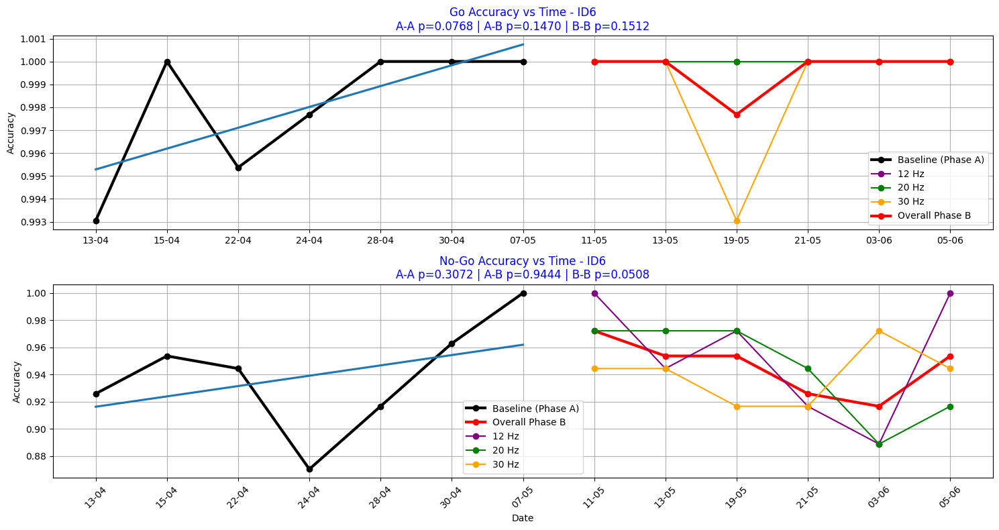

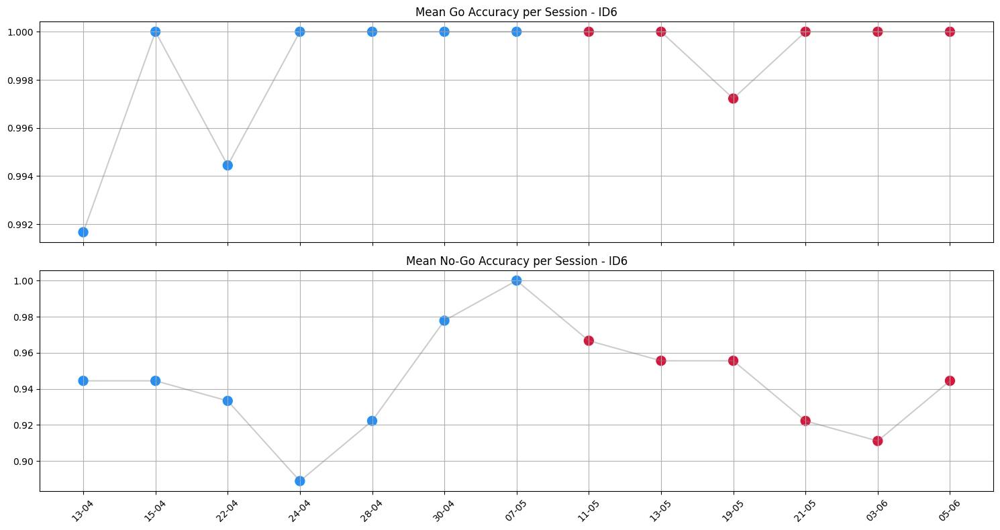

DATE: 2026-05-11 00:00:00
DATE: 2026-05-13 00:00:00
DATE: 2026-05-19 00:00:00
DATE: 2026-05-21 00:00:00
DATE: 2026-06-03 00:00:00
DATE: 2026-06-05 00:00:00


,DATE,Go_12,NoGo_12,Go_20,NoGo_20,Go_30,NoGo_30,MeanGo,MeanNoGo
0,2026-05-11,1.0,1.000000,1.0,0.972222,1.000000,0.944444,1.000000,0.972222
1,2026-05-13,1.0,0.944444,1.0,0.972222,1.000000,0.944444,1.000000,0.953704
2,2026-05-19,1.0,0.972222,1.0,0.972222,0.993056,0.916667,0.997685,0.953704
3,2026-05-21,1.0,0.916667,1.0,0.944444,1.000000,0.916667,1.000000,0.925926
4,2026-06-03,1.0,0.888889,1.0,0.888889,1.000000,0.972222,1.000000,0.916667
5,2026-06-05,1.0,1.000000,1.0,0.916667,1.000000,0.944444,1.000000,0.953704


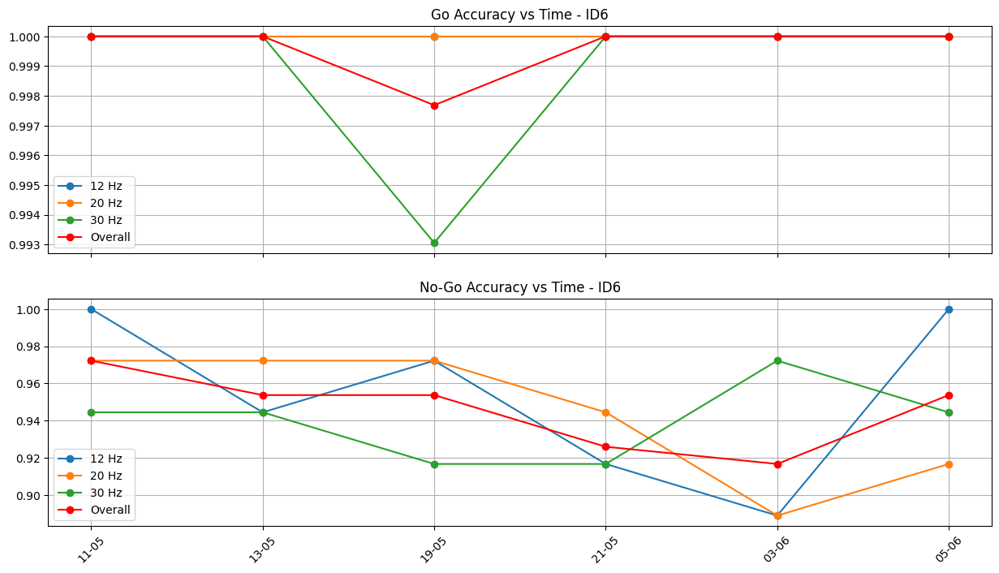

t=2.851115
t=0.337126
t=2.478293


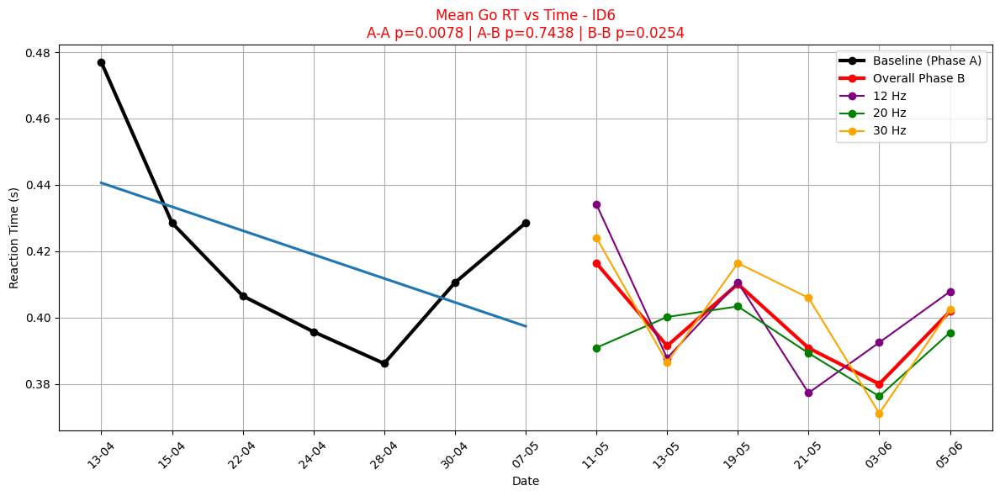

t=3.261528
t=0.855492
t=2.568310


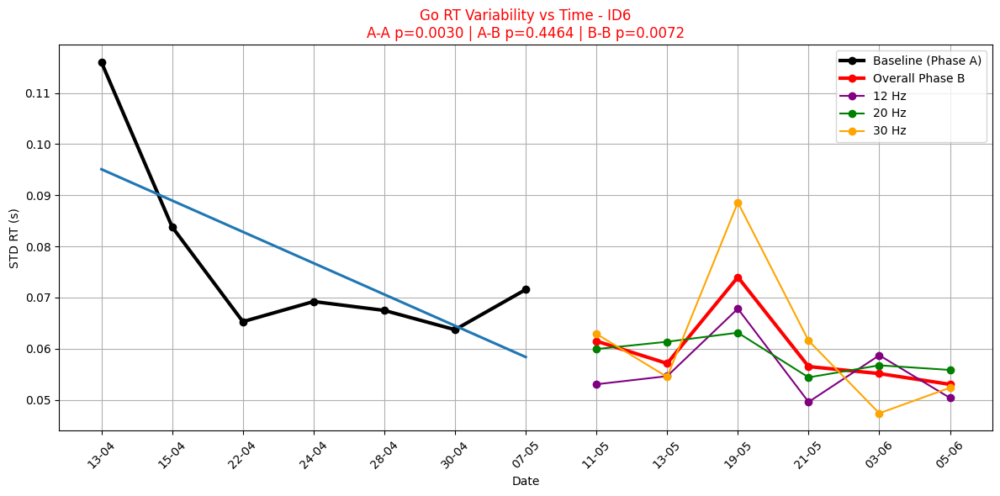

t=-1.584385
t=0.475980
t=1.666028


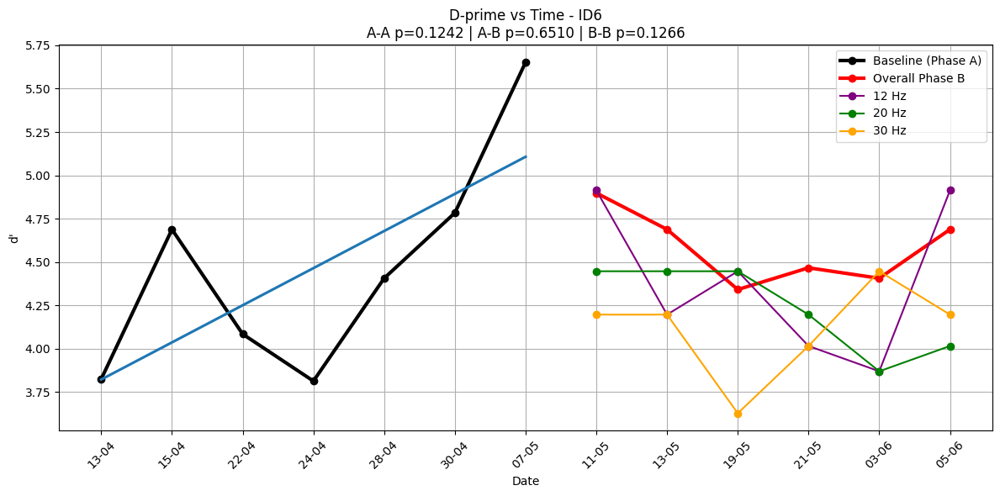

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime_All,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-13,A,4/6,NaN,NaN,NaN,3.823919,0.991667,0.944444,0.113584
1,2026-04-15,A,4/6,NaN,NaN,NaN,4.687670,1.000000,0.944444,0.078872
2,2026-04-22,A,4/6,NaN,NaN,NaN,4.083545,0.994444,0.933333,0.065829
3,2026-04-24,A,4/6,NaN,NaN,NaN,3.812459,1.000000,0.888889,0.065400
4,2026-04-28,A,4/6,8.0,5.0,0.0,4.405727,1.000000,0.922222,0.065504
5,2026-04-30,A,4/6,9.0,3.0,0.0,4.783220,1.000000,0.977778,0.061260
6,2026-05-07,A,4/6,8.0,4.0,0.0,5.652738,1.000000,1.000000,0.073290
7,2026-05-11,B,4/6,8.0,4.0,3.0,4.897896,1.000000,0.966667,0.057684
8,2026-05-13,B,4/6,6.0,4.0,5.0,4.687670,1.000000,0.955556,0.054238
9,2026-05-19,B,4/6,8.0,4.0,5.0,4.340688,0.997222,0.955556,0.074703


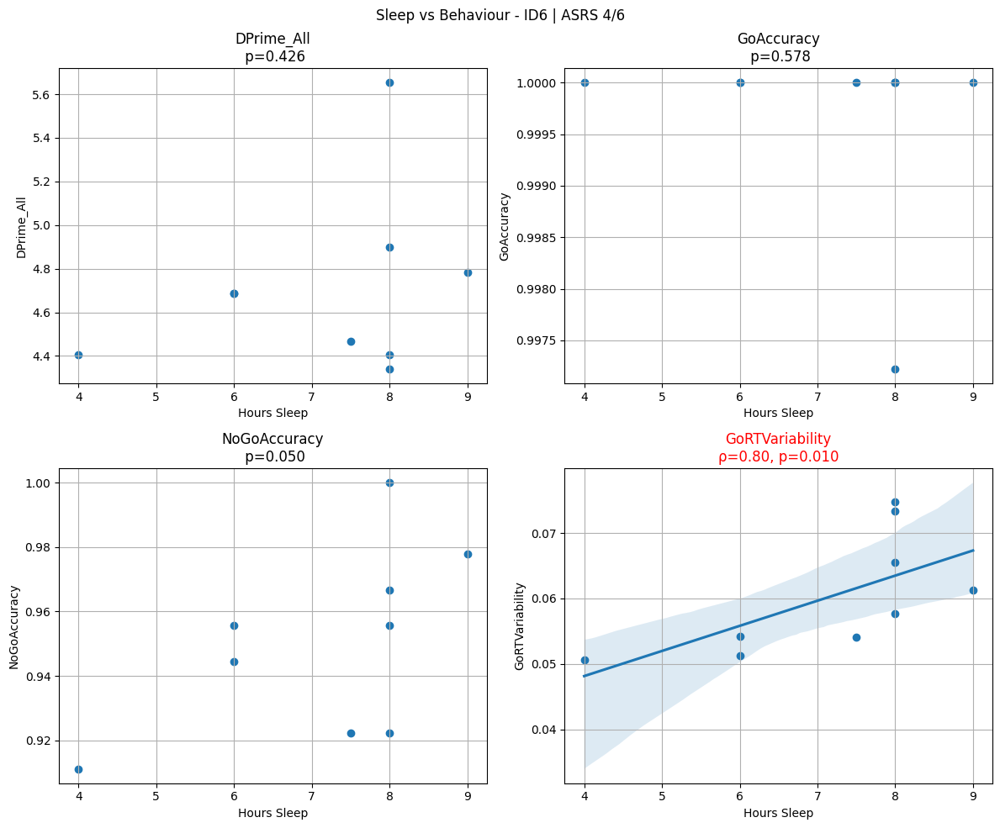

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime_All,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-13,A,4/6,NaN,NaN,NaN,3.823919,0.991667,0.944444,0.113584
1,2026-04-15,A,4/6,NaN,NaN,NaN,4.687670,1.000000,0.944444,0.078872
2,2026-04-22,A,4/6,NaN,NaN,NaN,4.083545,0.994444,0.933333,0.065829
3,2026-04-24,A,4/6,NaN,NaN,NaN,3.812459,1.000000,0.888889,0.065400
4,2026-04-28,A,4/6,8.0,5.0,0.0,4.405727,1.000000,0.922222,0.065504
5,2026-04-30,A,4/6,9.0,3.0,0.0,4.783220,1.000000,0.977778,0.061260
6,2026-05-07,A,4/6,8.0,4.0,0.0,5.652738,1.000000,1.000000,0.073290
7,2026-05-11,B,4/6,8.0,4.0,3.0,4.897896,1.000000,0.966667,0.057684
8,2026-05-13,B,4/6,6.0,4.0,5.0,4.687670,1.000000,0.955556,0.054238
9,2026-05-19,B,4/6,8.0,4.0,5.0,4.340688,0.997222,0.955556,0.074703


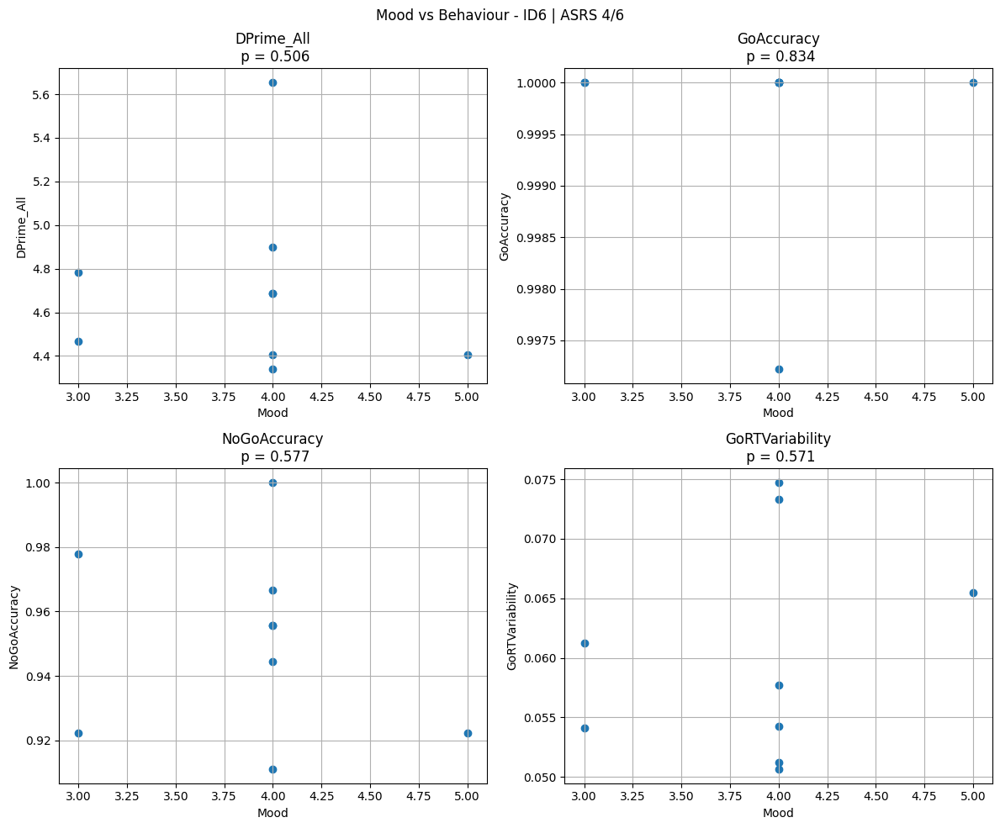

,Metric,n_A,n_B,Mean_A,Mean_B,Observed_Diff,NAP,TauU,Permutation_p
0,DPrime_All,7,6,4.464183,4.580947,0.116764,0.607143,0.214286,0.3413
1,Variability_Go,7,6,0.073759,0.057040,0.016719,0.880952,0.761905,0.0072
2,Accuracy_NoGo,7,6,0.939153,0.945988,0.006834,0.547619,0.095238,0.3830


In [1033]:
df_id6 = pipeline(6)
sced_df = sced_metrics(df_id6)
display(sced_df)

In [1034]:
def baseline_values(df_subject, metric):

    if metric == "DPrime":
        return (
            df_subject
            .loc[df_subject["PHASE"] == "A", metric]
            .dropna()
            .astype(float)
            .values
        )

    else:
        return (
            df_subject
            .loc[df_subject["PHASE"] == "A", metric]
            .apply(np.nanmean)
            .dropna()
            .values
        )

In [1035]:
def frequency_table(df_subject, id, metric_type):

    rows = []

    phase_b = df_subject[df_subject["PHASE"] == "B"]

    for _, session in phase_b.iterrows():

        if metric_type == "dprime":
            rows.append(session_frequency_dprime(session, id))

        elif metric_type == "variability":
            rows.append(session_frequency_go_variability(session, id))

        elif metric_type == "accuracy":
            rows.append(session_frequency_accuracy(session, id))

    return pd.DataFrame(rows)

In [1036]:
def phase_effect_arrays(A, B, improvement):

    nap = compute_nap(A, B, improvement)
    tau_u = compute_tau_u(A, B, improvement)

    observed_diff, p_perm = permutation_test(
        A,
        B,
        improvement
    )

    return {
        "n_A": len(A),
        "n_B": len(B),
        "Mean_A": np.mean(A),
        "Mean_B": np.mean(B),
        "Observed_Diff": observed_diff,
        "NAP": nap,
        "TauU": tau_u,
        "Permutation_p": p_perm
    }

In [1037]:
def sced_frequency_metrics(df_subject, id):

    results = []

    dprime_df = frequency_table(df_subject, id, "dprime")
    var_df = frequency_table(df_subject, id, "variability")
    acc_df = frequency_table(df_subject, id, "accuracy")

    for freq in [12, 20, 30]:

        # DPrime
        A = baseline_values(df_subject, "DPrime")
        B = dprime_df[f"DPrime_{freq}"].dropna().values

        out = phase_effect_arrays(A, B, "increase")
        out["Metric"] = "DPrime"
        out["Frequency"] = freq
        results.append(out)

        # Go RT variability
        A = baseline_values(df_subject, "Variability_Go")
        B = var_df[f"VarGoRT_{freq}"].dropna().values

        out = phase_effect_arrays(A, B, "decrease")
        out["Metric"] = "Variability_Go"
        out["Frequency"] = freq
        results.append(out)

        # NoGo accuracy
        A = baseline_values(df_subject, "Accuracy_NoGo")
        B = acc_df[f"NoGo_{freq}"].dropna().values

        out = phase_effect_arrays(A, B, "increase")
        out["Metric"] = "Accuracy_NoGo"
        out["Frequency"] = freq
        results.append(out)

    return pd.DataFrame(results)

In [592]:
freq_sced_id6 = sced_frequency_metrics(df_id6, 6)
display(freq_sced_id6)

DATE: 2026-05-11 00:00:00
freqs: [12, 30, 30, 12, 20, 20]
len(freqs): 6
acc_go: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
len(acc_go): 6
acc_nogo: [1.0, 0.9444444444444444, 0.9444444444444444, 1.0, 0.9444444444444444, 1.0]
len(acc_nogo): 6
DATE: 2026-05-13 00:00:00
freqs: [30, 12, 20, 30, 12, 20]
len(freqs): 6
acc_go: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
len(acc_go): 6
acc_nogo: [0.9444444444444444, 1.0, 0.9444444444444444, 0.9444444444444444, 0.8888888888888888, 1.0]
len(acc_nogo): 6
DATE: 2026-05-19 00:00:00
freqs: [12, 12, 20, 30, 20, 30]
len(freqs): 6
acc_go: [1.0, 1.0, 1.0, 1.0, 1.0, 0.9861111111111112]
len(acc_go): 6
acc_nogo: [0.9444444444444444, 1.0, 1.0, 0.8888888888888888, 0.9444444444444444, 0.9444444444444444]
len(acc_nogo): 6
DATE: 2026-05-21 00:00:00
freqs: [20, 20, 30, 30, 12, 12]
len(freqs): 6
acc_go: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
len(acc_go): 6
acc_nogo: [0.9444444444444444, 0.9444444444444444, 0.8888888888888888, 0.9444444444444444, 0.9444444444444444, 0.8888888888888888]
len(acc_nog

,n_A,n_B,Mean_A,Mean_B,Observed_Diff,NAP,TauU,Permutation_p,Metric,Frequency
0,7,6,4.464183,4.391925,-0.072258,0.547619,0.095238,0.5753,DPrime,12
1,7,6,0.073759,0.055677,0.018082,0.904762,0.809524,0.0032,Variability_Go,12
2,7,6,0.939153,0.953704,0.014550,0.583333,0.166667,0.2886,Accuracy_NoGo,12
3,7,6,4.464183,4.236365,-0.227818,0.452381,-0.095238,0.7553,DPrime,20
4,7,6,0.073759,0.058550,0.015209,0.976190,0.952381,0.0010,Variability_Go,20
5,7,6,0.939153,0.944444,0.005291,0.559524,0.119048,0.4120,Accuracy_NoGo,20
6,7,6,4.464183,4.112578,-0.351605,0.357143,-0.285714,0.8736,DPrime,30
7,7,6,0.073759,0.061197,0.012562,0.809524,0.619048,0.0992,Variability_Go,30
8,7,6,0.939153,0.939815,0.000661,0.428571,-0.142857,0.5141,Accuracy_NoGo,30


,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,307.702727,Go,NaN,NaN,Incorrect,True,False,13
1,1,1,308.725952,Go,NaN,NaN,Incorrect,True,False,13
2,1,2,309.742476,Go,space,0.100228,Correct,False,False,13
3,1,3,310.759344,Go,space,0.250153,Correct,False,False,13
4,1,4,311.775935,Go,space,0.351323,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,964.211661,Go,space,0.650081,Correct,False,False,13
536,6,536,965.228292,Go,space,0.816748,Correct,False,False,13
537,6,537,966.245081,Go,space,0.899840,Correct,False,False,13
538,6,538,967.261509,Go,space,0.754133,Correct,False,False,13


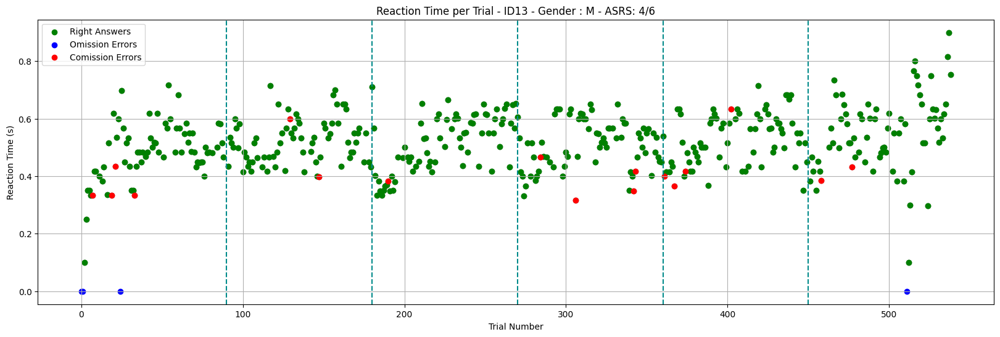

t=-3.632247


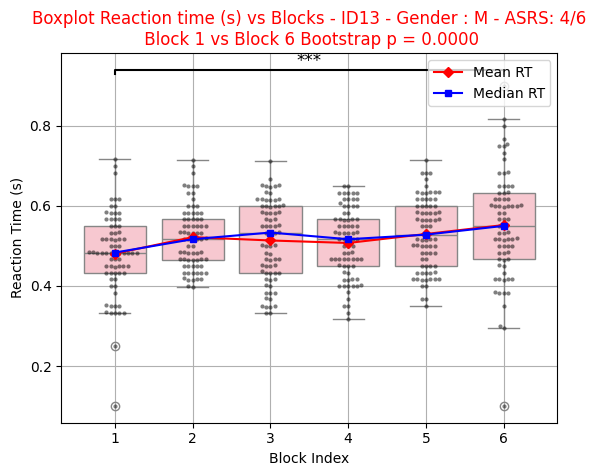

[{'Block': 'Block 1',
  'Accuracy Go': 0.9583333333333334,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.8888888888888888}]

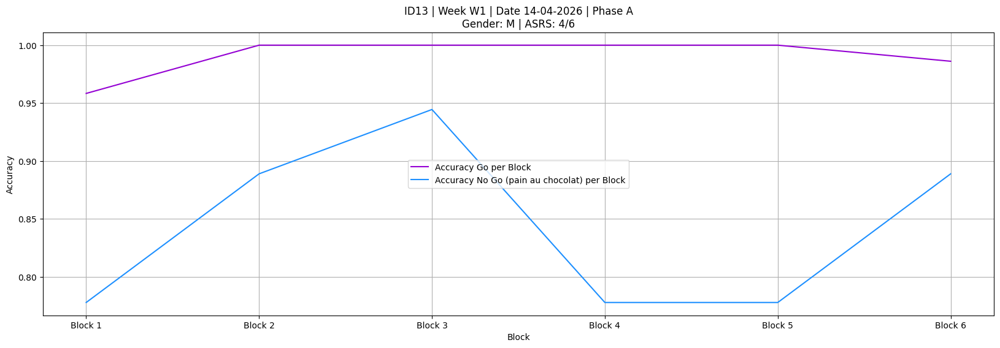

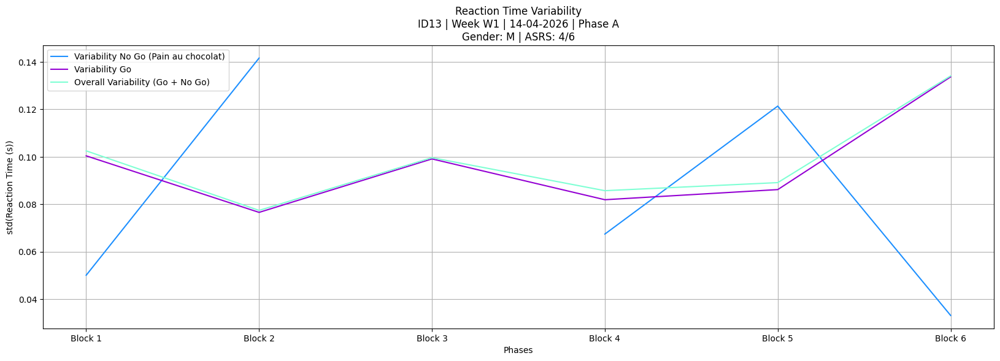

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,254.417249,Go,NaN,NaN,Incorrect,True,False,13
1,1,1,255.453634,Go,space,0.533526,Correct,False,False,13
2,1,2,256.470198,Go,space,0.550052,Correct,False,False,13
3,1,3,257.486868,Go,space,0.483295,Correct,False,False,13
4,1,4,258.503374,Go,space,0.516910,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,910.930133,Go,space,0.416658,Correct,False,False,13
536,6,536,911.946786,Go,space,0.383262,Correct,False,False,13
537,6,537,912.963637,Go,space,0.416976,Correct,False,False,13
538,6,538,913.979885,No_Go,NaN,NaN,Correct,False,False,13


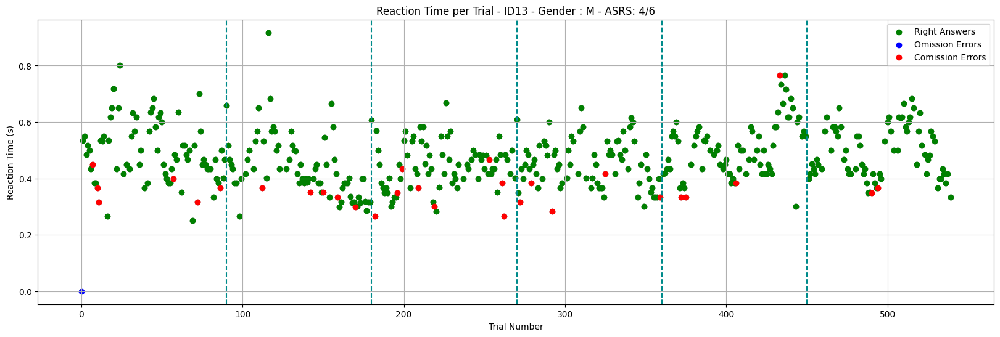

t=-0.163506


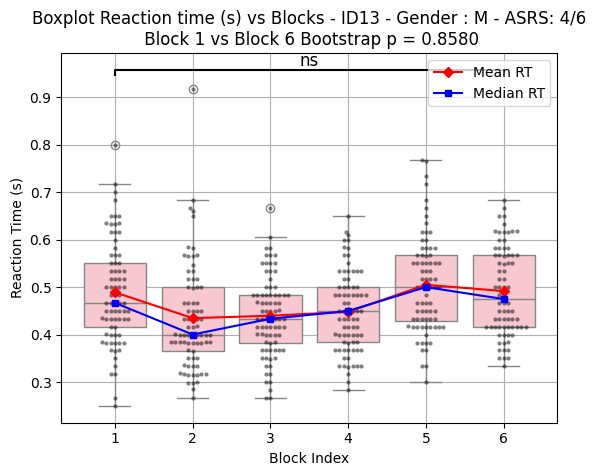

[{'Block': 'Block 1',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

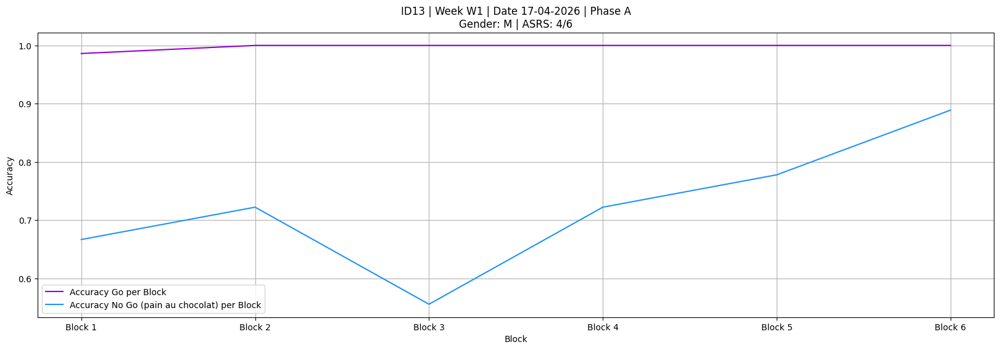

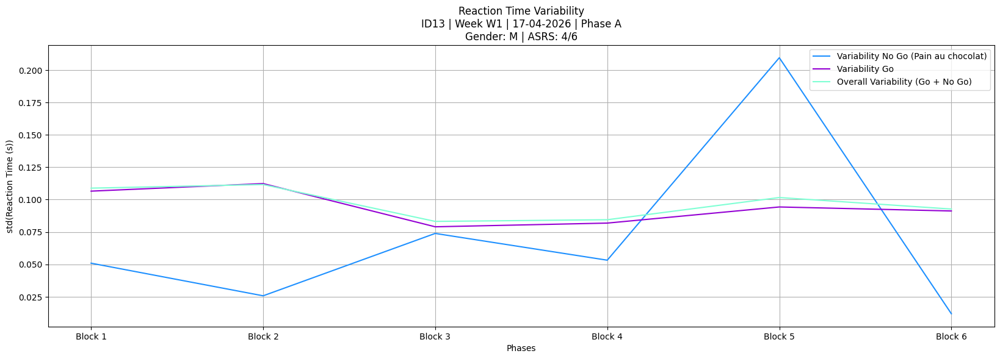

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,195.993095,No_Go,NaN,NaN,Correct,False,False,13
1,1,1,197.014404,Go,space,0.416713,Correct,False,False,13
2,1,2,198.030976,Go,space,0.449846,Correct,False,False,13
3,1,3,199.047598,No_Go,space,0.466688,Incorrect,False,True,13
4,1,4,200.064223,Go,NaN,NaN,Incorrect,True,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,844.642940,Go,space,0.550042,Correct,False,False,13
536,6,536,845.659539,No_Go,NaN,NaN,Correct,False,False,13
537,6,537,846.676208,Go,space,0.516845,Correct,False,False,13
538,6,538,847.692785,Go,space,0.450027,Correct,False,False,13


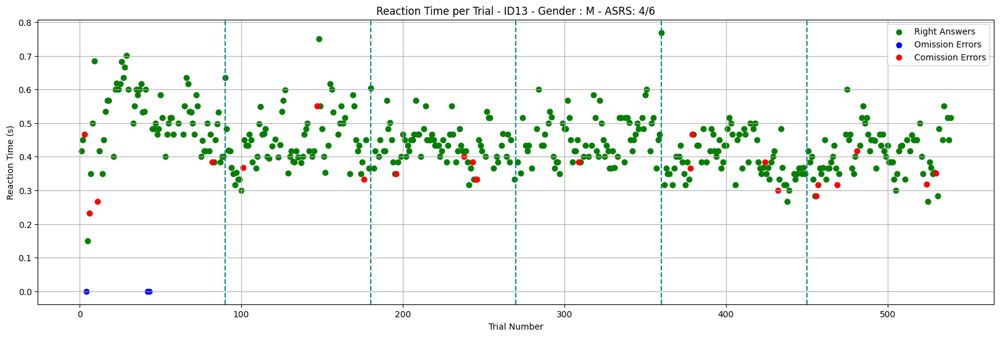

t=6.393135


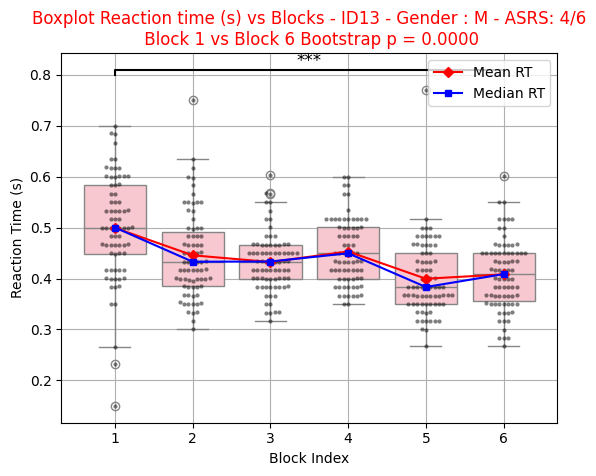

[{'Block': 'Block 1',
  'Accuracy Go': 0.9583333333333334,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666}]

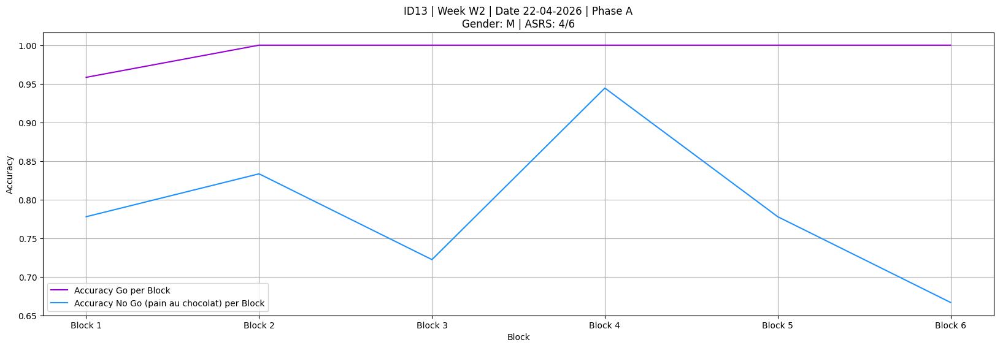

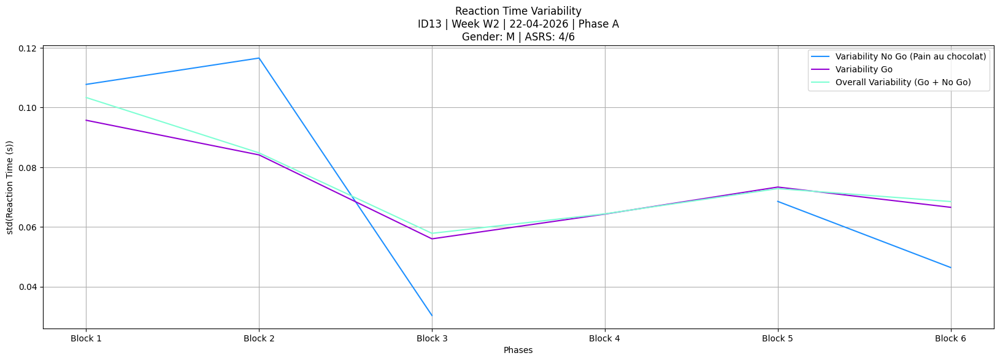

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,396.786888,Go,space,0.714279,Correct,False,False,13
1,1,1,397.767878,Go,space,0.516608,Correct,False,False,13
2,1,2,398.751329,Go,space,0.383421,Correct,False,False,13
3,1,3,399.734464,Go,space,0.283128,Correct,False,False,13
4,1,4,400.717747,Go,space,0.283352,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1045.230830,No_Go,NaN,NaN,Correct,False,False,13
536,6,536,1046.214034,Go,space,0.450153,Correct,False,False,13
537,6,537,1047.197609,Go,space,0.483292,Correct,False,False,13
538,6,538,1048.181961,No_Go,space,0.399570,Incorrect,False,True,13


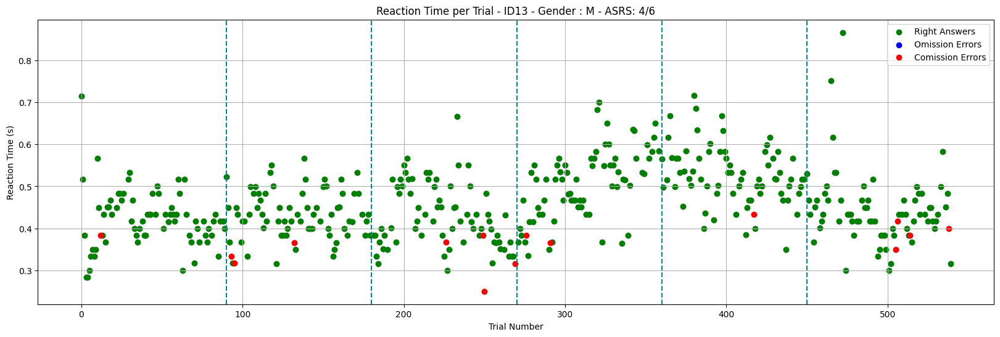

t=-1.568212


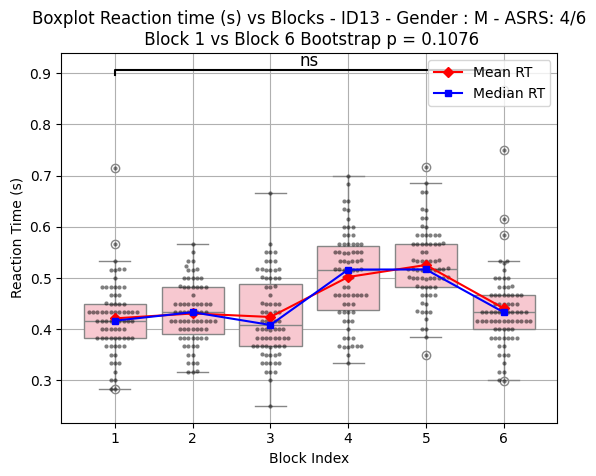

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778}]

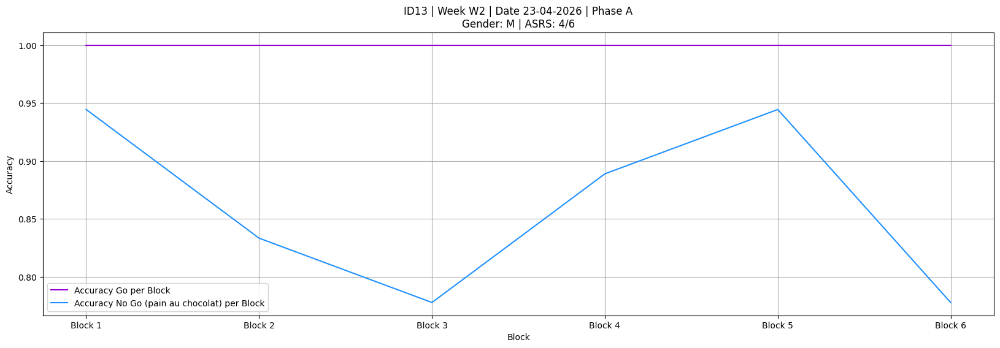

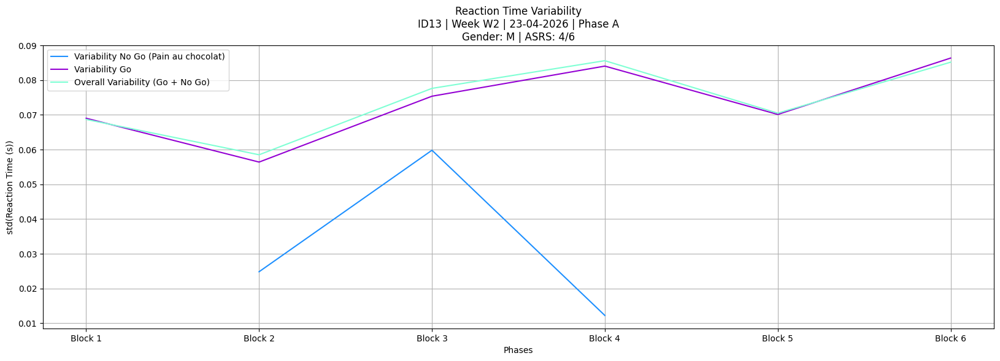

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,36.019336,Go,space,0.664332,Correct,False,False,13
1,1,1,37.033744,Go,space,0.582903,Correct,False,False,13
2,1,2,38.049084,No_Go,space,0.502490,Incorrect,False,True,13
3,1,3,39.067528,Go,space,0.282668,Correct,False,False,13
4,1,4,40.083491,Go,space,0.416060,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,687.949204,Go,space,0.432756,Correct,False,False,13
536,6,536,688.964724,Go,space,0.466311,Correct,False,False,13
537,6,537,689.980536,Go,space,0.466234,Correct,False,False,13
538,6,538,690.996257,Go,space,0.499609,Correct,False,False,13


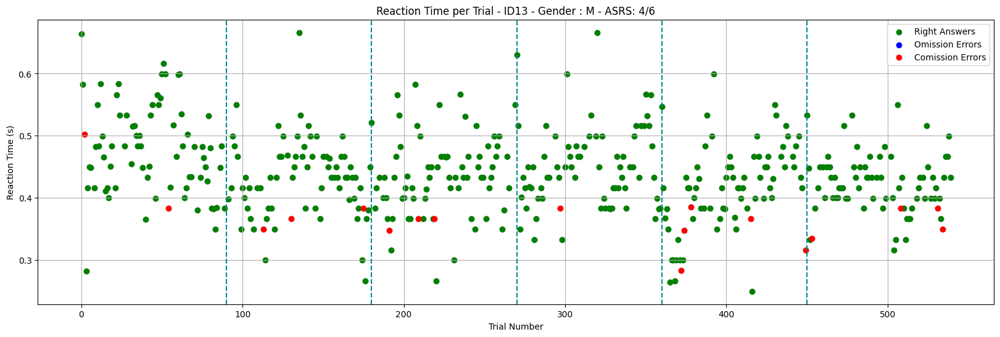

t=5.541547


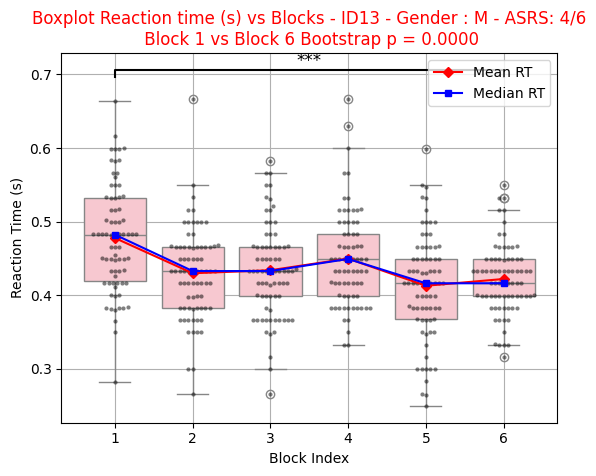

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778}]

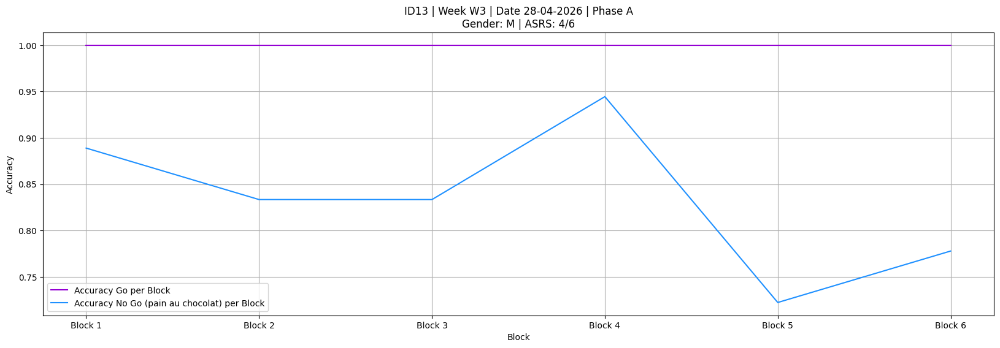

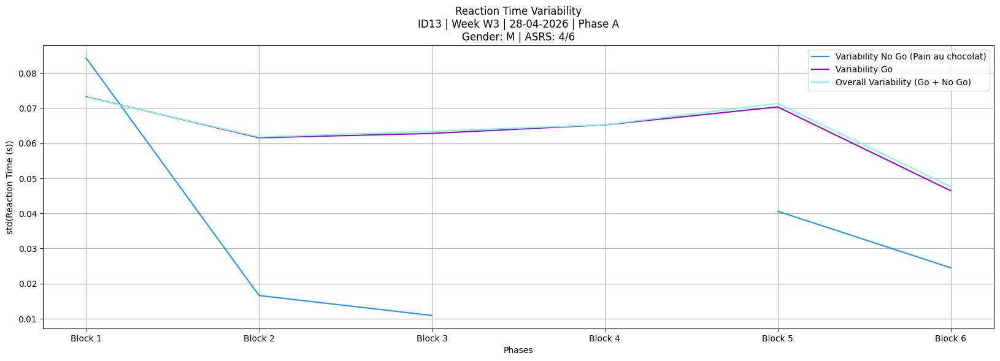

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,108.024495,No_Go,NaN,NaN,Correct,False,False,13
1,1,1,109.046005,Go,space,0.616006,Correct,False,False,13
2,1,2,110.061511,No_Go,NaN,NaN,Correct,False,False,13
3,1,3,111.078726,Go,space,0.449487,Correct,False,False,13
4,1,4,112.094509,Go,space,0.549514,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,772.655806,Go,space,0.399593,Correct,False,False,13
536,6,536,773.671499,No_Go,space,0.649402,Incorrect,False,True,13
537,6,537,774.687056,Go,space,0.466279,Correct,False,False,13
538,6,538,775.702761,No_Go,NaN,NaN,Correct,False,False,13


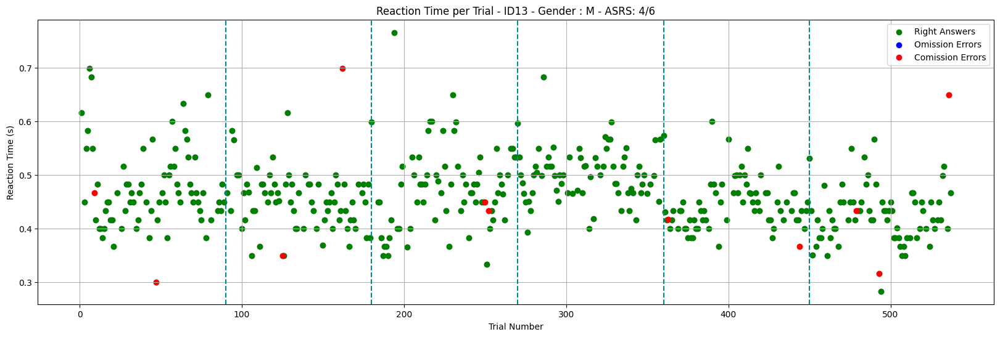

t=4.375492


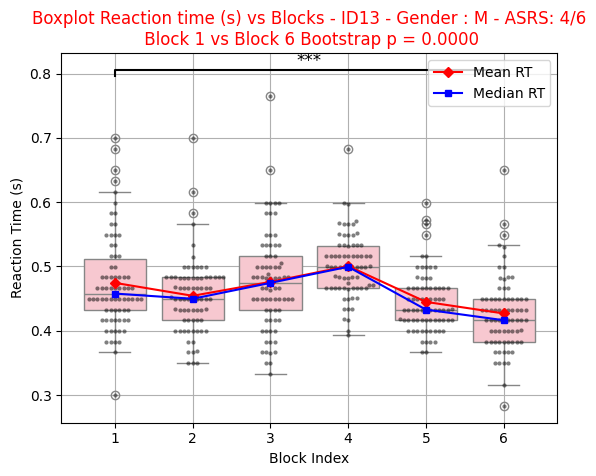

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334}]

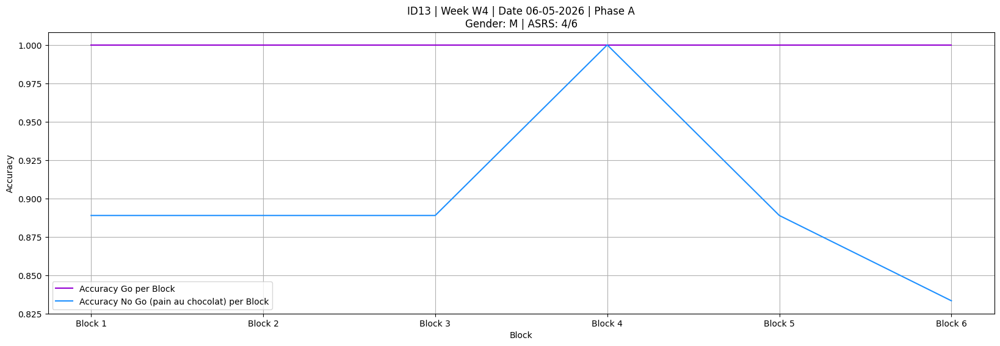

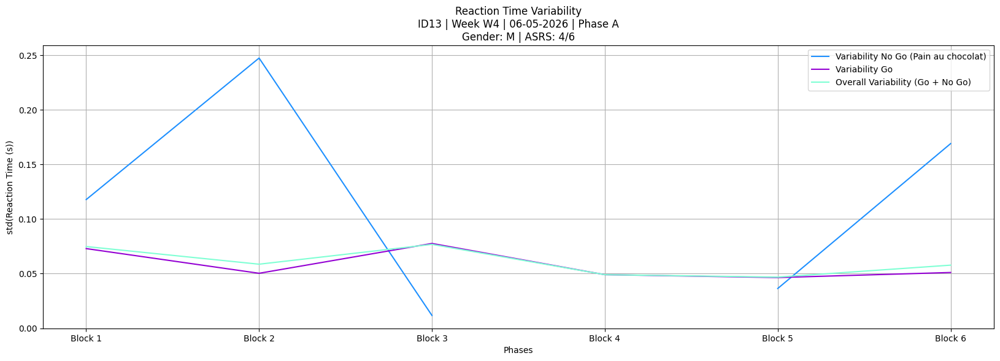

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,367.735862,Go,space,0.629869,Correct,False,False,13
1,1,1,368.782278,Go,space,0.533610,Correct,False,False,13
2,1,2,369.799214,Go,space,0.485642,Correct,False,False,13
3,1,3,370.815642,Go,space,0.466590,Correct,False,False,13
4,1,4,371.832373,Go,space,0.435887,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1049.820790,Go,space,0.548327,Correct,False,False,13
536,6,536,1050.836336,No_Go,NaN,NaN,Correct,False,False,13
537,6,537,1051.853884,Go,space,0.415601,Correct,False,False,13
538,6,538,1052.869376,No_Go,NaN,NaN,Correct,False,False,13


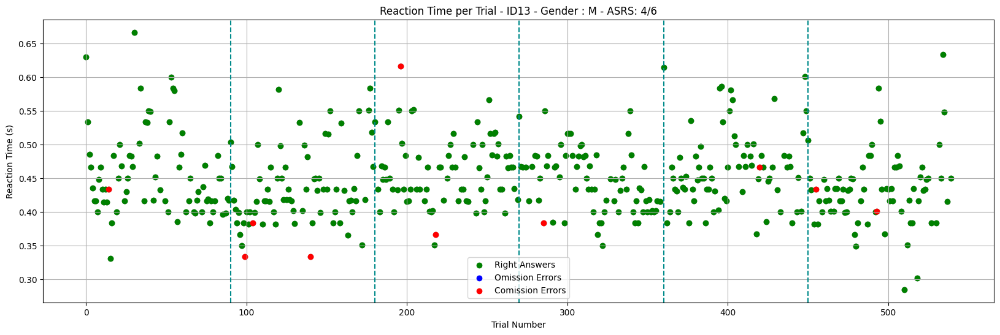

t=2.677005


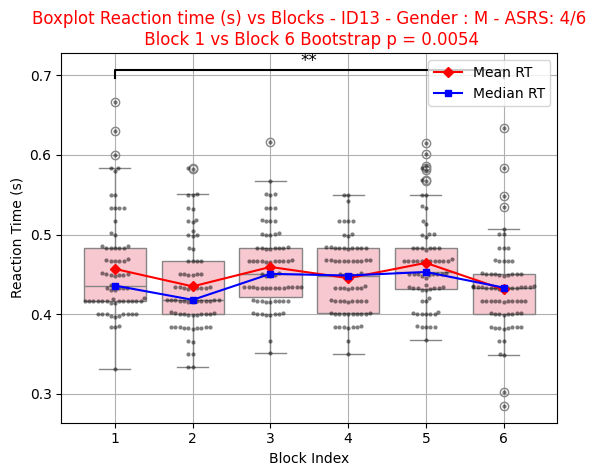

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

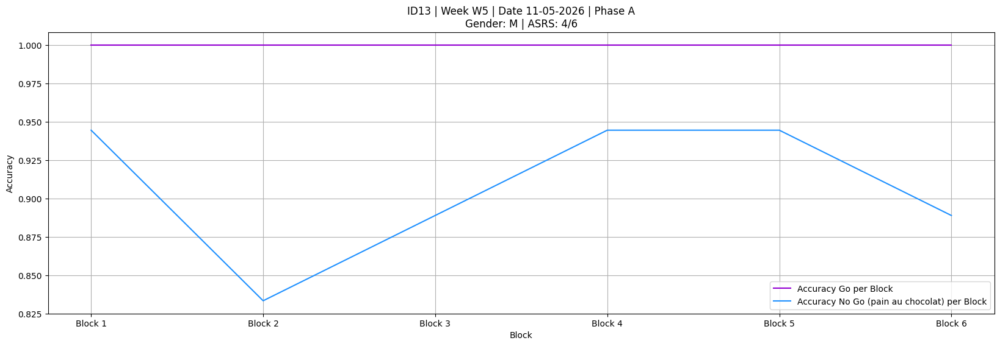

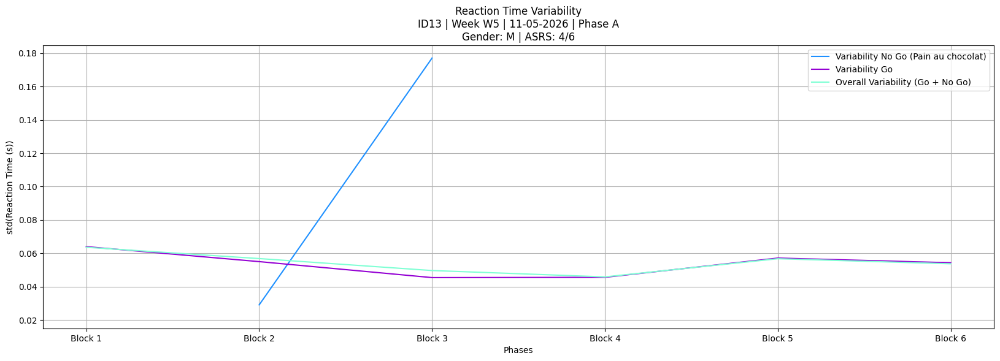

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,185.396242,Go,space,0.490821,Correct,False,False,13
1,1,1,186.453519,Go,space,0.550233,Correct,False,False,13
2,1,2,187.470308,Go,space,0.483350,Correct,False,False,13
3,1,3,188.487051,Go,space,0.450038,Correct,False,False,13
4,1,4,189.503633,Go,space,0.433392,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,835.323670,Go,space,0.366734,Correct,False,False,13
536,6,536,836.340239,Go,space,0.400037,Correct,False,False,13
537,6,537,837.356766,No_Go,NaN,NaN,Correct,False,False,13
538,6,538,838.373438,Go,space,0.383507,Correct,False,False,13


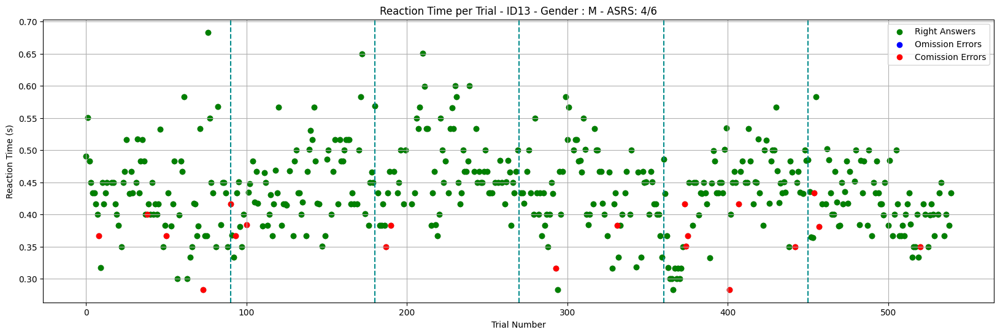

t=1.352907


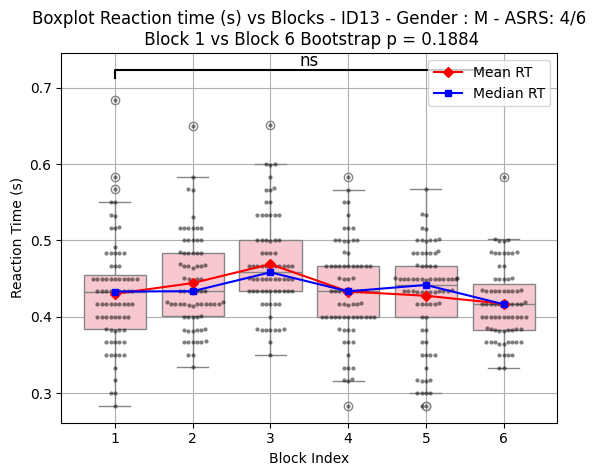

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334}]

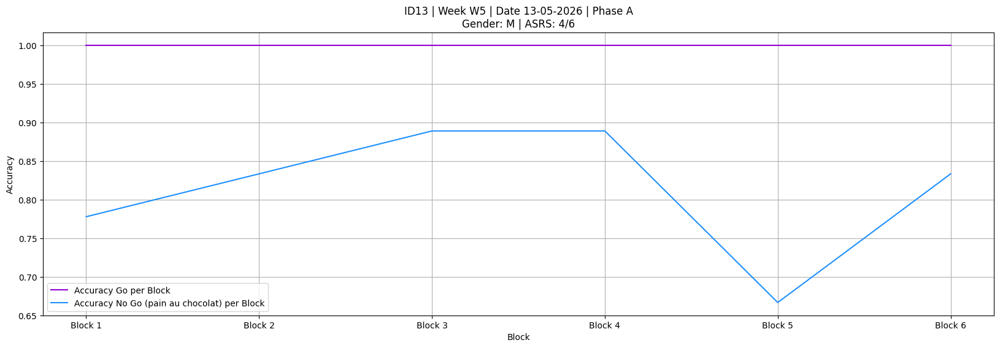

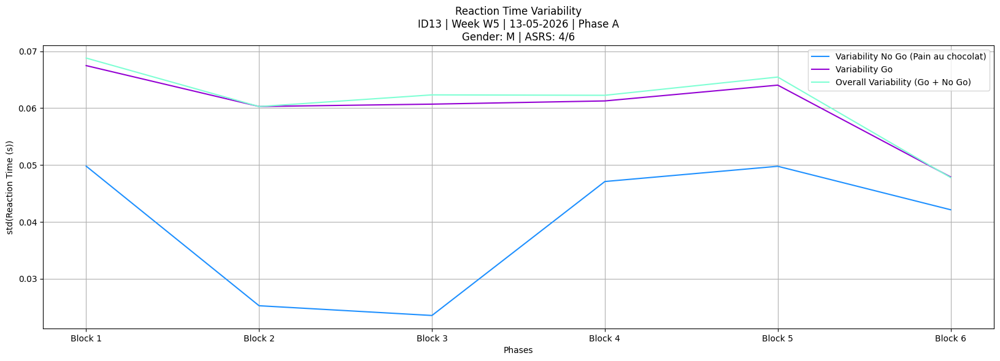

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,197.498686,Go,space,0.641366,Correct,False,False,13
1,1,1,198.523321,Go,space,0.516760,Correct,False,False,13
2,1,2,199.539936,No_Go,NaN,NaN,Correct,False,False,13
3,1,3,200.556717,Go,space,0.416646,Correct,False,False,13
4,1,4,201.573261,No_Go,NaN,NaN,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,850.468897,No_Go,NaN,NaN,Correct,False,False,13
536,6,536,851.481665,Go,space,0.406660,Correct,False,False,13
537,6,537,852.504913,Go,space,0.455141,Correct,False,False,13
538,6,538,853.515106,Go,space,0.489737,Correct,False,False,13


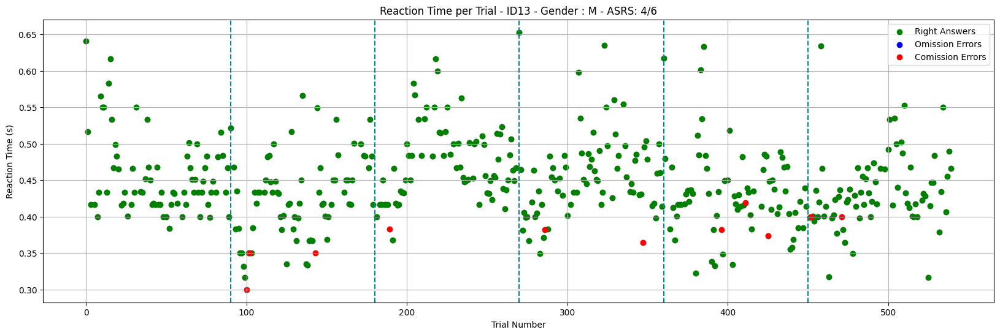

t=2.534956


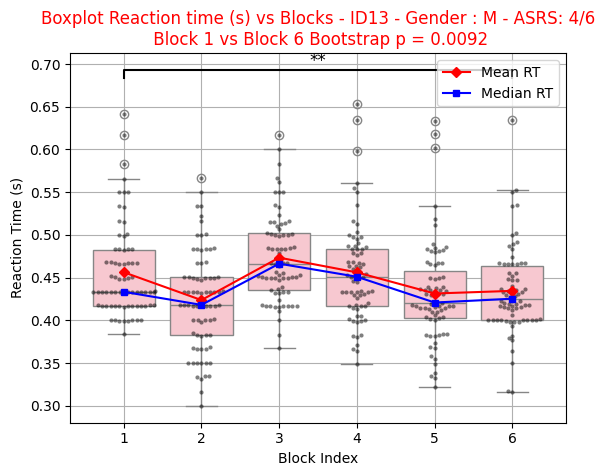

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

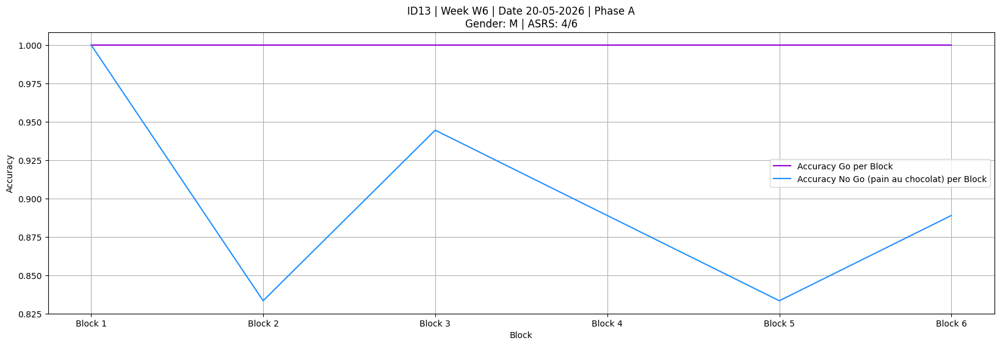

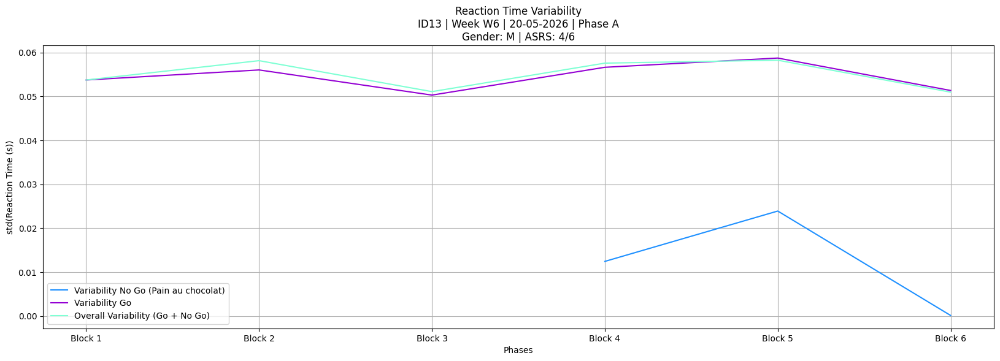

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,335.411978,Go,space,0.577119,Correct,False,False,13
1,1,1,336.455955,Go,space,0.482968,Correct,False,False,13
2,1,2,337.472467,Go,space,0.466658,Correct,False,False,13
3,1,3,338.489347,No_Go,space,0.416636,Incorrect,False,True,13
4,1,4,339.505877,No_Go,NaN,NaN,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,989.396372,Go,space,0.433311,Correct,False,False,13
536,6,536,990.412927,Go,space,0.450132,Correct,False,False,13
537,6,537,991.429425,No_Go,NaN,NaN,Correct,False,False,13
538,6,538,992.448336,Go,space,0.448005,Correct,False,False,13


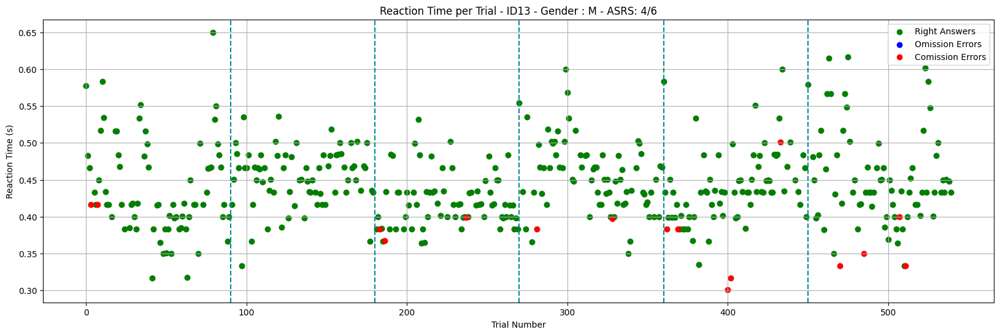

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=-1.081791


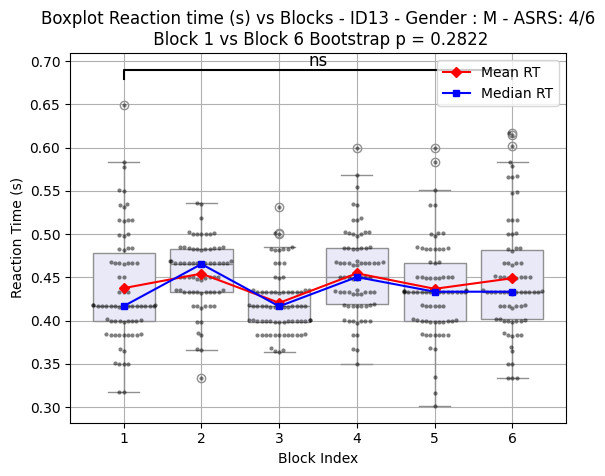

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778}]

SESSION DATE: 2026-05-22 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
9,2026-05-22,B,"20,12,12,20,30,30"


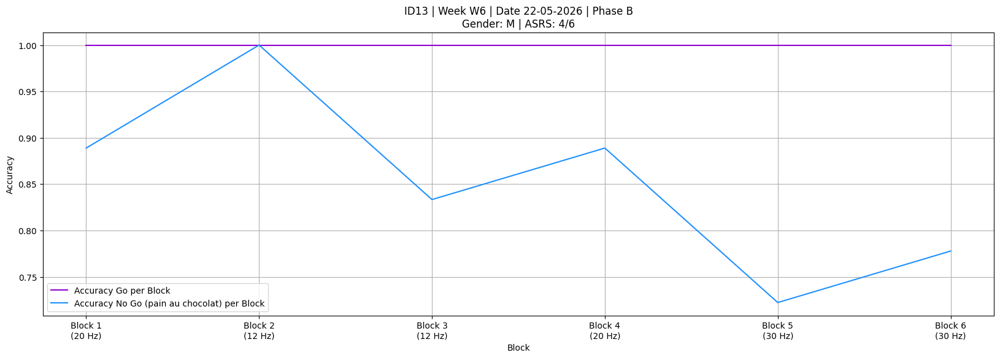

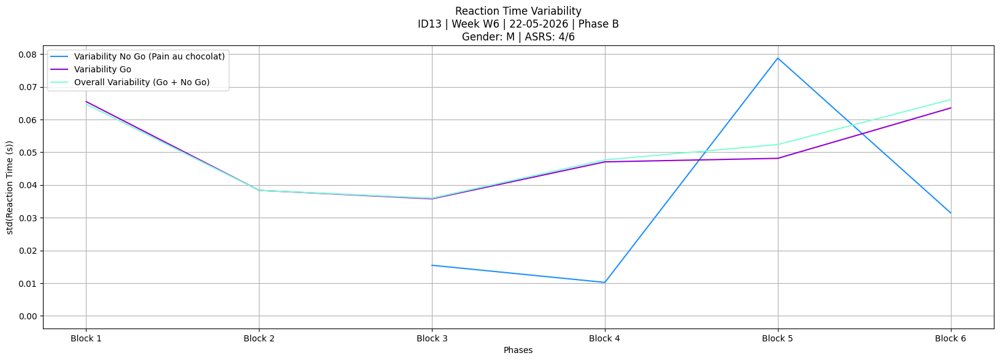

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,367.226742,Go,space,0.681528,Correct,False,False,13
1,1,1,368.257986,Go,space,0.483060,Correct,False,False,13
2,1,2,369.275622,Go,space,0.415560,Correct,False,False,13
3,1,3,370.291190,Go,space,0.399937,Correct,False,False,13
4,1,4,371.309119,Go,space,0.415269,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1019.829483,Go,space,0.516617,Correct,False,False,13
536,6,536,1020.845875,Go,space,0.466837,Correct,False,False,13
537,6,537,1021.862667,No_Go,NaN,NaN,Correct,False,False,13
538,6,538,1022.879559,Go,space,0.499889,Correct,False,False,13


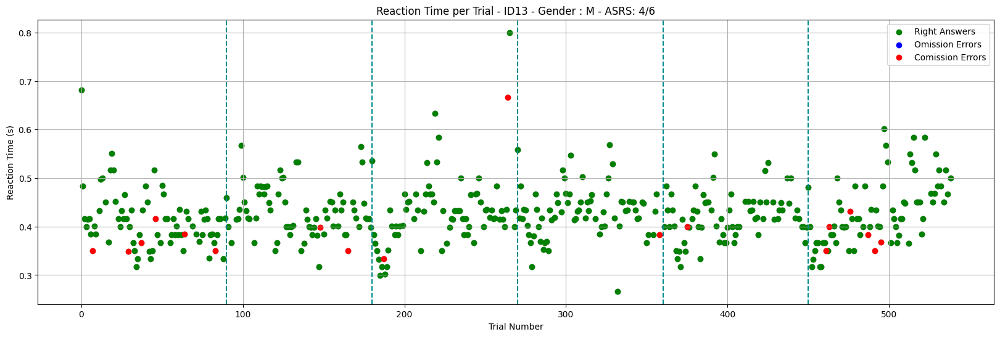

t=-1.707976


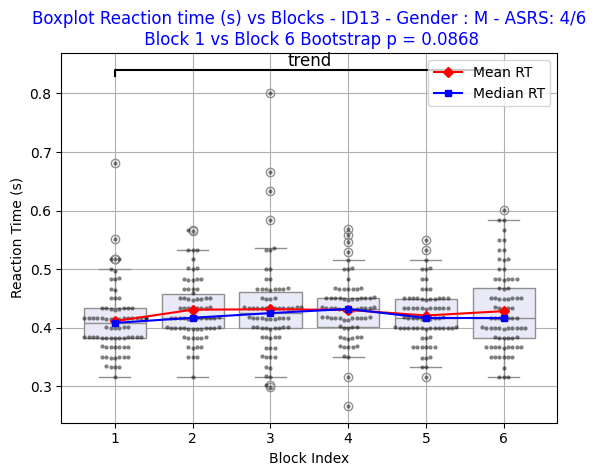

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666}]

SESSION DATE: 2026-05-29 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
10,2026-05-29,B,"20,12,20,30,12,30"


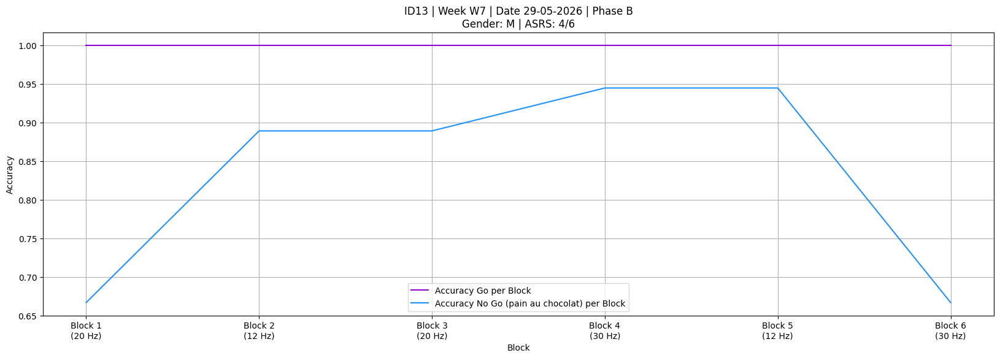

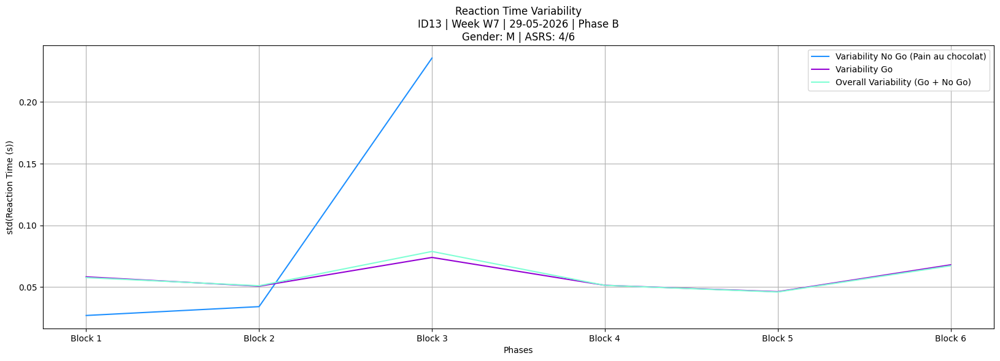

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,355.269825,Go,space,0.621713,Correct,False,False,13
1,1,1,356.324957,Go,space,0.483012,Correct,False,False,13
2,1,2,357.341588,Go,space,0.449912,Correct,False,False,13
3,1,3,358.358223,Go,space,0.466734,Correct,False,False,13
4,1,4,359.375031,Go,space,0.451015,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1002.729756,Go,space,0.333295,Correct,False,False,13
536,6,536,1003.746279,No_Go,space,0.383265,Incorrect,False,True,13
537,6,537,1004.762830,No_Go,NaN,NaN,Correct,False,False,13
538,6,538,1005.779505,Go,space,0.350278,Correct,False,False,13


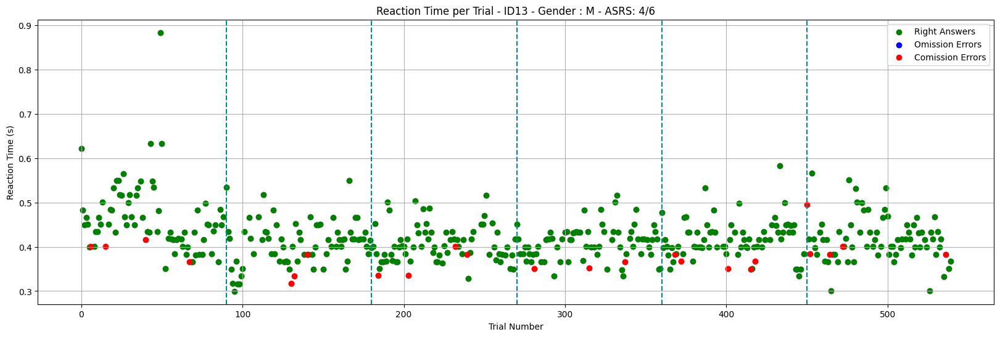

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=4.058423


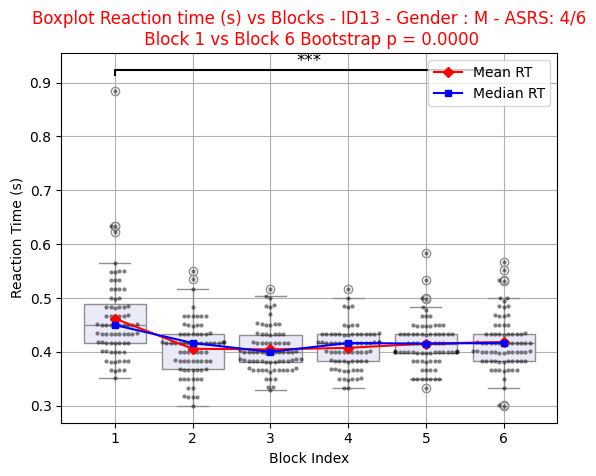

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222}]

SESSION DATE: 2026-06-02 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
11,2026-06-02,B,"20,20,12,30,12,30"


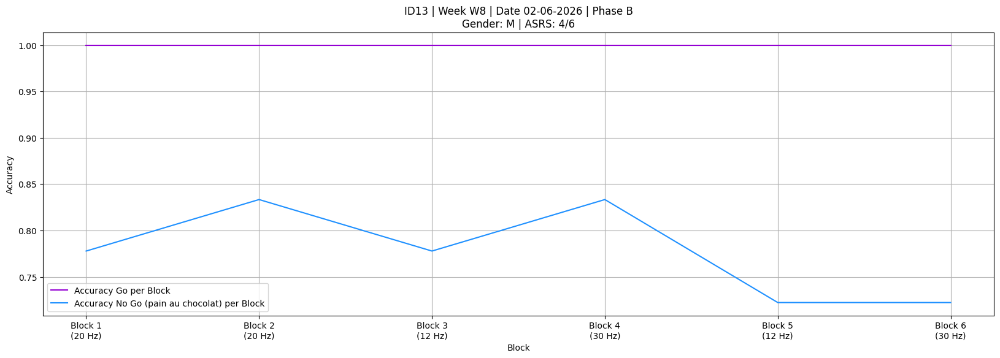

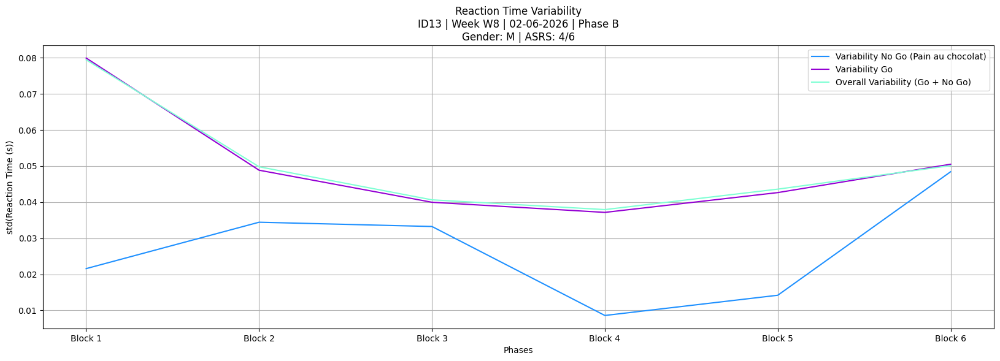

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,283.249347,Go,space,0.531572,Correct,False,False,13
1,1,1,284.263816,Go,space,0.450434,Correct,False,False,13
2,1,2,285.284625,Go,space,0.462261,Correct,False,False,13
3,1,3,286.296910,Go,space,0.516831,Correct,False,False,13
4,1,4,287.313410,Go,space,0.516810,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,952.717408,Go,space,0.400031,Correct,False,False,13
536,6,536,953.734105,Go,space,0.466556,Correct,False,False,13
537,6,537,954.750689,Go,space,0.483294,Correct,False,False,13
538,6,538,955.767365,Go,space,0.416751,Correct,False,False,13


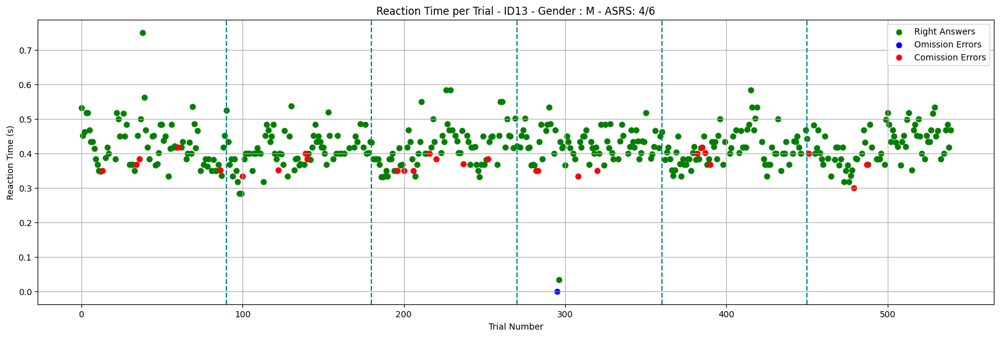

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=0.372044


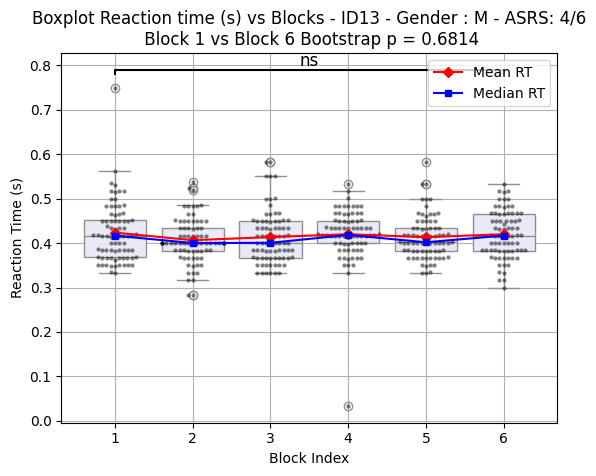

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 4',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334}]

SESSION DATE: 2026-06-04 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
12,2026-06-04,B,"30,20,30,20,12,12"


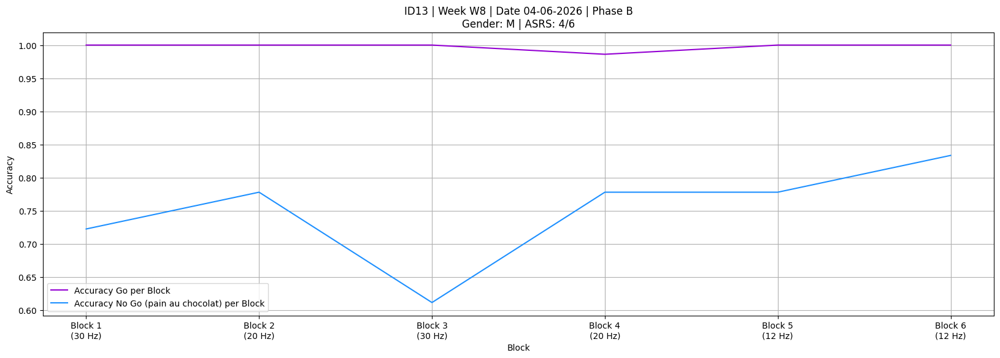

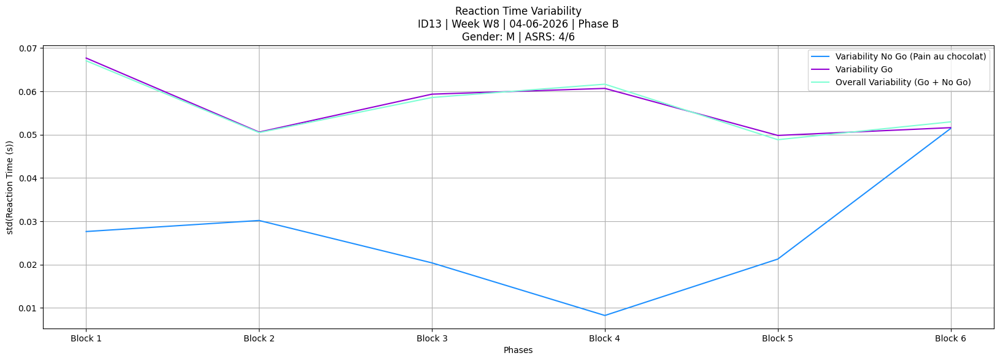

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,323.029364,Go,space,0.899720,Correct,False,False,13
1,1,1,324.045668,Go,space,0.583432,Correct,False,False,13
2,1,2,325.063065,Go,space,0.532632,Correct,False,False,13
3,1,3,326.078401,No_Go,NaN,NaN,Correct,False,False,13
4,1,4,327.095209,No_Go,space,0.416639,Incorrect,False,True,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,975.109982,Go,space,0.432625,Correct,False,False,13
536,6,536,976.125634,Go,space,0.433402,Correct,False,False,13
537,6,537,977.142993,Go,space,0.432925,Correct,False,False,13
538,6,538,978.159167,Go,space,0.433964,Correct,False,False,13


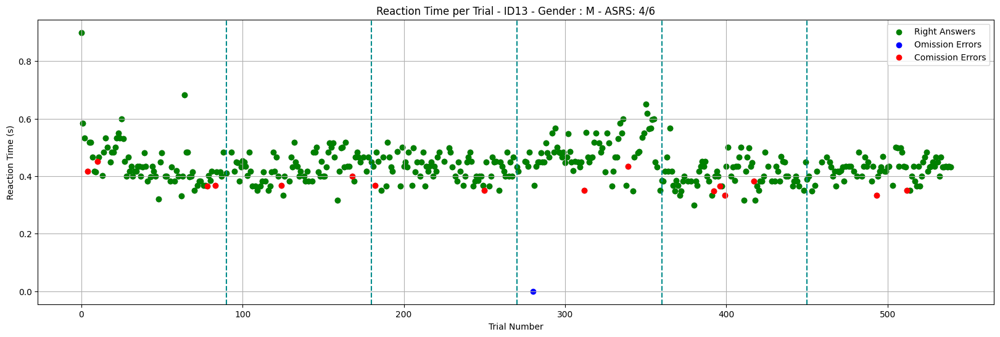

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 13.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=2.031707


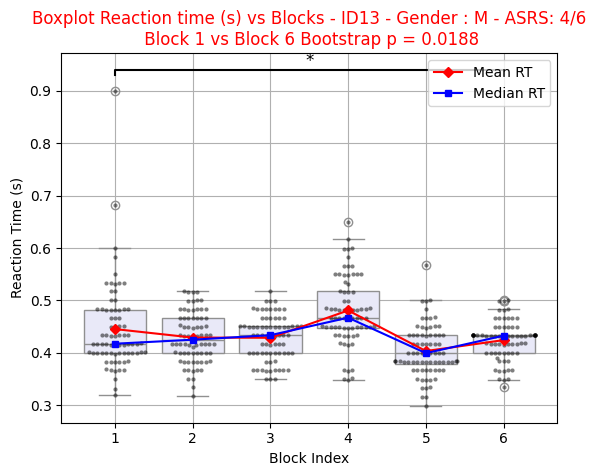

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

SESSION DATE: 2026-06-08 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
13,2026-06-08,B,"12,20,30,20,30,12"


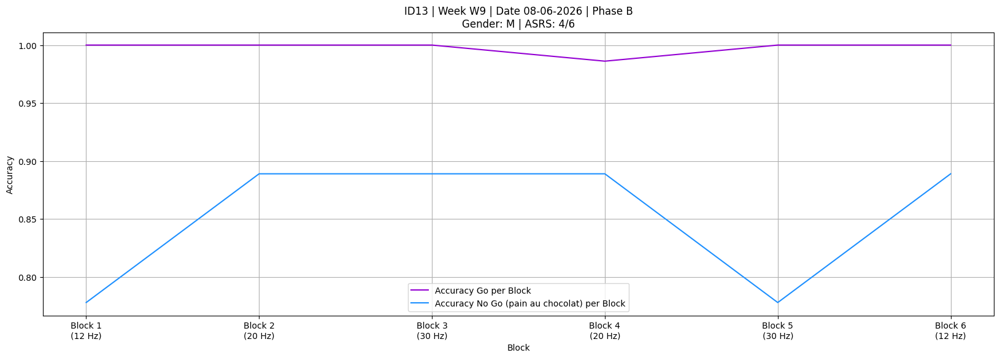

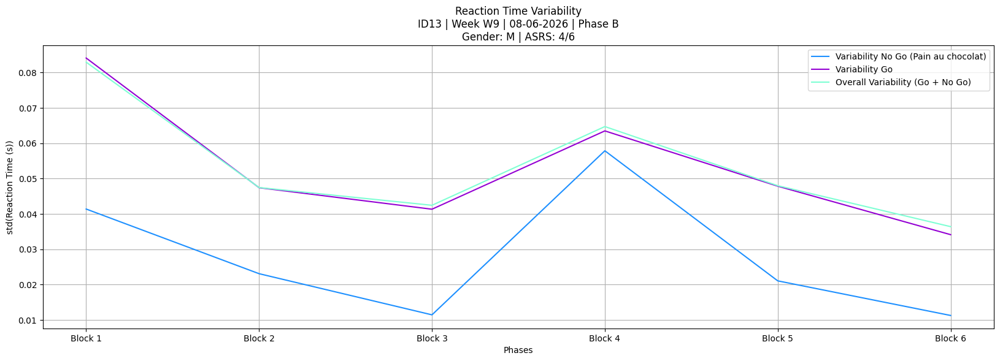

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,304.547201,No_Go,space,0.493770,Incorrect,False,True,13
1,1,1,305.556842,No_Go,NaN,NaN,Correct,False,False,13
2,1,2,306.573805,Go,space,0.533002,Correct,False,False,13
3,1,3,307.590511,Go,space,0.550593,Correct,False,False,13
4,1,4,308.607129,Go,space,0.583625,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,956.429412,No_Go,NaN,NaN,Correct,False,False,13
536,6,536,957.445993,Go,space,0.400092,Correct,False,False,13
537,6,537,958.462720,Go,space,0.383599,Correct,False,False,13
538,6,538,959.480085,Go,space,0.416209,Correct,False,False,13


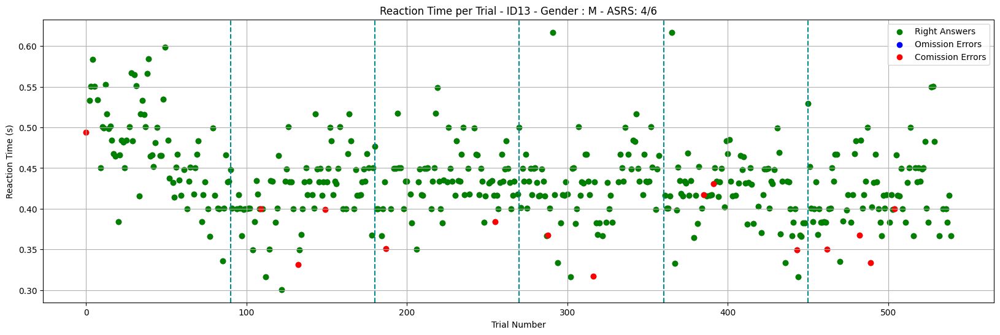

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=6.382071


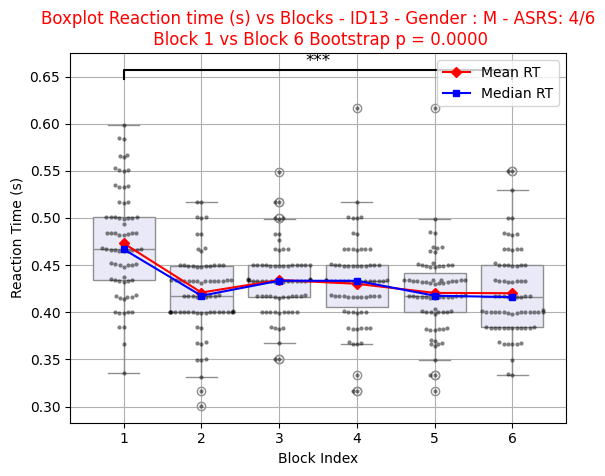

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778}]

SESSION DATE: 2026-06-10 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
14,2026-06-10,B,"30,30,12,20,20,12"


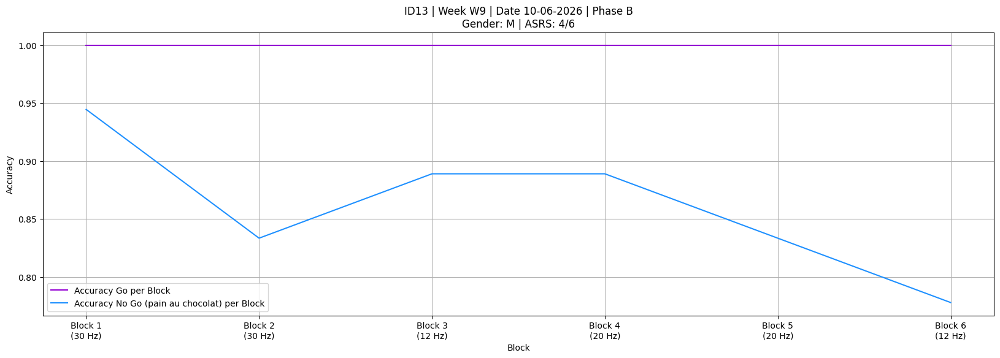

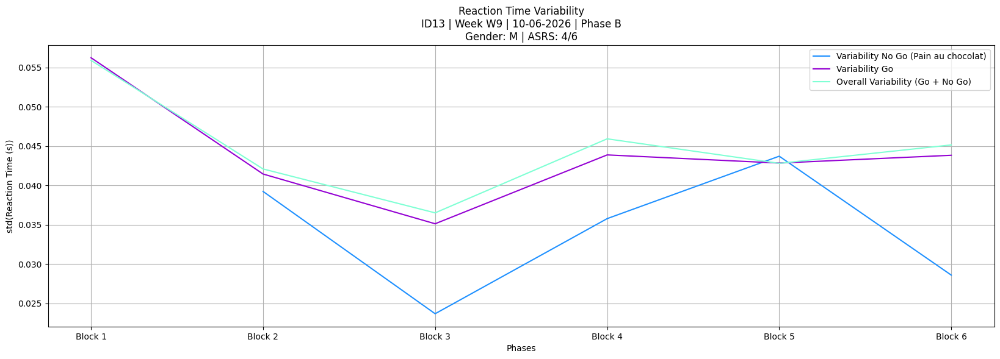

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,424.578136,Go,space,0.530221,Correct,False,False,13
1,1,1,425.591992,Go,space,0.499297,Correct,False,False,13
2,1,2,426.608136,No_Go,NaN,NaN,Correct,False,False,13
3,1,3,427.625287,Go,space,0.433749,Correct,False,False,13
4,1,4,428.641484,Go,space,0.450301,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1085.974262,Go,space,0.349953,Correct,False,False,13
536,6,536,1086.990824,Go,space,0.383206,Correct,False,False,13
537,6,537,1088.007494,Go,space,0.383397,Correct,False,False,13
538,6,538,1089.024024,Go,space,0.400178,Correct,False,False,13


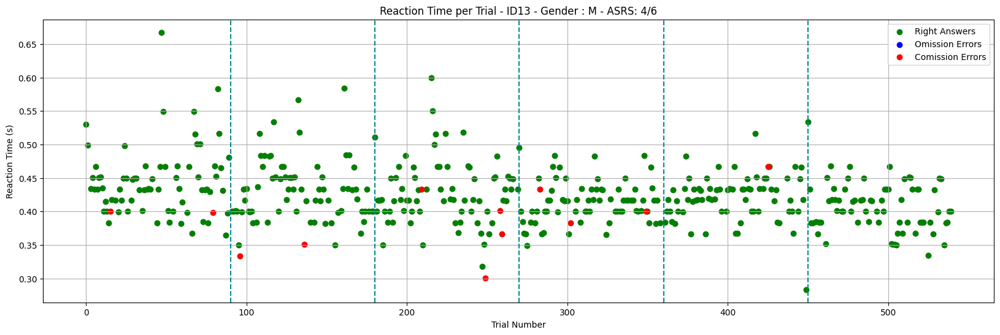

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=5.091161


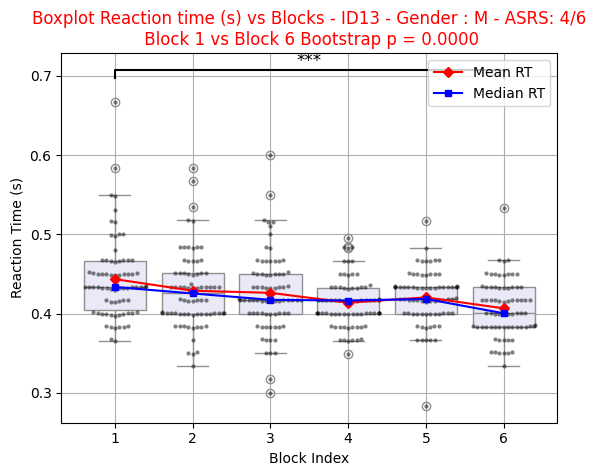

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

SESSION DATE: 2026-06-12 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
15,2026-06-12,B,"12,30,12,30,20,20"


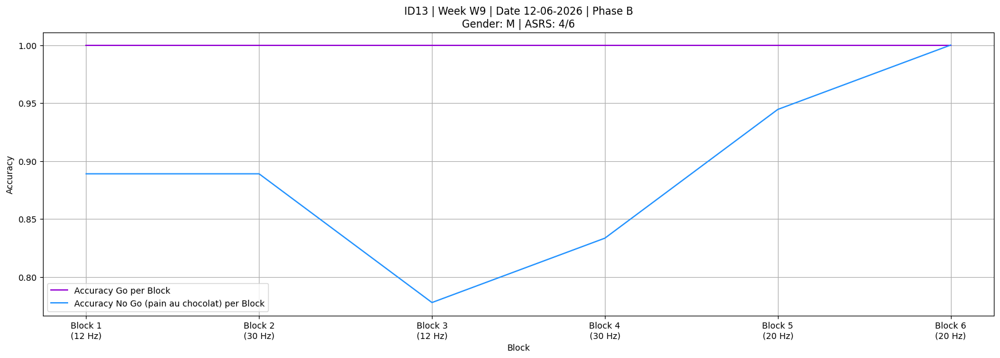

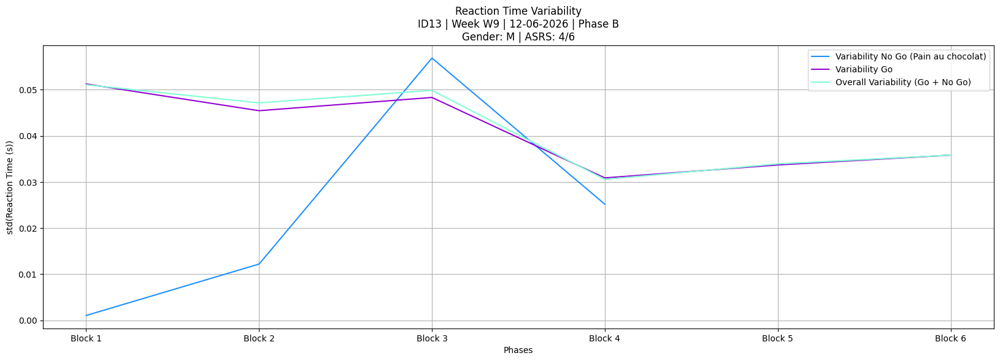

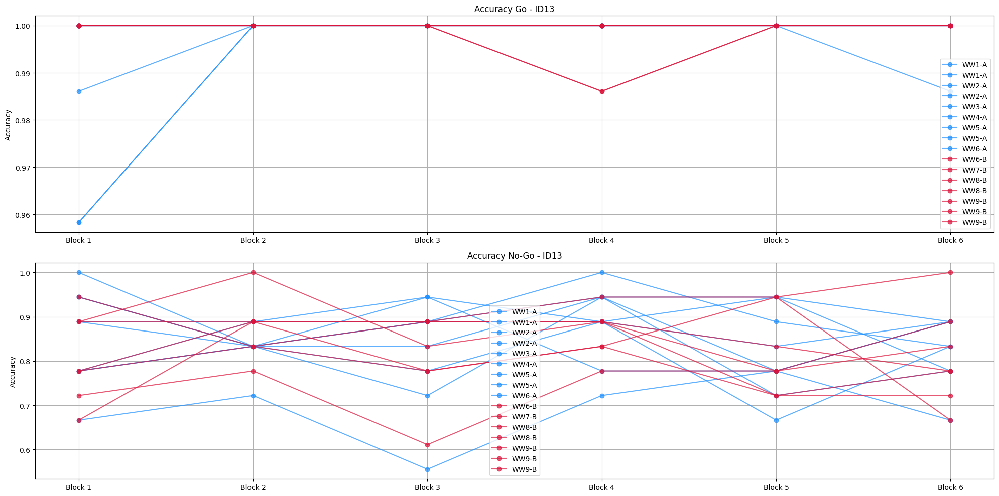

,DATE,PHASE,Go_12,Go_20,Go_30,NoGo_12,NoGo_20,NoGo_30,MeanGo,MeanNoGo
0,2026-04-14,A,0.990741,0.990741,0.990741,0.842593,0.842593,0.842593,NaN,NaN
1,2026-04-17,A,0.997685,0.997685,0.997685,0.722222,0.722222,0.722222,NaN,NaN
2,2026-04-22,A,0.993056,0.993056,0.993056,0.787037,0.787037,0.787037,NaN,NaN
3,2026-04-23,A,1.000000,1.000000,1.000000,0.861111,0.861111,0.861111,NaN,NaN
4,2026-04-28,A,1.000000,1.000000,1.000000,0.833333,0.833333,0.833333,NaN,NaN
5,2026-05-06,A,1.000000,1.000000,1.000000,0.898148,0.898148,0.898148,NaN,NaN
6,2026-05-11,A,1.000000,1.000000,1.000000,0.907407,0.907407,0.907407,NaN,NaN
7,2026-05-13,A,1.000000,1.000000,1.000000,0.814815,0.814815,0.814815,NaN,NaN
8,2026-05-20,A,1.000000,1.000000,1.000000,0.898148,0.898148,0.898148,NaN,NaN
9,2026-05-22,B,1.000000,1.000000,1.000000,0.916667,0.888889,0.750000,1.000000,0.851852


t=-1.972788
t=-3.067300
t=1.846929
t=1.028992


/tmp/ipykernel_1316/346653522.py:91: RuntimeWarning: divide by zero encountered in scalar divide
  t_distrib[b] = (np.mean(draw_x)-np.mean(draw_y))/np.sqrt(np.var(draw_x)/n+np.var(draw_y)/m)


t=-1.727578
Go A-A   p = 0.0172
Go A-B   p = 1.0000
Go B-B   p = 0.1606
NoGo A-A p = 0.0068
NoGo A-B p = 0.0934
NoGo B-B p = 0.1072


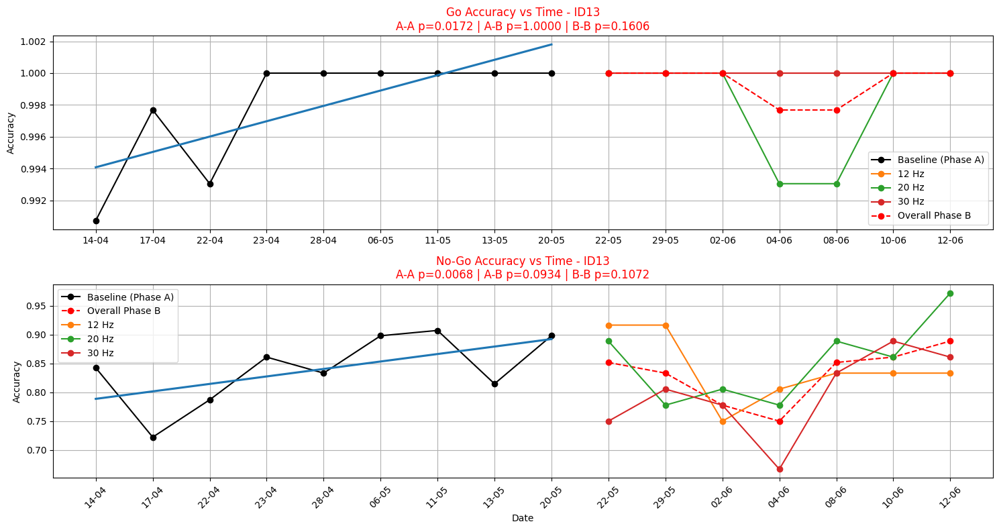

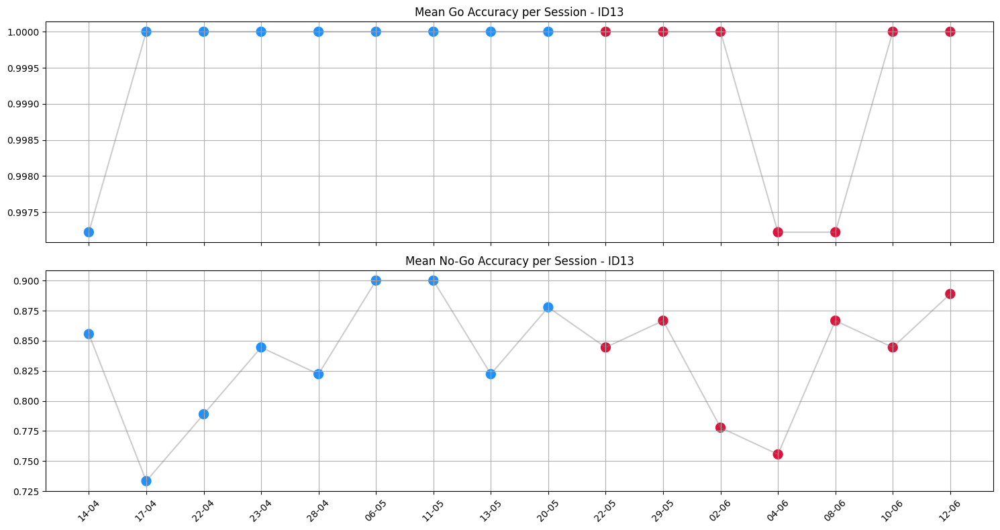

,DATE,Go_12,NoGo_12,Go_20,NoGo_20,Go_30,NoGo_30,MeanGo,MeanNoGo
0,2026-05-22,1.0,0.916667,1.000000,0.888889,1.0,0.750000,1.000000,0.851852
1,2026-05-29,1.0,0.916667,1.000000,0.777778,1.0,0.805556,1.000000,0.833333
2,2026-06-02,1.0,0.750000,1.000000,0.805556,1.0,0.777778,1.000000,0.777778
3,2026-06-04,1.0,0.805556,0.993056,0.777778,1.0,0.666667,0.997685,0.750000
4,2026-06-08,1.0,0.833333,0.993056,0.888889,1.0,0.833333,0.997685,0.851852
5,2026-06-10,1.0,0.833333,1.000000,0.861111,1.0,0.888889,1.000000,0.861111
6,2026-06-12,1.0,0.833333,1.000000,0.972222,1.0,0.861111,1.000000,0.888889


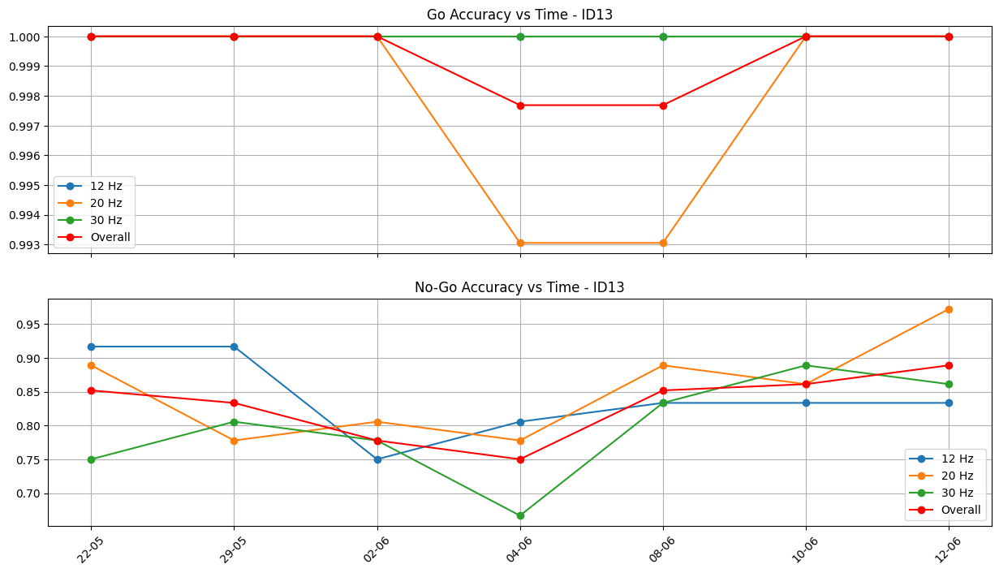

t=3.220990
t=2.677486


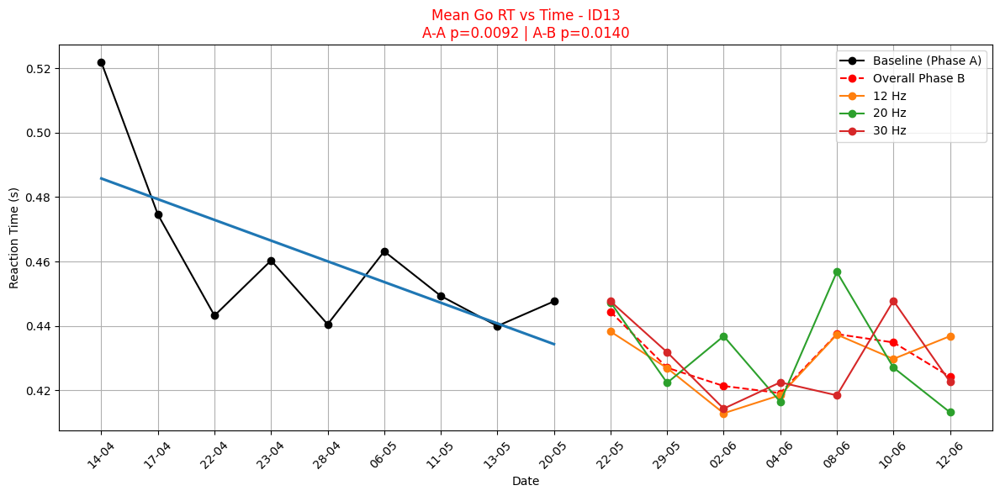

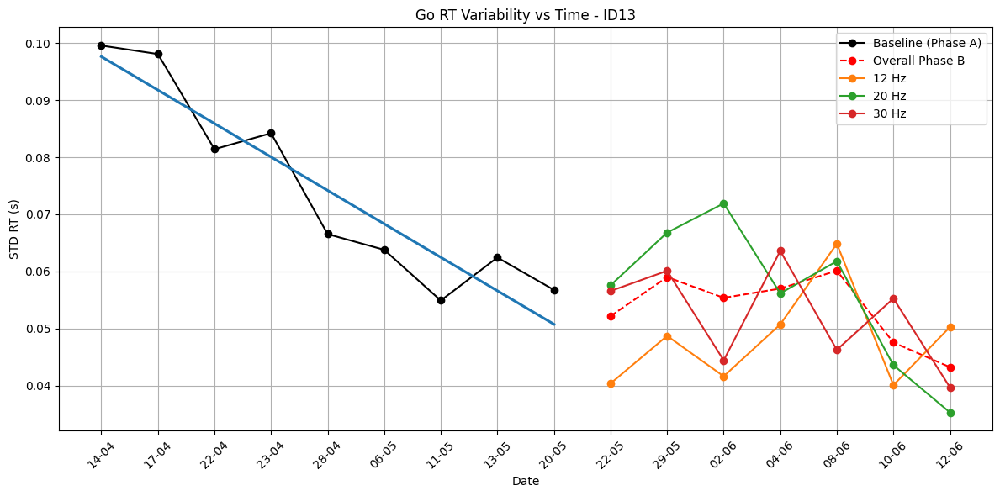

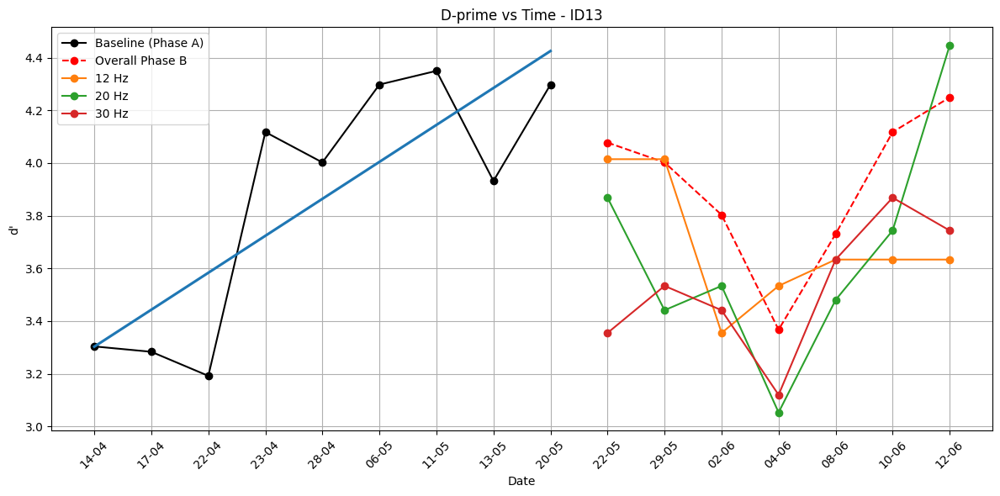

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-14,A,4/6,NaN,NaN,NaN,3.304061,0.997222,0.855556,0.095490
1,2026-04-17,A,4/6,NaN,NaN,NaN,3.283653,1.000000,0.733333,0.091745
2,2026-04-22,A,4/6,NaN,NaN,NaN,3.192292,1.000000,0.788889,0.068872
3,2026-04-23,A,4/6,NaN,NaN,NaN,4.117727,1.000000,0.844444,0.074467
4,2026-04-28,A,4/6,7.0,3.0,5.0,4.002502,1.000000,0.822222,0.061285
5,2026-05-06,A,4/6,7.0,4.0,0.0,4.298044,1.000000,0.900000,0.054865
6,2026-05-11,A,4/6,8.0,3.0,0.0,4.349997,1.000000,0.900000,0.051462
7,2026-05-13,A,4/6,8.0,4.0,0.0,3.932267,1.000000,0.822222,0.058829
8,2026-05-20,A,4/6,9.0,4.0,0.0,4.298044,1.000000,0.877778,0.054592
9,2026-05-22,B,4/6,8.0,3.0,0.0,4.077797,1.000000,0.844444,0.046571


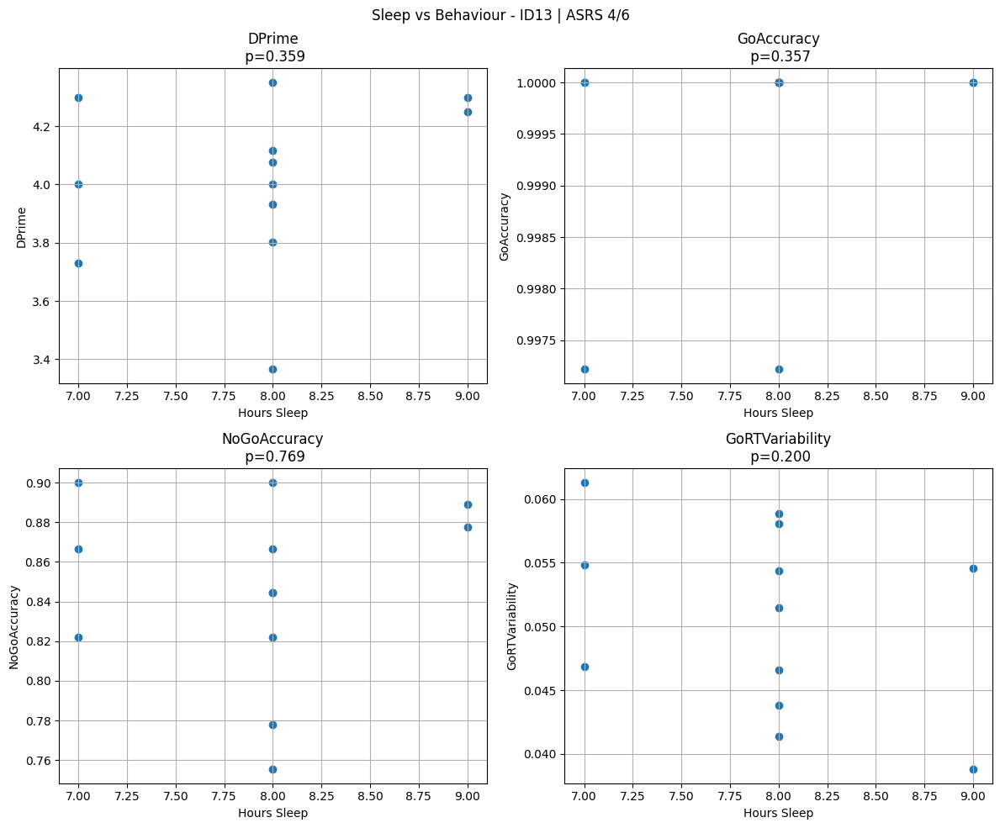

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-14,A,4/6,NaN,NaN,NaN,3.304061,0.997222,0.855556,0.095490
1,2026-04-17,A,4/6,NaN,NaN,NaN,3.283653,1.000000,0.733333,0.091745
2,2026-04-22,A,4/6,NaN,NaN,NaN,3.192292,1.000000,0.788889,0.068872
3,2026-04-23,A,4/6,NaN,NaN,NaN,4.117727,1.000000,0.844444,0.074467
4,2026-04-28,A,4/6,7.0,3.0,5.0,4.002502,1.000000,0.822222,0.061285
5,2026-05-06,A,4/6,7.0,4.0,0.0,4.298044,1.000000,0.900000,0.054865
6,2026-05-11,A,4/6,8.0,3.0,0.0,4.349997,1.000000,0.900000,0.051462
7,2026-05-13,A,4/6,8.0,4.0,0.0,3.932267,1.000000,0.822222,0.058829
8,2026-05-20,A,4/6,9.0,4.0,0.0,4.298044,1.000000,0.877778,0.054592
9,2026-05-22,B,4/6,8.0,3.0,0.0,4.077797,1.000000,0.844444,0.046571


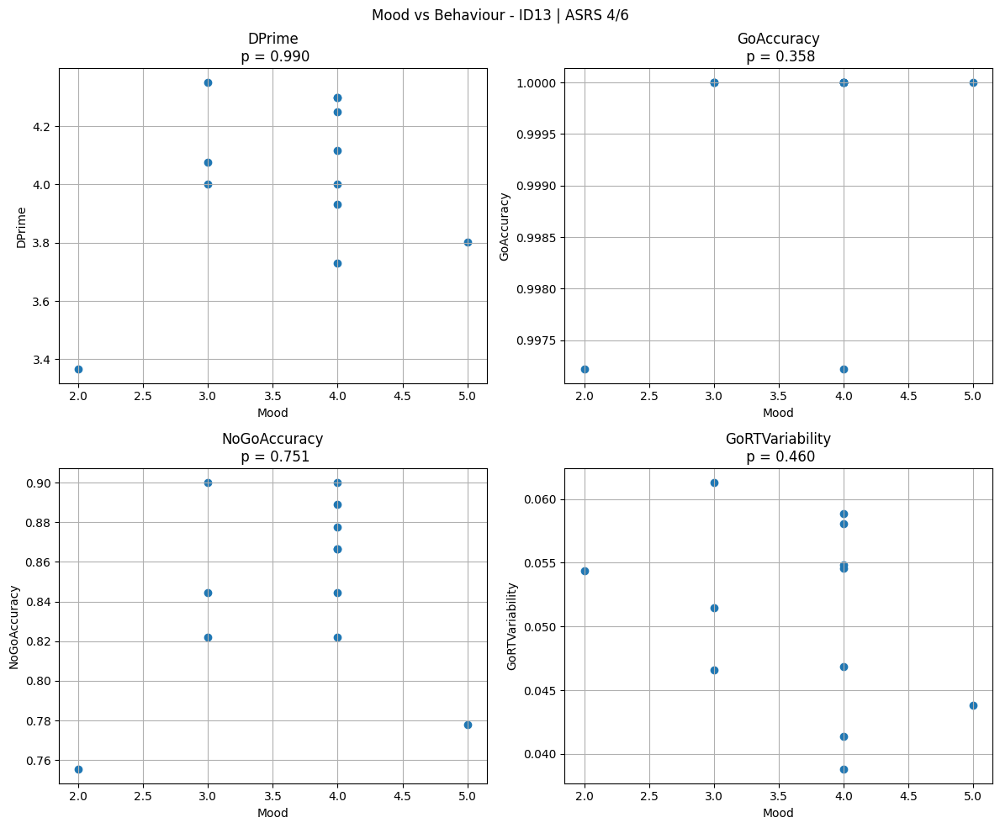

,Metric,n_A,n_B,Mean_A,Mean_B,Observed_Diff,NAP,TauU,Permutation_p
0,DPrime,9,7,3.864287,3.907013,0.042725,0.476190,-0.047619,0.4271
1,Variability_Go,9,7,0.069648,0.050300,0.019348,0.920635,0.841270,0.0013
2,Accuracy_NoGo,9,7,0.840535,0.830688,-0.009847,0.428571,-0.142857,0.6313


In [639]:
df_id13 = pipeline(13)
sced_df = sced_metrics(df_id13)
display(sced_df)

In [ ]:
freq_sced_id13 = sced_frequency_metrics(df_id13, 13)
display(freq_sced_id13)

,n_A,n_B,Mean_A,Mean_B,Observed_Diff,NAP,TauU,Permutation_p,Metric,Frequency
0,9,7,3.864287,3.688550,-0.175737,0.396825,-0.206349,0.8127,DPrime,12
1,9,7,0.069162,0.048073,0.021088,0.920635,0.841270,0.0019,Variability_Go,12
2,9,7,0.840535,0.841270,0.000735,0.476190,-0.047619,0.4963,Accuracy_NoGo,12
3,9,7,3.864287,3.652601,-0.211686,0.380952,-0.238095,0.8172,DPrime,20
4,9,7,0.069162,0.056147,0.013015,0.698413,0.396825,0.0485,Variability_Go,20
5,9,7,0.840535,0.853175,0.012640,0.492063,-0.015873,0.3510,Accuracy_NoGo,20
6,9,7,3.864287,3.528174,-0.336113,0.285714,-0.428571,0.9443,DPrime,30
7,9,7,0.069162,0.052259,0.016902,0.793651,0.587302,0.0093,Variability_Go,30
8,9,7,0.840535,0.797619,-0.042916,0.301587,-0.396825,0.8921,Accuracy_NoGo,30


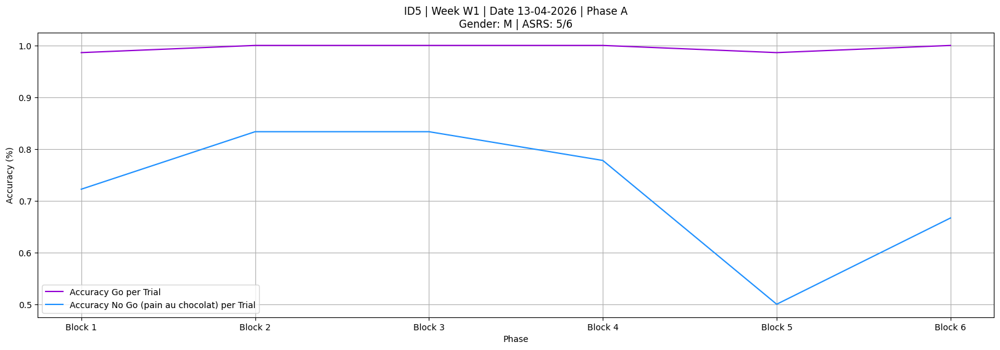

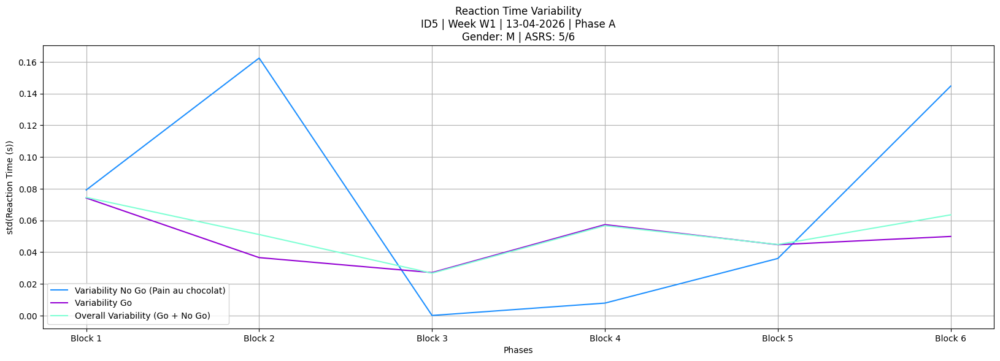

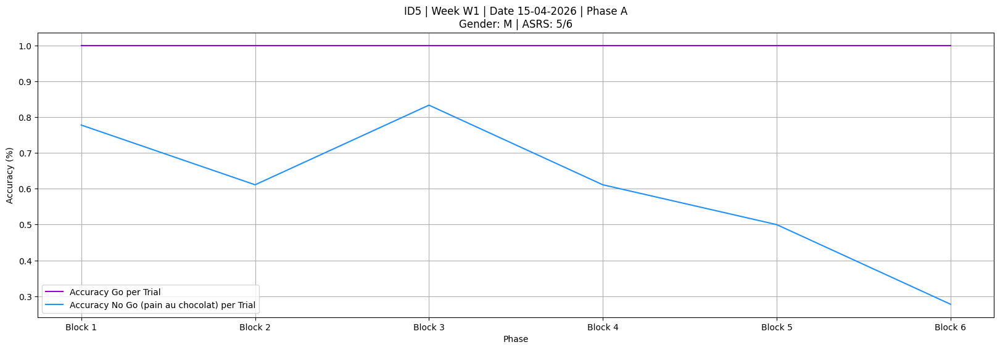

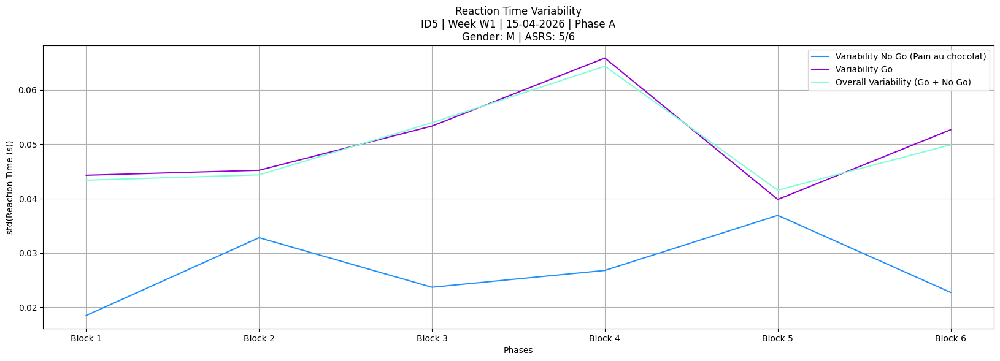

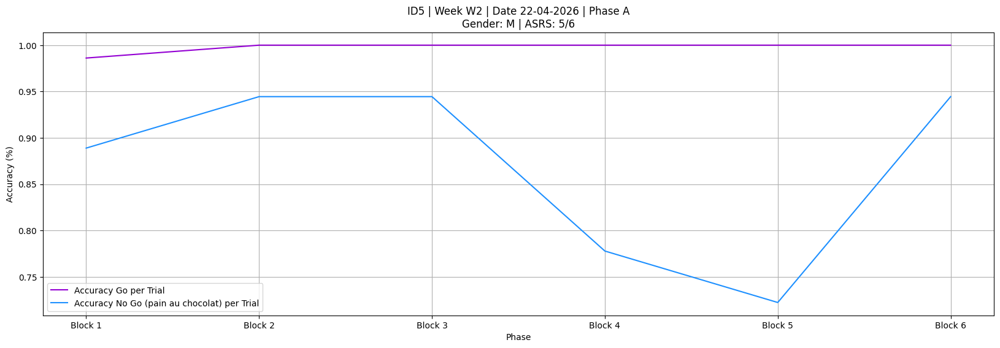

...

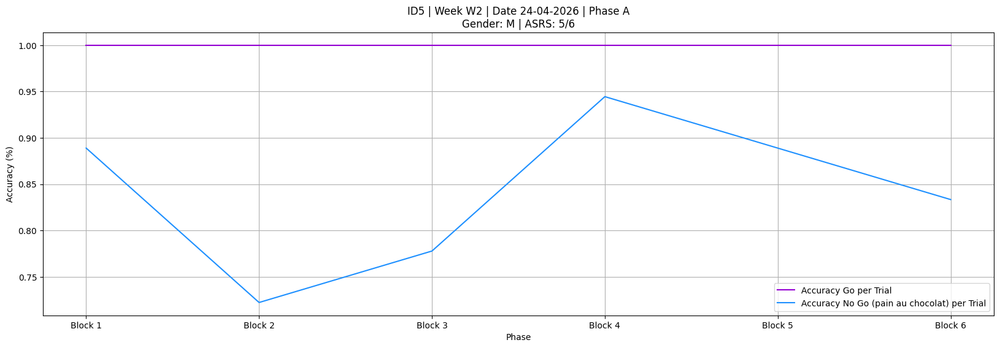

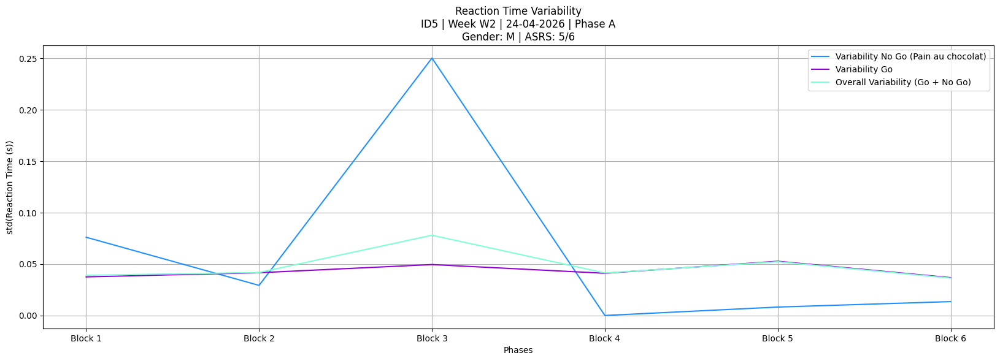

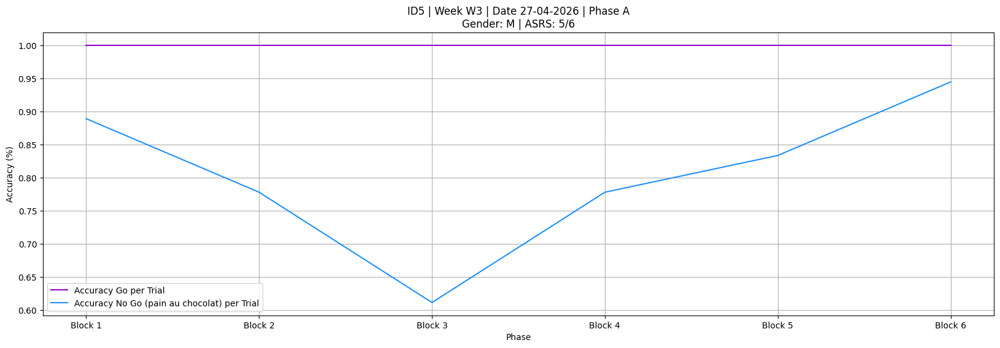

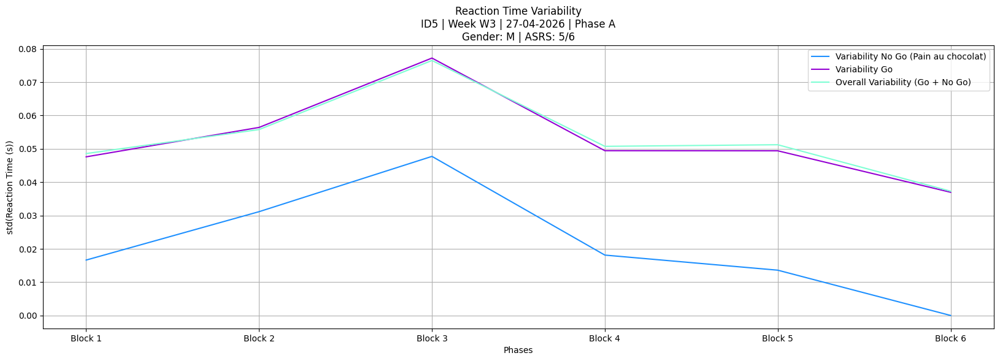

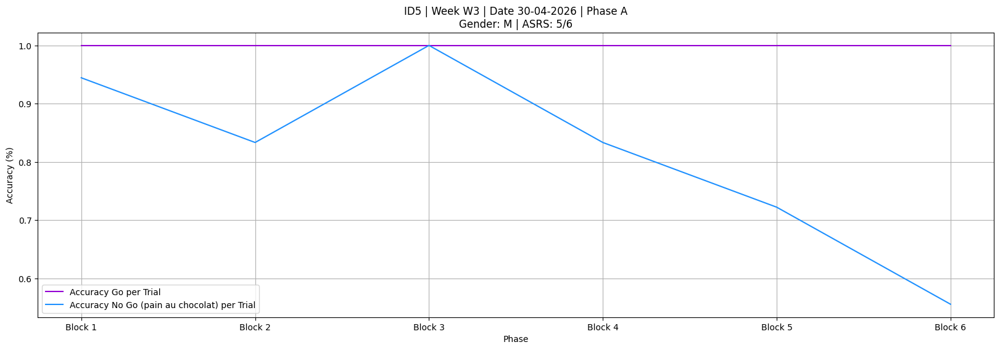

/usr/local/lib/python3.12/dist-packages/numpy/lib/_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


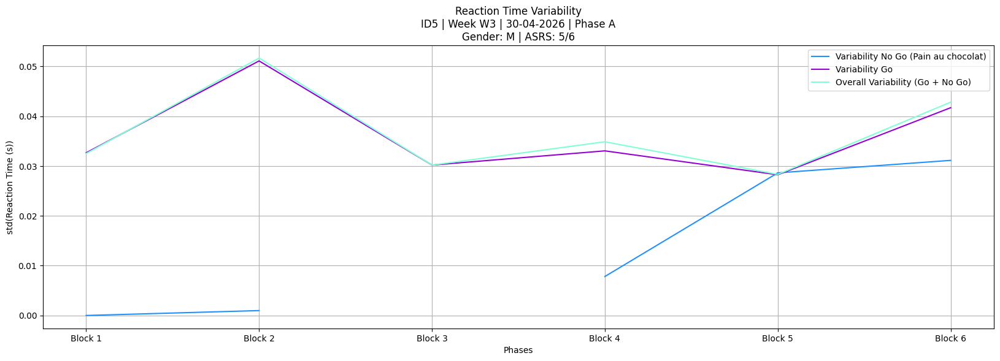

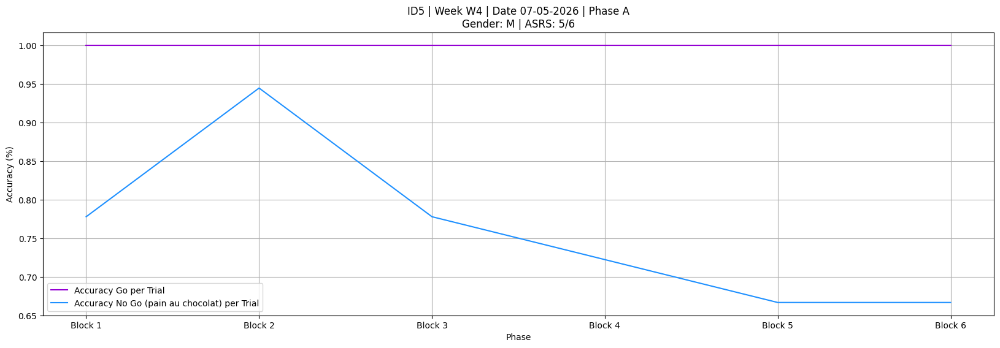

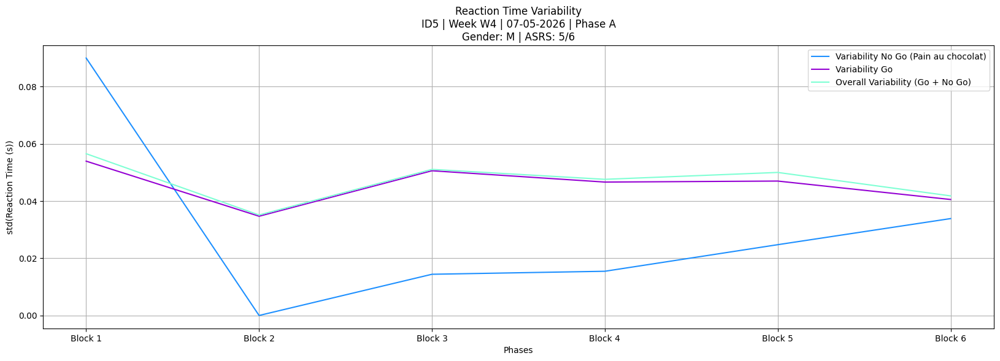

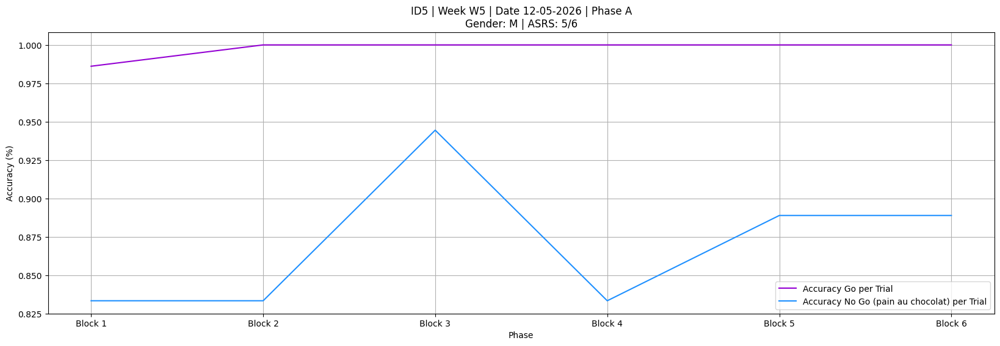

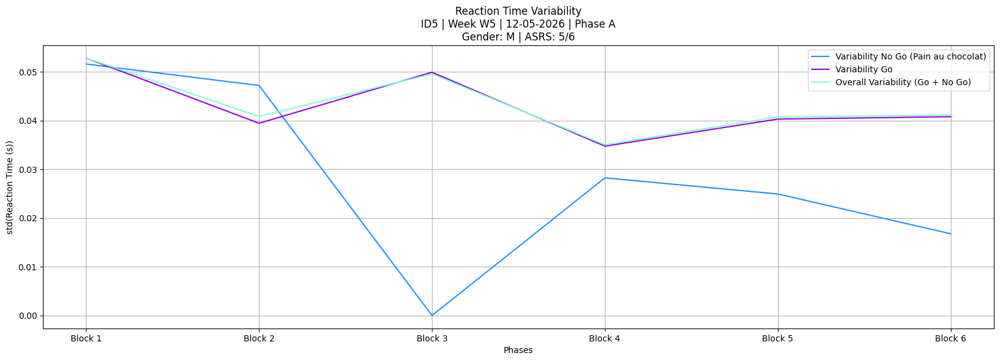

...

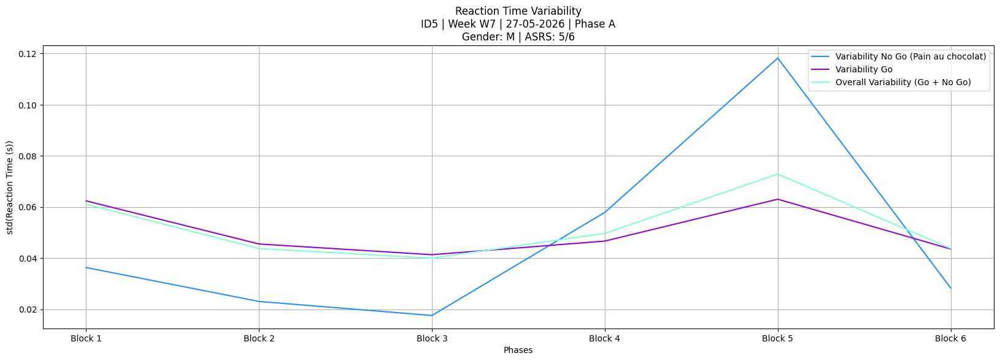

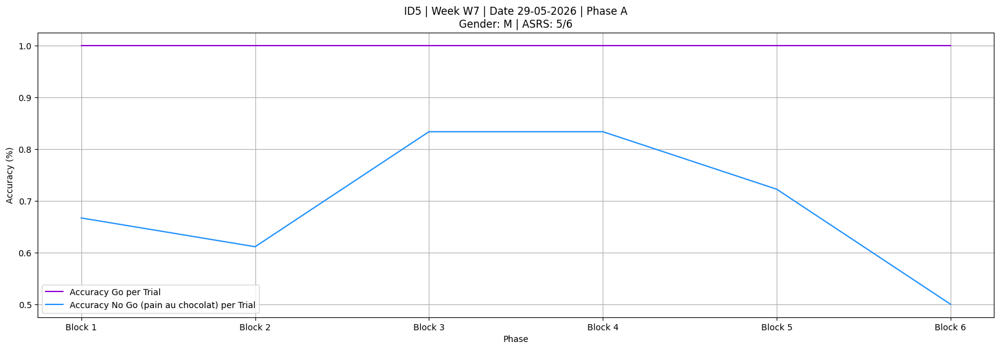

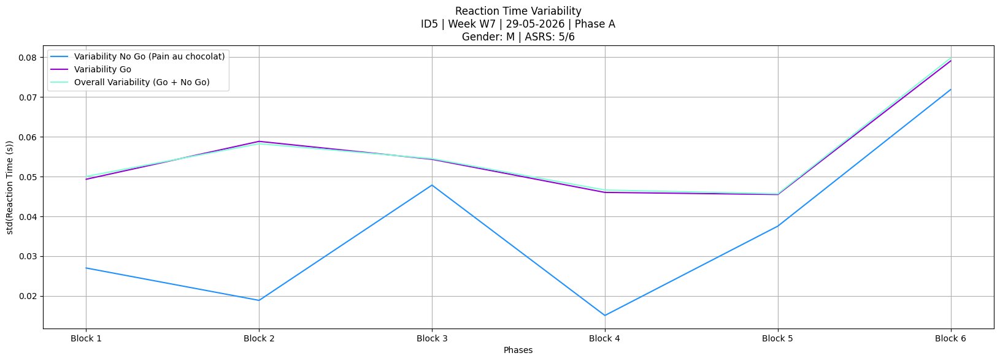

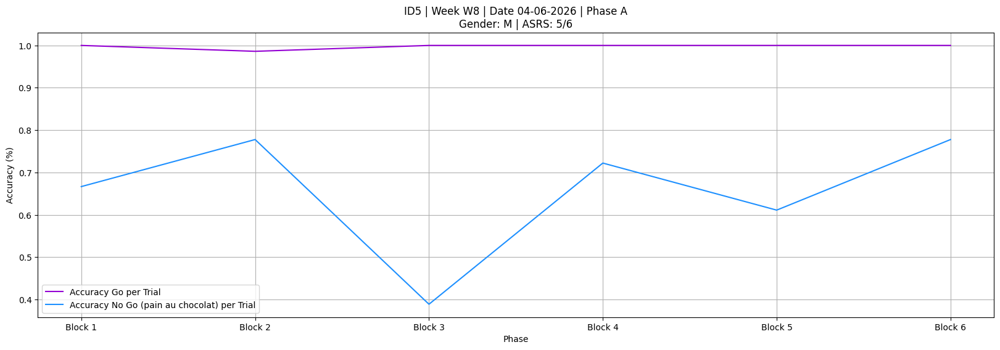

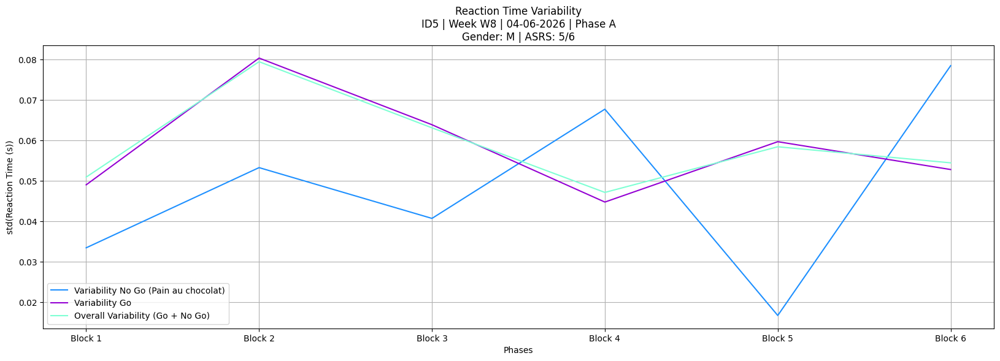

SESSION DATE: 2026-06-05 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
12,2026-06-05,B,"30,12,20,20,12,30"


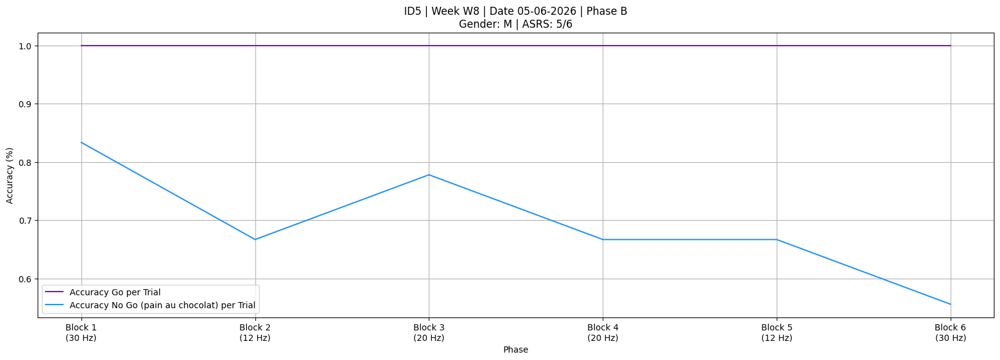

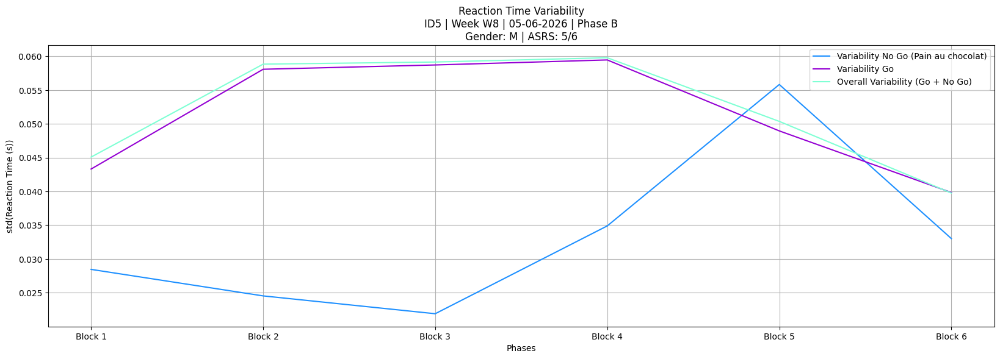

SESSION DATE: 2026-06-08 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
13,2026-06-08,B,"30,20,12,12,20,30"


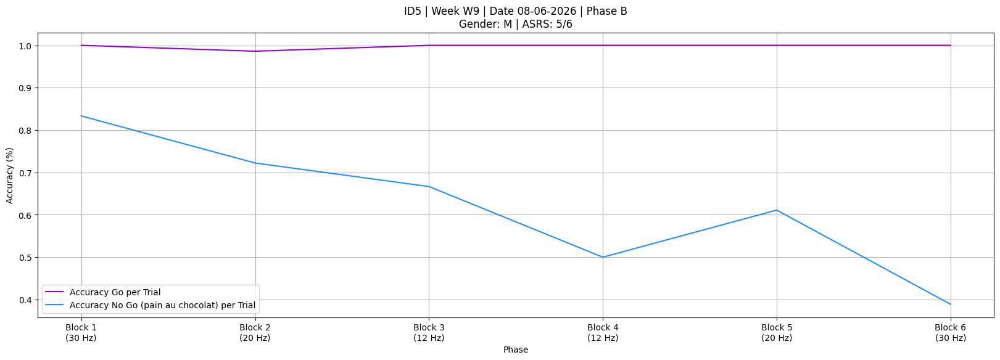

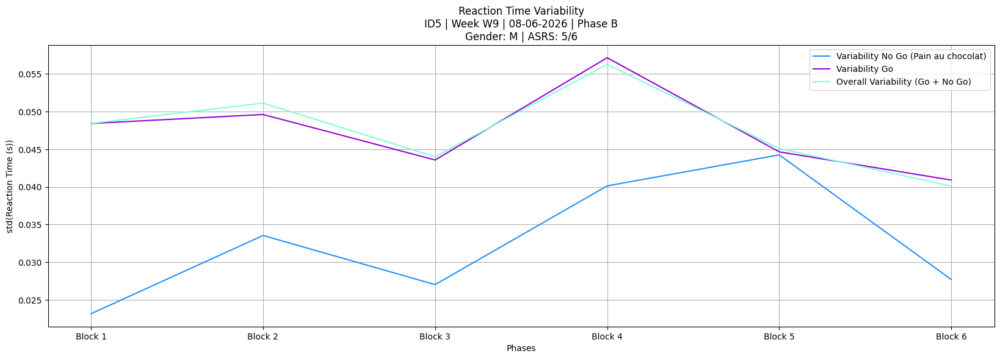

SESSION DATE: 2026-06-10 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
14,2026-06-10,B,"20,30,30,20,12,12"


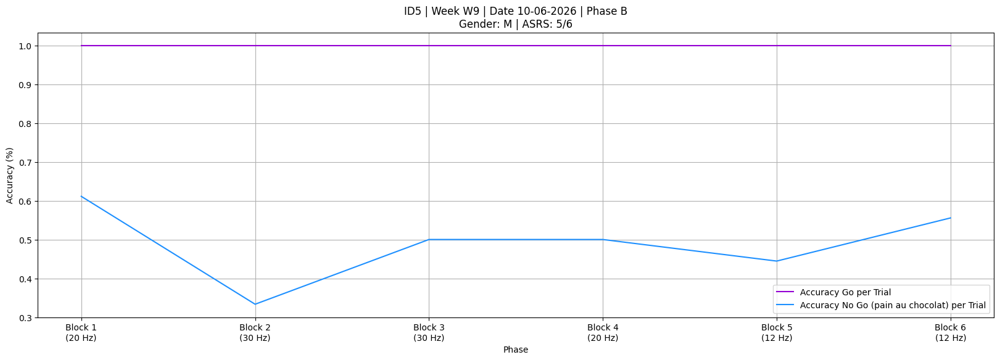

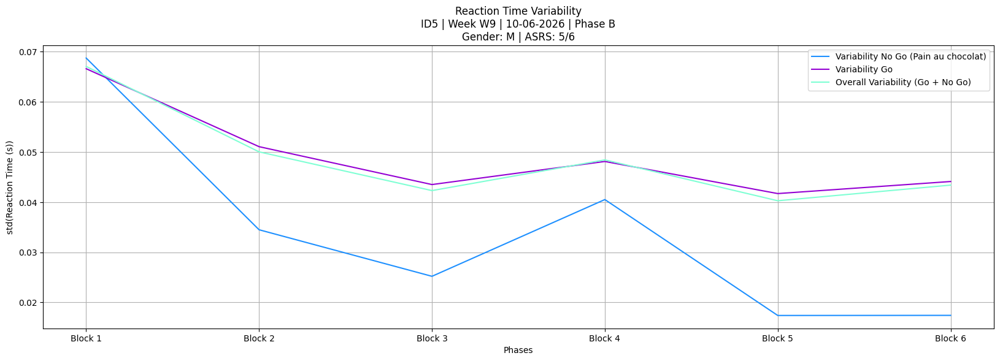

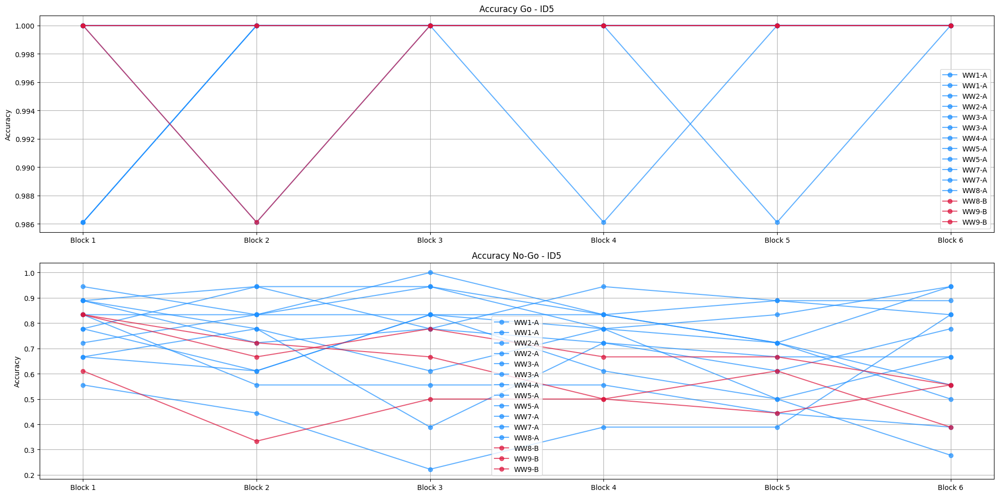

,DATE,PHASE,Go_12,Go_20,Go_30,NoGo_12,NoGo_20,NoGo_30,MeanGo,MeanNoGo
0,2026-04-13,A,0.995370,0.995370,0.995370,0.722222,0.722222,0.722222,NaN,NaN
1,2026-04-15,A,1.000000,1.000000,1.000000,0.601852,0.601852,0.601852,NaN,NaN
2,2026-04-22,A,0.997685,0.997685,0.997685,0.870370,0.870370,0.870370,NaN,NaN
3,2026-04-24,A,1.000000,1.000000,1.000000,0.842593,0.842593,0.842593,NaN,NaN
4,2026-04-27,A,1.000000,1.000000,1.000000,0.805556,0.805556,0.805556,NaN,NaN
5,2026-04-30,A,1.000000,1.000000,1.000000,0.814815,0.814815,0.814815,NaN,NaN
6,2026-05-07,A,1.000000,1.000000,1.000000,0.759259,0.759259,0.759259,NaN,NaN
7,2026-05-12,A,0.997685,0.997685,0.997685,0.870370,0.870370,0.870370,NaN,NaN
8,2026-05-13,A,1.000000,1.000000,1.000000,0.555556,0.555556,0.555556,NaN,NaN
9,2026-05-27,A,0.997685,0.997685,0.997685,0.472222,0.472222,0.472222,NaN,NaN


t=-0.483494
t=2.098171
t=0.115577
t=-0.606092
Go A-A   p = 0.6448
Go A-B   p = 0.5636
NoGo A-A p = 0.0472
NoGo A-B p = 0.9216


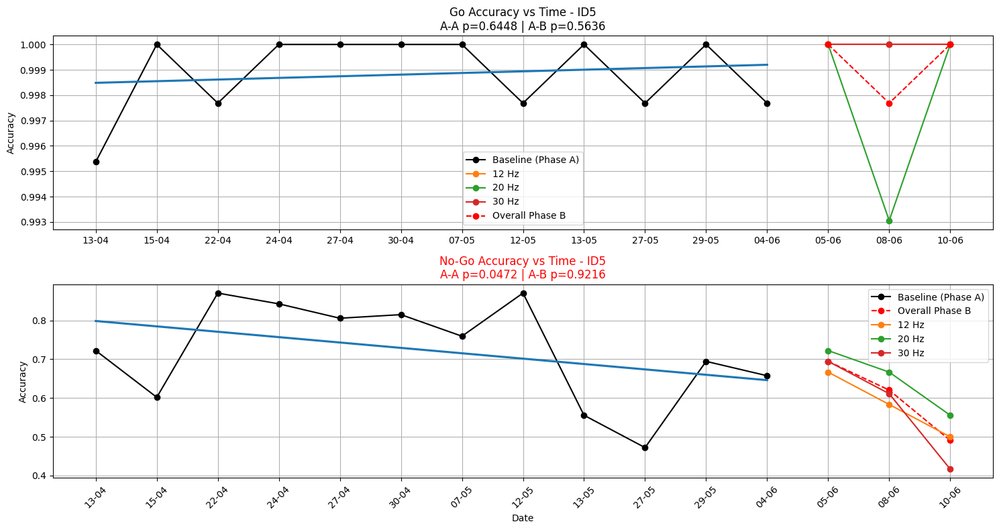

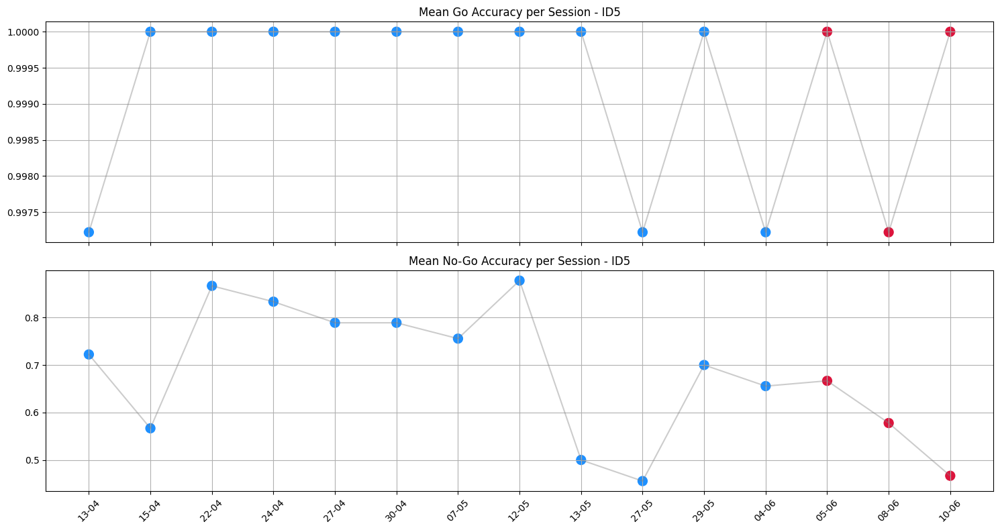

,DATE,Go_12,NoGo_12,Go_20,NoGo_20,Go_30,NoGo_30,MeanGo,MeanNoGo
0,2026-06-05,1.0,0.666667,1.000000,0.722222,1.0,0.694444,1.000000,0.694444
1,2026-06-08,1.0,0.583333,0.993056,0.666667,1.0,0.611111,0.997685,0.620370
2,2026-06-10,1.0,0.500000,1.000000,0.555556,1.0,0.416667,1.000000,0.490741


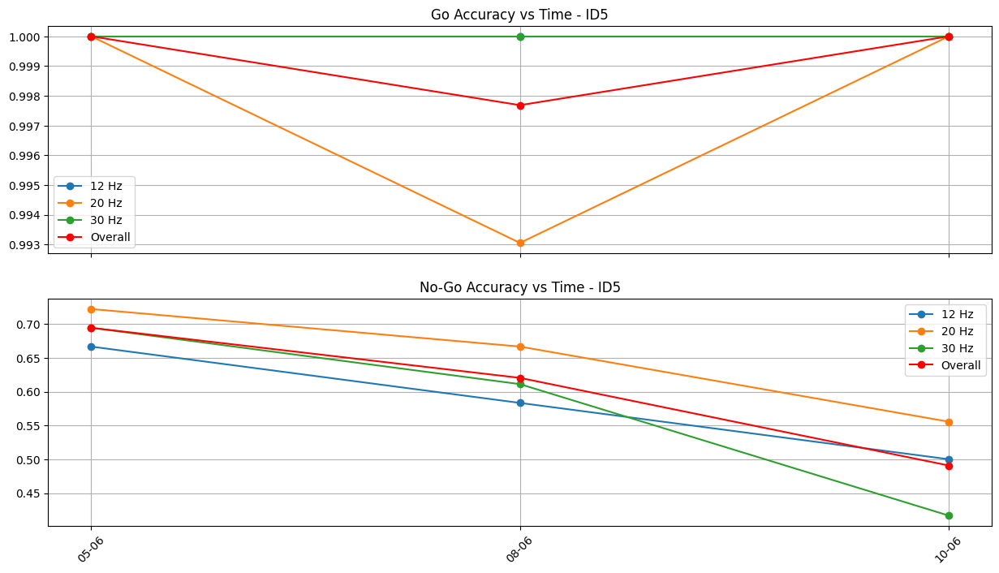

t=3.531076
t=0.357166


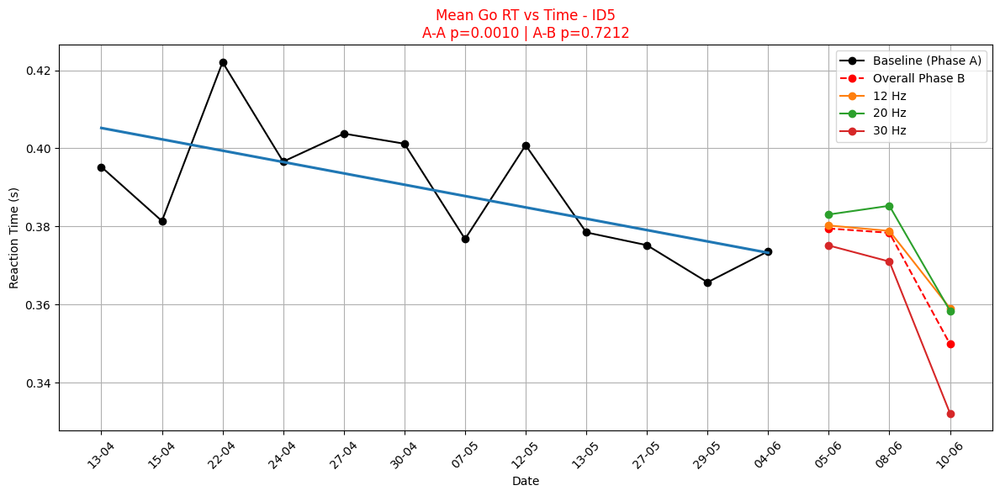

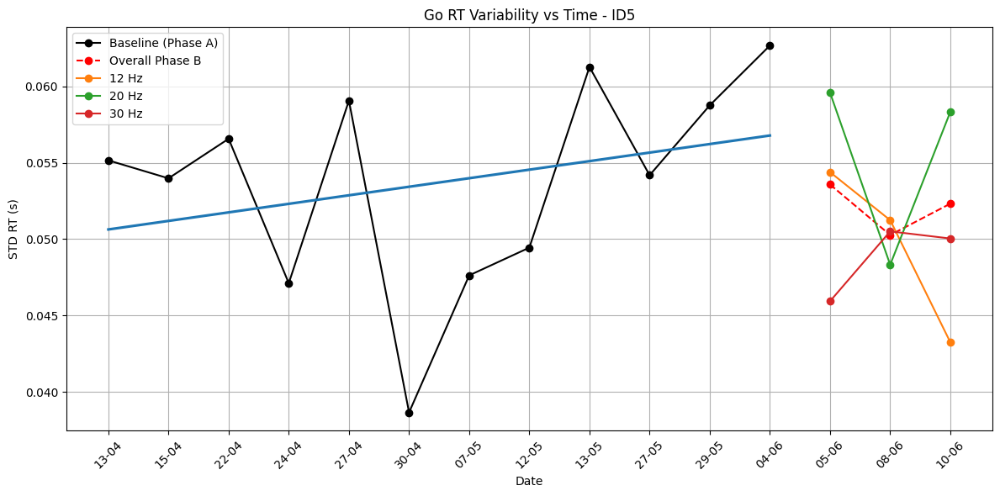

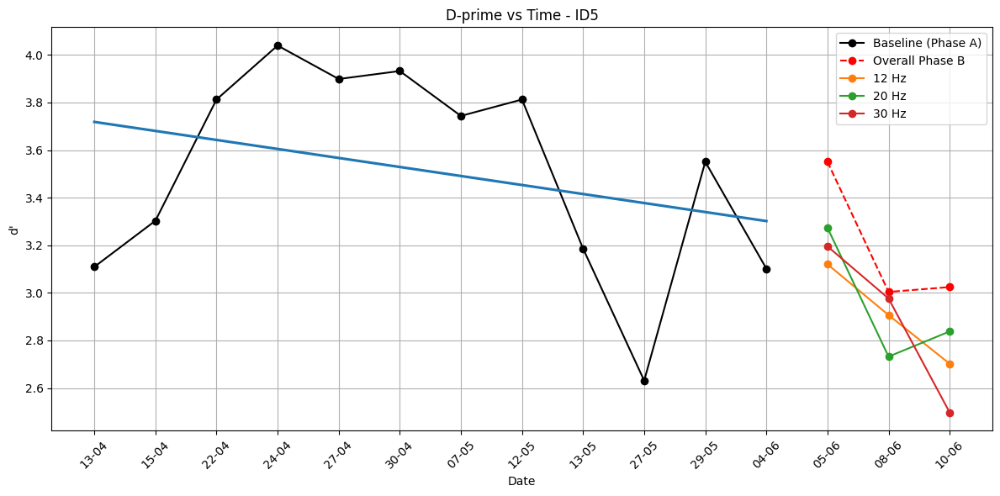

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-13,A,5/6,NaN,NaN,NaN,3.109070,0.997222,0.722222,0.043093
1,2026-04-15,A,5/6,NaN,NaN,NaN,3.302971,1.000000,0.566667,0.051383
2,2026-04-22,A,5/6,NaN,NaN,5.0,3.812459,1.000000,0.866667,0.049612
3,2026-04-24,A,5/6,NaN,NaN,5.0,4.039446,1.000000,0.833333,0.044288
4,2026-04-27,A,5/6,8.0,5.0,0.0,3.898742,1.000000,0.788889,0.053884
5,2026-04-30,A,5/6,8.0,4.0,0.0,3.932267,1.000000,0.788889,0.036865
6,2026-05-07,A,5/6,7.0,4.0,0.0,3.743552,1.000000,0.755556,0.043880
7,2026-05-12,A,5/6,8.0,4.0,0.0,3.812459,1.000000,0.877778,0.041017
8,2026-05-13,A,5/6,6.0,3.0,0.0,3.185669,1.000000,0.500000,0.054372
9,2026-05-27,A,5/6,6.0,3.0,0.0,2.631221,0.997222,0.455556,0.048021


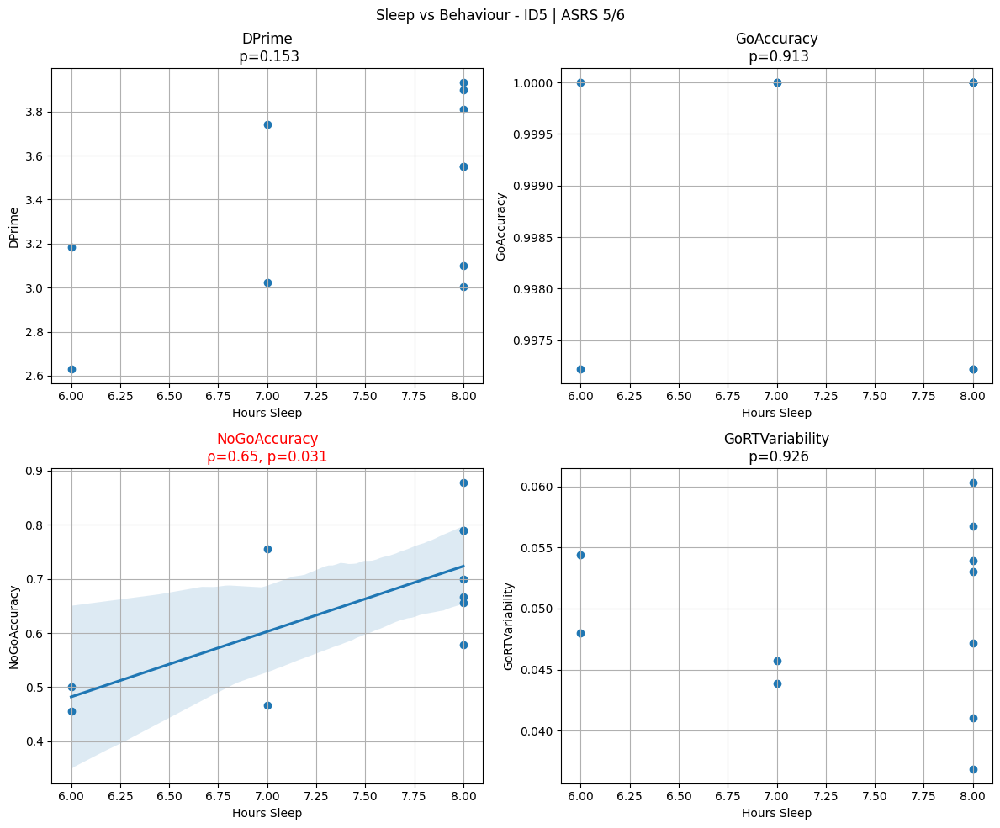

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-13,A,5/6,NaN,NaN,NaN,3.109070,0.997222,0.722222,0.043093
1,2026-04-15,A,5/6,NaN,NaN,NaN,3.302971,1.000000,0.566667,0.051383
2,2026-04-22,A,5/6,NaN,NaN,5.0,3.812459,1.000000,0.866667,0.049612
3,2026-04-24,A,5/6,NaN,NaN,5.0,4.039446,1.000000,0.833333,0.044288
4,2026-04-27,A,5/6,8.0,5.0,0.0,3.898742,1.000000,0.788889,0.053884
5,2026-04-30,A,5/6,8.0,4.0,0.0,3.932267,1.000000,0.788889,0.036865
6,2026-05-07,A,5/6,7.0,4.0,0.0,3.743552,1.000000,0.755556,0.043880
7,2026-05-12,A,5/6,8.0,4.0,0.0,3.812459,1.000000,0.877778,0.041017
8,2026-05-13,A,5/6,6.0,3.0,0.0,3.185669,1.000000,0.500000,0.054372
9,2026-05-27,A,5/6,6.0,3.0,0.0,2.631221,0.997222,0.455556,0.048021


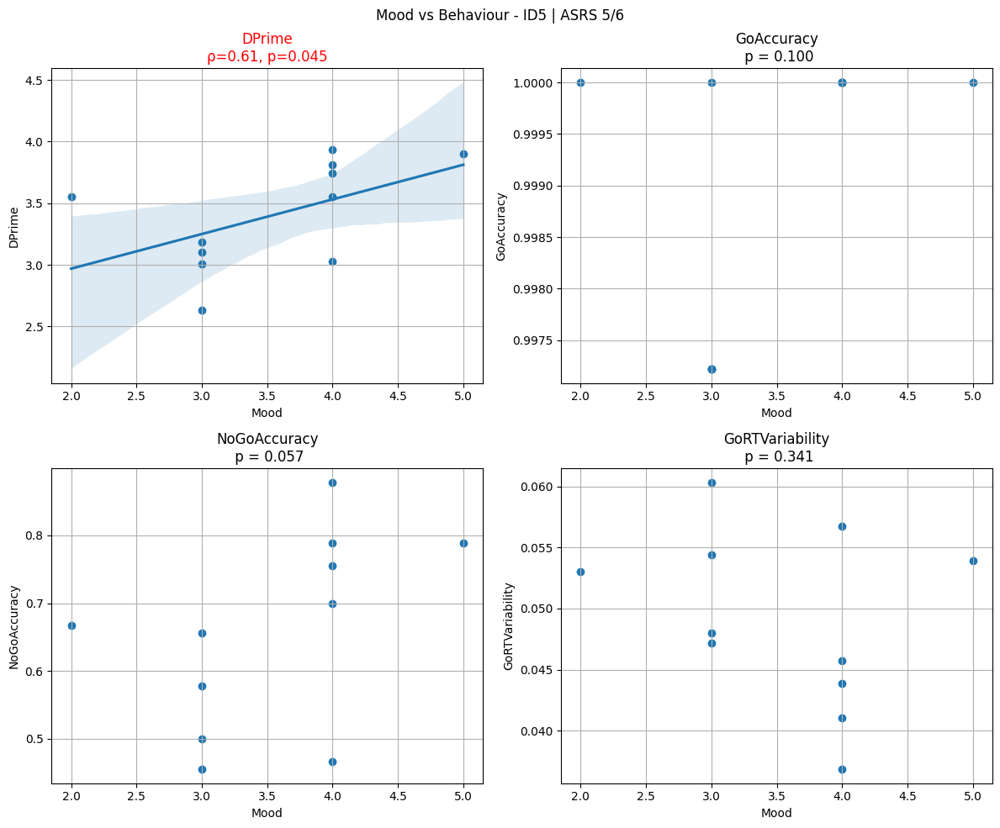

,Metric,n_A,n_B,Mean_A,Mean_B,Observed_Diff,NAP,TauU,Permutation_p
0,DPrime,12,3,3.510021,3.192908,-0.317113,0.208333,-0.583333,0.8603
1,Variability_Go,12,3,0.048923,0.049322,-0.000398,0.500000,0.000000,0.5218
2,Accuracy_NoGo,12,3,0.722222,0.601852,-0.120370,0.222222,-0.555556,0.9096


In [ ]:
df_id5 = pipeline(5)
sced_df = sced_metrics(df_id5)
display(sced_df)

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,255.681165,Go,NaN,NaN,Incorrect,True,False,10
1,1,1,256.675194,Go,NaN,NaN,Incorrect,True,False,10
2,1,2,257.657825,Go,NaN,NaN,Incorrect,True,False,10
3,1,3,258.641636,Go,NaN,NaN,Incorrect,True,False,10
4,1,4,259.628052,Go,NaN,NaN,Incorrect,True,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,888.396458,Go,space,0.348847,Correct,False,False,10
536,6,536,889.378587,Go,space,0.416690,Correct,False,False,10
537,6,537,890.363271,Go,space,0.448664,Correct,False,False,10
538,6,538,891.345186,Go,space,0.416811,Correct,False,False,10


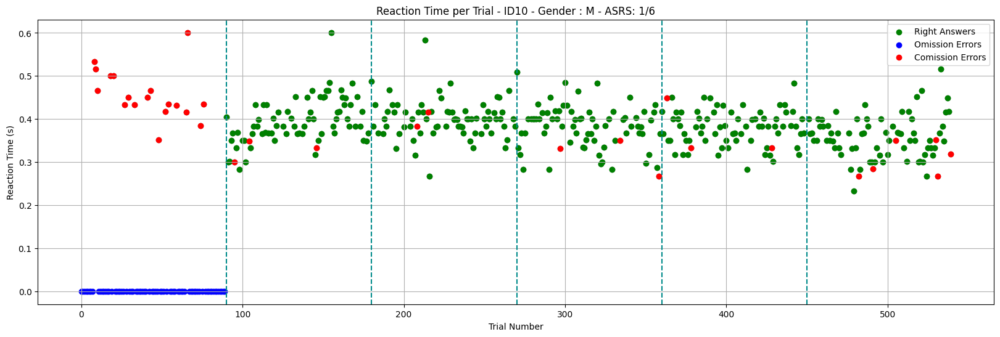

t=7.107285


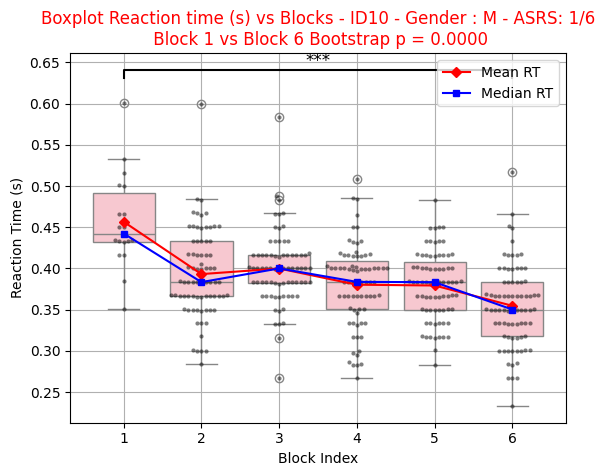

[{'Block': 'Block 1', 'Accuracy Go': 0.0, 'Accuracy No Go': 0.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666}]

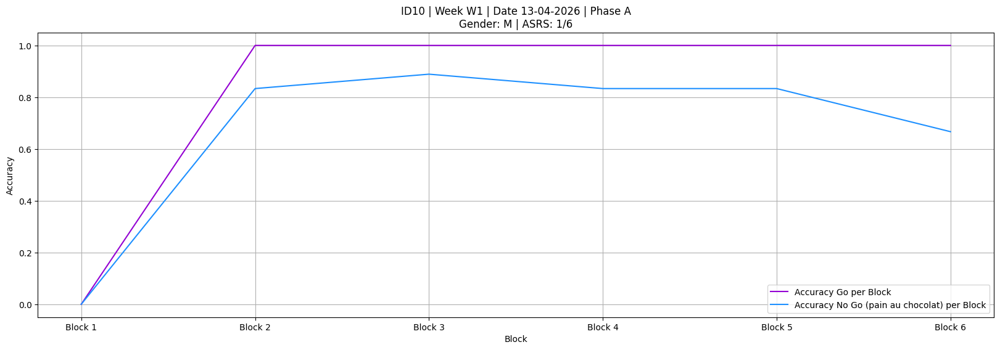

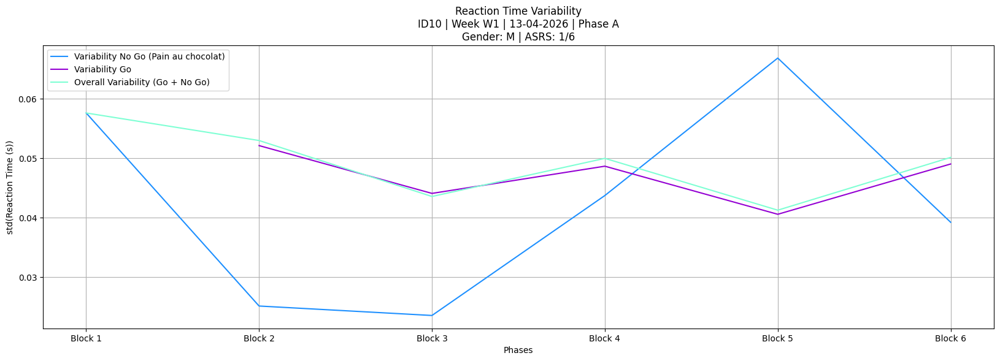

/tmp/ipykernel_1316/3679704612.py:16: RuntimeWarning: Mean of empty slice
  np.nanmean(go_rts)


,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,199.905575,No_Go,space,0.377372,Incorrect,False,True,10
1,1,1,200.932812,No_Go,space,0.366845,Incorrect,False,True,10
2,1,2,201.949499,Go,space,0.450324,Correct,False,False,10
3,1,3,202.967518,Go,space,0.416503,Correct,False,False,10
4,1,4,203.983032,No_Go,NaN,NaN,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,854.208430,Go,space,0.400010,Correct,False,False,10
536,6,536,855.225041,Go,space,0.333384,Correct,False,False,10
537,6,537,856.241609,Go,space,0.350179,Correct,False,False,10
538,6,538,857.258135,No_Go,space,0.283370,Incorrect,False,True,10


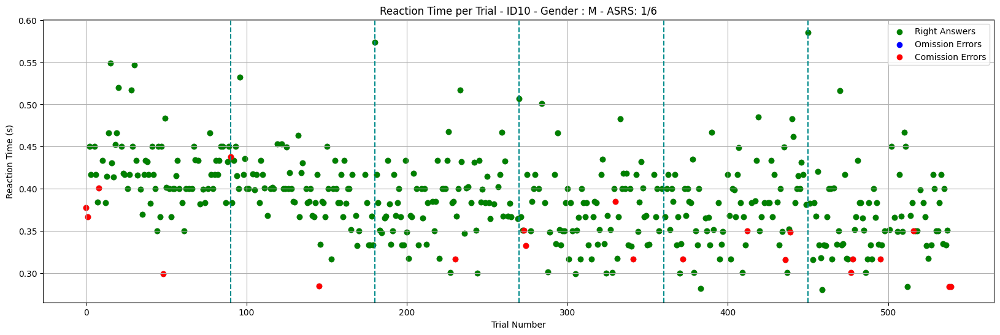

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=7.712322


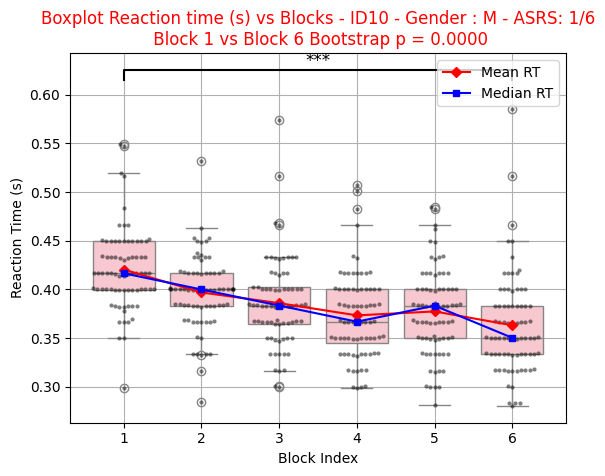

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666}]

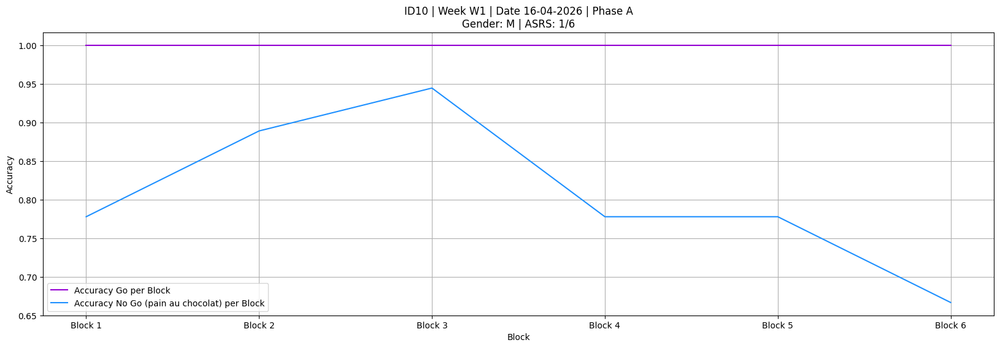

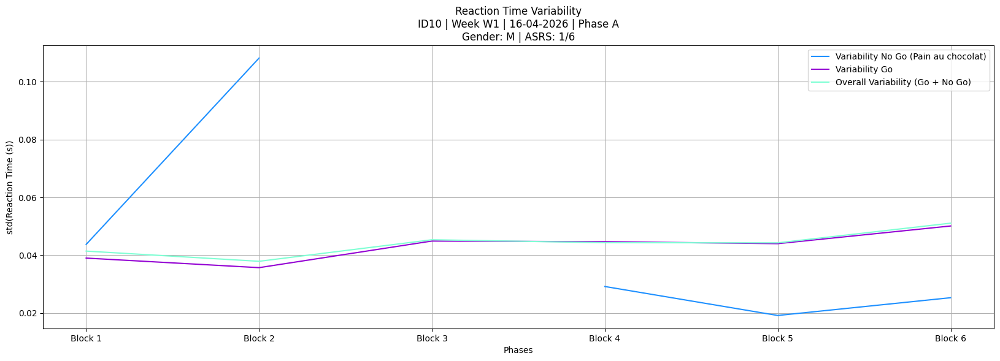

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,320.946991,Go,space,0.425486,Correct,False,False,10
1,1,1,321.939075,No_Go,space,0.333408,Incorrect,False,True,10
2,1,2,322.922281,No_Go,space,0.450310,Incorrect,False,True,10
3,1,3,323.906091,No_Go,NaN,NaN,Correct,False,False,10
4,1,4,324.889107,Go,space,0.383337,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,954.757873,Go,space,0.299624,Correct,False,False,10
536,6,536,955.739424,No_Go,NaN,NaN,Correct,False,False,10
537,6,537,956.722695,Go,space,0.350230,Correct,False,False,10
538,6,538,957.706085,Go,space,0.366751,Correct,False,False,10


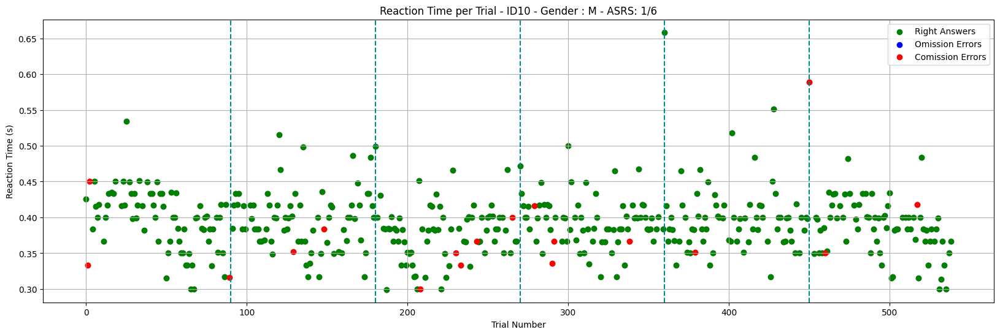

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=1.170066


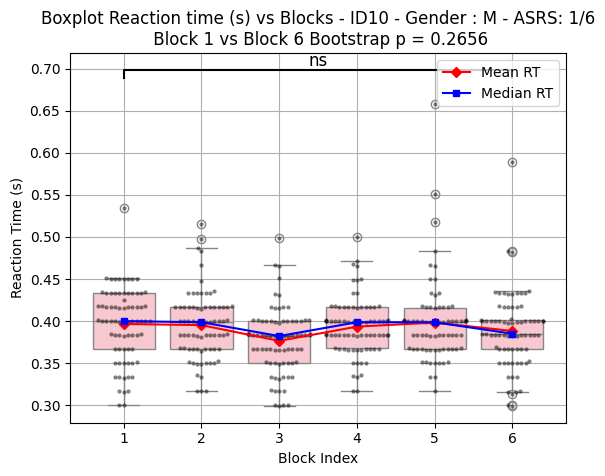

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334}]

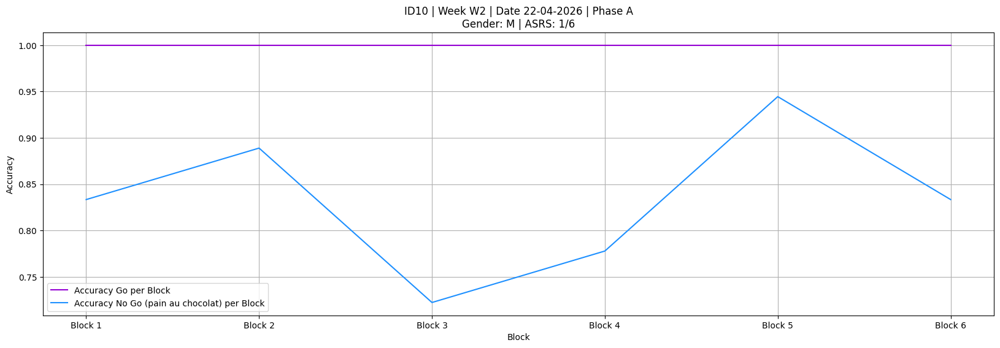

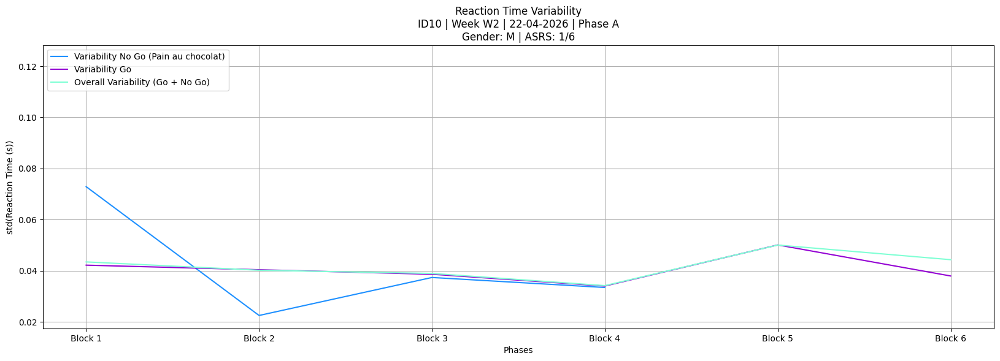

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,28.906297,Go,space,0.455367,Correct,False,False,10
1,1,1,29.945186,Go,space,0.399616,Correct,False,False,10
2,1,2,30.961864,Go,space,0.450138,Correct,False,False,10
3,1,3,31.980528,Go,space,0.414567,Correct,False,False,10
4,1,4,32.995131,Go,space,0.416735,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,687.320960,Go,space,0.399962,Correct,False,False,10
536,6,536,688.337833,Go,space,0.399599,Correct,False,False,10
537,6,537,689.355695,Go,space,0.398426,Correct,False,False,10
538,6,538,690.370690,Go,space,0.383469,Correct,False,False,10


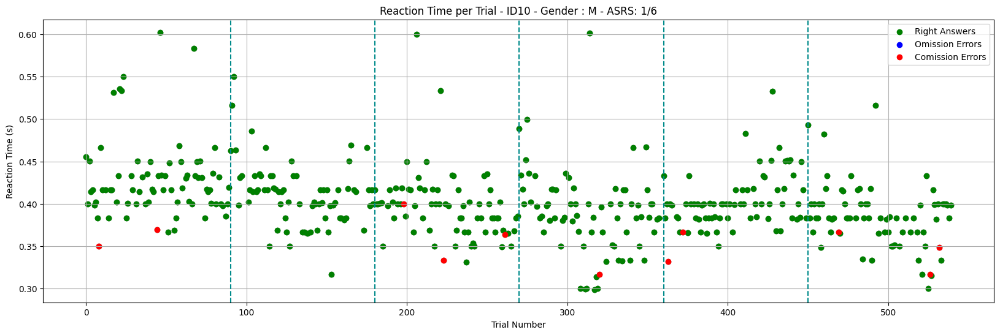

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 14.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=6.359207


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


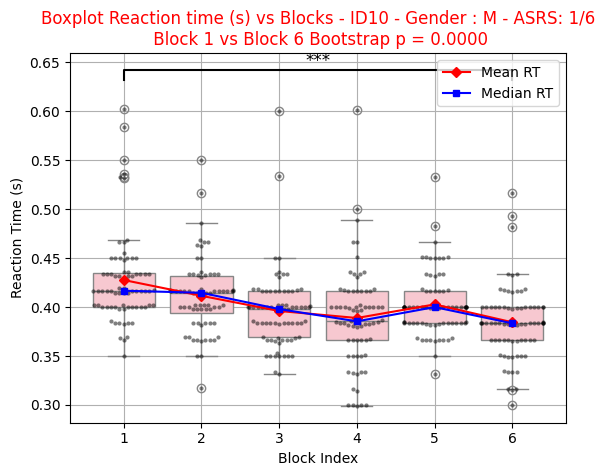

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334}]

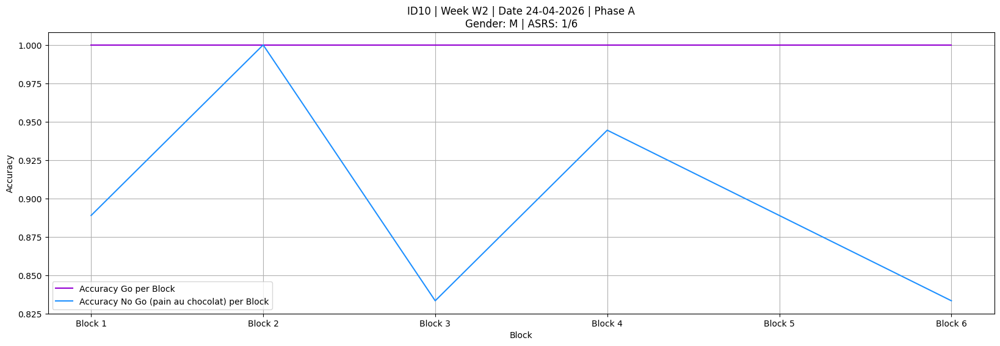

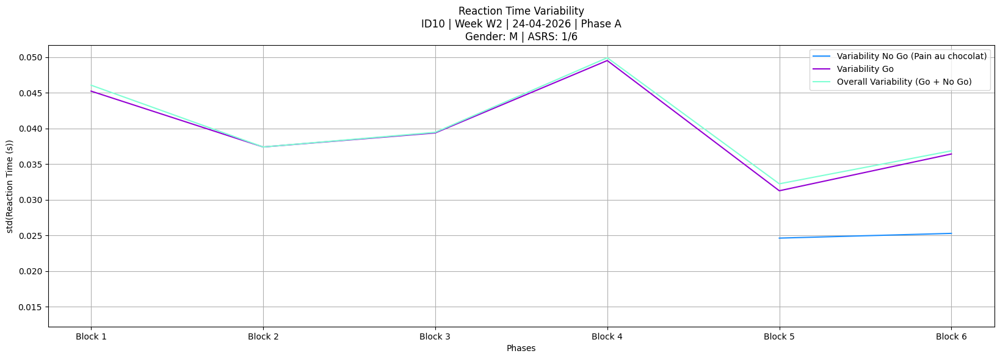

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,142.926139,Go,space,0.395263,Correct,False,False,10
1,1,1,143.970802,Go,space,0.433092,Correct,False,False,10
2,1,2,144.986343,No_Go,NaN,NaN,Correct,False,False,10
3,1,3,146.004813,Go,space,0.433126,Correct,False,False,10
4,1,4,147.020533,Go,space,0.466326,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,795.335095,Go,space,0.383015,Correct,False,False,10
536,6,536,796.350808,Go,space,0.383021,Correct,False,False,10
537,6,537,797.366535,Go,space,0.382993,Correct,False,False,10
538,6,538,798.382266,Go,space,0.366276,Correct,False,False,10


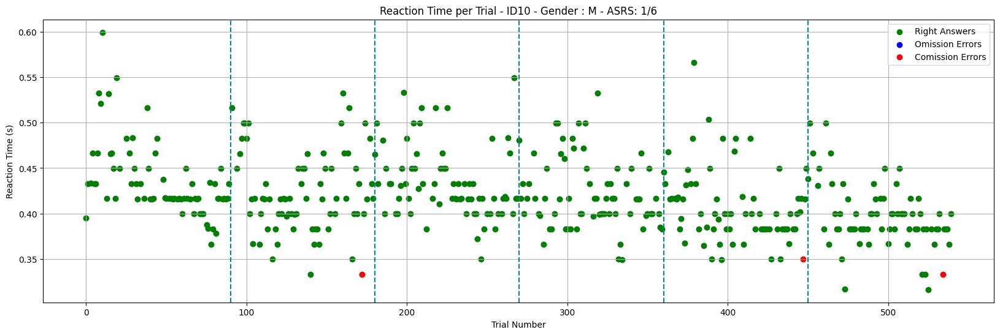

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 18.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 15.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=6.275562


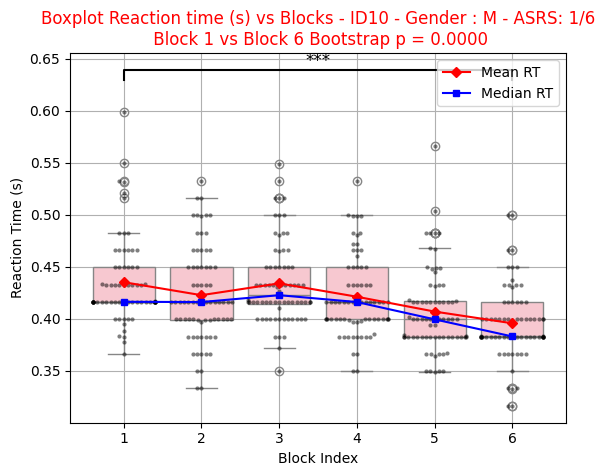

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

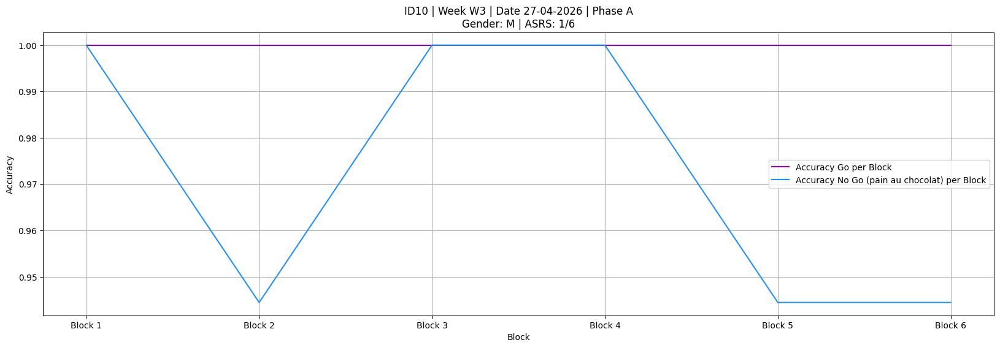

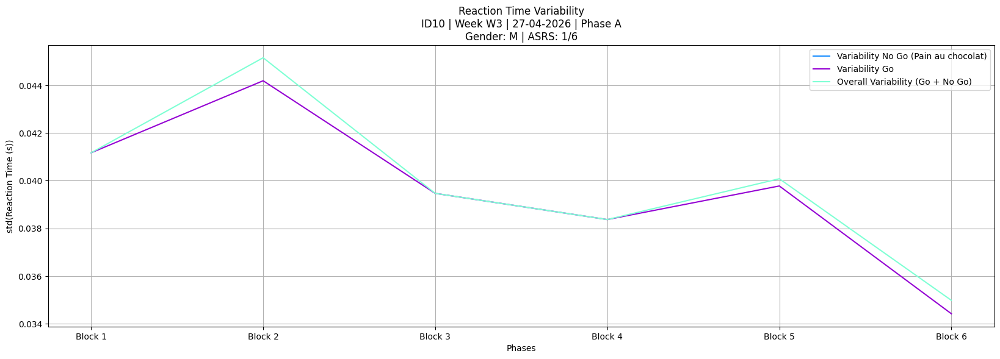

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,238.722044,Go,space,0.547364,Correct,False,False,10
1,1,1,239.753005,Go,space,0.416614,Correct,False,False,10
2,1,2,240.769293,Go,space,0.433604,Correct,False,False,10
3,1,3,241.785980,Go,space,0.383425,Correct,False,False,10
4,1,4,242.802840,Go,space,0.434002,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,891.040861,Go,space,0.433285,Correct,False,False,10
536,6,536,892.057493,Go,space,0.399821,Correct,False,False,10
537,6,537,893.074076,Go,space,0.333331,Correct,False,False,10
538,6,538,894.090816,Go,space,0.365600,Correct,False,False,10


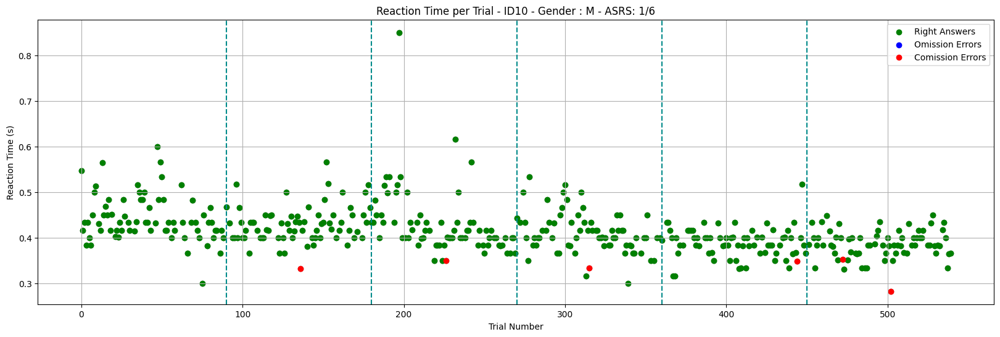

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=8.316205


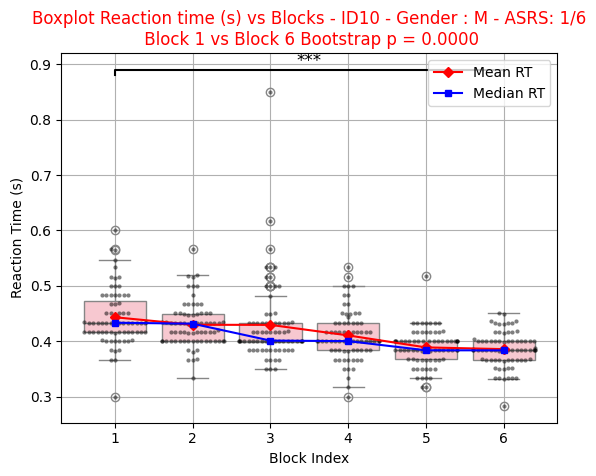

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

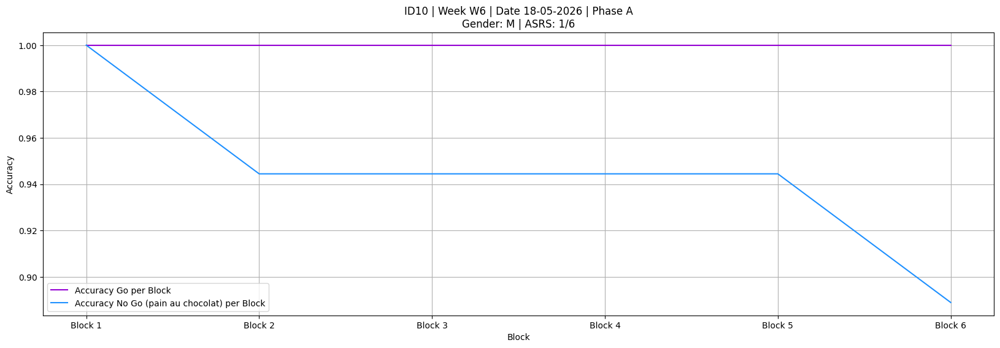

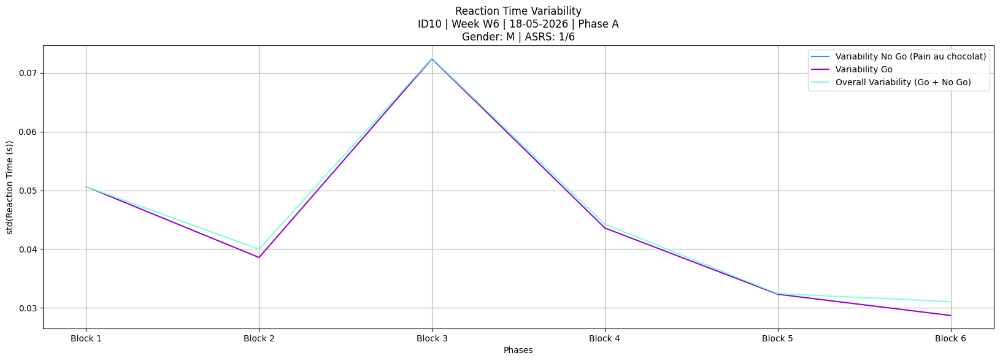

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,207.313239,Go,space,0.389513,Correct,False,False,10
1,1,1,208.353150,Go,space,0.366202,Correct,False,False,10
2,1,2,209.369745,Go,space,0.400105,Correct,False,False,10
3,1,3,210.386304,Go,space,0.366650,Correct,False,False,10
4,1,4,211.403558,Go,space,0.349460,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,857.157515,Go,space,0.452518,Correct,False,False,10
536,6,536,858.173912,No_Go,NaN,NaN,Correct,False,False,10
537,6,537,859.191381,Go,space,0.382578,Correct,False,False,10
538,6,538,860.209373,Go,space,0.347762,Correct,False,False,10


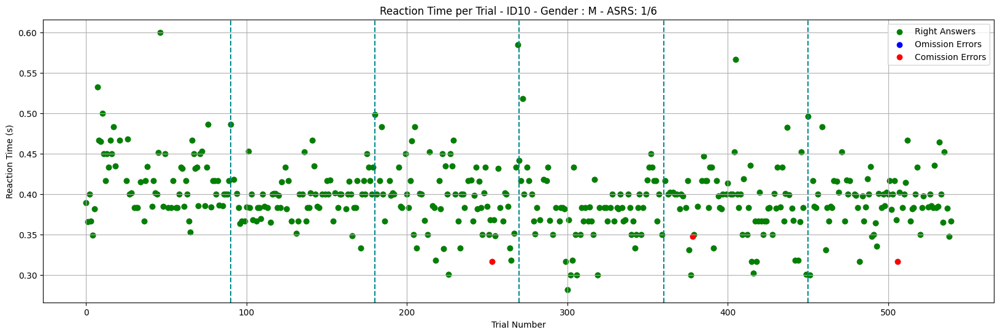

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 13.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=4.056196


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


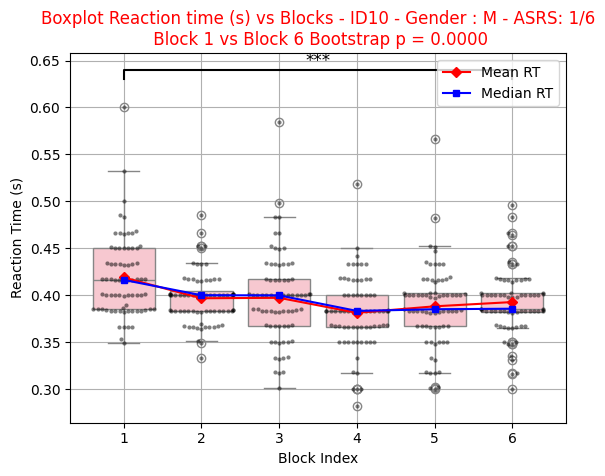

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

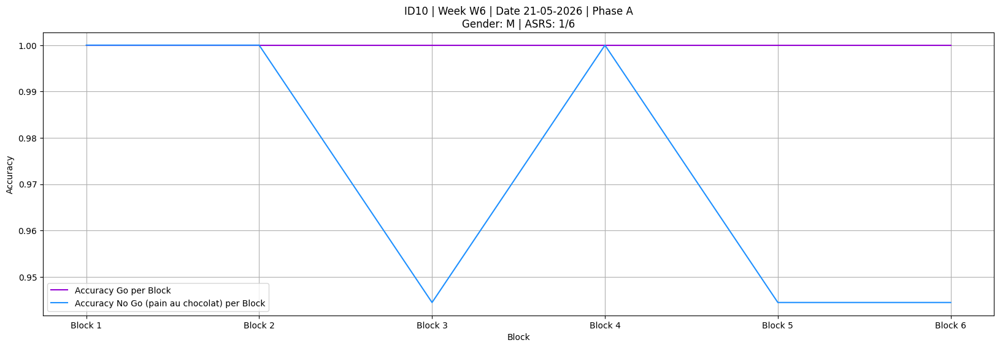

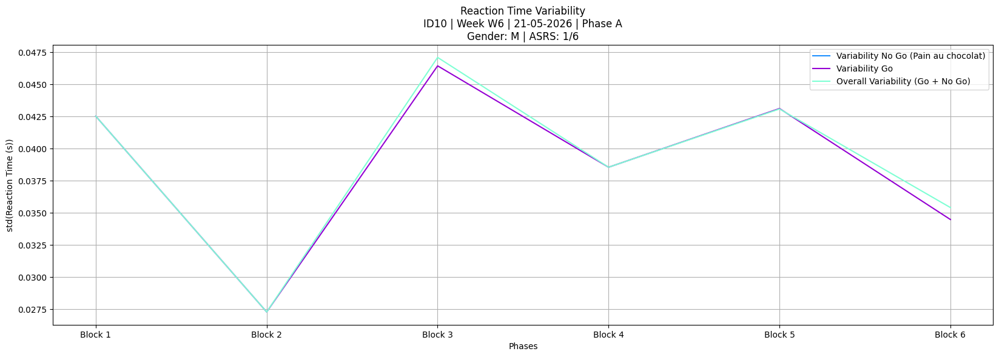

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,204.393733,No_Go,NaN,NaN,Correct,False,False,10
1,1,1,205.404770,Go,space,0.499841,Correct,False,False,10
2,1,2,206.421151,Go,space,0.467173,Correct,False,False,10
3,1,3,207.437747,Go,space,0.500454,Correct,False,False,10
4,1,4,208.454663,Go,space,0.501888,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,856.067261,Go,space,0.383122,Correct,False,False,10
536,6,536,857.085260,Go,space,0.381979,Correct,False,False,10
537,6,537,858.100639,Go,space,0.366662,Correct,False,False,10
538,6,538,859.117284,Go,space,0.366615,Correct,False,False,10


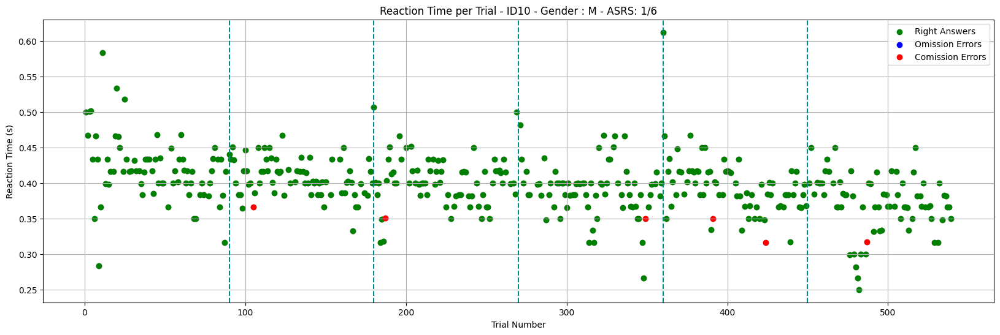

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 13.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=6.777951


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


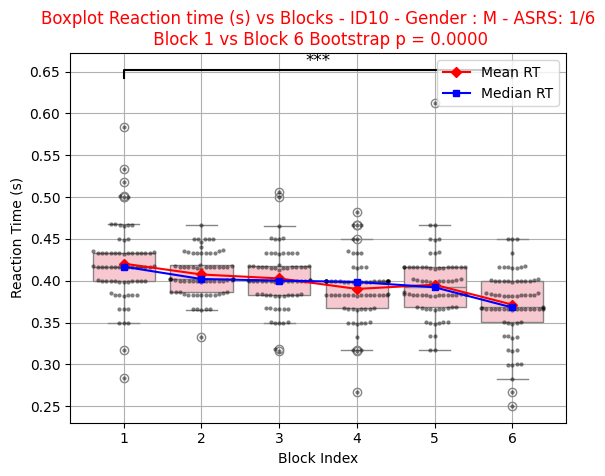

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

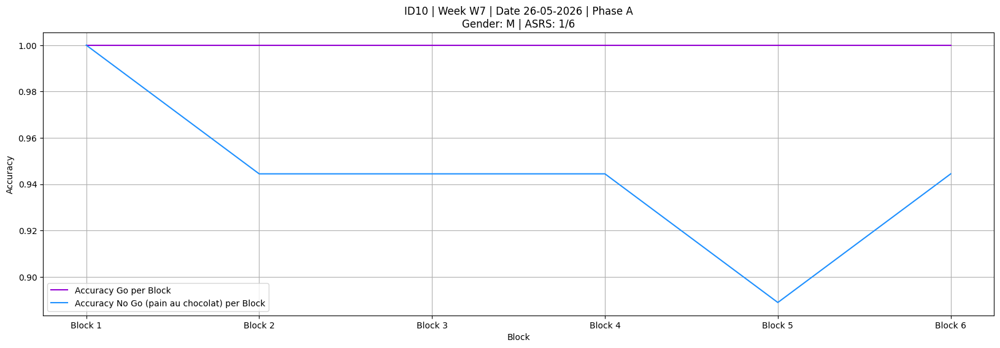

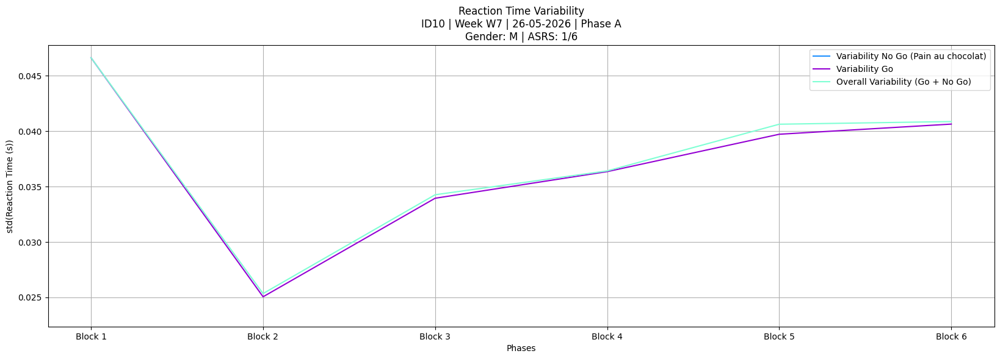

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,202.142399,Go,space,0.444448,Correct,False,False,10
1,1,1,203.170222,Go,space,0.433255,Correct,False,False,10
2,1,2,204.186784,Go,space,0.450104,Correct,False,False,10
3,1,3,205.203952,Go,space,0.399614,Correct,False,False,10
4,1,4,206.222522,No_Go,space,0.414195,Incorrect,False,True,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,851.890358,Go,space,0.415580,Correct,False,False,10
536,6,536,852.905693,Go,space,0.400097,Correct,False,False,10
537,6,537,853.923708,Go,space,0.415566,Correct,False,False,10
538,6,538,854.938986,Go,space,0.416636,Correct,False,False,10


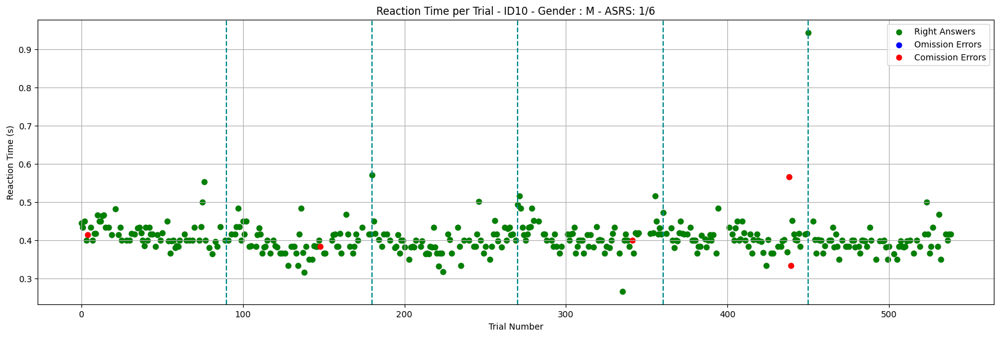

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 10.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 14.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=1.541610


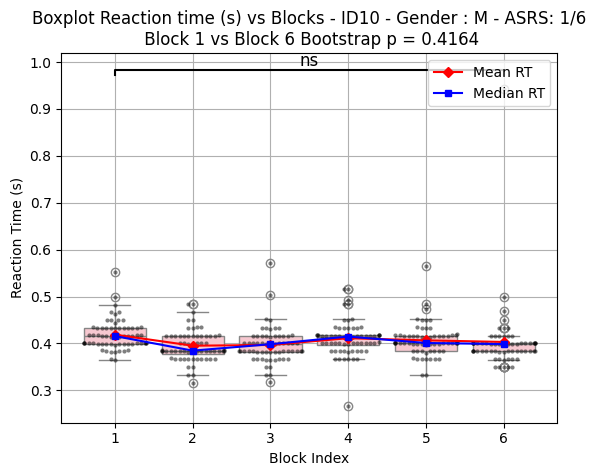

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9629629629629629},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9629629629629629},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9629629629629629},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9259259259259259},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

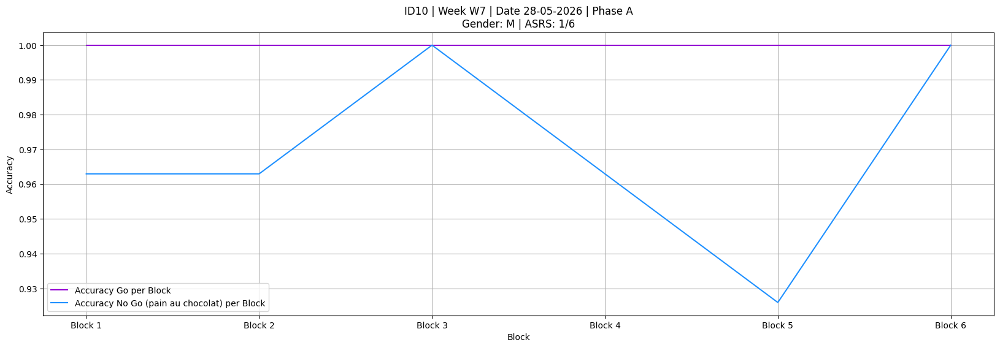

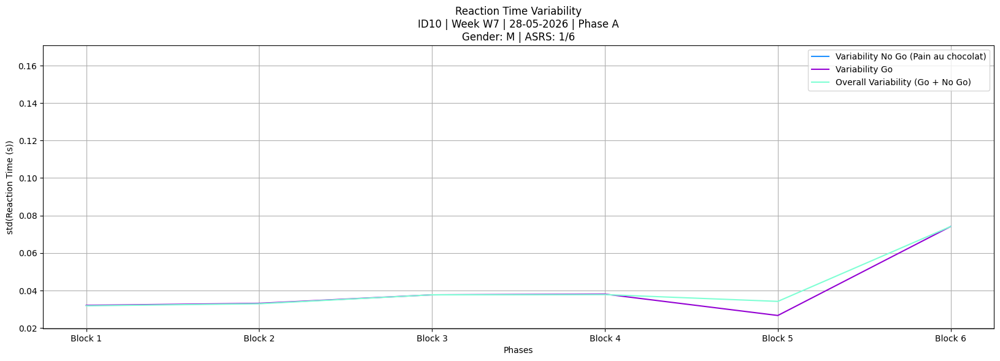

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,235.976966,Go,space,0.412219,Correct,False,False,10
1,1,1,237.005799,No_Go,space,0.383265,Incorrect,False,True,10
2,1,2,238.022330,Go,space,0.550290,Correct,False,False,10
3,1,3,239.039390,Go,space,0.366519,Correct,False,False,10
4,1,4,240.056952,Go,space,0.450491,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,886.428200,No_Go,NaN,NaN,Correct,False,False,10
536,6,536,887.446286,Go,space,0.381884,Correct,False,False,10
537,6,537,888.461591,Go,space,0.366545,Correct,False,False,10
538,6,538,889.479522,Go,space,0.398766,Correct,False,False,10


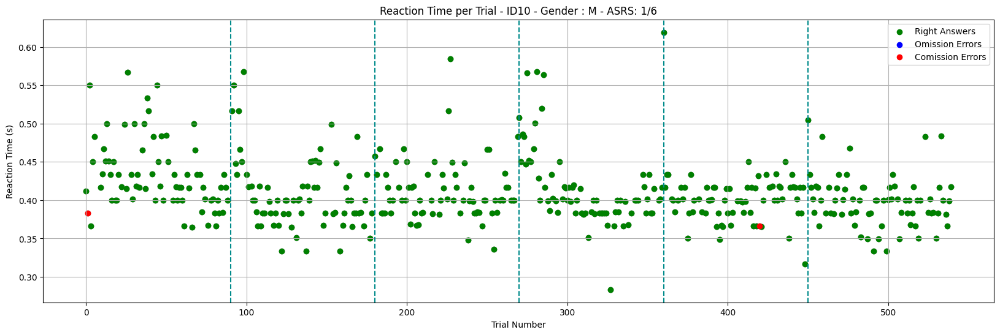

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 12.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=5.273936


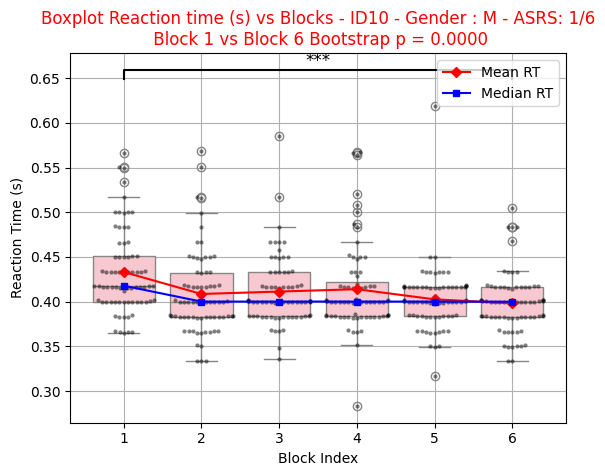

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

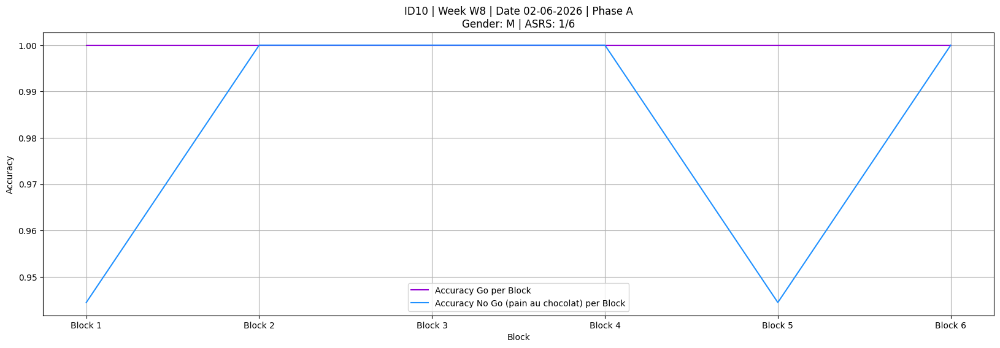

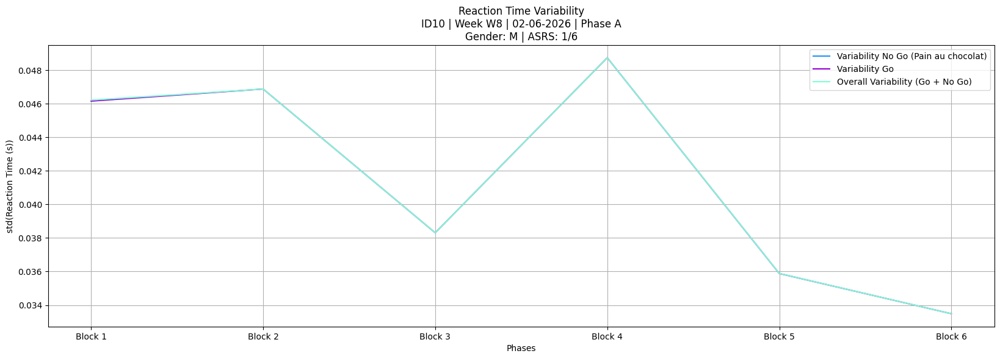

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,230.347620,Go,space,0.460581,Correct,False,False,10
1,1,1,231.358164,Go,space,0.433228,Correct,False,False,10
2,1,2,232.374944,Go,space,0.433040,Correct,False,False,10
3,1,3,233.391452,Go,space,0.433625,Correct,False,False,10
4,1,4,234.408245,No_Go,NaN,NaN,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,883.748647,No_Go,NaN,NaN,Correct,False,False,10
536,6,536,884.764520,Go,space,0.383462,Correct,False,False,10
537,6,537,885.781425,Go,space,0.399959,Correct,False,False,10
538,6,538,886.798508,Go,space,0.418335,Correct,False,False,10


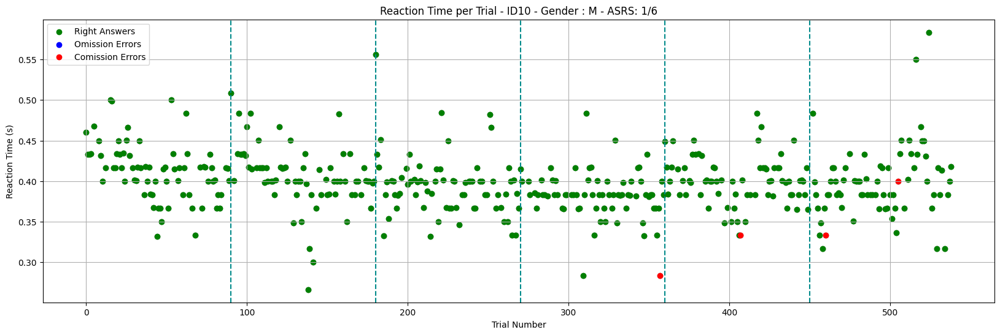

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 19.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=2.213438


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


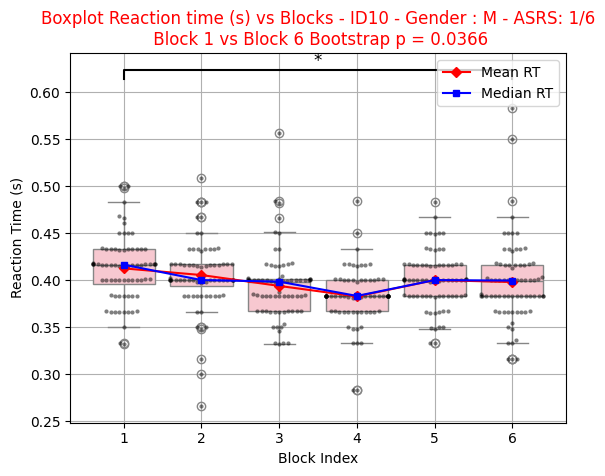

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

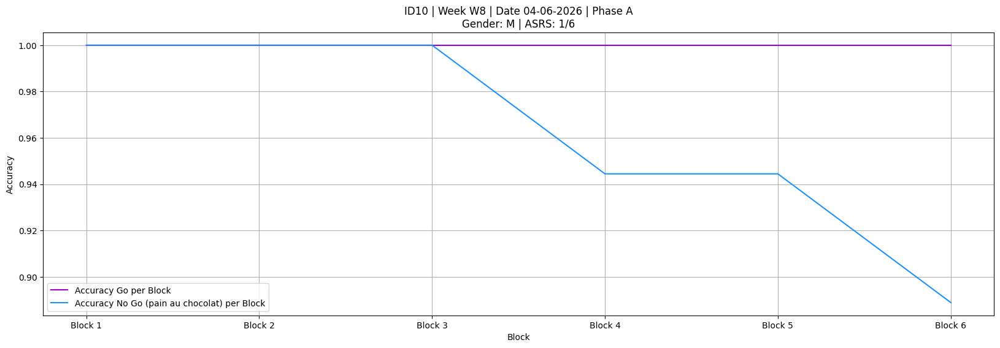

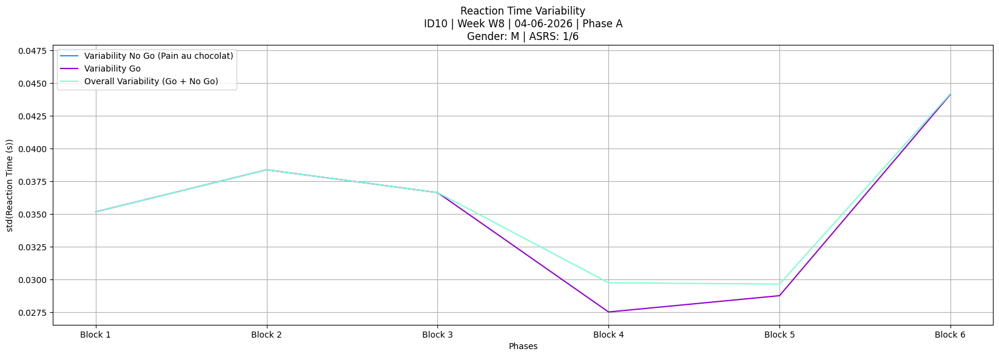

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,356.848686,Go,space,0.618172,Correct,False,False,10
1,1,1,357.863457,Go,space,0.401748,Correct,False,False,10
2,1,2,358.884831,Go,space,0.363601,Correct,False,False,10
3,1,3,359.899803,Go,space,0.402220,Correct,False,False,10
4,1,4,360.915412,Go,space,0.416357,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1036.942434,No_Go,NaN,NaN,Correct,False,False,10
536,6,536,1037.958423,Go,space,0.386518,Correct,False,False,10
537,6,537,1038.972243,Go,space,0.385658,Correct,False,False,10
538,6,538,1039.991061,Go,space,0.401708,Correct,False,False,10


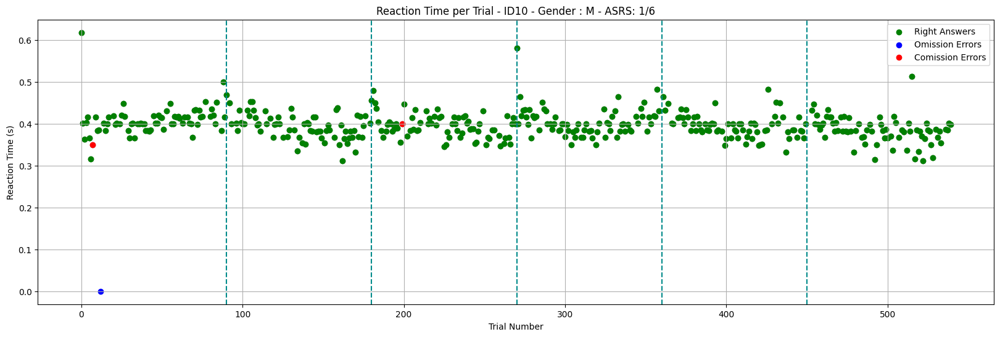

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 11.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=4.140351


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 12.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


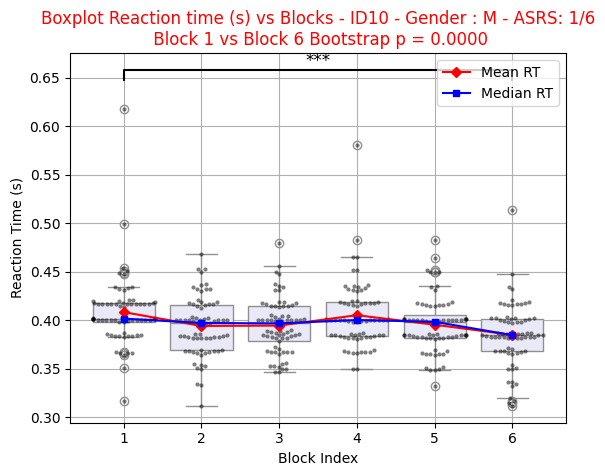

[{'Block': 'Block 1',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

SESSION DATE: 2026-06-05 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
11,2026-06-05,B,"20,30,12,20,30,12"


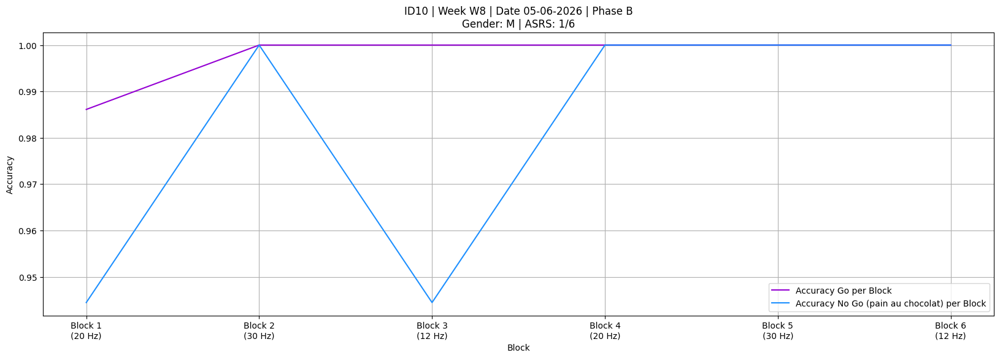

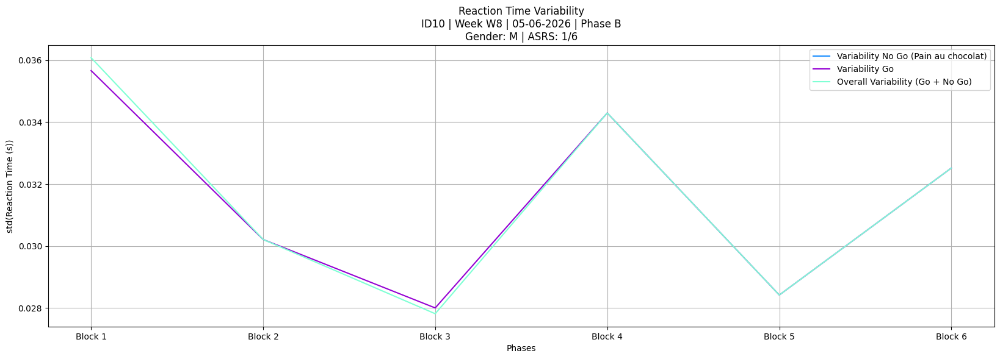

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,813.416664,Go,space,0.403513,Correct,False,False,10
1,1,1,814.420313,Go,space,0.416692,Correct,False,False,10
2,1,2,815.437092,Go,space,0.416800,Correct,False,False,10
3,1,3,816.453752,Go,space,0.383462,Correct,False,False,10
4,1,4,817.470620,No_Go,NaN,NaN,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1465.010990,Go,space,0.400781,Correct,False,False,10
536,6,536,1466.027630,No_Go,NaN,NaN,Correct,False,False,10
537,6,537,1467.044241,Go,space,0.400124,Correct,False,False,10
538,6,538,1468.061518,Go,space,0.350173,Correct,False,False,10


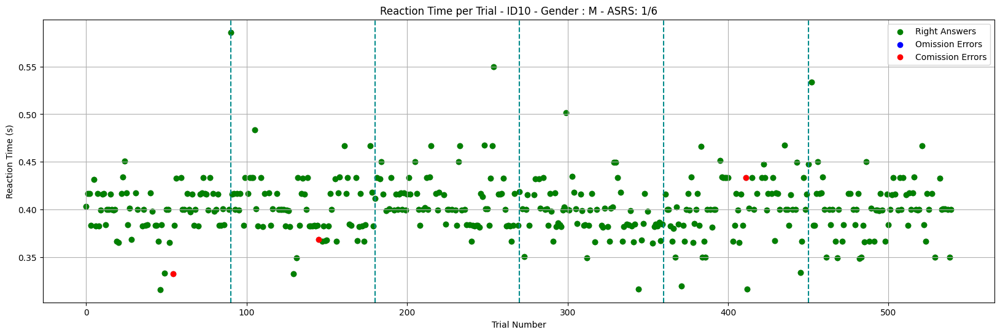

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 15.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 12.5% of the points cannot be placed;

t=-0.713645


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 11.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


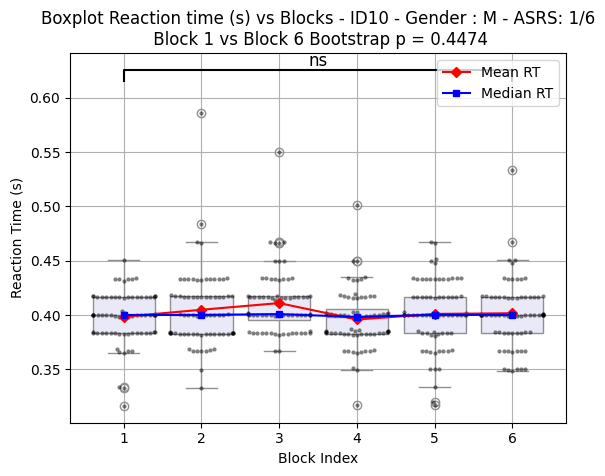

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

SESSION DATE: 2026-06-08 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
12,2026-06-08,B,"20,30,12,12,30,20"


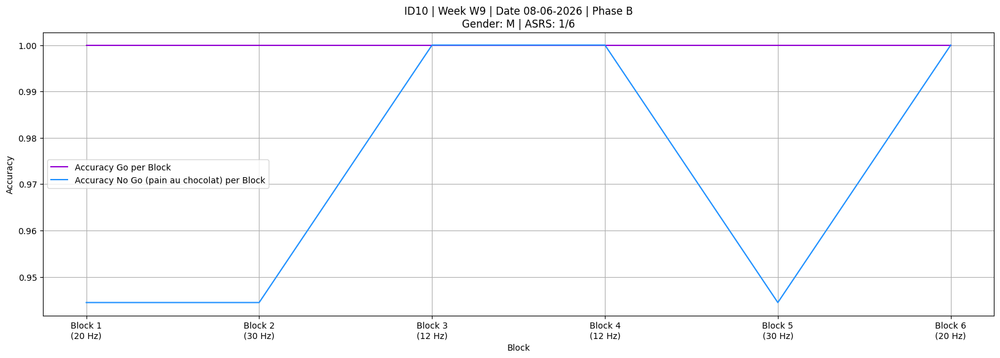

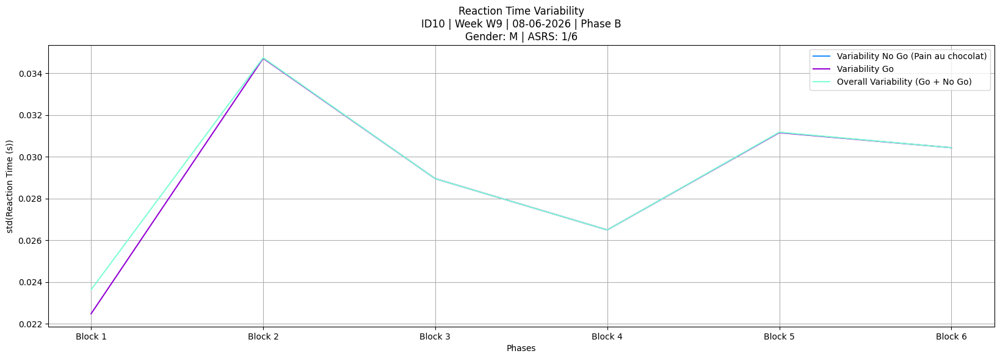

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,323.606908,No_Go,NaN,NaN,Correct,False,False,10
1,1,1,324.617472,Go,space,0.453134,Correct,False,False,10
2,1,2,325.636128,No_Go,NaN,NaN,Correct,False,False,10
3,1,3,326.651011,No_Go,NaN,NaN,Correct,False,False,10
4,1,4,327.669121,No_Go,NaN,NaN,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,975.839255,No_Go,NaN,NaN,Correct,False,False,10
536,6,536,976.856615,No_Go,NaN,NaN,Correct,False,False,10
537,6,537,977.872853,Go,space,0.416538,Correct,False,False,10
538,6,538,978.889240,Go,space,0.433580,Correct,False,False,10


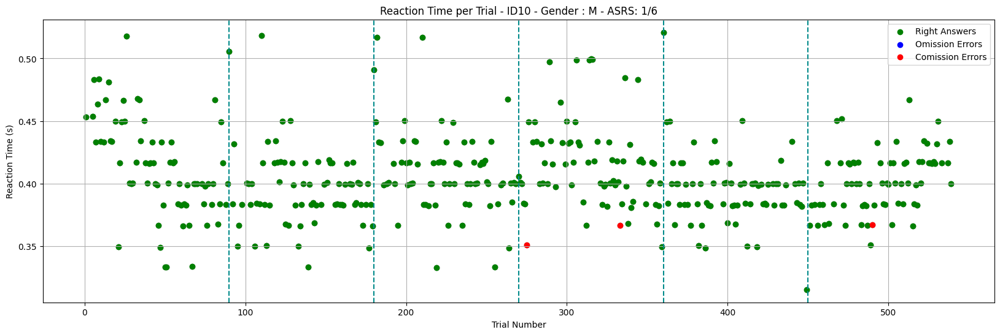

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 11.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 22.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=2.223734


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 12.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 25.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


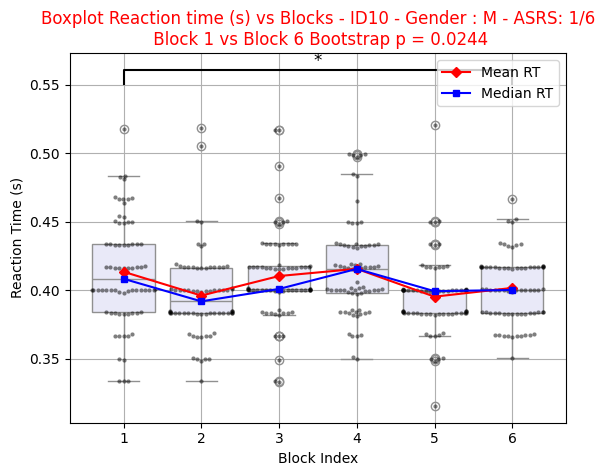

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

SESSION DATE: 2026-06-10 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
13,2026-06-10,B,"20,30,12,12,20,30"


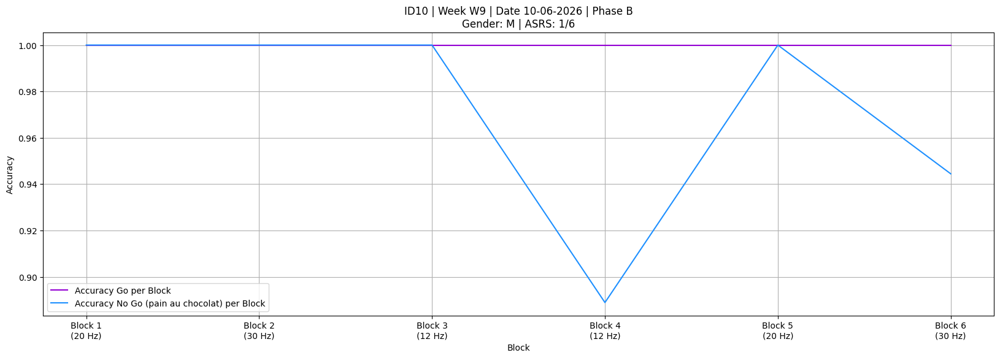

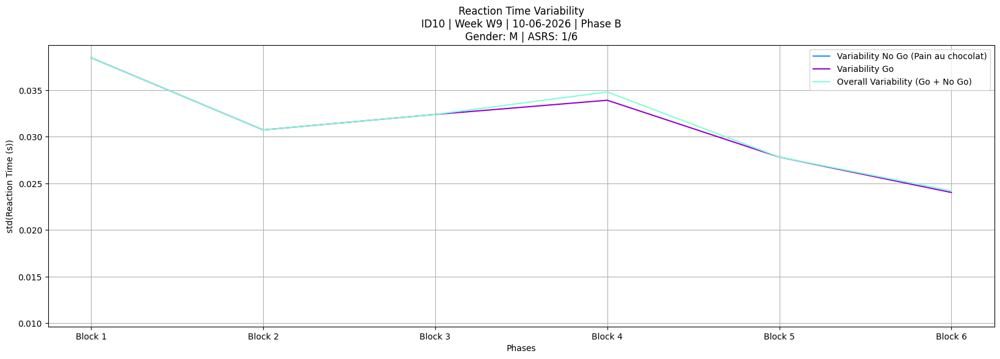

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,579.981029,Go,space,0.525584,Correct,False,False,10
1,1,1,580.989179,Go,space,0.467237,Correct,False,False,10
2,1,2,582.005247,No_Go,NaN,NaN,Correct,False,False,10
3,1,3,583.021584,Go,space,0.433305,Correct,False,False,10
4,1,4,584.038089,Go,space,0.416867,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1234.922996,Go,space,0.433065,Correct,False,False,10
536,6,536,1235.939503,Go,space,0.416605,Correct,False,False,10
537,6,537,1236.956728,Go,space,0.399117,Correct,False,False,10
538,6,538,1237.972765,Go,space,0.383017,Correct,False,False,10


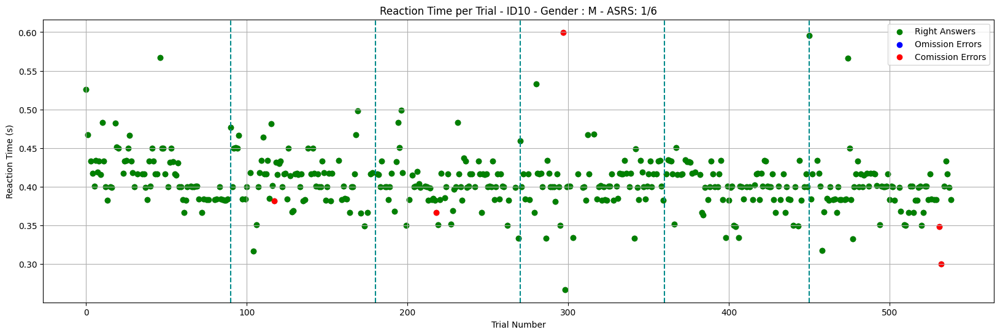

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 13.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 16.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 16.2% of the points cannot be placed

t=3.422406


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 15.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


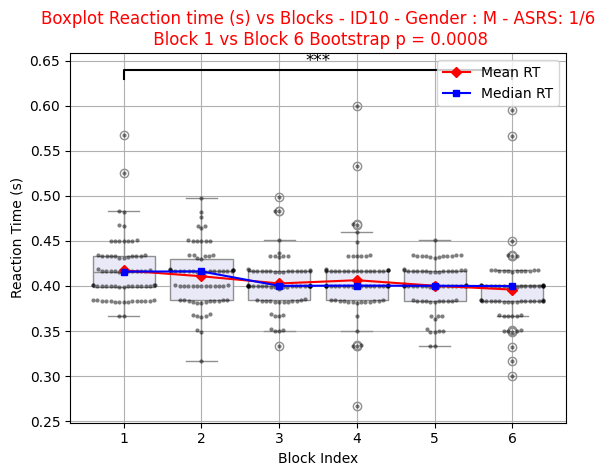

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

SESSION DATE: 2026-06-12 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
14,2026-06-12,B,"20,30,12,12,20,30"


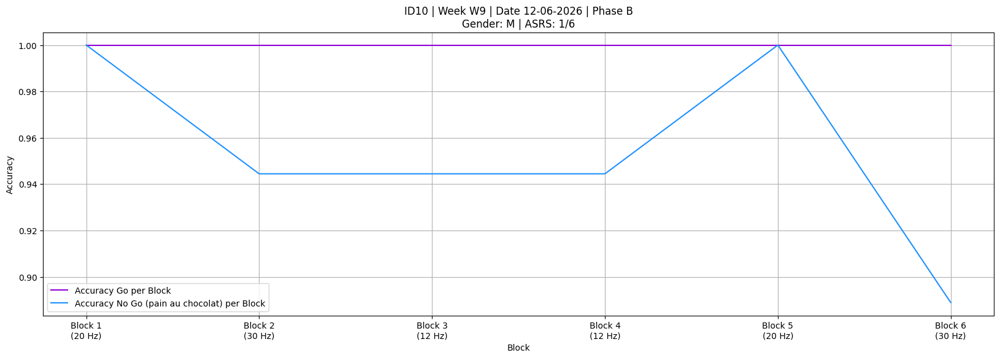

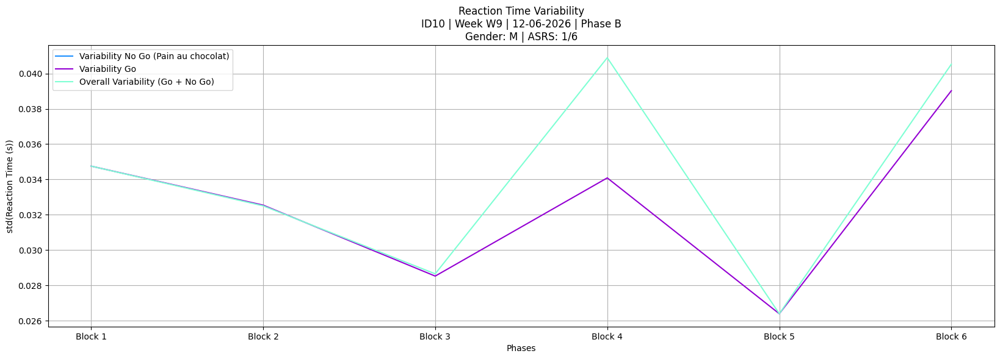

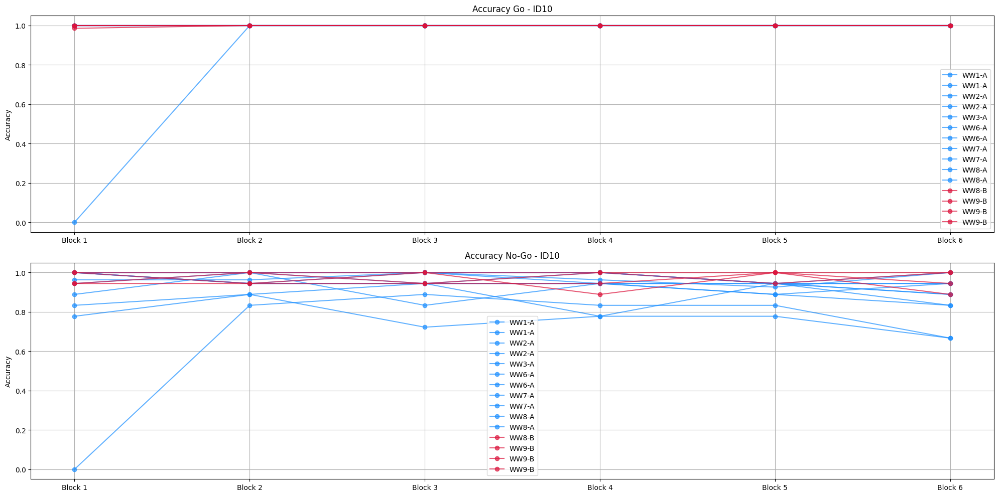

,DATE,PHASE,Go_12,Go_20,Go_30,NoGo_12,NoGo_20,NoGo_30,MeanGo,MeanNoGo
0,2026-04-13,A,0.833333,0.833333,0.833333,0.675926,0.675926,0.675926,NaN,NaN
1,2026-04-16,A,1.000000,1.000000,1.000000,0.805556,0.805556,0.805556,NaN,NaN
2,2026-04-22,A,1.000000,1.000000,1.000000,0.833333,0.833333,0.833333,NaN,NaN
3,2026-04-24,A,1.000000,1.000000,1.000000,0.898148,0.898148,0.898148,NaN,NaN
4,2026-04-27,A,1.000000,1.000000,1.000000,0.972222,0.972222,0.972222,NaN,NaN
5,2026-05-18,A,1.000000,1.000000,1.000000,0.944444,0.944444,0.944444,NaN,NaN
6,2026-05-21,A,1.000000,1.000000,1.000000,0.972222,0.972222,0.972222,NaN,NaN
7,2026-05-26,A,1.000000,1.000000,1.000000,0.944444,0.944444,0.944444,NaN,NaN
8,2026-05-28,A,1.000000,1.000000,1.000000,0.969136,0.969136,0.969136,NaN,NaN
9,2026-06-02,A,1.000000,1.000000,1.000000,0.981481,0.981481,0.981481,NaN,NaN


t=-1.028992


/tmp/ipykernel_1316/346653522.py:91: RuntimeWarning: divide by zero encountered in scalar divide
  t_distrib[b] = (np.mean(draw_x)-np.mean(draw_y))/np.sqrt(np.var(draw_x)/n+np.var(draw_y)/m)


t=-4.122582
t=-0.373906
t=1.028992
t=-1.044466
t=0.969087
Go A-A   p = 0.1448
Go A-B   p = 0.1544
Go B-B   p = 0.1398
NoGo A-A p = 0.0000
NoGo A-B p = 0.7294
NoGo B-B p = 0.3292


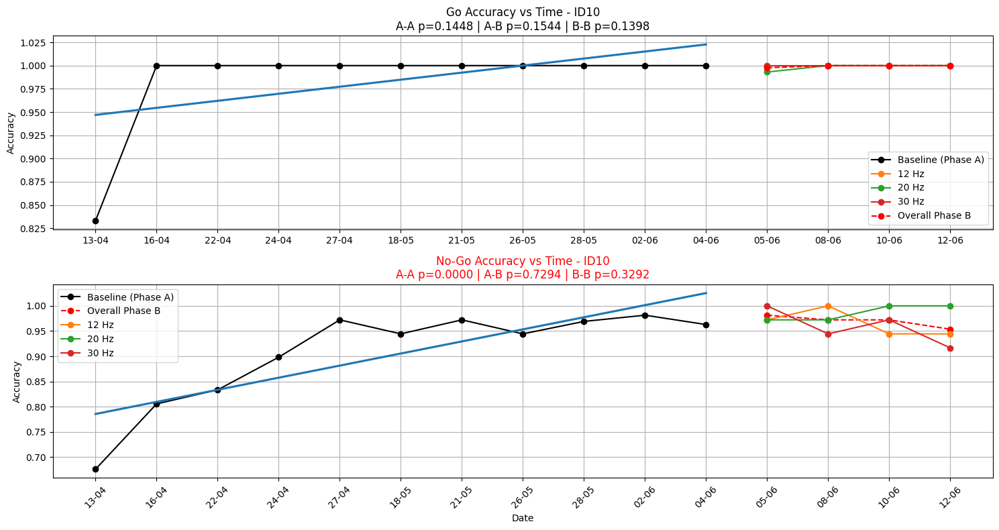

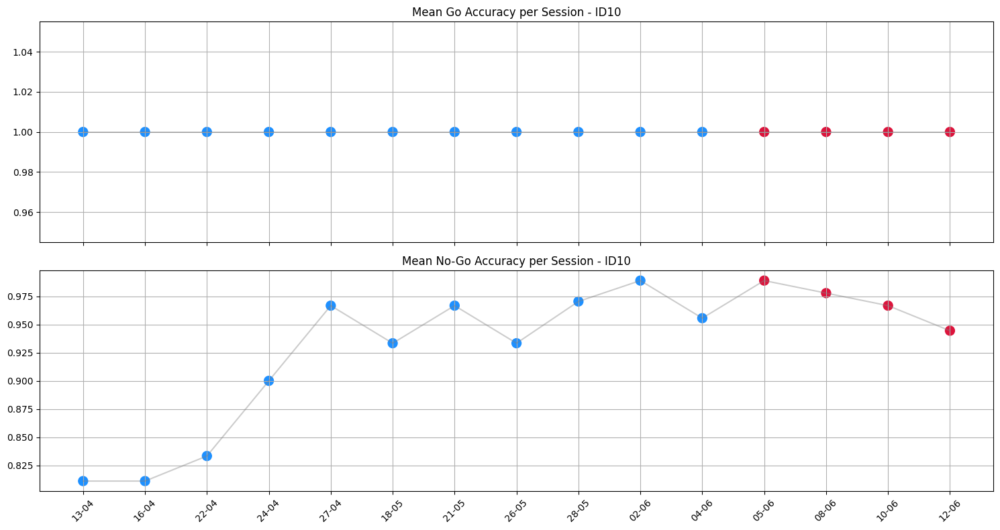

,DATE,Go_12,NoGo_12,Go_20,NoGo_20,Go_30,NoGo_30,MeanGo,MeanNoGo
0,2026-06-05,1.0,0.972222,0.993056,0.972222,1.0,1.000000,0.997685,0.981481
1,2026-06-08,1.0,1.000000,1.000000,0.972222,1.0,0.944444,1.000000,0.972222
2,2026-06-10,1.0,0.944444,1.000000,1.000000,1.0,0.972222,1.000000,0.972222
3,2026-06-12,1.0,0.944444,1.000000,1.000000,1.0,0.916667,1.000000,0.953704


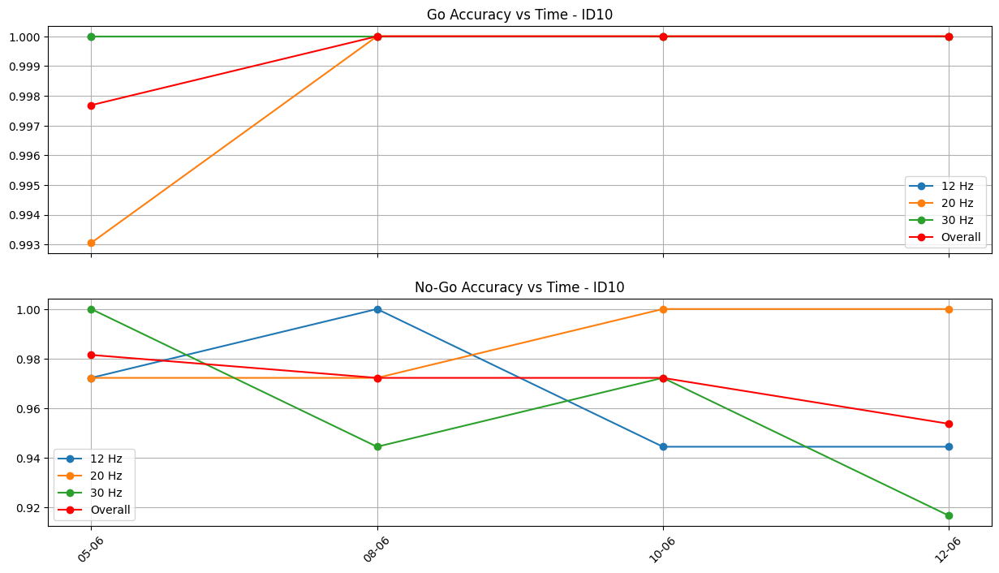

t=-4.023654
t=1.155446


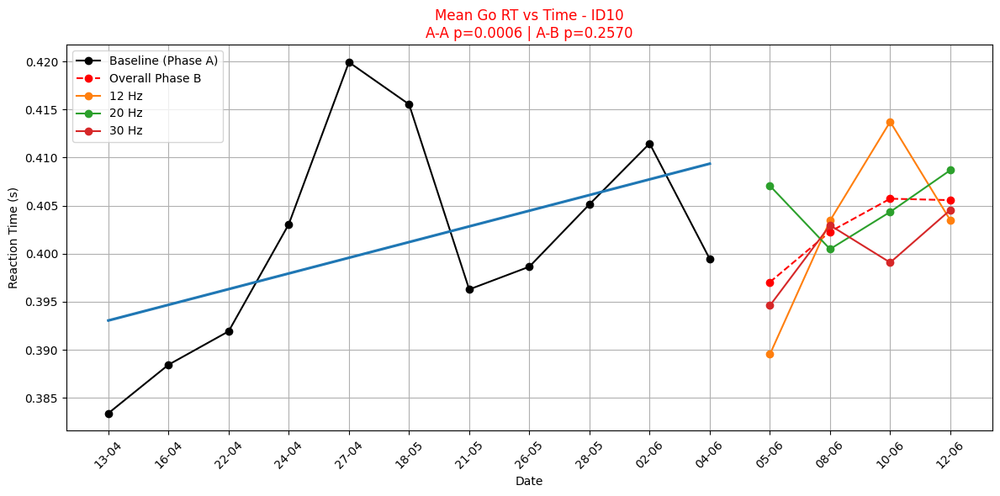

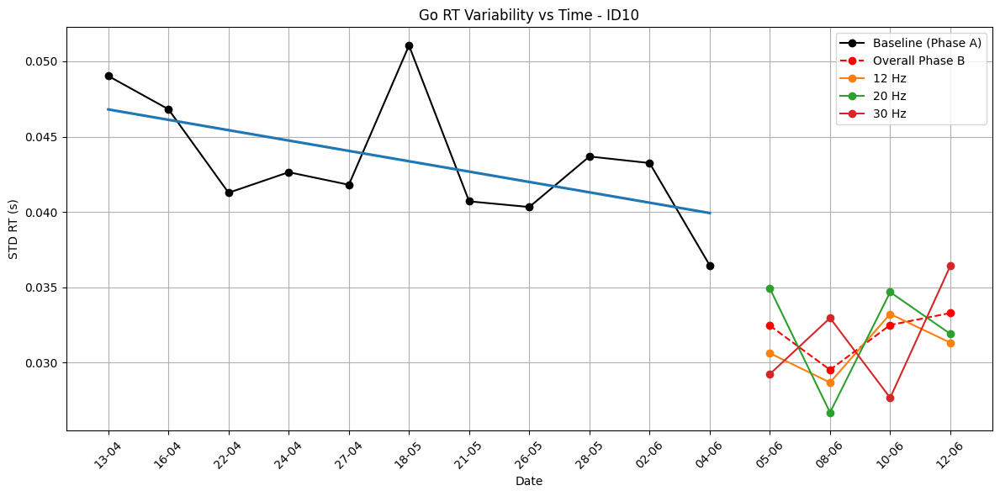

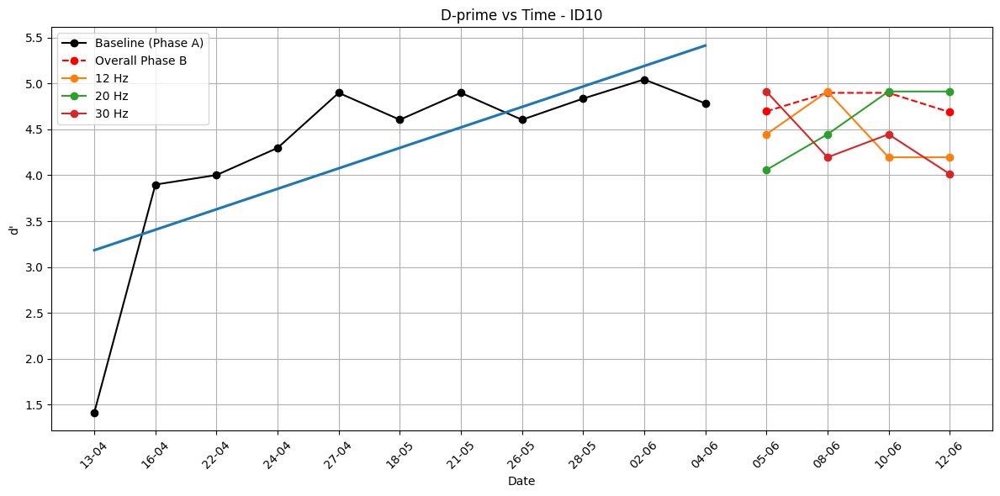

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-13,A,1/6,NaN,NaN,NaN,1.416196,1.0,0.811111,0.046907
1,2026-04-16,A,1/6,NaN,NaN,NaN,3.898742,1.0,0.811111,0.043866
2,2026-04-22,A,1/6,NaN,NaN,NaN,4.002502,1.0,0.833333,0.040205
3,2026-04-24,A,1/6,7.0,5.0,0.0,4.298044,1.0,0.900000,0.038790
4,2026-04-27,A,1/6,5.0,4.0,0.0,4.897896,1.0,0.966667,0.039245
5,2026-05-18,A,1/6,7.0,4.0,5.0,4.605110,1.0,0.933333,0.043121
6,2026-05-21,A,1/6,8.0,5.0,0.0,4.897896,1.0,0.966667,0.037966
7,2026-05-26,A,1/6,7.5,4.0,3.0,4.605110,1.0,0.933333,0.035132
8,2026-05-28,A,1/6,7.0,4.0,3.0,4.835418,1.0,0.970370,0.041928
9,2026-06-02,A,1/6,8.5,4.0,0.0,5.043822,1.0,0.988889,0.040656


/tmp/ipykernel_1316/1374344922.py:17: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(df["HRS_SLEEP"],df[metric], nan_policy = "omit")


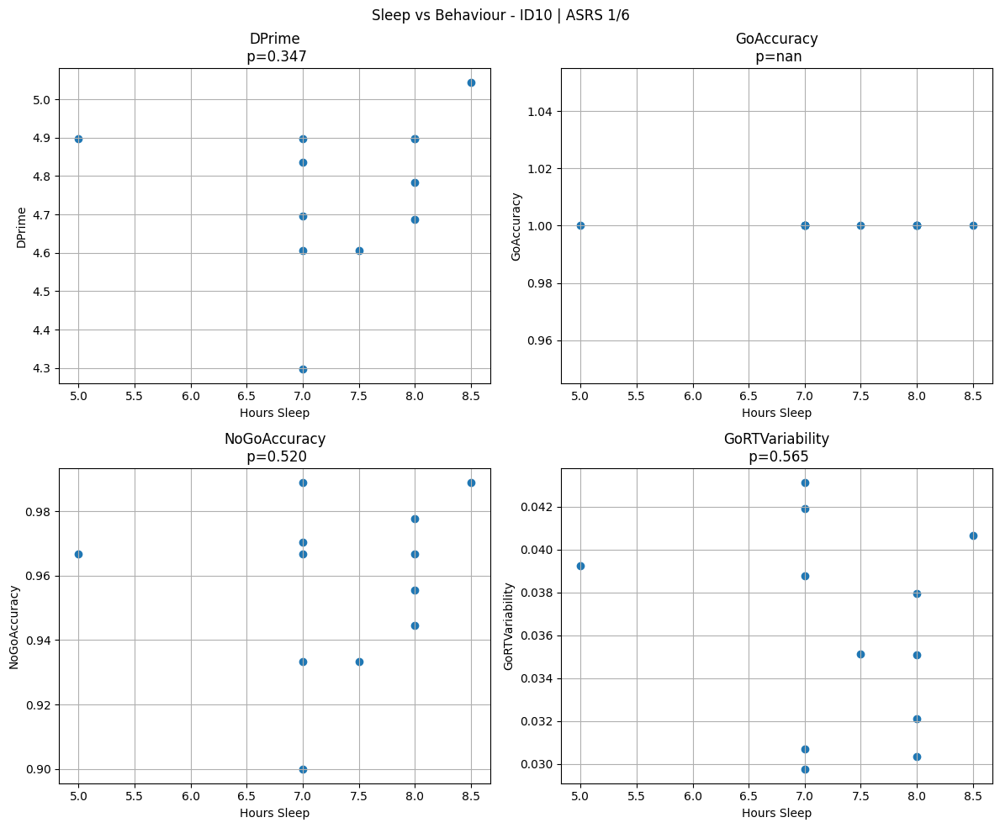

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-13,A,1/6,NaN,NaN,NaN,1.416196,1.0,0.811111,0.046907
1,2026-04-16,A,1/6,NaN,NaN,NaN,3.898742,1.0,0.811111,0.043866
2,2026-04-22,A,1/6,NaN,NaN,NaN,4.002502,1.0,0.833333,0.040205
3,2026-04-24,A,1/6,7.0,5.0,0.0,4.298044,1.0,0.900000,0.038790
4,2026-04-27,A,1/6,5.0,4.0,0.0,4.897896,1.0,0.966667,0.039245
5,2026-05-18,A,1/6,7.0,4.0,5.0,4.605110,1.0,0.933333,0.043121
6,2026-05-21,A,1/6,8.0,5.0,0.0,4.897896,1.0,0.966667,0.037966
7,2026-05-26,A,1/6,7.5,4.0,3.0,4.605110,1.0,0.933333,0.035132
8,2026-05-28,A,1/6,7.0,4.0,3.0,4.835418,1.0,0.970370,0.041928
9,2026-06-02,A,1/6,8.5,4.0,0.0,5.043822,1.0,0.988889,0.040656


/tmp/ipykernel_1316/2580976326.py:19: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(df["MOOD"],df[metric])


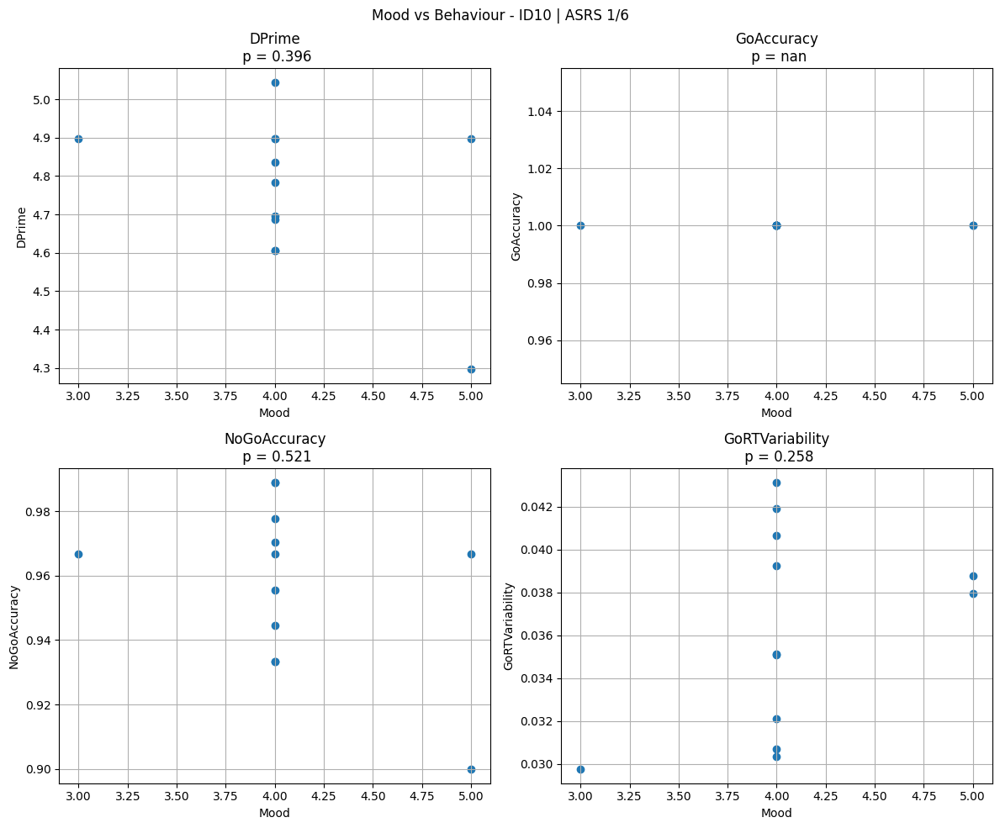

,Metric,n_A,n_B,Mean_A,Mean_B,Observed_Diff,NAP,TauU,Permutation_p
0,DPrime,11,4,4.298541,4.795076,0.496534,0.681818,0.363636,0.1396
1,Variability_Go,11,4,0.040638,0.031083,0.009555,1.000000,1.000000,0.0000
2,Accuracy_NoGo,11,4,0.905443,0.969907,0.064464,0.761364,0.522727,0.0563


In [647]:
df_id10 = pipeline(10)
sced_df = sced_metrics(df_id10)
display(sced_df)

#**RESULTS**

#**ID6**

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,402.840200,Go,space,0.823969,Correct,False,False,6
1,1,1,403.864159,Go,space,0.416709,Correct,False,False,6
2,1,2,404.880699,No_Go,space,0.333501,Incorrect,False,True,6
3,1,3,405.897801,Go,space,0.316254,Correct,False,False,6
4,1,4,406.914069,Go,space,0.368002,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1055.292639,Go,space,0.516893,Correct,False,False,6
536,6,536,1056.310719,Go,space,0.665414,Correct,False,False,6
537,6,537,1057.326103,No_Go,NaN,NaN,Correct,False,False,6
538,6,538,1058.342952,Go,space,0.533065,Correct,False,False,6


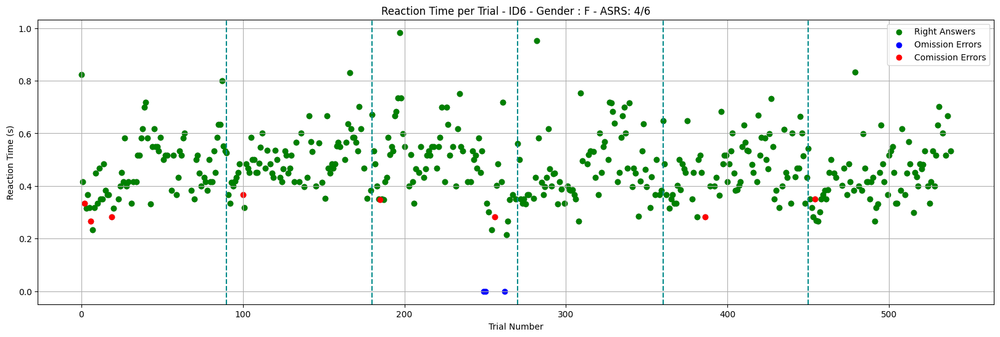

t=1.366095


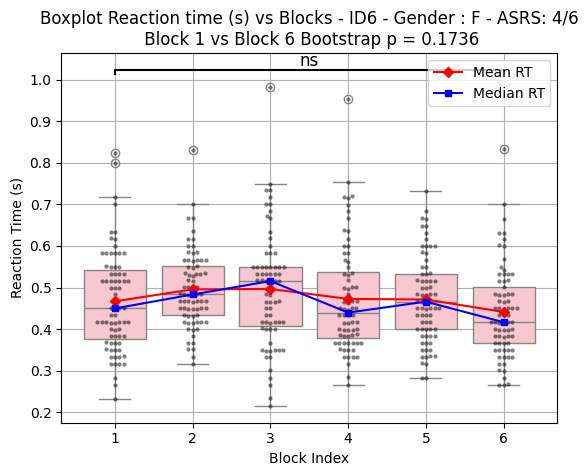

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 0.9583333333333334,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

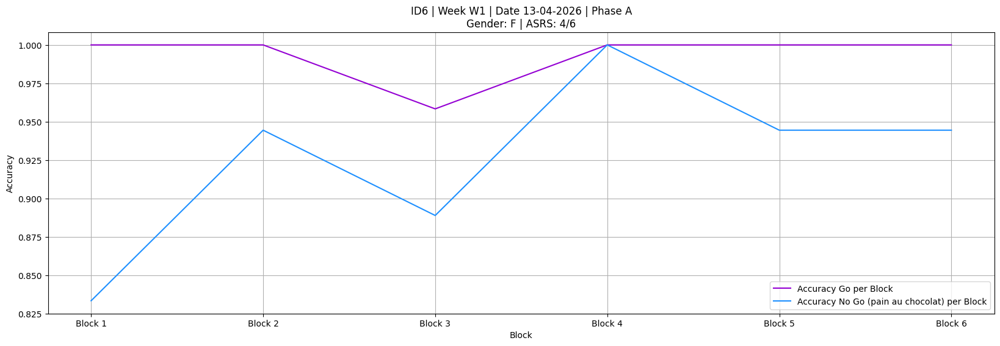

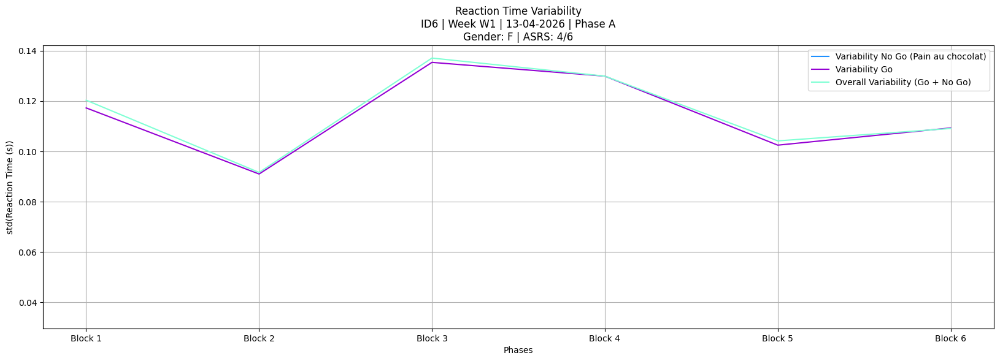

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,363.030833,Go,space,0.518396,Correct,False,False,6
1,1,1,364.049294,Go,space,0.466610,Correct,False,False,6
2,1,2,365.065816,No_Go,NaN,NaN,Correct,False,False,6
3,1,3,366.083182,Go,space,0.482889,Correct,False,False,6
4,1,4,367.099856,Go,space,0.533103,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1017.088975,Go,space,0.349952,Correct,False,False,6
536,6,536,1018.105656,Go,space,0.417028,Correct,False,False,6
537,6,537,1019.122511,Go,space,0.435145,Correct,False,False,6
538,6,538,1020.138866,Go,space,0.416529,Correct,False,False,6


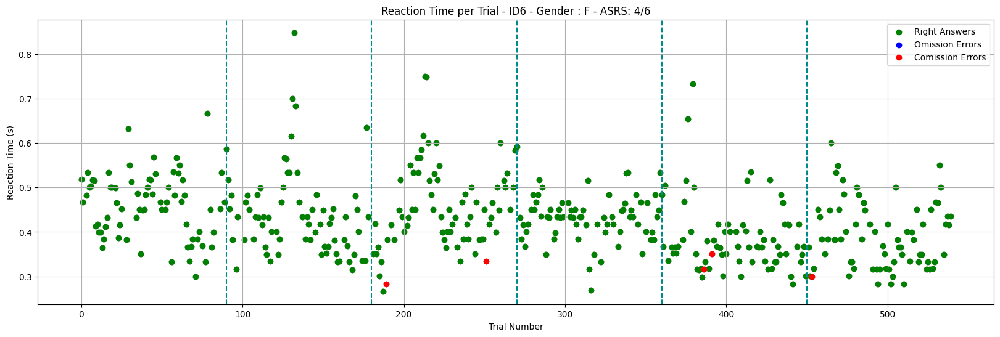

t=5.760384


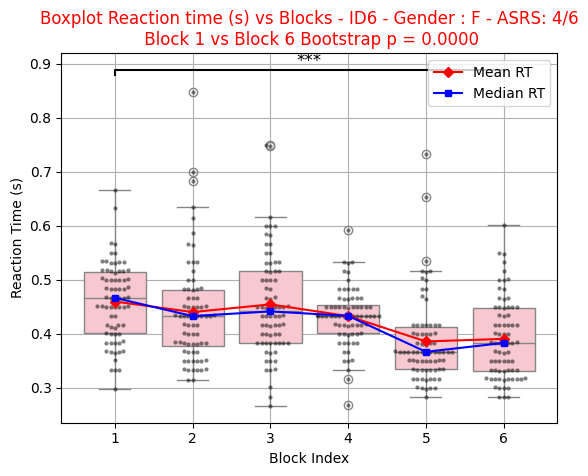

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

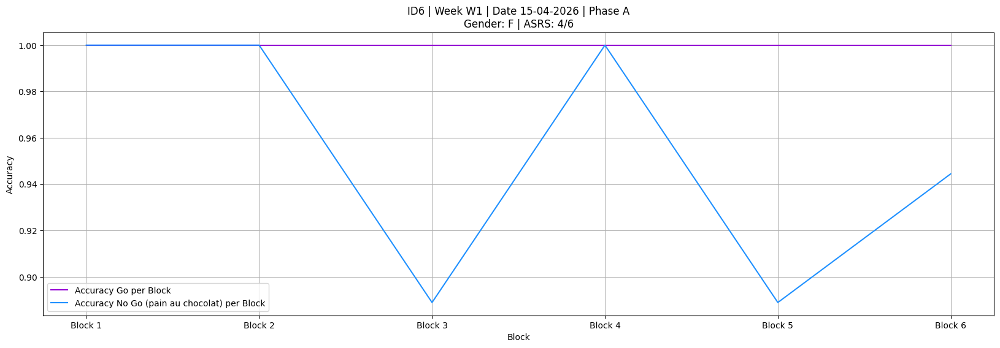

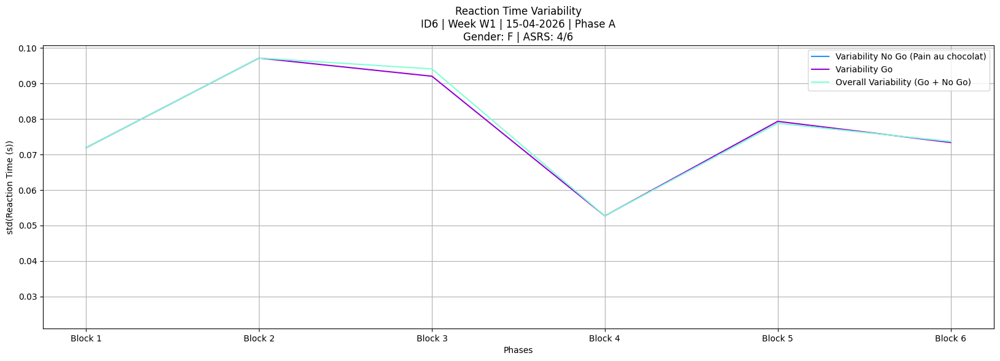

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,252.659066,Go,space,0.727354,Correct,False,False,6
1,1,1,253.636425,Go,space,0.516563,Correct,False,False,6
2,1,2,254.619867,No_Go,NaN,NaN,Correct,False,False,6
3,1,3,255.604465,Go,space,0.350047,Correct,False,False,6
4,1,4,256.586345,Go,space,0.433508,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,885.859136,No_Go,NaN,NaN,Correct,False,False,6
536,6,536,886.843594,No_Go,NaN,NaN,Correct,False,False,6
537,6,537,887.825801,Go,space,0.399936,Correct,False,False,6
538,6,538,888.810486,Go,space,0.398866,Correct,False,False,6


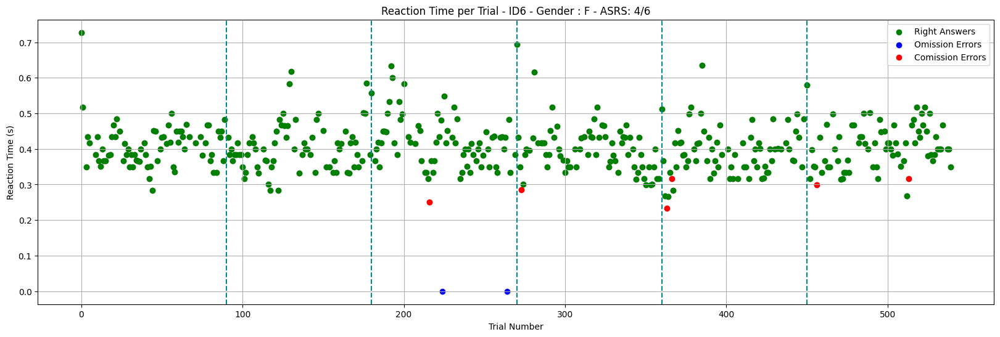

t=0.263849


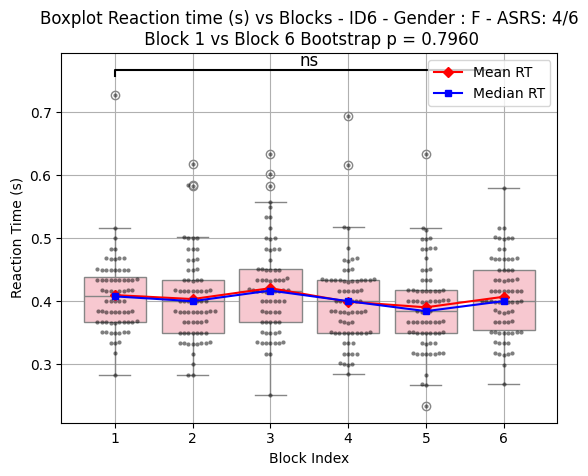

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3',
  'Accuracy Go': 0.9722222222222222,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

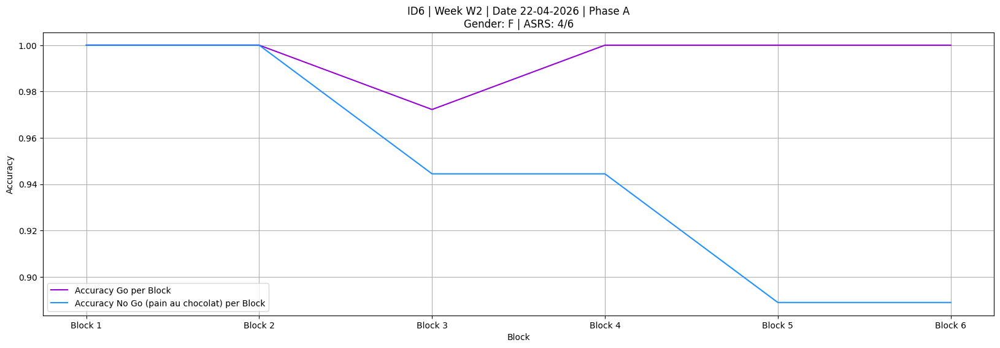

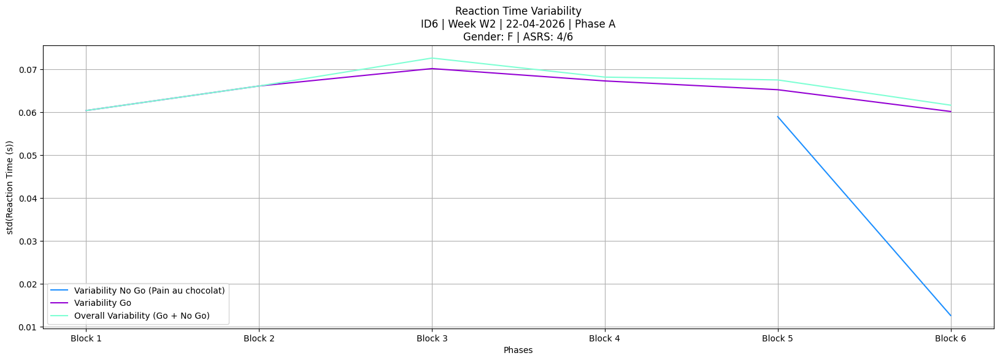

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,15.811564,Go,NaN,NaN,Incorrect,True,False,6
1,1,1,16.831659,No_Go,space,0.216703,Incorrect,False,True,6
2,1,2,17.849186,Go,space,0.315535,Correct,False,False,6
3,1,3,18.864730,Go,space,0.350044,Correct,False,False,6
4,1,4,19.882531,Go,space,0.333265,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,672.983334,Go,space,0.366525,Correct,False,False,6
536,6,536,674.002358,Go,space,0.381191,Correct,False,False,6
537,6,537,675.016708,Go,space,0.450149,Correct,False,False,6
538,6,538,676.034142,Go,space,0.351619,Correct,False,False,6


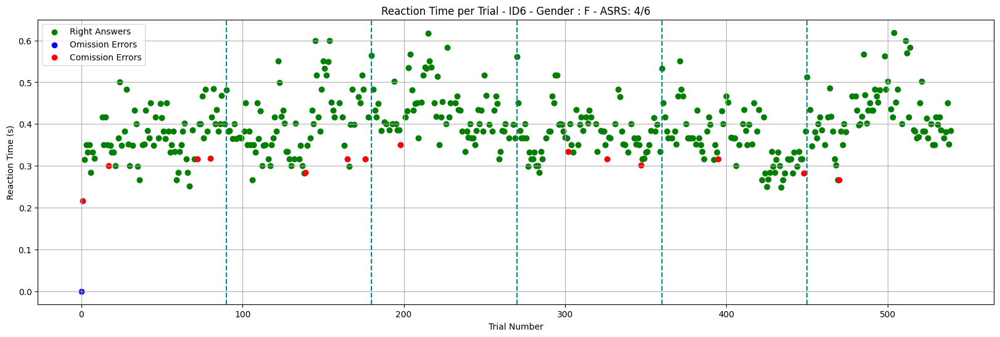

t=-5.168689


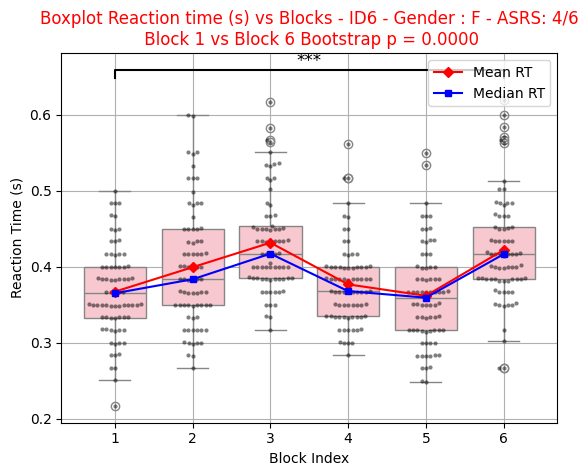

[{'Block': 'Block 1',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

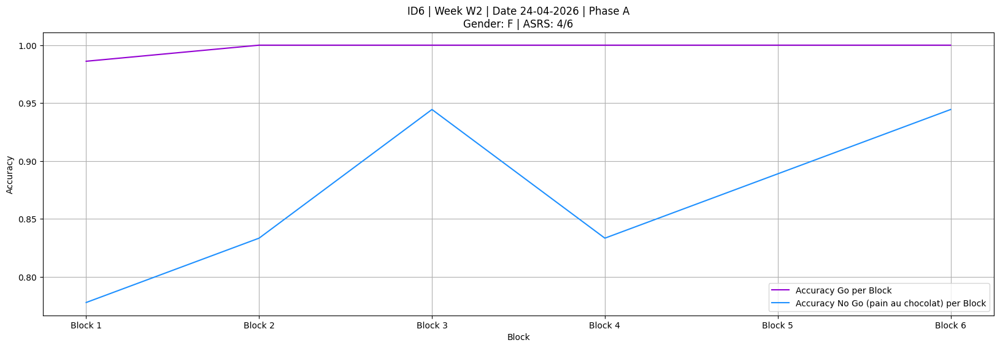

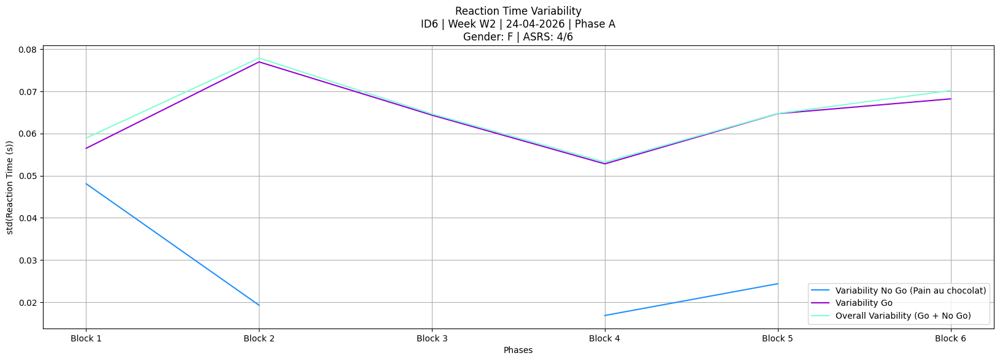

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,26.056760,Go,space,0.515049,Correct,False,False,6
1,1,1,27.071313,Go,space,0.366333,Correct,False,False,6
2,1,2,28.086935,Go,space,0.333366,Correct,False,False,6
3,1,3,29.103026,No_Go,NaN,NaN,Correct,False,False,6
4,1,4,30.119928,Go,space,0.349707,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,680.491841,Go,space,0.299828,Correct,False,False,6
536,6,536,681.507663,Go,space,0.333094,Correct,False,False,6
537,6,537,682.523489,Go,space,0.333065,Correct,False,False,6
538,6,538,683.539088,No_Go,NaN,NaN,Correct,False,False,6


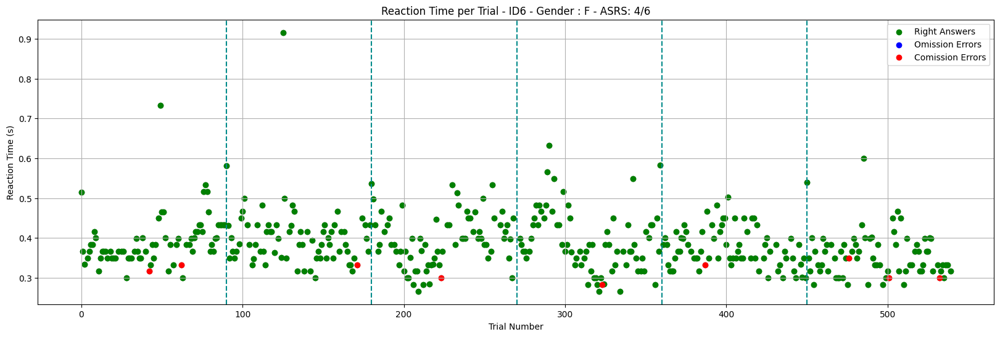

t=3.611030


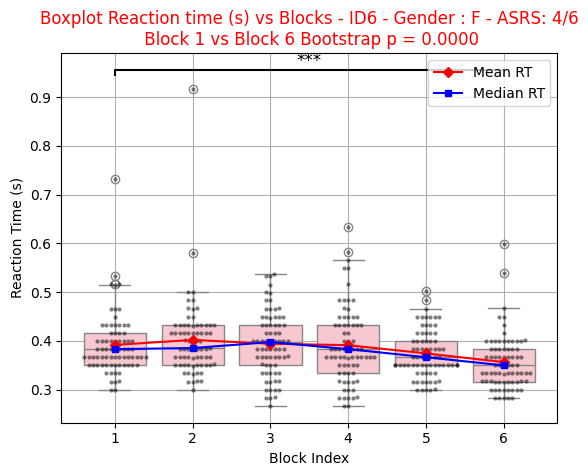

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334}]

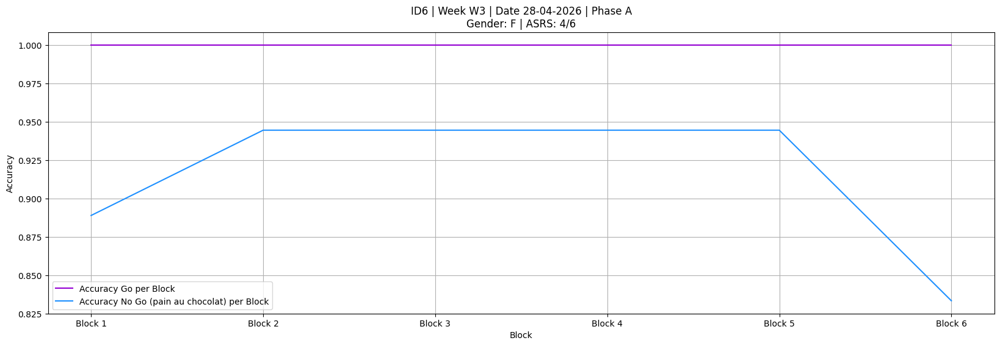

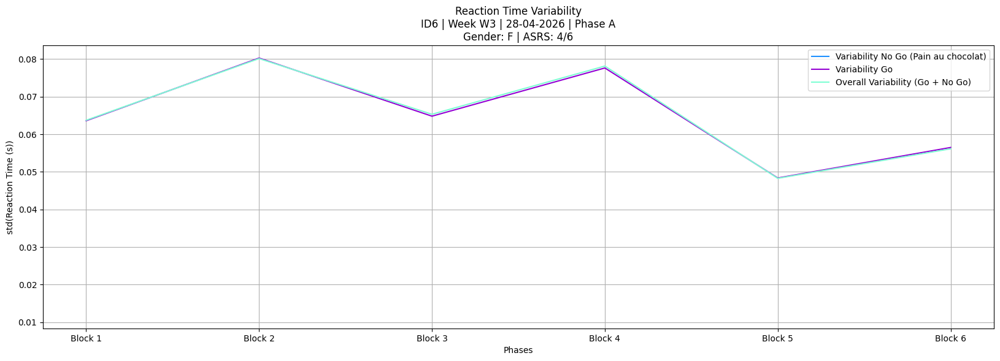

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,33.115609,Go,space,0.441387,Correct,False,False,6
1,1,1,34.122955,Go,space,0.433026,Correct,False,False,6
2,1,2,35.105302,No_Go,NaN,NaN,Correct,False,False,6
3,1,3,36.090023,Go,space,0.416164,Correct,False,False,6
4,1,4,37.070631,No_Go,NaN,NaN,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,668.271148,Go,space,0.399600,Correct,False,False,6
536,6,536,669.253309,No_Go,NaN,NaN,Correct,False,False,6
537,6,537,670.235819,Go,space,0.449686,Correct,False,False,6
538,6,538,671.218274,Go,space,0.449545,Correct,False,False,6


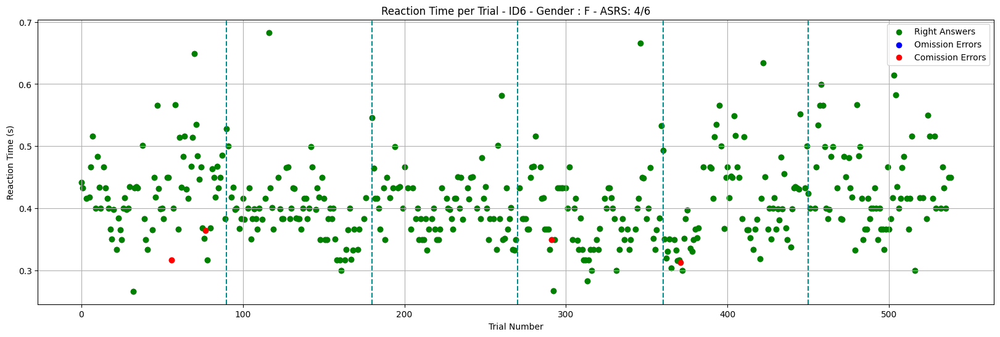

t=-0.894554


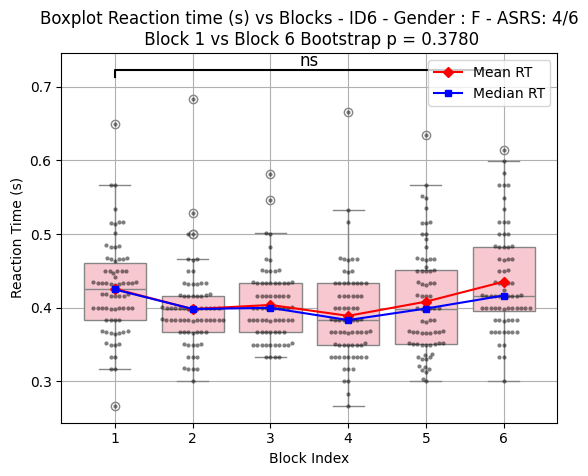

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

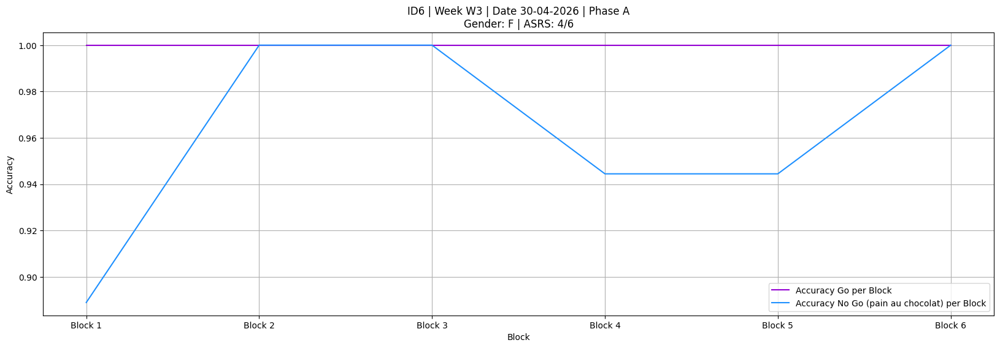

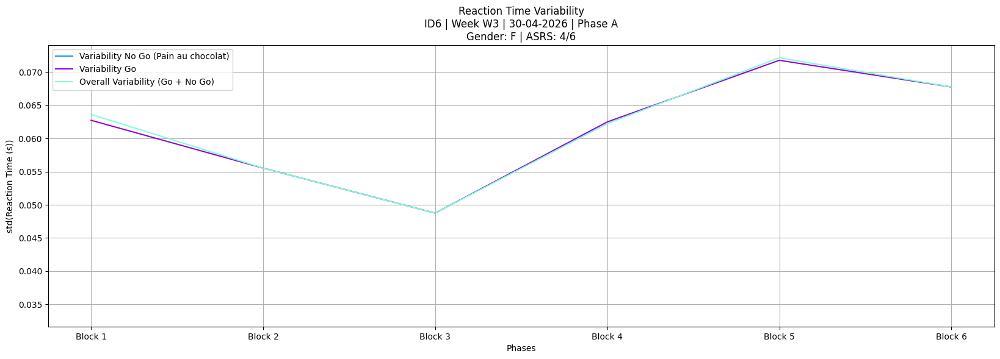

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,25.540388,No_Go,NaN,NaN,Correct,False,False,6
1,1,1,26.556784,Go,space,0.366277,Correct,False,False,6
2,1,2,27.572526,Go,space,0.449639,Correct,False,False,6
3,1,3,28.588272,Go,space,0.466114,Correct,False,False,6
4,1,4,29.603842,Go,space,0.499686,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,679.792564,Go,space,0.383184,Correct,False,False,6
536,6,536,680.808390,Go,space,0.349621,Correct,False,False,6
537,6,537,681.824260,No_Go,NaN,NaN,Correct,False,False,6
538,6,538,682.839823,Go,space,0.399721,Correct,False,False,6


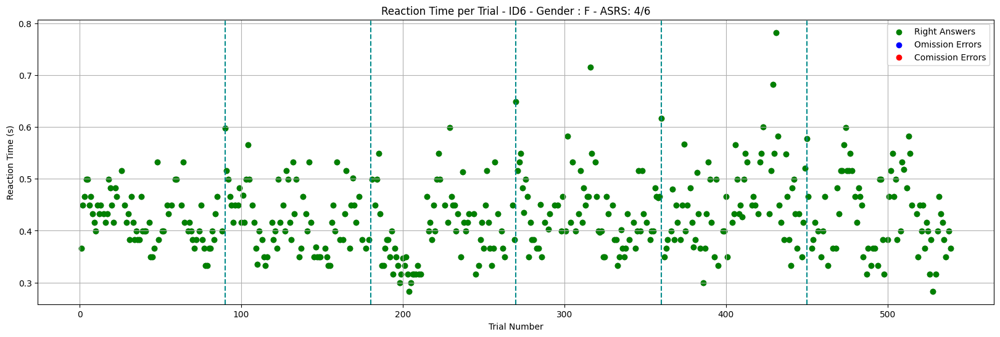

t=-0.747381


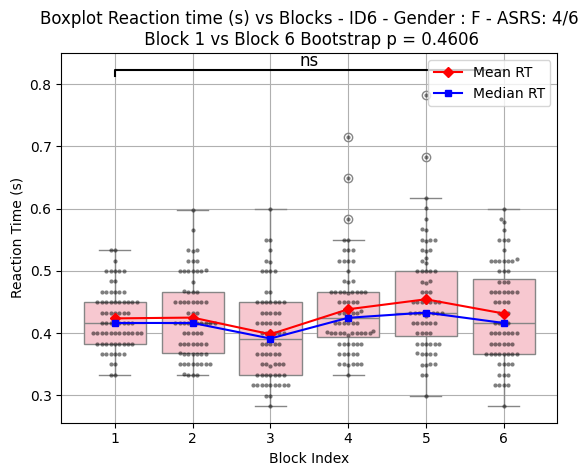

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

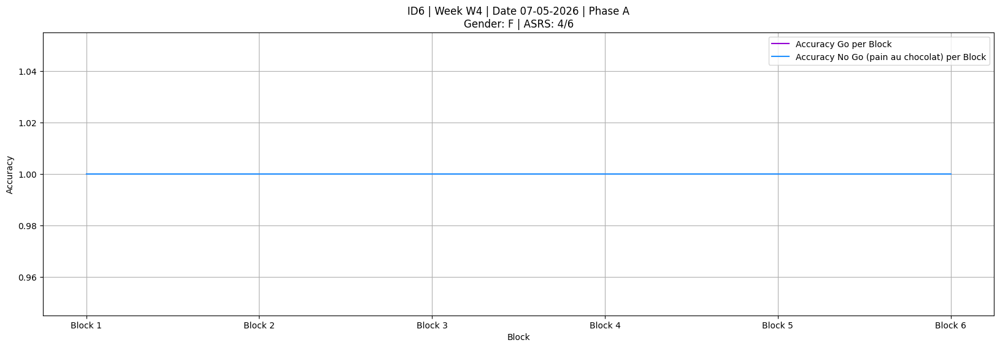

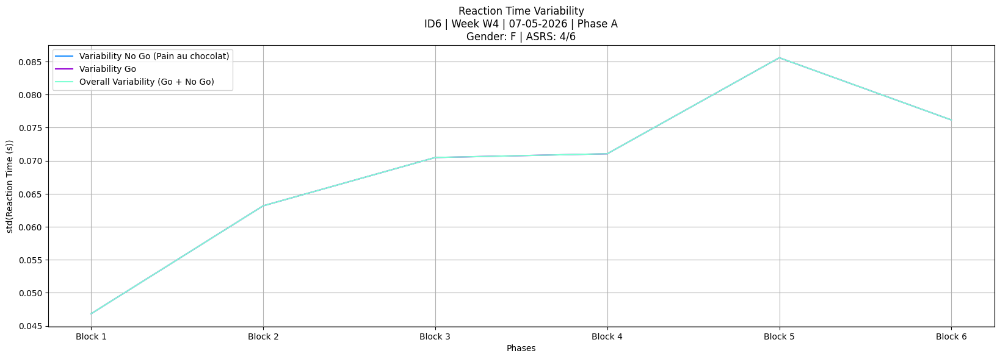

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,390.931595,Go,space,0.521550,Correct,False,False,6
1,1,1,391.969621,No_Go,NaN,NaN,Correct,False,False,6
2,1,2,392.986371,Go,space,0.383487,Correct,False,False,6
3,1,3,394.003323,No_Go,NaN,NaN,Correct,False,False,6
4,1,4,395.021961,Go,space,0.333120,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1044.009399,Go,space,0.451128,Correct,False,False,6
536,6,536,1045.025837,No_Go,NaN,NaN,Correct,False,False,6
537,6,537,1046.042765,Go,space,0.400057,Correct,False,False,6
538,6,538,1047.059323,Go,space,0.400182,Correct,False,False,6


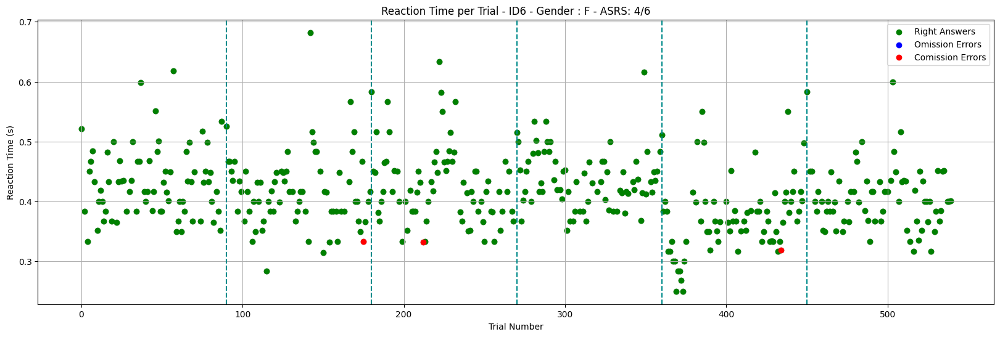

t=2.583336


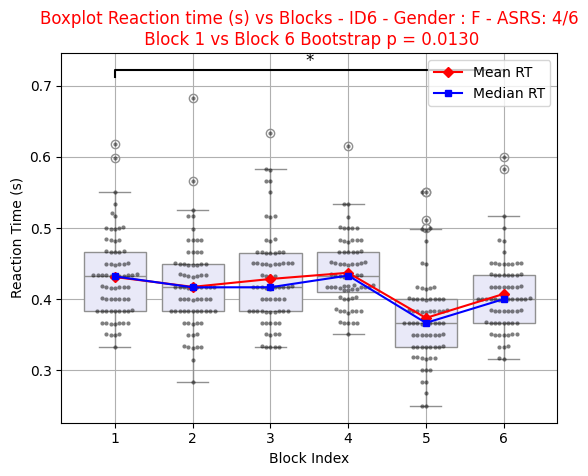

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

SESSION DATE: 2026-05-11 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
7,2026-05-11,B,"12,30,30,12,20,20"


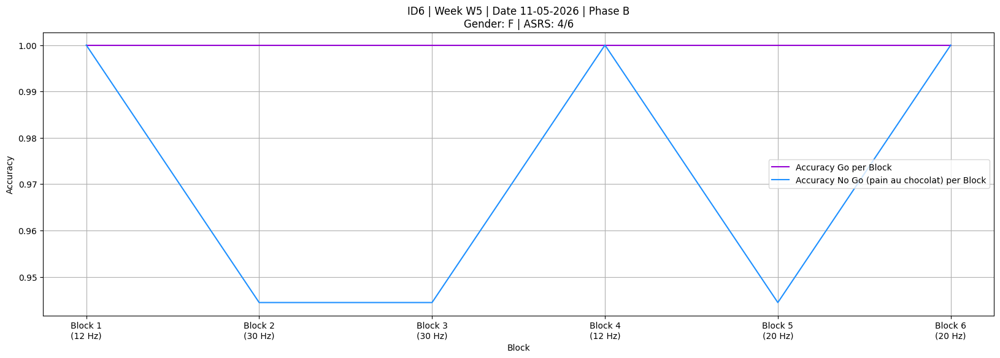

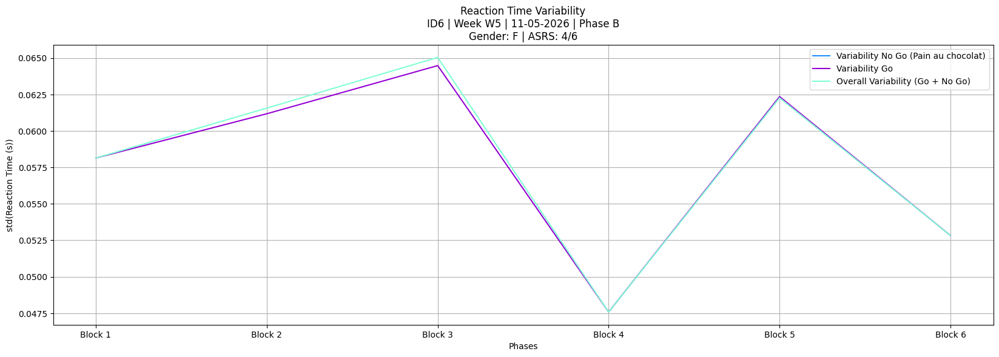

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,280.935981,Go,space,0.587403,Correct,False,False,6
1,1,1,281.973358,Go,space,0.400012,Correct,False,False,6
2,1,2,282.989954,Go,space,0.383426,Correct,False,False,6
3,1,3,284.006594,Go,space,0.316729,Correct,False,False,6
4,1,4,285.024154,Go,space,0.283552,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,940.394907,Go,space,0.466557,Correct,False,False,6
536,6,536,941.411519,Go,space,0.383395,Correct,False,False,6
537,6,537,942.428048,Go,space,0.400297,Correct,False,False,6
538,6,538,943.444852,Go,space,0.400083,Correct,False,False,6


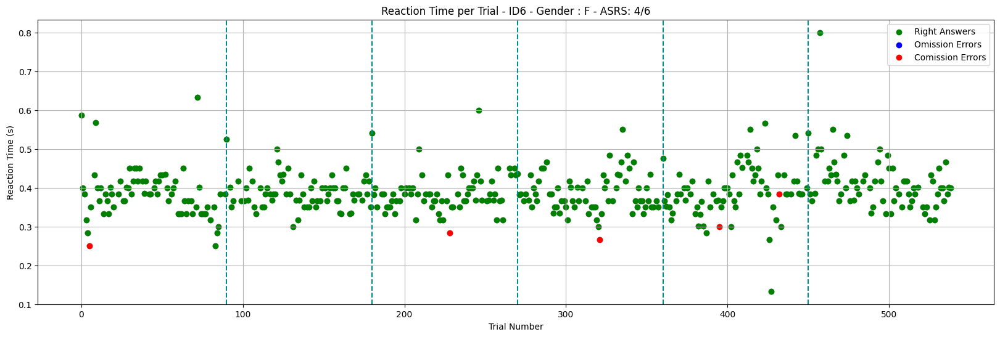

t=-2.636223


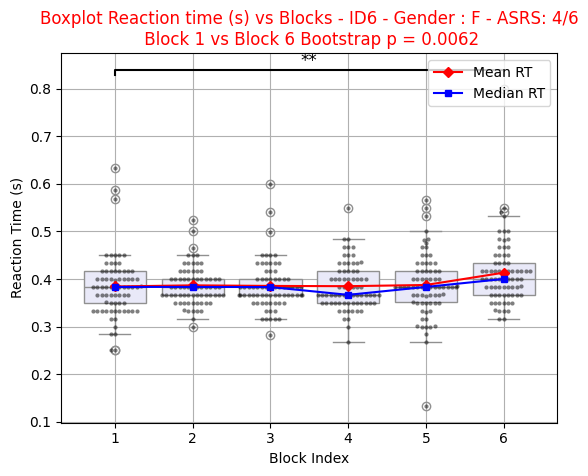

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

SESSION DATE: 2026-05-13 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
8,2026-05-13,B,"30,12,20,30,12,20"


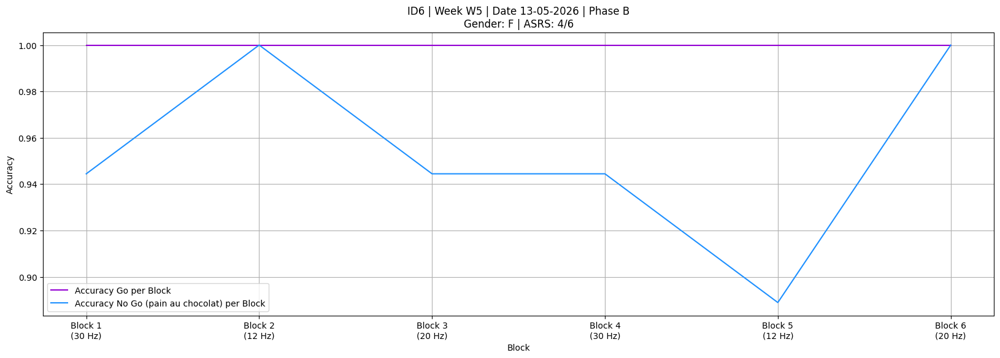

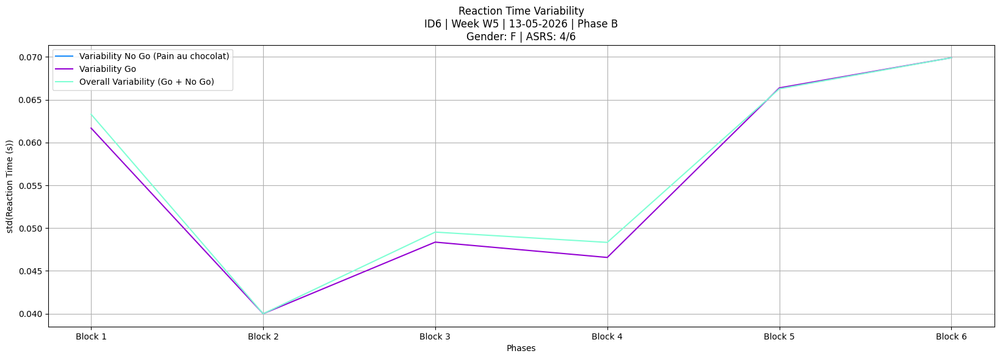

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,305.332489,Go,space,0.533189,Correct,False,False,6
1,1,1,306.382245,Go,space,0.433177,Correct,False,False,6
2,1,2,307.398883,Go,space,0.466848,Correct,False,False,6
3,1,3,308.416009,Go,space,0.449762,Correct,False,False,6
4,1,4,309.432513,Go,space,0.401639,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,955.069956,Go,space,0.717055,Correct,False,False,6
536,6,536,956.086924,Go,space,0.800009,Correct,False,False,6
537,6,537,957.103467,Go,NaN,NaN,Incorrect,True,False,6
538,6,538,958.119987,Go,space,0.033345,Correct,False,False,6


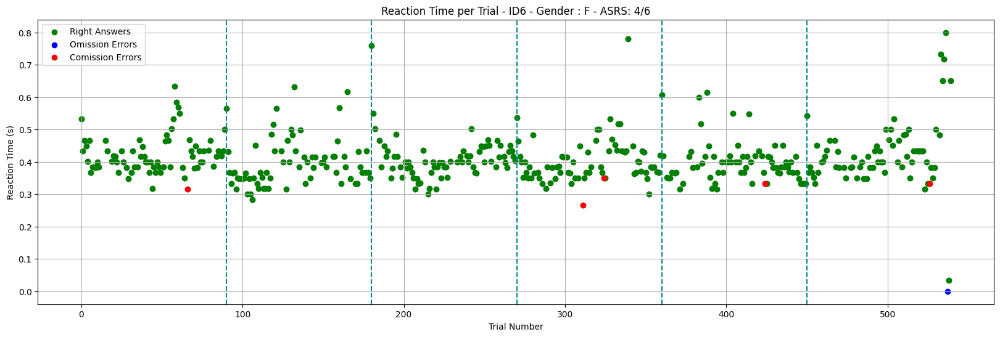

t=-0.267793


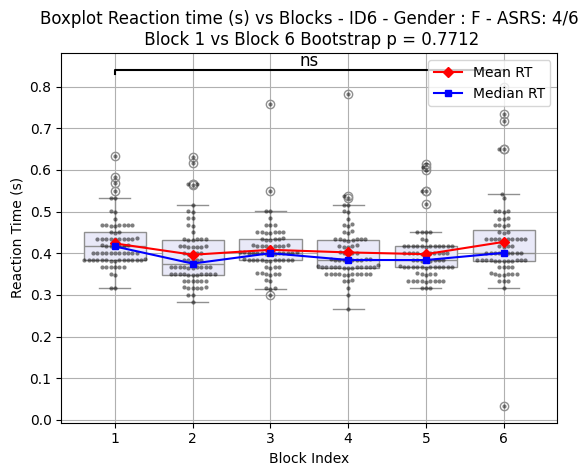

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.9444444444444444}]

SESSION DATE: 2026-05-19 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
9,2026-05-19,B,"12,12,20,30,20,30"


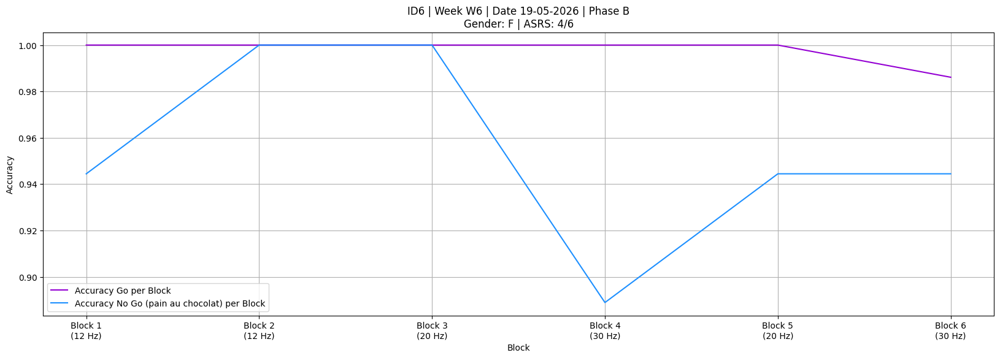

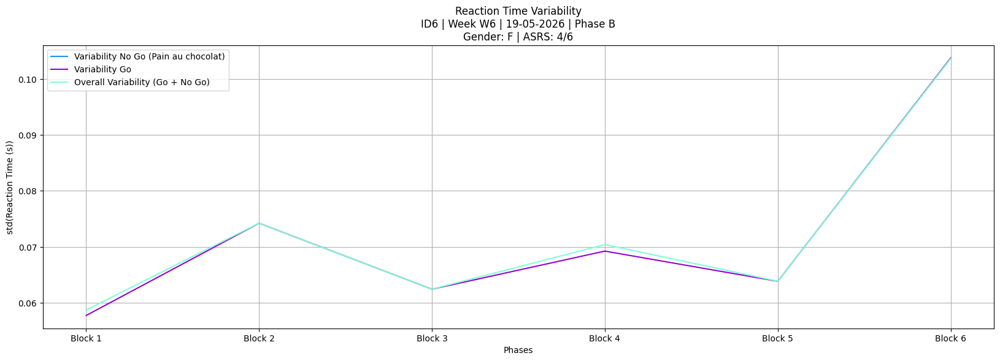

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,268.862164,Go,space,0.669426,Correct,False,False,6
1,1,1,269.864890,Go,space,0.450063,Correct,False,False,6
2,1,2,270.881271,Go,space,0.383463,Correct,False,False,6
3,1,3,271.897959,Go,space,0.349891,Correct,False,False,6
4,1,4,272.914486,Go,space,0.316967,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,934.389132,No_Go,NaN,NaN,Correct,False,False,6
536,6,536,935.405766,Go,space,0.366578,Correct,False,False,6
537,6,537,936.422262,Go,space,0.483258,Correct,False,False,6
538,6,538,937.438941,Go,space,0.399953,Correct,False,False,6


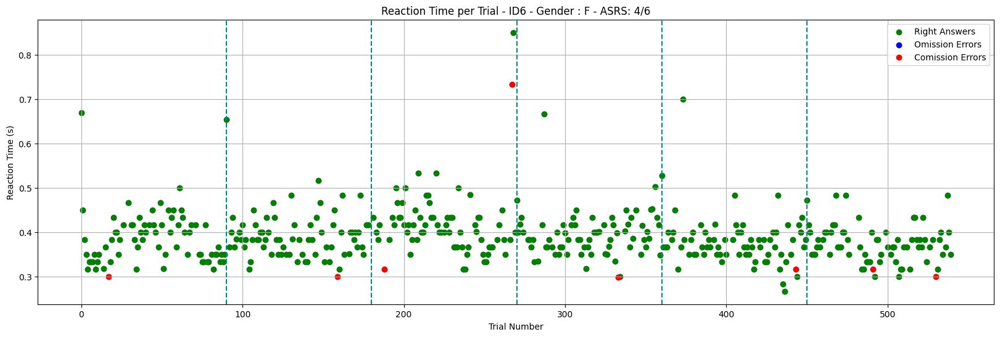

t=1.319194


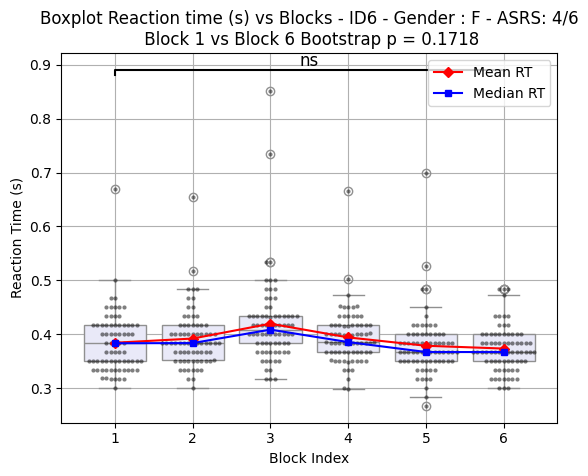

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

SESSION DATE: 2026-05-21 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
10,2026-05-21,B,"20,20,30,30,12,12"


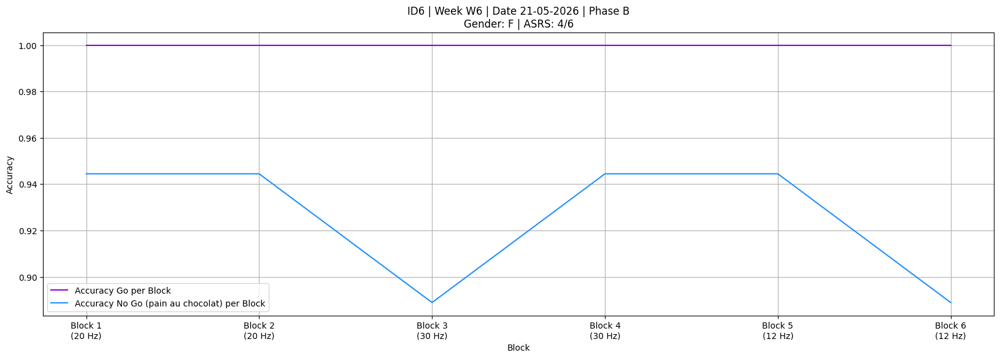

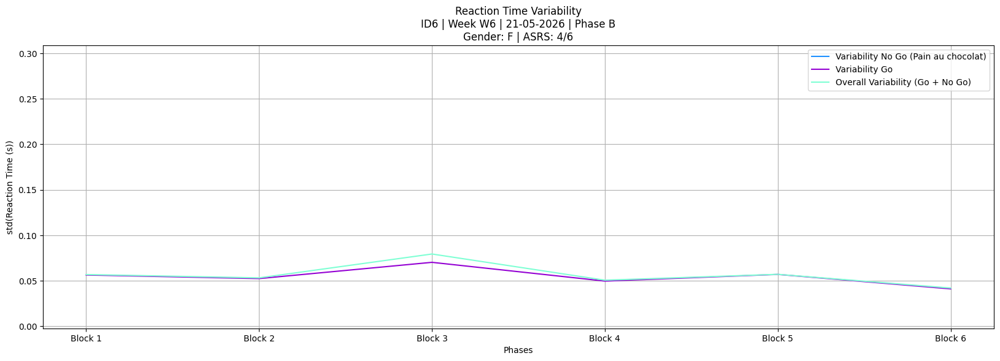

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,1602.653337,Go,space,0.553860,Correct,False,False,6
1,1,1,1603.706888,Go,space,0.400131,Correct,False,False,6
2,1,2,1604.723520,No_Go,NaN,NaN,Correct,False,False,6
3,1,3,1605.740424,Go,space,0.350004,Correct,False,False,6
4,1,4,1606.757003,Go,space,0.434915,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,2254.354176,Go,space,0.497684,Correct,False,False,6
536,6,536,2255.368743,Go,space,0.466816,Correct,False,False,6
537,6,537,2256.387525,Go,space,0.464984,Correct,False,False,6
538,6,538,2257.402387,No_Go,NaN,NaN,Correct,False,False,6


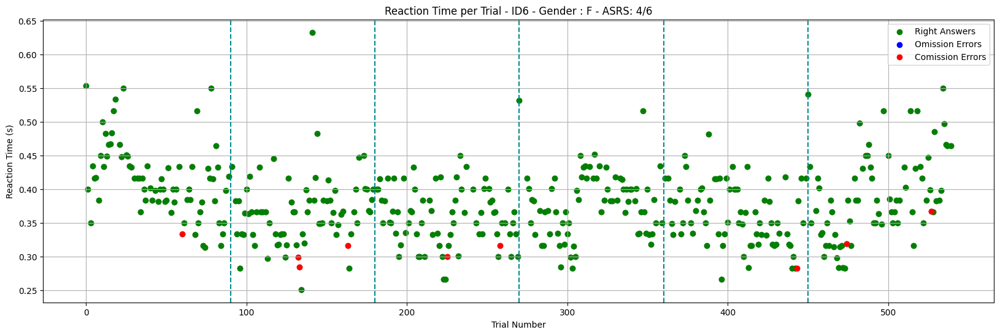

t=2.471077


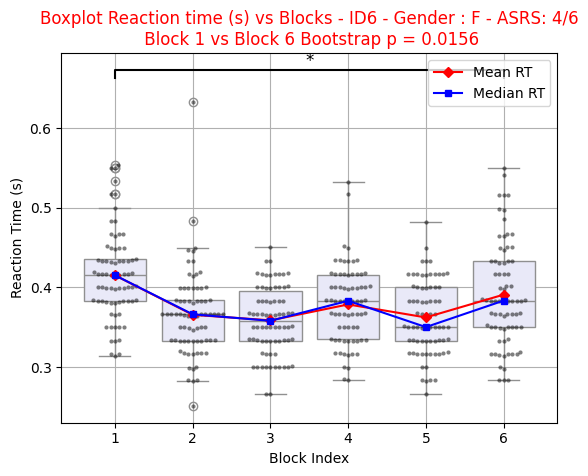

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

SESSION DATE: 2026-06-03 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
11,2026-06-03,B,"12,12,20,30,30,20"


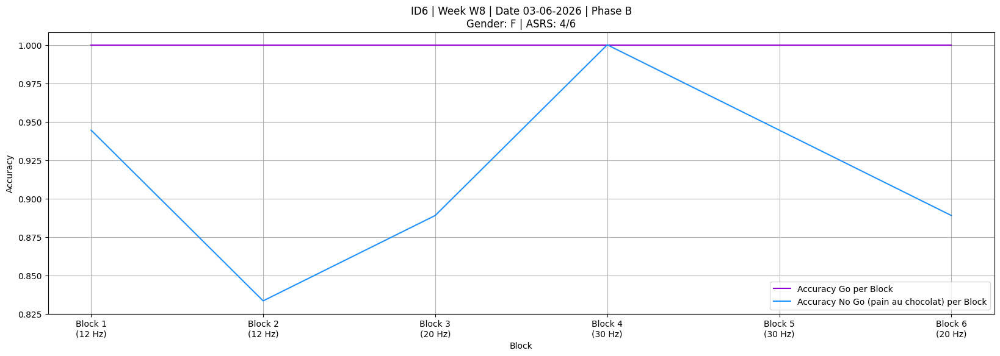

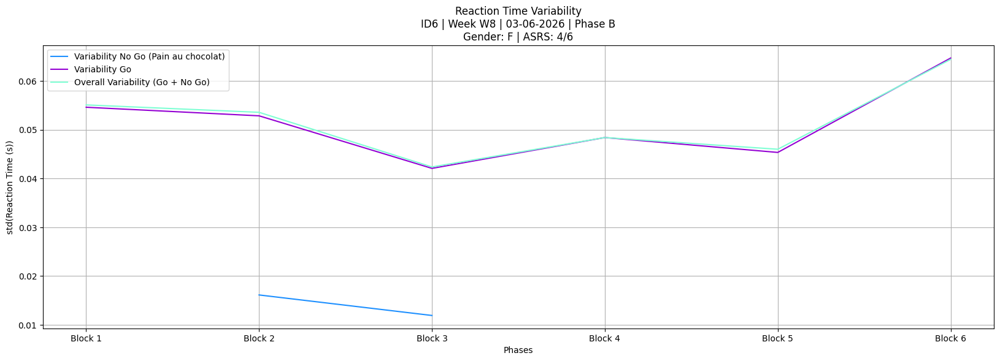

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,323.256771,Go,space,0.489754,Correct,False,False,6
1,1,1,324.263648,Go,space,0.416349,Correct,False,False,6
2,1,2,325.279949,Go,space,0.417129,Correct,False,False,6
3,1,3,326.297091,No_Go,NaN,NaN,Correct,False,False,6
4,1,4,327.314726,Go,space,0.382171,Correct,False,False,6
...,...,...,...,...,...,...,...,...,...,...
535,6,535,982.968693,No_Go,NaN,NaN,Correct,False,False,6
536,6,536,983.985482,Go,space,0.349501,Correct,False,False,6
537,6,537,985.002729,No_Go,NaN,NaN,Correct,False,False,6
538,6,538,986.018920,Go,space,0.316664,Correct,False,False,6


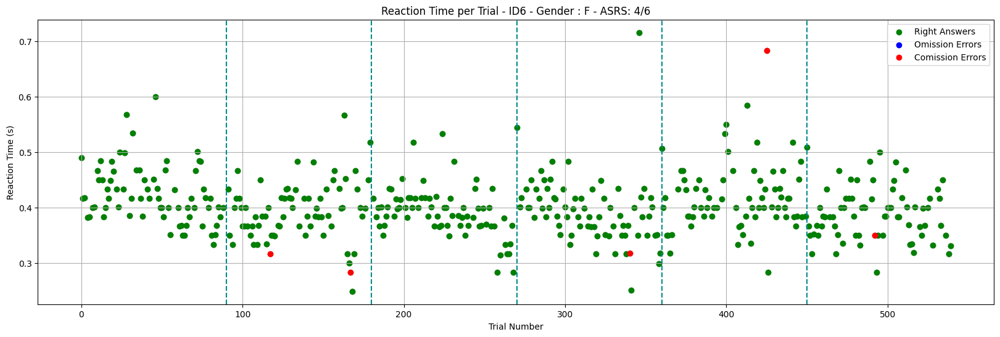

t=4.391684


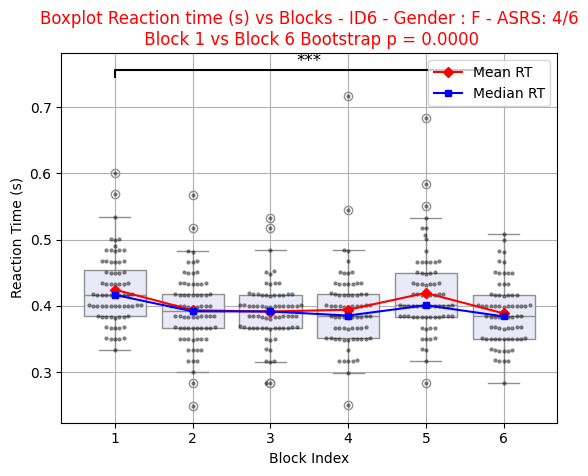

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

SESSION DATE: 2026-06-05 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
12,2026-06-05,B,"12,20,12,20,30,30"


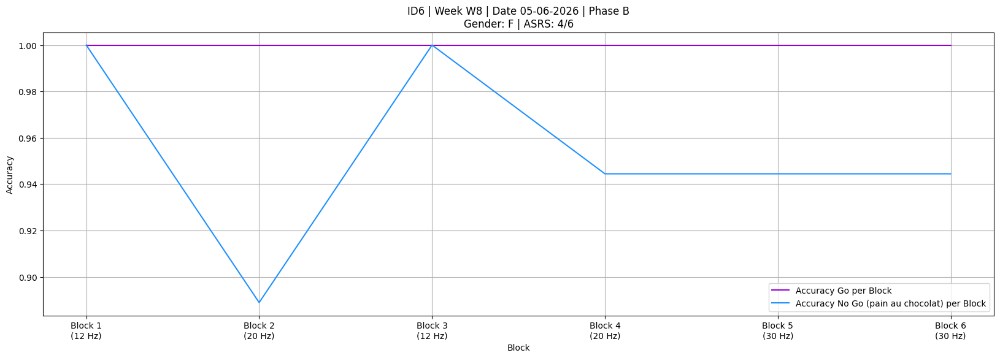

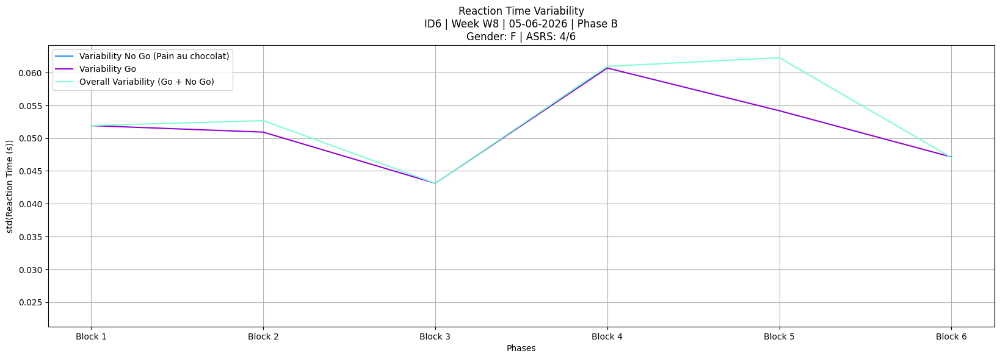

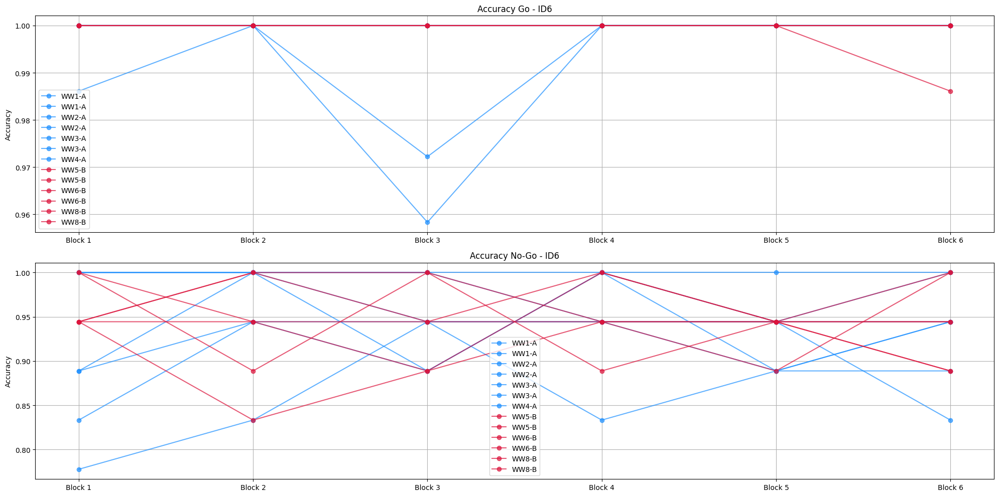

DATE: 2026-05-11 00:00:00
DATE: 2026-05-13 00:00:00
DATE: 2026-05-19 00:00:00
DATE: 2026-05-21 00:00:00
DATE: 2026-06-03 00:00:00
DATE: 2026-06-05 00:00:00


,DATE,PHASE,Go_12,Go_20,Go_30,NoGo_12,NoGo_20,NoGo_30,MeanGo,MeanNoGo
0,2026-04-13,A,0.993056,0.993056,0.993056,0.925926,0.925926,0.925926,NaN,NaN
1,2026-04-15,A,1.000000,1.000000,1.000000,0.953704,0.953704,0.953704,NaN,NaN
2,2026-04-22,A,0.995370,0.995370,0.995370,0.944444,0.944444,0.944444,NaN,NaN
3,2026-04-24,A,0.997685,0.997685,0.997685,0.870370,0.870370,0.870370,NaN,NaN
4,2026-04-28,A,1.000000,1.000000,1.000000,0.916667,0.916667,0.916667,NaN,NaN
5,2026-04-30,A,1.000000,1.000000,1.000000,0.962963,0.962963,0.962963,NaN,NaN
6,2026-05-07,A,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,NaN
7,2026-05-11,B,1.000000,1.000000,1.000000,1.000000,0.972222,0.944444,1.000000,0.972222
8,2026-05-13,B,1.000000,1.000000,1.000000,0.944444,0.972222,0.944444,1.000000,0.953704
9,2026-05-19,B,1.000000,1.000000,0.993056,0.972222,0.972222,0.916667,0.997685,0.953704


t=-1.467348
t=-1.122809
t=0.000000
t=1.028992


/tmp/ipykernel_1316/346653522.py:91: RuntimeWarning: divide by zero encountered in scalar divide
  t_distrib[b] = (np.mean(draw_x)-np.mean(draw_y))/np.sqrt(np.var(draw_x)/n+np.var(draw_y)/m)


t=-1.028992
t=2.080002
Go A-A   p = 0.0702
Go A-B   p = 0.1524
Go B-B   p = 0.1484
NoGo A-A p = 0.2980
NoGo A-B p = 0.9360
NoGo B-B p = 0.0524


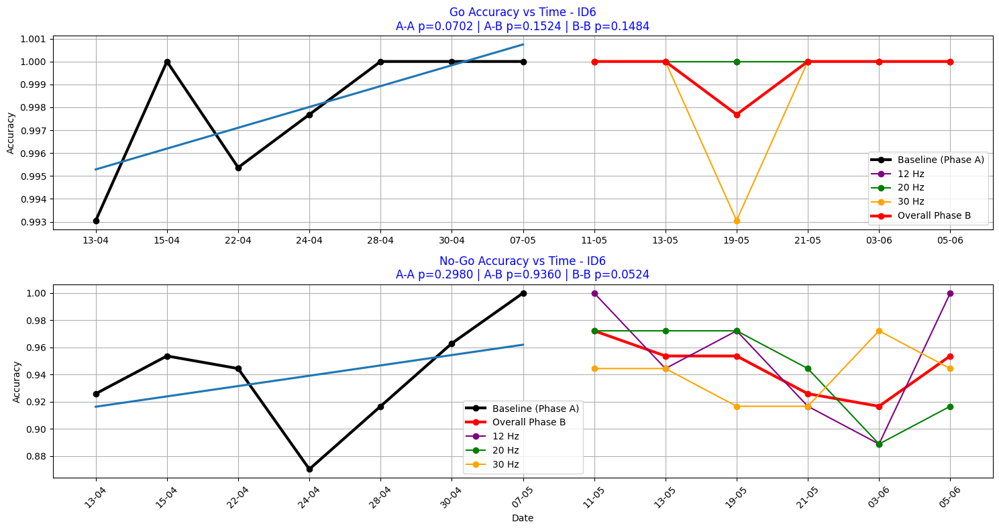

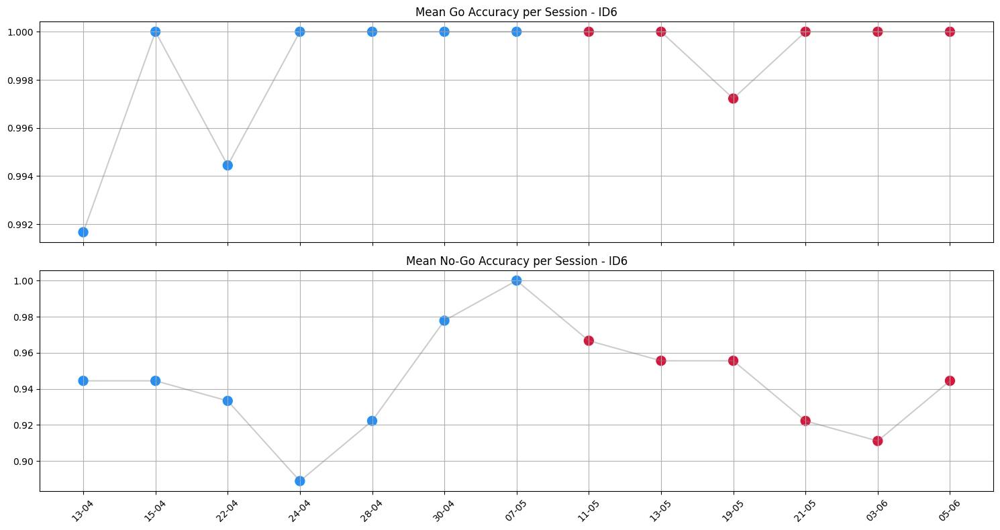

DATE: 2026-05-11 00:00:00
DATE: 2026-05-13 00:00:00
DATE: 2026-05-19 00:00:00
DATE: 2026-05-21 00:00:00
DATE: 2026-06-03 00:00:00
DATE: 2026-06-05 00:00:00


,DATE,Go_12,NoGo_12,Go_20,NoGo_20,Go_30,NoGo_30,MeanGo,MeanNoGo
0,2026-05-11,1.0,1.000000,1.0,0.972222,1.000000,0.944444,1.000000,0.972222
1,2026-05-13,1.0,0.944444,1.0,0.972222,1.000000,0.944444,1.000000,0.953704
2,2026-05-19,1.0,0.972222,1.0,0.972222,0.993056,0.916667,0.997685,0.953704
3,2026-05-21,1.0,0.916667,1.0,0.944444,1.000000,0.916667,1.000000,0.925926
4,2026-06-03,1.0,0.888889,1.0,0.888889,1.000000,0.972222,1.000000,0.916667
5,2026-06-05,1.0,1.000000,1.0,0.916667,1.000000,0.944444,1.000000,0.953704


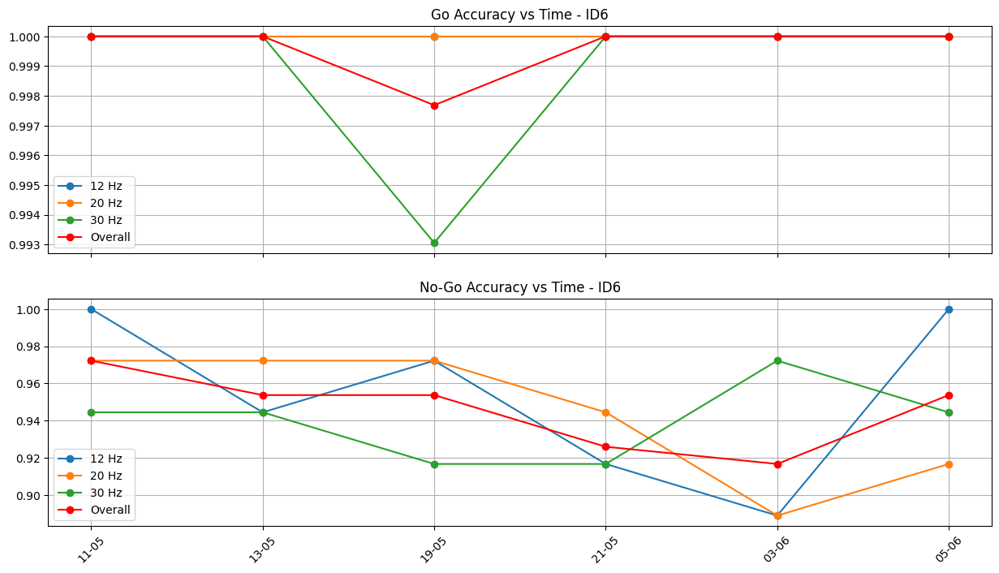

t=2.851115
t=0.337126
t=2.478293


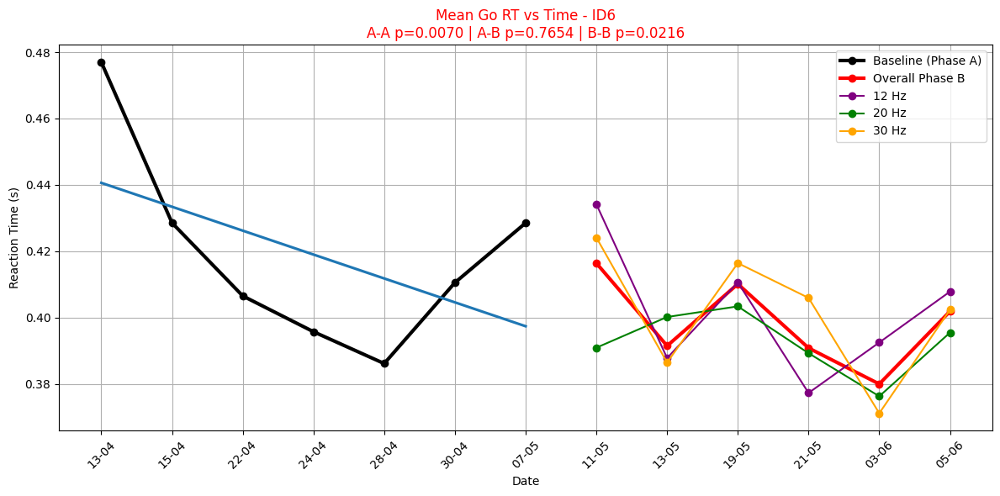

t=3.261528
t=0.855492
t=2.568310


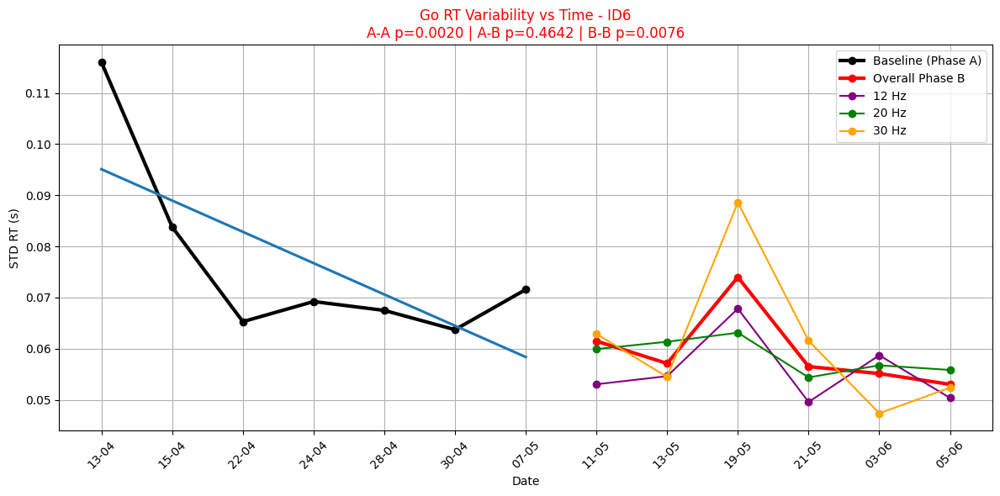

t=-1.584385
t=0.475980
t=1.666028


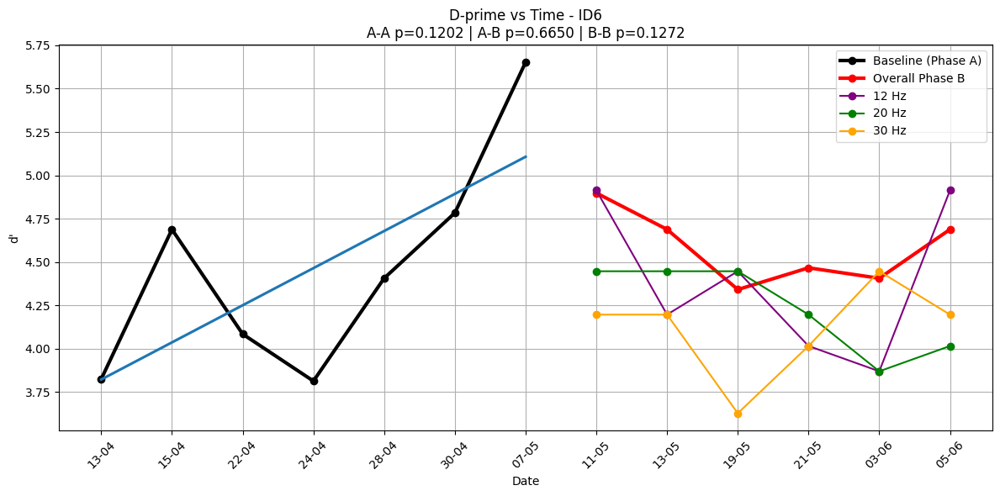

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime_All,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-13,A,4/6,NaN,NaN,NaN,3.823919,0.991667,0.944444,0.113584
1,2026-04-15,A,4/6,NaN,NaN,NaN,4.687670,1.000000,0.944444,0.078872
2,2026-04-22,A,4/6,NaN,NaN,NaN,4.083545,0.994444,0.933333,0.065829
3,2026-04-24,A,4/6,NaN,NaN,NaN,3.812459,1.000000,0.888889,0.065400
4,2026-04-28,A,4/6,8.0,5.0,0.0,4.405727,1.000000,0.922222,0.065504
5,2026-04-30,A,4/6,9.0,3.0,0.0,4.783220,1.000000,0.977778,0.061260
6,2026-05-07,A,4/6,8.0,4.0,0.0,5.652738,1.000000,1.000000,0.073290
7,2026-05-11,B,4/6,8.0,4.0,3.0,4.897896,1.000000,0.966667,0.057684
8,2026-05-13,B,4/6,6.0,4.0,5.0,4.687670,1.000000,0.955556,0.054238
9,2026-05-19,B,4/6,8.0,4.0,5.0,4.340688,0.997222,0.955556,0.074703


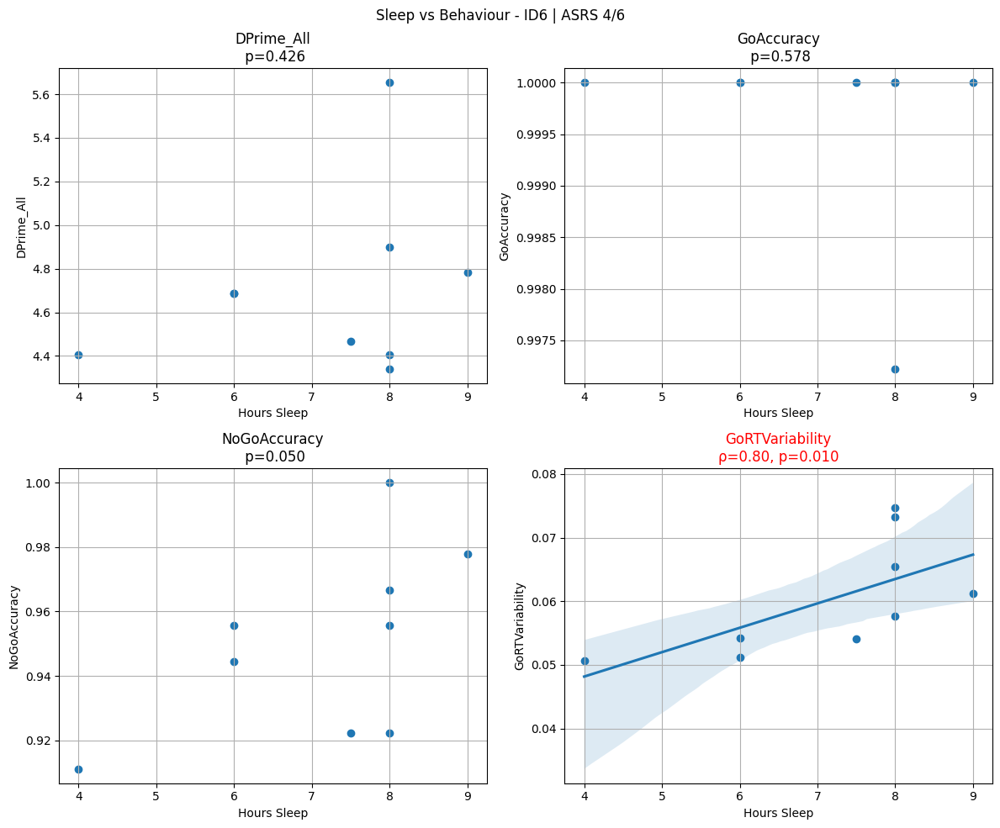

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime_All,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-13,A,4/6,NaN,NaN,NaN,3.823919,0.991667,0.944444,0.113584
1,2026-04-15,A,4/6,NaN,NaN,NaN,4.687670,1.000000,0.944444,0.078872
2,2026-04-22,A,4/6,NaN,NaN,NaN,4.083545,0.994444,0.933333,0.065829
3,2026-04-24,A,4/6,NaN,NaN,NaN,3.812459,1.000000,0.888889,0.065400
4,2026-04-28,A,4/6,8.0,5.0,0.0,4.405727,1.000000,0.922222,0.065504
5,2026-04-30,A,4/6,9.0,3.0,0.0,4.783220,1.000000,0.977778,0.061260
6,2026-05-07,A,4/6,8.0,4.0,0.0,5.652738,1.000000,1.000000,0.073290
7,2026-05-11,B,4/6,8.0,4.0,3.0,4.897896,1.000000,0.966667,0.057684
8,2026-05-13,B,4/6,6.0,4.0,5.0,4.687670,1.000000,0.955556,0.054238
9,2026-05-19,B,4/6,8.0,4.0,5.0,4.340688,0.997222,0.955556,0.074703


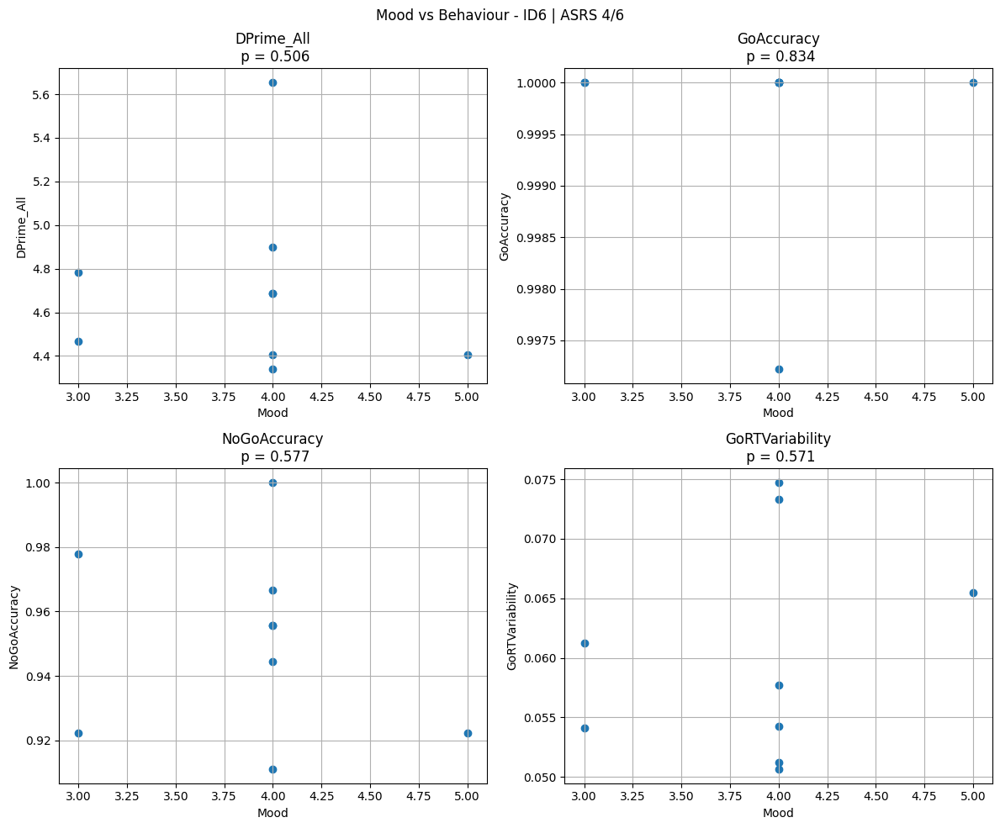

,Metric,n_A,n_B,Mean_A,Mean_B,Observed_Diff,NAP,TauU,Permutation_p
0,DPrime_All,7,6,4.464183,4.580947,0.116764,0.607143,0.214286,0.3413
1,Variability_Go,7,6,0.073759,0.057040,0.016719,0.880952,0.761905,0.0072
2,Accuracy_NoGo,7,6,0.939153,0.945988,0.006834,0.547619,0.095238,0.3830


In [1038]:
df_id6 = pipeline(id = 6)
#display(df_clean_list)
sced_df = sced_metrics(df_id6)
display(sced_df)

In [1039]:
df_id6

,ID,WEEK,DATE,PHASE,Gender,ASRS,Accuracy_Go,Accuracy_NoGo,Variability_Go,Variability_NoGo,Variability_Overall,DPrime_Blocks,DPrime_All,MeanGoRT,DF
0,6,W1,2026-04-13,A,F,4/6,"[1.0, 1.0, 0.9583333333333334, 1.0, 1.0, 1.0]","[0.8333333333333334, 0.9444444444444444, 0.888...","[0.11724222613020095, 0.09096350686949675, 0.1...","[0.03470625447313223, nan, 0.04636793968295712...","[0.12031610720993532, 0.09159702632113455, 0.1...","[3.3645053923463437, 3.877258063585274, 2.7840...",3.823919,"[0.47416667143503827, 0.4974626931879256, 0.50...",block_index trial trial_onset(s) stimul...
1,6,W1,2026-04-15,A,F,4/6,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0]","[1.0, 1.0, 0.8888888888888888, 1.0, 0.88888888...","[0.07186983075327906, 0.09709511274057134, 0.0...","[nan, nan, 0.03604432202130462, nan, 0.0246567...","[0.07186983075327906, 0.09709511274057134, 0.0...","[4.403001995531938, 4.403001995531938, 3.58402...",4.687670,"[0.45981130997339886, 0.4403695828384823, 0.45...",block_index trial trial_onset(s) stimul...
2,6,W2,2026-04-22,A,F,4/6,"[1.0, 1.0, 0.9722222222222222, 1.0, 1.0, 1.0]","[1.0, 1.0, 0.9444444444444444, 0.9444444444444...","[0.0604268493970964, 0.06614545341656676, 0.07...","[nan, nan, nan, nan, 0.05899479832203288, 0.01...","[0.0604268493970964, 0.06614545341656676, 0.07...","[4.403001995531938, 4.403001995531938, 3.23393...",4.083545,"[0.40953723589579266, 0.40324493911531234, 0.4...",block_index trial trial_onset(s) stimul...
3,6,W2,2026-04-24,A,F,4/6,"[0.9861111111111112, 1.0, 1.0, 1.0, 1.0, 1.0]","[0.7777777777777778, 0.8333333333333334, 0.944...","[0.05648982256963504, 0.07696015751214048, 0.0...","[0.04808146956150771, 0.019288947983867807, na...","[0.05891995004364546, 0.07786954068114951, 0.0...","[2.759058749524298, 3.3645053923463437, 3.8772...",3.812459,"[0.37156415321457553, 0.40317556262016296, 0.4...",block_index trial trial_onset(s) stimul...
4,6,W3,2026-04-28,A,F,4/6,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0]","[0.8888888888888888, 0.9444444444444444, 0.944...","[0.06359018700498535, 0.08025889358242291, 0.0...","[0.011793531150318368, nan, nan, nan, nan, 0.0...","[0.06372132724215666, 0.08011519122470569, 0.0...","[3.5840288657416695, 3.877258063585274, 3.8772...",4.405727,"[0.39341429538196987, 0.40276263488663566, 0.3...",block_index trial trial_onset(s) stimul...
5,6,W3,2026-04-30,A,F,4/6,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0]","[0.8888888888888888, 1.0, 1.0, 0.9444444444444...","[0.0627345851732478, 0.05552956130598721, 0.04...","[0.033570976363291316, nan, nan, nan, nan, nan]","[0.06362162443164508, 0.05552956130598721, 0.0...","[3.5840288657416695, 4.403001995531938, 4.4030...",4.783220,"[0.4278346300125122, 0.3979334566328261, 0.403...",block_index trial trial_onset(s) stimul...
6,6,W4,2026-05-07,A,F,4/6,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0]","[1.0, 1.0, 1.0, 1.0, 1.0, 1.0]","[0.046841766108343987, 0.06317127303484915, 0....","[nan, nan, nan, nan, nan, nan]","[0.046841766108343987, 0.06317127303484915, 0....","[4.403001995531938, 4.403001995531938, 4.40300...",5.652738,"[0.4236968325244056, 0.42493997679816353, 0.39...",block_index trial trial_onset(s) stimul...
7,6,W5,2026-05-11,B,F,4/6,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0]","[1.0, 0.9444444444444444, 0.9444444444444444, ...","[0.058142460707466675, 0.06117620095102809, 0....","[nan, nan, nan, nan, nan, nan]","[0.058142460707466675, 0.061562771046009844, 0...","[4.403001995531938, 3.877258063585274, 3.87725...",4.897896,"[0.43113572729958427, 0.418473932478163, 0.429...",block_index trial trial_onset(s) stimul...
8,6,W5,2026-05-13,B,F,4/6,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0]","[0.9444444444444444, 1.0, 0.9444444444444444, ...","[0.061679178961466345, 0.03999114058973459, 0....","[nan, nan, nan, nan, 0.058989403525423464, nan]","[0.06329517965032842, 0.03999114058973459, 0.0...","[3.877258063585274, 4.403001995531938, 3.87725...",4.687670,"[0.3862304588158925, 0.3867359393172794, 0.386...",block_index trial trial_onset(s) stimul...
9,6,W6,2026-05-19,B,F,4/6,"[1.0, 1.0, 1.0, 1.0, 1.0, 0.9861111

#**ID2**

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,369.728163,Go,NaN,NaN,Incorrect,True,False,2
1,1,1,370.698352,Go,space,0.316650,Correct,False,False,2
2,1,2,371.664821,Go,space,0.283715,Correct,False,False,2
3,1,3,372.631506,No_Go,space,0.316666,Incorrect,False,True,2
4,1,4,373.598378,Go,space,0.366596,Correct,False,False,2
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1036.864172,Go,space,0.300100,Correct,False,False,2
536,6,536,1037.830769,No_Go,space,0.316719,Incorrect,False,True,2
537,6,537,1038.797305,No_Go,NaN,NaN,Correct,False,False,2
538,6,538,1039.764129,Go,space,0.366798,Correct,False,False,2


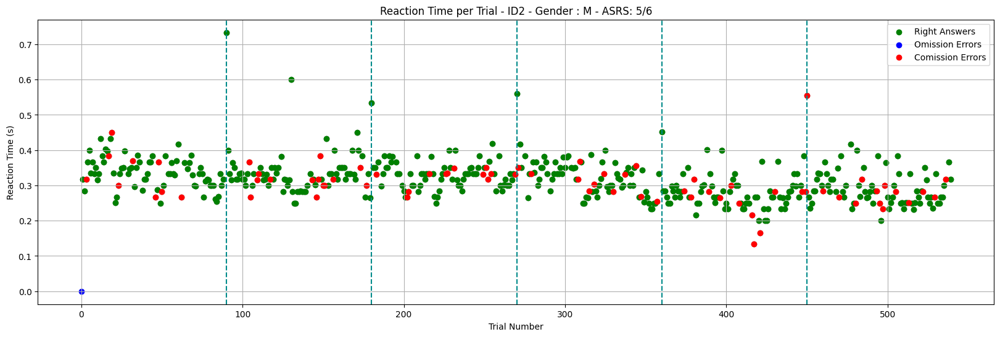

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 10.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 13.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=5.867341


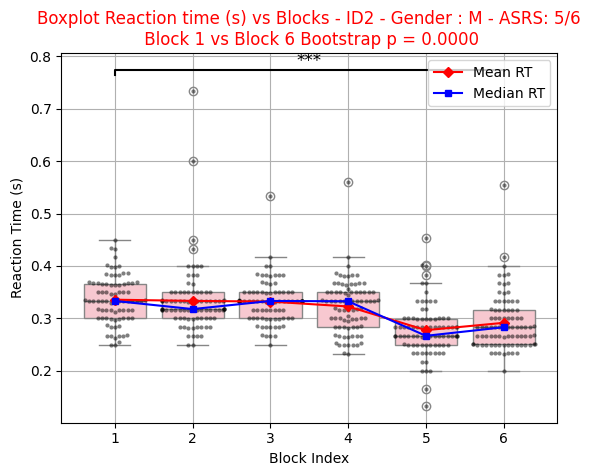

[{'Block': 'Block 1',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.5},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2222222222222222},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3333333333333333},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3333333333333333},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2222222222222222}]

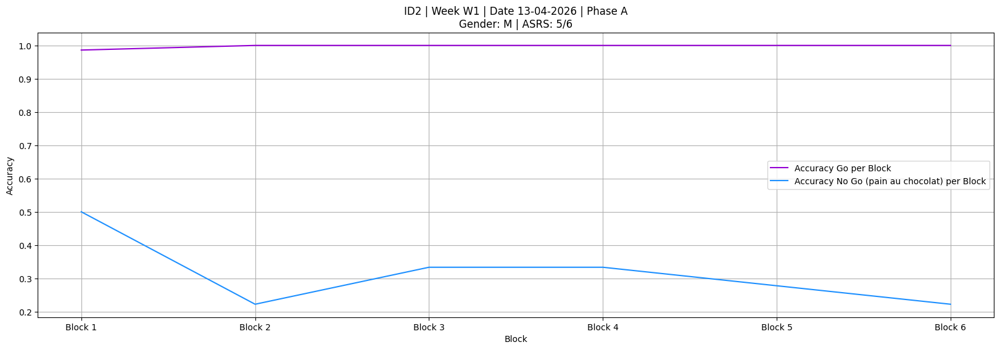

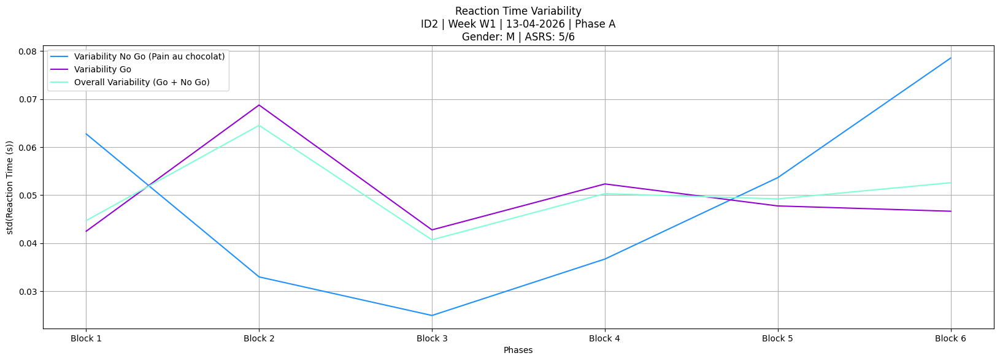

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,212.260079,Go,space,0.704193,Correct,False,False,2
1,1,1,213.281037,No_Go,space,0.416644,Incorrect,False,True,2
2,1,2,214.297526,No_Go,space,0.333550,Incorrect,False,True,2
3,1,3,215.314235,Go,space,0.333576,Correct,False,False,2
4,1,4,216.330778,Go,space,0.333391,Correct,False,False,2
...,...,...,...,...,...,...,...,...,...,...
535,6,535,874.611917,Go,space,0.250105,Correct,False,False,2
536,6,536,875.629246,Go,space,0.233097,Correct,False,False,2
537,6,537,876.645195,Go,space,0.216733,Correct,False,False,2
538,6,538,877.661565,Go,space,0.283697,Correct,False,False,2


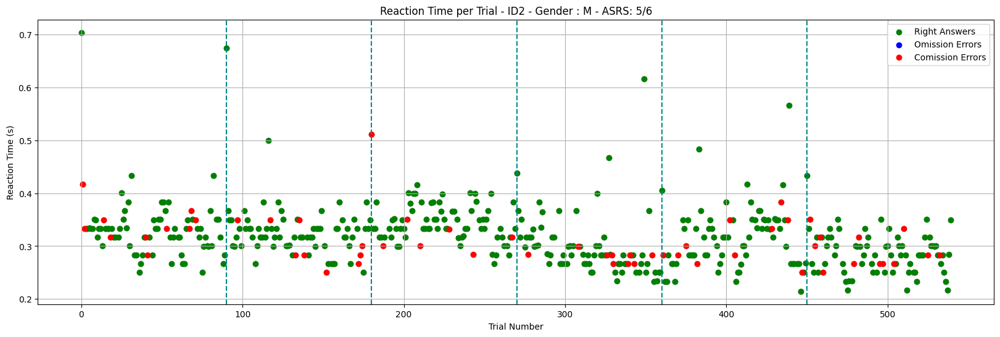

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=6.230624


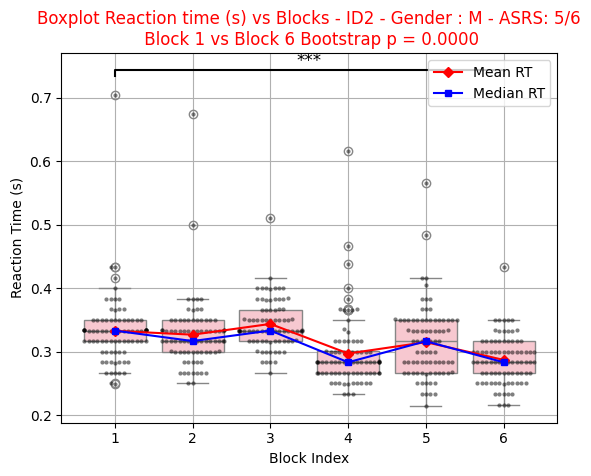

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3333333333333333}]

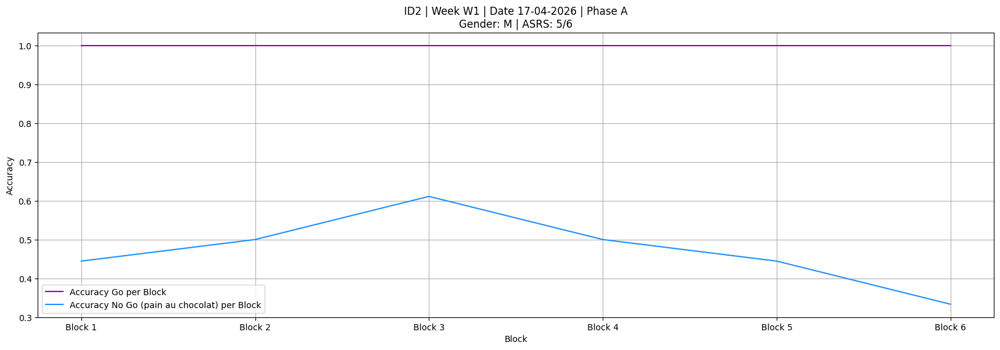

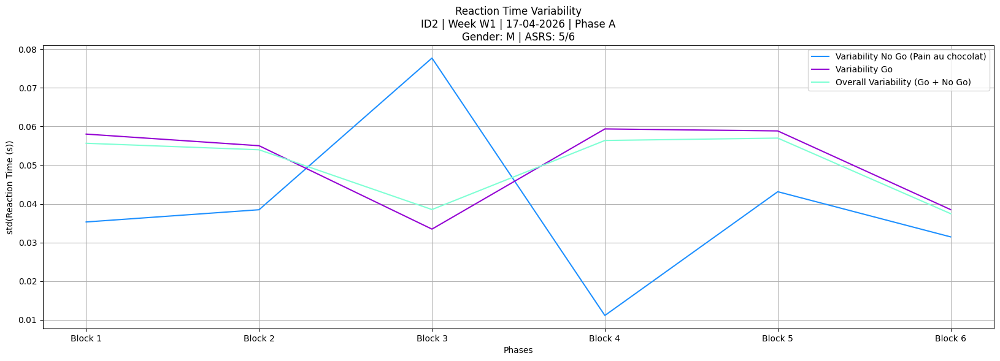

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,410.523332,No_Go,NaN,NaN,Correct,False,False,2
1,1,1,411.517510,Go,space,0.383760,Correct,False,False,2
2,1,2,412.500791,Go,space,0.336460,Correct,False,False,2
3,1,3,413.484964,Go,space,0.333237,Correct,False,False,2
4,1,4,414.468640,Go,space,0.332375,Correct,False,False,2
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1057.802958,Go,space,0.315591,Correct,False,False,2
536,6,536,1058.785102,Go,space,0.316820,Correct,False,False,2
537,6,537,1059.769692,Go,space,0.331984,Correct,False,False,2
538,6,538,1060.751742,No_Go,NaN,NaN,Correct,False,False,2


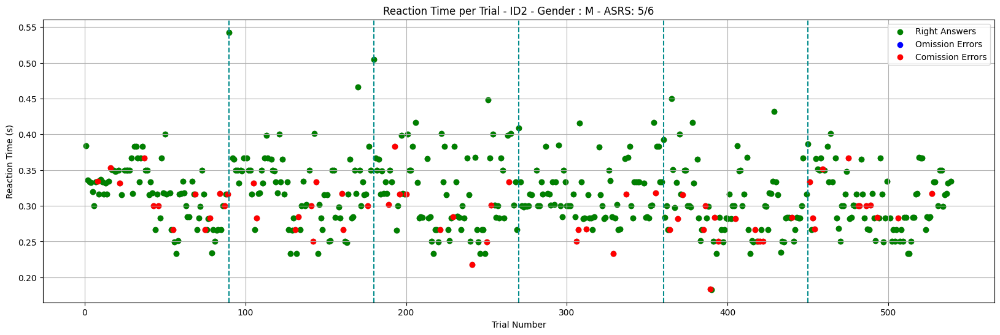

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=1.880090


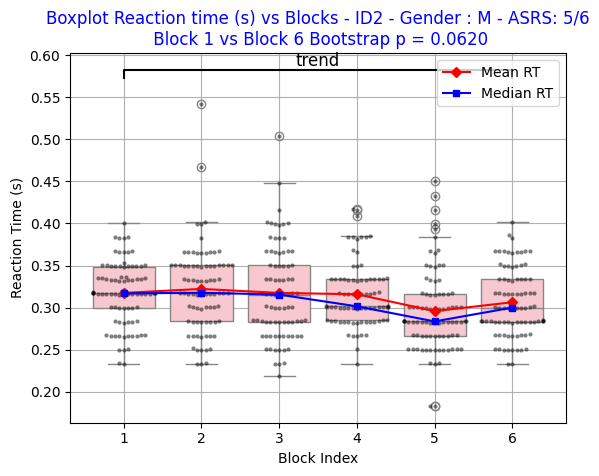

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2222222222222222},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3333333333333333}]

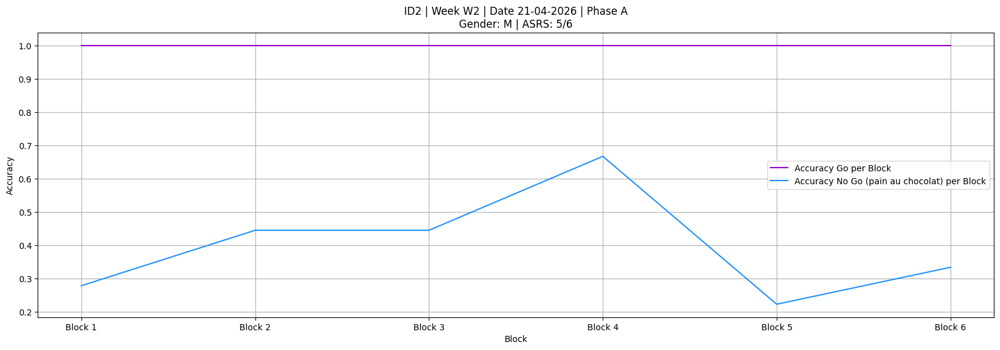

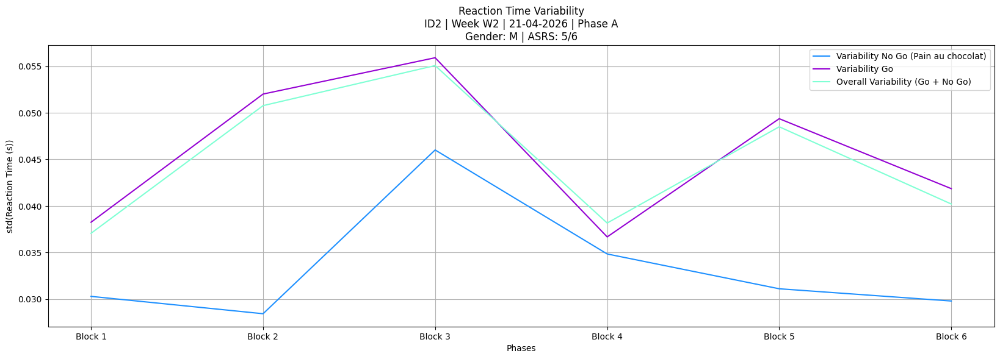

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,176.569668,Go,space,0.407872,Correct,False,False,2
1,1,1,177.594071,Go,space,0.316585,Correct,False,False,2
2,1,2,178.610556,Go,space,0.300171,Correct,False,False,2
3,1,3,179.627244,No_Go,space,0.300159,Incorrect,False,True,2
4,1,4,180.643897,No_Go,space,0.283617,Incorrect,False,True,2
...,...,...,...,...,...,...,...,...,...,...
535,6,535,839.922014,No_Go,NaN,NaN,Correct,False,False,2
536,6,536,840.938564,Go,space,0.366525,Correct,False,False,2
537,6,537,841.955244,Go,space,0.366765,Correct,False,False,2
538,6,538,842.972963,Go,space,0.349730,Correct,False,False,2


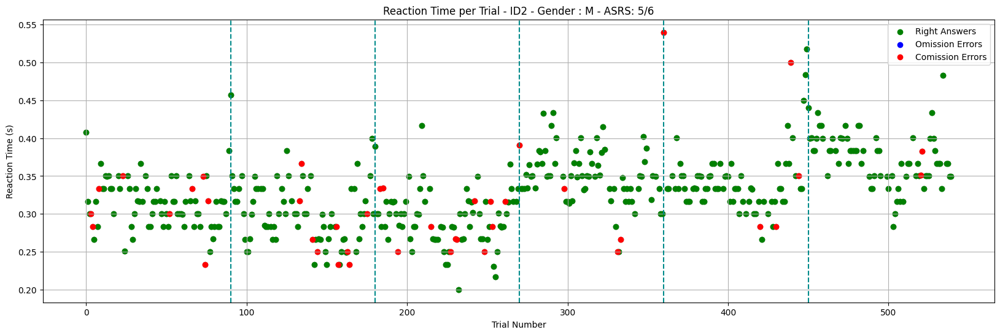

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 10.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=-11.404677


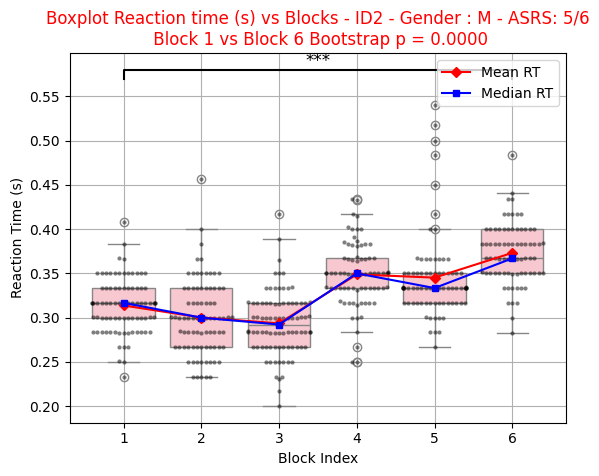

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3333333333333333},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

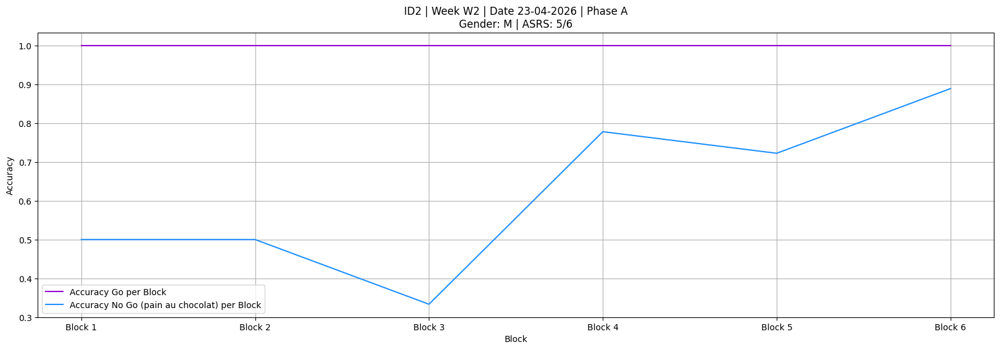

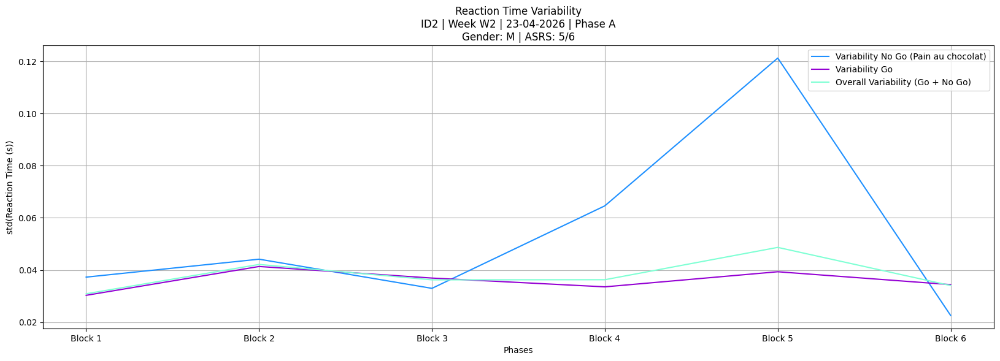

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,32.995723,Go,space,0.466964,Correct,False,False,2
1,1,1,33.978674,Go,space,0.316521,Correct,False,False,2
2,1,2,34.959765,Go,space,0.249842,Correct,False,False,2
3,1,3,35.942162,No_Go,space,0.267861,Incorrect,False,True,2
4,1,4,36.926083,Go,space,0.316411,Correct,False,False,2
...,...,...,...,...,...,...,...,...,...,...
535,6,535,667.517718,Go,space,0.266553,Correct,False,False,2
536,6,536,668.500166,No_Go,space,0.283123,Incorrect,False,True,2
537,6,537,669.482565,Go,space,0.249810,Correct,False,False,2
538,6,538,670.464911,Go,space,0.316519,Correct,False,False,2


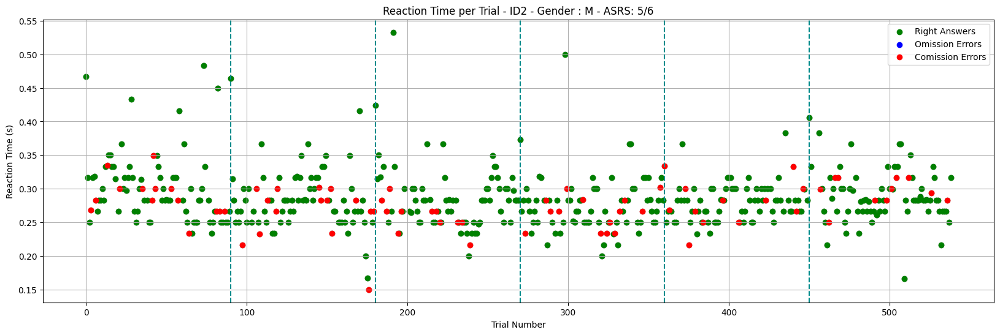

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 14.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 7.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=1.447101


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


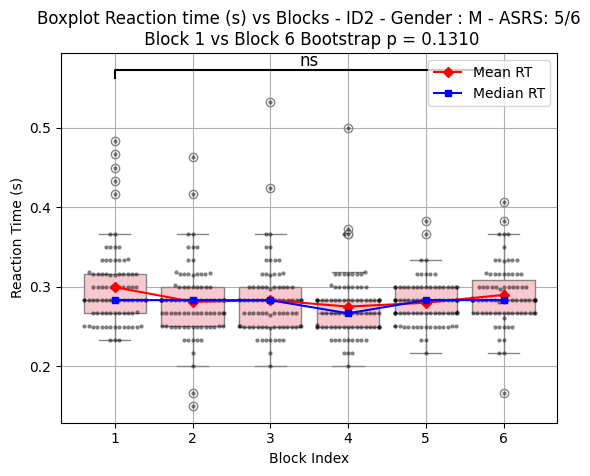

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2222222222222222},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.16666666666666666},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2222222222222222},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3333333333333333},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889}]

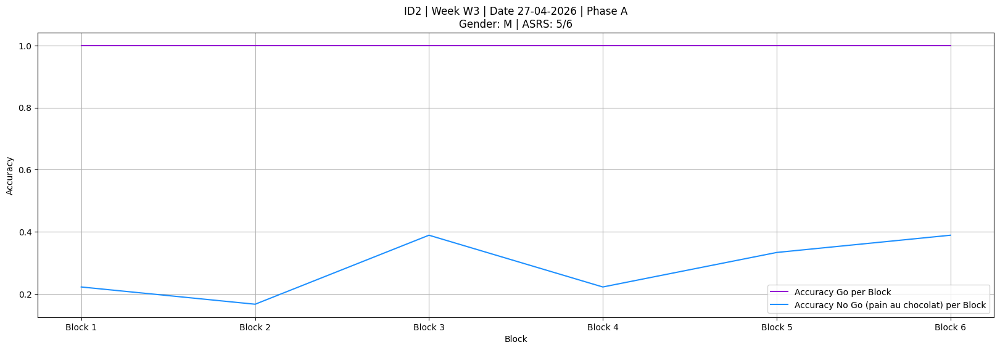

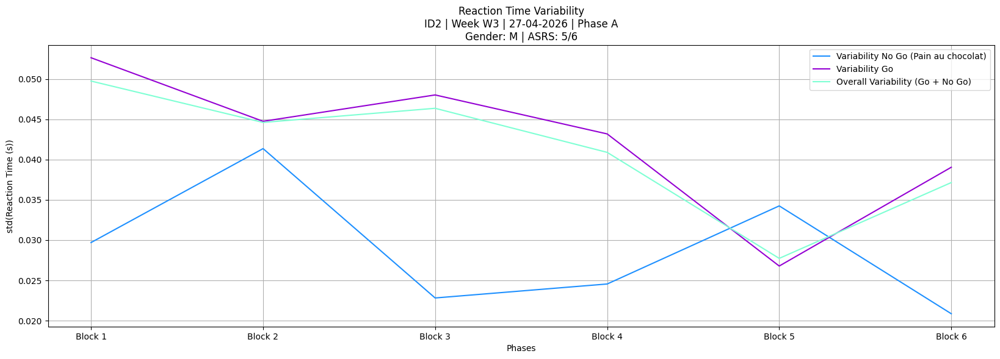

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,39.304779,Go,space,0.408329,Correct,False,False,2
1,1,1,40.328960,Go,space,0.283186,Correct,False,False,2
2,1,2,41.344608,Go,space,0.300143,Correct,False,False,2
3,1,3,42.361880,Go,space,0.316302,Correct,False,False,2
4,1,4,43.377700,Go,space,0.299713,Correct,False,False,2
...,...,...,...,...,...,...,...,...,...,...
535,6,535,696.961029,No_Go,space,0.283087,Incorrect,False,True,2
536,6,536,697.976770,Go,space,0.299734,Correct,False,False,2
537,6,537,698.992357,Go,space,0.299820,Correct,False,False,2
538,6,538,700.008088,Go,space,0.266457,Correct,False,False,2


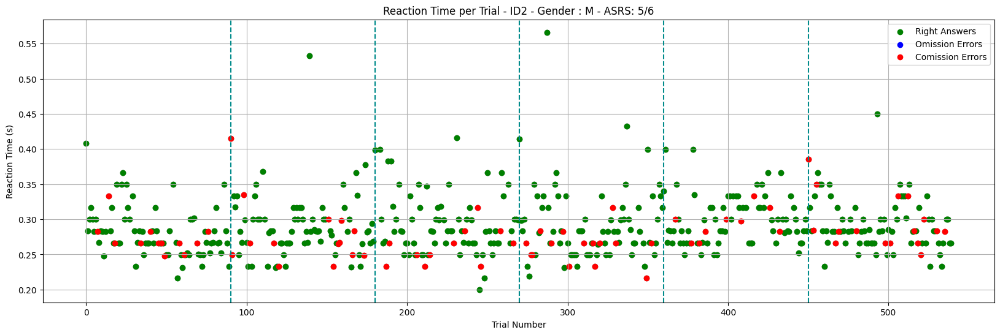

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 14.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 17.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=-2.349559


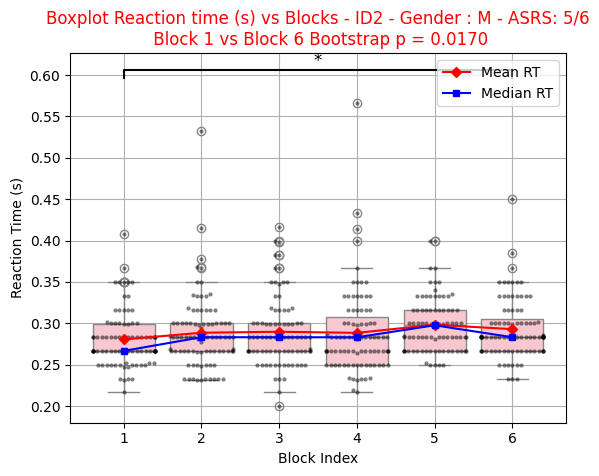

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3333333333333333},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2222222222222222},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.16666666666666666},
 {'Block': 'Block 5', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.1111111111111111}]

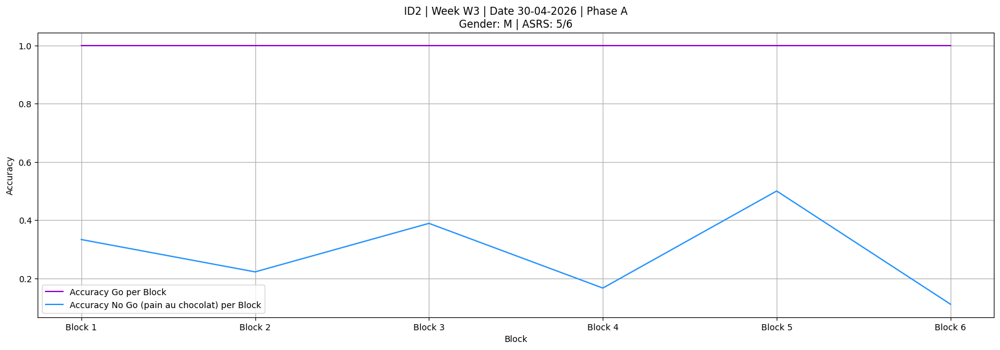

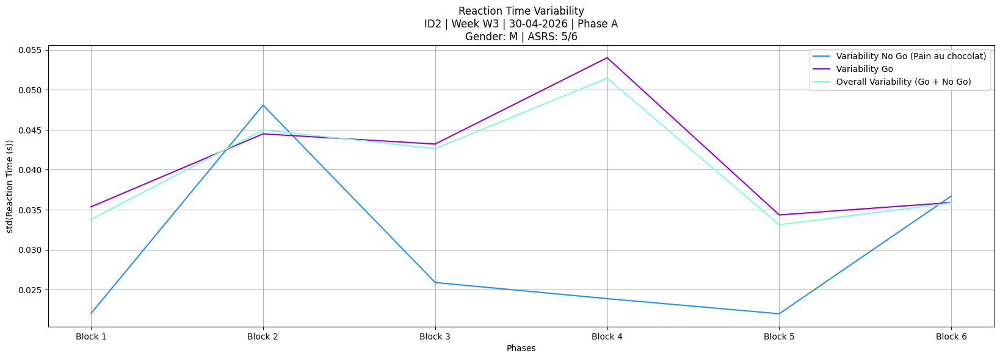

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,27.989235,Go,space,0.516188,Correct,False,False,2
1,1,1,29.005092,Go,space,0.349660,Correct,False,False,2
2,1,2,30.020657,Go,space,0.367917,Correct,False,False,2
3,1,3,31.037933,Go,space,0.333176,Correct,False,False,2
4,1,4,32.053769,No_Go,NaN,NaN,Correct,False,False,2
...,...,...,...,...,...,...,...,...,...,...
535,6,535,702.826736,No_Go,NaN,NaN,Correct,False,False,2
536,6,536,703.842161,Go,space,0.266256,Correct,False,False,2
537,6,537,704.859348,Go,space,0.317159,Correct,False,False,2
538,6,538,705.873673,Go,space,0.283041,Correct,False,False,2


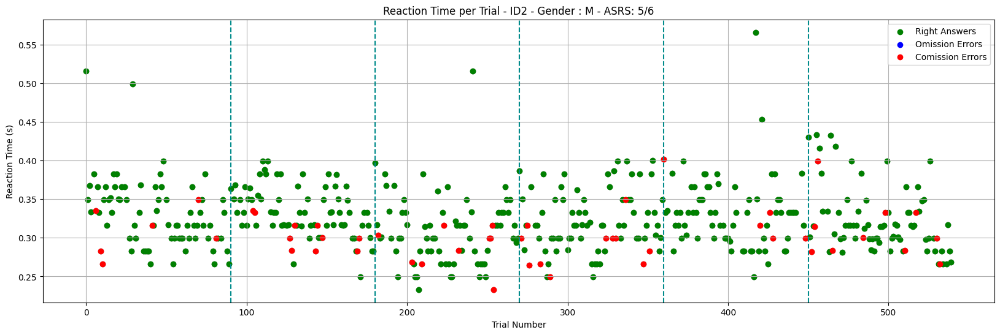

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 7.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=1.335942


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


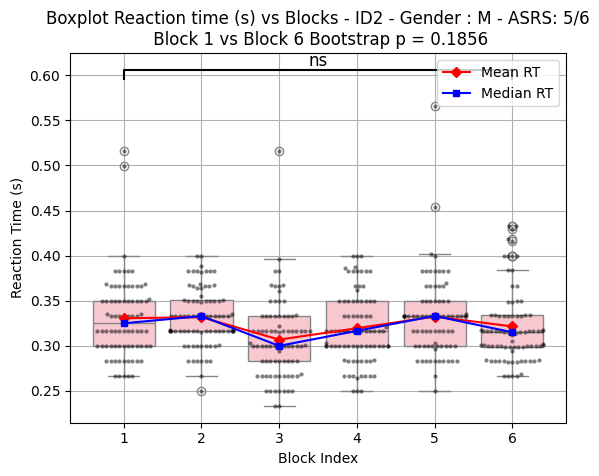

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444}]

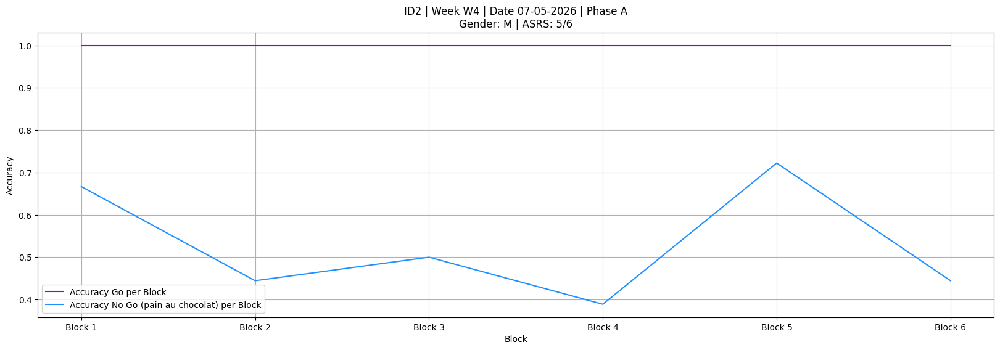

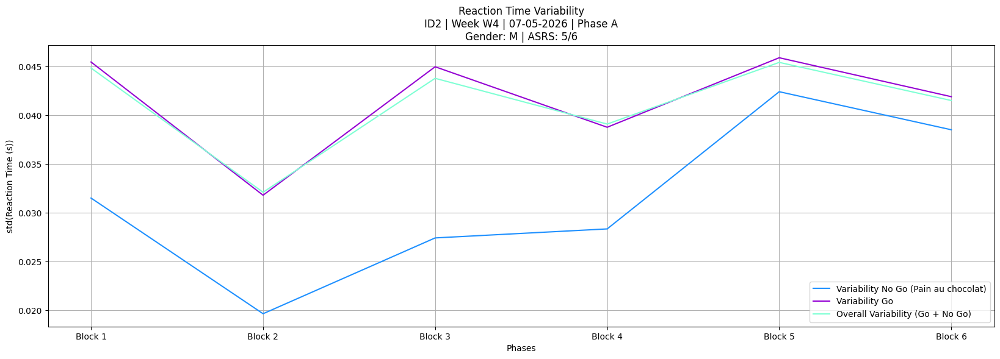

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,304.872043,No_Go,space,0.438794,Incorrect,False,True,2
1,1,1,305.943901,Go,space,0.450351,Correct,False,False,2
2,1,2,306.961571,Go,space,0.400045,Correct,False,False,2
3,1,3,307.978757,Go,space,0.365876,Correct,False,False,2
4,1,4,308.994660,Go,space,0.368394,Correct,False,False,2
...,...,...,...,...,...,...,...,...,...,...
535,6,535,967.331752,No_Go,space,0.299906,Incorrect,False,True,2
536,6,536,968.348387,Go,space,0.283293,Correct,False,False,2
537,6,537,969.365253,Go,space,0.316866,Correct,False,False,2
538,6,538,970.381991,No_Go,space,0.318700,Incorrect,False,True,2


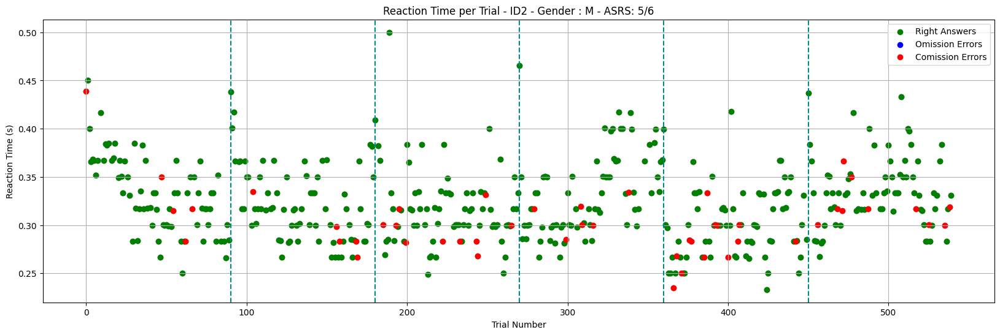

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 7.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=-0.285117


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


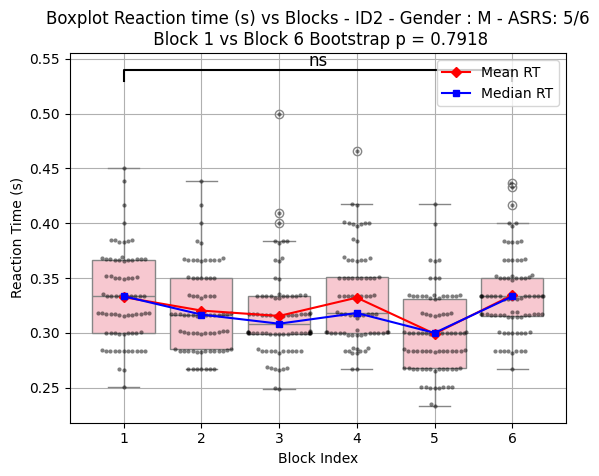

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444}]

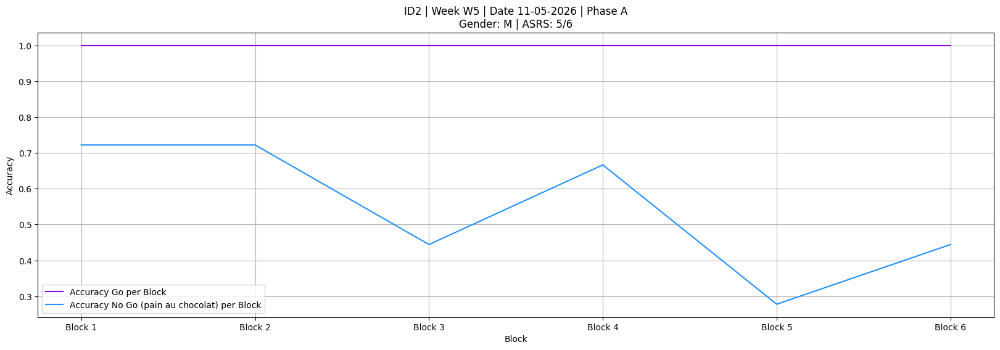

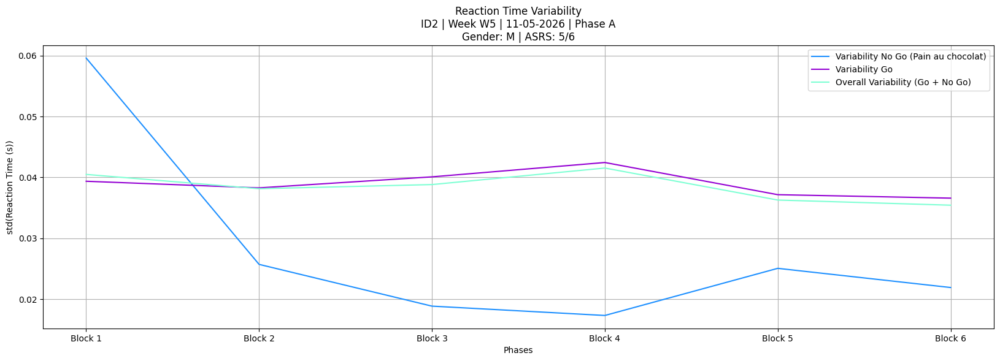

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,220.520944,Go,space,0.456804,Correct,False,False,2
1,1,1,221.561413,Go,space,0.316738,Correct,False,False,2
2,1,2,222.577995,Go,space,0.333699,Correct,False,False,2
3,1,3,223.594909,Go,space,0.366760,Correct,False,False,2
4,1,4,224.614147,Go,space,0.316564,Correct,False,False,2
...,...,...,...,...,...,...,...,...,...,...
535,6,535,882.494322,No_Go,NaN,NaN,Correct,False,False,2
536,6,536,883.511023,No_Go,NaN,NaN,Correct,False,False,2
537,6,537,884.527386,Go,space,0.300073,Correct,False,False,2
538,6,538,885.544293,Go,space,0.283562,Correct,False,False,2


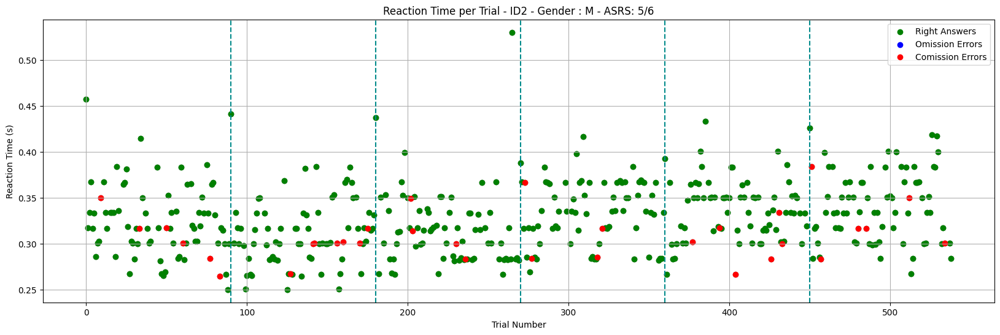

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=-2.890928


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


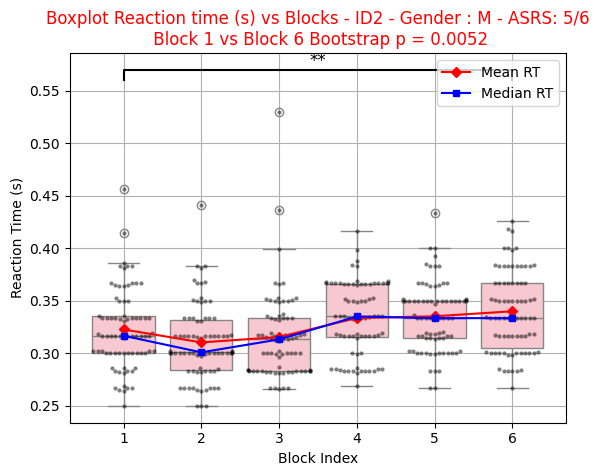

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666}]

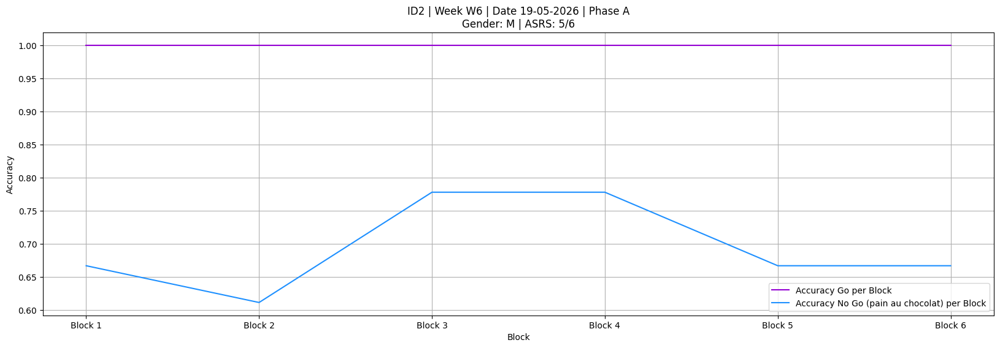

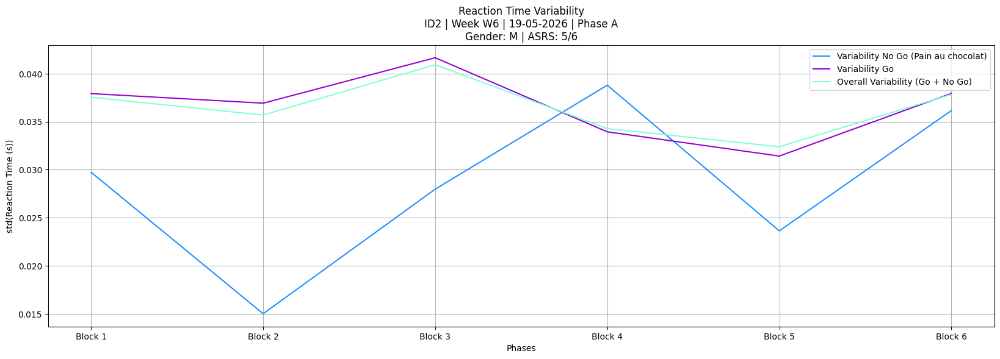

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,266.024622,Go,space,0.521739,Correct,False,False,2
1,1,1,267.046758,No_Go,space,0.366502,Incorrect,False,True,2
2,1,2,268.062990,Go,space,0.368185,Correct,False,False,2
3,1,3,269.079680,Go,space,0.350026,Correct,False,False,2
4,1,4,270.096473,Go,space,0.351188,Correct,False,False,2
...,...,...,...,...,...,...,...,...,...,...
535,6,535,951.237167,Go,space,0.264651,Correct,False,False,2
536,6,536,952.252030,Go,space,0.251787,Correct,False,False,2
537,6,537,953.267986,Go,space,0.283383,Correct,False,False,2
538,6,538,954.285086,Go,space,0.268440,Correct,False,False,2


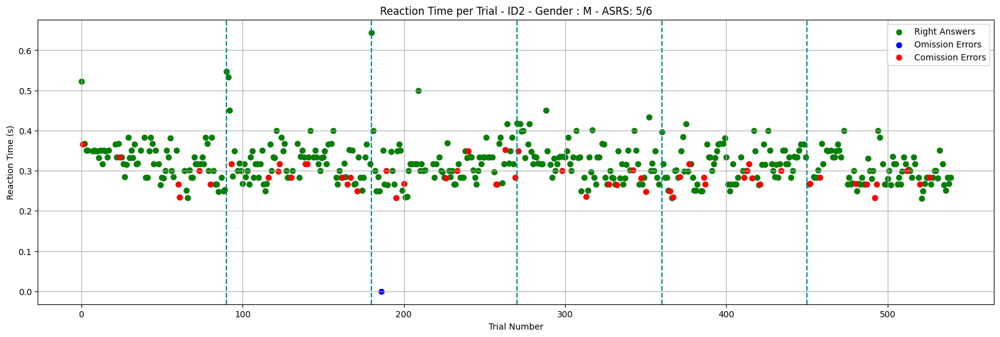

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 12.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=4.140647


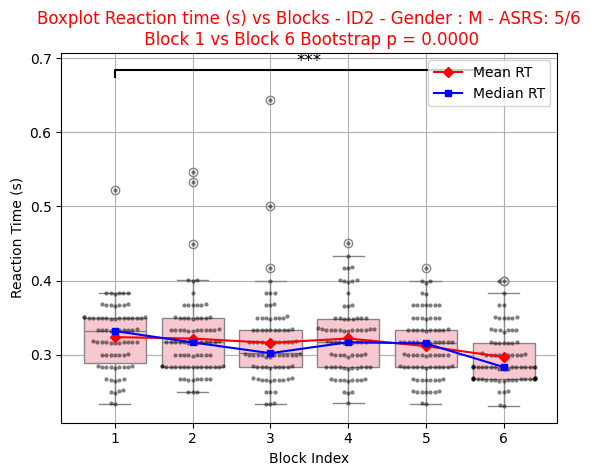

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 3',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3333333333333333},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5}]

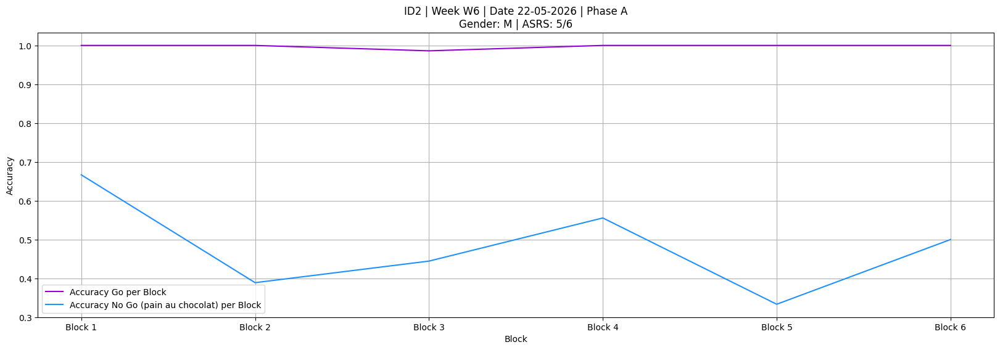

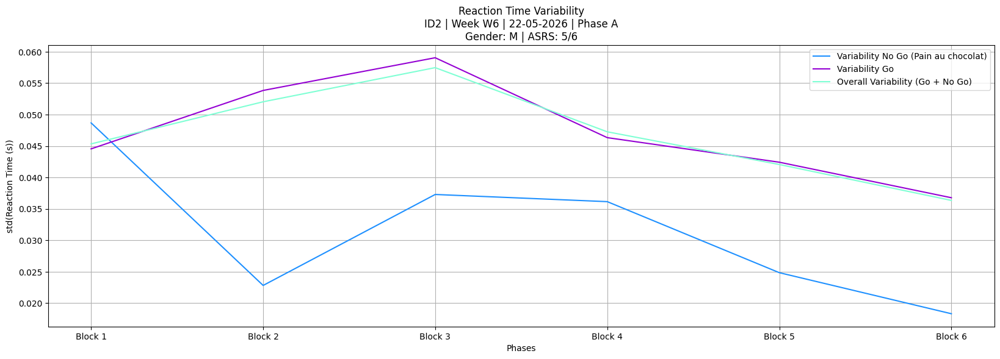

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,427.481779,Go,space,0.430189,Correct,False,False,2
1,1,1,428.528917,Go,space,0.333195,Correct,False,False,2
2,1,2,429.547707,Go,space,0.314964,Correct,False,False,2
3,1,3,430.562174,No_Go,space,0.366598,Incorrect,False,True,2
4,1,4,431.580977,Go,space,0.364826,Correct,False,False,2
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1110.180609,Go,space,0.366730,Correct,False,False,2
536,6,536,1111.197157,Go,space,0.366813,Correct,False,False,2
537,6,537,1112.214174,Go,space,0.366117,Correct,False,False,2
538,6,538,1113.230575,Go,space,0.366654,Correct,False,False,2


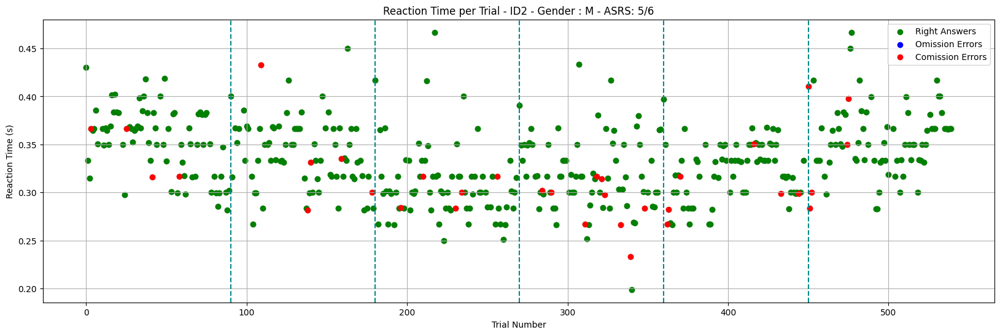

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=-0.161325


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


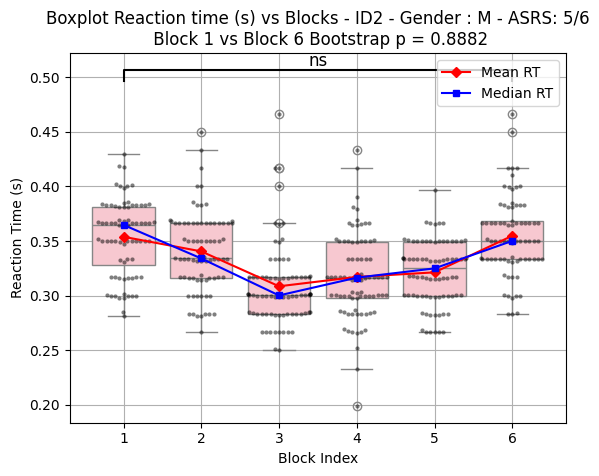

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222}]

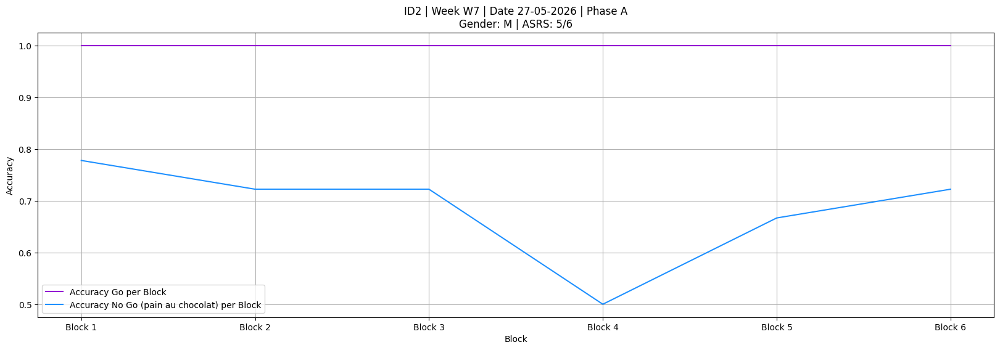

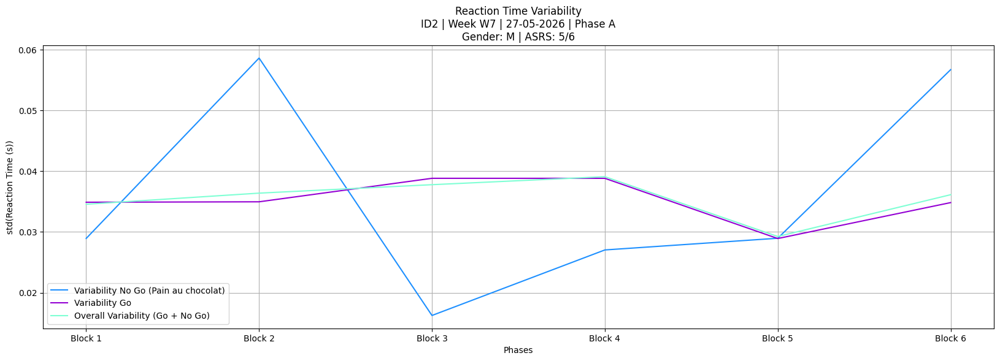

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,952.139245,Go,space,0.390912,Correct,False,False,2
1,1,1,953.146985,No_Go,NaN,NaN,Correct,False,False,2
2,1,2,954.163835,Go,space,0.383428,Correct,False,False,2
3,1,3,955.180602,Go,space,0.366703,Correct,False,False,2
4,1,4,956.196972,Go,space,0.367925,Correct,False,False,2
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1607.639167,Go,space,0.383615,Correct,False,False,2
536,6,536,1608.655966,Go,space,0.352404,Correct,False,False,2
537,6,537,1609.672138,Go,space,0.316770,Correct,False,False,2
538,6,538,1610.688720,Go,space,0.334018,Correct,False,False,2


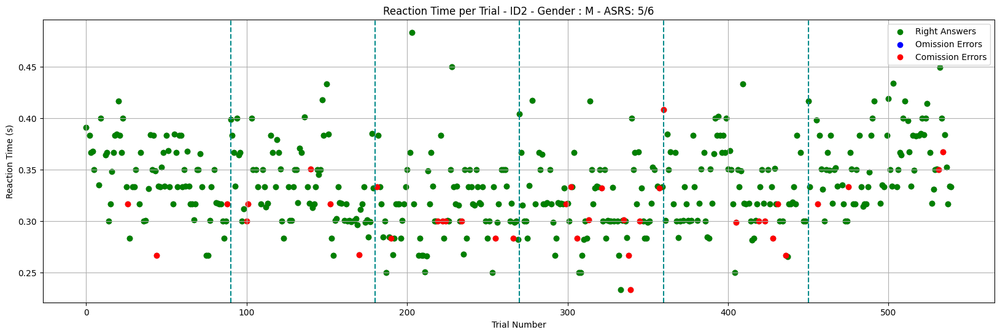

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=-2.911398


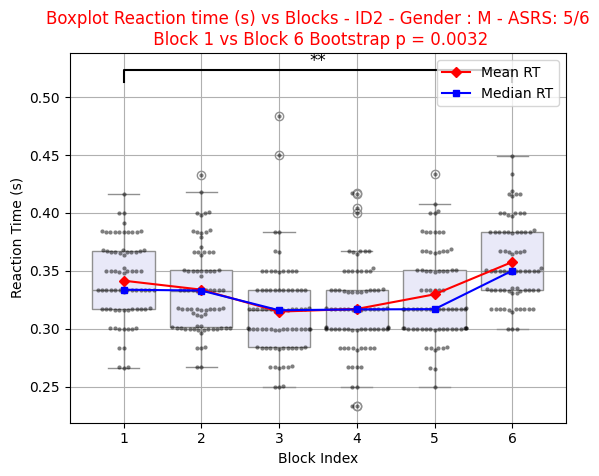

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778}]

SESSION DATE: 2026-06-04 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
11,2026-06-04,B,"20,20,30,12,12,30"


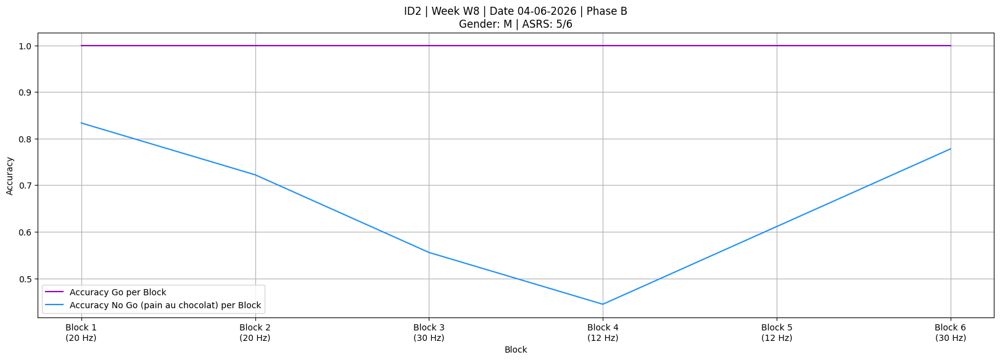

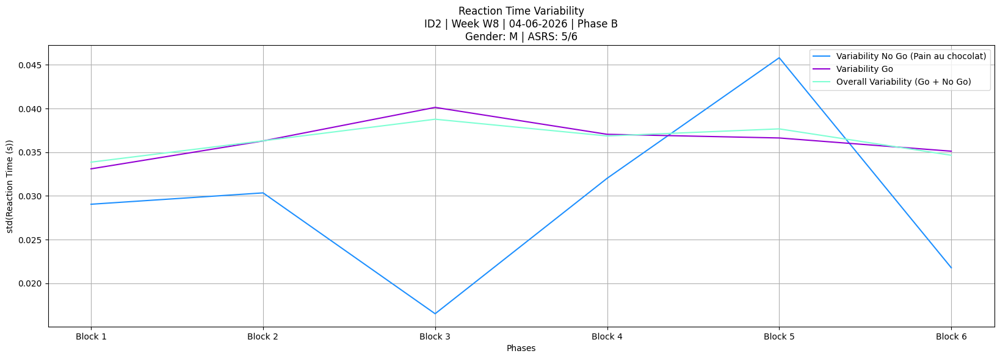

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,353.677147,Go,space,0.453520,Correct,False,False,2
1,1,1,354.681121,Go,space,0.366326,Correct,False,False,2
2,1,2,355.698812,Go,space,0.282481,Correct,False,False,2
3,1,3,356.715352,Go,space,0.298871,Correct,False,False,2
4,1,4,357.732010,Go,space,0.349067,Correct,False,False,2
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1015.751559,Go,space,0.315175,Correct,False,False,2
536,6,536,1016.766131,Go,space,0.317263,Correct,False,False,2
537,6,537,1017.782752,Go,space,0.317123,Correct,False,False,2
538,6,538,1018.799276,Go,space,0.333180,Correct,False,False,2


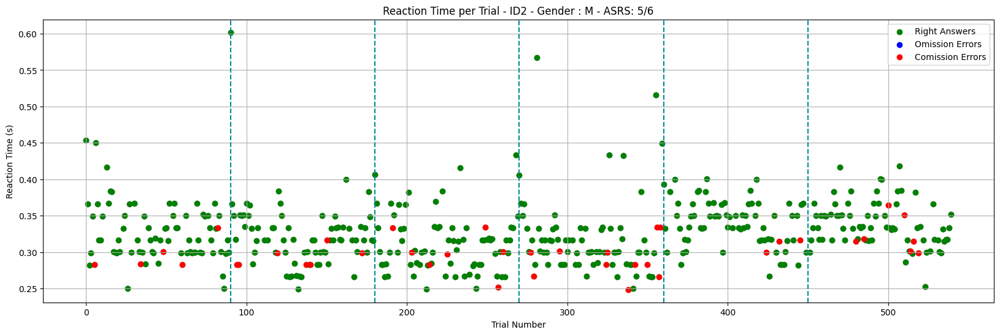

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 10.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 7.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=-2.290894


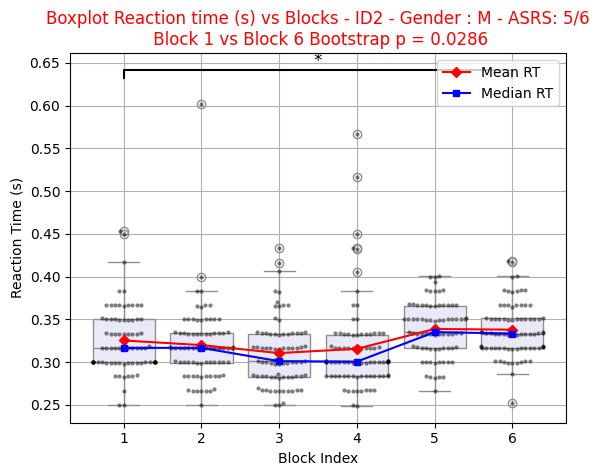

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112}]

SESSION DATE: 2026-06-08 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
12,2026-06-08,B,"12,20,30,20,12,30"


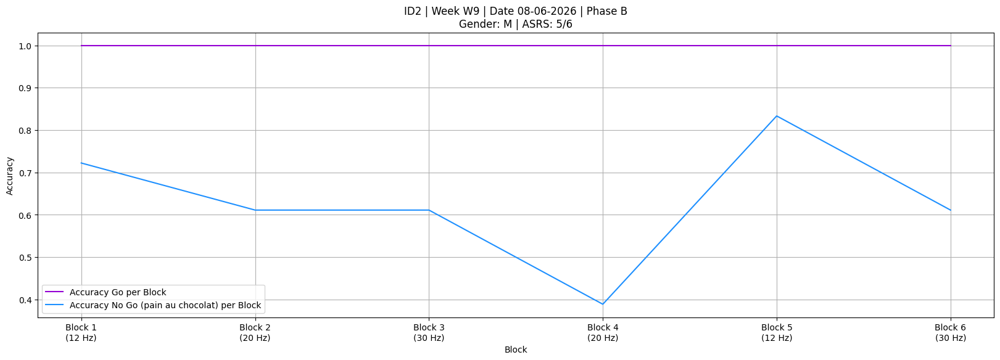

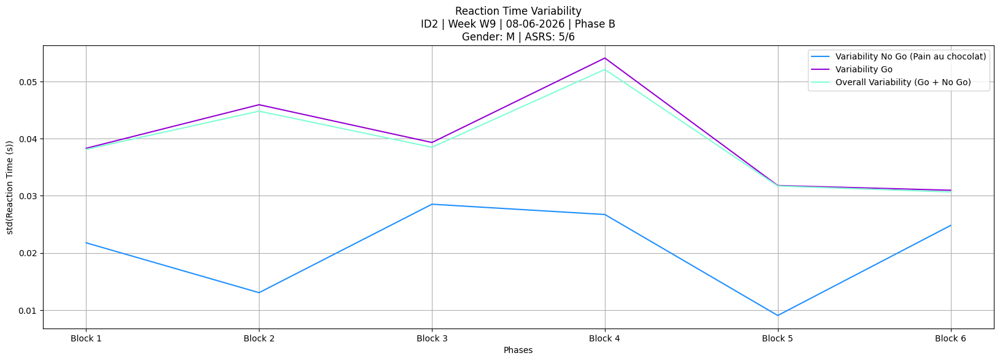

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,408.067259,Go,space,0.429696,Correct,False,False,2
1,1,1,409.080488,Go,space,0.366374,Correct,False,False,2
2,1,2,410.097073,No_Go,space,0.366725,Incorrect,False,True,2
3,1,3,411.113983,No_Go,NaN,NaN,Correct,False,False,2
4,1,4,412.130427,Go,space,0.383292,Correct,False,False,2
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1069.394292,No_Go,NaN,NaN,Correct,False,False,2
536,6,536,1070.410729,Go,space,0.350957,Correct,False,False,2
537,6,537,1071.427423,Go,space,0.334378,Correct,False,False,2
538,6,538,1072.444129,Go,space,0.333404,Correct,False,False,2


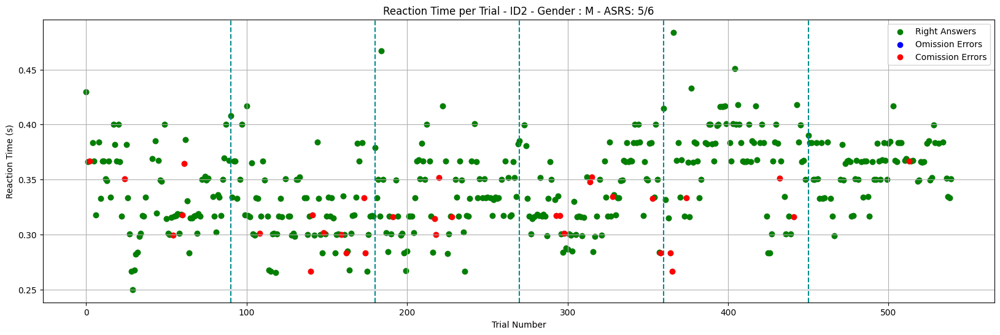

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 11.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=-5.030950


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 10.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 12.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


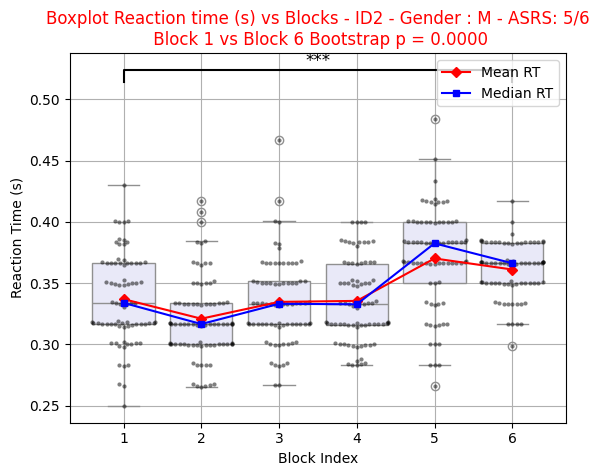

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

SESSION DATE: 2026-06-10 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
13,2026-06-10,B,"20,20,30,30,12,12"


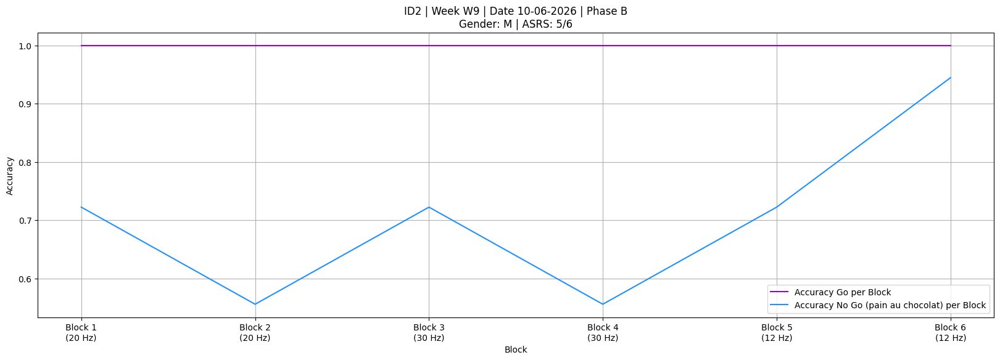

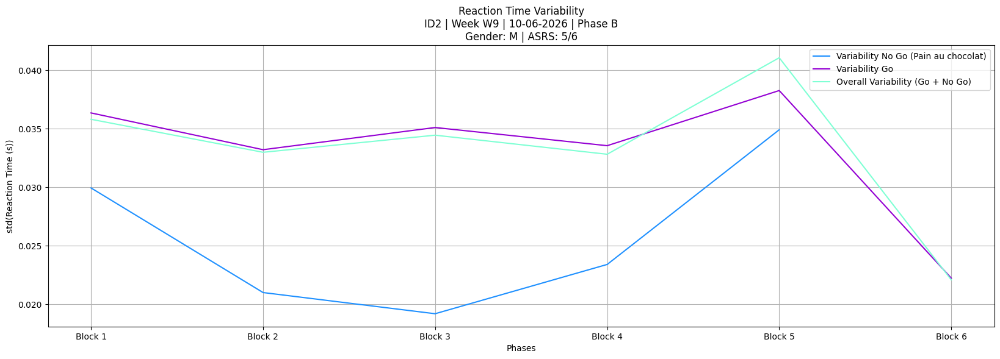

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,367.460256,Go,space,0.476919,Correct,False,False,2
1,1,1,368.471961,Go,space,0.365169,Correct,False,False,2
2,1,2,369.487094,No_Go,space,0.367142,Incorrect,False,True,2
3,1,3,370.504225,Go,space,0.382818,Correct,False,False,2
4,1,4,371.520298,Go,space,0.334235,Correct,False,False,2
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1042.260181,Go,space,0.349270,Correct,False,False,2
536,6,536,1043.276086,Go,space,0.350504,Correct,False,False,2
537,6,537,1044.293830,Go,space,0.348798,Correct,False,False,2
538,6,538,1045.310640,Go,space,0.384422,Correct,False,False,2


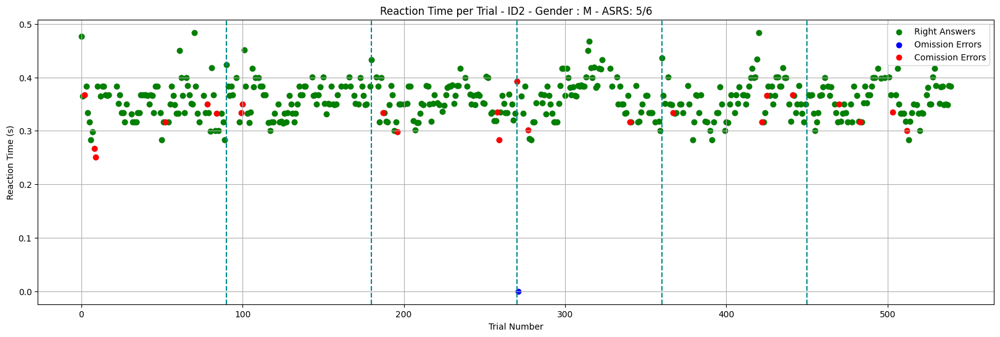

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=-0.892404


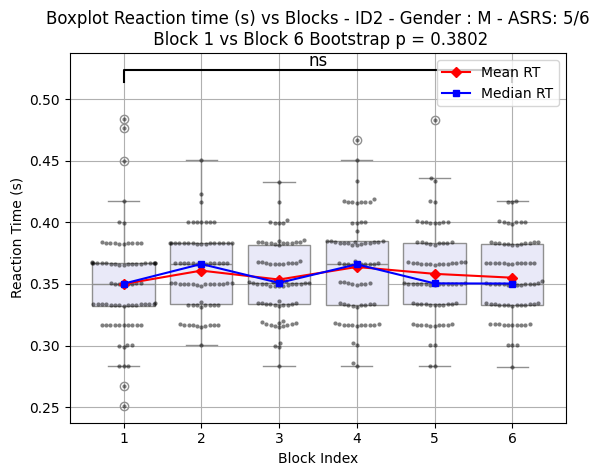

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 4',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778}]

SESSION DATE: 2026-06-12 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
14,2026-06-12,B,"20,12,12,30,30,20"


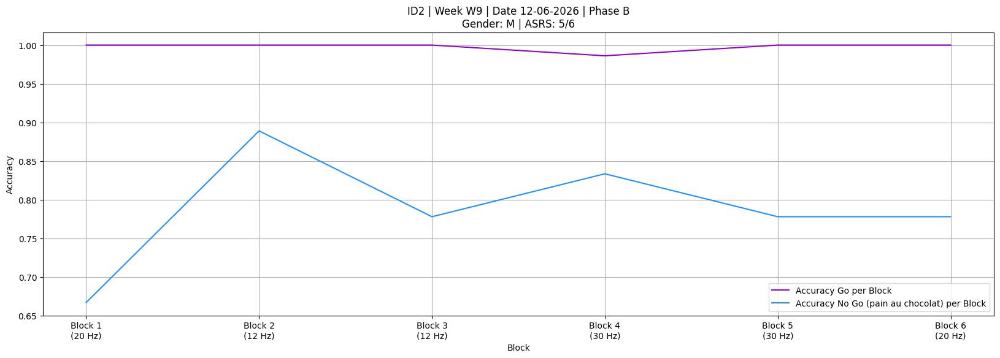

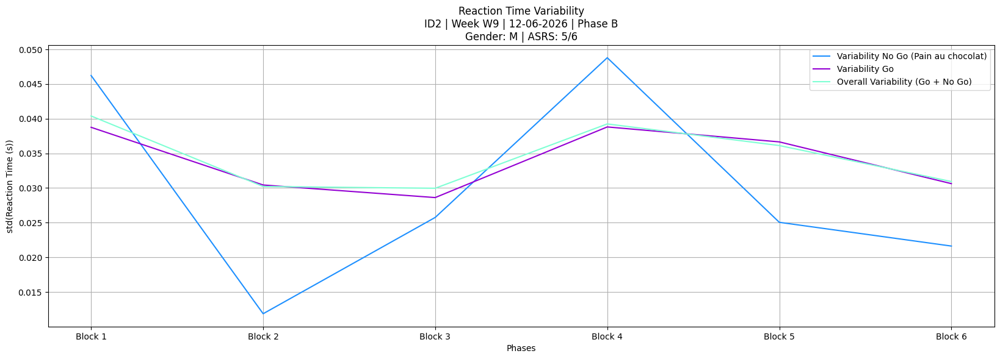

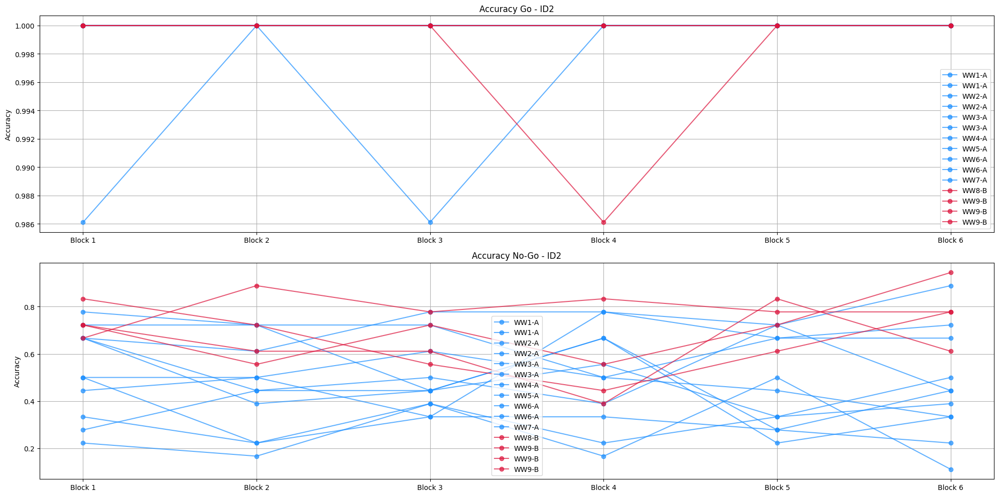

DATE: 2026-06-04 00:00:00
DATE: 2026-06-08 00:00:00
DATE: 2026-06-10 00:00:00
DATE: 2026-06-12 00:00:00


,DATE,PHASE,Go_12,Go_20,Go_30,NoGo_12,NoGo_20,NoGo_30,MeanGo,MeanNoGo
0,2026-04-13,A,0.997685,0.997685,0.997685,0.314815,0.314815,0.314815,NaN,NaN
1,2026-04-17,A,1.000000,1.000000,1.000000,0.472222,0.472222,0.472222,NaN,NaN
2,2026-04-21,A,1.000000,1.000000,1.000000,0.398148,0.398148,0.398148,NaN,NaN
3,2026-04-23,A,1.000000,1.000000,1.000000,0.620370,0.620370,0.620370,NaN,NaN
4,2026-04-27,A,1.000000,1.000000,1.000000,0.287037,0.287037,0.287037,NaN,NaN
5,2026-04-30,A,1.000000,1.000000,1.000000,0.287037,0.287037,0.287037,NaN,NaN
6,2026-05-07,A,1.000000,1.000000,1.000000,0.527778,0.527778,0.527778,NaN,NaN
7,2026-05-11,A,1.000000,1.000000,1.000000,0.546296,0.546296,0.546296,NaN,NaN
8,2026-05-19,A,1.000000,1.000000,1.000000,0.694444,0.694444,0.694444,NaN,NaN
9,2026-05-22,A,0.997685,0.997685,0.997685,0.481481,0.481481,0.481481,NaN,NaN


t=0.000000


/tmp/ipykernel_1316/346653522.py:91: RuntimeWarning: invalid value encountered in scalar divide
  t_distrib[b] = (np.mean(draw_x)-np.mean(draw_y))/np.sqrt(np.var(draw_x)/n+np.var(draw_y)/m)


t=-5.184249
t=-0.962786
t=-1.028992


/tmp/ipykernel_1316/346653522.py:91: RuntimeWarning: divide by zero encountered in scalar divide
  t_distrib[b] = (np.mean(draw_x)-np.mean(draw_y))/np.sqrt(np.var(draw_x)/n+np.var(draw_y)/m)


t=1.044466
t=-2.009712
Go A-A   p = 1.0690
Go A-B   p = 0.1536
Go B-B   p = 0.1502
NoGo A-A p = 0.0002
NoGo A-B p = 0.3468
NoGo B-B p = 0.0630


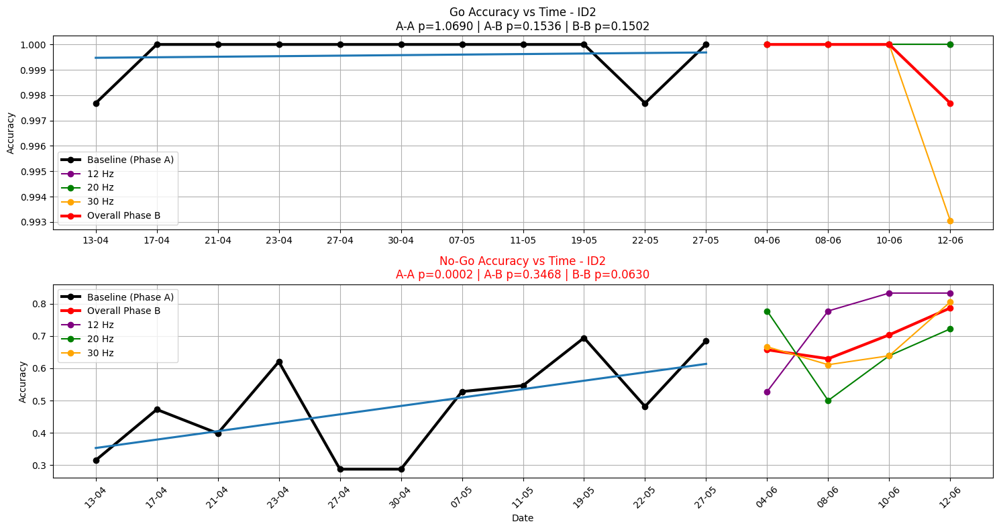

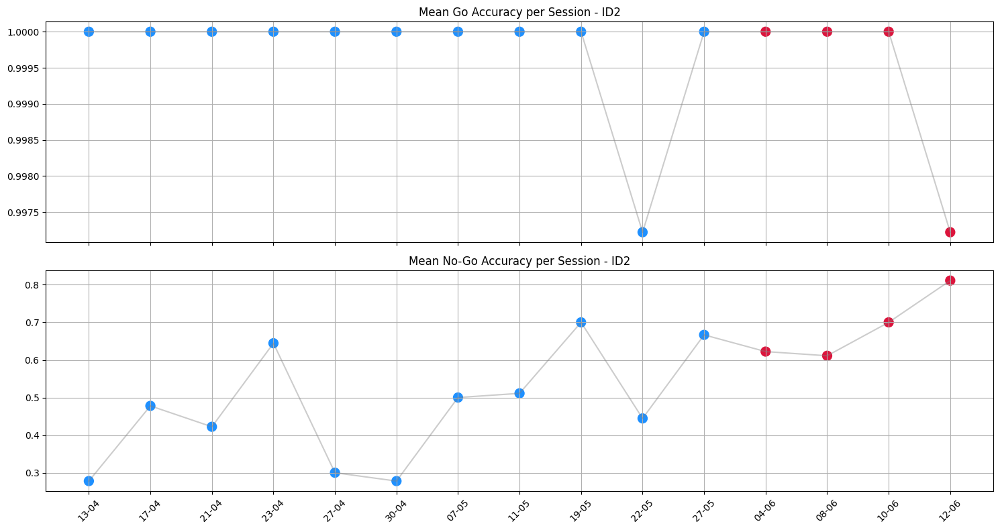

DATE: 2026-06-04 00:00:00
DATE: 2026-06-08 00:00:00
DATE: 2026-06-10 00:00:00
DATE: 2026-06-12 00:00:00


,DATE,Go_12,NoGo_12,Go_20,NoGo_20,Go_30,NoGo_30,MeanGo,MeanNoGo
0,2026-06-04,1.0,0.527778,1.0,0.777778,1.000000,0.666667,1.000000,0.657407
1,2026-06-08,1.0,0.777778,1.0,0.500000,1.000000,0.611111,1.000000,0.629630
2,2026-06-10,1.0,0.833333,1.0,0.638889,1.000000,0.638889,1.000000,0.703704
3,2026-06-12,1.0,0.833333,1.0,0.722222,0.993056,0.805556,0.997685,0.787037


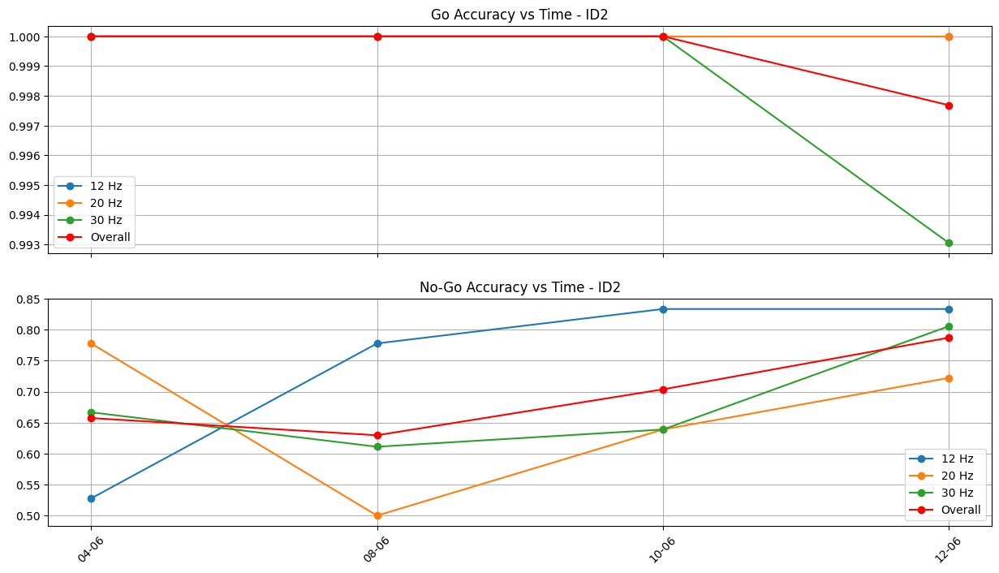

t=-1.871999
t=-1.622582
t=-3.800869


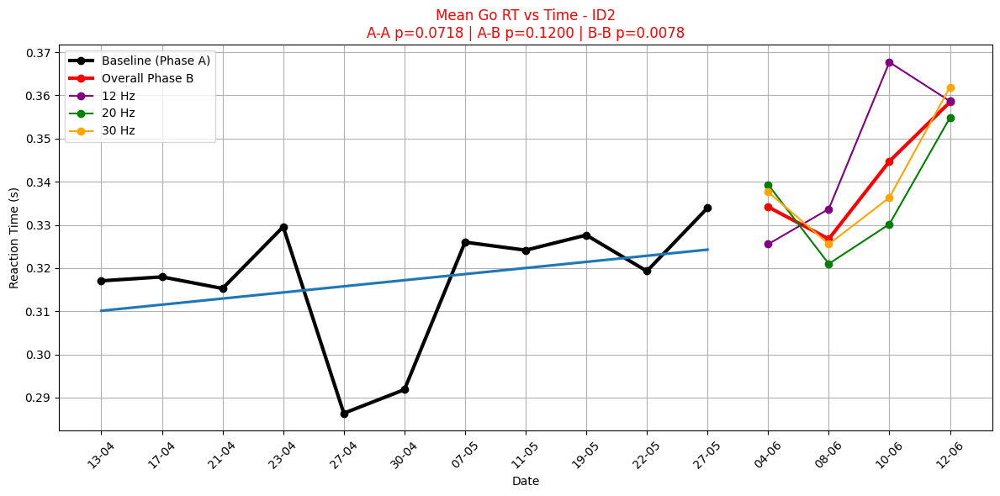

t=3.277399
t=1.382089
t=2.093179


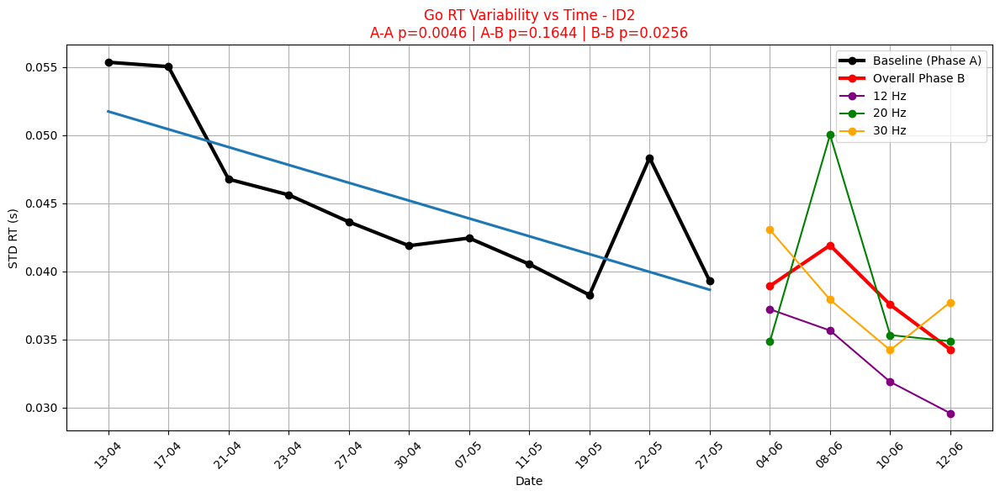

t=-4.884367
t=-1.198137
t=-1.781554


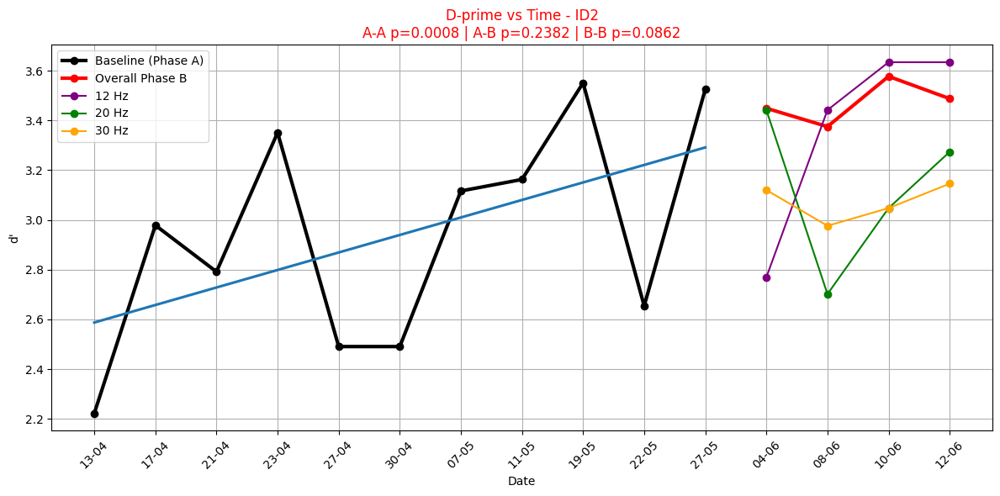

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime_All,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-13,A,5/6,NaN,NaN,NaN,2.222796,1.000000,0.277778,0.051647
1,2026-04-17,A,5/6,NaN,NaN,5.0,2.978204,1.000000,0.477778,0.049051
2,2026-04-21,A,5/6,NaN,NaN,5.0,2.791526,1.000000,0.422222,0.047167
3,2026-04-23,A,5/6,NaN,NaN,5.0,3.350802,1.000000,0.644444,0.037112
4,2026-04-30,A,5/6,8.0,5.0,0.0,2.490913,1.000000,0.277778,0.042391
5,2026-05-07,A,5/6,7.5,5.0,0.0,3.116293,1.000000,0.500000,0.040657
6,2026-05-11,A,5/6,7.0,5.0,5.0,3.162486,1.000000,0.511111,0.038901
7,2026-05-19,A,5/6,6.5,5.0,5.0,3.550654,1.000000,0.700000,0.036377
8,2026-05-22,A,5/6,7.5,5.0,5.0,2.654257,0.997222,0.444444,0.047688
9,2026-05-27,A,5/6,7.0,5.0,5.0,3.524718,1.000000,0.666667,0.035271


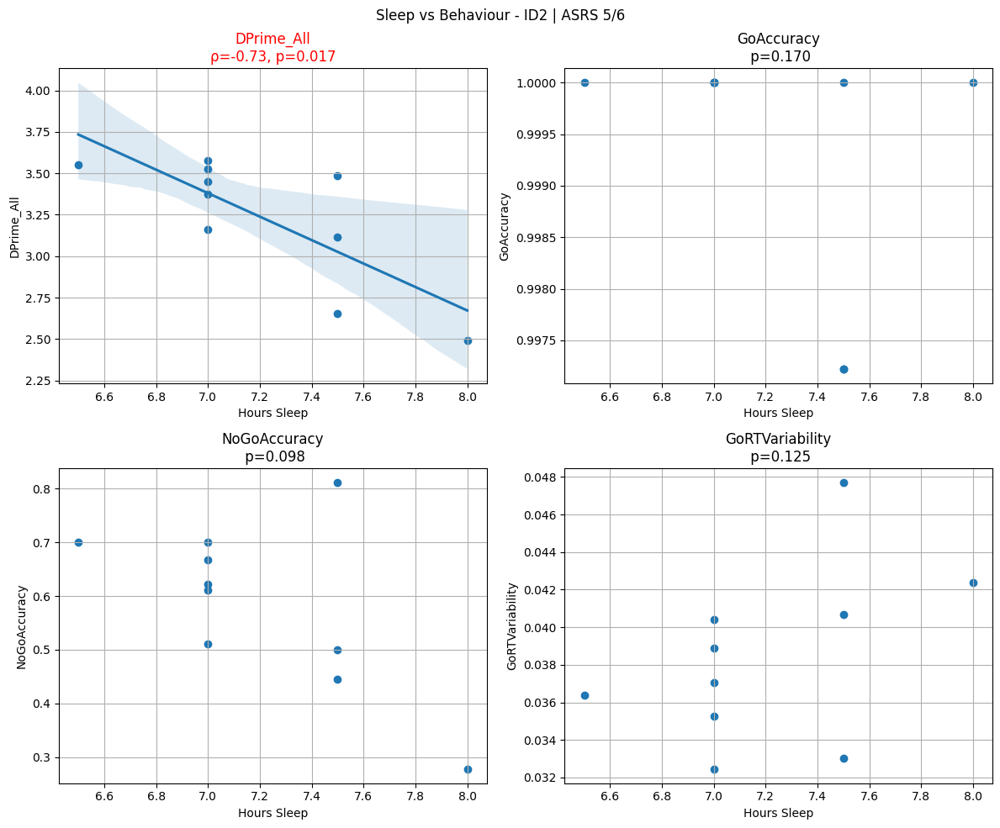

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime_All,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-13,A,5/6,NaN,NaN,NaN,2.222796,1.000000,0.277778,0.051647
1,2026-04-17,A,5/6,NaN,NaN,5.0,2.978204,1.000000,0.477778,0.049051
2,2026-04-21,A,5/6,NaN,NaN,5.0,2.791526,1.000000,0.422222,0.047167
3,2026-04-23,A,5/6,NaN,NaN,5.0,3.350802,1.000000,0.644444,0.037112
4,2026-04-30,A,5/6,8.0,5.0,0.0,2.490913,1.000000,0.277778,0.042391
5,2026-05-07,A,5/6,7.5,5.0,0.0,3.116293,1.000000,0.500000,0.040657
6,2026-05-11,A,5/6,7.0,5.0,5.0,3.162486,1.000000,0.511111,0.038901
7,2026-05-19,A,5/6,6.5,5.0,5.0,3.550654,1.000000,0.700000,0.036377
8,2026-05-22,A,5/6,7.5,5.0,5.0,2.654257,0.997222,0.444444,0.047688
9,2026-05-27,A,5/6,7.0,5.0,5.0,3.524718,1.000000,0.666667,0.035271


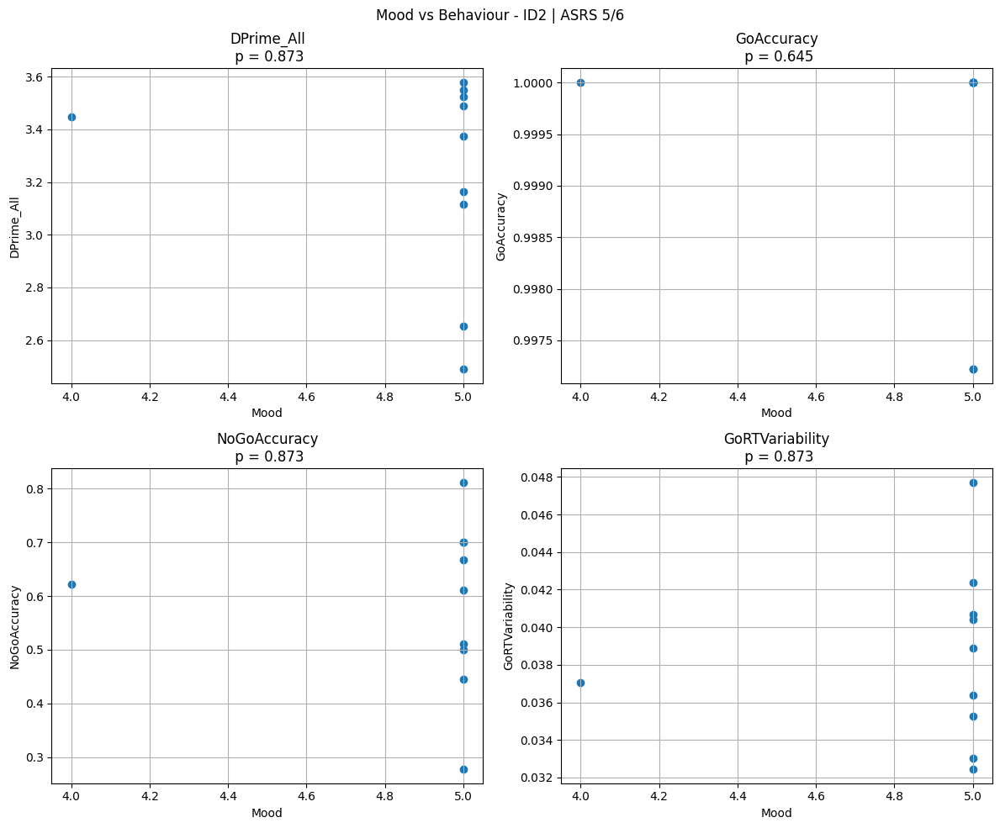

In [1040]:
df_clean_list = pipeline(id = 2)
#display(df_clean_list)

#**ID5**

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,258.734601,Go,space,0.731191,Correct,False,False,5
1,1,1,259.715691,Go,NaN,NaN,Incorrect,True,False,5
2,1,2,260.698903,Go,space,0.500298,Correct,False,False,5
3,1,3,261.683514,No_Go,space,0.582125,Incorrect,False,True,5
4,1,4,262.665608,Go,space,0.433281,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,893.536112,Go,space,0.383409,Correct,False,False,5
536,6,536,894.519862,Go,space,0.285612,Correct,False,False,5
537,6,537,895.503687,Go,space,0.283464,Correct,False,False,5
538,6,538,896.487412,No_Go,space,0.318972,Incorrect,False,True,5


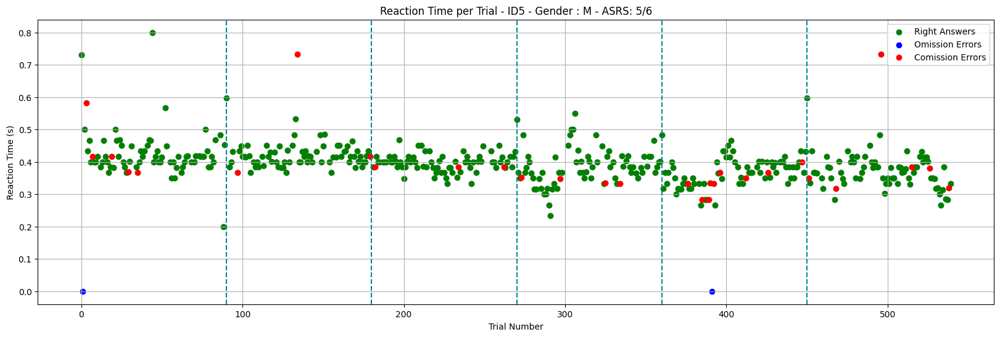

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 16.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=4.634002


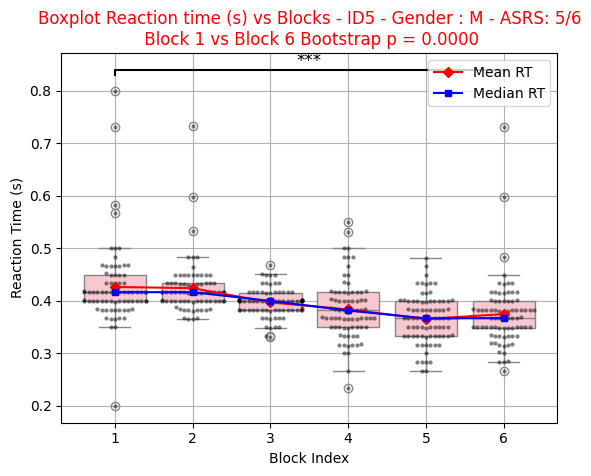

[{'Block': 'Block 1',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.5},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666}]

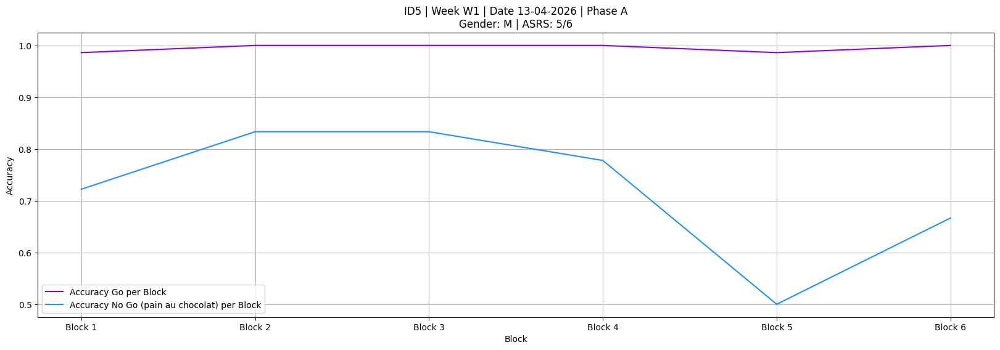

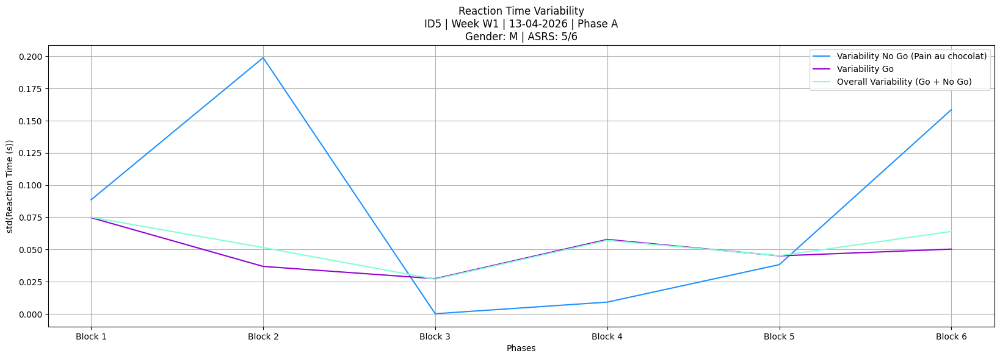

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,180.734145,Go,space,0.658446,Correct,False,False,5
1,1,1,181.775894,Go,space,0.316848,Correct,False,False,5
2,1,2,182.792681,No_Go,space,0.383721,Incorrect,False,True,5
3,1,3,183.809736,Go,space,0.433470,Correct,False,False,5
4,1,4,184.827355,No_Go,NaN,NaN,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,830.128019,No_Go,NaN,NaN,Correct,False,False,5
536,6,536,831.144665,Go,space,0.416727,Correct,False,False,5
537,6,537,832.161316,Go,space,0.583606,Correct,False,False,5
538,6,538,833.179446,Go,space,0.449887,Correct,False,False,5


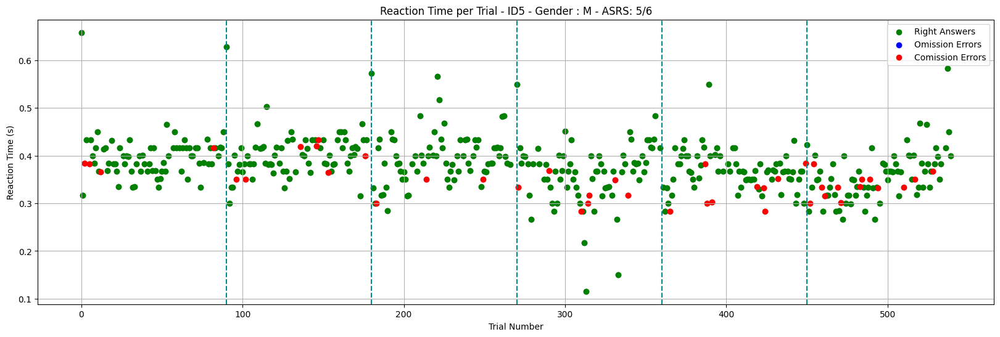

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=5.664157


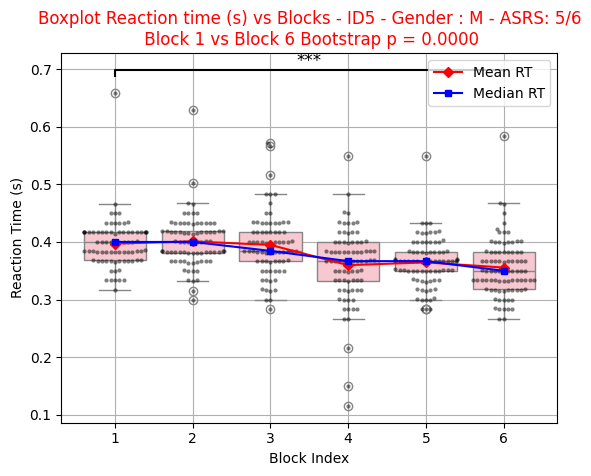

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 5', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2777777777777778}]

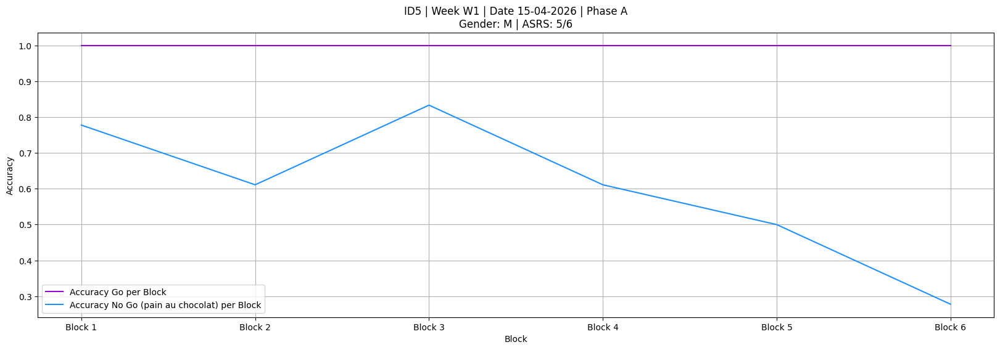

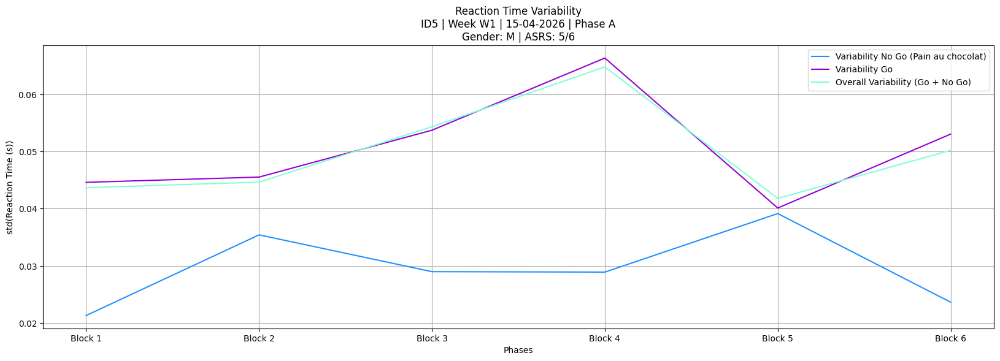

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,227.068008,Go,NaN,NaN,Incorrect,True,False,5
1,1,1,228.055413,Go,space,0.316891,Correct,False,False,5
2,1,2,229.038819,Go,space,0.283358,Correct,False,False,5
3,1,3,230.022296,No_Go,space,0.399961,Incorrect,False,True,5
4,1,4,231.005503,Go,space,0.417936,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,860.095387,No_Go,NaN,NaN,Correct,False,False,5
536,6,536,861.078598,Go,space,0.400158,Correct,False,False,5
537,6,537,862.061849,Go,space,0.401419,Correct,False,False,5
538,6,538,863.045482,Go,space,0.449999,Correct,False,False,5


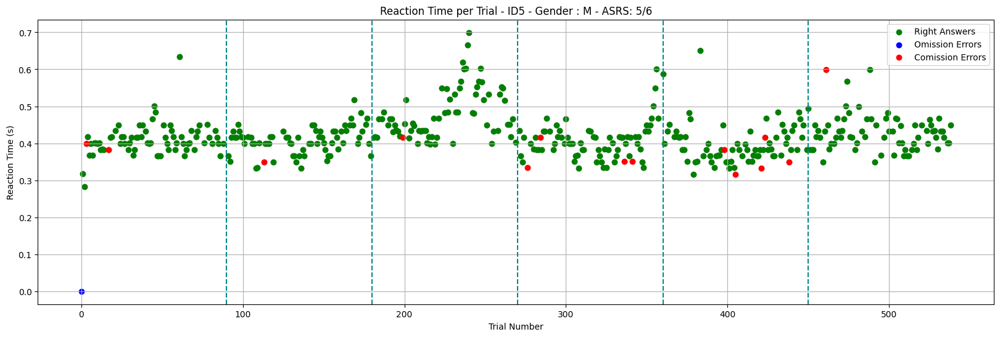

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=-2.779164


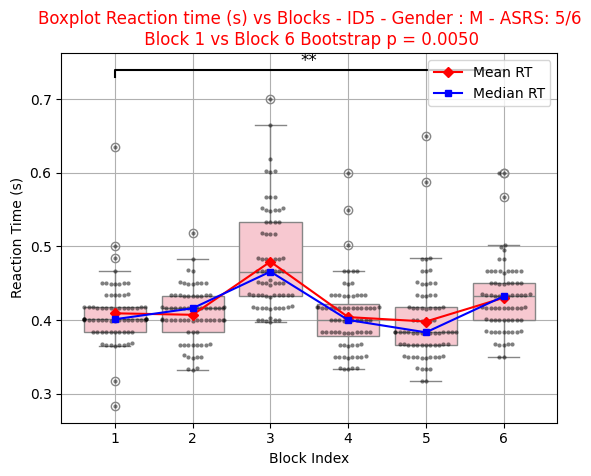

[{'Block': 'Block 1',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

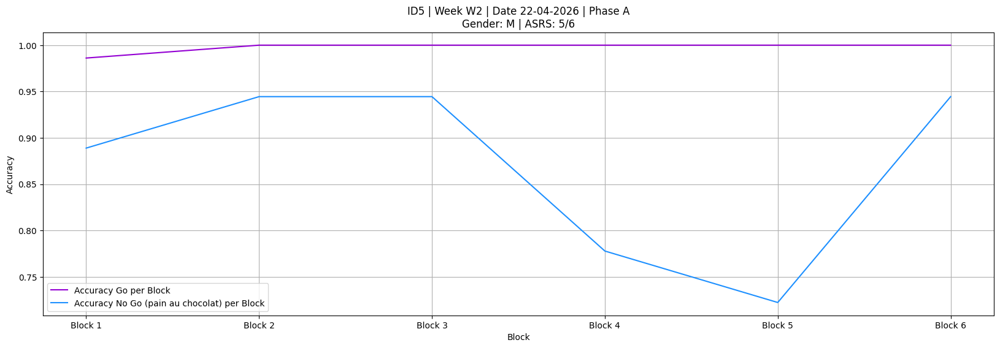

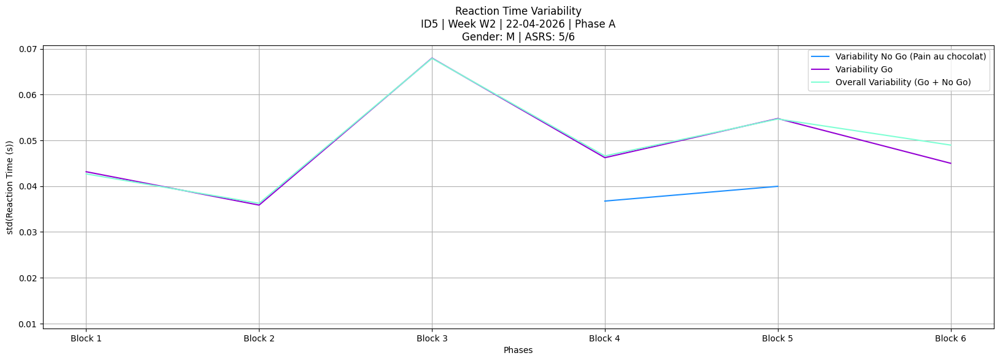

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,43.767349,Go,space,0.530731,Correct,False,False,5
1,1,1,44.797890,Go,space,0.316867,Correct,False,False,5
2,1,2,45.783427,No_Go,space,0.331339,Incorrect,False,True,5
3,1,3,46.764675,Go,space,0.350033,Correct,False,False,5
4,1,4,47.750200,Go,space,0.383249,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,673.256839,Go,space,0.417895,Correct,False,False,5
536,6,536,674.240409,Go,space,0.366740,Correct,False,False,5
537,6,537,675.223563,No_Go,NaN,NaN,Correct,False,False,5
538,6,538,676.208190,Go,space,0.382097,Correct,False,False,5


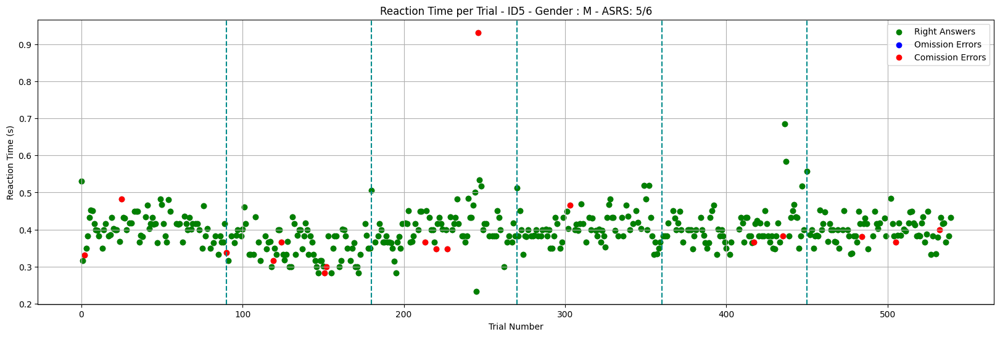

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=1.064893


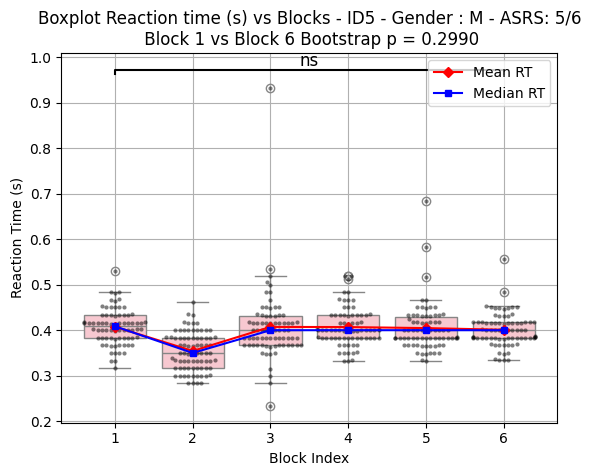

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334}]

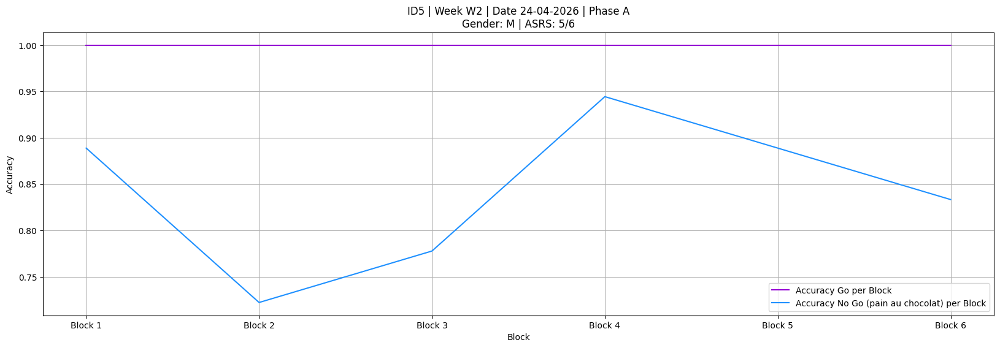

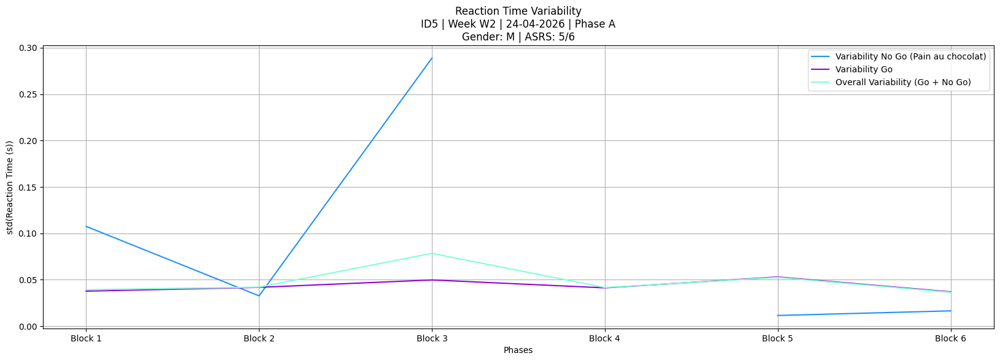

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,82.018600,Go,space,0.536906,Correct,False,False,5
1,1,1,83.004992,Go,space,0.349724,Correct,False,False,5
2,1,2,83.987414,Go,space,0.349571,Correct,False,False,5
3,1,3,84.969656,Go,space,0.399796,Correct,False,False,5
4,1,4,85.952205,Go,space,0.399487,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,711.463572,Go,space,0.382856,Correct,False,False,5
536,6,536,712.445974,No_Go,NaN,NaN,Correct,False,False,5
537,6,537,713.428295,Go,space,0.399607,Correct,False,False,5
538,6,538,714.410696,No_Go,NaN,NaN,Correct,False,False,5


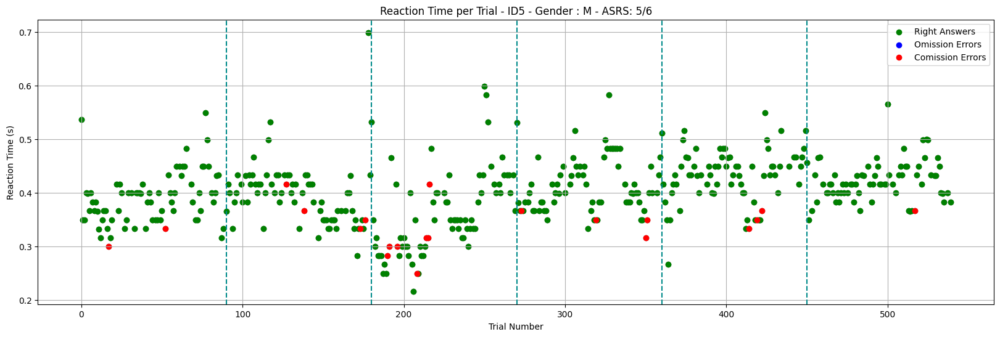

t=-4.558215


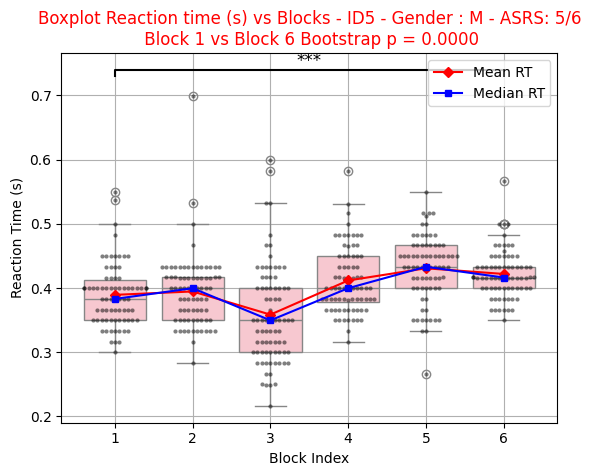

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

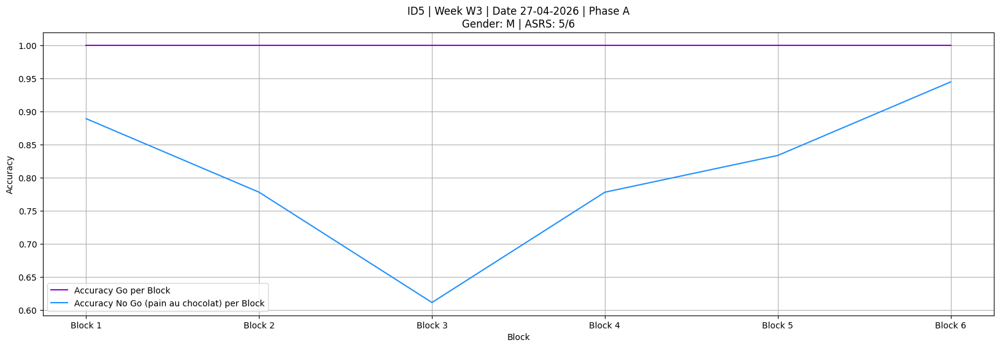

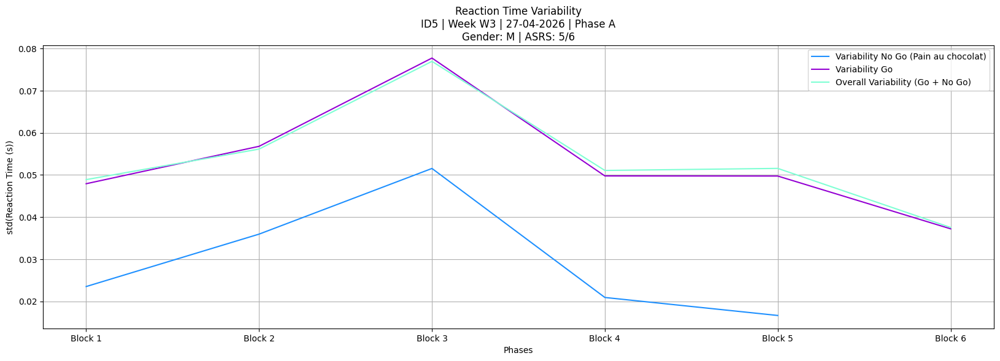

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,15.940126,Go,space,0.448761,Correct,False,False,5
1,1,1,16.955041,Go,space,0.366376,Correct,False,False,5
2,1,2,17.972203,No_Go,NaN,NaN,Correct,False,False,5
3,1,3,18.987840,Go,space,0.416317,Correct,False,False,5
4,1,4,20.003586,Go,space,0.399688,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,663.113950,Go,space,0.466247,Correct,False,False,5
536,6,536,664.129669,Go,space,0.482937,Correct,False,False,5
537,6,537,665.145368,Go,space,0.532785,Correct,False,False,5
538,6,538,666.160849,Go,space,0.416373,Correct,False,False,5


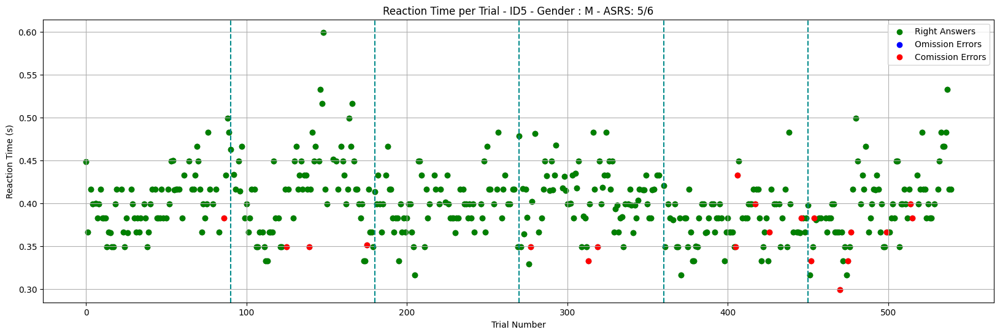

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=0.639964


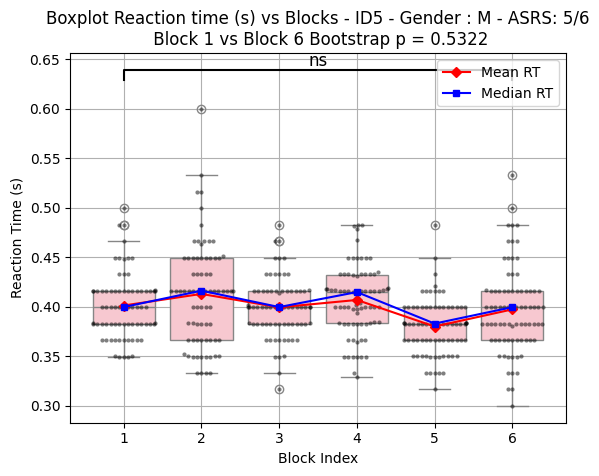

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556}]

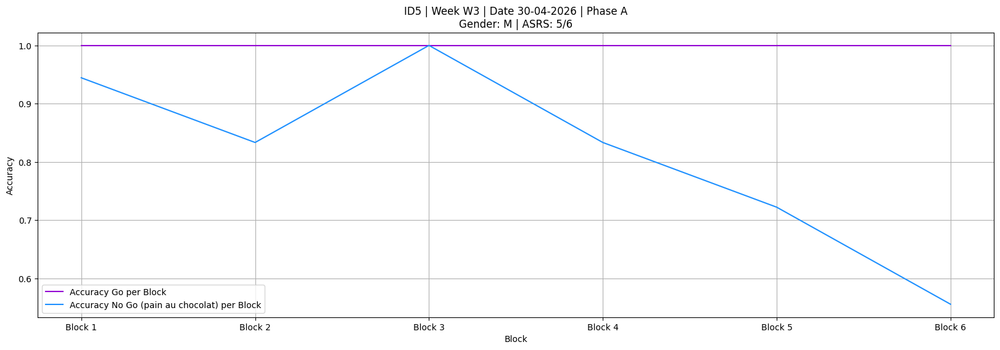

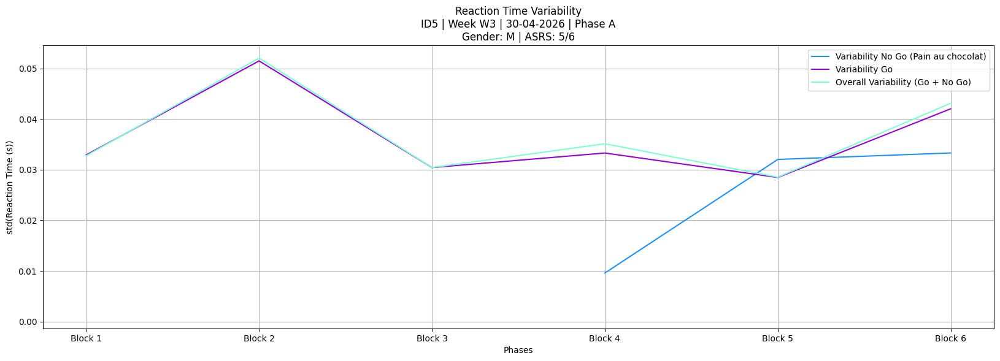

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,25.706593,Go,space,0.658451,Correct,False,False,5
1,1,1,26.731353,No_Go,space,0.532869,Incorrect,False,True,5
2,1,2,27.748532,Go,space,0.416375,Correct,False,False,5
3,1,3,28.764260,Go,space,0.416332,Correct,False,False,5
4,1,4,29.780049,Go,space,0.451699,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,673.986908,No_Go,NaN,NaN,Correct,False,False,5
536,6,536,675.002495,Go,space,0.383137,Correct,False,False,5
537,6,537,676.018365,Go,space,0.366098,Correct,False,False,5
538,6,538,677.033898,Go,space,0.399646,Correct,False,False,5


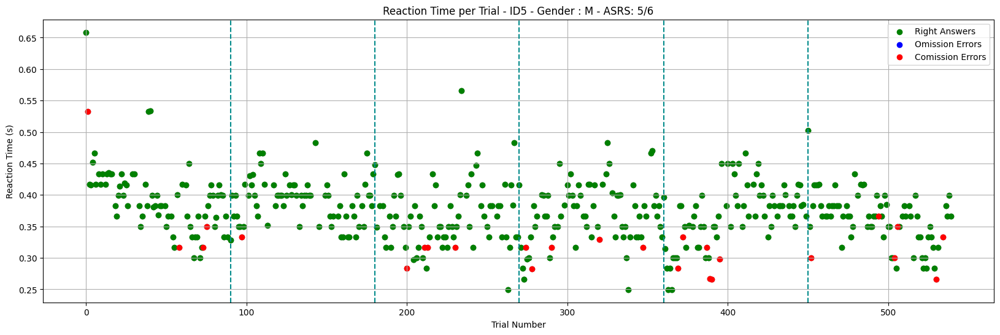

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=4.329961


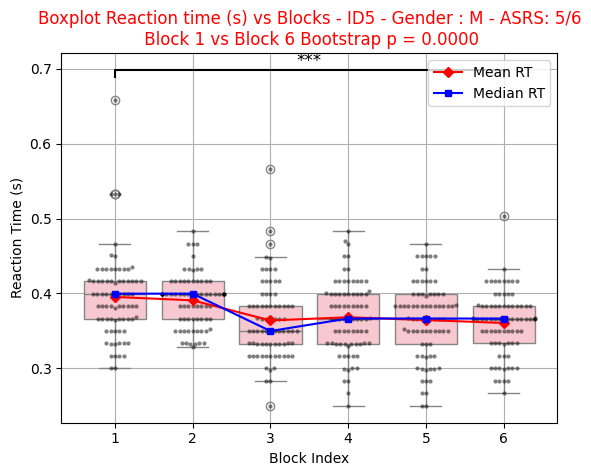

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666}]

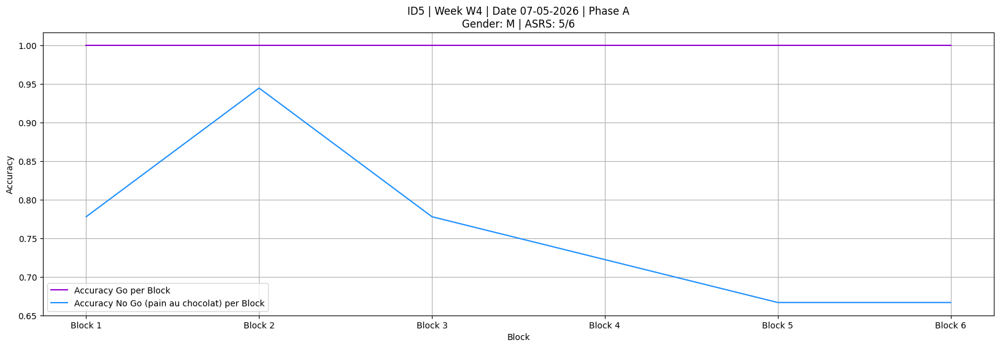

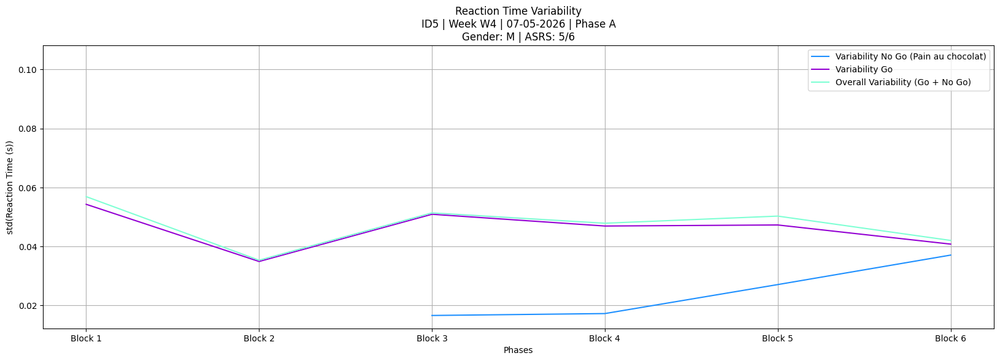

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,330.296360,Go,space,0.751084,Correct,False,False,5
1,1,1,331.328458,No_Go,NaN,NaN,Correct,False,False,5
2,1,2,332.344690,No_Go,NaN,NaN,Correct,False,False,5
3,1,3,333.361291,Go,space,0.467982,Correct,False,False,5
4,1,4,334.377762,Go,space,0.400105,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,981.138304,No_Go,NaN,NaN,Correct,False,False,5
536,6,536,982.153924,No_Go,space,0.299928,Incorrect,False,True,5
537,6,537,983.170475,Go,space,0.350055,Correct,False,False,5
538,6,538,984.186969,Go,space,0.516779,Correct,False,False,5


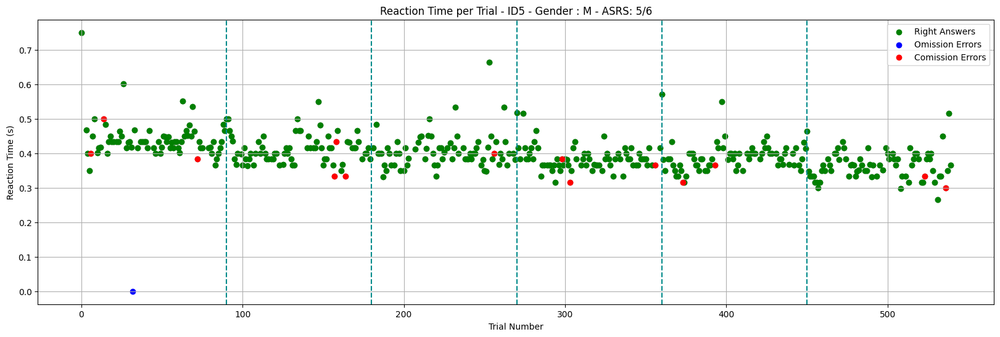

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 17.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=9.784412


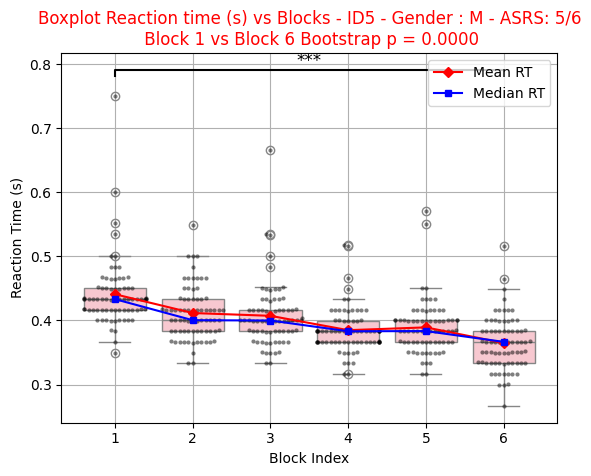

[{'Block': 'Block 1',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

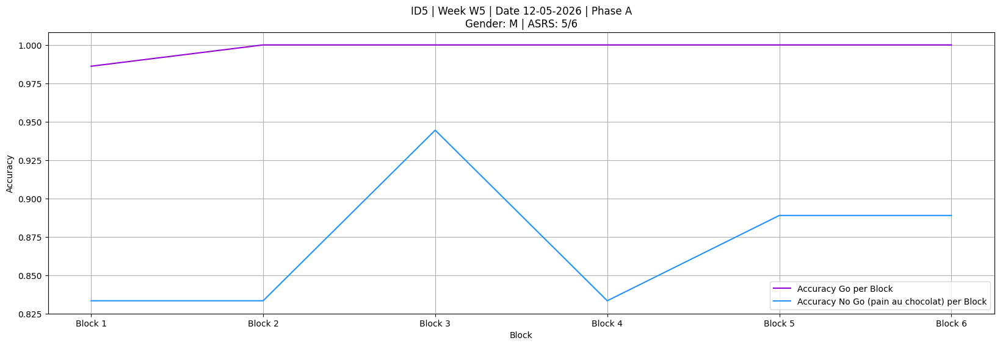

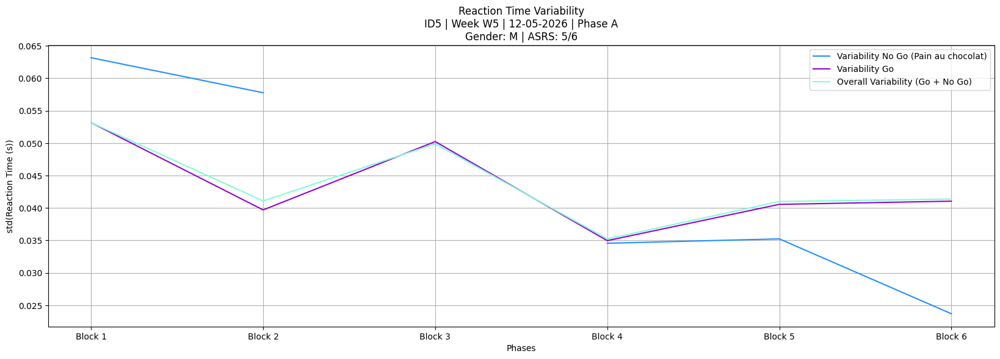

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,172.781309,No_Go,space,0.416412,Incorrect,False,True,5
1,1,1,173.814766,Go,space,0.332880,Correct,False,False,5
2,1,2,174.830618,Go,space,0.450310,Correct,False,False,5
3,1,3,175.847655,Go,space,0.483356,Correct,False,False,5
4,1,4,176.864034,Go,space,0.400059,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,888.617461,Go,space,0.399886,Correct,False,False,5
536,6,536,889.633986,Go,space,0.416865,Correct,False,False,5
537,6,537,890.650629,No_Go,NaN,NaN,Correct,False,False,5
538,6,538,891.667556,Go,space,0.333330,Correct,False,False,5


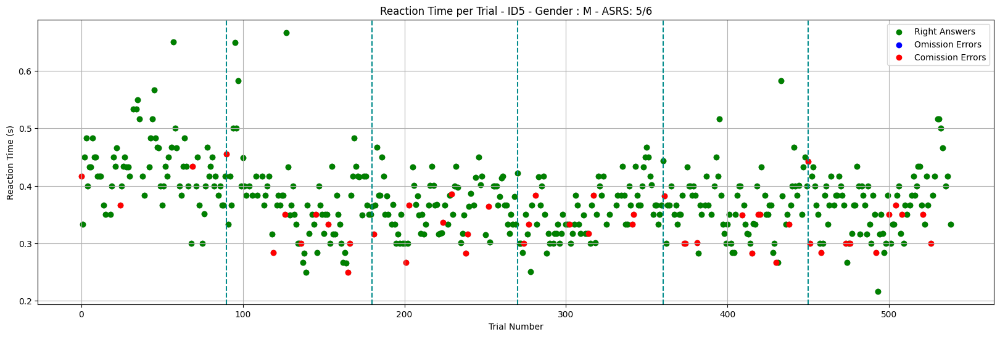

t=7.240290


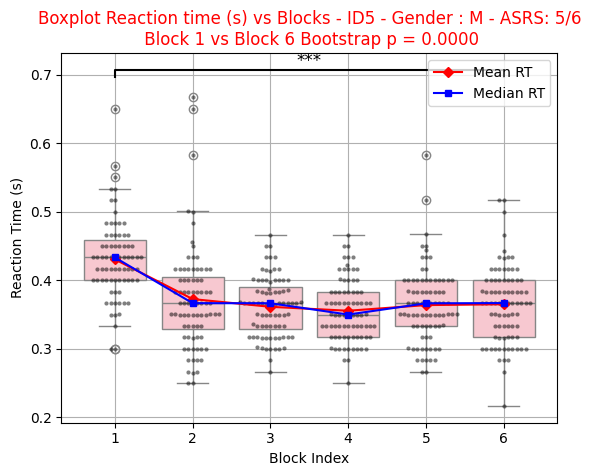

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889}]

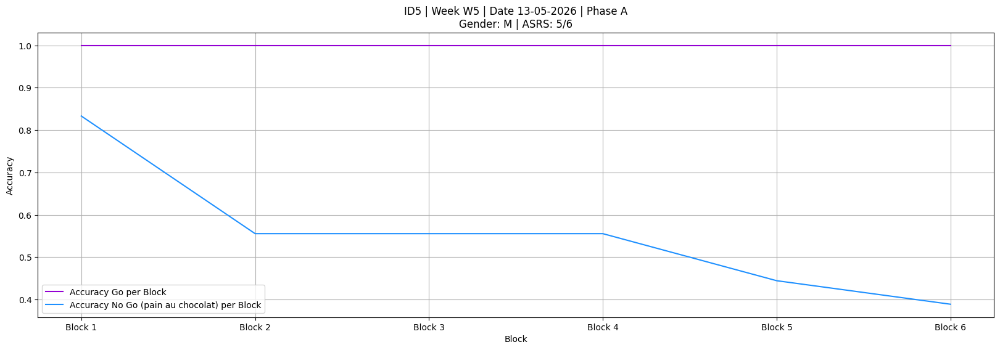

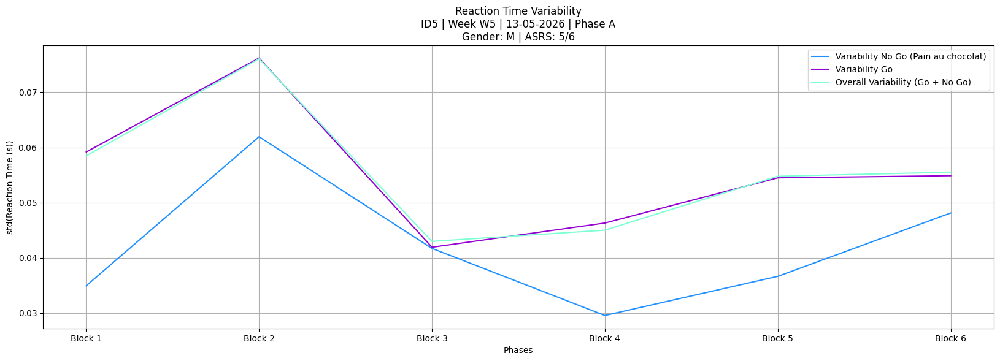

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,183.003932,Go,space,0.547861,Correct,False,False,5
1,1,1,184.035834,Go,space,0.449887,Correct,False,False,5
2,1,2,185.051852,No_Go,NaN,NaN,Correct,False,False,5
3,1,3,186.069867,Go,space,0.433424,Correct,False,False,5
4,1,4,187.086675,Go,space,0.401996,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,831.174161,No_Go,space,0.367009,Incorrect,False,True,5
536,6,536,832.191278,Go,space,0.416749,Correct,False,False,5
537,6,537,833.209751,No_Go,NaN,NaN,Correct,False,False,5
538,6,538,834.224224,Go,space,0.383274,Correct,False,False,5


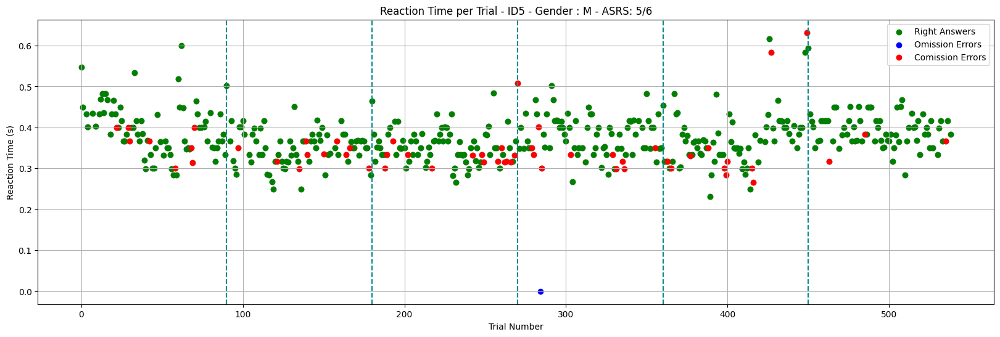

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 7.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=-0.229717


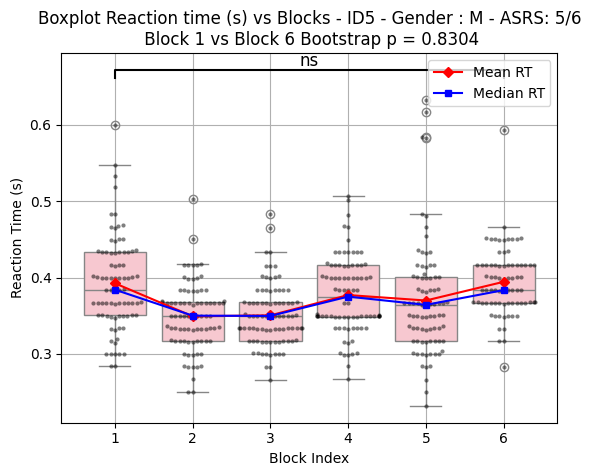

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2222222222222222},
 {'Block': 'Block 4',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334}]

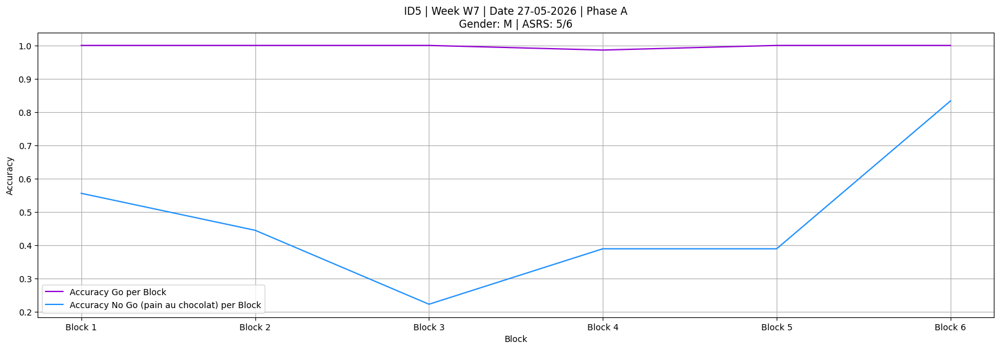

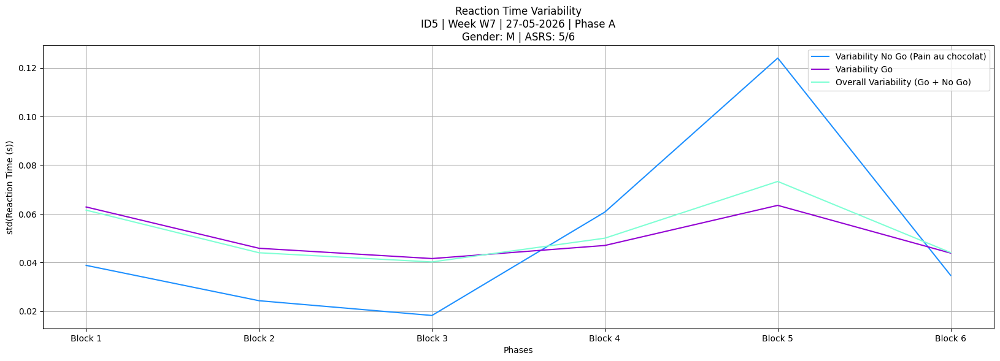

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,201.992747,Go,space,0.490718,Correct,False,False,5
1,1,1,203.016787,Go,space,0.383469,Correct,False,False,5
2,1,2,204.034991,Go,space,0.415126,Correct,False,False,5
3,1,3,205.050088,No_Go,NaN,NaN,Correct,False,False,5
4,1,4,206.068222,Go,space,0.415318,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,850.952991,Go,space,0.283393,Correct,False,False,5
536,6,536,851.969710,Go,space,0.349961,Correct,False,False,5
537,6,537,852.986233,Go,space,0.349950,Correct,False,False,5
538,6,538,854.002963,Go,space,0.366490,Correct,False,False,5


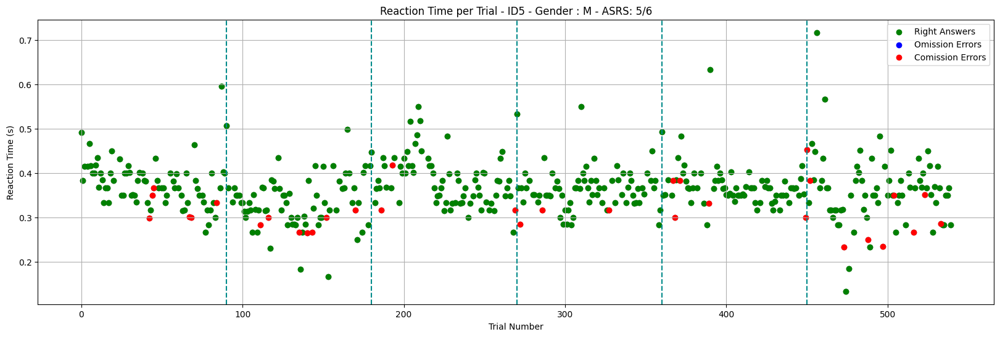

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=1.771798


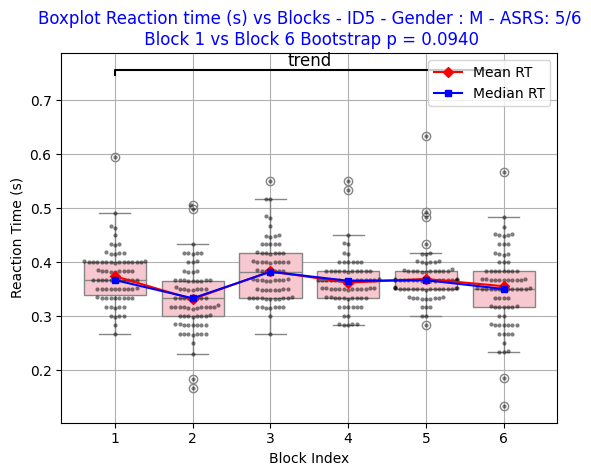

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5}]

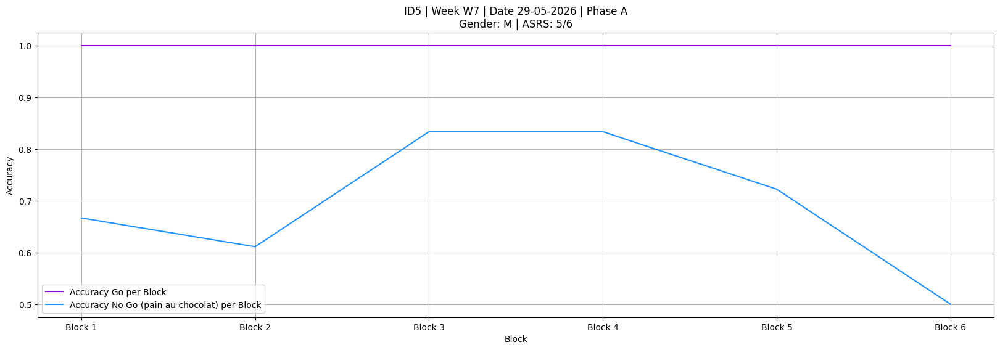

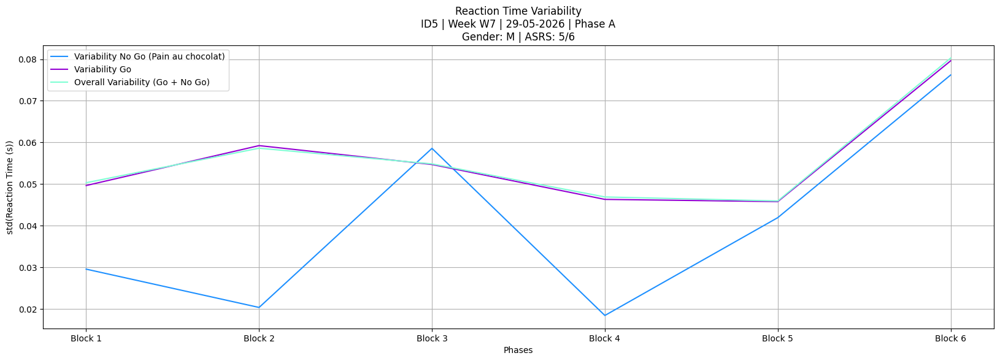

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,322.829382,Go,space,0.491314,Correct,False,False,5
1,1,1,323.836462,Go,space,0.350069,Correct,False,False,5
2,1,2,324.854016,Go,space,0.383881,Correct,False,False,5
3,1,3,325.871367,Go,space,0.349993,Correct,False,False,5
4,1,4,326.888305,Go,space,0.382862,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,971.151846,Go,space,0.412697,Correct,False,False,5
536,6,536,972.164709,No_Go,NaN,NaN,Correct,False,False,5
537,6,537,973.181355,Go,space,0.383266,Correct,False,False,5
538,6,538,974.198036,Go,space,0.383307,Correct,False,False,5


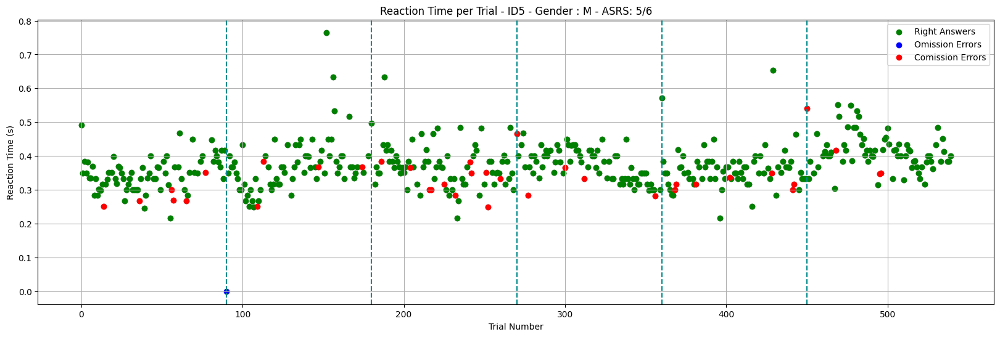

t=-8.144879


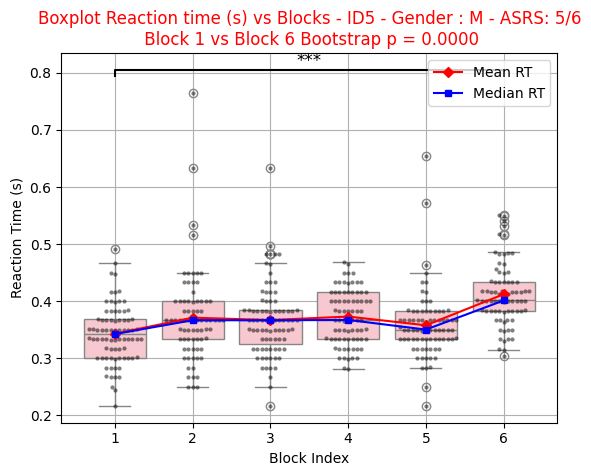

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 2',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778}]

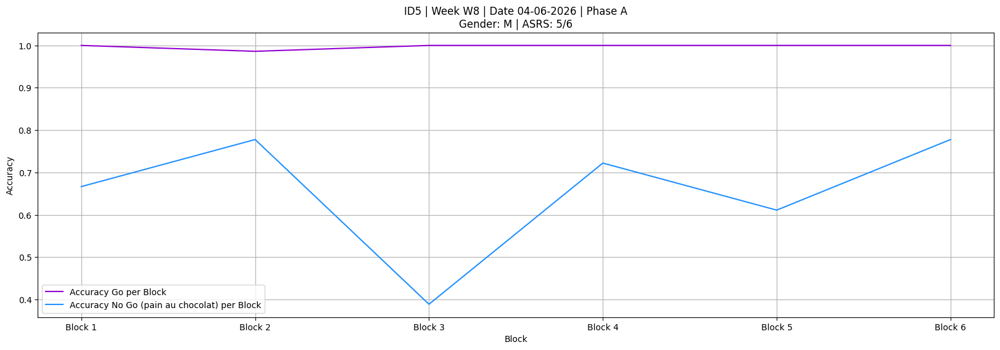

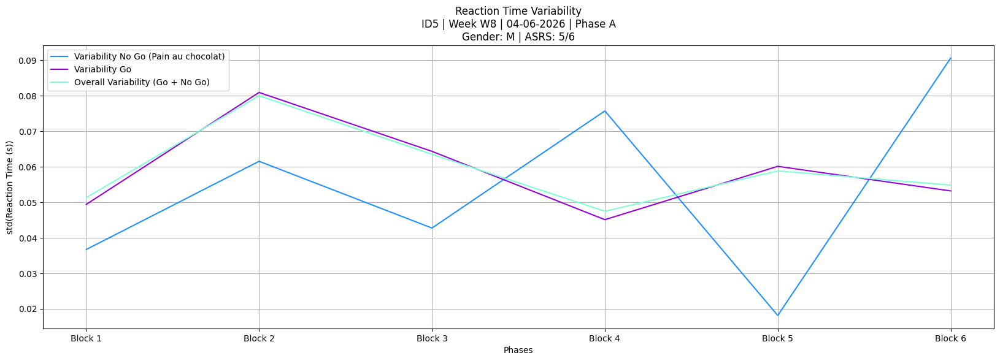

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,312.258263,Go,space,0.521883,Correct,False,False,5
1,1,1,313.263039,No_Go,NaN,NaN,Correct,False,False,5
2,1,2,314.279714,Go,space,0.400383,Correct,False,False,5
3,1,3,315.297711,Go,space,0.399477,Correct,False,False,5
4,1,4,316.313600,Go,space,0.399988,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,970.166015,Go,space,0.399956,Correct,False,False,5
536,6,536,971.183100,No_Go,NaN,NaN,Correct,False,False,5
537,6,537,972.199223,No_Go,space,0.333298,Incorrect,False,True,5
538,6,538,973.217468,Go,space,0.381995,Correct,False,False,5


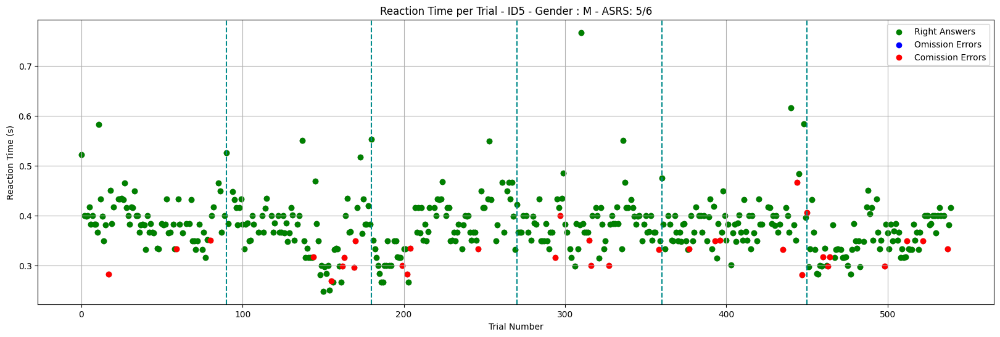

t=5.475039


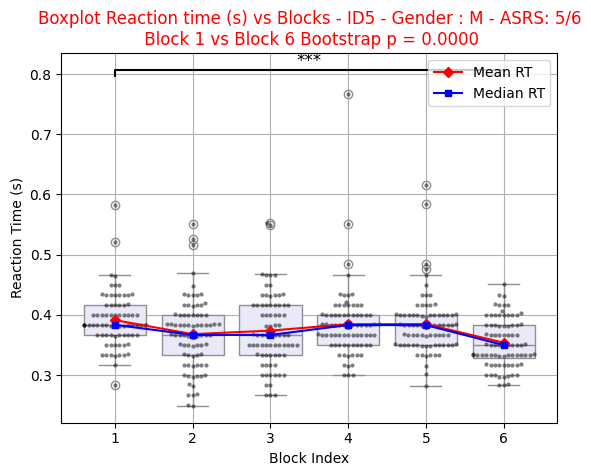

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556}]

SESSION DATE: 2026-06-05 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
12,2026-06-05,B,"30,12,20,20,12,30"


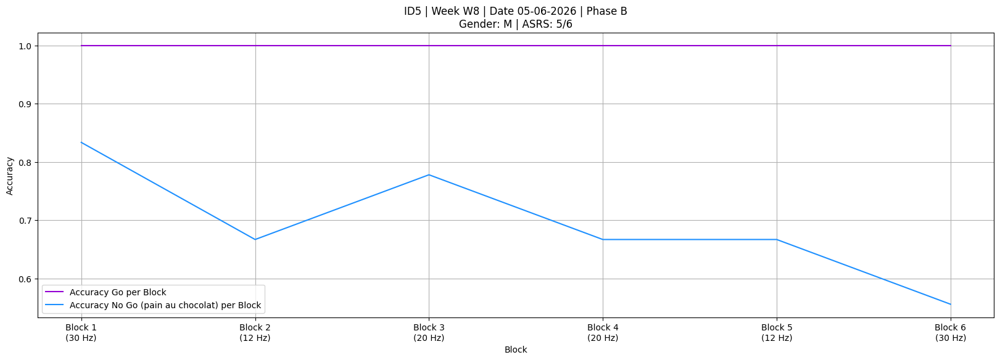

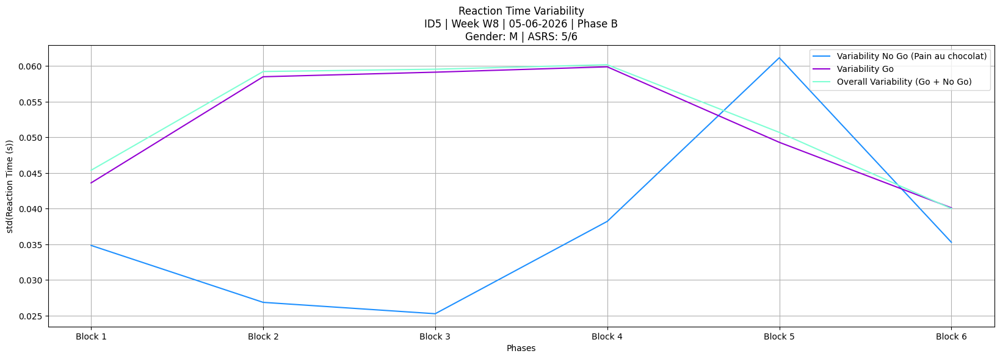

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,286.253589,Go,space,0.643685,Correct,False,False,5
1,1,1,287.263783,Go,space,0.517297,Correct,False,False,5
2,1,2,288.280225,Go,space,0.450144,Correct,False,False,5
3,1,3,289.296778,Go,space,0.384063,Correct,False,False,5
4,1,4,290.314087,Go,space,0.382857,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,934.811682,Go,space,0.316778,Correct,False,False,5
536,6,536,935.828464,Go,space,0.350112,Correct,False,False,5
537,6,537,936.845098,No_Go,NaN,NaN,Correct,False,False,5
538,6,538,937.861659,Go,space,0.316823,Correct,False,False,5


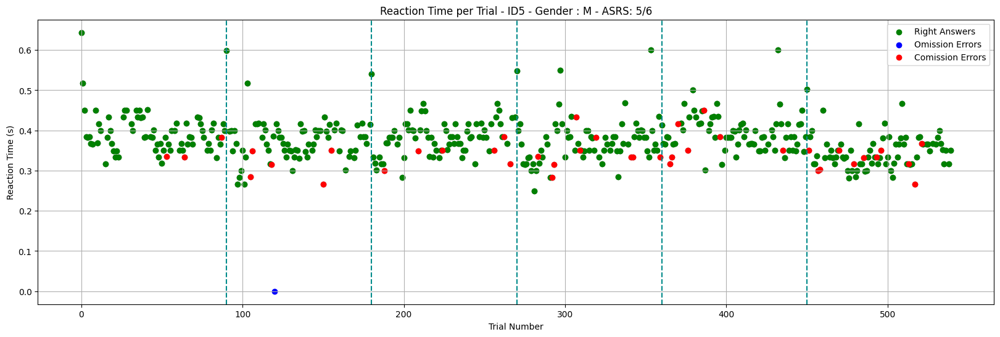

t=6.604931


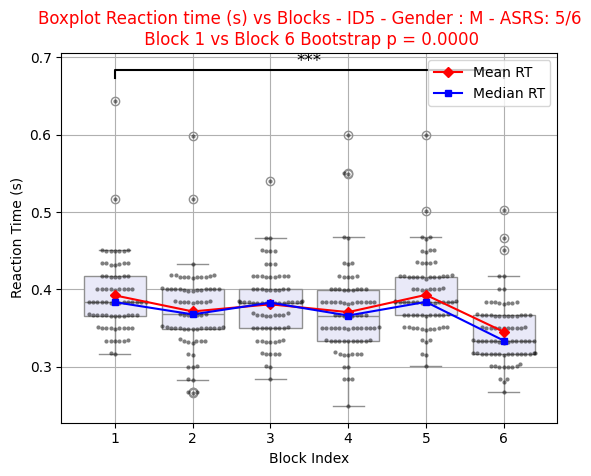

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 2',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889}]

SESSION DATE: 2026-06-08 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
13,2026-06-08,B,"30,20,12,12,20,30"


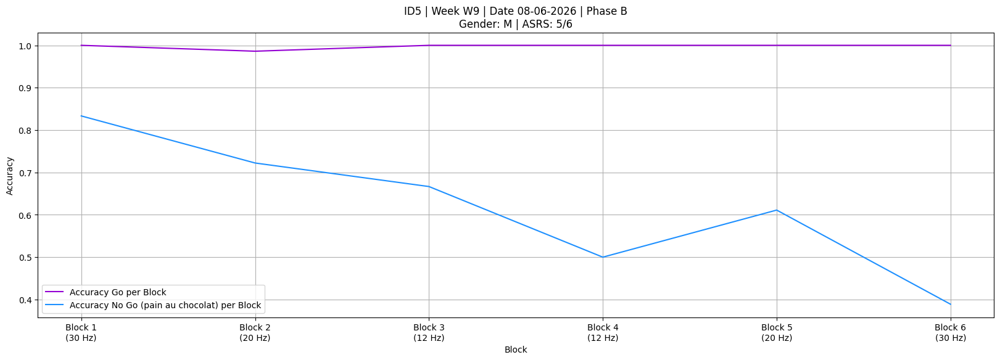

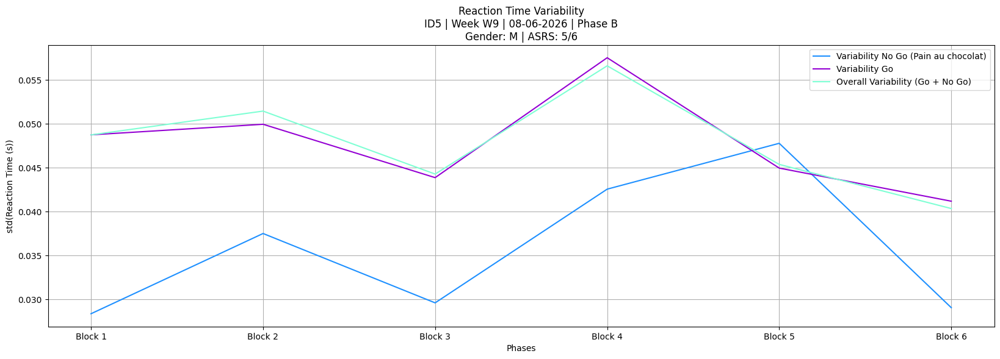

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,307.421301,No_Go,space,0.490437,Incorrect,False,True,5
1,1,1,308.428587,Go,space,0.449875,Correct,False,False,5
2,1,2,309.444942,Go,space,0.433539,Correct,False,False,5
3,1,3,310.461722,Go,space,0.383332,Correct,False,False,5
4,1,4,311.478347,Go,space,0.400243,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,955.612489,Go,space,0.332472,Correct,False,False,5
536,6,536,956.628134,Go,space,0.366593,Correct,False,False,5
537,6,537,957.645635,Go,space,0.400533,Correct,False,False,5
538,6,538,958.661774,Go,space,0.399875,Correct,False,False,5


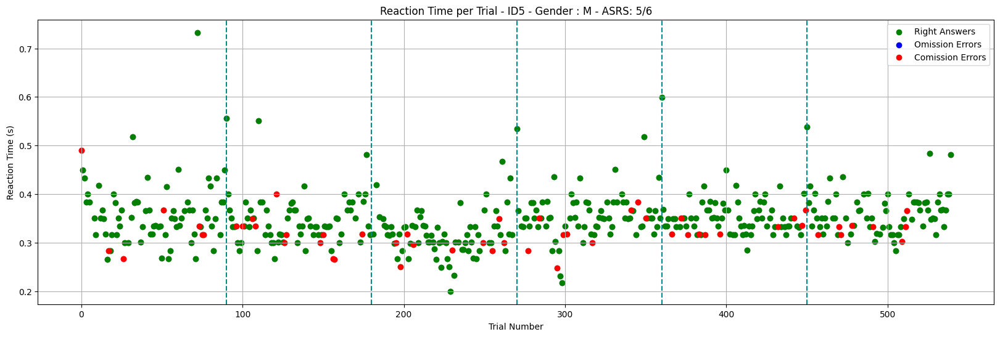

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 7.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 13.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=-0.139741


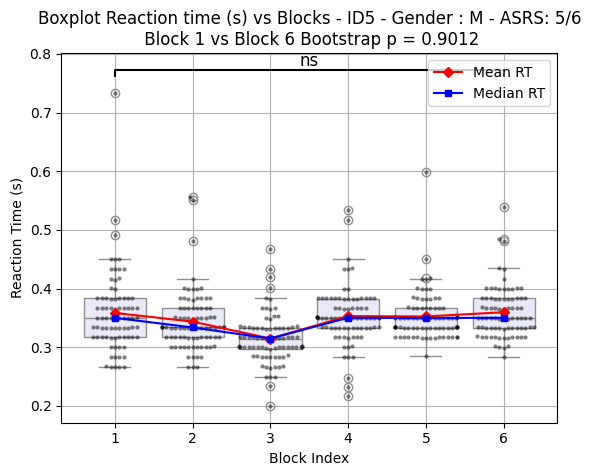

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3333333333333333},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556}]

SESSION DATE: 2026-06-10 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
14,2026-06-10,B,"20,30,30,20,12,12"


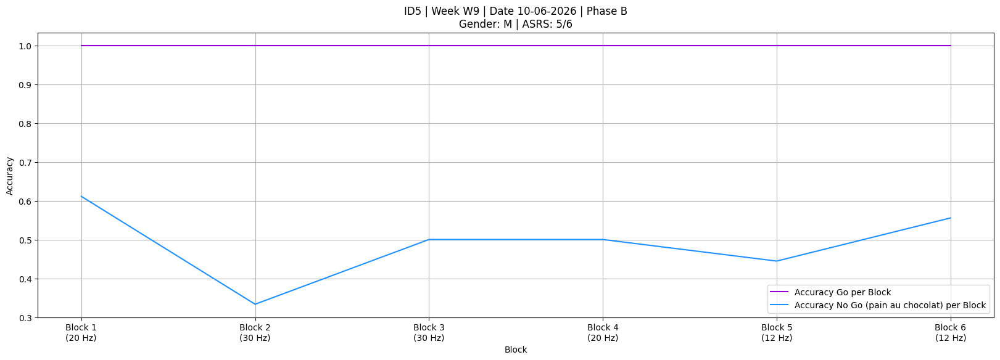

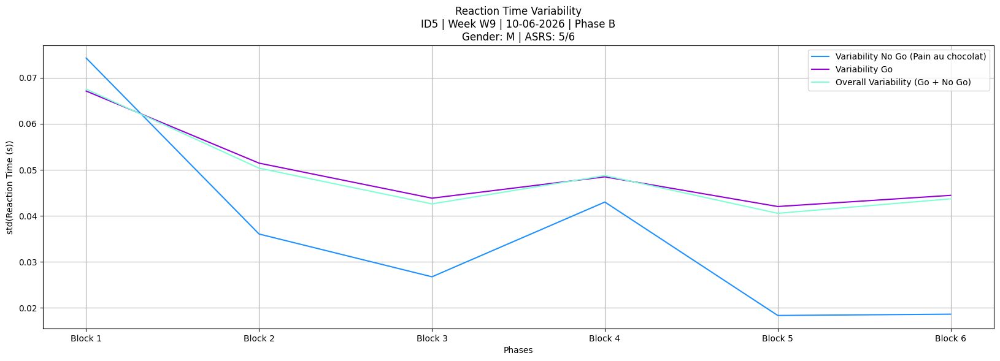

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,346.775667,Go,space,0.726944,Correct,False,False,5
1,1,1,347.785569,Go,space,0.450013,Correct,False,False,5
2,1,2,348.802399,Go,space,0.383736,Correct,False,False,5
3,1,3,349.819518,Go,space,0.416154,Correct,False,False,5
4,1,4,350.835519,Go,space,0.366907,Correct,False,False,5
...,...,...,...,...,...,...,...,...,...,...
535,6,535,999.585289,Go,space,0.400248,Correct,False,False,5
536,6,536,1000.602257,No_Go,space,0.349840,Incorrect,False,True,5
537,6,537,1001.619237,Go,space,0.416226,Correct,False,False,5
538,6,538,1002.635438,Go,space,0.400083,Correct,False,False,5


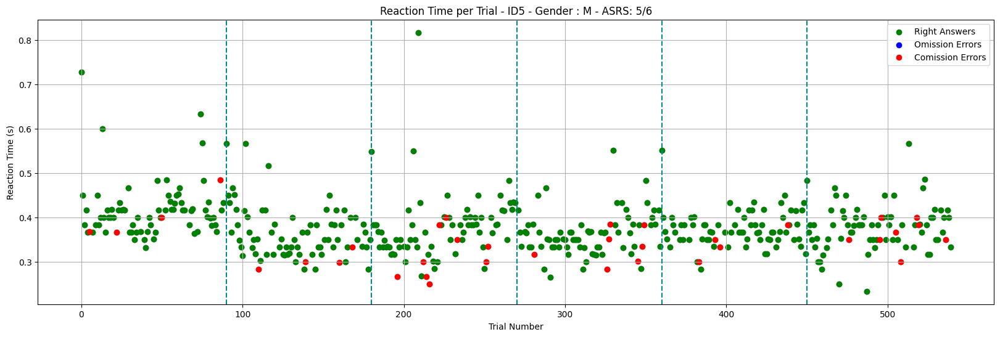

t=4.475984


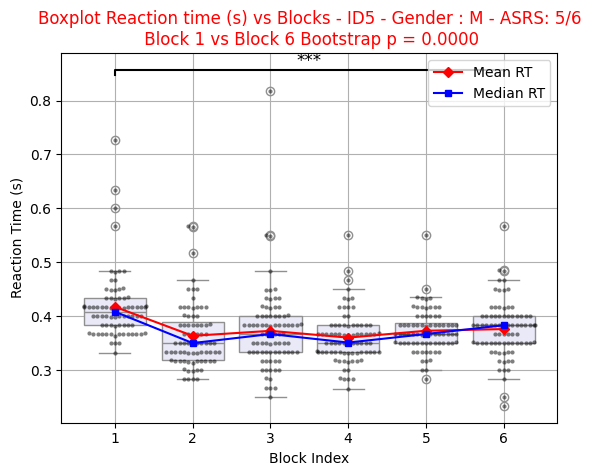

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556}]

SESSION DATE: 2026-06-12 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
15,2026-06-12,B,"30,20,12,20,30,12"


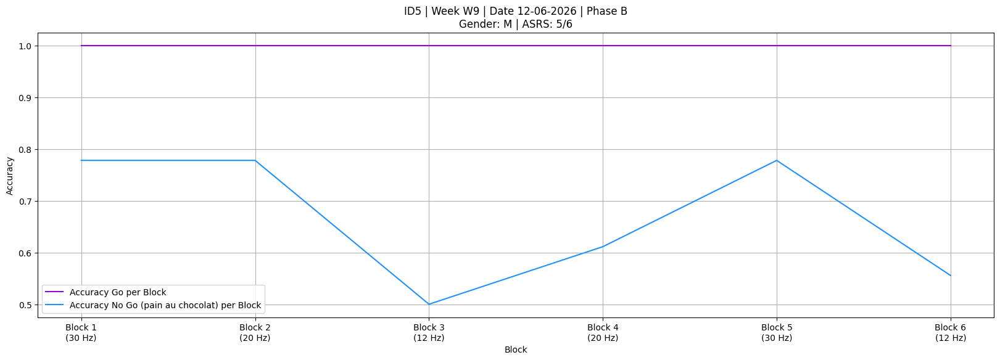

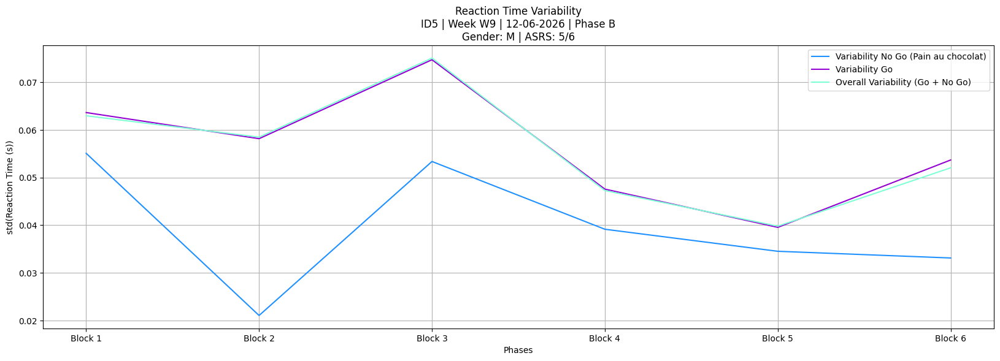

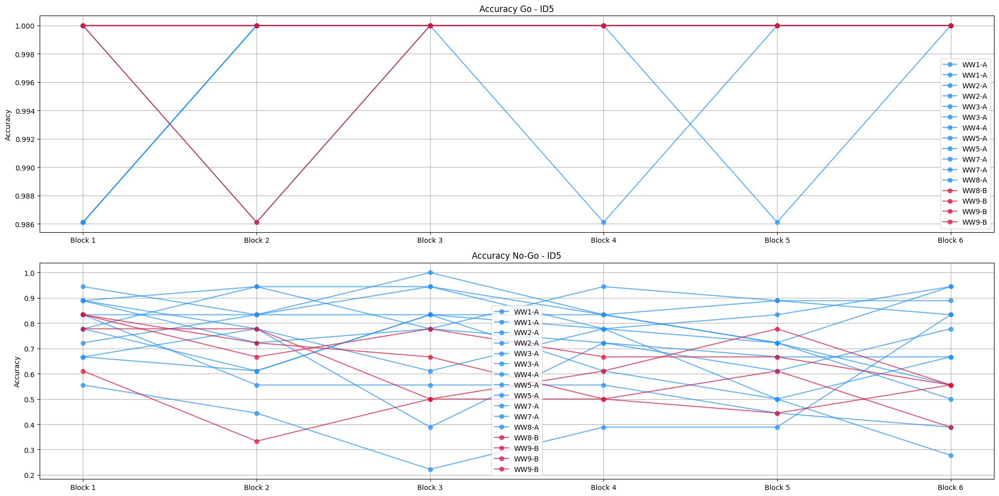

DATE: 2026-06-05 00:00:00
DATE: 2026-06-08 00:00:00
DATE: 2026-06-10 00:00:00
DATE: 2026-06-12 00:00:00


,DATE,PHASE,Go_12,Go_20,Go_30,NoGo_12,NoGo_20,NoGo_30,MeanGo,MeanNoGo
0,2026-04-13,A,0.995370,0.995370,0.995370,0.722222,0.722222,0.722222,NaN,NaN
1,2026-04-15,A,1.000000,1.000000,1.000000,0.601852,0.601852,0.601852,NaN,NaN
2,2026-04-22,A,0.997685,0.997685,0.997685,0.870370,0.870370,0.870370,NaN,NaN
3,2026-04-24,A,1.000000,1.000000,1.000000,0.842593,0.842593,0.842593,NaN,NaN
4,2026-04-27,A,1.000000,1.000000,1.000000,0.805556,0.805556,0.805556,NaN,NaN
5,2026-04-30,A,1.000000,1.000000,1.000000,0.814815,0.814815,0.814815,NaN,NaN
6,2026-05-07,A,1.000000,1.000000,1.000000,0.759259,0.759259,0.759259,NaN,NaN
7,2026-05-12,A,0.997685,0.997685,0.997685,0.870370,0.870370,0.870370,NaN,NaN
8,2026-05-13,A,1.000000,1.000000,1.000000,0.555556,0.555556,0.555556,NaN,NaN
9,2026-05-27,A,0.997685,0.997685,0.997685,0.472222,0.472222,0.472222,NaN,NaN


t=-0.483494
t=2.098171
t=0.115577
t=-0.606092
t=-1.044466
t=1.476401
Go A-A   p = 0.6490
Go A-B   p = 0.5692
Go B-B   p = 0.1580
NoGo A-A p = 0.0586
NoGo A-B p = 0.9276
NoGo B-B p = 0.2036


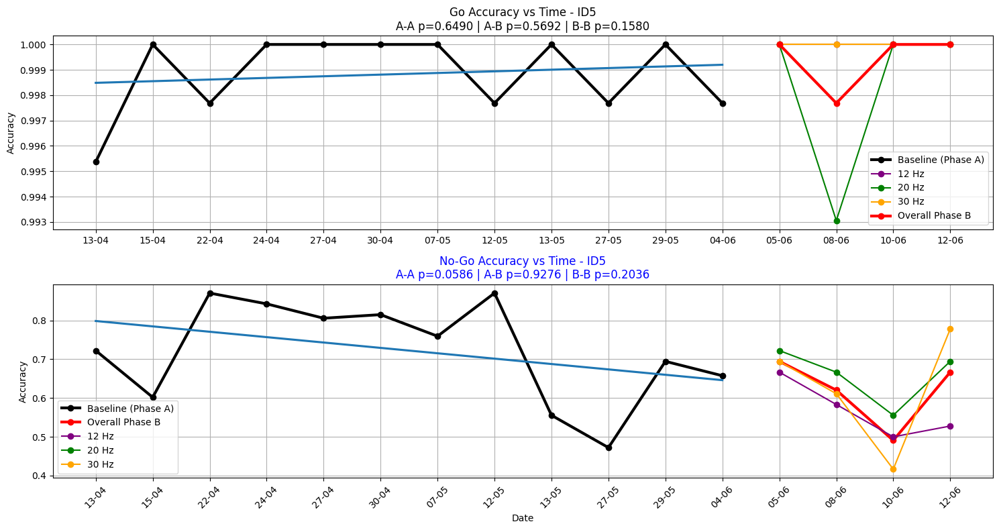

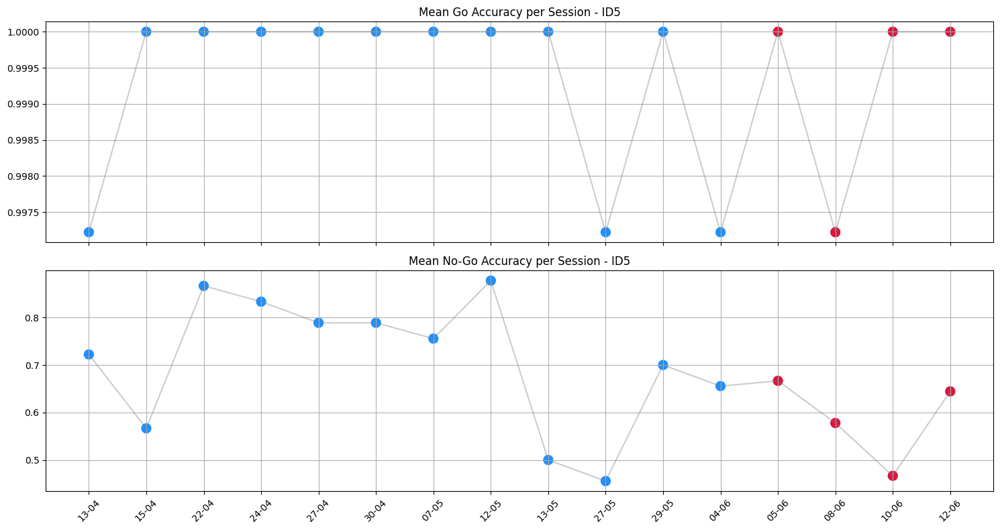

DATE: 2026-06-05 00:00:00
DATE: 2026-06-08 00:00:00
DATE: 2026-06-10 00:00:00
DATE: 2026-06-12 00:00:00


,DATE,Go_12,NoGo_12,Go_20,NoGo_20,Go_30,NoGo_30,MeanGo,MeanNoGo
0,2026-06-05,1.0,0.666667,1.000000,0.722222,1.0,0.694444,1.000000,0.694444
1,2026-06-08,1.0,0.583333,0.993056,0.666667,1.0,0.611111,0.997685,0.620370
2,2026-06-10,1.0,0.500000,1.000000,0.555556,1.0,0.416667,1.000000,0.490741
3,2026-06-12,1.0,0.527778,1.000000,0.694444,1.0,0.777778,1.000000,0.666667


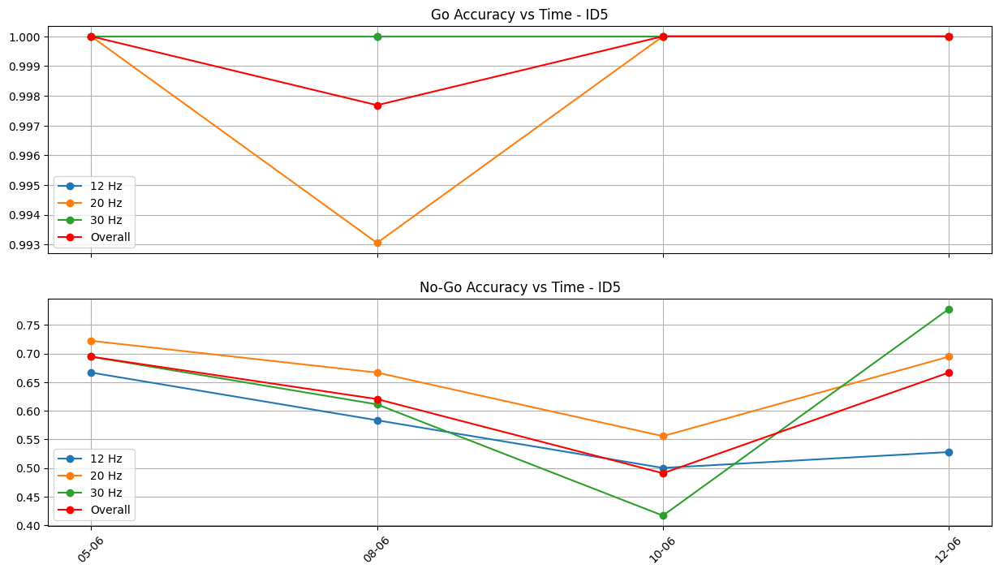

t=3.531076
t=0.357166
t=1.820334


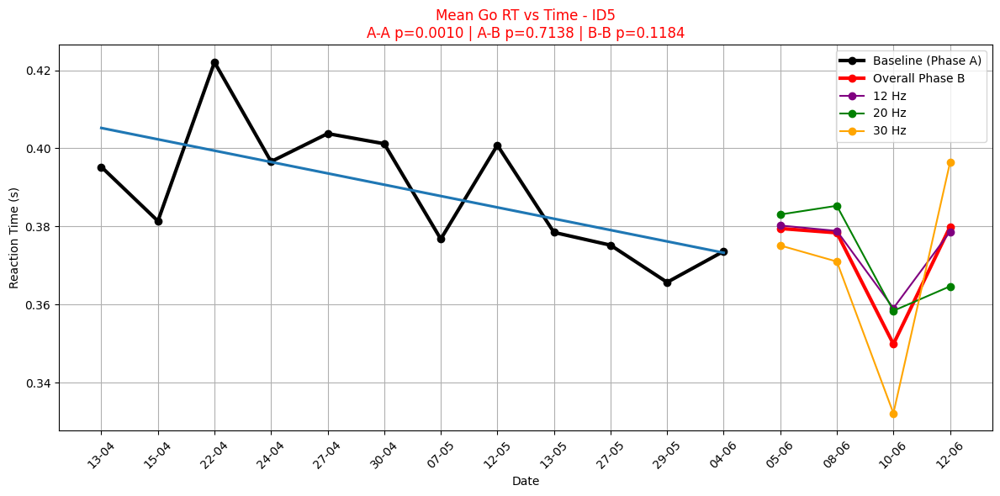

t=-1.523037
t=1.713728
t=-0.861448


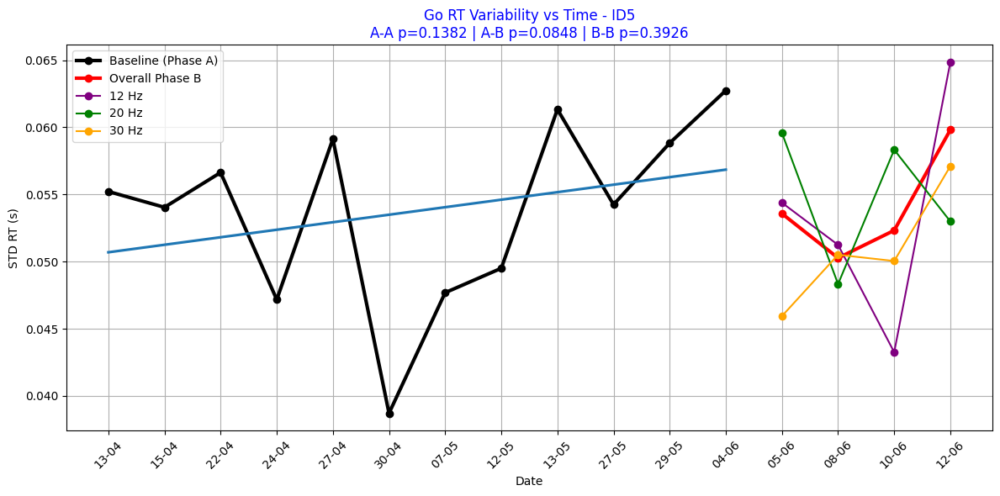

t=1.982245
t=-0.016125
t=1.200615


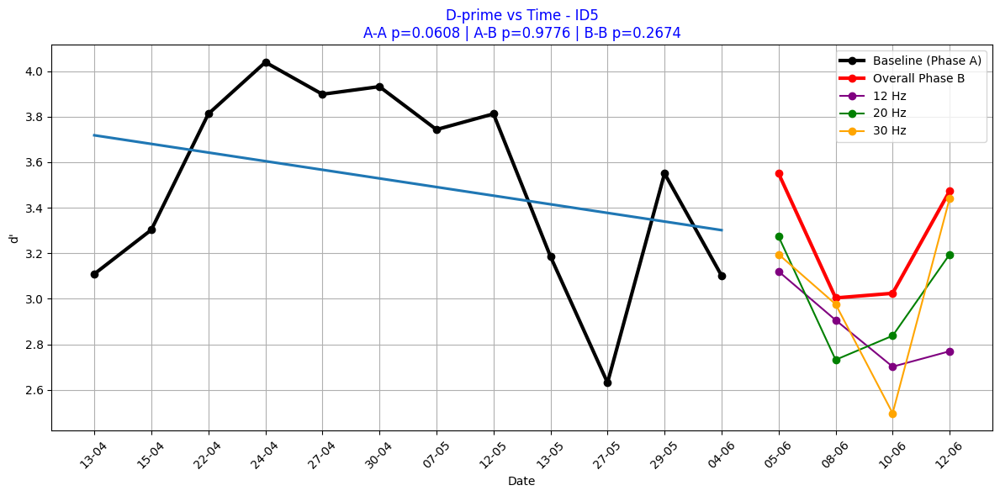

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime_All,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-13,A,5/6,NaN,NaN,NaN,3.109070,0.997222,0.722222,0.043396
1,2026-04-15,A,5/6,NaN,NaN,NaN,3.302971,1.000000,0.566667,0.051744
2,2026-04-22,A,5/6,NaN,NaN,5.0,3.812459,1.000000,0.866667,0.049960
3,2026-04-24,A,5/6,NaN,NaN,5.0,4.039446,1.000000,0.833333,0.044599
4,2026-04-27,A,5/6,8.0,5.0,0.0,3.898742,1.000000,0.788889,0.054262
5,2026-04-30,A,5/6,8.0,4.0,0.0,3.932267,1.000000,0.788889,0.037124
6,2026-05-07,A,5/6,7.0,4.0,0.0,3.743552,1.000000,0.755556,0.044188
7,2026-05-12,A,5/6,8.0,4.0,0.0,3.812459,1.000000,0.877778,0.041305
8,2026-05-13,A,5/6,6.0,3.0,0.0,3.185669,1.000000,0.500000,0.054753
9,2026-05-27,A,5/6,6.0,3.0,0.0,2.631221,0.997222,0.455556,0.048359


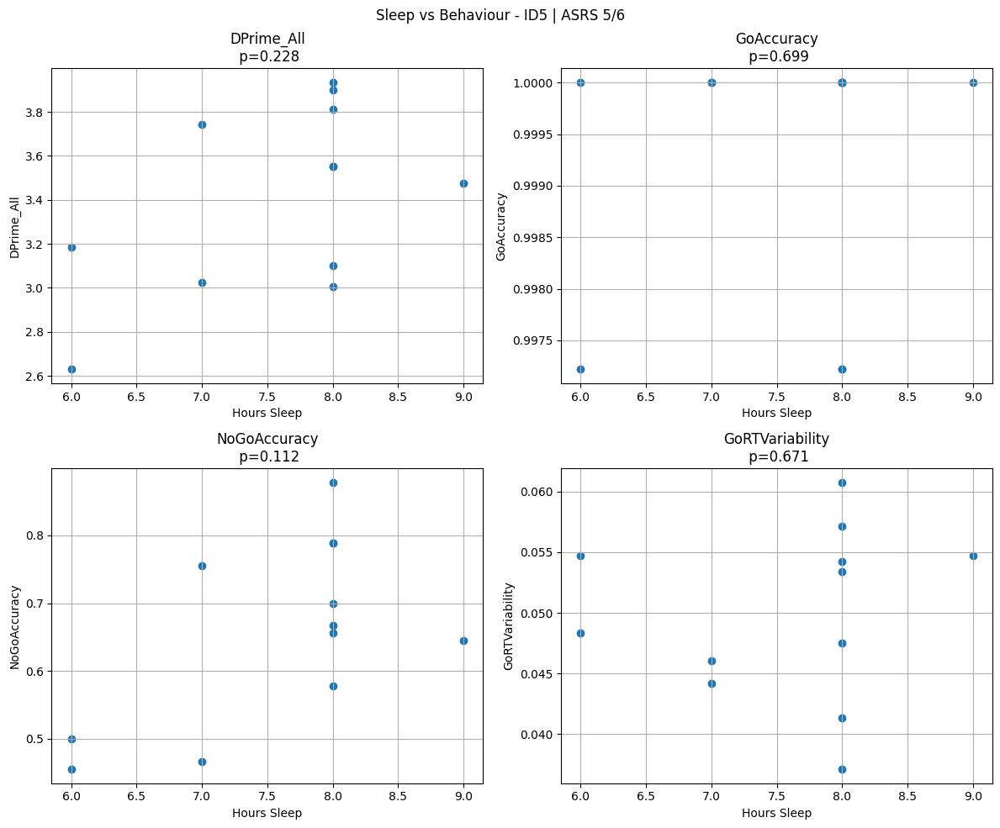

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime_All,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-13,A,5/6,NaN,NaN,NaN,3.109070,0.997222,0.722222,0.043396
1,2026-04-15,A,5/6,NaN,NaN,NaN,3.302971,1.000000,0.566667,0.051744
2,2026-04-22,A,5/6,NaN,NaN,5.0,3.812459,1.000000,0.866667,0.049960
3,2026-04-24,A,5/6,NaN,NaN,5.0,4.039446,1.000000,0.833333,0.044599
4,2026-04-27,A,5/6,8.0,5.0,0.0,3.898742,1.000000,0.788889,0.054262
5,2026-04-30,A,5/6,8.0,4.0,0.0,3.932267,1.000000,0.788889,0.037124
6,2026-05-07,A,5/6,7.0,4.0,0.0,3.743552,1.000000,0.755556,0.044188
7,2026-05-12,A,5/6,8.0,4.0,0.0,3.812459,1.000000,0.877778,0.041305
8,2026-05-13,A,5/6,6.0,3.0,0.0,3.185669,1.000000,0.500000,0.054753
9,2026-05-27,A,5/6,6.0,3.0,0.0,2.631221,0.997222,0.455556,0.048359


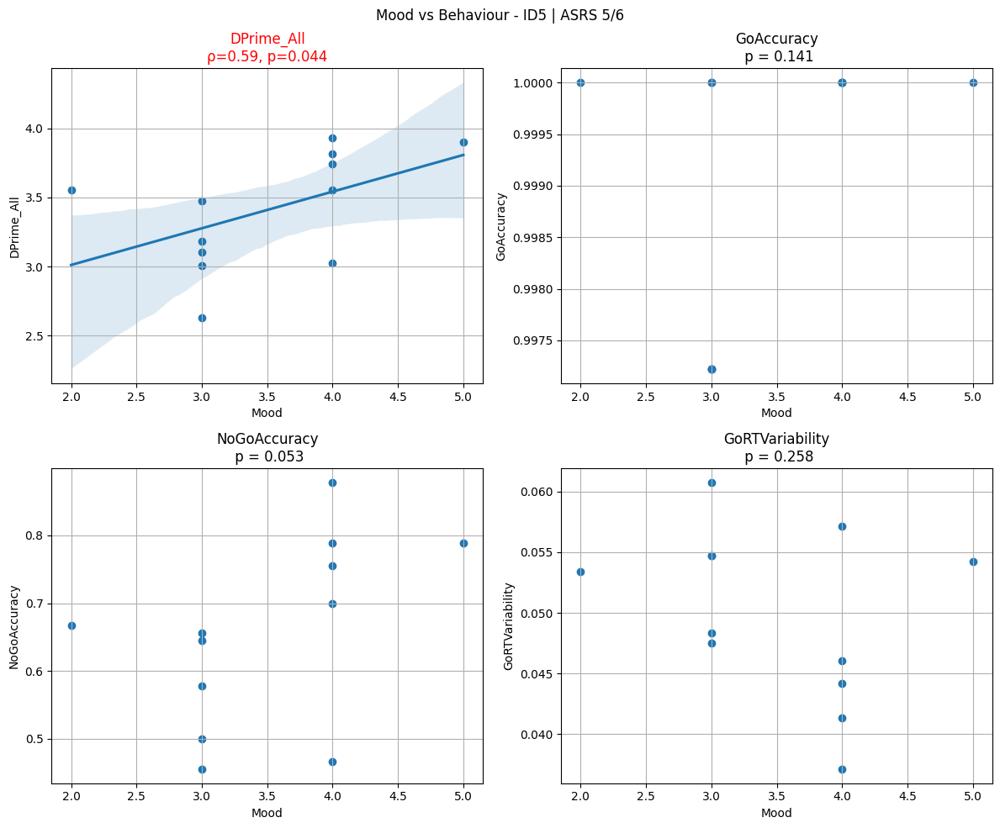

In [1041]:
df_clean_list = pipeline(id = 5)
#display(df_clean_list)

#**ID8**

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,213.784707,No_Go,space,0.568228,Incorrect,False,True,8
1,1,1,214.769573,Go,NaN,NaN,Incorrect,True,False,8
2,1,2,215.752916,Go,NaN,NaN,Incorrect,True,False,8
3,1,3,216.736492,Go,NaN,NaN,Incorrect,True,False,8
4,1,4,217.719576,Go,NaN,NaN,Incorrect,True,False,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,858.160435,Go,space,0.249931,Correct,False,False,8
536,6,536,859.143632,Go,space,0.183328,Correct,False,False,8
537,6,537,860.126987,No_Go,space,0.316691,Incorrect,False,True,8
538,6,538,861.110296,Go,space,0.450037,Correct,False,False,8


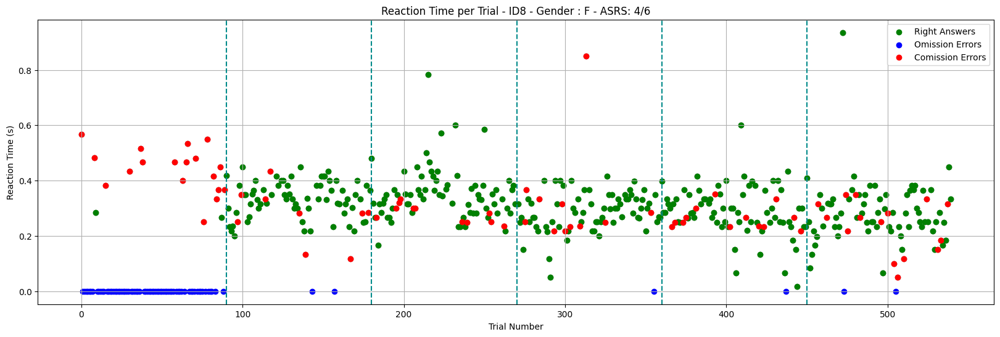

t=6.291313


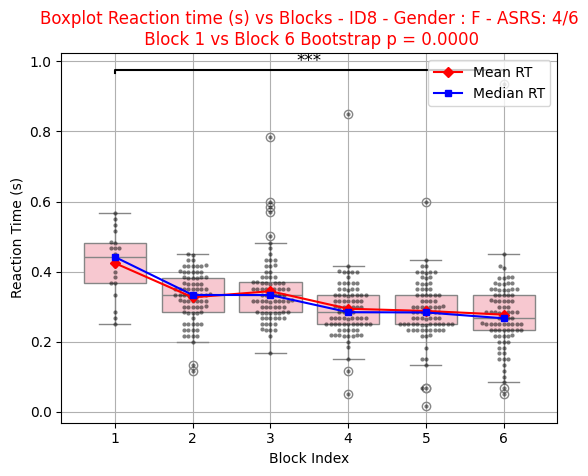

[{'Block': 'Block 1',
  'Accuracy Go': 0.027777777777777776,
  'Accuracy No Go': 0.0},
 {'Block': 'Block 2',
  'Accuracy Go': 0.9722222222222222,
  'Accuracy No Go': 0.5},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 4',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 5',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.2777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 0.9722222222222222,
  'Accuracy No Go': 0.16666666666666666}]

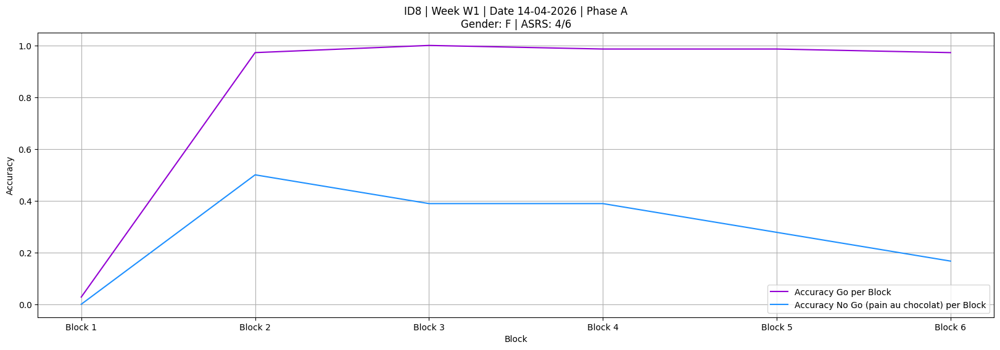

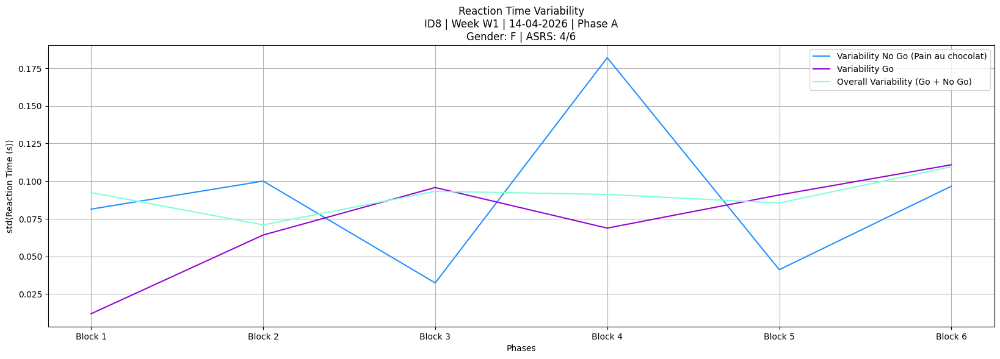

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,267.482526,Go,space,0.650804,Correct,False,False,8
1,1,1,268.466654,Go,space,0.216736,Correct,False,False,8
2,1,2,269.449991,Go,space,0.149897,Correct,False,False,8
3,1,3,270.433410,Go,space,0.050035,Correct,False,False,8
4,1,4,271.416761,Go,NaN,NaN,Incorrect,True,False,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,912.121484,Go,space,0.483261,Correct,False,False,8
536,6,536,913.104541,Go,space,0.383285,Correct,False,False,8
537,6,537,914.087783,Go,space,0.283509,Correct,False,False,8
538,6,538,915.071192,Go,space,0.416845,Correct,False,False,8


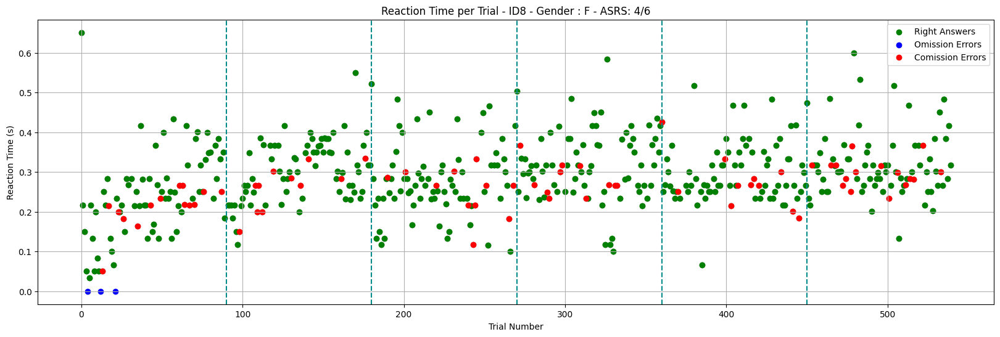

t=-5.477084


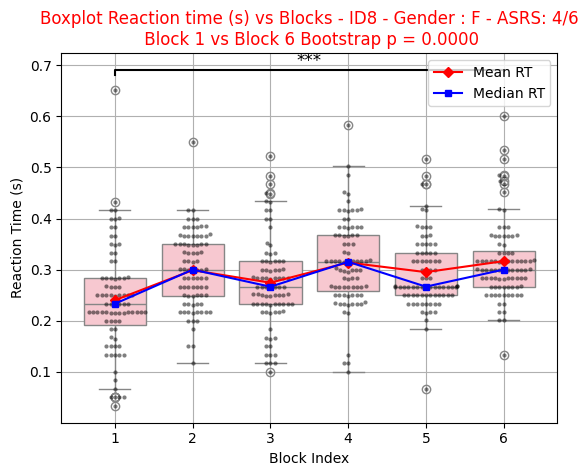

[{'Block': 'Block 1',
  'Accuracy Go': 0.9583333333333334,
  'Accuracy No Go': 0.2222222222222222},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.1111111111111111}]

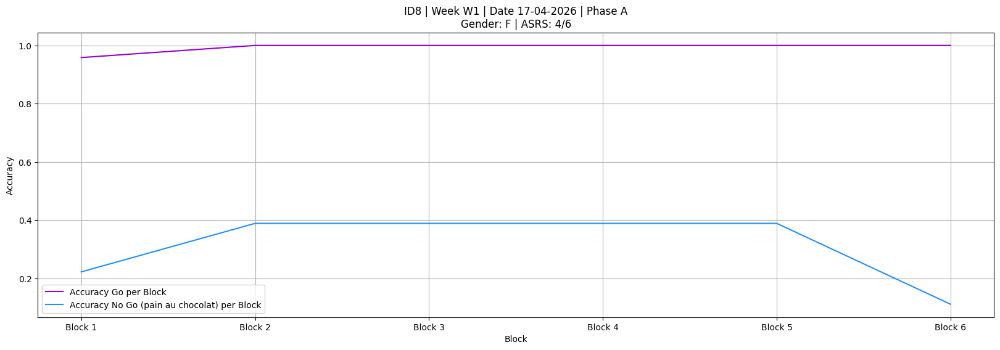

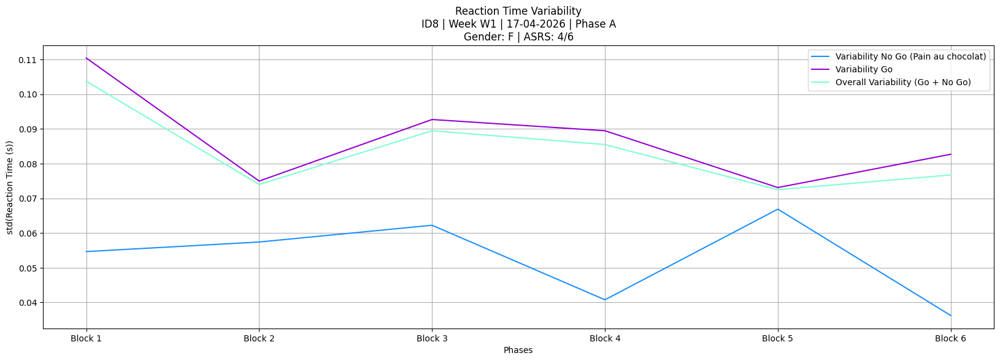

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,276.718858,Go,space,0.367844,Correct,False,False,8
1,1,1,277.703508,Go,space,0.199996,Correct,False,False,8
2,1,2,278.686566,Go,space,0.000103,Correct,False,False,8
3,1,3,279.671902,Go,space,0.098551,Correct,False,False,8
4,1,4,280.654033,Go,space,0.250004,Correct,False,False,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,932.128149,Go,space,0.267018,Correct,False,False,8
536,6,536,933.112773,No_Go,space,0.216510,Incorrect,False,True,8
537,6,537,934.094539,Go,space,0.116721,Correct,False,False,8
538,6,538,935.077932,Go,space,0.400172,Correct,False,False,8


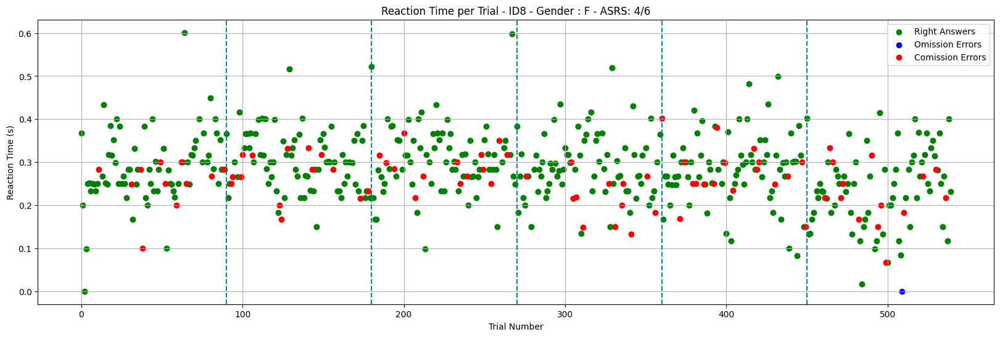

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=3.510890


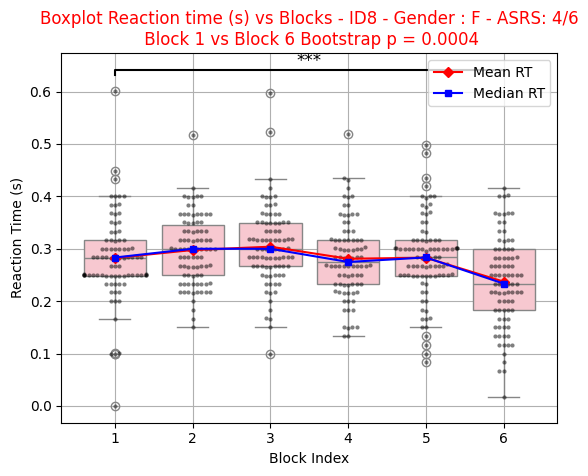

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2222222222222222},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2222222222222222},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3333333333333333},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.05555555555555555},
 {'Block': 'Block 6',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.2222222222222222}]

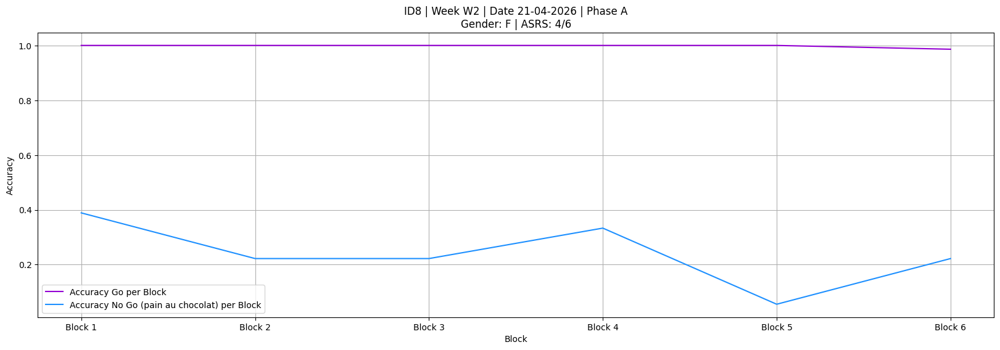

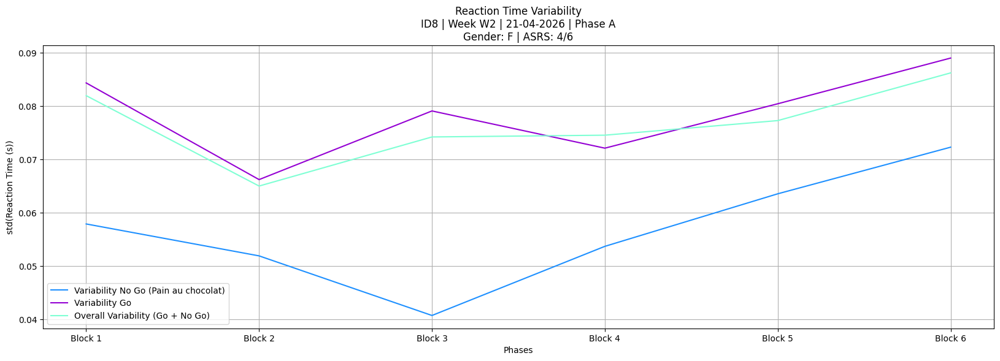

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,260.331922,No_Go,space,0.481605,Incorrect,False,True,8
1,1,1,261.363432,Go,space,0.216763,Correct,False,False,8
2,1,2,262.380320,Go,space,0.016635,Correct,False,False,8
3,1,3,263.398041,Go,space,0.050174,Correct,False,False,8
4,1,4,264.413408,No_Go,space,0.233380,Incorrect,False,True,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,916.922668,No_Go,NaN,NaN,Correct,False,False,8
536,6,536,917.939431,No_Go,NaN,NaN,Correct,False,False,8
537,6,537,918.956012,Go,space,0.366710,Correct,False,False,8
538,6,538,919.972569,No_Go,NaN,NaN,Correct,False,False,8


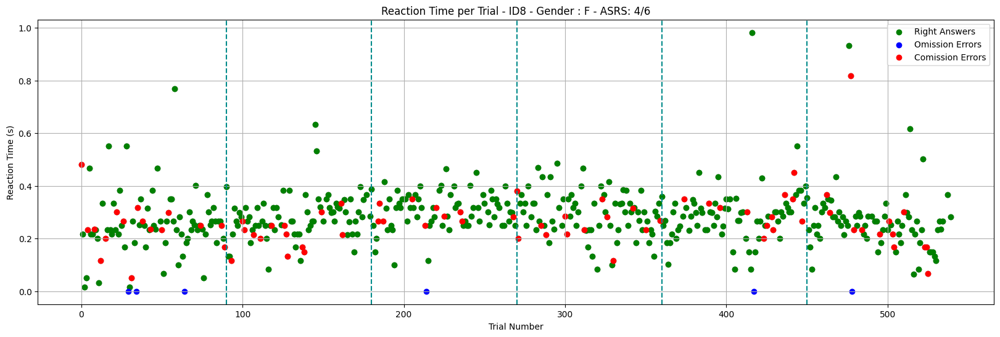

t=-0.607852


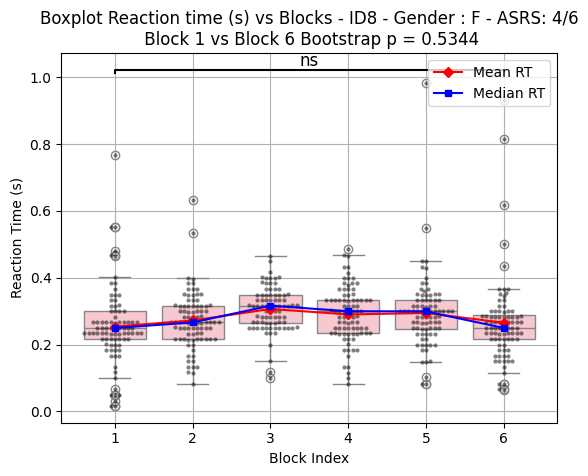

[{'Block': 'Block 1',
  'Accuracy Go': 0.9583333333333334,
  'Accuracy No Go': 0.1111111111111111},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2222222222222222},
 {'Block': 'Block 3',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.3333333333333333},
 {'Block': 'Block 6',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.2777777777777778}]

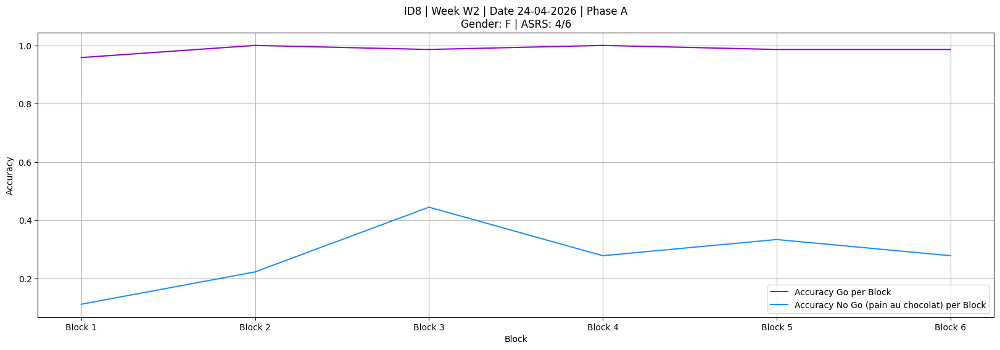

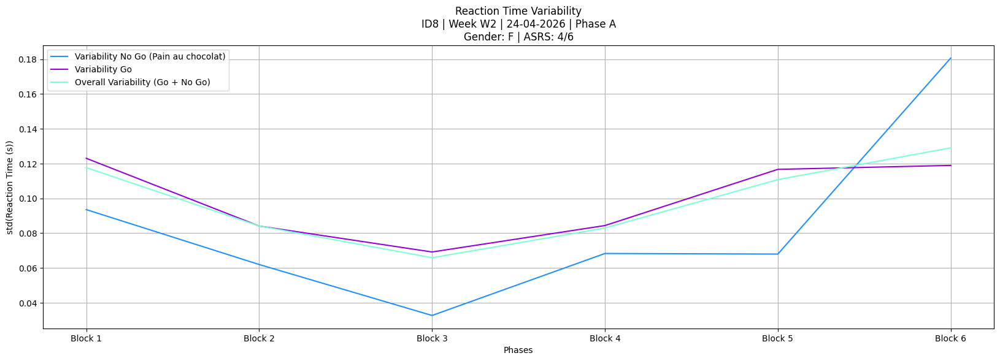

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,227.195551,Go,space,0.431794,Correct,False,False,8
1,1,1,228.226722,Go,space,0.233183,Correct,False,False,8
2,1,2,229.242342,No_Go,space,0.050095,Incorrect,False,True,8
3,1,3,230.260452,No_Go,space,0.249883,Incorrect,False,True,8
4,1,4,231.276232,Go,space,0.366309,Correct,False,False,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,898.262028,Go,space,0.216533,Correct,False,False,8
536,6,536,899.277768,No_Go,NaN,NaN,Correct,False,False,8
537,6,537,900.293399,Go,space,0.299889,Correct,False,False,8
538,6,538,901.309003,Go,space,0.383156,Correct,False,False,8


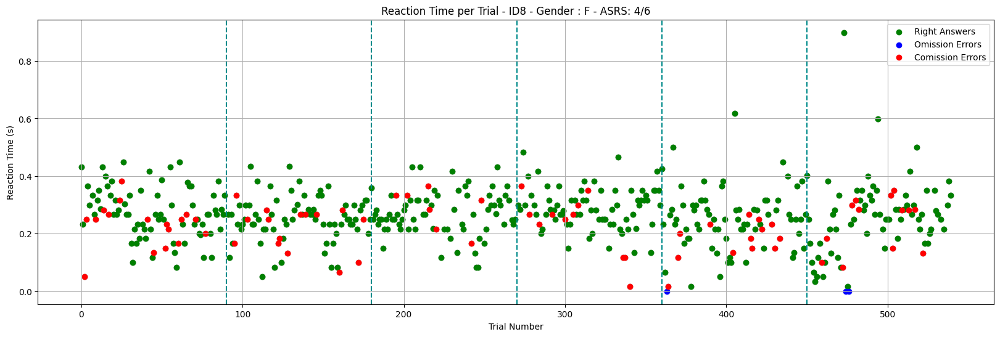

t=0.574342


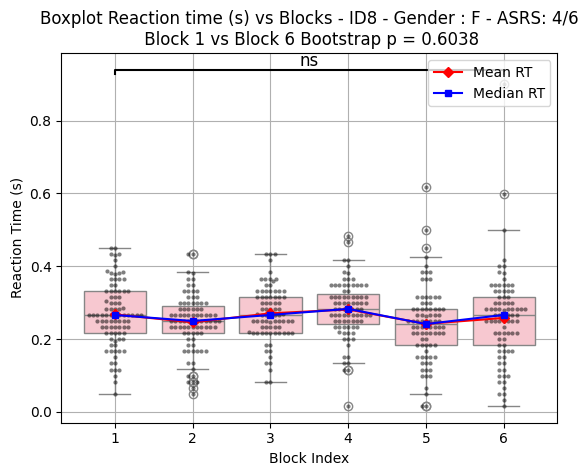

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.05555555555555555},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.16666666666666666},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 5',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.2777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 0.9722222222222222,
  'Accuracy No Go': 0.2777777777777778}]

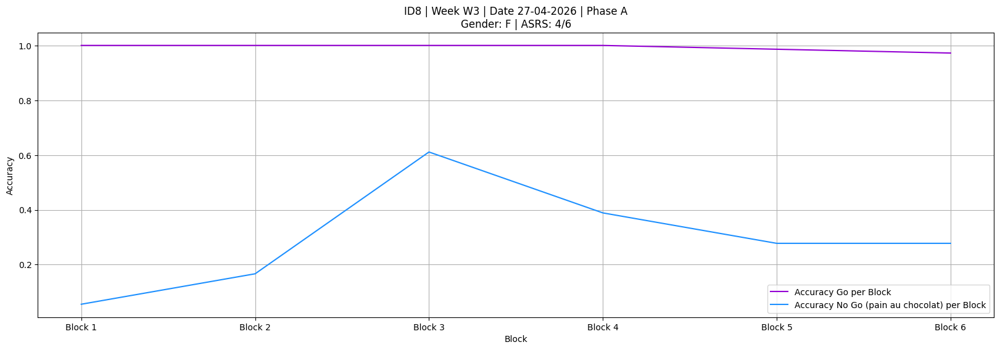

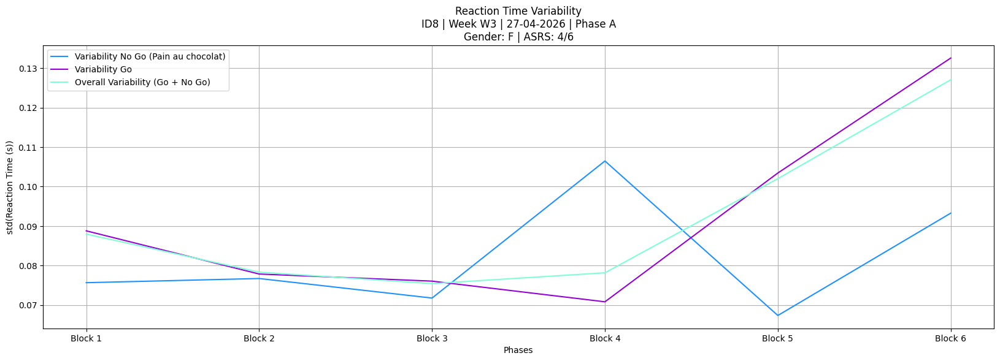

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,107.991584,Go,space,0.364669,Correct,False,False,8
1,1,1,109.005434,Go,space,0.233833,Correct,False,False,8
2,1,2,110.021025,Go,space,0.219987,Correct,False,False,8
3,1,3,111.040415,Go,space,0.280854,Correct,False,False,8
4,1,4,112.055557,No_Go,space,0.266134,Incorrect,False,True,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,761.019221,Go,space,0.333016,Correct,False,False,8
536,6,536,762.034830,No_Go,NaN,NaN,Correct,False,False,8
537,6,537,763.050510,Go,space,0.199990,Correct,False,False,8
538,6,538,764.066154,Go,space,0.399683,Correct,False,False,8


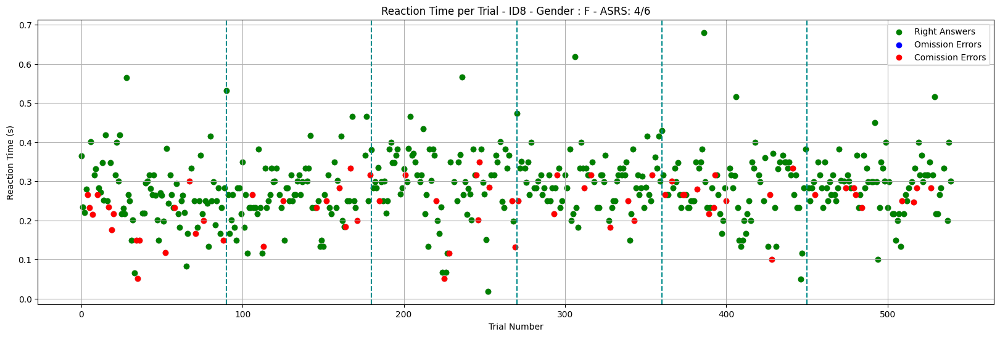

t=-3.125338


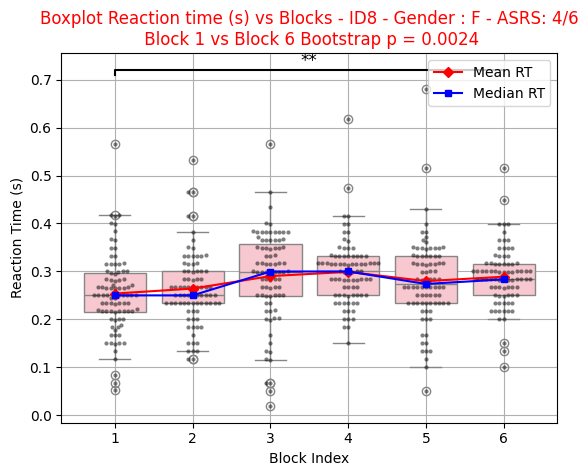

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.1111111111111111},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3333333333333333},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5}]

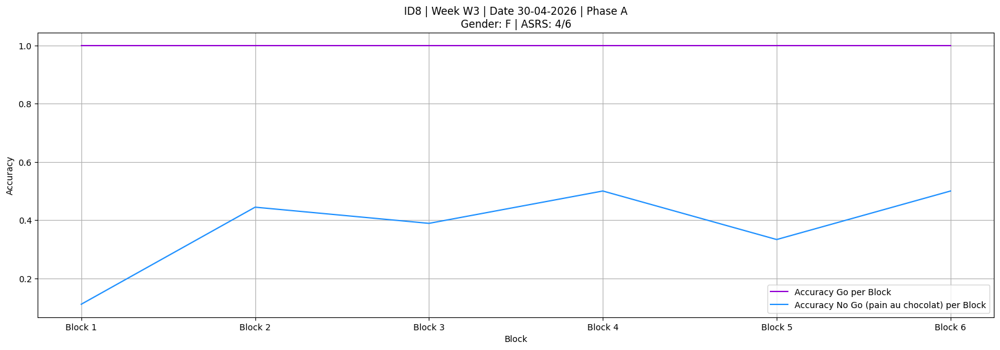

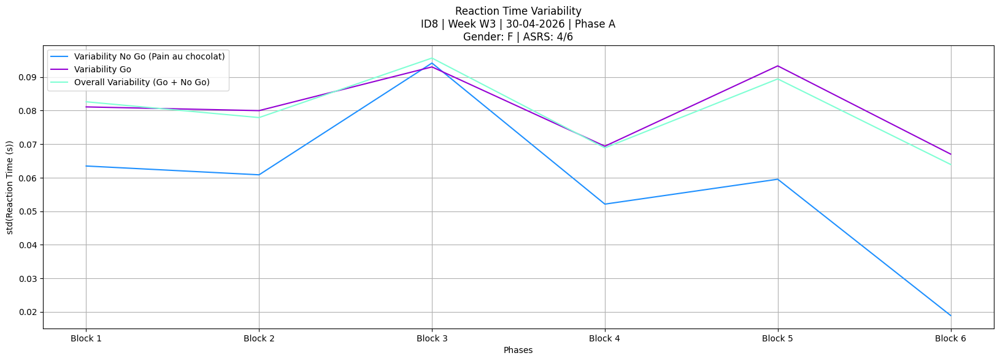

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,349.650655,Go,NaN,NaN,Incorrect,True,False,8
1,1,1,350.685007,Go,NaN,NaN,Incorrect,True,False,8
2,1,2,351.700826,Go,NaN,NaN,Incorrect,True,False,8
3,1,3,352.717411,No_Go,space,0.366771,Incorrect,False,True,8
4,1,4,353.733825,Go,NaN,NaN,Incorrect,True,False,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1002.816969,No_Go,space,0.300069,Incorrect,False,True,8
536,6,536,1003.833658,Go,space,0.316730,Correct,False,False,8
537,6,537,1004.850429,No_Go,NaN,NaN,Correct,False,False,8
538,6,538,1005.866977,Go,space,0.250017,Correct,False,False,8


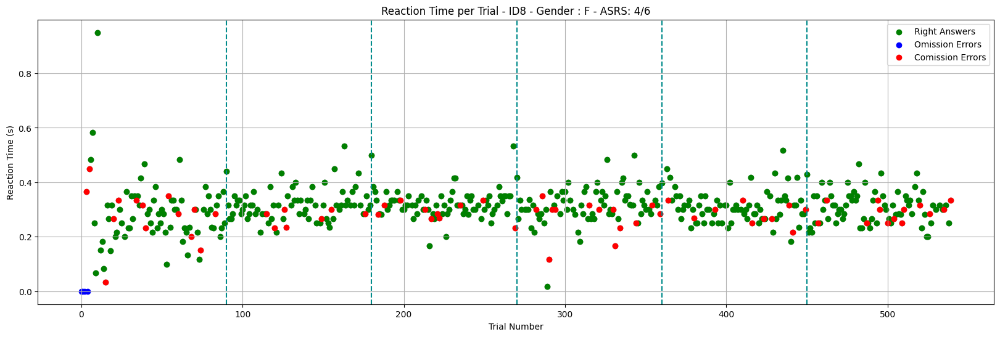

t=-1.472615


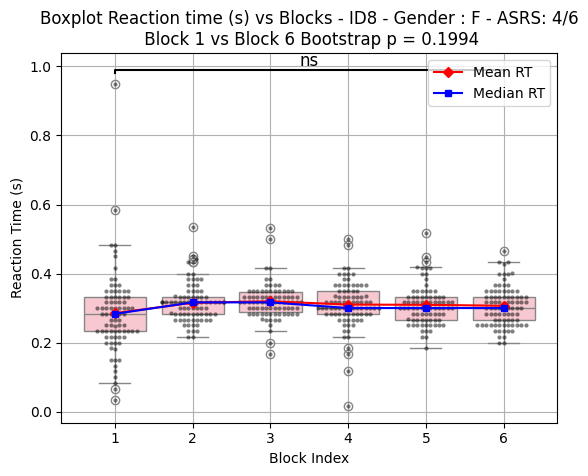

[{'Block': 'Block 1',
  'Accuracy Go': 0.9444444444444444,
  'Accuracy No Go': 0.2222222222222222},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2777777777777778}]

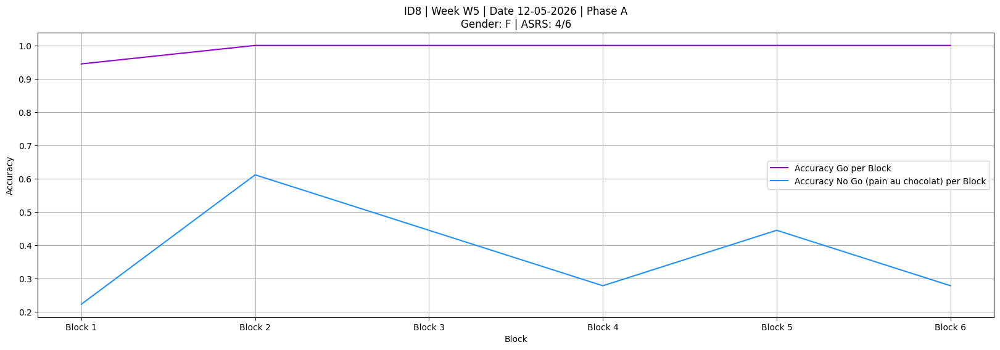

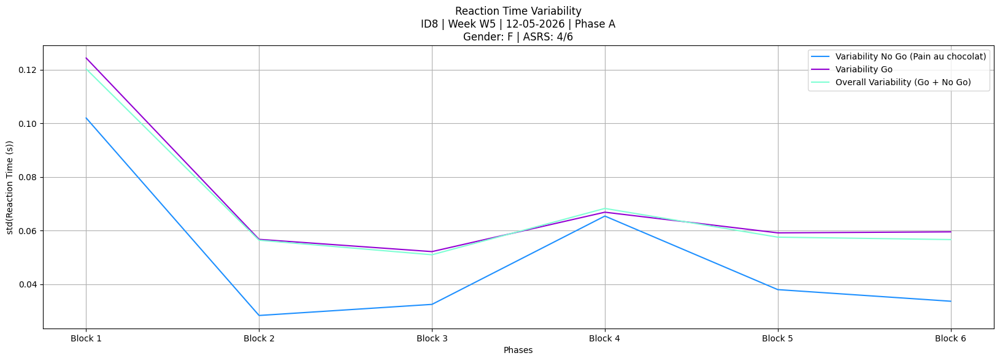

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,188.576778,No_Go,space,0.466494,Incorrect,False,True,8
1,1,1,189.643568,Go,space,0.282539,Correct,False,False,8
2,1,2,190.659054,Go,space,0.233494,Correct,False,False,8
3,1,3,191.675883,Go,space,0.166560,Correct,False,False,8
4,1,4,192.692195,Go,space,0.116860,Correct,False,False,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,847.463416,No_Go,space,0.283585,Incorrect,False,True,8
536,6,536,848.480051,Go,space,0.383591,Correct,False,False,8
537,6,537,849.496712,Go,space,0.283275,Correct,False,False,8
538,6,538,850.513394,Go,space,0.333432,Correct,False,False,8


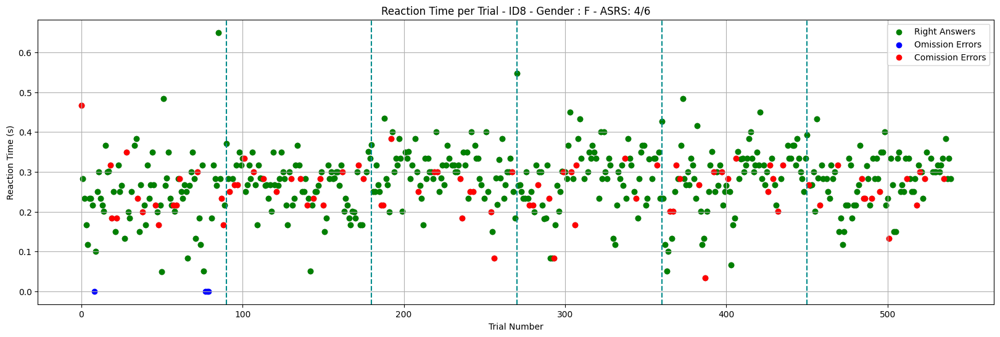

t=-2.456501


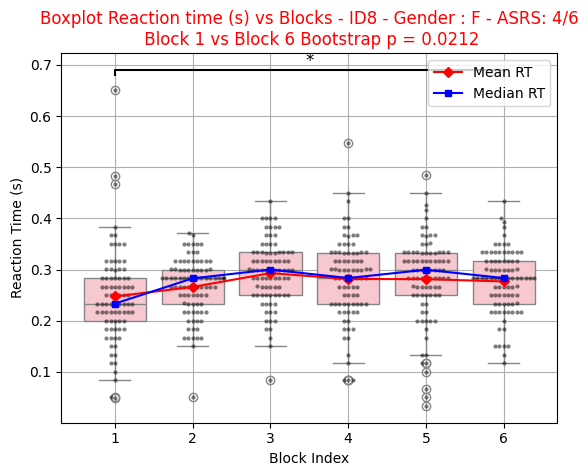

[{'Block': 'Block 1',
  'Accuracy Go': 0.9444444444444444,
  'Accuracy No Go': 0.16666666666666666},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.1111111111111111},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2777777777777778},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3333333333333333},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.16666666666666666},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2222222222222222}]

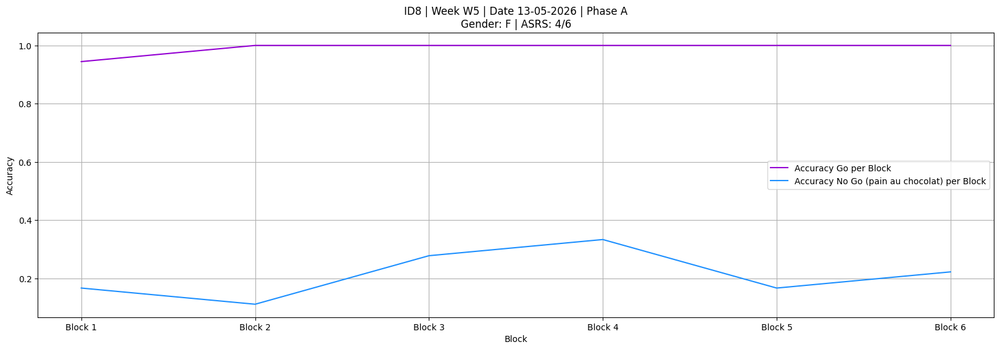

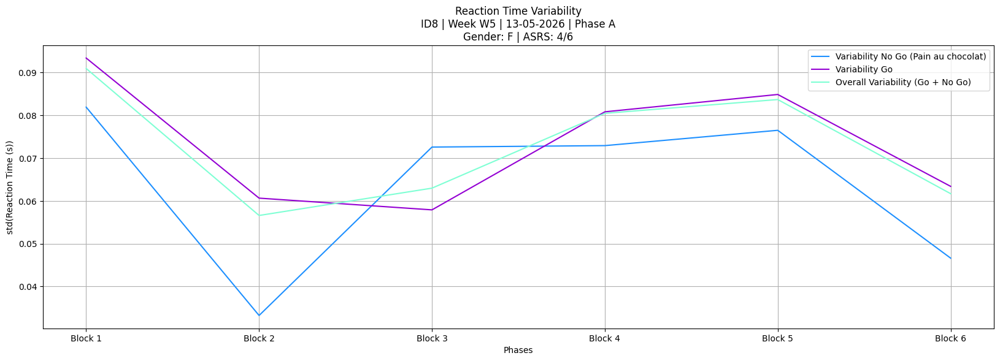

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,221.856738,Go,space,0.445446,Correct,False,False,8
1,1,1,222.902068,Go,space,0.216732,Correct,False,False,8
2,1,2,223.918965,Go,space,0.250483,Correct,False,False,8
3,1,3,224.935898,Go,space,0.267147,Correct,False,False,8
4,1,4,225.954596,No_Go,space,0.231158,Incorrect,False,True,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,874.090669,Go,space,0.317019,Correct,False,False,8
536,6,536,875.107491,No_Go,NaN,NaN,Correct,False,False,8
537,6,537,876.124205,Go,space,0.366497,Correct,False,False,8
538,6,538,877.141092,Go,space,0.333125,Correct,False,False,8


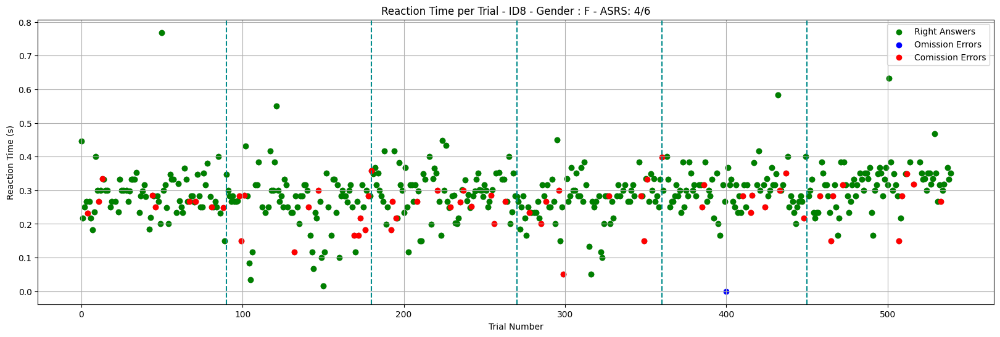

t=-2.101416


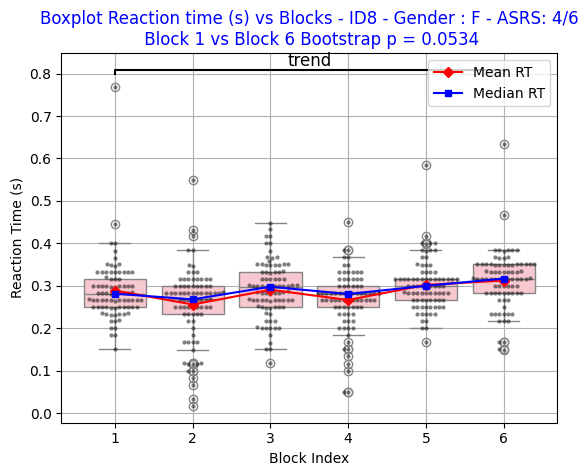

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2777777777777778},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 5',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5}]

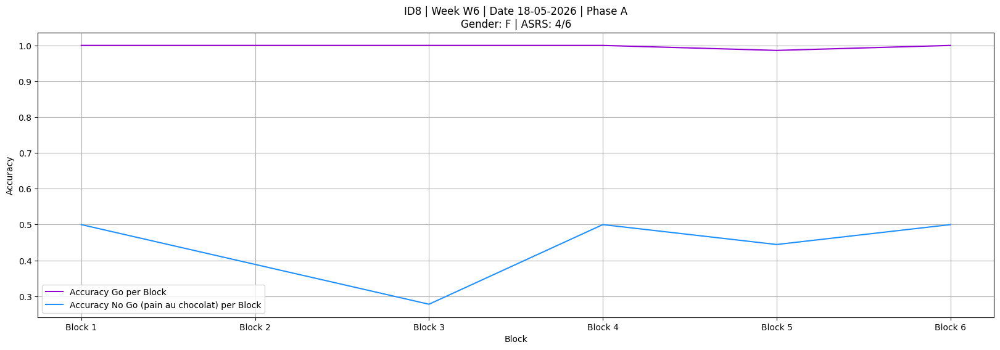

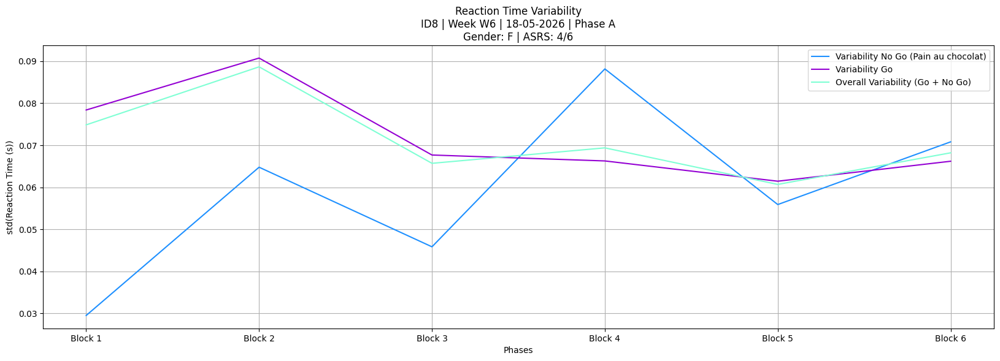

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,190.491672,Go,space,0.853767,Correct,False,False,8
1,1,1,191.528757,Go,space,0.299837,Correct,False,False,8
2,1,2,192.545717,No_Go,space,0.083471,Incorrect,False,True,8
3,1,3,193.563780,Go,space,0.183309,Correct,False,False,8
4,1,4,194.578868,Go,space,0.233259,Correct,False,False,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,844.033963,Go,space,0.350090,Correct,False,False,8
536,6,536,845.050514,Go,space,0.316890,Correct,False,False,8
537,6,537,846.067222,Go,space,0.366814,Correct,False,False,8
538,6,538,847.083873,Go,space,0.316580,Correct,False,False,8


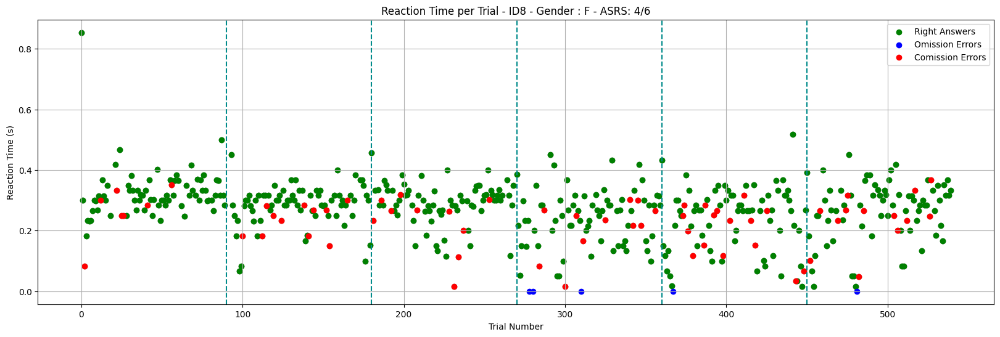

t=4.075988


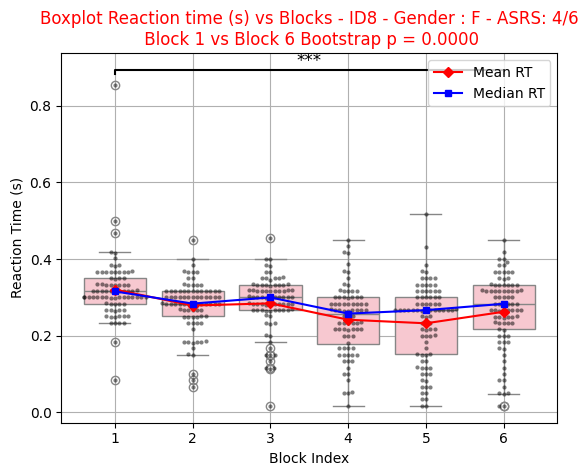

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 0.9583333333333334,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 5',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.1111111111111111},
 {'Block': 'Block 6',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.2777777777777778}]

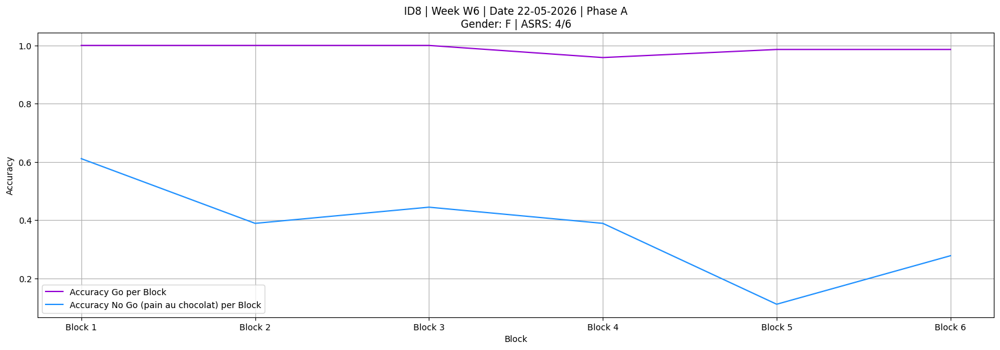

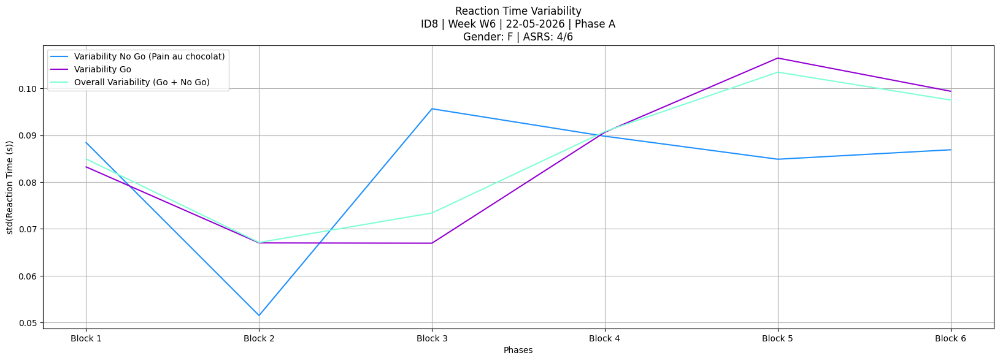

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,406.436282,No_Go,space,0.362880,Incorrect,False,True,8
1,1,1,407.483145,Go,space,0.216328,Correct,False,False,8
2,1,2,408.499271,Go,space,0.218153,Correct,False,False,8
3,1,3,409.515873,Go,space,0.266618,Correct,False,False,8
4,1,4,410.532685,Go,space,0.266406,Correct,False,False,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1058.722987,No_Go,NaN,NaN,Correct,False,False,8
536,6,536,1059.739737,No_Go,space,0.349765,Incorrect,False,True,8
537,6,537,1060.756308,Go,space,0.333342,Correct,False,False,8
538,6,538,1061.774285,No_Go,space,0.248396,Incorrect,False,True,8


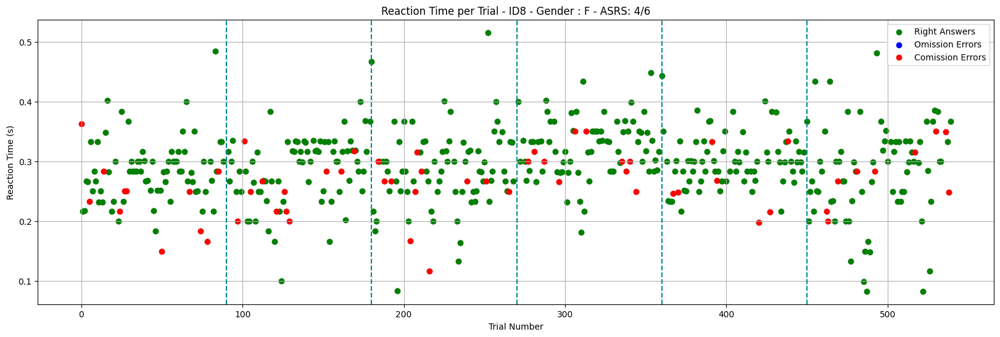

t=-0.140260


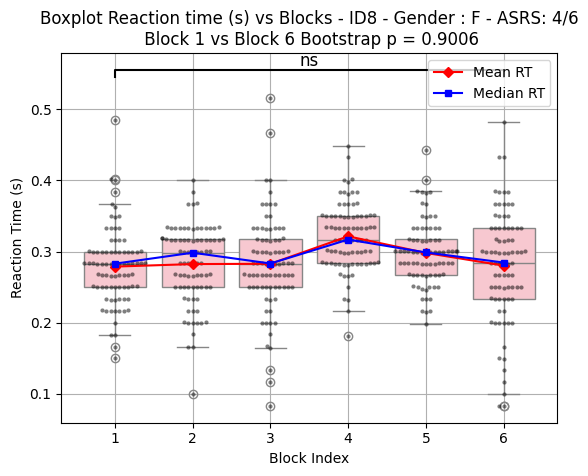

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5}]

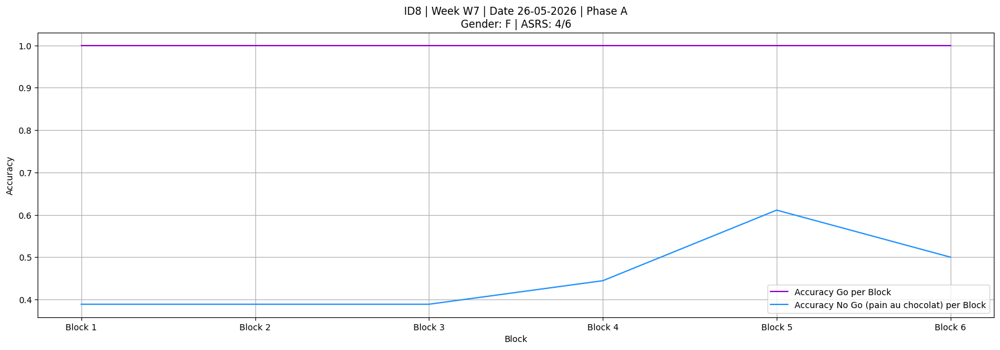

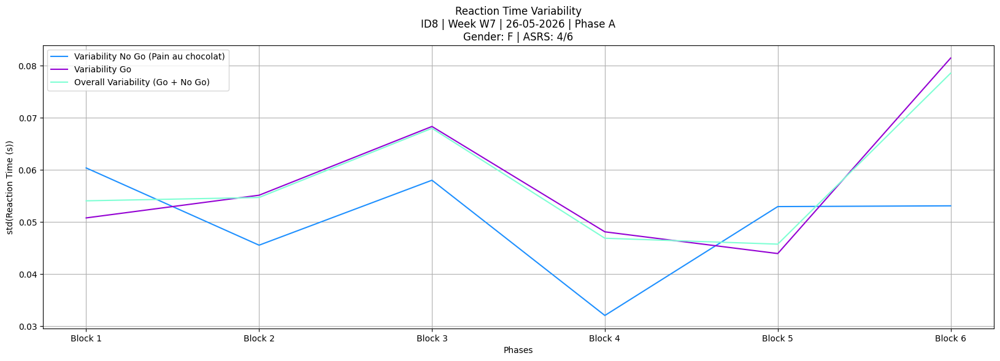

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,293.175845,Go,space,0.567756,Correct,False,False,8
1,1,1,294.227072,Go,space,0.233550,Correct,False,False,8
2,1,2,295.243318,Go,space,0.135757,Correct,False,False,8
3,1,3,296.259856,No_Go,space,0.050345,Incorrect,False,True,8
4,1,4,297.277295,Go,space,0.249897,Correct,False,False,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,942.799416,Go,space,0.218222,Correct,False,False,8
536,6,536,943.816361,No_Go,space,0.233308,Incorrect,False,True,8
537,6,537,944.833002,Go,space,0.267965,Correct,False,False,8
538,6,538,945.849491,Go,space,0.266756,Correct,False,False,8


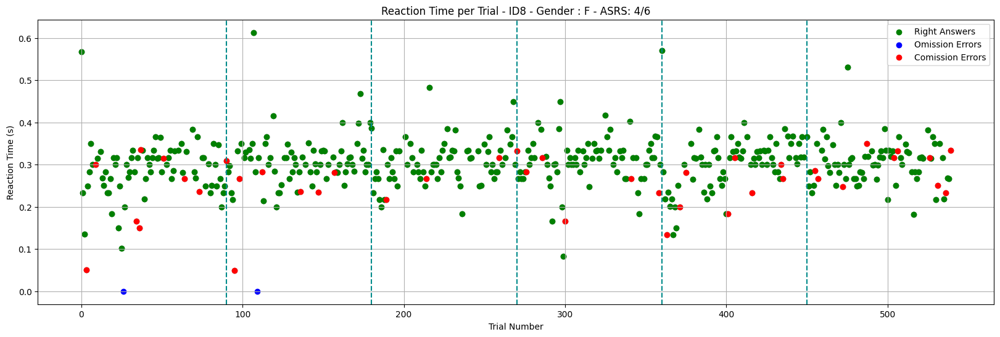

t=-2.273706


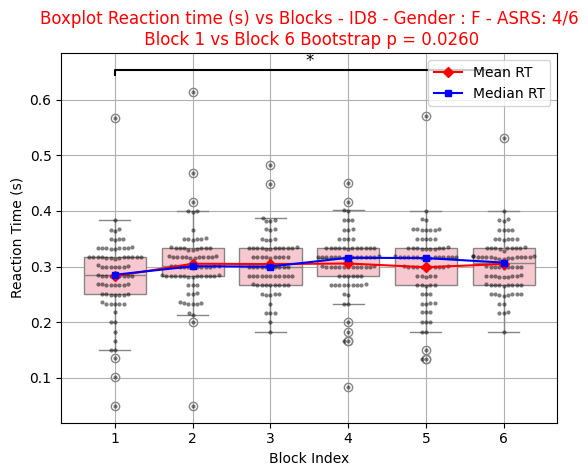

[{'Block': 'Block 1',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.5555555555555556},
 {'Block': 'Block 2',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444}]

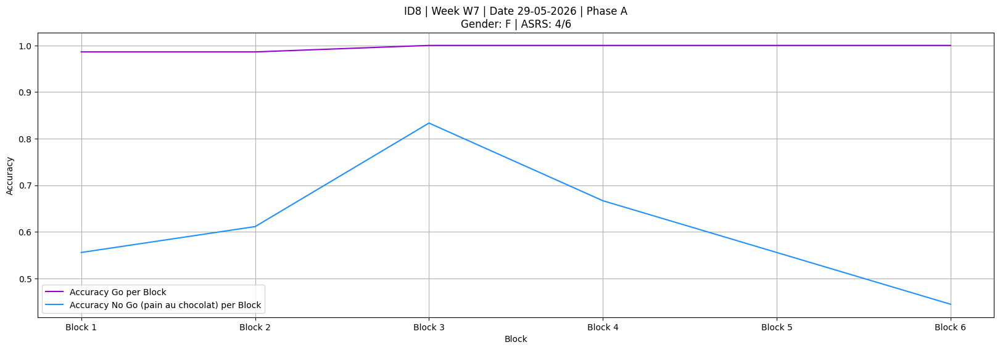

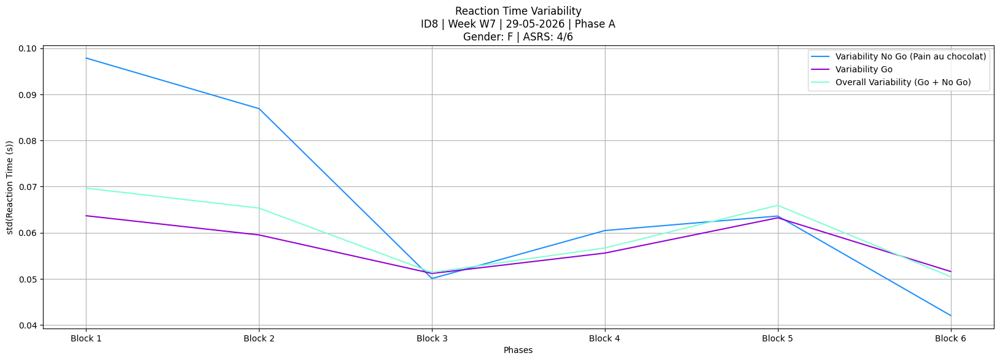

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,321.995534,No_Go,space,0.354708,Incorrect,False,True,8
1,1,1,323.015596,Go,space,0.383379,Correct,False,False,8
2,1,2,324.032328,Go,space,0.333361,Correct,False,False,8
3,1,3,325.049202,Go,space,0.299781,Correct,False,False,8
4,1,4,326.066989,Go,space,0.300110,Correct,False,False,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,974.770319,No_Go,NaN,NaN,Correct,False,False,8
536,6,536,975.788749,Go,space,0.314776,Correct,False,False,8
537,6,537,976.803260,No_Go,space,0.283430,Incorrect,False,True,8
538,6,538,977.822471,Go,space,0.331571,Correct,False,False,8


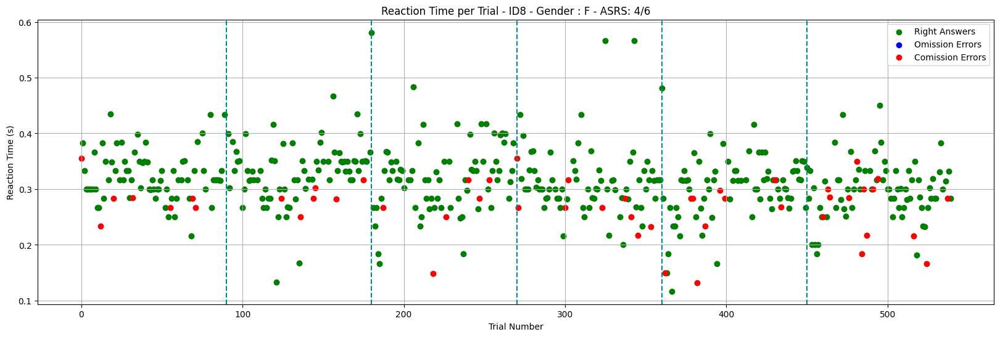

t=3.663736


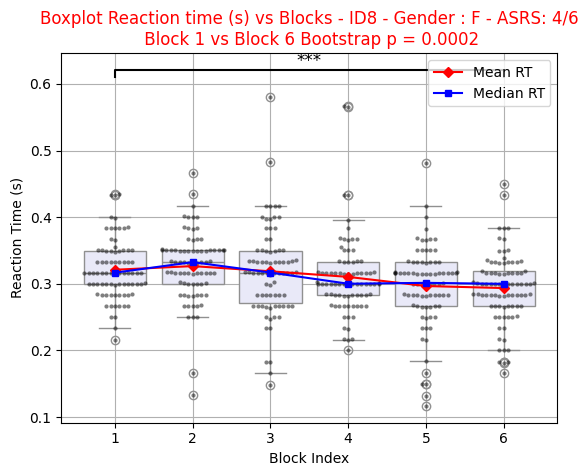

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 5', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.2777777777777778}]

SESSION DATE: 2026-06-02 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
12,2026-06-02,B,"30,20,20,12,12,30"


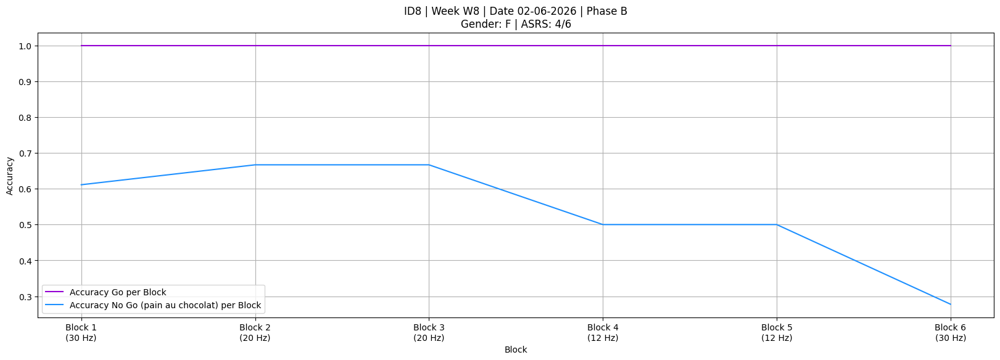

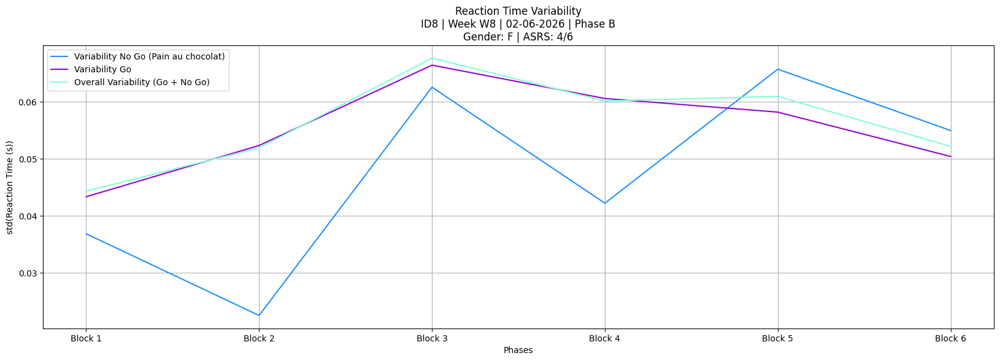

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,487.579602,No_Go,NaN,NaN,Correct,False,False,8
1,1,1,488.591491,Go,space,0.317317,Correct,False,False,8
2,1,2,489.608551,No_Go,space,0.300009,Incorrect,False,True,8
3,1,3,490.626656,Go,space,0.298216,Correct,False,False,8
4,1,4,491.641581,Go,space,0.283472,Correct,False,False,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1138.429738,Go,space,0.300289,Correct,False,False,8
536,6,536,1139.446500,Go,space,0.233463,Correct,False,False,8
537,6,537,1140.463288,Go,space,0.283269,Correct,False,False,8
538,6,538,1141.479841,Go,space,0.266767,Correct,False,False,8


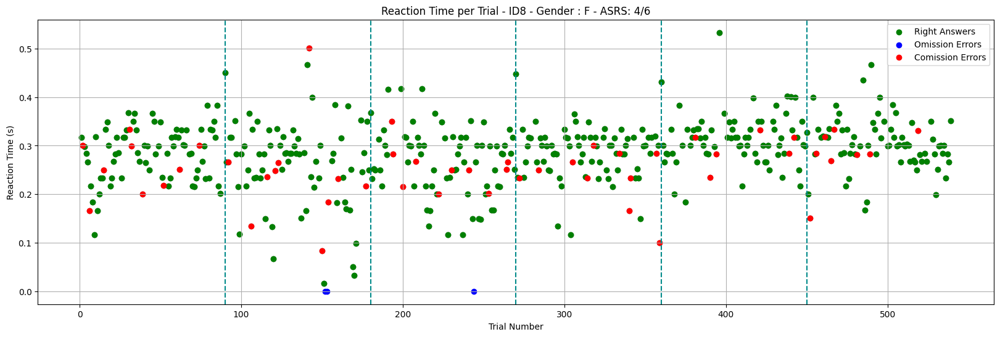

t=-2.423869


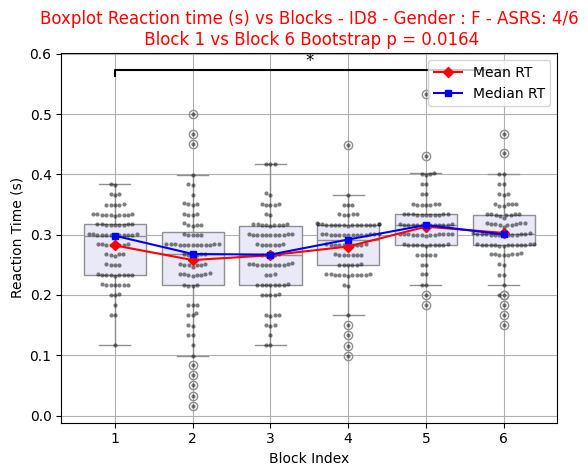

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 0.5},
 {'Block': 'Block 2',
  'Accuracy Go': 0.9722222222222222,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556}]

SESSION DATE: 2026-06-05 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
13,2026-06-05,B,"20,30,30,12,12,20"


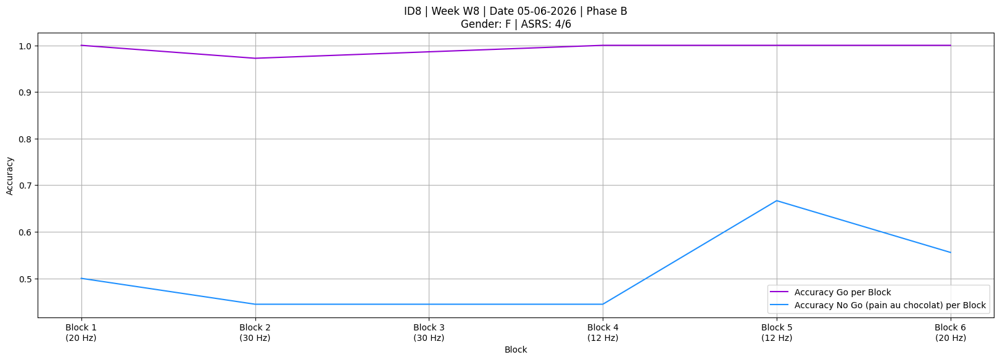

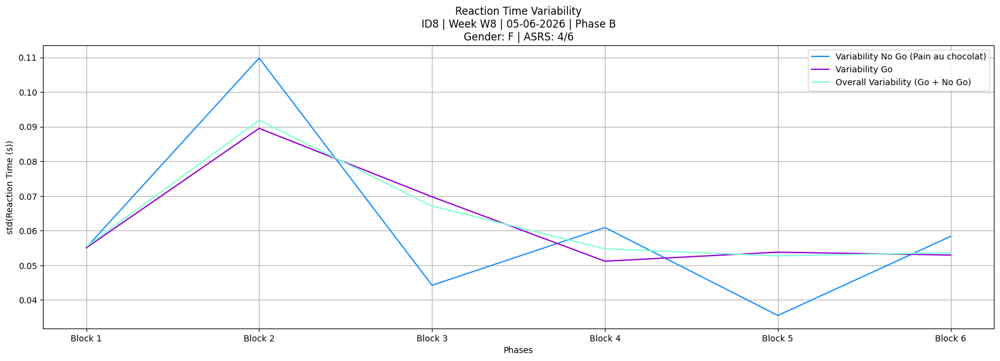

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,576.381169,Go,space,0.406663,Correct,False,False,8
1,1,1,577.387788,No_Go,space,0.250157,Incorrect,False,True,8
2,1,2,578.405066,Go,space,0.382921,Correct,False,False,8
3,1,3,579.422632,Go,space,0.266636,Correct,False,False,8
4,1,4,580.437800,Go,space,0.233675,Correct,False,False,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1226.177069,No_Go,space,0.299979,Incorrect,False,True,8
536,6,536,1227.193683,Go,space,0.300978,Correct,False,False,8
537,6,537,1228.211270,Go,space,0.249367,Correct,False,False,8
538,6,538,1229.227044,Go,space,0.283243,Correct,False,False,8


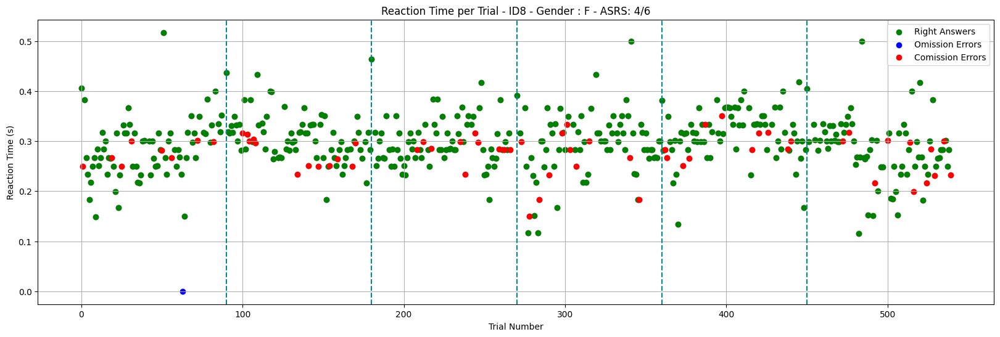

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=0.340136


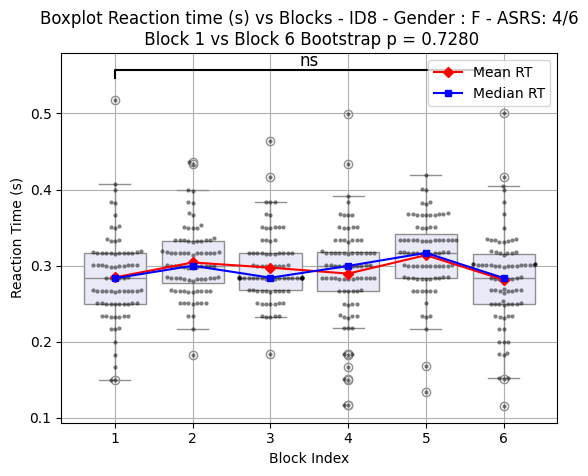

[{'Block': 'Block 1',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.5555555555555556},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3333333333333333},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889}]

SESSION DATE: 2026-06-09 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
14,2026-06-09,B,"12,30,12,20,30,20"


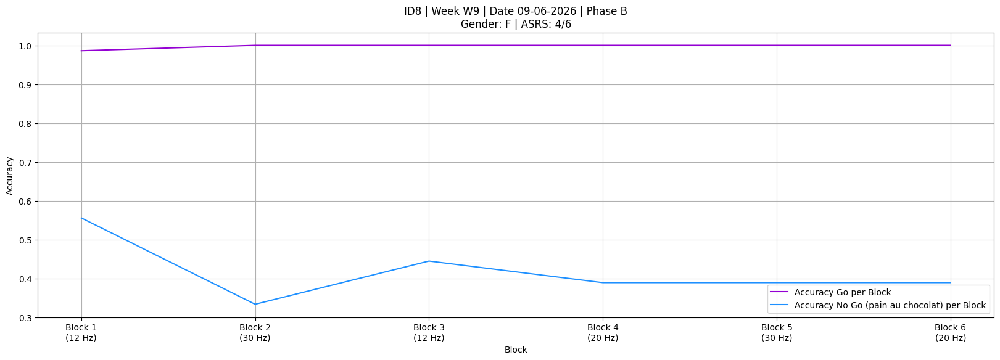

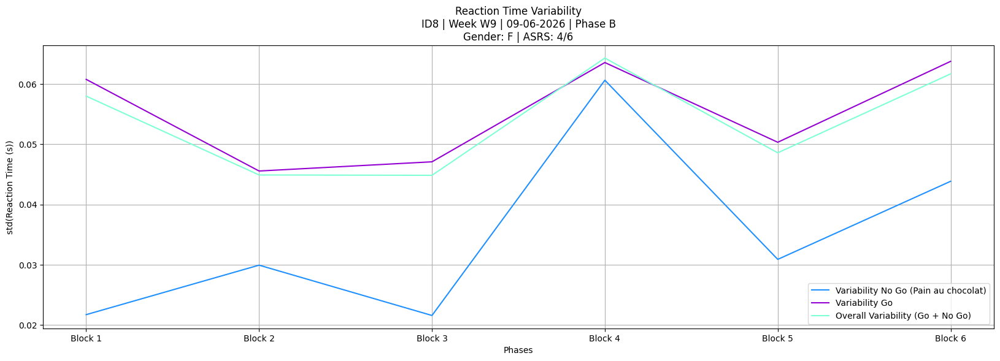

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,412.636887,Go,space,0.734592,Correct,False,False,8
1,1,1,413.639226,No_Go,space,0.348830,Incorrect,False,True,8
2,1,2,414.655433,Go,space,0.299666,Correct,False,False,8
3,1,3,415.671823,Go,space,0.383549,Correct,False,False,8
4,1,4,416.688974,Go,space,0.299533,Correct,False,False,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1062.756879,Go,space,0.333975,Correct,False,False,8
536,6,536,1063.774217,Go,space,0.350240,Correct,False,False,8
537,6,537,1064.790512,Go,space,0.316564,Correct,False,False,8
538,6,538,1065.807190,Go,space,0.299949,Correct,False,False,8


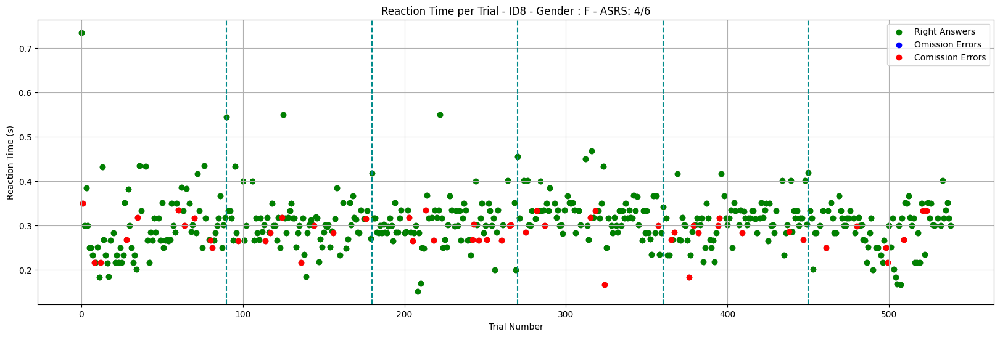

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=0.325957


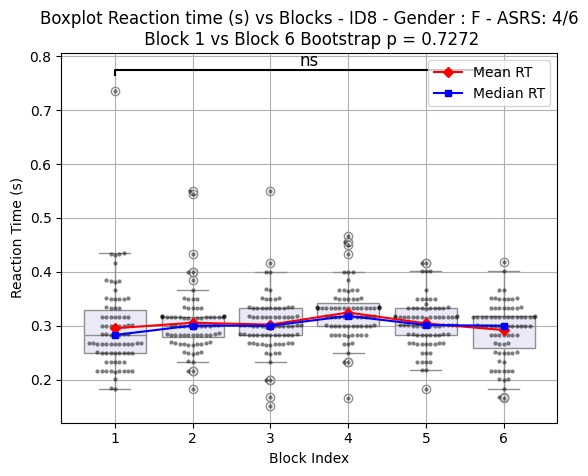

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.3888888888888889},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.4444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112}]

SESSION DATE: 2026-06-11 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
15,2026-06-11,B,"30,12,20,30,12,20"


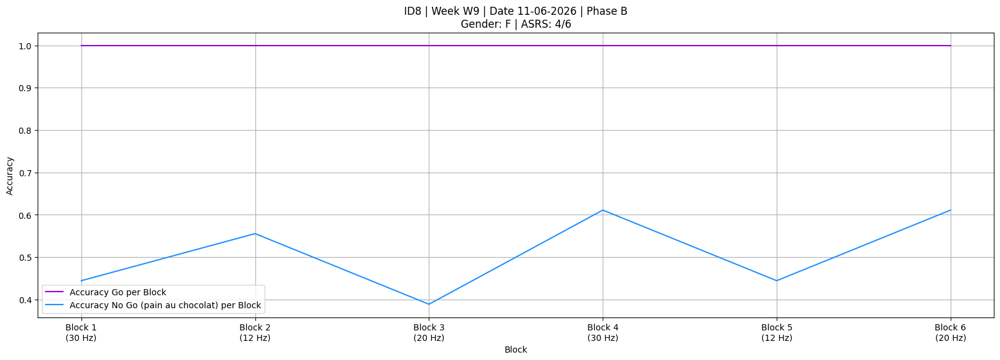

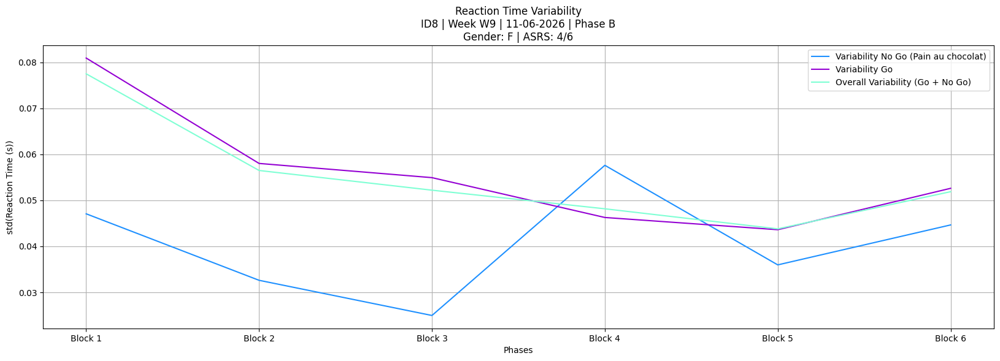

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,309.338410,Go,space,0.494069,Correct,False,False,8
1,1,1,310.349537,Go,space,0.282700,Correct,False,False,8
2,1,2,311.365161,Go,space,0.366589,Correct,False,False,8
3,1,3,312.381652,Go,space,0.316604,Correct,False,False,8
4,1,4,313.398362,No_Go,NaN,NaN,Correct,False,False,8
...,...,...,...,...,...,...,...,...,...,...
535,6,535,959.113965,No_Go,NaN,NaN,Correct,False,False,8
536,6,536,960.130508,Go,space,0.332881,Correct,False,False,8
537,6,537,961.148170,Go,space,0.381363,Correct,False,False,8
538,6,538,962.163575,Go,space,0.316644,Correct,False,False,8


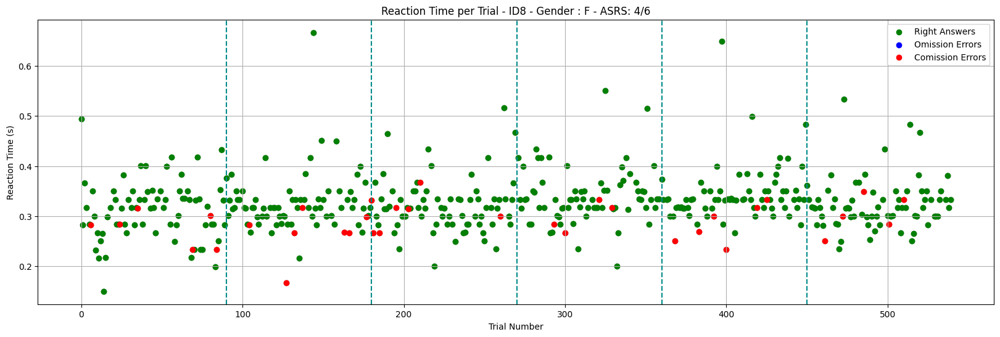

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 11.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=-1.662600


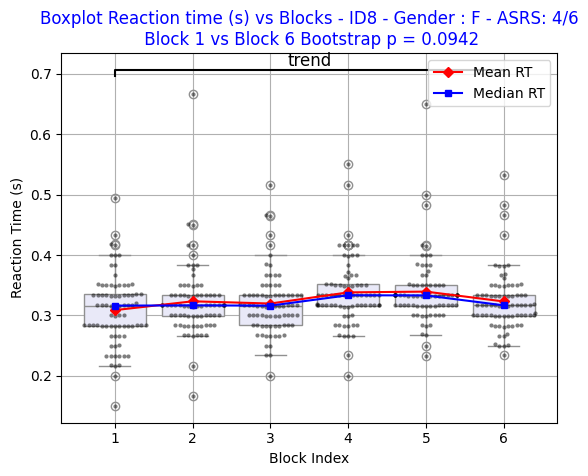

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222}]

SESSION DATE: 2026-06-12 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
16,2026-06-12,B,"20,30,12,20,20,30"


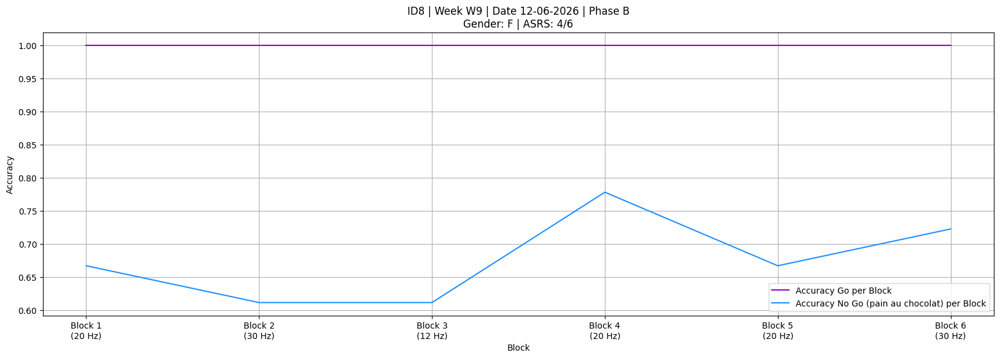

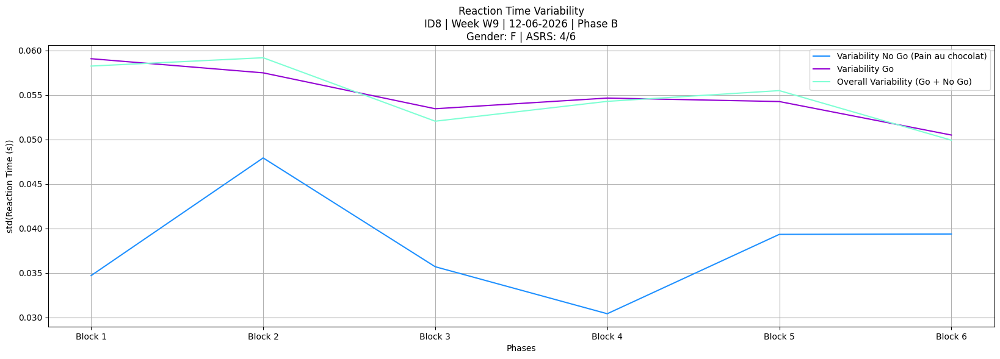

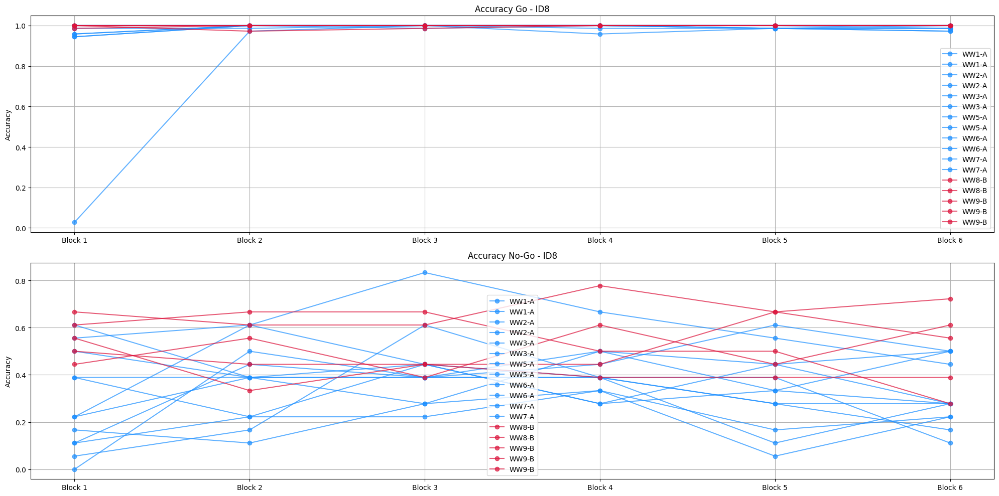

DATE: 2026-06-02 00:00:00
DATE: 2026-06-05 00:00:00
DATE: 2026-06-09 00:00:00
DATE: 2026-06-11 00:00:00
DATE: 2026-06-12 00:00:00


,DATE,PHASE,Go_12,Go_20,Go_30,NoGo_12,NoGo_20,NoGo_30,MeanGo,MeanNoGo
0,2026-04-14,A,0.824074,0.824074,0.824074,0.287037,0.287037,0.287037,NaN,NaN
1,2026-04-17,A,0.993056,0.993056,0.993056,0.314815,0.314815,0.314815,NaN,NaN
2,2026-04-21,A,0.997685,0.997685,0.997685,0.240741,0.240741,0.240741,NaN,NaN
3,2026-04-24,A,0.986111,0.986111,0.986111,0.277778,0.277778,0.277778,NaN,NaN
4,2026-04-27,A,0.993056,0.993056,0.993056,0.296296,0.296296,0.296296,NaN,NaN
5,2026-04-30,A,1.000000,1.000000,1.000000,0.379630,0.379630,0.379630,NaN,NaN
6,2026-05-12,A,0.990741,0.990741,0.990741,0.379630,0.379630,0.379630,NaN,NaN
7,2026-05-13,A,0.990741,0.990741,0.990741,0.212963,0.212963,0.212963,NaN,NaN
8,2026-05-18,A,0.997685,0.997685,0.997685,0.435185,0.435185,0.435185,NaN,NaN
9,2026-05-22,A,0.988426,0.988426,0.988426,0.370370,0.370370,0.370370,NaN,NaN


t=-1.079296
t=-4.070392
t=-0.203471
t=-0.764747


/tmp/ipykernel_1316/346653522.py:91: RuntimeWarning: divide by zero encountered in scalar divide
  t_distrib[b] = (np.mean(draw_x)-np.mean(draw_y))/np.sqrt(np.var(draw_x)/n+np.var(draw_y)/m)


t=-1.455214
t=-1.518460
Go A-A   p = 0.1560
Go A-B   p = 0.4444
Go B-B   p = 0.0700
NoGo A-A p = 0.0000
NoGo A-B p = 0.8458
NoGo B-B p = 0.1566


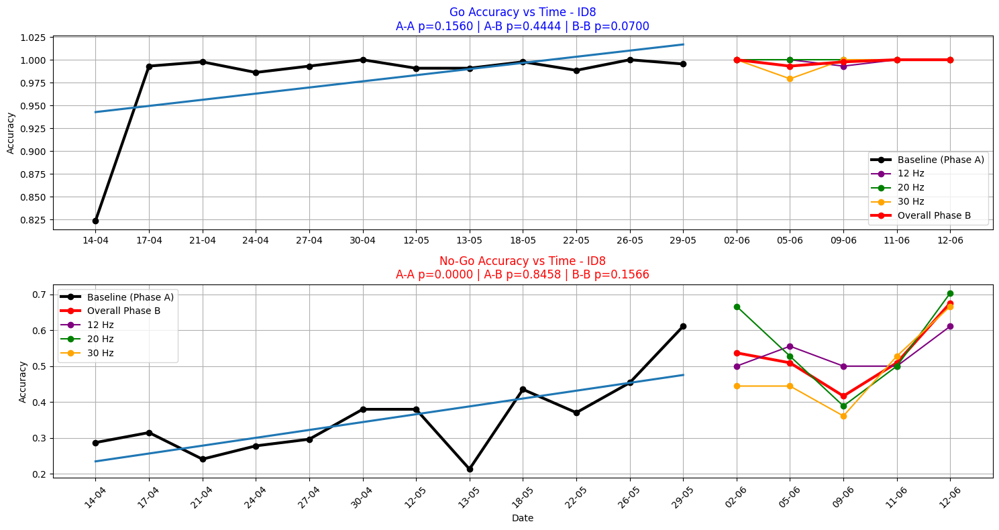

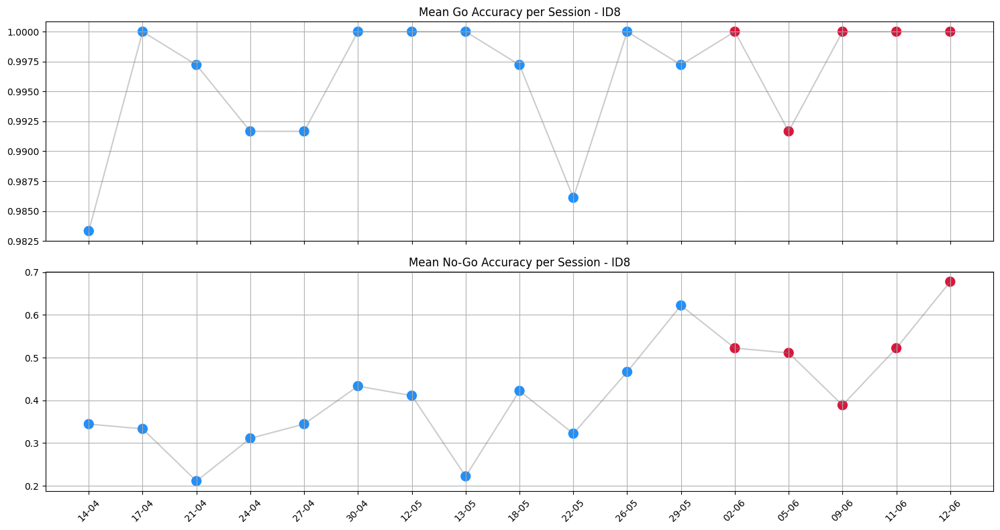

DATE: 2026-06-02 00:00:00
DATE: 2026-06-05 00:00:00
DATE: 2026-06-09 00:00:00
DATE: 2026-06-11 00:00:00
DATE: 2026-06-12 00:00:00


,DATE,Go_12,NoGo_12,Go_20,NoGo_20,Go_30,NoGo_30,MeanGo,MeanNoGo
0,2026-06-02,1.000000,0.500000,1.0,0.666667,1.000000,0.444444,1.000000,0.537037
1,2026-06-05,1.000000,0.555556,1.0,0.527778,0.979167,0.444444,0.993056,0.509259
2,2026-06-09,0.993056,0.500000,1.0,0.388889,1.000000,0.361111,0.997685,0.416667
3,2026-06-11,1.000000,0.500000,1.0,0.500000,1.000000,0.527778,1.000000,0.509259
4,2026-06-12,1.000000,0.611111,1.0,0.703704,1.000000,0.666667,1.000000,0.675926


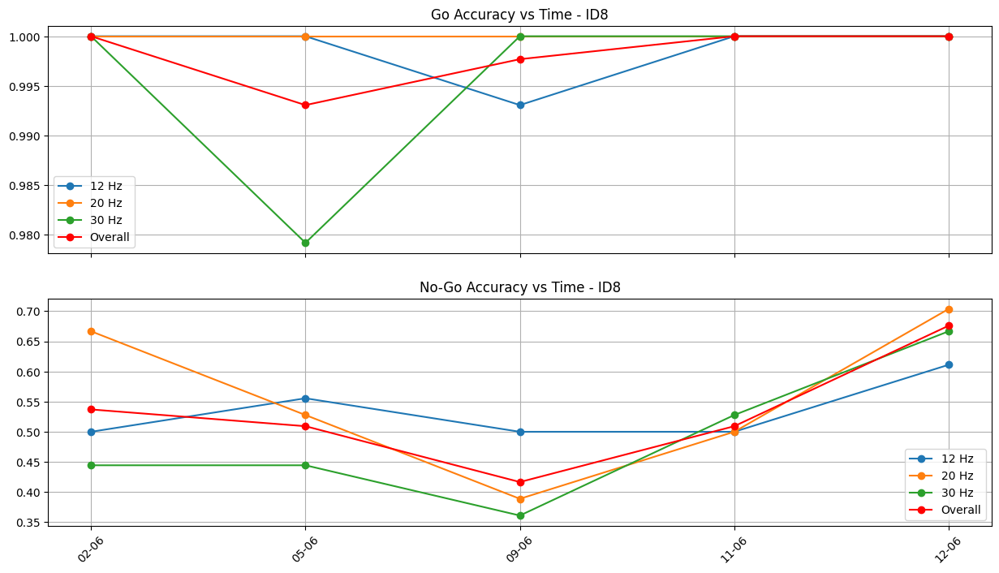

t=0.412983
t=-1.232968
t=-2.116926


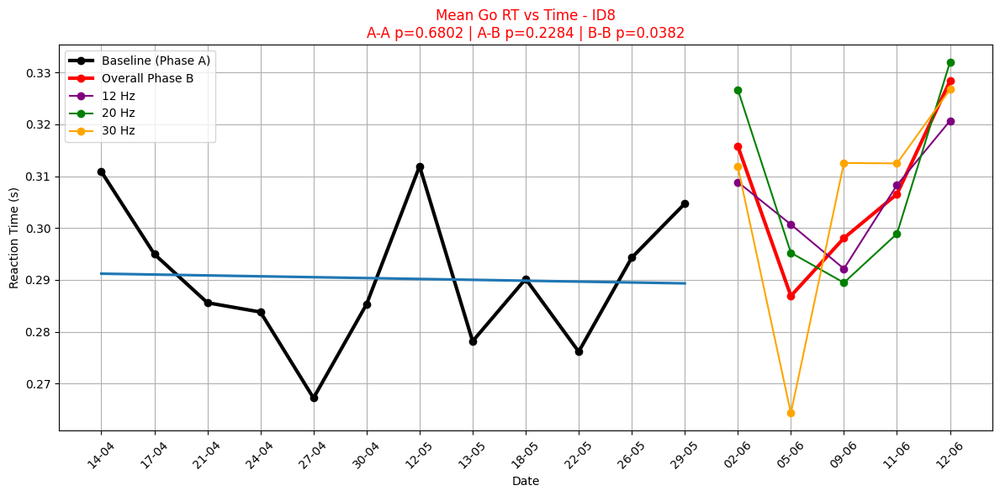

t=1.976884
t=1.961691
t=0.754694


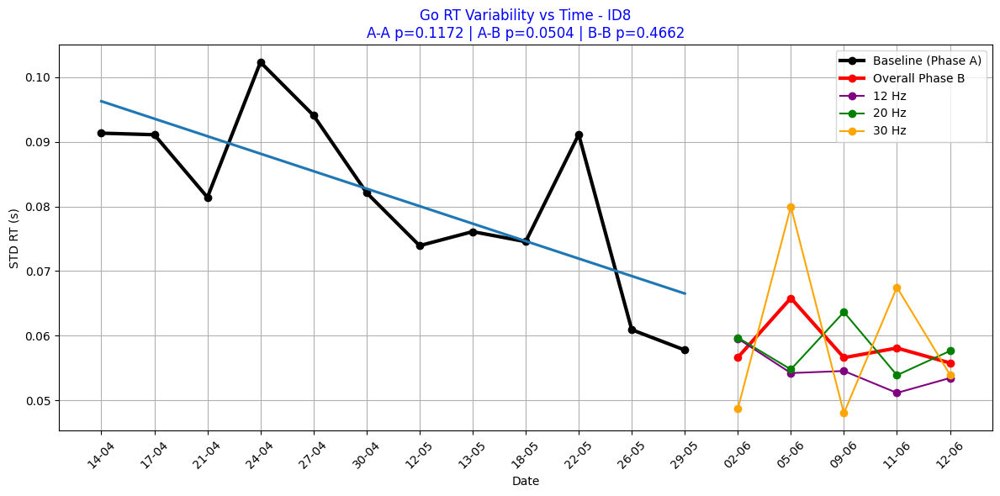

t=-2.483985
t=-0.548573
t=-1.905430


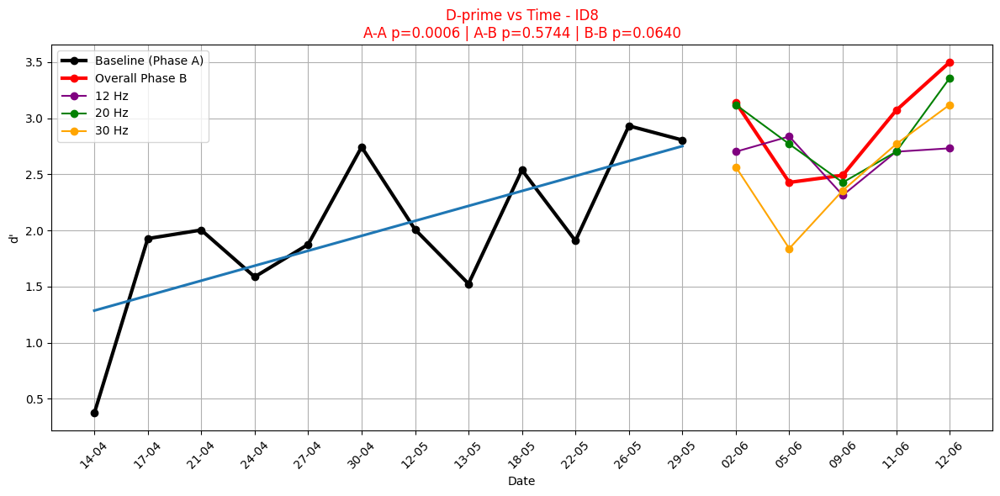

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime_All,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-14,A,4/6,NaN,NaN,NaN,0.371778,0.983333,0.344444,0.086069
1,2026-04-17,A,4/6,NaN,NaN,NaN,1.927670,1.000000,0.333333,0.082591
2,2026-04-21,A,4/6,NaN,NaN,NaN,2.003962,0.997222,0.211111,0.077369
3,2026-04-24,A,4/6,NaN,NaN,NaN,1.586399,0.991667,0.311111,0.094636
4,2026-04-27,A,4/6,7.5,5.0,0.0,1.875455,0.991667,0.344444,0.092142
5,2026-04-30,A,4/6,7.0,3.0,3.0,2.743695,1.000000,0.433333,0.080553
6,2026-05-12,A,4/6,7.0,5.0,3.0,2.008310,1.000000,0.411111,0.058878
7,2026-05-13,A,4/6,NaN,NaN,3.0,1.524711,1.000000,0.222222,0.069539
8,2026-05-18,A,4/6,6.0,4.0,5.0,2.538588,0.997222,0.422222,0.070455
9,2026-05-22,A,4/6,1.0,4.0,5.0,1.907476,0.986111,0.322222,0.086106


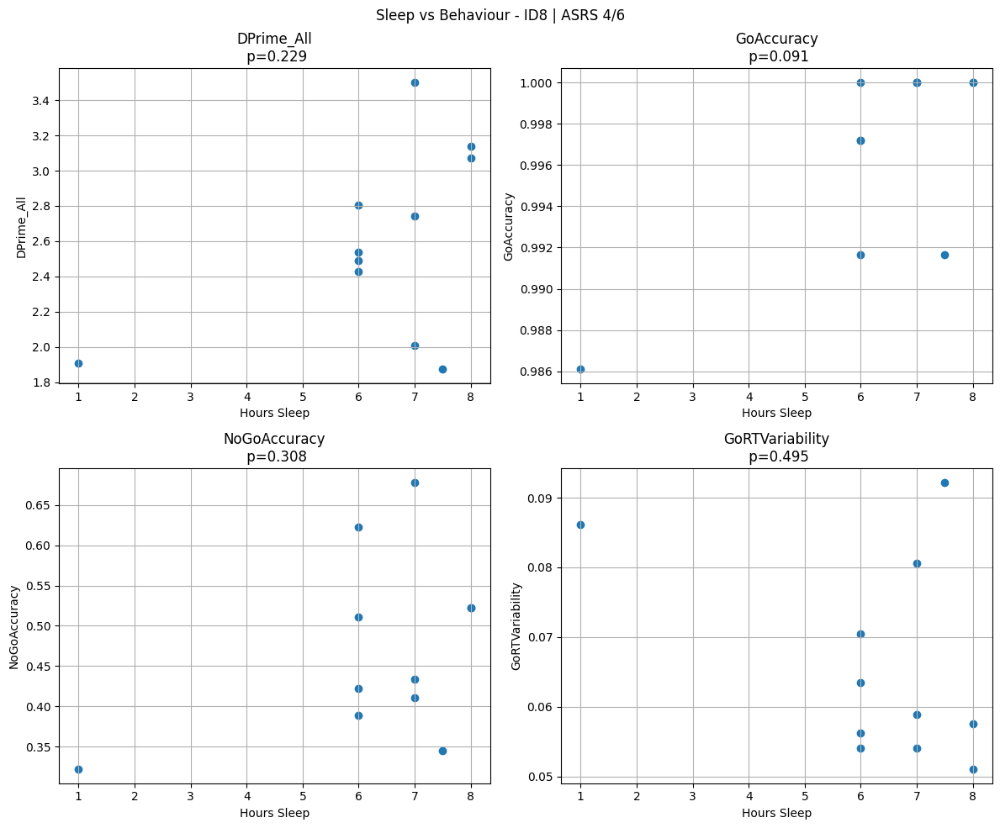

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime_All,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-14,A,4/6,NaN,NaN,NaN,0.371778,0.983333,0.344444,0.086069
1,2026-04-17,A,4/6,NaN,NaN,NaN,1.927670,1.000000,0.333333,0.082591
2,2026-04-21,A,4/6,NaN,NaN,NaN,2.003962,0.997222,0.211111,0.077369
3,2026-04-24,A,4/6,NaN,NaN,NaN,1.586399,0.991667,0.311111,0.094636
4,2026-04-27,A,4/6,7.5,5.0,0.0,1.875455,0.991667,0.344444,0.092142
5,2026-04-30,A,4/6,7.0,3.0,3.0,2.743695,1.000000,0.433333,0.080553
6,2026-05-12,A,4/6,7.0,5.0,3.0,2.008310,1.000000,0.411111,0.058878
7,2026-05-13,A,4/6,NaN,NaN,3.0,1.524711,1.000000,0.222222,0.069539
8,2026-05-18,A,4/6,6.0,4.0,5.0,2.538588,0.997222,0.422222,0.070455
9,2026-05-22,A,4/6,1.0,4.0,5.0,1.907476,0.986111,0.322222,0.086106


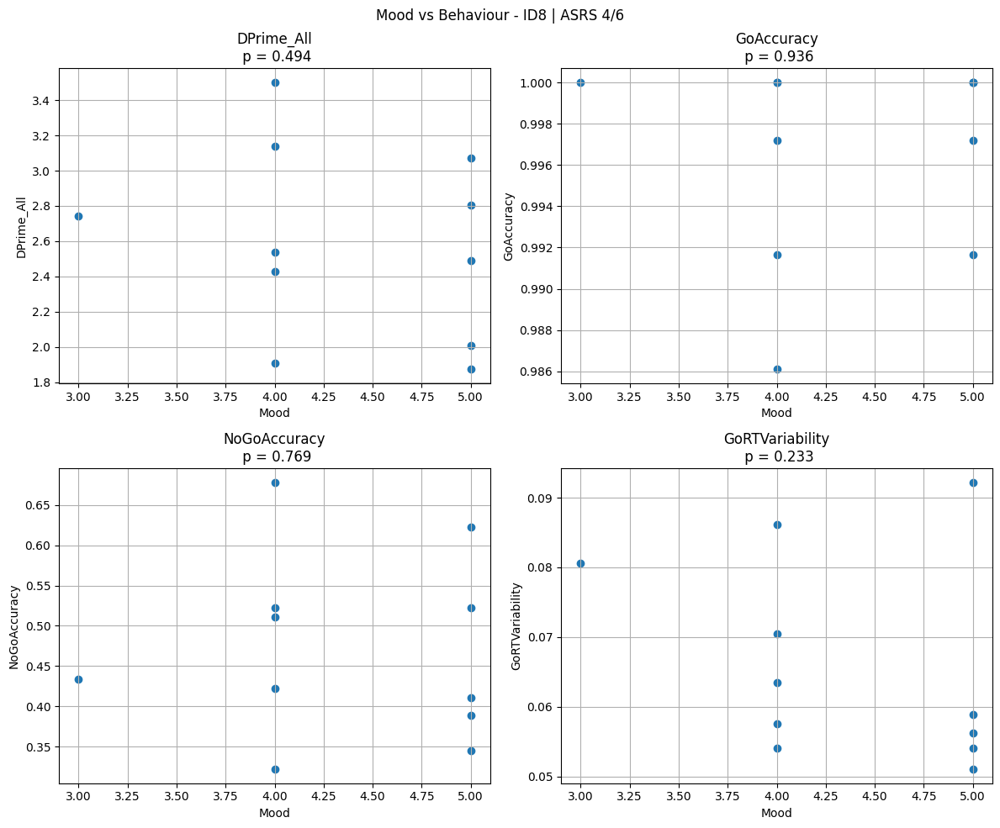

In [1042]:
df_clean_list = pipeline(id = 8)
#display(df_clean_list)

#**ID10**

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,255.681165,Go,NaN,NaN,Incorrect,True,False,10
1,1,1,256.675194,Go,NaN,NaN,Incorrect,True,False,10
2,1,2,257.657825,Go,NaN,NaN,Incorrect,True,False,10
3,1,3,258.641636,Go,NaN,NaN,Incorrect,True,False,10
4,1,4,259.628052,Go,NaN,NaN,Incorrect,True,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,888.396458,Go,space,0.348847,Correct,False,False,10
536,6,536,889.378587,Go,space,0.416690,Correct,False,False,10
537,6,537,890.363271,Go,space,0.448664,Correct,False,False,10
538,6,538,891.345186,Go,space,0.416811,Correct,False,False,10


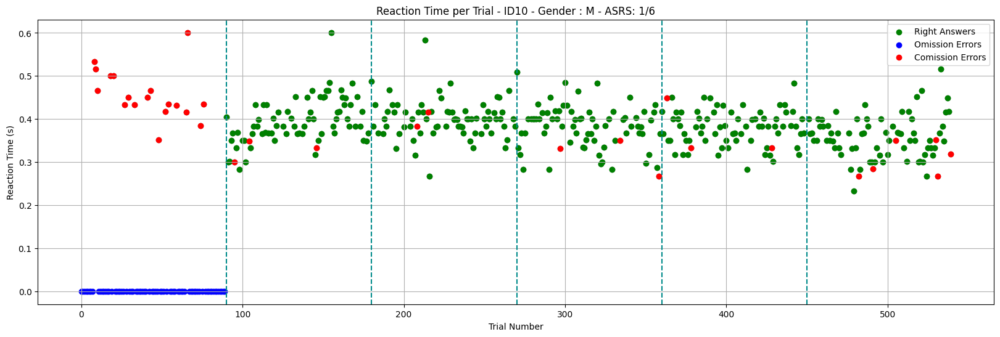

t=7.107285


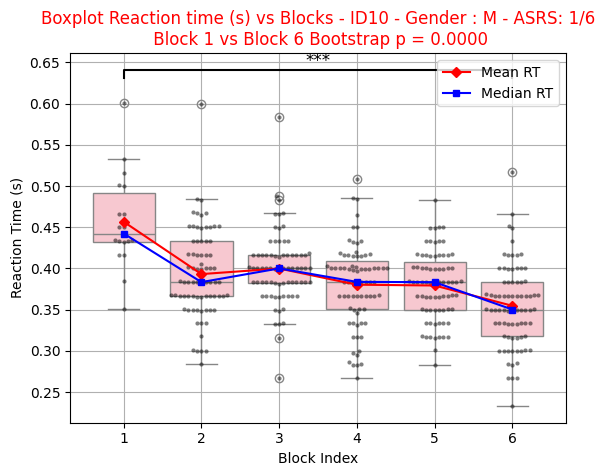

[{'Block': 'Block 1', 'Accuracy Go': 0.0, 'Accuracy No Go': 0.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666}]

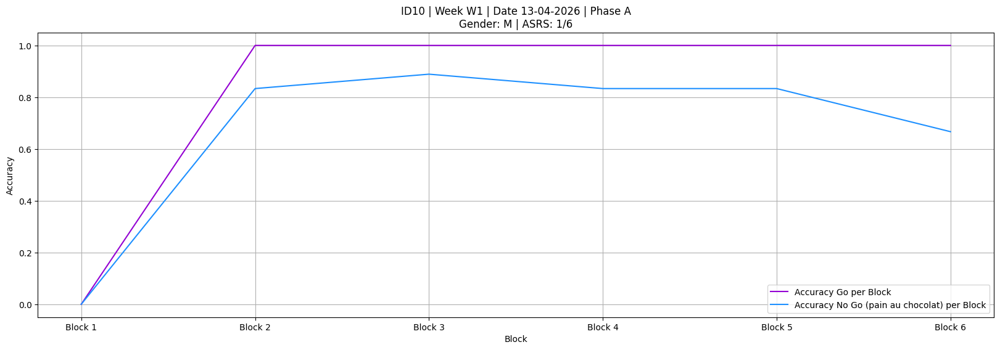

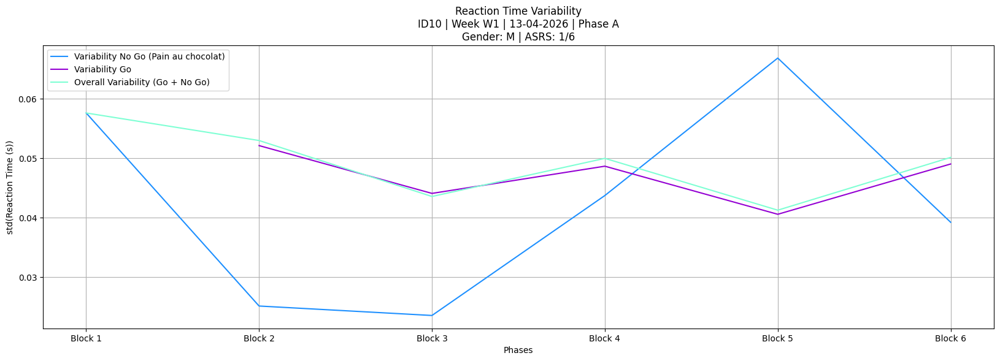

/tmp/ipykernel_1316/134858478.py:16: RuntimeWarning: Mean of empty slice
  np.nanmean(go_rts)


,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,199.905575,No_Go,space,0.377372,Incorrect,False,True,10
1,1,1,200.932812,No_Go,space,0.366845,Incorrect,False,True,10
2,1,2,201.949499,Go,space,0.450324,Correct,False,False,10
3,1,3,202.967518,Go,space,0.416503,Correct,False,False,10
4,1,4,203.983032,No_Go,NaN,NaN,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,854.208430,Go,space,0.400010,Correct,False,False,10
536,6,536,855.225041,Go,space,0.333384,Correct,False,False,10
537,6,537,856.241609,Go,space,0.350179,Correct,False,False,10
538,6,538,857.258135,No_Go,space,0.283370,Incorrect,False,True,10


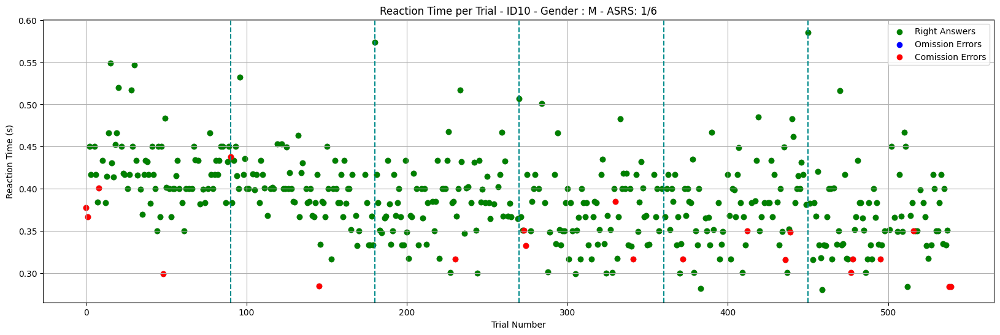

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=7.712322


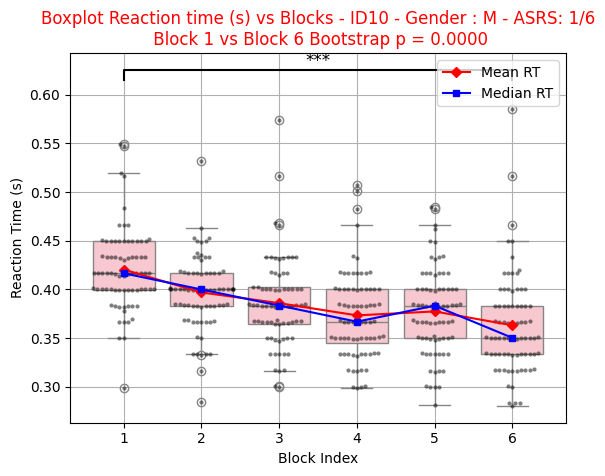

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666}]

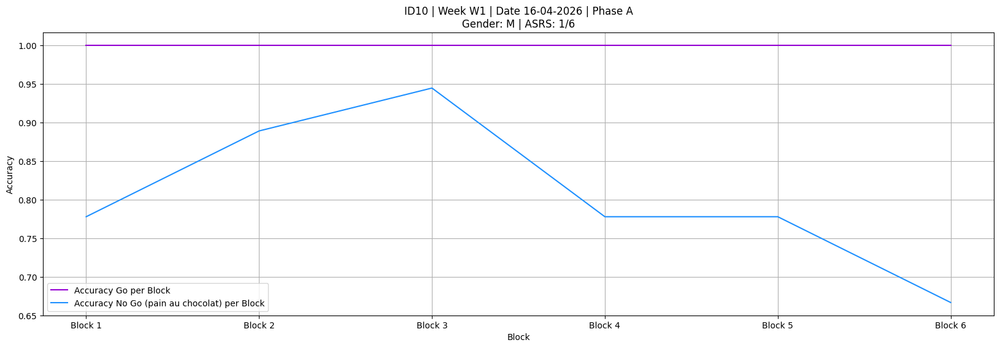

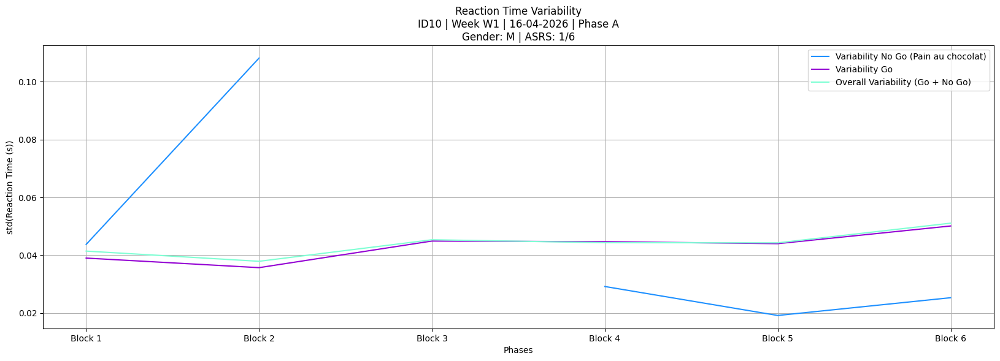

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,320.946991,Go,space,0.425486,Correct,False,False,10
1,1,1,321.939075,No_Go,space,0.333408,Incorrect,False,True,10
2,1,2,322.922281,No_Go,space,0.450310,Incorrect,False,True,10
3,1,3,323.906091,No_Go,NaN,NaN,Correct,False,False,10
4,1,4,324.889107,Go,space,0.383337,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,954.757873,Go,space,0.299624,Correct,False,False,10
536,6,536,955.739424,No_Go,NaN,NaN,Correct,False,False,10
537,6,537,956.722695,Go,space,0.350230,Correct,False,False,10
538,6,538,957.706085,Go,space,0.366751,Correct,False,False,10


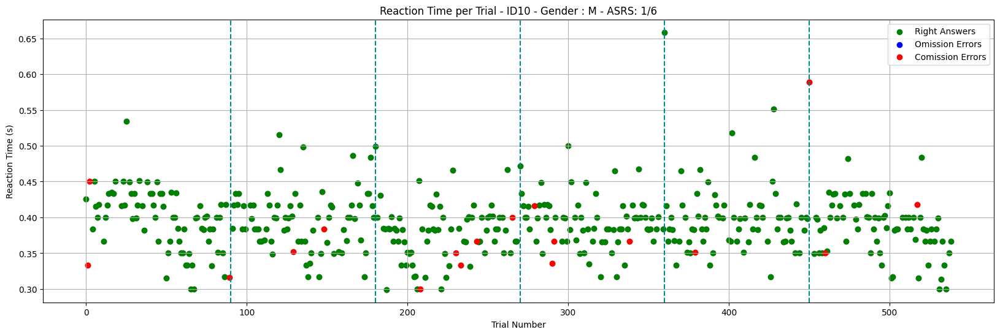

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=1.170066


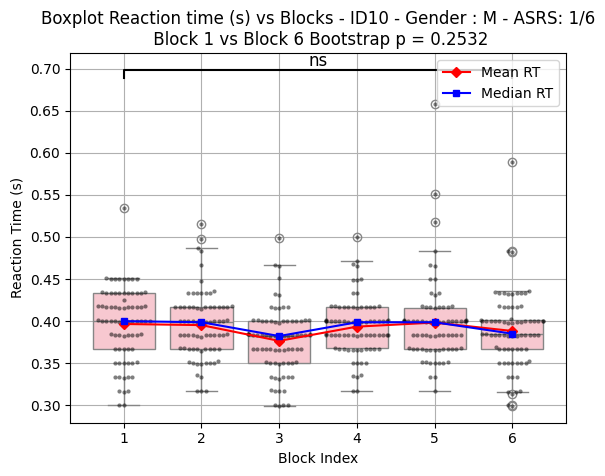

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334}]

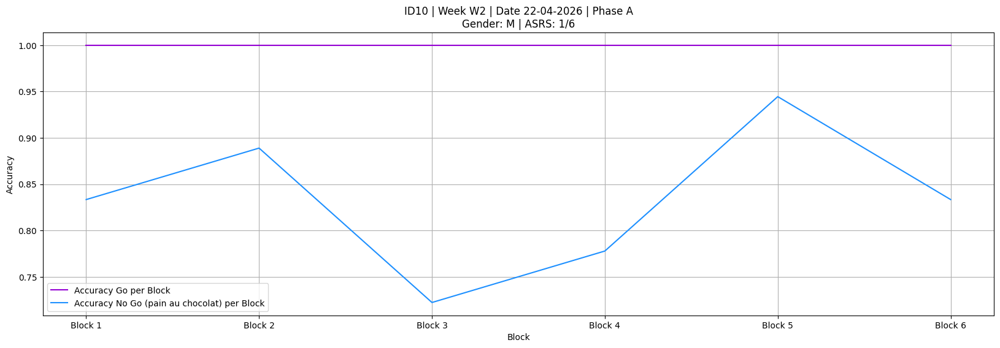

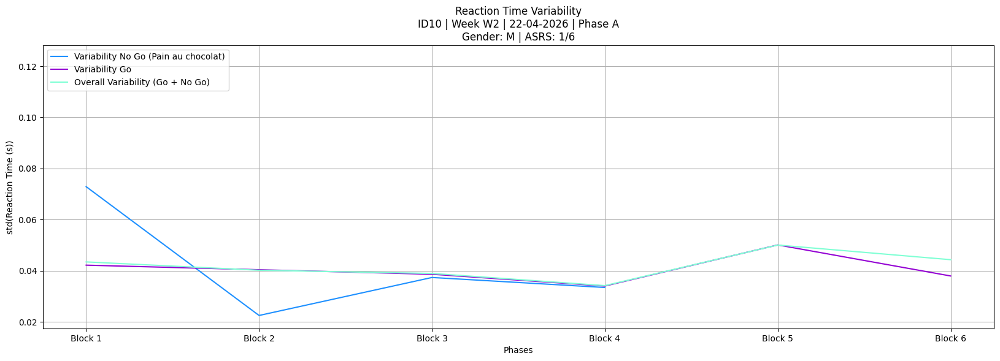

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,28.906297,Go,space,0.455367,Correct,False,False,10
1,1,1,29.945186,Go,space,0.399616,Correct,False,False,10
2,1,2,30.961864,Go,space,0.450138,Correct,False,False,10
3,1,3,31.980528,Go,space,0.414567,Correct,False,False,10
4,1,4,32.995131,Go,space,0.416735,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,687.320960,Go,space,0.399962,Correct,False,False,10
536,6,536,688.337833,Go,space,0.399599,Correct,False,False,10
537,6,537,689.355695,Go,space,0.398426,Correct,False,False,10
538,6,538,690.370690,Go,space,0.383469,Correct,False,False,10


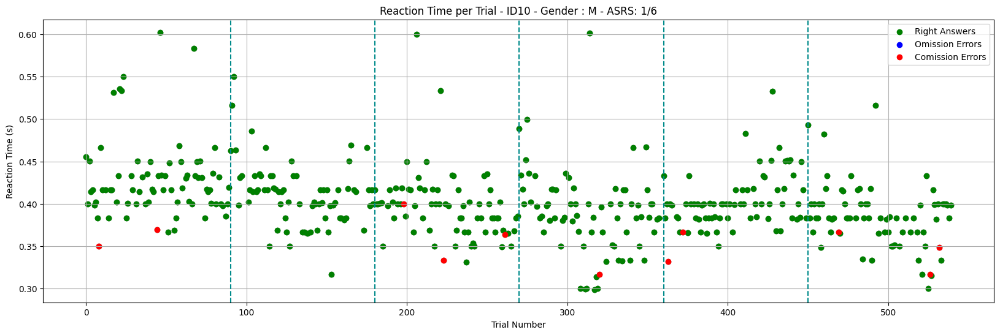

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 14.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=6.359207


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


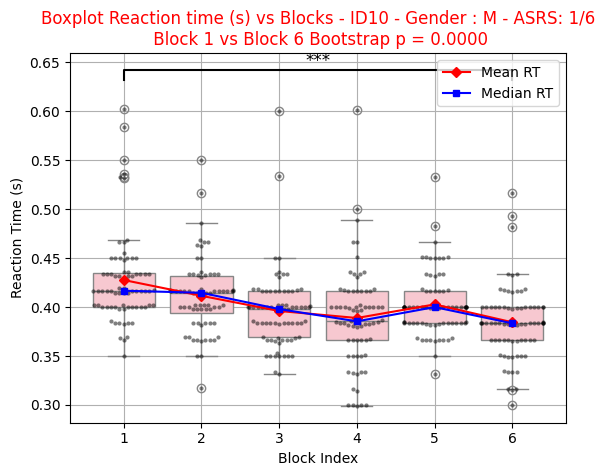

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334}]

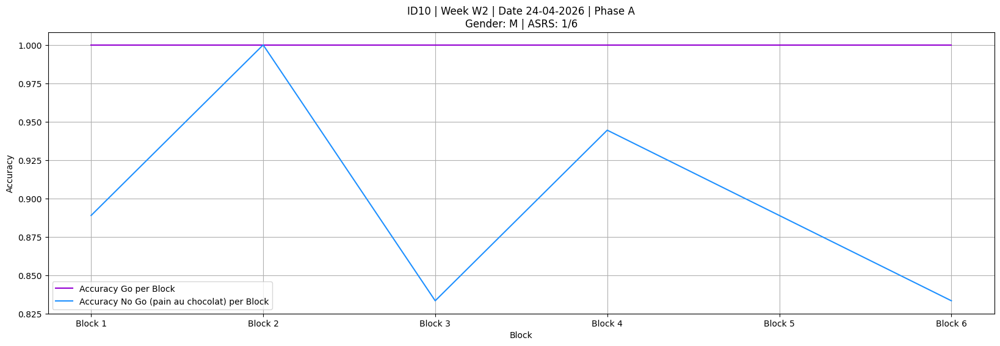

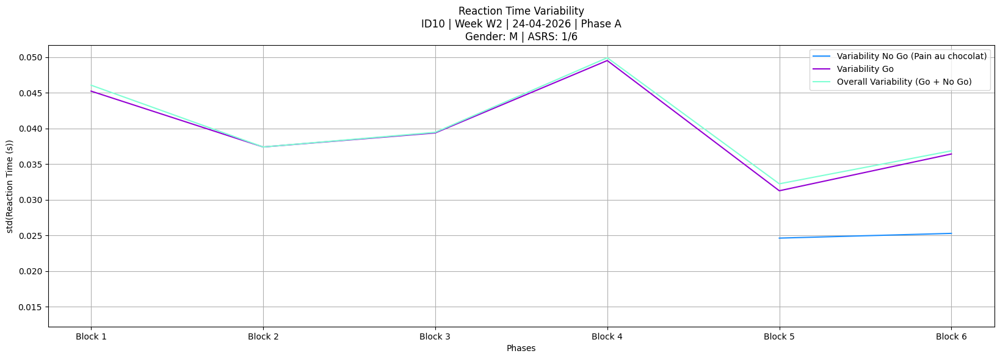

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,142.926139,Go,space,0.395263,Correct,False,False,10
1,1,1,143.970802,Go,space,0.433092,Correct,False,False,10
2,1,2,144.986343,No_Go,NaN,NaN,Correct,False,False,10
3,1,3,146.004813,Go,space,0.433126,Correct,False,False,10
4,1,4,147.020533,Go,space,0.466326,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,795.335095,Go,space,0.383015,Correct,False,False,10
536,6,536,796.350808,Go,space,0.383021,Correct,False,False,10
537,6,537,797.366535,Go,space,0.382993,Correct,False,False,10
538,6,538,798.382266,Go,space,0.366276,Correct,False,False,10


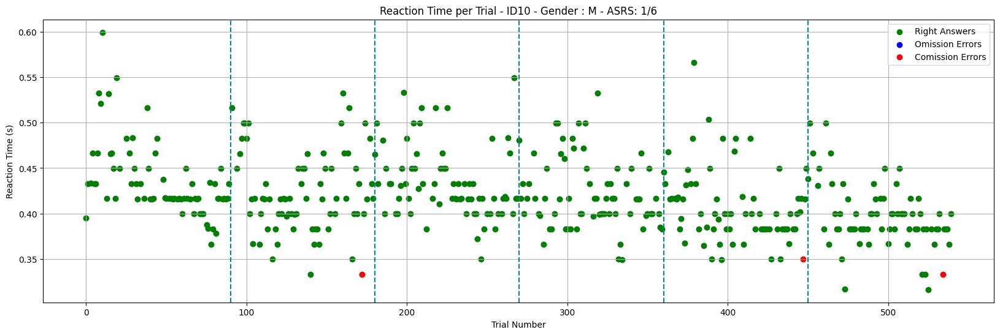

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 18.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 15.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=6.275562


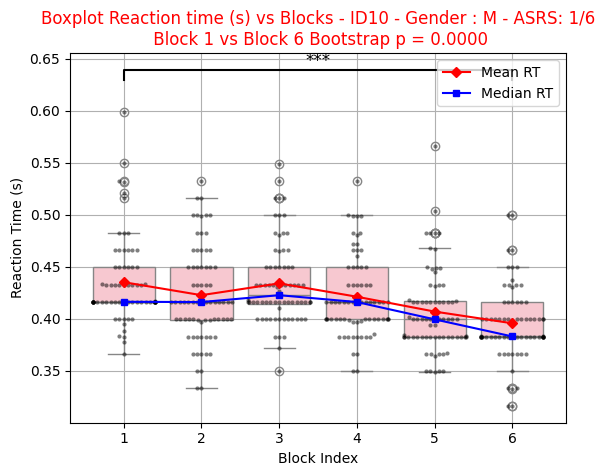

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

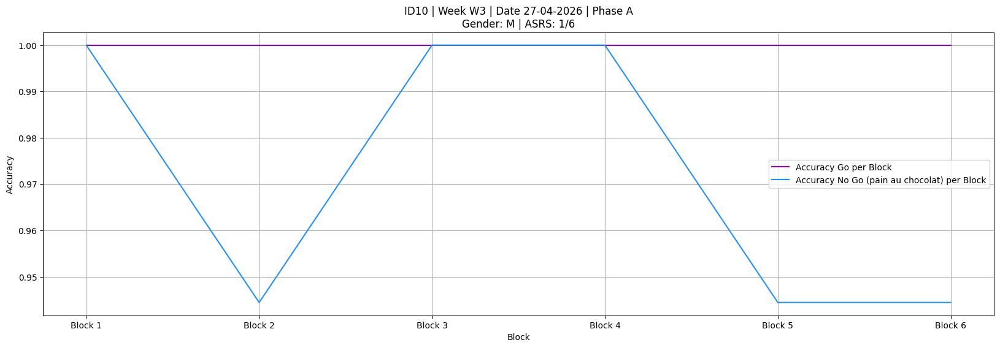

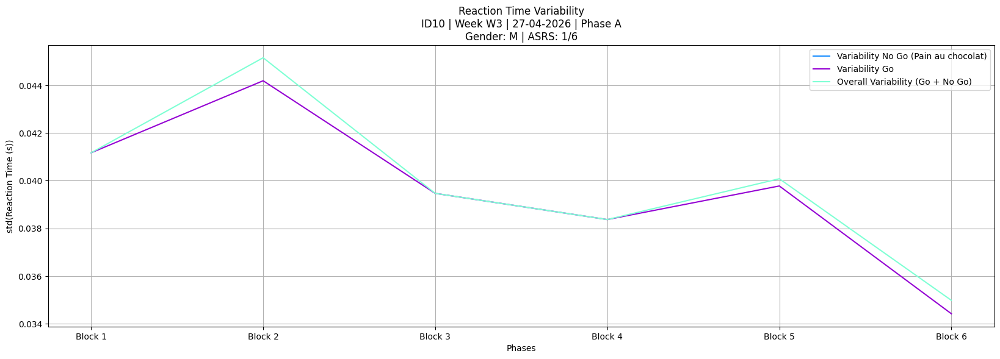

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,238.722044,Go,space,0.547364,Correct,False,False,10
1,1,1,239.753005,Go,space,0.416614,Correct,False,False,10
2,1,2,240.769293,Go,space,0.433604,Correct,False,False,10
3,1,3,241.785980,Go,space,0.383425,Correct,False,False,10
4,1,4,242.802840,Go,space,0.434002,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,891.040861,Go,space,0.433285,Correct,False,False,10
536,6,536,892.057493,Go,space,0.399821,Correct,False,False,10
537,6,537,893.074076,Go,space,0.333331,Correct,False,False,10
538,6,538,894.090816,Go,space,0.365600,Correct,False,False,10


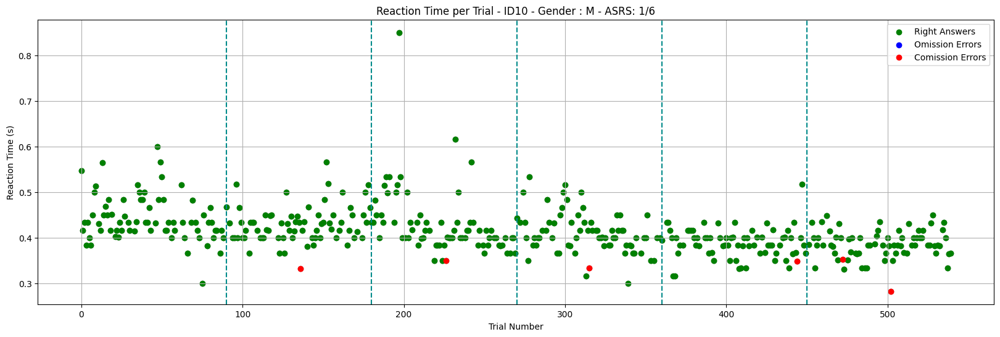

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=8.316205


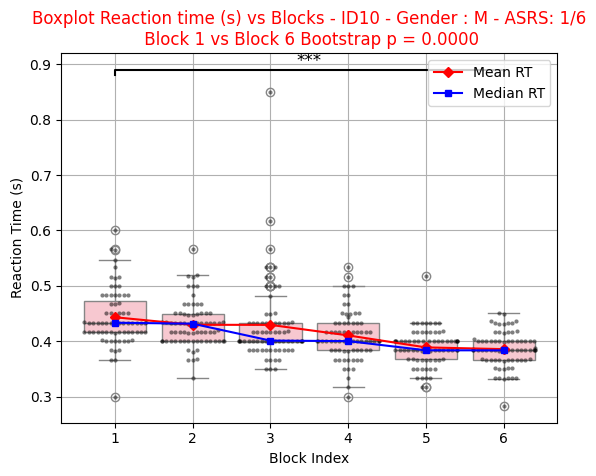

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

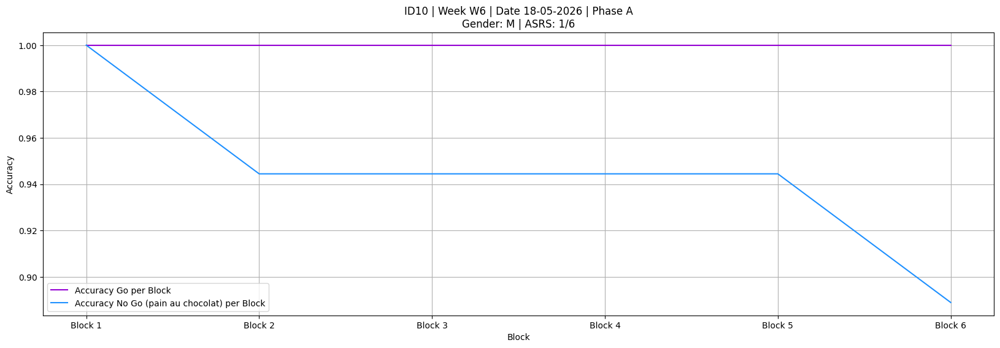

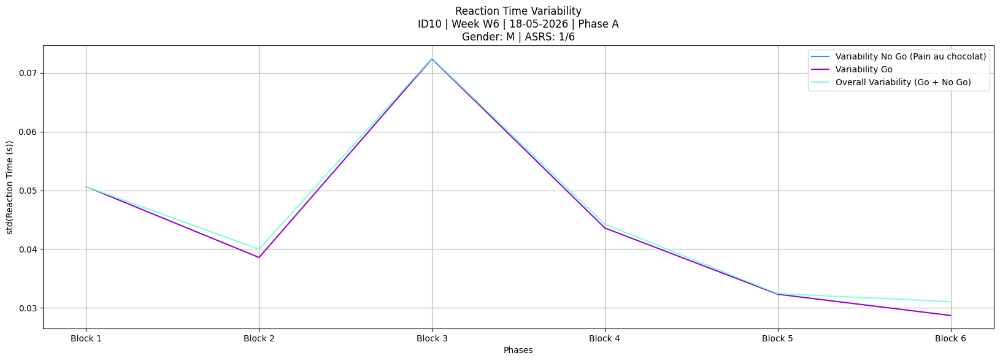

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,207.313239,Go,space,0.389513,Correct,False,False,10
1,1,1,208.353150,Go,space,0.366202,Correct,False,False,10
2,1,2,209.369745,Go,space,0.400105,Correct,False,False,10
3,1,3,210.386304,Go,space,0.366650,Correct,False,False,10
4,1,4,211.403558,Go,space,0.349460,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,857.157515,Go,space,0.452518,Correct,False,False,10
536,6,536,858.173912,No_Go,NaN,NaN,Correct,False,False,10
537,6,537,859.191381,Go,space,0.382578,Correct,False,False,10
538,6,538,860.209373,Go,space,0.347762,Correct,False,False,10


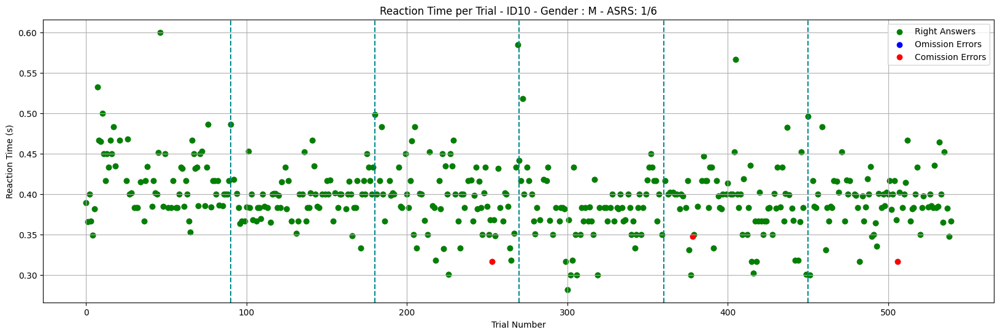

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 13.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=4.056196


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


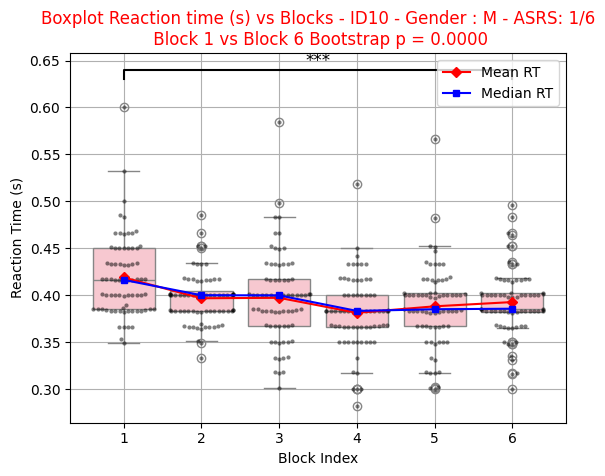

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

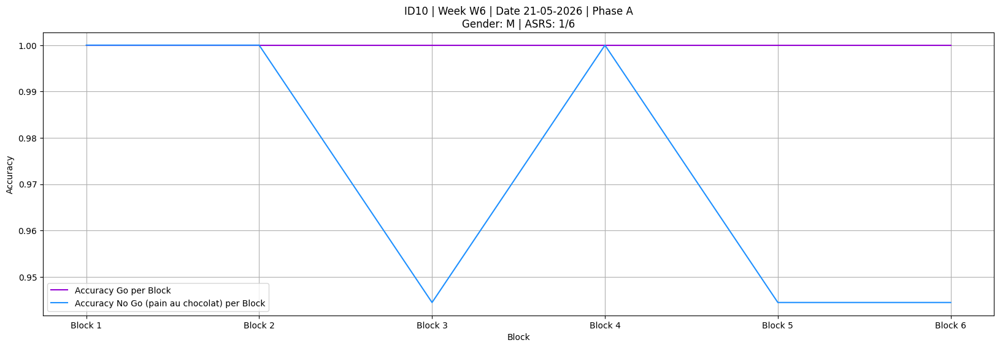

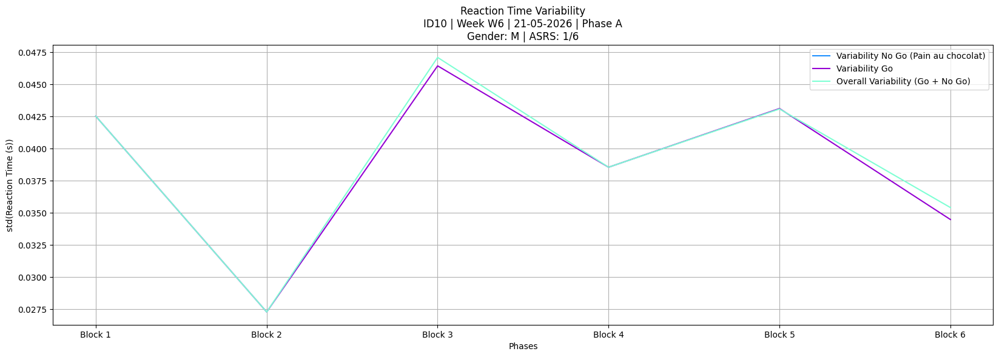

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,204.393733,No_Go,NaN,NaN,Correct,False,False,10
1,1,1,205.404770,Go,space,0.499841,Correct,False,False,10
2,1,2,206.421151,Go,space,0.467173,Correct,False,False,10
3,1,3,207.437747,Go,space,0.500454,Correct,False,False,10
4,1,4,208.454663,Go,space,0.501888,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,856.067261,Go,space,0.383122,Correct,False,False,10
536,6,536,857.085260,Go,space,0.381979,Correct,False,False,10
537,6,537,858.100639,Go,space,0.366662,Correct,False,False,10
538,6,538,859.117284,Go,space,0.366615,Correct,False,False,10


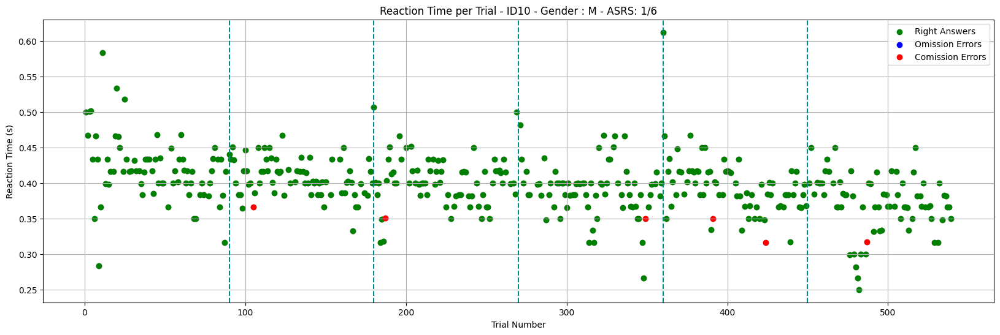

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 13.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=6.777951


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


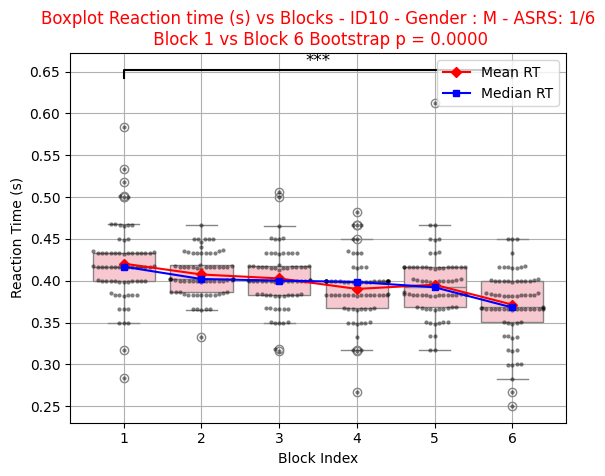

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

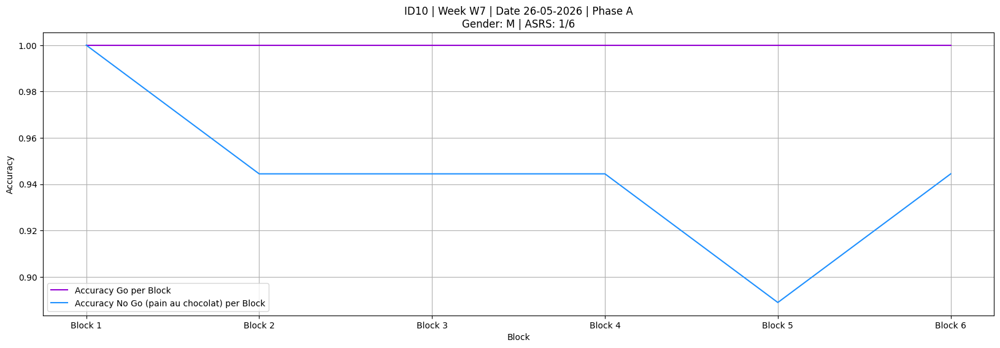

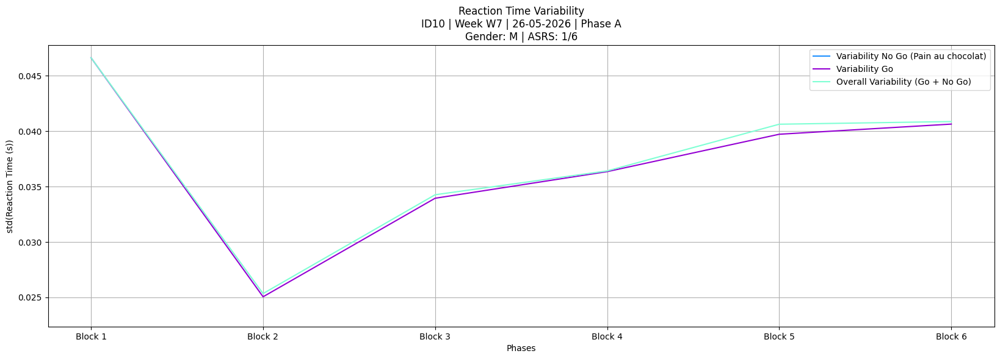

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,202.142399,Go,space,0.444448,Correct,False,False,10
1,1,1,203.170222,Go,space,0.433255,Correct,False,False,10
2,1,2,204.186784,Go,space,0.450104,Correct,False,False,10
3,1,3,205.203952,Go,space,0.399614,Correct,False,False,10
4,1,4,206.222522,No_Go,space,0.414195,Incorrect,False,True,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,851.890358,Go,space,0.415580,Correct,False,False,10
536,6,536,852.905693,Go,space,0.400097,Correct,False,False,10
537,6,537,853.923708,Go,space,0.415566,Correct,False,False,10
538,6,538,854.938986,Go,space,0.416636,Correct,False,False,10


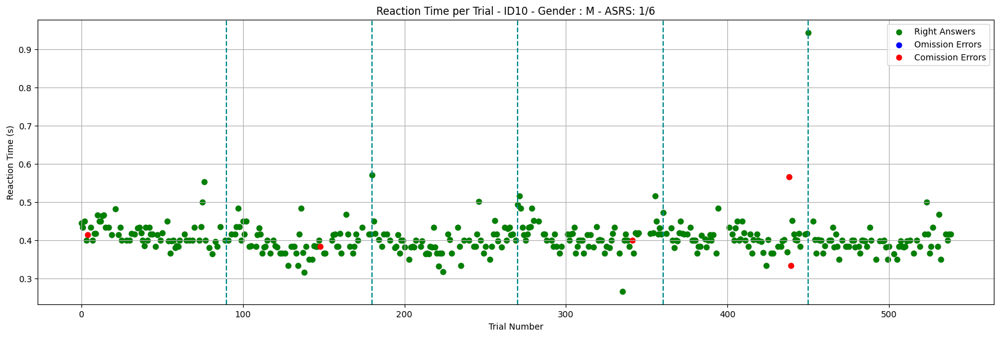

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 10.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 14.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=1.541610


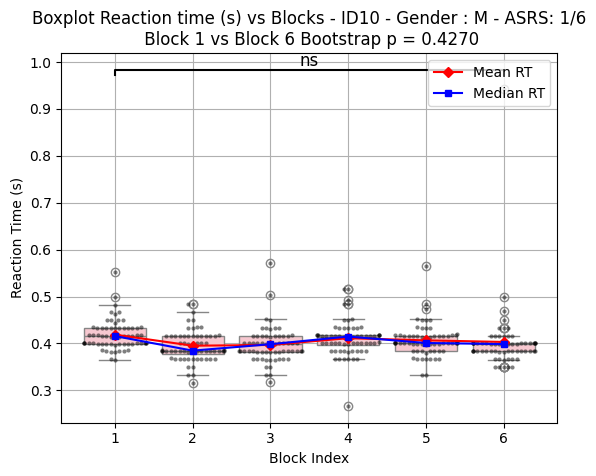

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9629629629629629},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9629629629629629},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9629629629629629},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9259259259259259},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

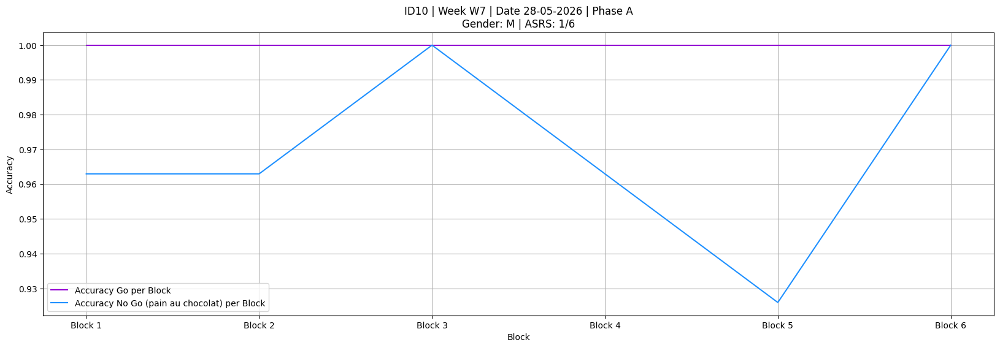

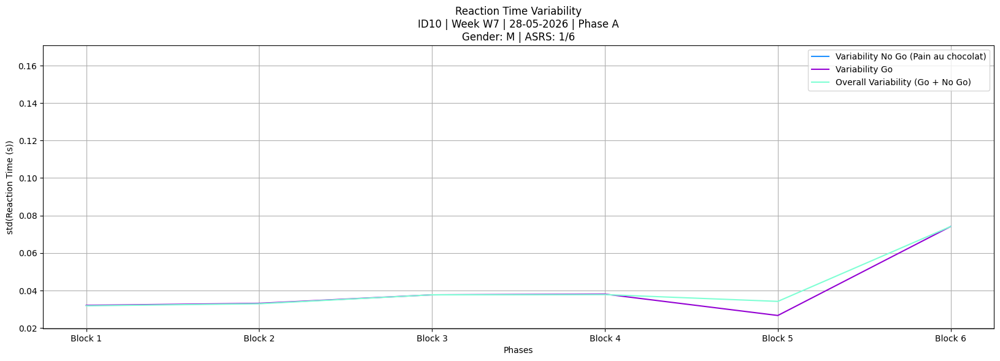

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,235.976966,Go,space,0.412219,Correct,False,False,10
1,1,1,237.005799,No_Go,space,0.383265,Incorrect,False,True,10
2,1,2,238.022330,Go,space,0.550290,Correct,False,False,10
3,1,3,239.039390,Go,space,0.366519,Correct,False,False,10
4,1,4,240.056952,Go,space,0.450491,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,886.428200,No_Go,NaN,NaN,Correct,False,False,10
536,6,536,887.446286,Go,space,0.381884,Correct,False,False,10
537,6,537,888.461591,Go,space,0.366545,Correct,False,False,10
538,6,538,889.479522,Go,space,0.398766,Correct,False,False,10


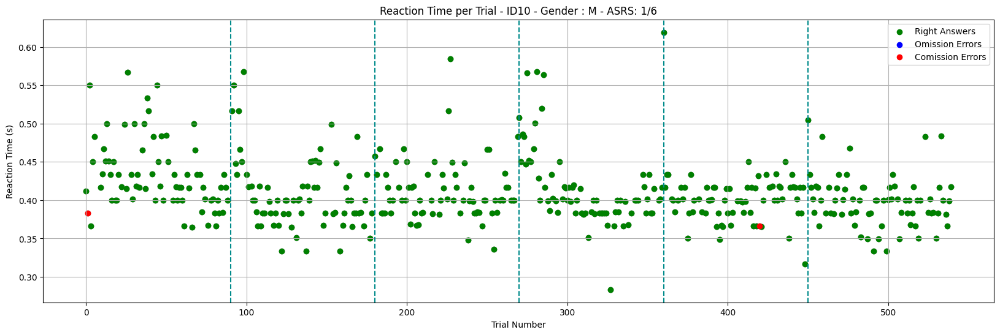

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 12.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=5.273936


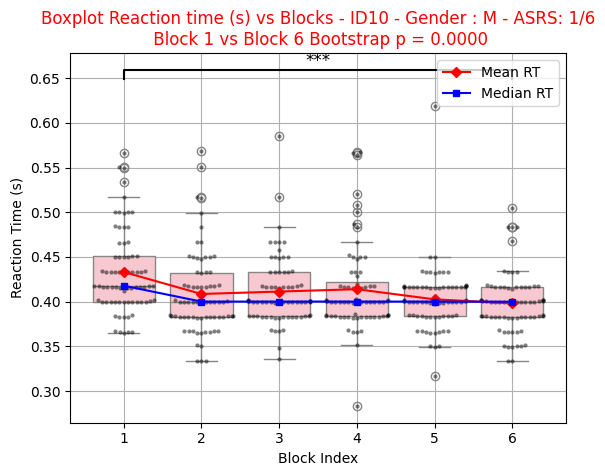

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

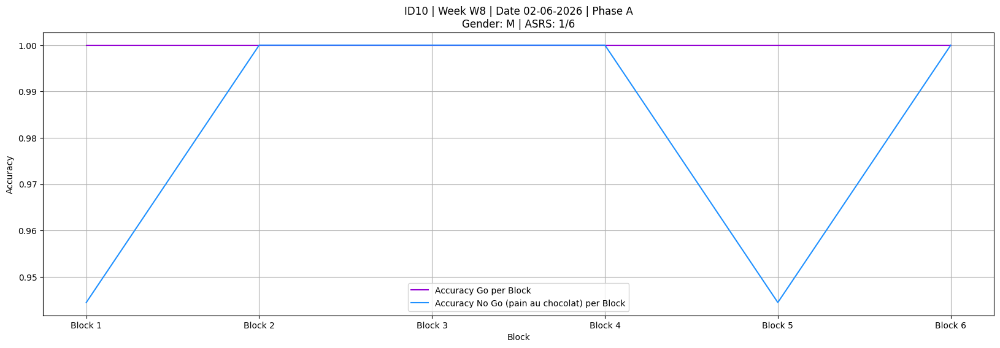

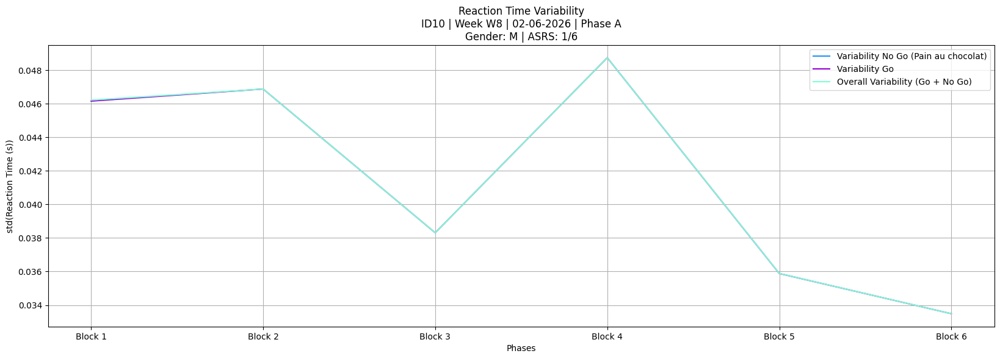

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,230.347620,Go,space,0.460581,Correct,False,False,10
1,1,1,231.358164,Go,space,0.433228,Correct,False,False,10
2,1,2,232.374944,Go,space,0.433040,Correct,False,False,10
3,1,3,233.391452,Go,space,0.433625,Correct,False,False,10
4,1,4,234.408245,No_Go,NaN,NaN,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,883.748647,No_Go,NaN,NaN,Correct,False,False,10
536,6,536,884.764520,Go,space,0.383462,Correct,False,False,10
537,6,537,885.781425,Go,space,0.399959,Correct,False,False,10
538,6,538,886.798508,Go,space,0.418335,Correct,False,False,10


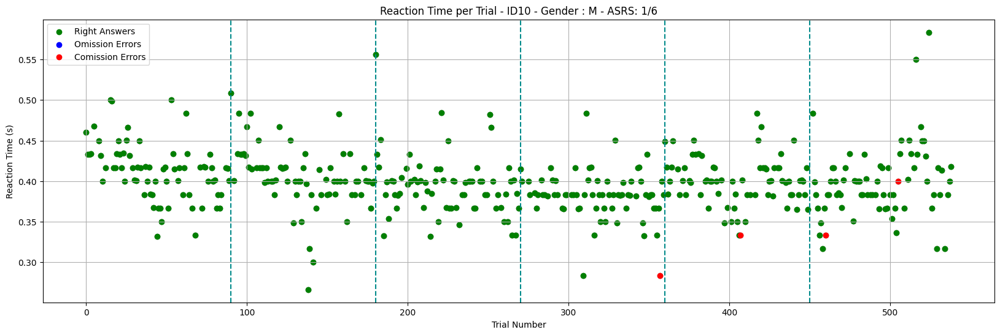

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 19.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=2.213438


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


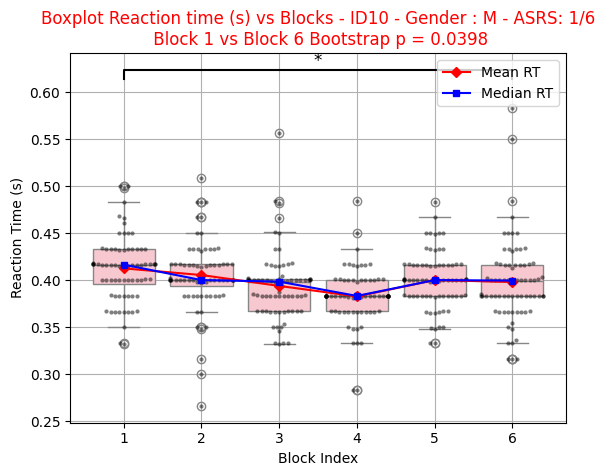

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

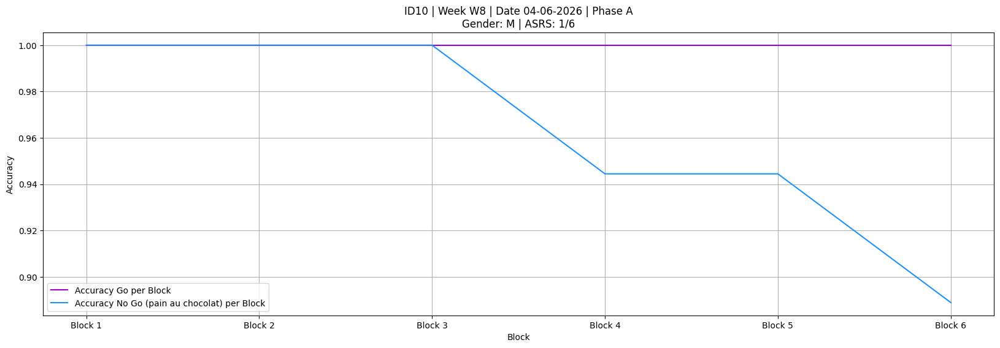

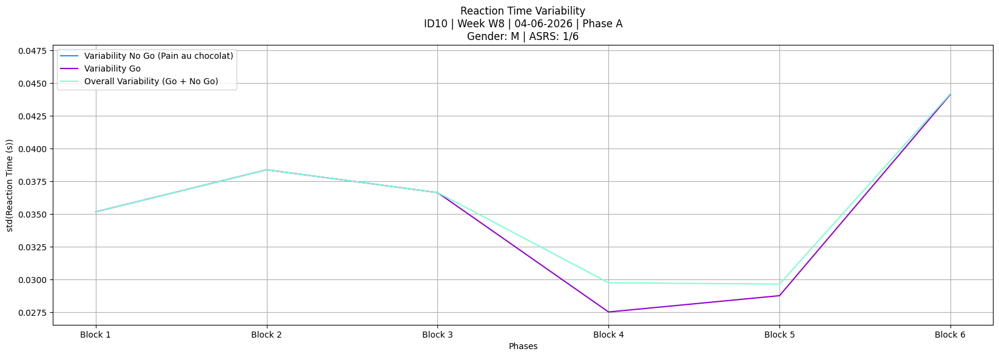

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,356.848686,Go,space,0.618172,Correct,False,False,10
1,1,1,357.863457,Go,space,0.401748,Correct,False,False,10
2,1,2,358.884831,Go,space,0.363601,Correct,False,False,10
3,1,3,359.899803,Go,space,0.402220,Correct,False,False,10
4,1,4,360.915412,Go,space,0.416357,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1036.942434,No_Go,NaN,NaN,Correct,False,False,10
536,6,536,1037.958423,Go,space,0.386518,Correct,False,False,10
537,6,537,1038.972243,Go,space,0.385658,Correct,False,False,10
538,6,538,1039.991061,Go,space,0.401708,Correct,False,False,10


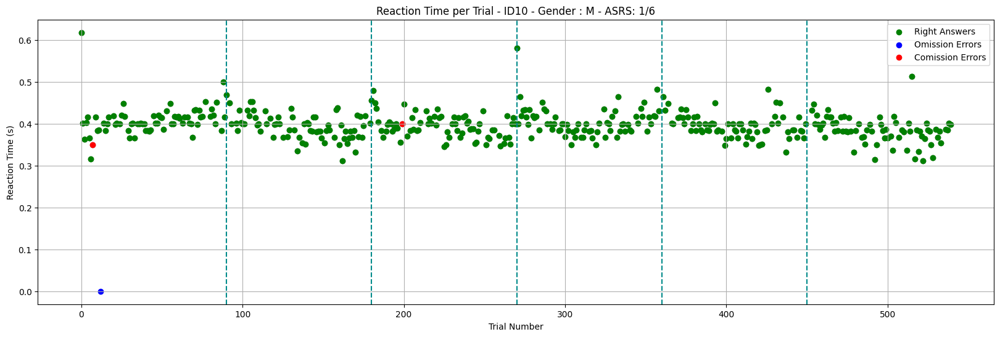

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 11.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=4.140351


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 12.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


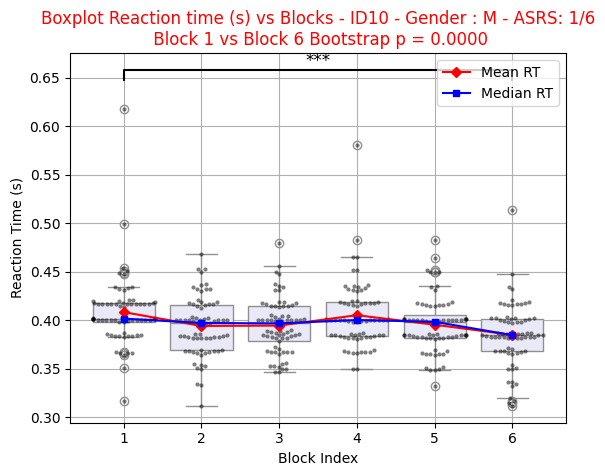

[{'Block': 'Block 1',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

SESSION DATE: 2026-06-05 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
11,2026-06-05,B,"20,30,12,20,30,12"


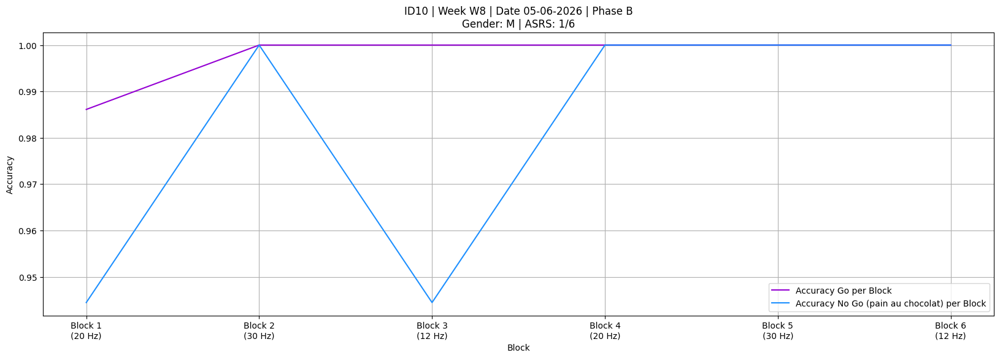

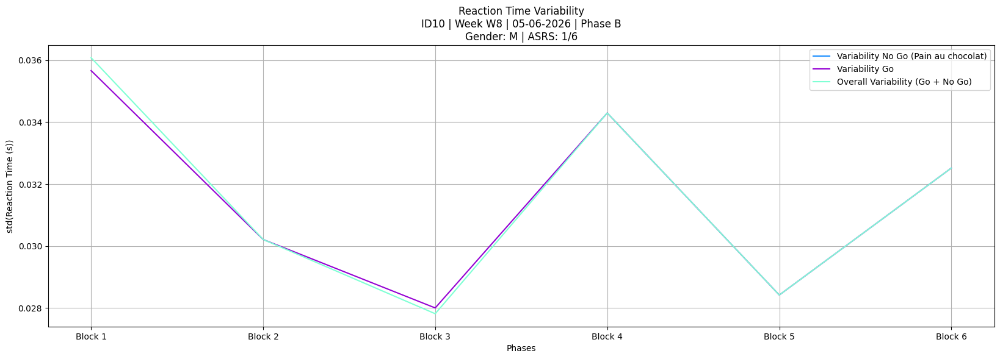

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,813.416664,Go,space,0.403513,Correct,False,False,10
1,1,1,814.420313,Go,space,0.416692,Correct,False,False,10
2,1,2,815.437092,Go,space,0.416800,Correct,False,False,10
3,1,3,816.453752,Go,space,0.383462,Correct,False,False,10
4,1,4,817.470620,No_Go,NaN,NaN,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1465.010990,Go,space,0.400781,Correct,False,False,10
536,6,536,1466.027630,No_Go,NaN,NaN,Correct,False,False,10
537,6,537,1467.044241,Go,space,0.400124,Correct,False,False,10
538,6,538,1468.061518,Go,space,0.350173,Correct,False,False,10


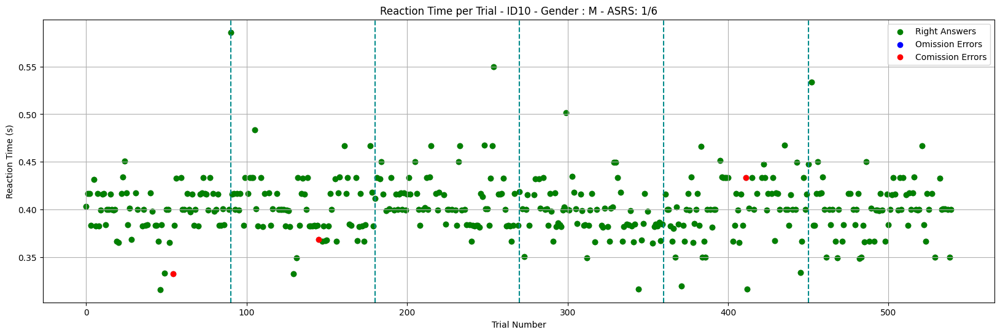

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 15.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 12.5% of the points cannot be placed;

t=-0.713645


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 11.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


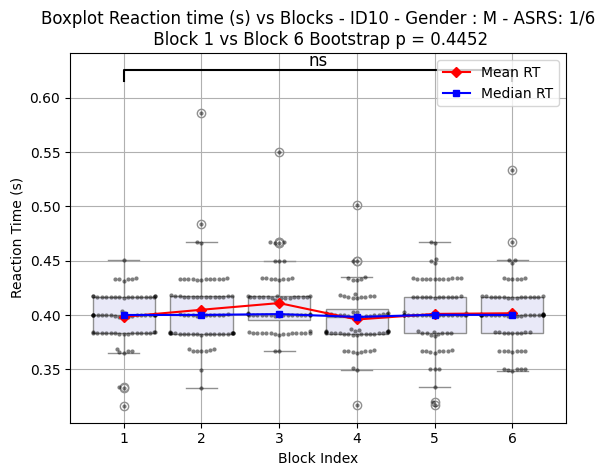

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

SESSION DATE: 2026-06-08 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
12,2026-06-08,B,"20,30,12,12,30,20"


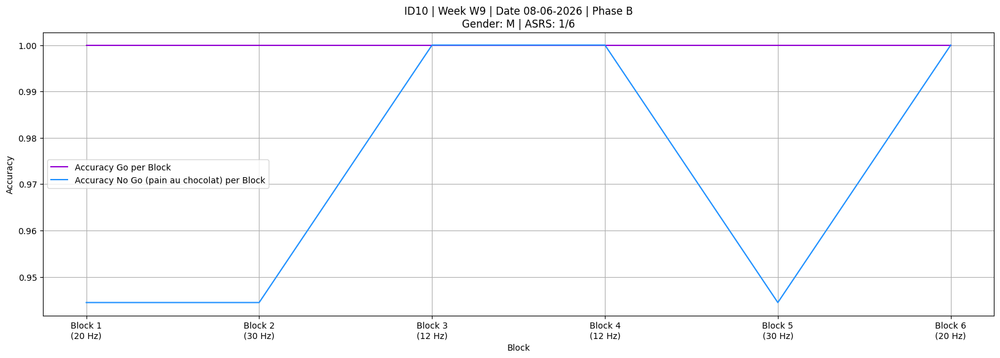

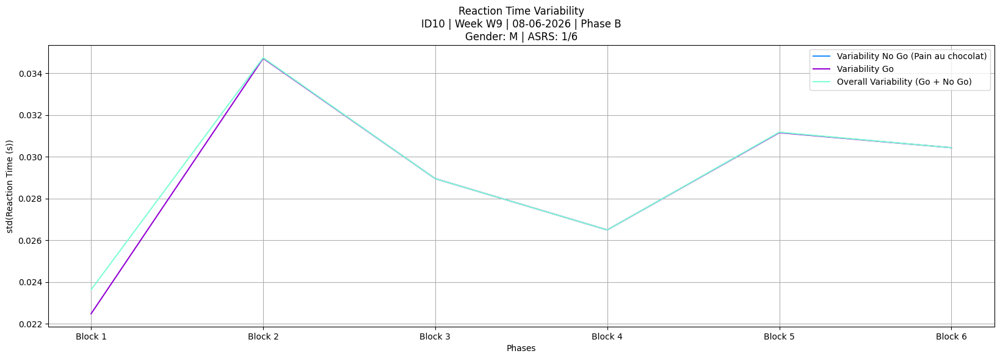

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,323.606908,No_Go,NaN,NaN,Correct,False,False,10
1,1,1,324.617472,Go,space,0.453134,Correct,False,False,10
2,1,2,325.636128,No_Go,NaN,NaN,Correct,False,False,10
3,1,3,326.651011,No_Go,NaN,NaN,Correct,False,False,10
4,1,4,327.669121,No_Go,NaN,NaN,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,975.839255,No_Go,NaN,NaN,Correct,False,False,10
536,6,536,976.856615,No_Go,NaN,NaN,Correct,False,False,10
537,6,537,977.872853,Go,space,0.416538,Correct,False,False,10
538,6,538,978.889240,Go,space,0.433580,Correct,False,False,10


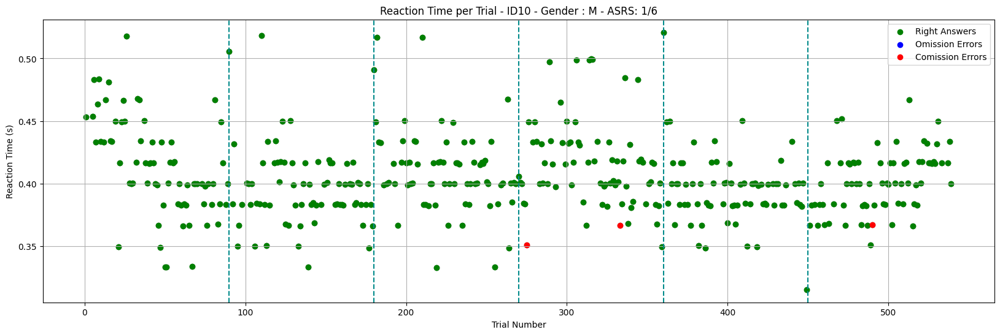

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 11.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 22.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=2.223734


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 12.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 25.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


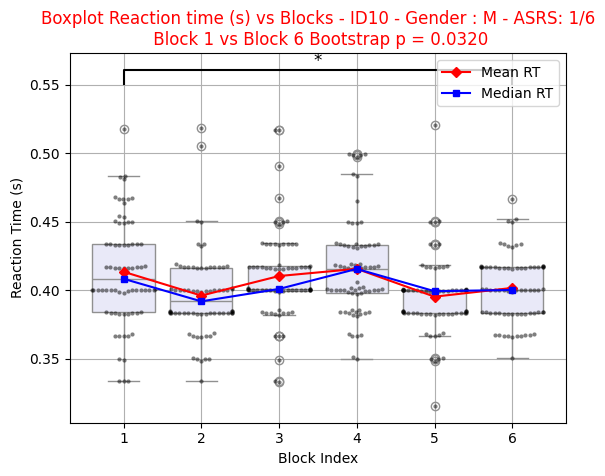

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444}]

SESSION DATE: 2026-06-10 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
13,2026-06-10,B,"20,30,12,12,20,30"


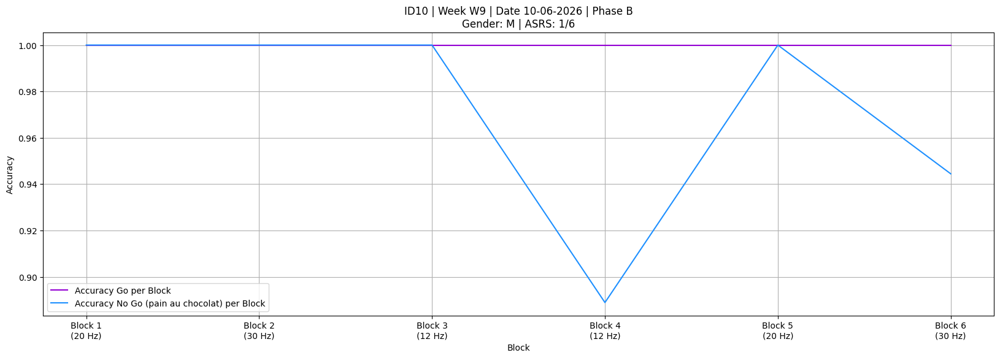

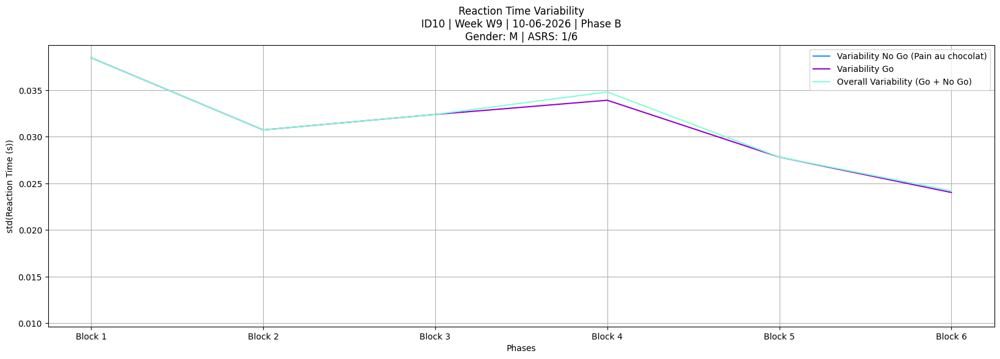

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,579.981029,Go,space,0.525584,Correct,False,False,10
1,1,1,580.989179,Go,space,0.467237,Correct,False,False,10
2,1,2,582.005247,No_Go,NaN,NaN,Correct,False,False,10
3,1,3,583.021584,Go,space,0.433305,Correct,False,False,10
4,1,4,584.038089,Go,space,0.416867,Correct,False,False,10
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1234.922996,Go,space,0.433065,Correct,False,False,10
536,6,536,1235.939503,Go,space,0.416605,Correct,False,False,10
537,6,537,1236.956728,Go,space,0.399117,Correct,False,False,10
538,6,538,1237.972765,Go,space,0.383017,Correct,False,False,10


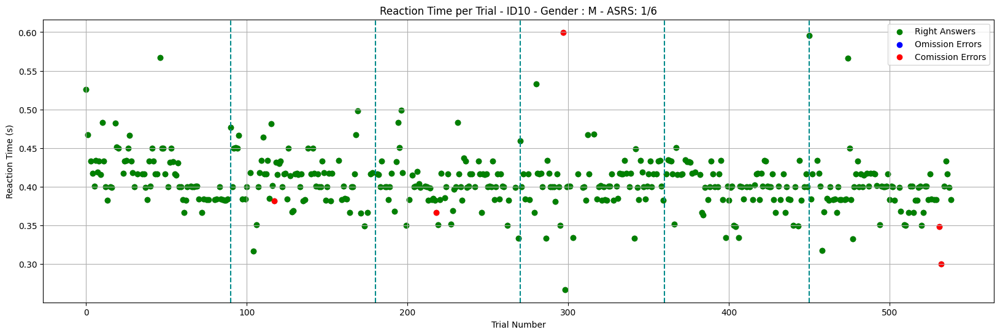

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 13.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 16.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 16.2% of the points cannot be placed

t=3.422406


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 8.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 15.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


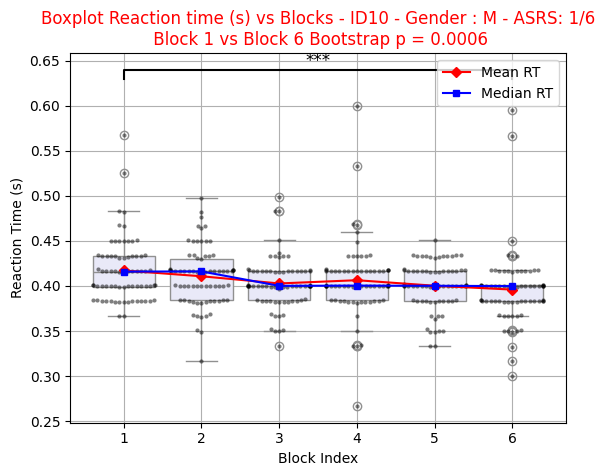

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

SESSION DATE: 2026-06-12 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
14,2026-06-12,B,"20,30,12,12,20,30"


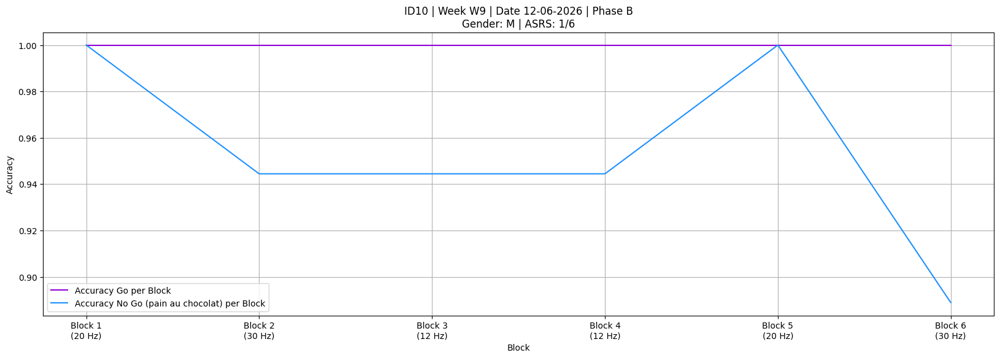

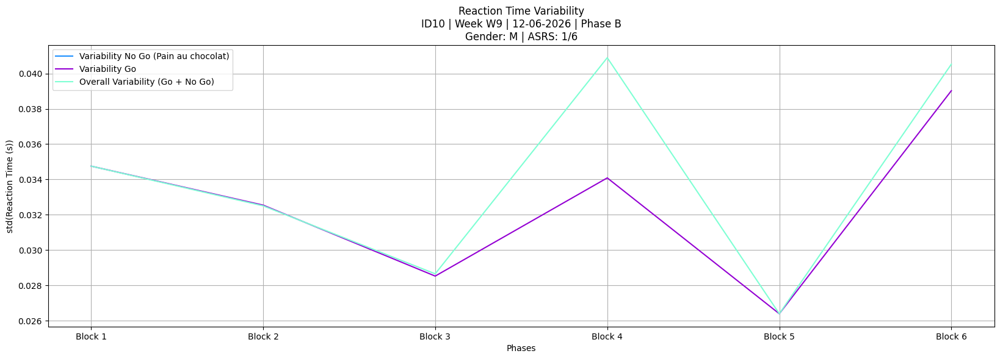

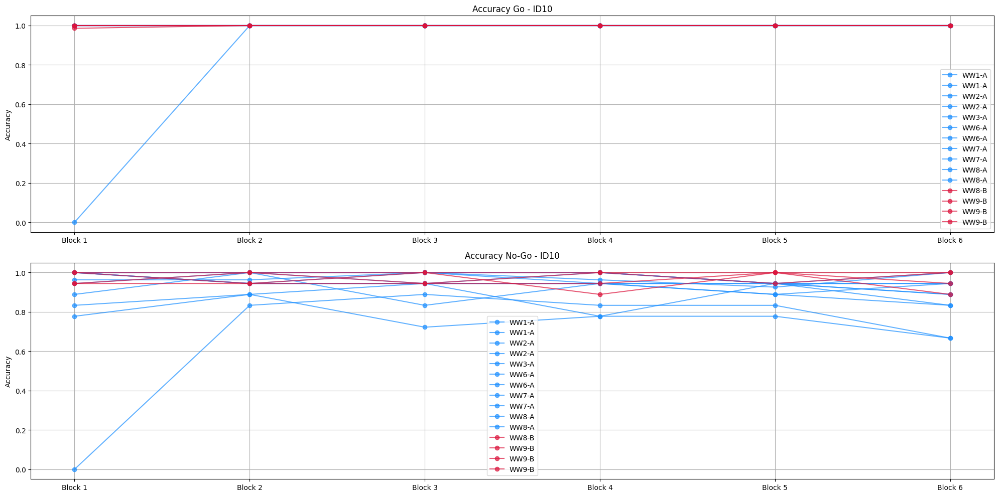

DATE: 2026-06-05 00:00:00
DATE: 2026-06-08 00:00:00
DATE: 2026-06-10 00:00:00
DATE: 2026-06-12 00:00:00


,DATE,PHASE,Go_12,Go_20,Go_30,NoGo_12,NoGo_20,NoGo_30,MeanGo,MeanNoGo
0,2026-04-13,A,0.833333,0.833333,0.833333,0.675926,0.675926,0.675926,NaN,NaN
1,2026-04-16,A,1.000000,1.000000,1.000000,0.805556,0.805556,0.805556,NaN,NaN
2,2026-04-22,A,1.000000,1.000000,1.000000,0.833333,0.833333,0.833333,NaN,NaN
3,2026-04-24,A,1.000000,1.000000,1.000000,0.898148,0.898148,0.898148,NaN,NaN
4,2026-04-27,A,1.000000,1.000000,1.000000,0.972222,0.972222,0.972222,NaN,NaN
5,2026-05-18,A,1.000000,1.000000,1.000000,0.944444,0.944444,0.944444,NaN,NaN
6,2026-05-21,A,1.000000,1.000000,1.000000,0.972222,0.972222,0.972222,NaN,NaN
7,2026-05-26,A,1.000000,1.000000,1.000000,0.944444,0.944444,0.944444,NaN,NaN
8,2026-05-28,A,1.000000,1.000000,1.000000,0.969136,0.969136,0.969136,NaN,NaN
9,2026-06-02,A,1.000000,1.000000,1.000000,0.981481,0.981481,0.981481,NaN,NaN


t=-1.028992


/tmp/ipykernel_1316/346653522.py:91: RuntimeWarning: divide by zero encountered in scalar divide
  t_distrib[b] = (np.mean(draw_x)-np.mean(draw_y))/np.sqrt(np.var(draw_x)/n+np.var(draw_y)/m)


t=-4.122582
t=-0.373906
t=1.028992
t=-1.044466
t=0.969087
Go A-A   p = 0.1508
Go A-B   p = 0.1440
Go B-B   p = 0.1436
NoGo A-A p = 0.0000
NoGo A-B p = 0.7358
NoGo B-B p = 0.3362


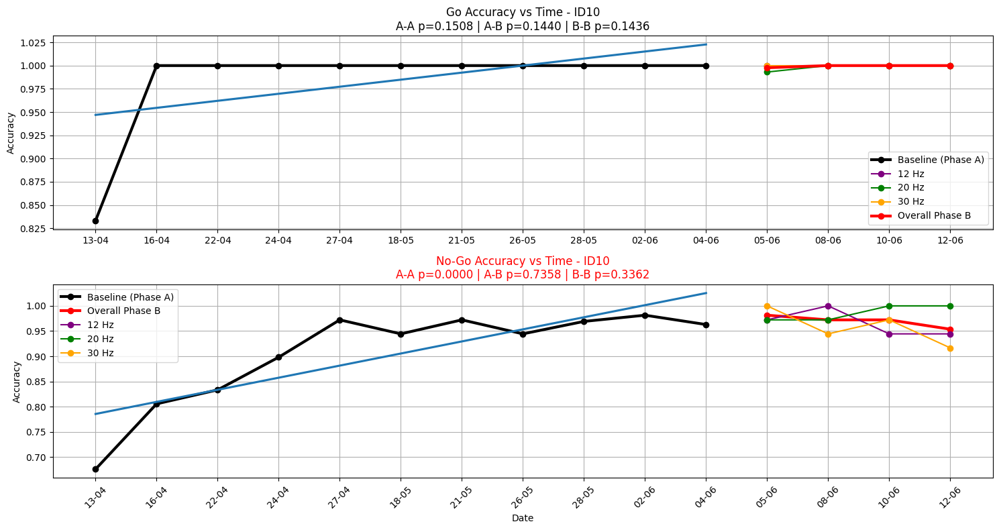

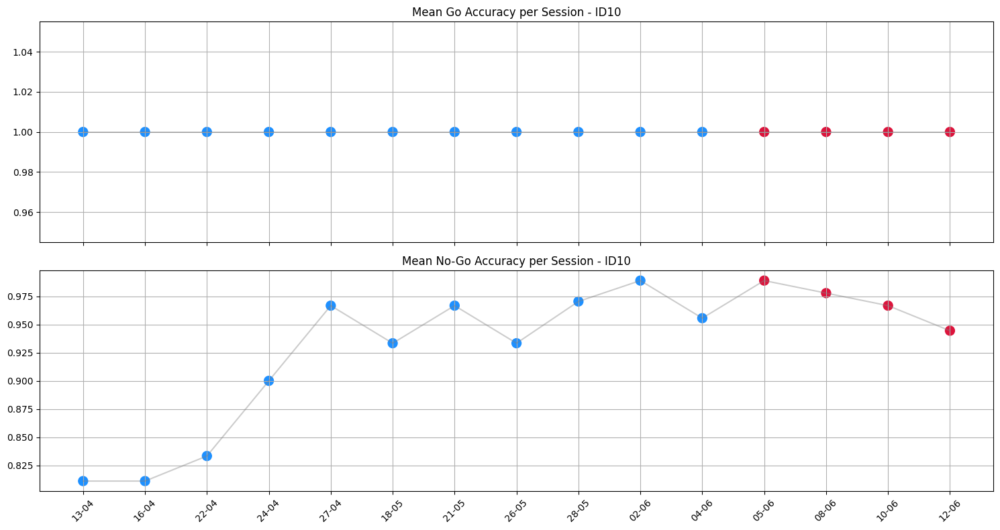

DATE: 2026-06-05 00:00:00
DATE: 2026-06-08 00:00:00
DATE: 2026-06-10 00:00:00
DATE: 2026-06-12 00:00:00


,DATE,Go_12,NoGo_12,Go_20,NoGo_20,Go_30,NoGo_30,MeanGo,MeanNoGo
0,2026-06-05,1.0,0.972222,0.993056,0.972222,1.0,1.000000,0.997685,0.981481
1,2026-06-08,1.0,1.000000,1.000000,0.972222,1.0,0.944444,1.000000,0.972222
2,2026-06-10,1.0,0.944444,1.000000,1.000000,1.0,0.972222,1.000000,0.972222
3,2026-06-12,1.0,0.944444,1.000000,1.000000,1.0,0.916667,1.000000,0.953704


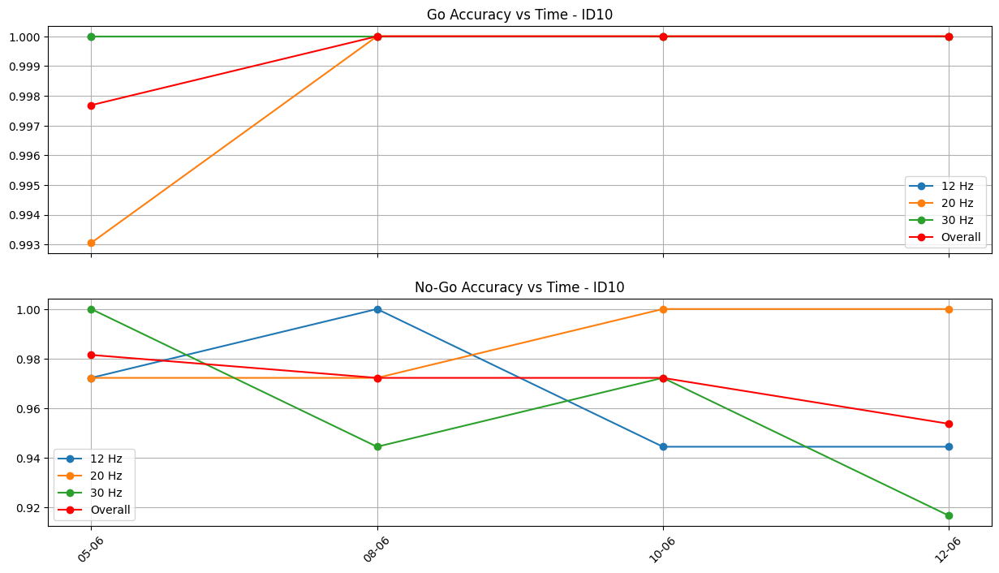

t=-4.023654
t=1.155446
t=-1.993002


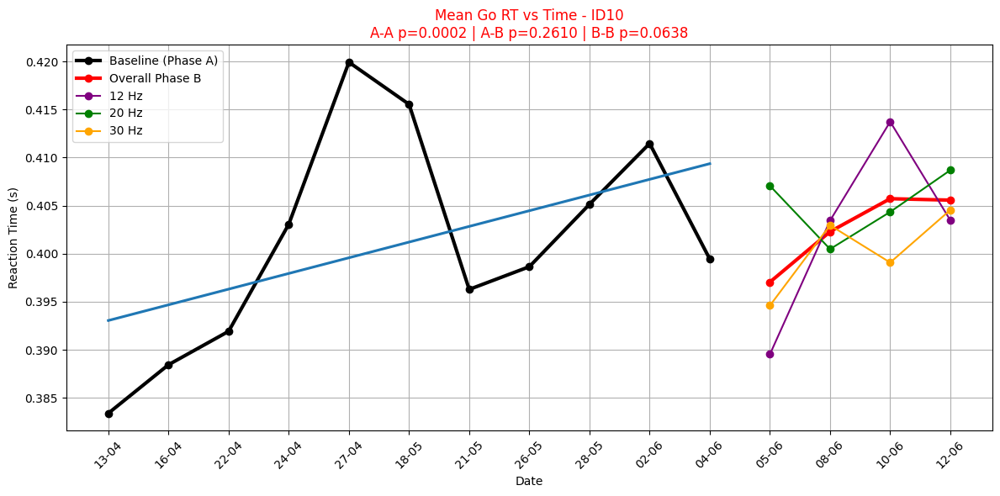

t=1.552542
t=3.155947
t=-0.979561


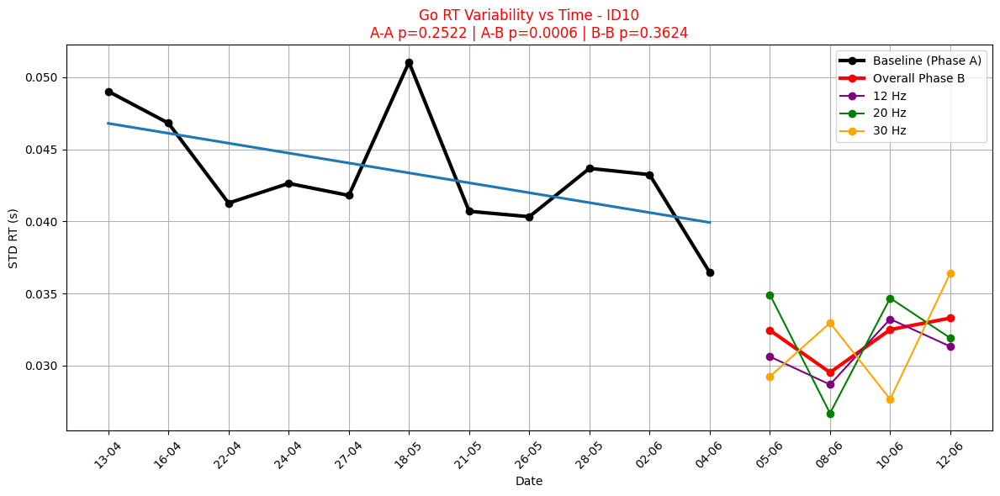

t=-2.899561
t=-0.032313
t=0.435345


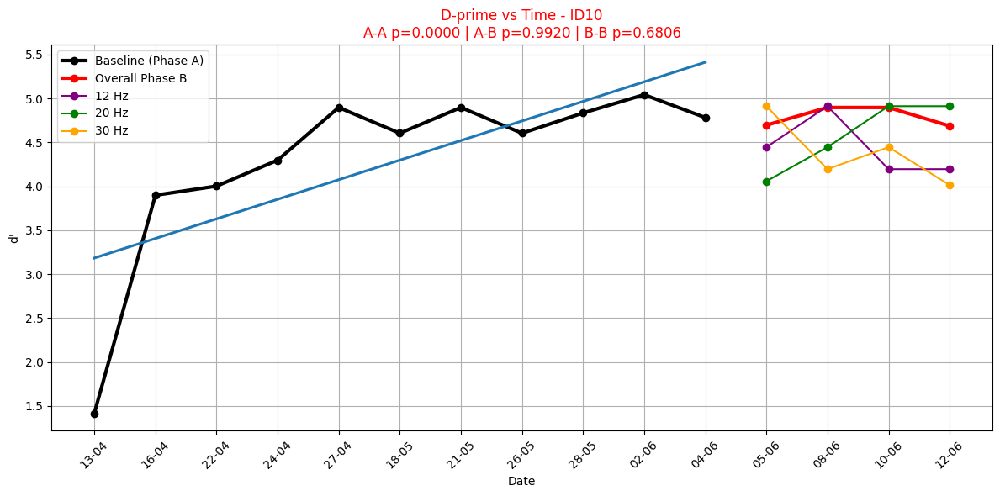

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime_All,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-13,A,1/6,NaN,NaN,NaN,1.416196,1.0,0.811111,0.046907
1,2026-04-16,A,1/6,NaN,NaN,NaN,3.898742,1.0,0.811111,0.043866
2,2026-04-22,A,1/6,NaN,NaN,NaN,4.002502,1.0,0.833333,0.040205
3,2026-04-24,A,1/6,7.0,5.0,0.0,4.298044,1.0,0.900000,0.038790
4,2026-04-27,A,1/6,5.0,4.0,0.0,4.897896,1.0,0.966667,0.039245
5,2026-05-18,A,1/6,7.0,4.0,5.0,4.605110,1.0,0.933333,0.043121
6,2026-05-21,A,1/6,8.0,5.0,0.0,4.897896,1.0,0.966667,0.037966
7,2026-05-26,A,1/6,7.5,4.0,3.0,4.605110,1.0,0.933333,0.035132
8,2026-05-28,A,1/6,7.0,4.0,3.0,4.835418,1.0,0.970370,0.041928
9,2026-06-02,A,1/6,8.5,4.0,0.0,5.043822,1.0,0.988889,0.040656


/tmp/ipykernel_1316/254032596.py:17: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(df["HRS_SLEEP"],df[metric], nan_policy = "omit")


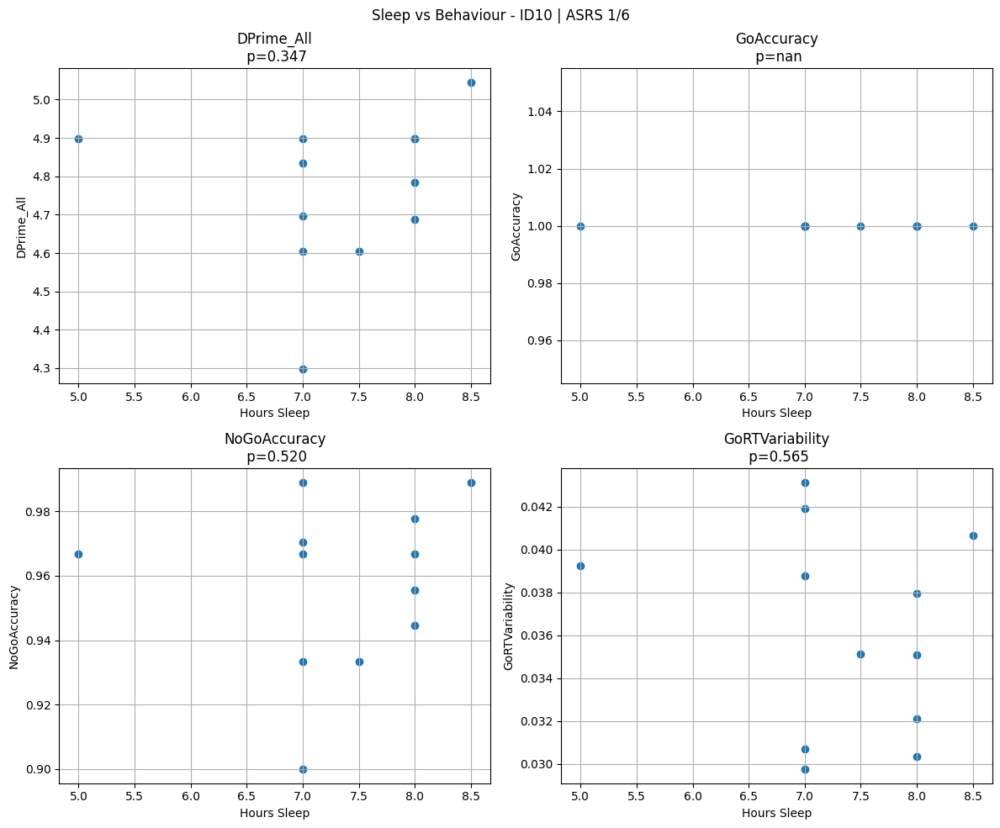

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime_All,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-13,A,1/6,NaN,NaN,NaN,1.416196,1.0,0.811111,0.046907
1,2026-04-16,A,1/6,NaN,NaN,NaN,3.898742,1.0,0.811111,0.043866
2,2026-04-22,A,1/6,NaN,NaN,NaN,4.002502,1.0,0.833333,0.040205
3,2026-04-24,A,1/6,7.0,5.0,0.0,4.298044,1.0,0.900000,0.038790
4,2026-04-27,A,1/6,5.0,4.0,0.0,4.897896,1.0,0.966667,0.039245
5,2026-05-18,A,1/6,7.0,4.0,5.0,4.605110,1.0,0.933333,0.043121
6,2026-05-21,A,1/6,8.0,5.0,0.0,4.897896,1.0,0.966667,0.037966
7,2026-05-26,A,1/6,7.5,4.0,3.0,4.605110,1.0,0.933333,0.035132
8,2026-05-28,A,1/6,7.0,4.0,3.0,4.835418,1.0,0.970370,0.041928
9,2026-06-02,A,1/6,8.5,4.0,0.0,5.043822,1.0,0.988889,0.040656


/tmp/ipykernel_1316/2686737947.py:19: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(df["MOOD"],df[metric])


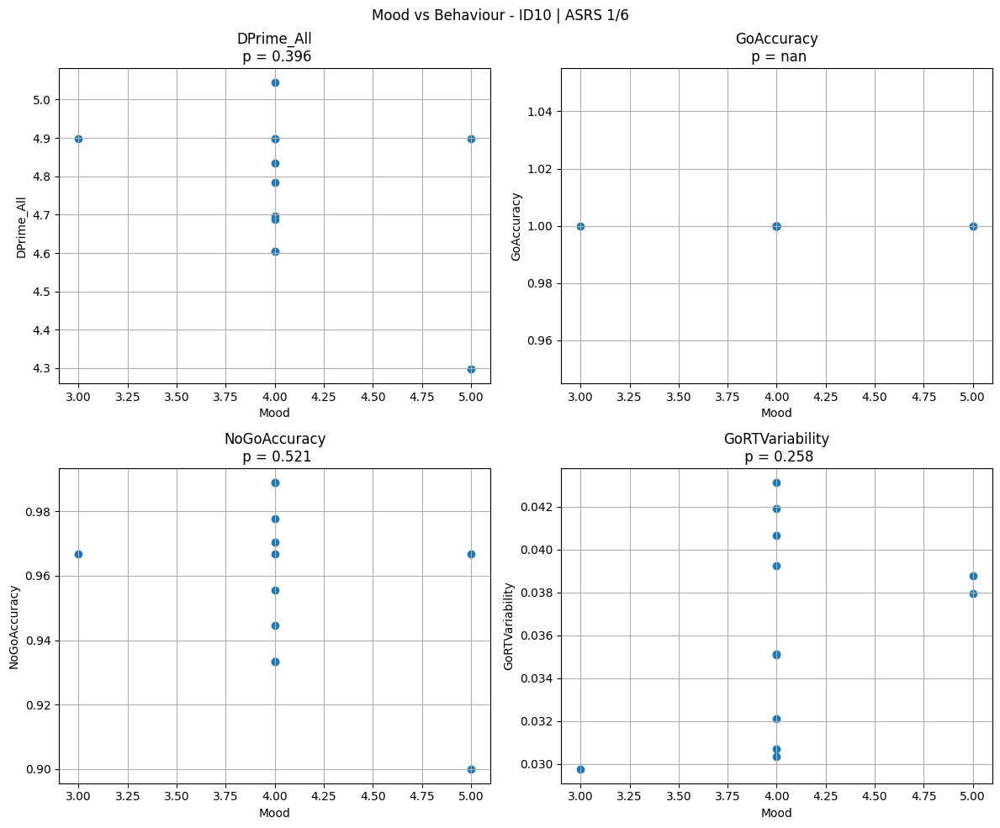

In [1043]:
df_clean_list = pipeline(id = 10)
#display(df_clean_list)

#**ID13**

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,307.702727,Go,NaN,NaN,Incorrect,True,False,13
1,1,1,308.725952,Go,NaN,NaN,Incorrect,True,False,13
2,1,2,309.742476,Go,space,0.100228,Correct,False,False,13
3,1,3,310.759344,Go,space,0.250153,Correct,False,False,13
4,1,4,311.775935,Go,space,0.351323,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,964.211661,Go,space,0.650081,Correct,False,False,13
536,6,536,965.228292,Go,space,0.816748,Correct,False,False,13
537,6,537,966.245081,Go,space,0.899840,Correct,False,False,13
538,6,538,967.261509,Go,space,0.754133,Correct,False,False,13


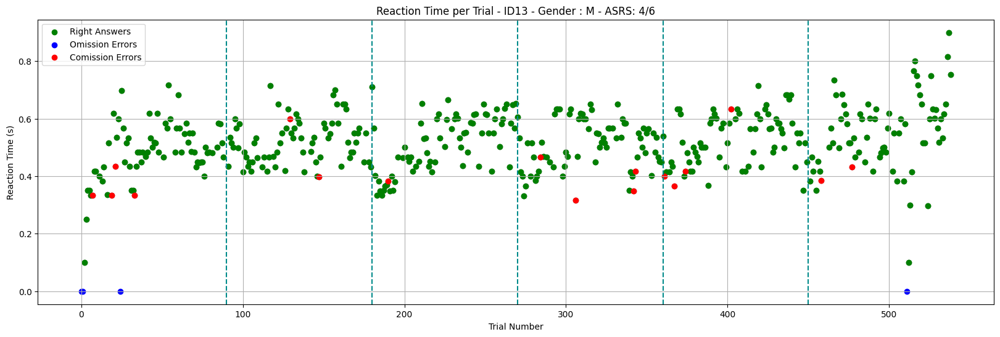

t=-3.632247


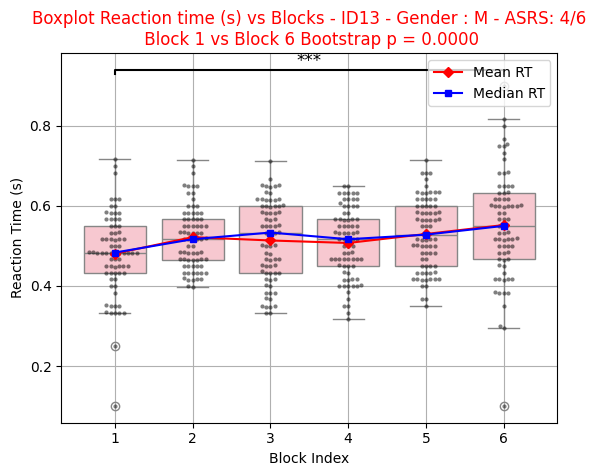

[{'Block': 'Block 1',
  'Accuracy Go': 0.9583333333333334,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.8888888888888888}]

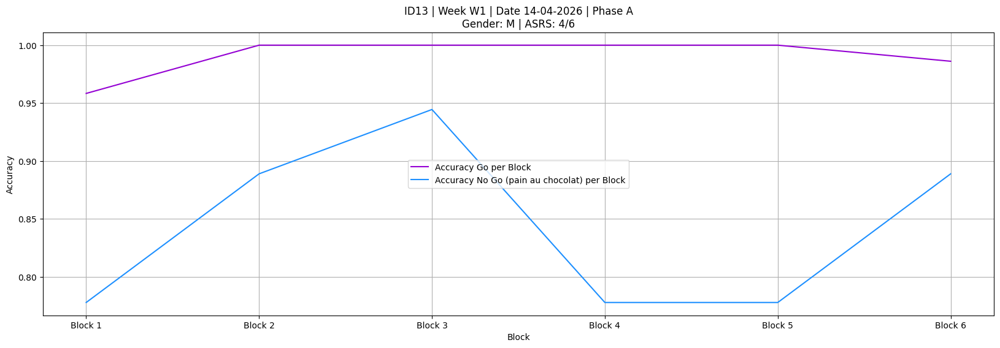

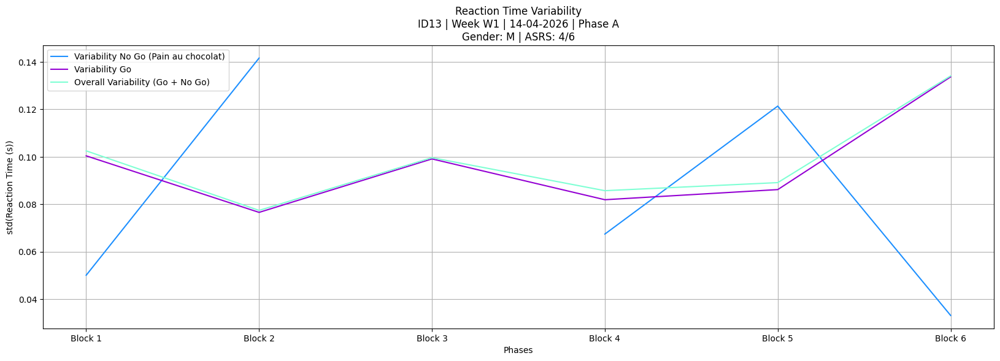

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,254.417249,Go,NaN,NaN,Incorrect,True,False,13
1,1,1,255.453634,Go,space,0.533526,Correct,False,False,13
2,1,2,256.470198,Go,space,0.550052,Correct,False,False,13
3,1,3,257.486868,Go,space,0.483295,Correct,False,False,13
4,1,4,258.503374,Go,space,0.516910,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,910.930133,Go,space,0.416658,Correct,False,False,13
536,6,536,911.946786,Go,space,0.383262,Correct,False,False,13
537,6,537,912.963637,Go,space,0.416976,Correct,False,False,13
538,6,538,913.979885,No_Go,NaN,NaN,Correct,False,False,13


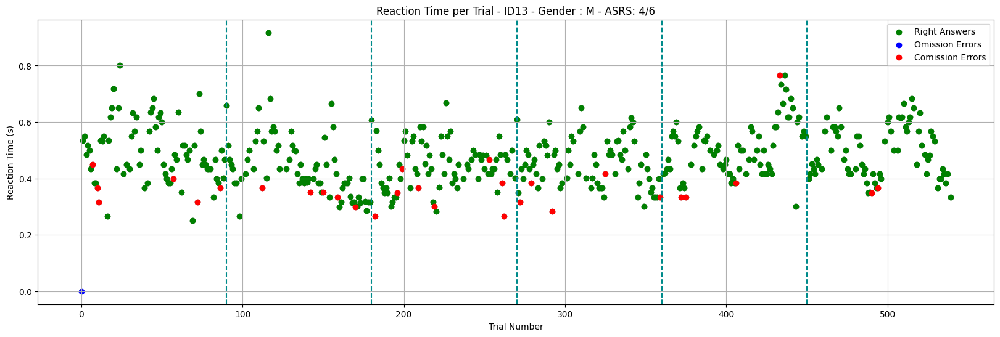

t=-0.163506


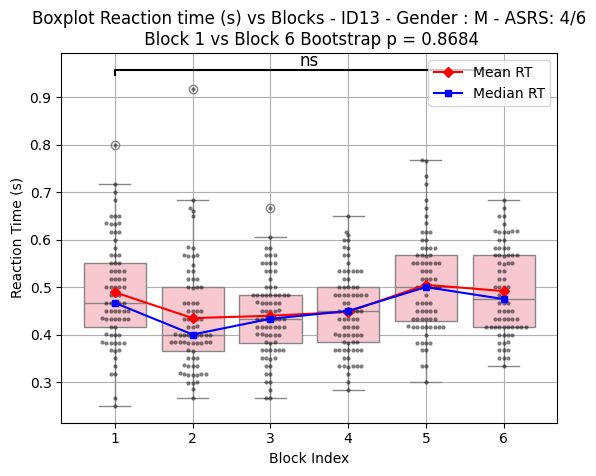

[{'Block': 'Block 1',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.5555555555555556},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

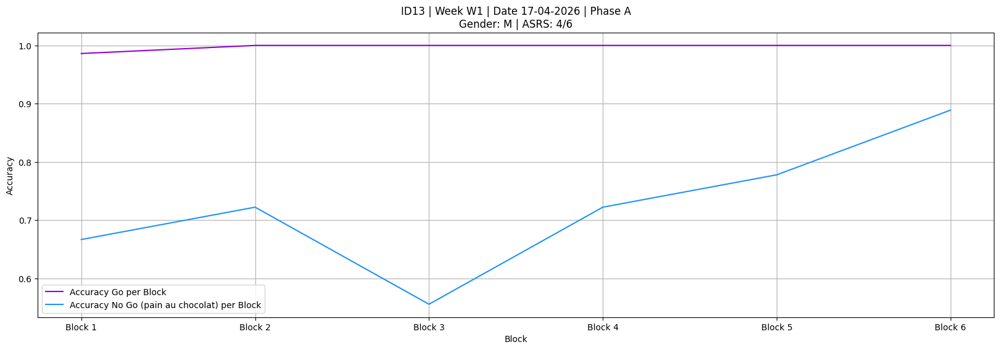

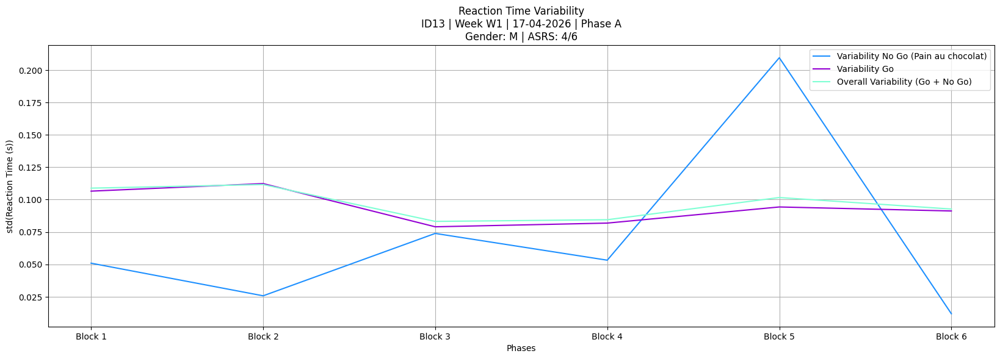

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,195.993095,No_Go,NaN,NaN,Correct,False,False,13
1,1,1,197.014404,Go,space,0.416713,Correct,False,False,13
2,1,2,198.030976,Go,space,0.449846,Correct,False,False,13
3,1,3,199.047598,No_Go,space,0.466688,Incorrect,False,True,13
4,1,4,200.064223,Go,NaN,NaN,Incorrect,True,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,844.642940,Go,space,0.550042,Correct,False,False,13
536,6,536,845.659539,No_Go,NaN,NaN,Correct,False,False,13
537,6,537,846.676208,Go,space,0.516845,Correct,False,False,13
538,6,538,847.692785,Go,space,0.450027,Correct,False,False,13


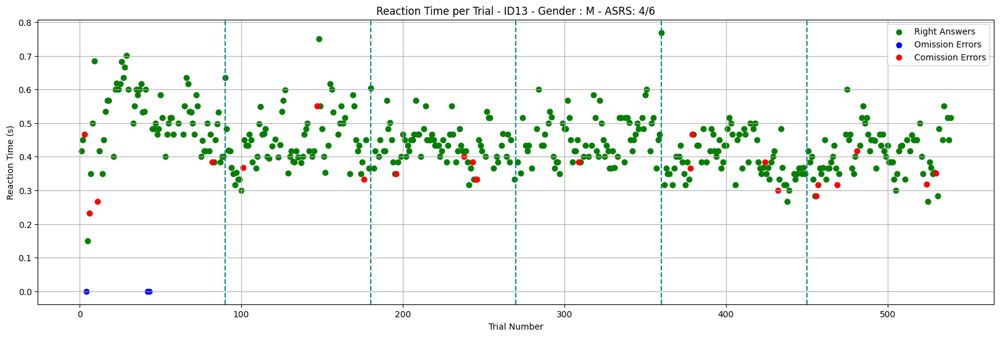

t=6.393135


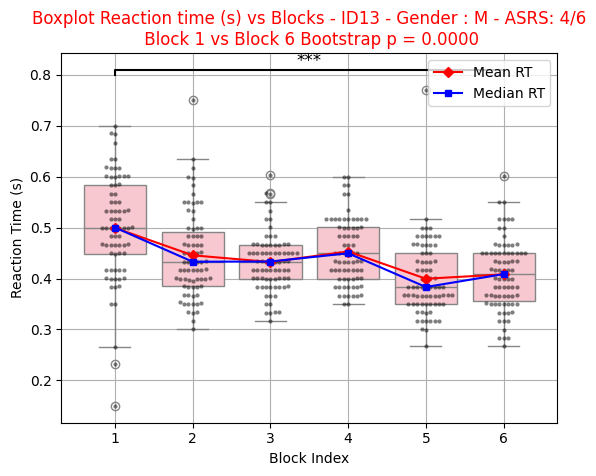

[{'Block': 'Block 1',
  'Accuracy Go': 0.9583333333333334,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666}]

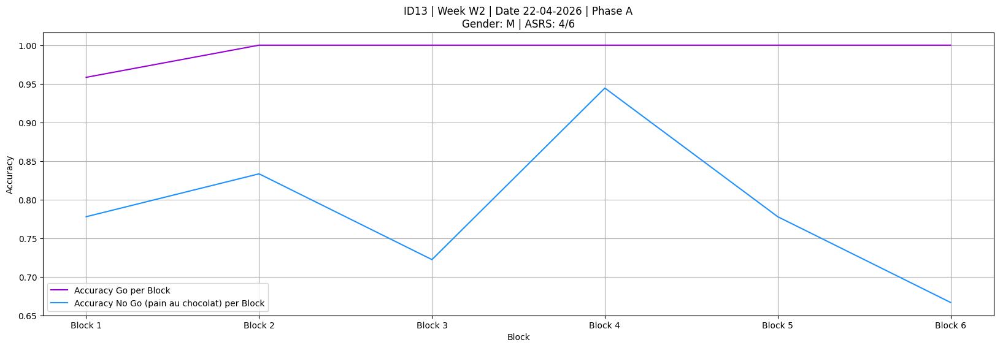

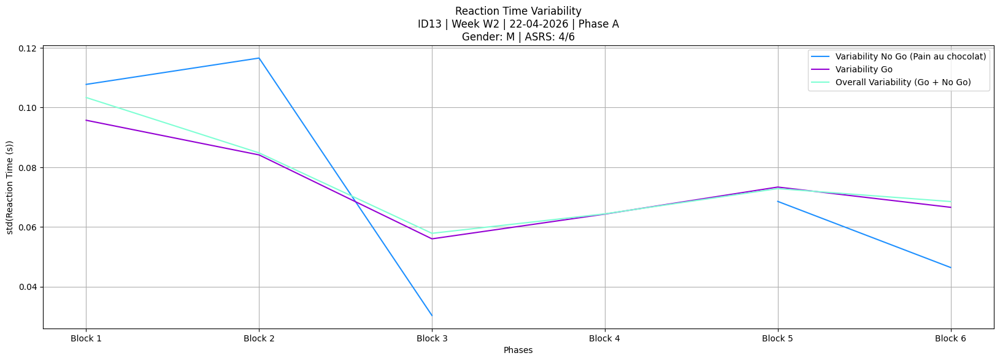

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,396.786888,Go,space,0.714279,Correct,False,False,13
1,1,1,397.767878,Go,space,0.516608,Correct,False,False,13
2,1,2,398.751329,Go,space,0.383421,Correct,False,False,13
3,1,3,399.734464,Go,space,0.283128,Correct,False,False,13
4,1,4,400.717747,Go,space,0.283352,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1045.230830,No_Go,NaN,NaN,Correct,False,False,13
536,6,536,1046.214034,Go,space,0.450153,Correct,False,False,13
537,6,537,1047.197609,Go,space,0.483292,Correct,False,False,13
538,6,538,1048.181961,No_Go,space,0.399570,Incorrect,False,True,13


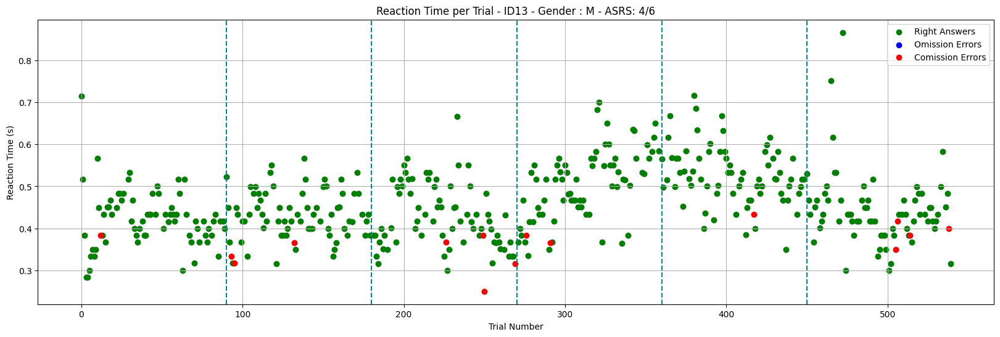

t=-1.568212


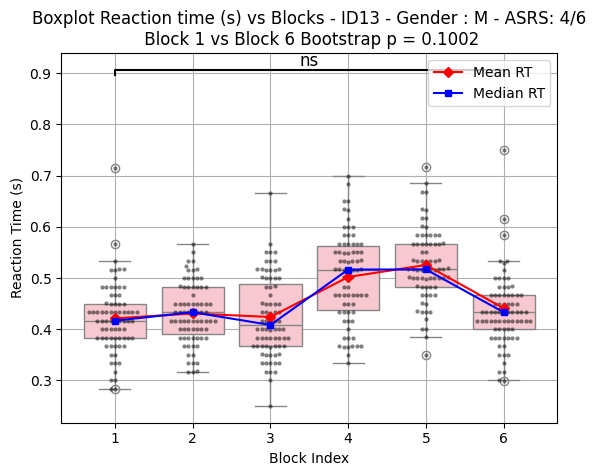

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778}]

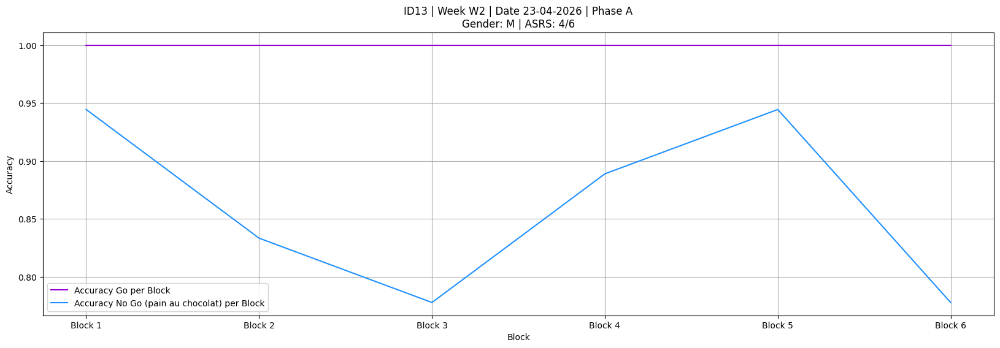

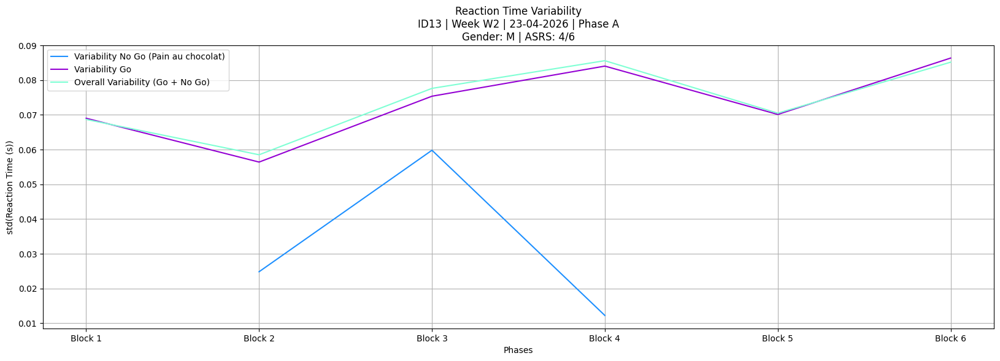

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,36.019336,Go,space,0.664332,Correct,False,False,13
1,1,1,37.033744,Go,space,0.582903,Correct,False,False,13
2,1,2,38.049084,No_Go,space,0.502490,Incorrect,False,True,13
3,1,3,39.067528,Go,space,0.282668,Correct,False,False,13
4,1,4,40.083491,Go,space,0.416060,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,687.949204,Go,space,0.432756,Correct,False,False,13
536,6,536,688.964724,Go,space,0.466311,Correct,False,False,13
537,6,537,689.980536,Go,space,0.466234,Correct,False,False,13
538,6,538,690.996257,Go,space,0.499609,Correct,False,False,13


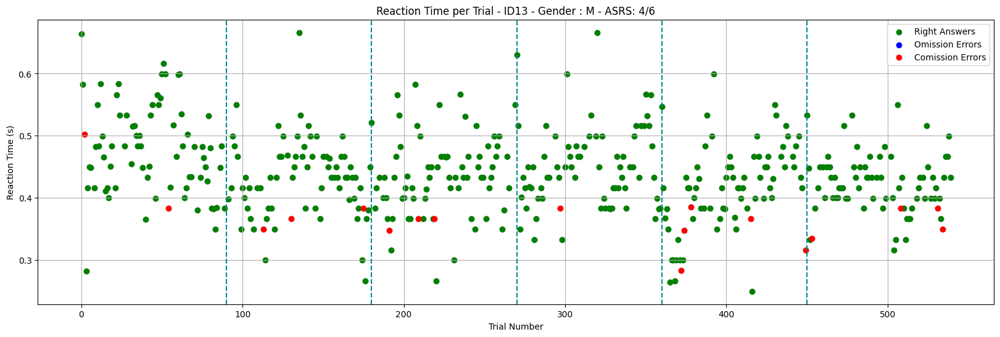

t=5.541547


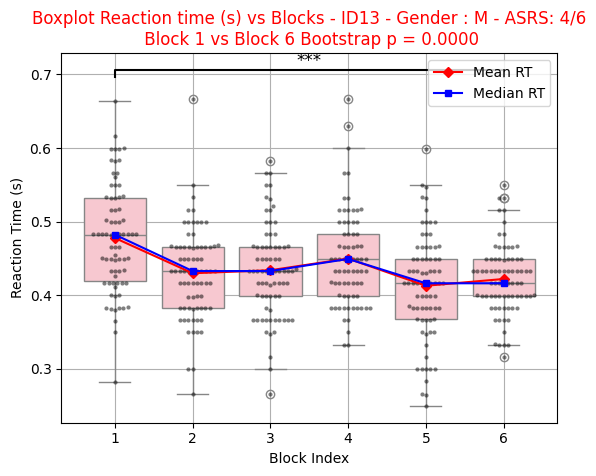

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778}]

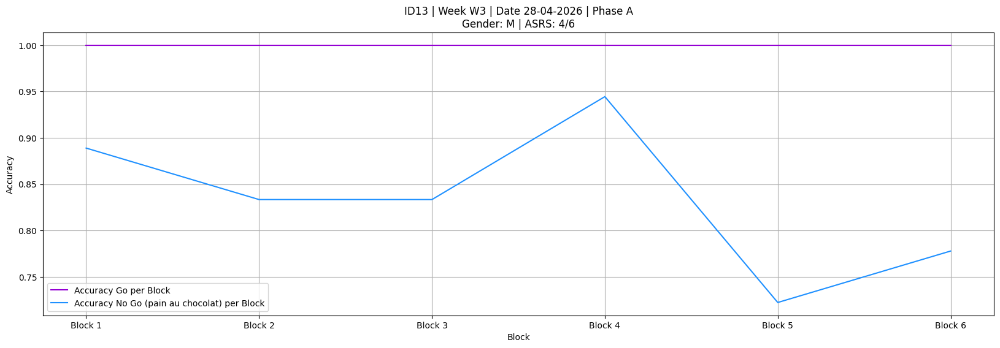

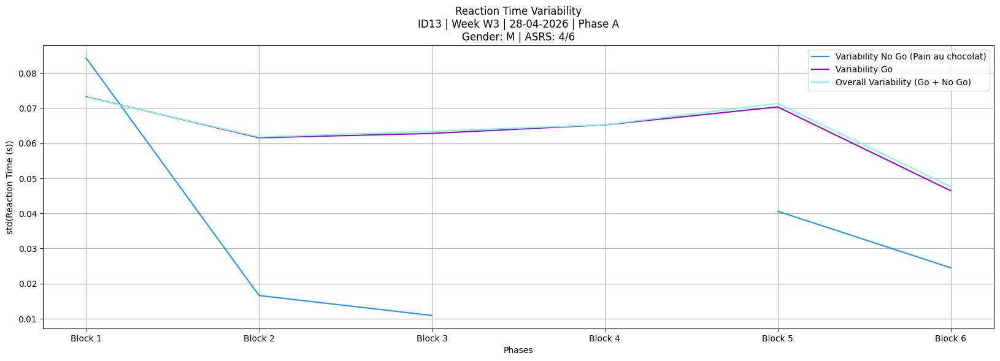

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,108.024495,No_Go,NaN,NaN,Correct,False,False,13
1,1,1,109.046005,Go,space,0.616006,Correct,False,False,13
2,1,2,110.061511,No_Go,NaN,NaN,Correct,False,False,13
3,1,3,111.078726,Go,space,0.449487,Correct,False,False,13
4,1,4,112.094509,Go,space,0.549514,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,772.655806,Go,space,0.399593,Correct,False,False,13
536,6,536,773.671499,No_Go,space,0.649402,Incorrect,False,True,13
537,6,537,774.687056,Go,space,0.466279,Correct,False,False,13
538,6,538,775.702761,No_Go,NaN,NaN,Correct,False,False,13


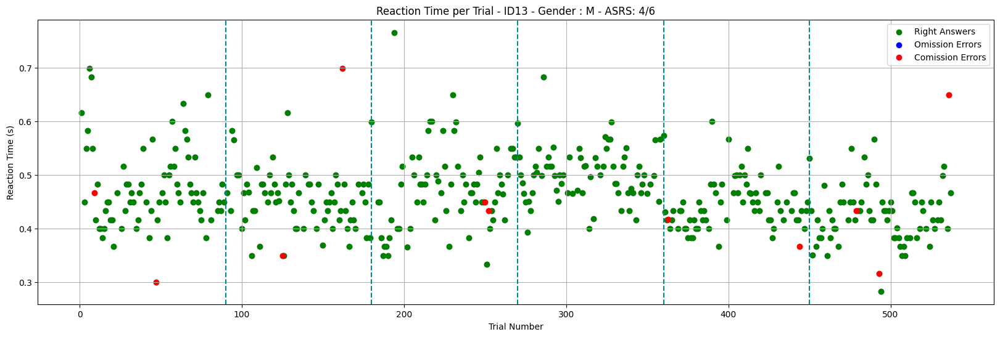

t=4.375492


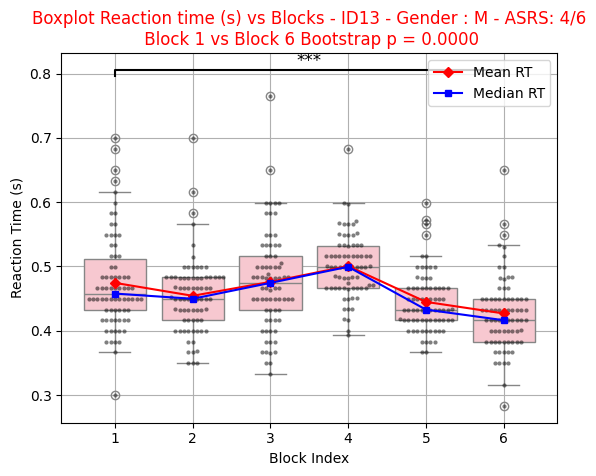

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334}]

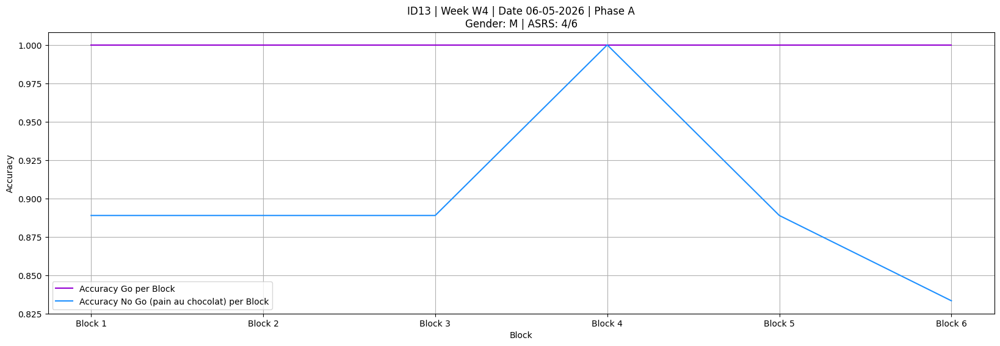

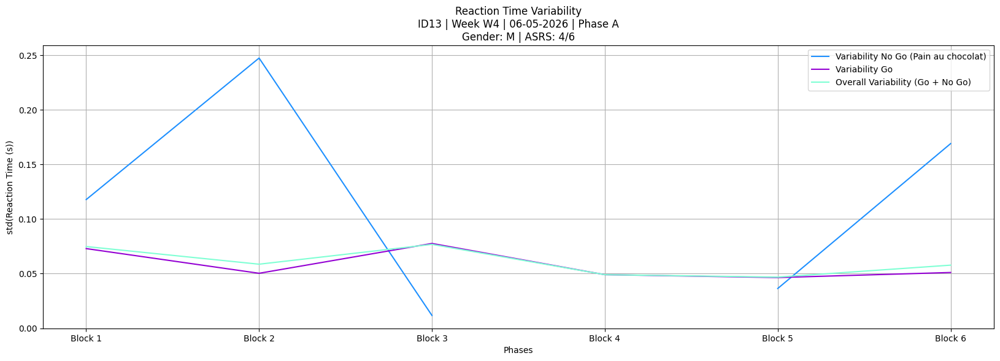

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,367.735862,Go,space,0.629869,Correct,False,False,13
1,1,1,368.782278,Go,space,0.533610,Correct,False,False,13
2,1,2,369.799214,Go,space,0.485642,Correct,False,False,13
3,1,3,370.815642,Go,space,0.466590,Correct,False,False,13
4,1,4,371.832373,Go,space,0.435887,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1049.820790,Go,space,0.548327,Correct,False,False,13
536,6,536,1050.836336,No_Go,NaN,NaN,Correct,False,False,13
537,6,537,1051.853884,Go,space,0.415601,Correct,False,False,13
538,6,538,1052.869376,No_Go,NaN,NaN,Correct,False,False,13


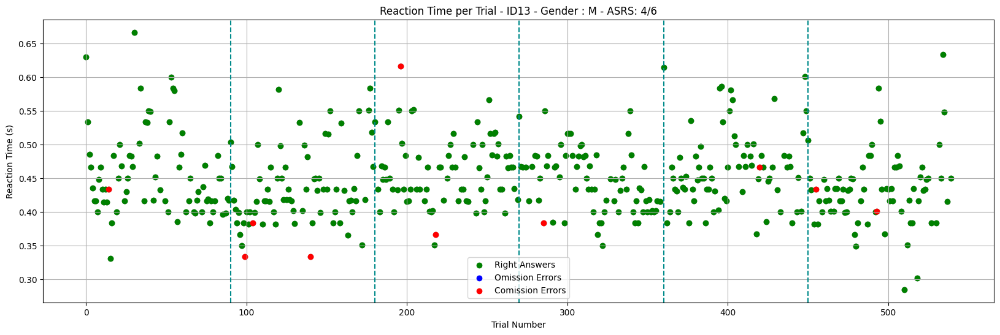

t=2.677005


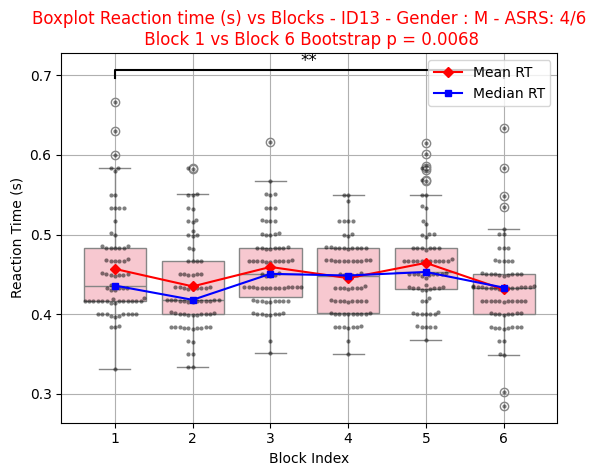

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

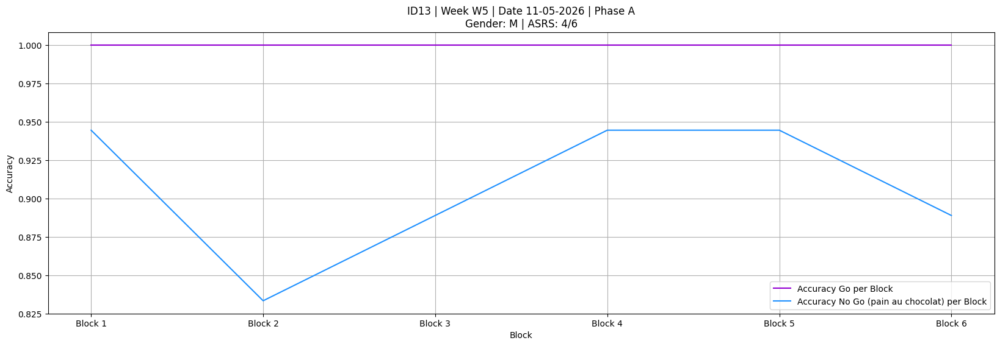

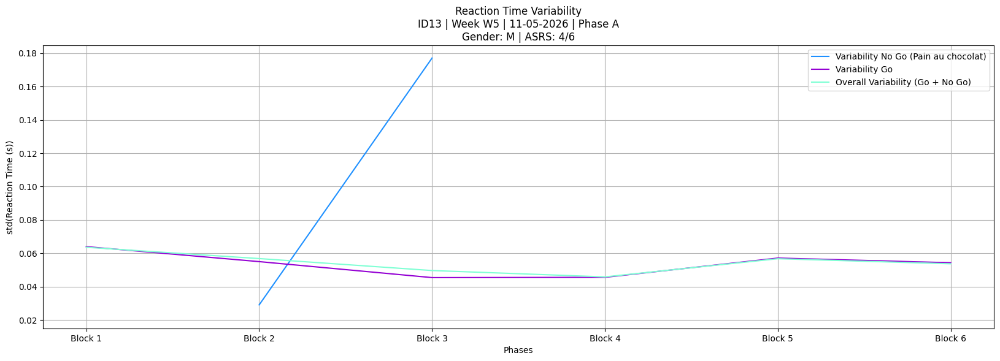

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,185.396242,Go,space,0.490821,Correct,False,False,13
1,1,1,186.453519,Go,space,0.550233,Correct,False,False,13
2,1,2,187.470308,Go,space,0.483350,Correct,False,False,13
3,1,3,188.487051,Go,space,0.450038,Correct,False,False,13
4,1,4,189.503633,Go,space,0.433392,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,835.323670,Go,space,0.366734,Correct,False,False,13
536,6,536,836.340239,Go,space,0.400037,Correct,False,False,13
537,6,537,837.356766,No_Go,NaN,NaN,Correct,False,False,13
538,6,538,838.373438,Go,space,0.383507,Correct,False,False,13


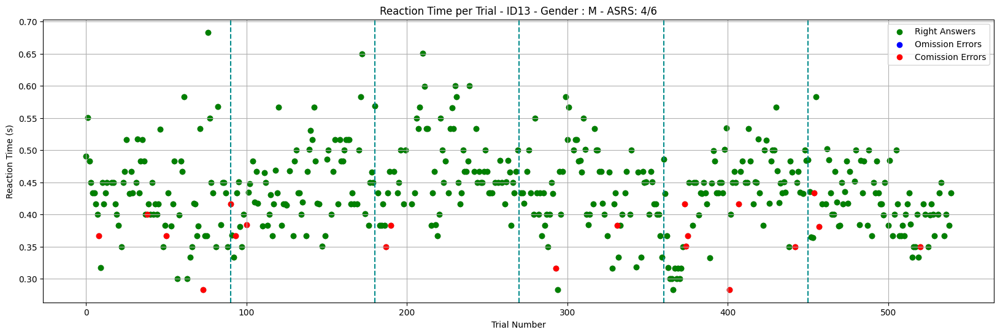

t=1.352907


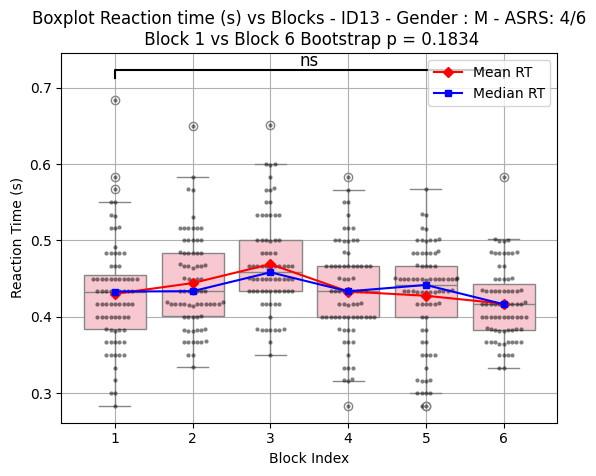

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334}]

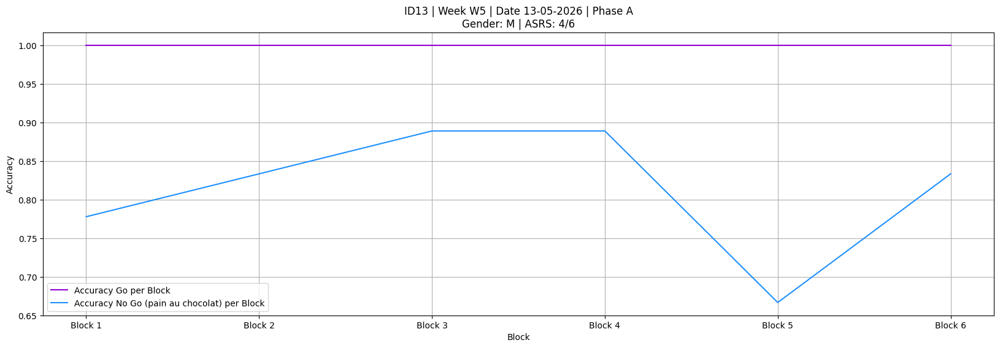

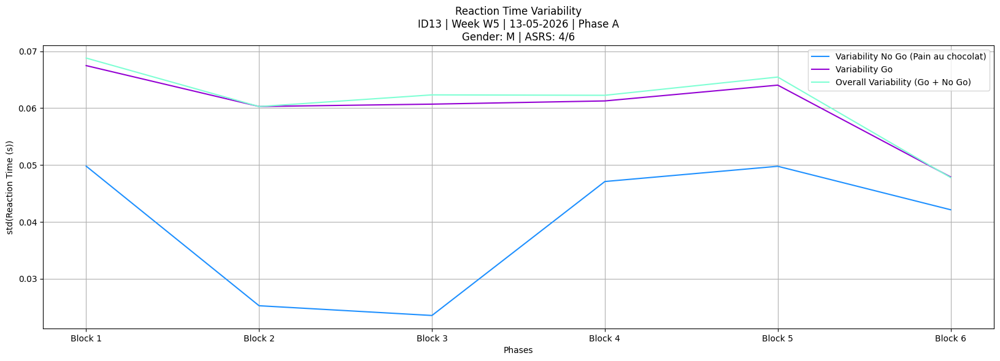

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,197.498686,Go,space,0.641366,Correct,False,False,13
1,1,1,198.523321,Go,space,0.516760,Correct,False,False,13
2,1,2,199.539936,No_Go,NaN,NaN,Correct,False,False,13
3,1,3,200.556717,Go,space,0.416646,Correct,False,False,13
4,1,4,201.573261,No_Go,NaN,NaN,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,850.468897,No_Go,NaN,NaN,Correct,False,False,13
536,6,536,851.481665,Go,space,0.406660,Correct,False,False,13
537,6,537,852.504913,Go,space,0.455141,Correct,False,False,13
538,6,538,853.515106,Go,space,0.489737,Correct,False,False,13


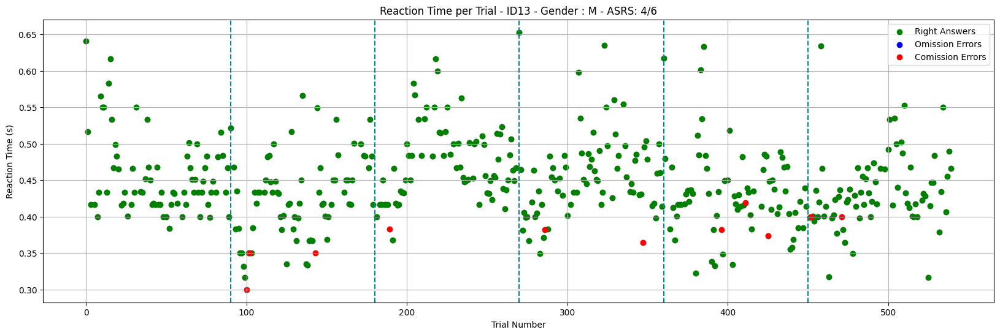

t=2.534956


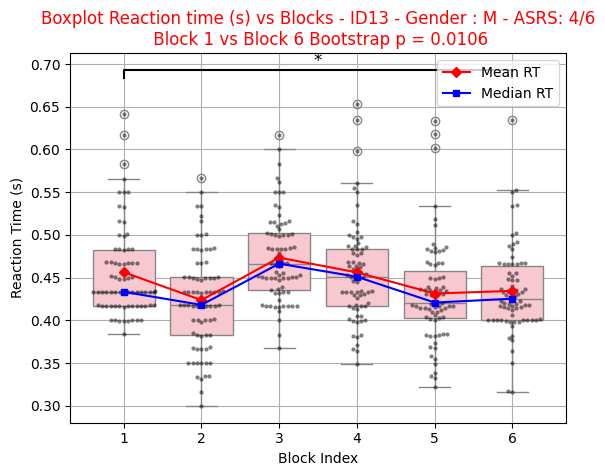

[{'Block': 'Block 1', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

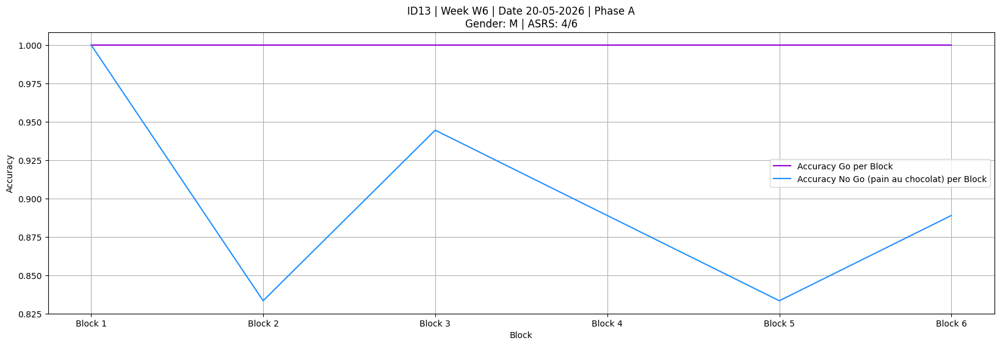

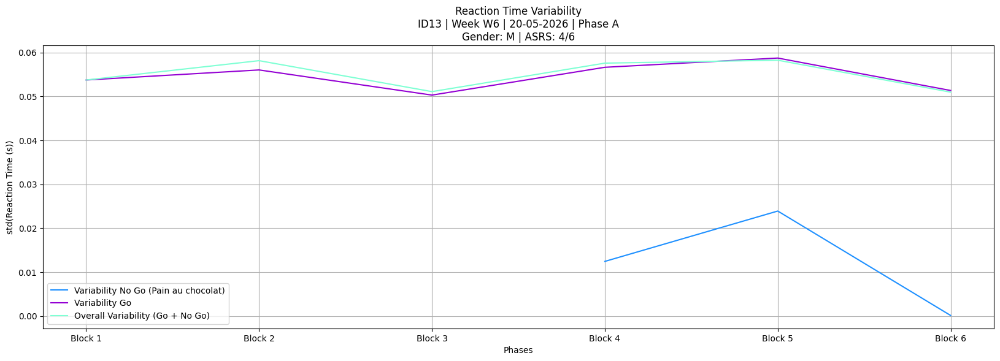

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,335.411978,Go,space,0.577119,Correct,False,False,13
1,1,1,336.455955,Go,space,0.482968,Correct,False,False,13
2,1,2,337.472467,Go,space,0.466658,Correct,False,False,13
3,1,3,338.489347,No_Go,space,0.416636,Incorrect,False,True,13
4,1,4,339.505877,No_Go,NaN,NaN,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,989.396372,Go,space,0.433311,Correct,False,False,13
536,6,536,990.412927,Go,space,0.450132,Correct,False,False,13
537,6,537,991.429425,No_Go,NaN,NaN,Correct,False,False,13
538,6,538,992.448336,Go,space,0.448005,Correct,False,False,13


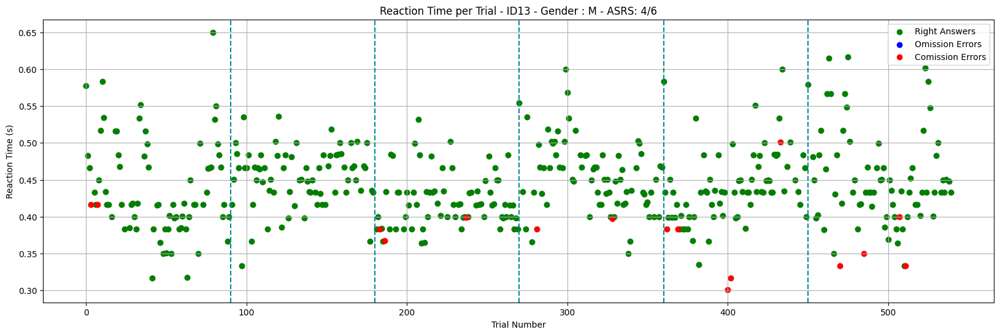

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=-1.081791


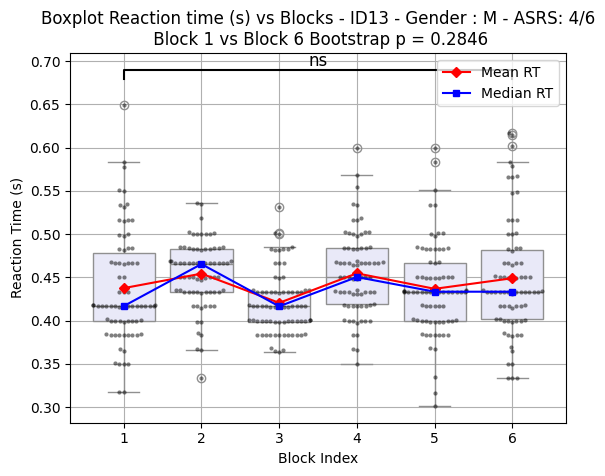

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778}]

SESSION DATE: 2026-05-22 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
9,2026-05-22,B,"20,12,12,20,30,30"


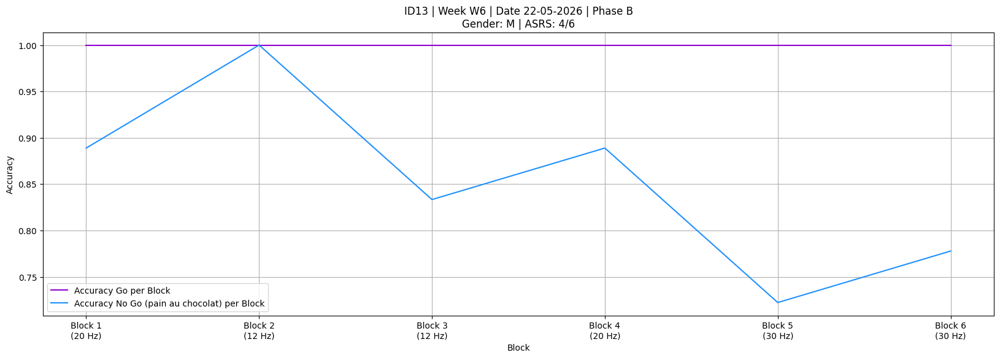

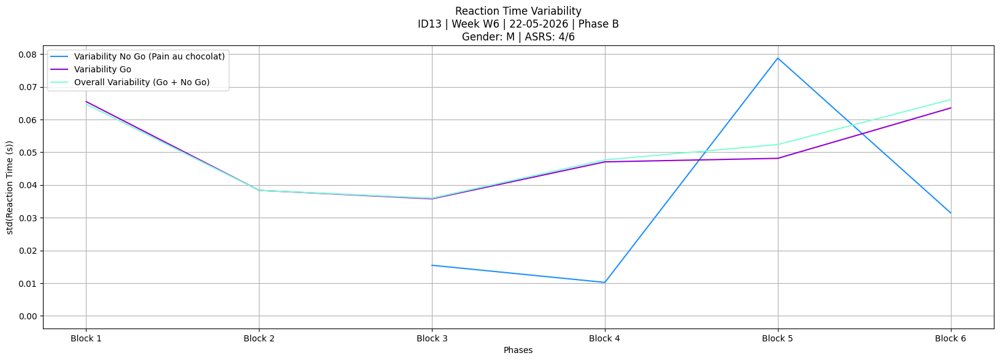

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,367.226742,Go,space,0.681528,Correct,False,False,13
1,1,1,368.257986,Go,space,0.483060,Correct,False,False,13
2,1,2,369.275622,Go,space,0.415560,Correct,False,False,13
3,1,3,370.291190,Go,space,0.399937,Correct,False,False,13
4,1,4,371.309119,Go,space,0.415269,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1019.829483,Go,space,0.516617,Correct,False,False,13
536,6,536,1020.845875,Go,space,0.466837,Correct,False,False,13
537,6,537,1021.862667,No_Go,NaN,NaN,Correct,False,False,13
538,6,538,1022.879559,Go,space,0.499889,Correct,False,False,13


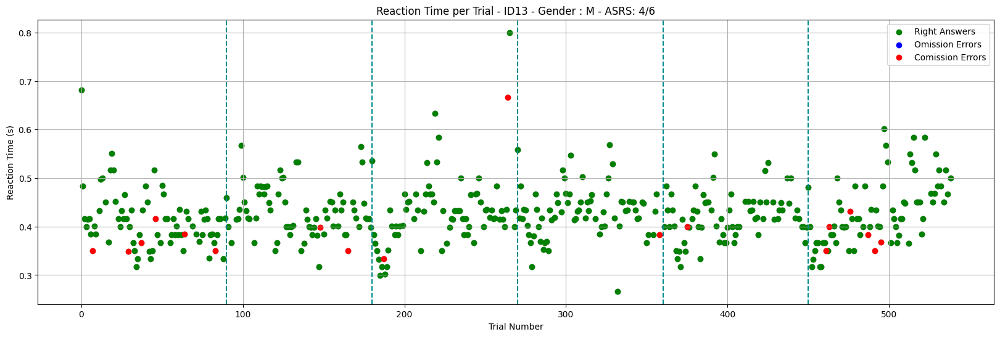

t=-1.707976


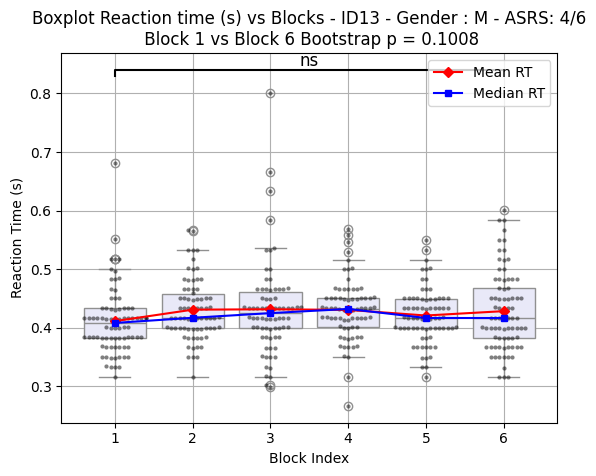

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6666666666666666}]

SESSION DATE: 2026-05-29 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
10,2026-05-29,B,"20,12,20,30,12,30"


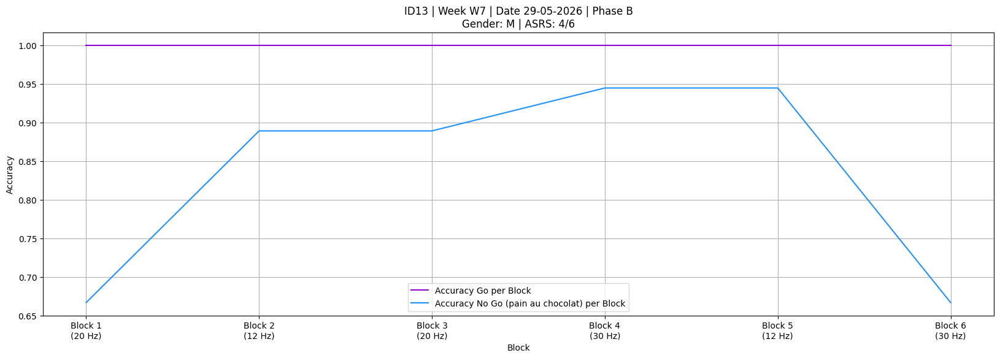

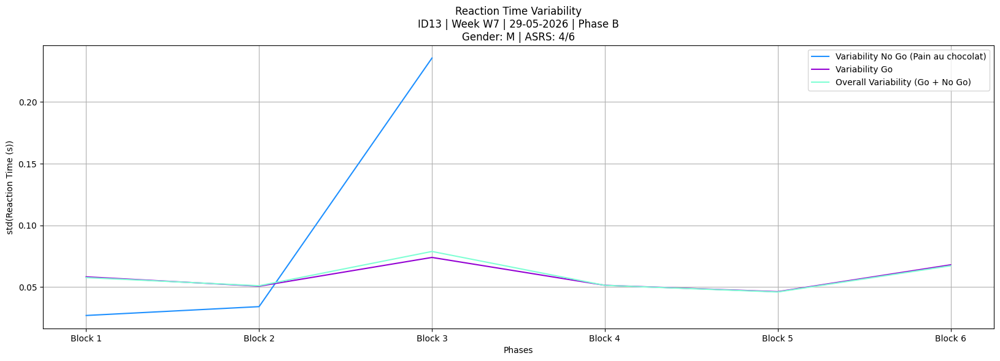

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,355.269825,Go,space,0.621713,Correct,False,False,13
1,1,1,356.324957,Go,space,0.483012,Correct,False,False,13
2,1,2,357.341588,Go,space,0.449912,Correct,False,False,13
3,1,3,358.358223,Go,space,0.466734,Correct,False,False,13
4,1,4,359.375031,Go,space,0.451015,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1002.729756,Go,space,0.333295,Correct,False,False,13
536,6,536,1003.746279,No_Go,space,0.383265,Incorrect,False,True,13
537,6,537,1004.762830,No_Go,NaN,NaN,Correct,False,False,13
538,6,538,1005.779505,Go,space,0.350278,Correct,False,False,13


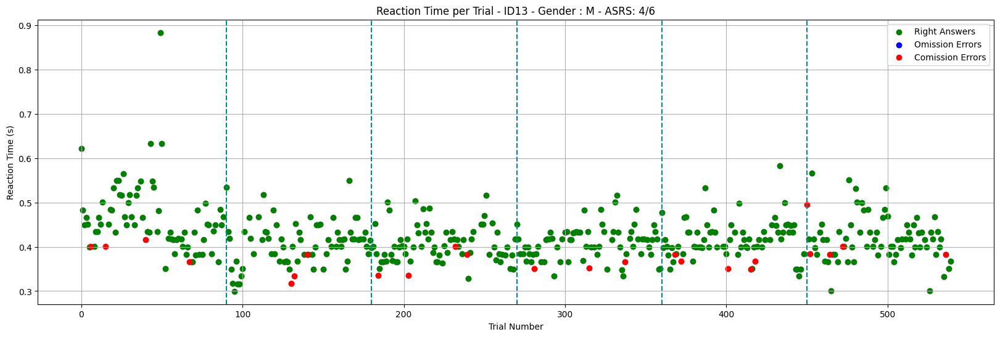

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=4.058423


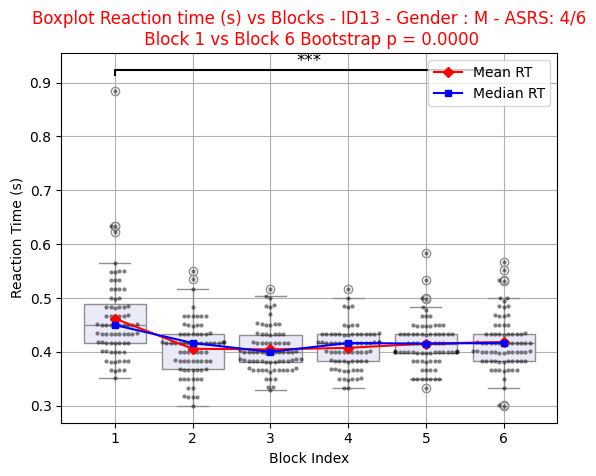

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222}]

SESSION DATE: 2026-06-02 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
11,2026-06-02,B,"20,20,12,30,12,30"


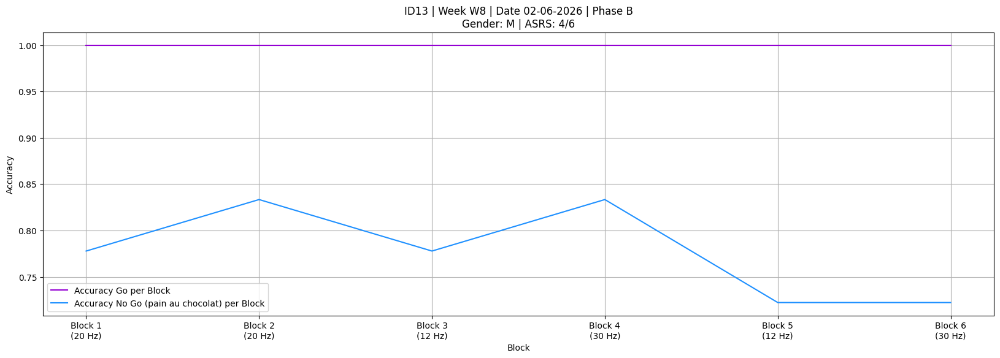

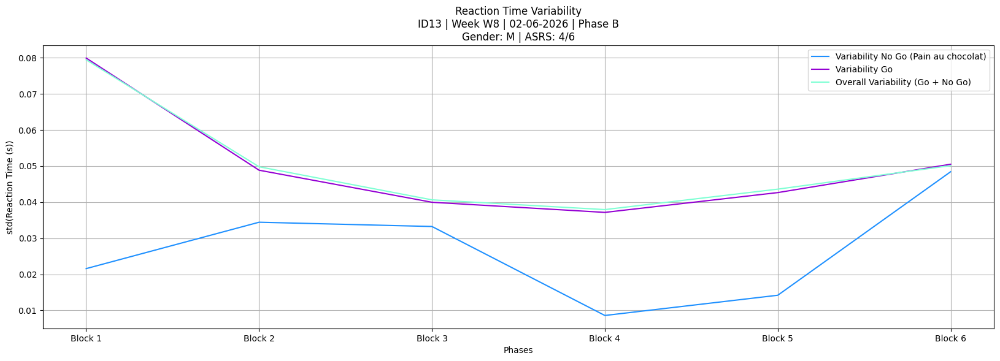

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,283.249347,Go,space,0.531572,Correct,False,False,13
1,1,1,284.263816,Go,space,0.450434,Correct,False,False,13
2,1,2,285.284625,Go,space,0.462261,Correct,False,False,13
3,1,3,286.296910,Go,space,0.516831,Correct,False,False,13
4,1,4,287.313410,Go,space,0.516810,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,952.717408,Go,space,0.400031,Correct,False,False,13
536,6,536,953.734105,Go,space,0.466556,Correct,False,False,13
537,6,537,954.750689,Go,space,0.483294,Correct,False,False,13
538,6,538,955.767365,Go,space,0.416751,Correct,False,False,13


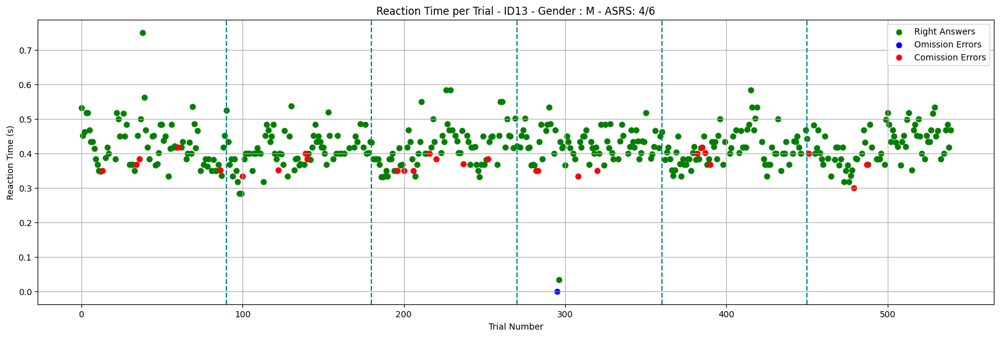

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=0.372044


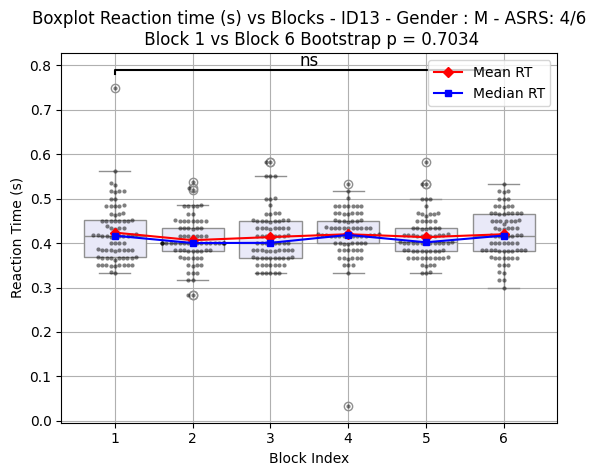

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7222222222222222},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.6111111111111112},
 {'Block': 'Block 4',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334}]

SESSION DATE: 2026-06-04 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
12,2026-06-04,B,"30,20,30,20,12,12"


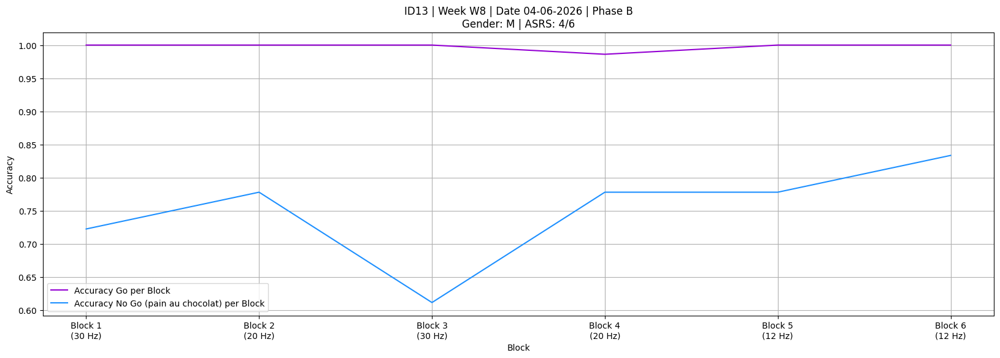

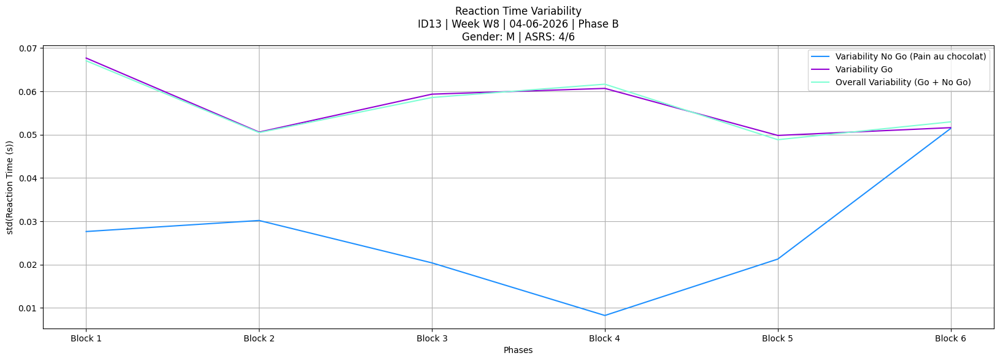

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,323.029364,Go,space,0.899720,Correct,False,False,13
1,1,1,324.045668,Go,space,0.583432,Correct,False,False,13
2,1,2,325.063065,Go,space,0.532632,Correct,False,False,13
3,1,3,326.078401,No_Go,NaN,NaN,Correct,False,False,13
4,1,4,327.095209,No_Go,space,0.416639,Incorrect,False,True,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,975.109982,Go,space,0.432625,Correct,False,False,13
536,6,536,976.125634,Go,space,0.433402,Correct,False,False,13
537,6,537,977.142993,Go,space,0.432925,Correct,False,False,13
538,6,538,978.159167,Go,space,0.433964,Correct,False,False,13


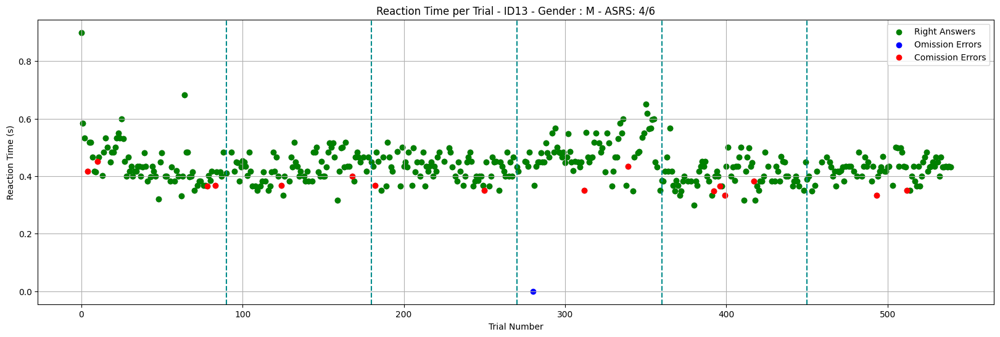

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 13.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=2.031707


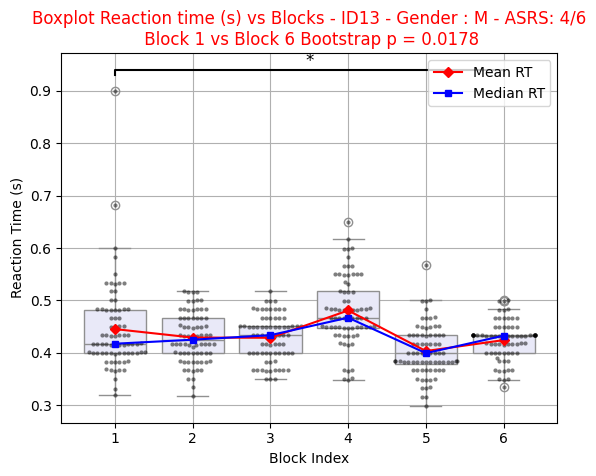

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4',
  'Accuracy Go': 0.9861111111111112,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888}]

SESSION DATE: 2026-06-08 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
13,2026-06-08,B,"12,20,30,20,30,12"


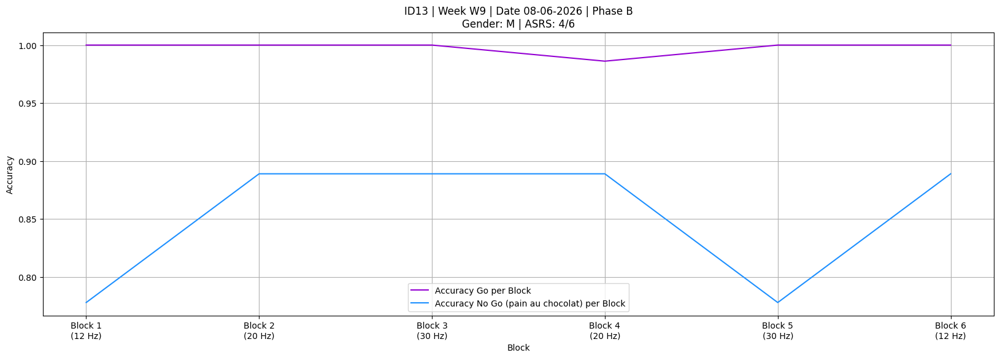

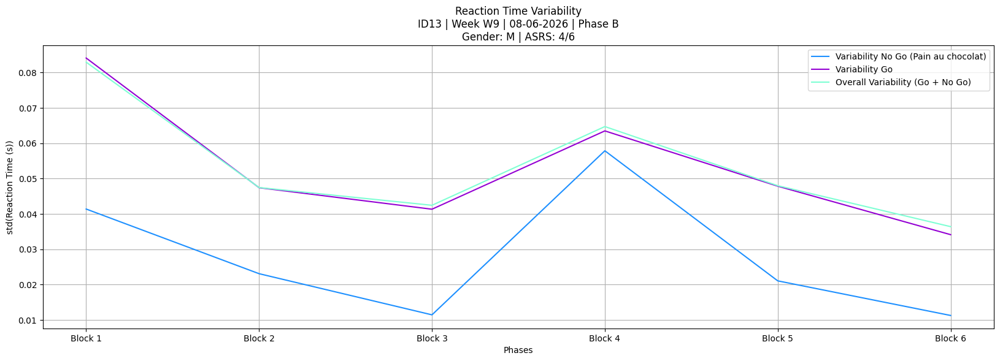

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,304.547201,No_Go,space,0.493770,Incorrect,False,True,13
1,1,1,305.556842,No_Go,NaN,NaN,Correct,False,False,13
2,1,2,306.573805,Go,space,0.533002,Correct,False,False,13
3,1,3,307.590511,Go,space,0.550593,Correct,False,False,13
4,1,4,308.607129,Go,space,0.583625,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,956.429412,No_Go,NaN,NaN,Correct,False,False,13
536,6,536,957.445993,Go,space,0.400092,Correct,False,False,13
537,6,537,958.462720,Go,space,0.383599,Correct,False,False,13
538,6,538,959.480085,Go,space,0.416209,Correct,False,False,13


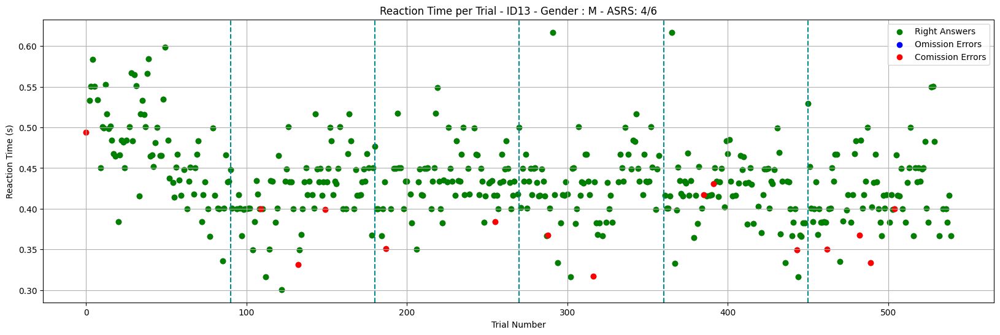

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=6.382071


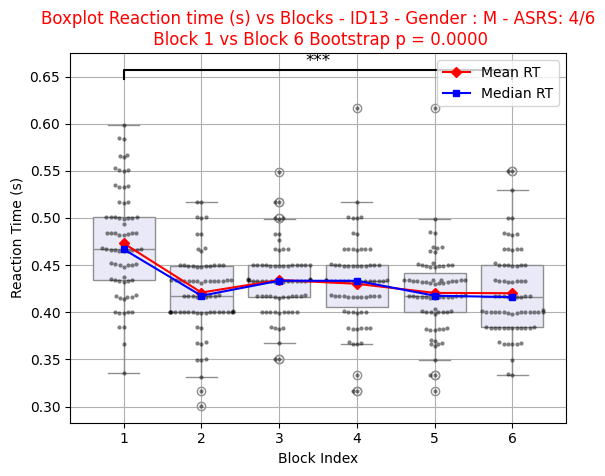

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 6',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778}]

SESSION DATE: 2026-06-10 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
14,2026-06-10,B,"30,30,12,20,20,12"


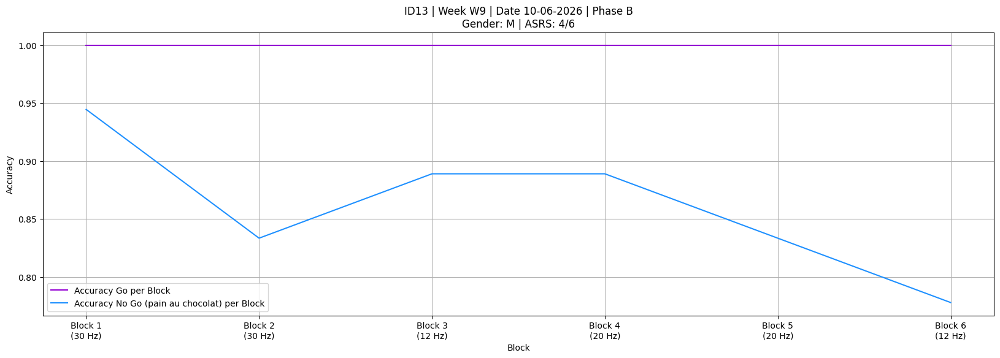

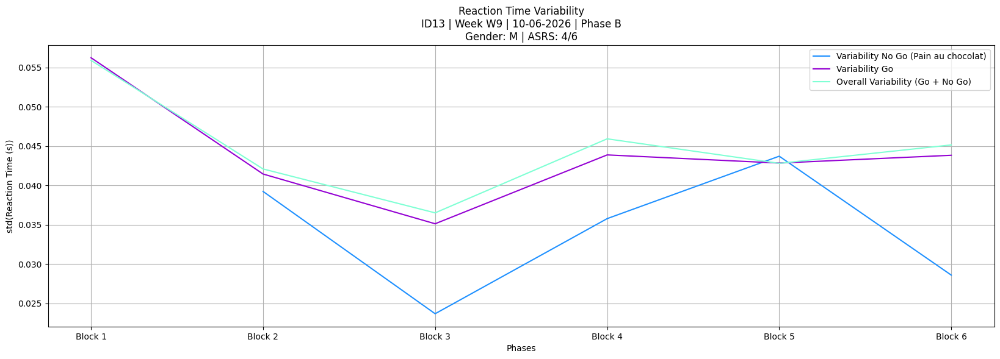

,block_index,trial,trial_onset(s),stimulus_type,resp_key,rt(s),correct,is_omission,is_comission,ID
0,1,0,424.578136,Go,space,0.530221,Correct,False,False,13
1,1,1,425.591992,Go,space,0.499297,Correct,False,False,13
2,1,2,426.608136,No_Go,NaN,NaN,Correct,False,False,13
3,1,3,427.625287,Go,space,0.433749,Correct,False,False,13
4,1,4,428.641484,Go,space,0.450301,Correct,False,False,13
...,...,...,...,...,...,...,...,...,...,...
535,6,535,1085.974262,Go,space,0.349953,Correct,False,False,13
536,6,536,1086.990824,Go,space,0.383206,Correct,False,False,13
537,6,537,1088.007494,Go,space,0.383397,Correct,False,False,13
538,6,538,1089.024024,Go,space,0.400178,Correct,False,False,13


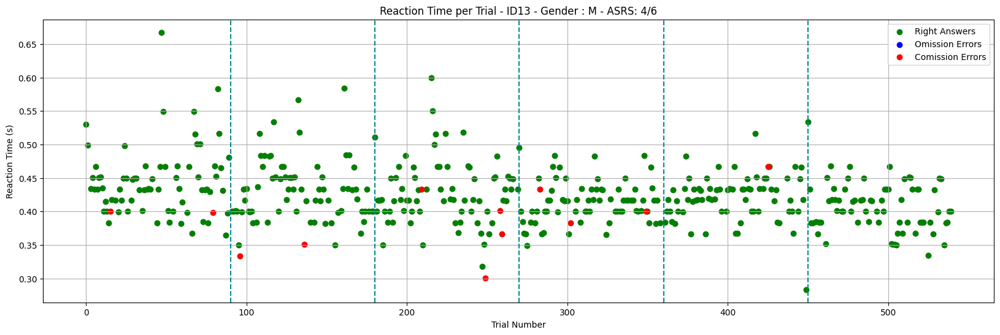

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


t=5.091161


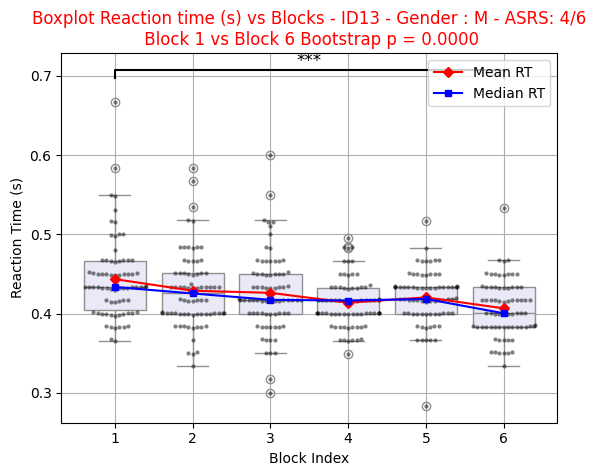

[{'Block': 'Block 1',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 2',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8888888888888888},
 {'Block': 'Block 3',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.7777777777777778},
 {'Block': 'Block 4',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.8333333333333334},
 {'Block': 'Block 5',
  'Accuracy Go': 1.0,
  'Accuracy No Go': 0.9444444444444444},
 {'Block': 'Block 6', 'Accuracy Go': 1.0, 'Accuracy No Go': 1.0}]

SESSION DATE: 2026-06-12 00:00:00
MATCHED ROW:


,DATE,PHASE,F_ORDER
15,2026-06-12,B,"12,30,12,30,20,20"


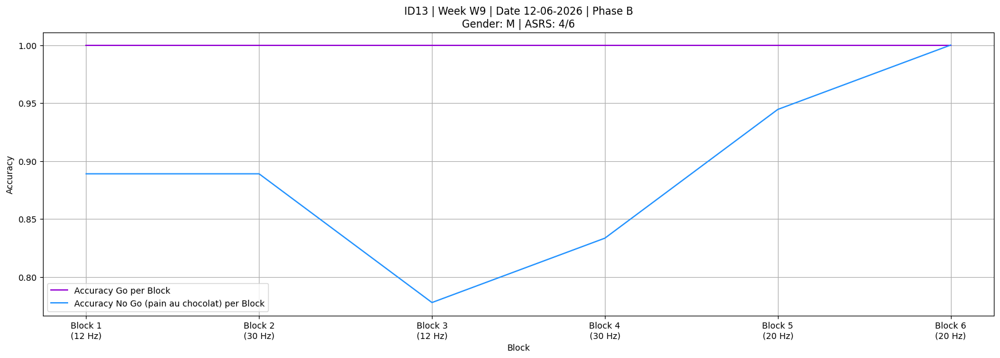

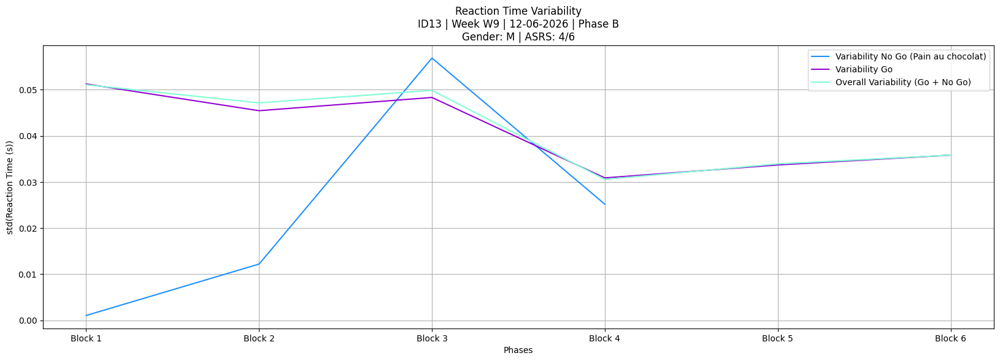

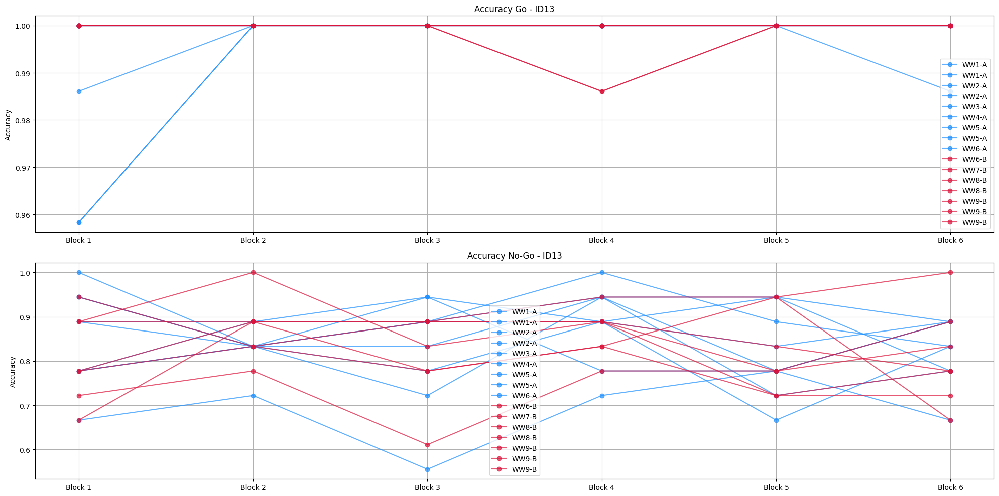

DATE: 2026-05-22 00:00:00
DATE: 2026-05-29 00:00:00
DATE: 2026-06-02 00:00:00
DATE: 2026-06-04 00:00:00
DATE: 2026-06-08 00:00:00
DATE: 2026-06-10 00:00:00
DATE: 2026-06-12 00:00:00


,DATE,PHASE,Go_12,Go_20,Go_30,NoGo_12,NoGo_20,NoGo_30,MeanGo,MeanNoGo
0,2026-04-14,A,0.990741,0.990741,0.990741,0.842593,0.842593,0.842593,NaN,NaN
1,2026-04-17,A,0.997685,0.997685,0.997685,0.722222,0.722222,0.722222,NaN,NaN
2,2026-04-22,A,0.993056,0.993056,0.993056,0.787037,0.787037,0.787037,NaN,NaN
3,2026-04-23,A,1.000000,1.000000,1.000000,0.861111,0.861111,0.861111,NaN,NaN
4,2026-04-28,A,1.000000,1.000000,1.000000,0.833333,0.833333,0.833333,NaN,NaN
5,2026-05-06,A,1.000000,1.000000,1.000000,0.898148,0.898148,0.898148,NaN,NaN
6,2026-05-11,A,1.000000,1.000000,1.000000,0.907407,0.907407,0.907407,NaN,NaN
7,2026-05-13,A,1.000000,1.000000,1.000000,0.814815,0.814815,0.814815,NaN,NaN
8,2026-05-20,A,1.000000,1.000000,1.000000,0.898148,0.898148,0.898148,NaN,NaN
9,2026-05-22,B,1.000000,1.000000,1.000000,0.916667,0.888889,0.750000,1.000000,0.851852


t=-1.972788
t=-3.067300
t=1.846929
t=1.028992


/tmp/ipykernel_1316/346653522.py:91: RuntimeWarning: divide by zero encountered in scalar divide
  t_distrib[b] = (np.mean(draw_x)-np.mean(draw_y))/np.sqrt(np.var(draw_x)/n+np.var(draw_y)/m)


t=-1.727578
Go A-A   p = 0.0154
Go A-B   p = 1.0000
Go B-B   p = 0.1406
NoGo A-A p = 0.0082
NoGo A-B p = 0.0884
NoGo B-B p = 0.1002


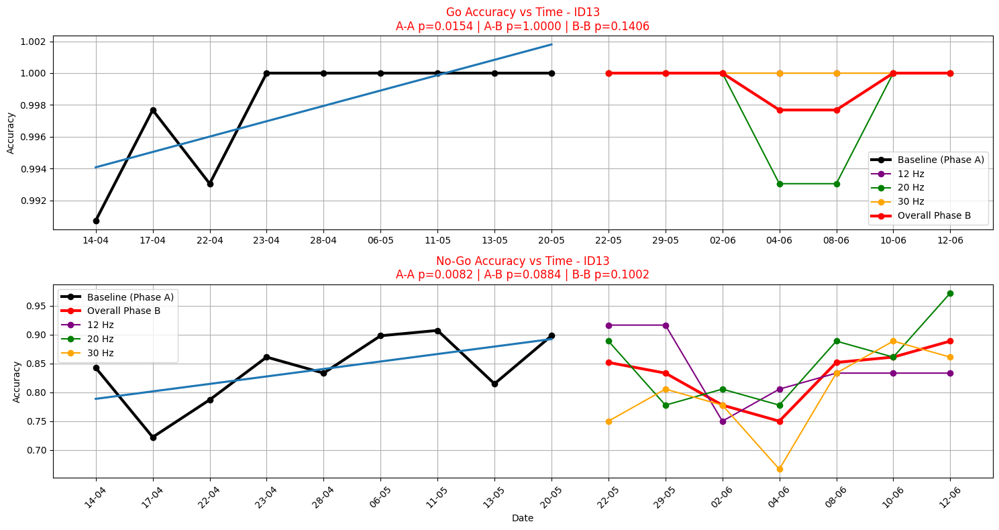

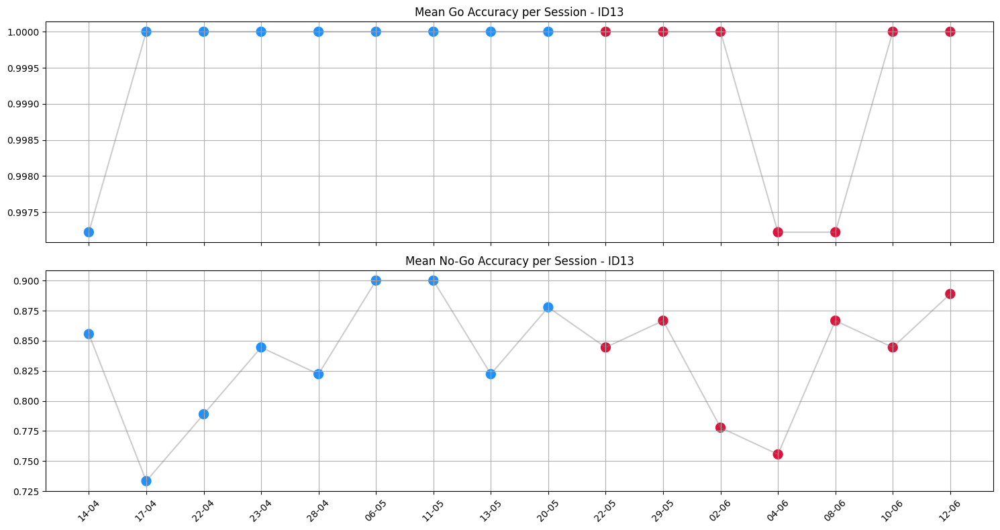

DATE: 2026-05-22 00:00:00
DATE: 2026-05-29 00:00:00
DATE: 2026-06-02 00:00:00
DATE: 2026-06-04 00:00:00
DATE: 2026-06-08 00:00:00
DATE: 2026-06-10 00:00:00
DATE: 2026-06-12 00:00:00


,DATE,Go_12,NoGo_12,Go_20,NoGo_20,Go_30,NoGo_30,MeanGo,MeanNoGo
0,2026-05-22,1.0,0.916667,1.000000,0.888889,1.0,0.750000,1.000000,0.851852
1,2026-05-29,1.0,0.916667,1.000000,0.777778,1.0,0.805556,1.000000,0.833333
2,2026-06-02,1.0,0.750000,1.000000,0.805556,1.0,0.777778,1.000000,0.777778
3,2026-06-04,1.0,0.805556,0.993056,0.777778,1.0,0.666667,0.997685,0.750000
4,2026-06-08,1.0,0.833333,0.993056,0.888889,1.0,0.833333,0.997685,0.851852
5,2026-06-10,1.0,0.833333,1.000000,0.861111,1.0,0.888889,1.000000,0.861111
6,2026-06-12,1.0,0.833333,1.000000,0.972222,1.0,0.861111,1.000000,0.888889


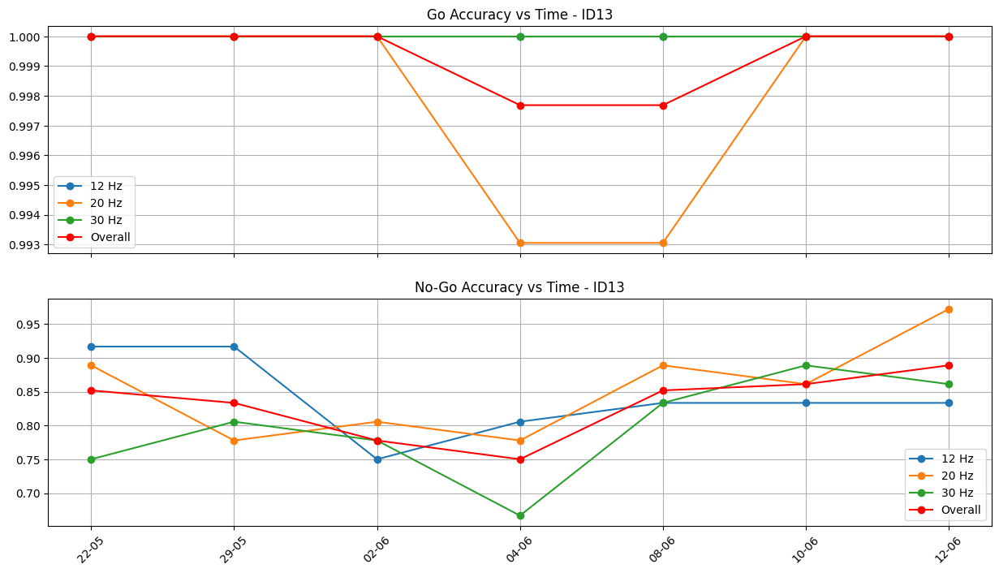

t=3.220990
t=2.677486
t=-0.211179


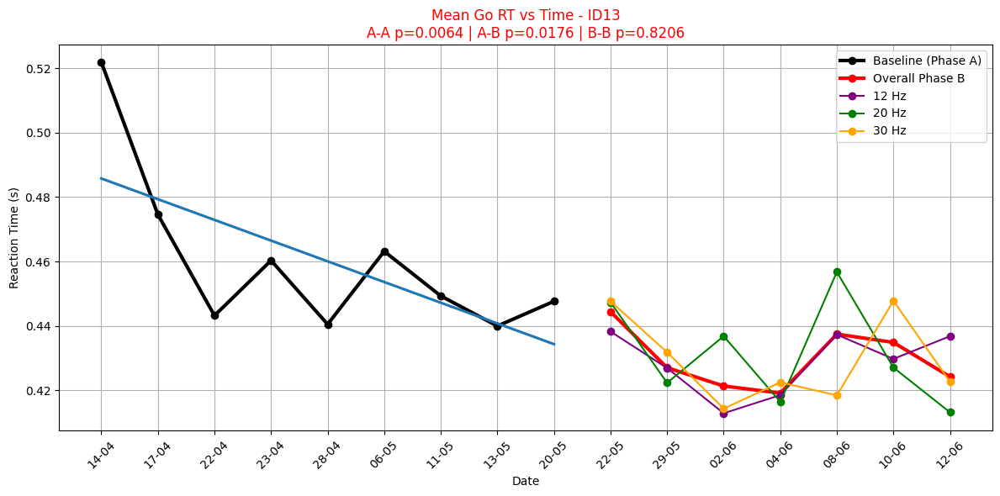

t=7.028779
t=1.068536
t=1.594846


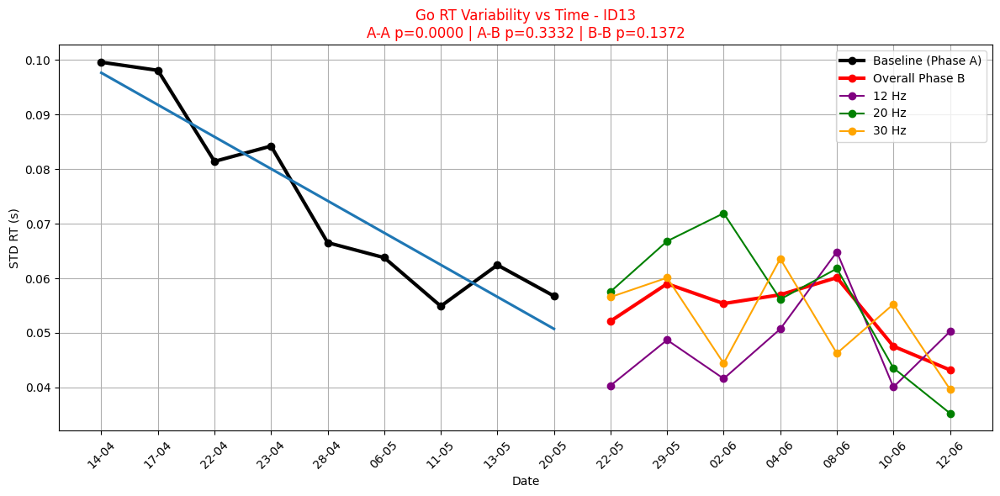

t=-3.578486
t=1.556046
t=-1.085942


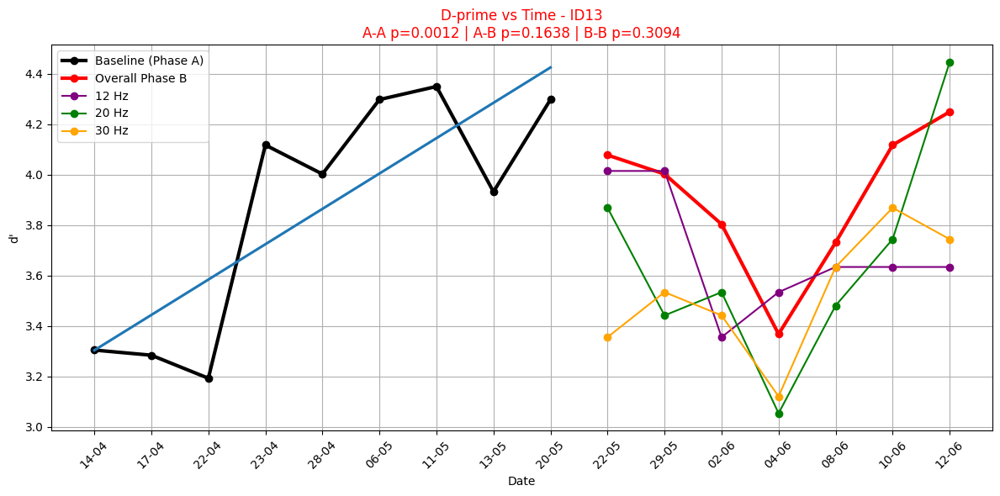

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime_All,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-14,A,4/6,NaN,NaN,NaN,3.304061,0.997222,0.855556,0.095490
1,2026-04-17,A,4/6,NaN,NaN,NaN,3.283653,1.000000,0.733333,0.091745
2,2026-04-22,A,4/6,NaN,NaN,NaN,3.192292,1.000000,0.788889,0.068872
3,2026-04-23,A,4/6,NaN,NaN,NaN,4.117727,1.000000,0.844444,0.074467
4,2026-04-28,A,4/6,7.0,3.0,5.0,4.002502,1.000000,0.822222,0.061285
5,2026-05-06,A,4/6,7.0,4.0,0.0,4.298044,1.000000,0.900000,0.054865
6,2026-05-11,A,4/6,8.0,3.0,0.0,4.349997,1.000000,0.900000,0.051462
7,2026-05-13,A,4/6,8.0,4.0,0.0,3.932267,1.000000,0.822222,0.058829
8,2026-05-20,A,4/6,9.0,4.0,0.0,4.298044,1.000000,0.877778,0.054592
9,2026-05-22,B,4/6,8.0,3.0,0.0,4.077797,1.000000,0.844444,0.046571


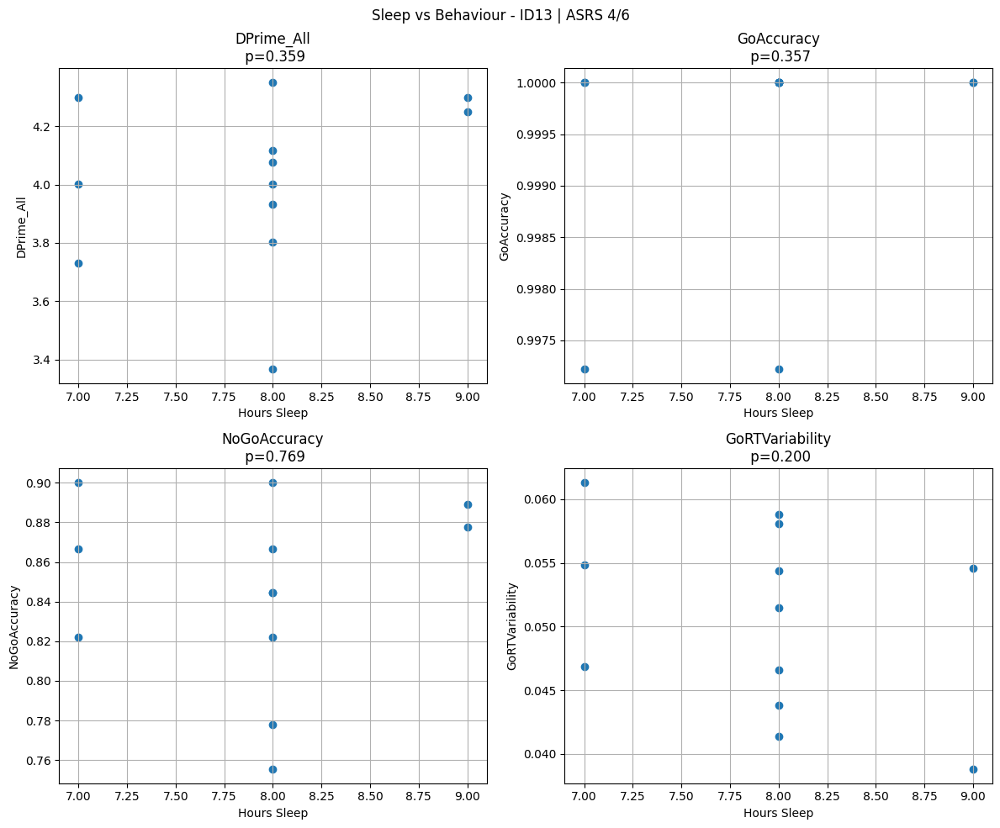

,DATE,PHASE,ASRS,HRS_SLEEP,MOOD,TIRED,DPrime_All,GoAccuracy,NoGoAccuracy,GoRTVariability
0,2026-04-14,A,4/6,NaN,NaN,NaN,3.304061,0.997222,0.855556,0.095490
1,2026-04-17,A,4/6,NaN,NaN,NaN,3.283653,1.000000,0.733333,0.091745
2,2026-04-22,A,4/6,NaN,NaN,NaN,3.192292,1.000000,0.788889,0.068872
3,2026-04-23,A,4/6,NaN,NaN,NaN,4.117727,1.000000,0.844444,0.074467
4,2026-04-28,A,4/6,7.0,3.0,5.0,4.002502,1.000000,0.822222,0.061285
5,2026-05-06,A,4/6,7.0,4.0,0.0,4.298044,1.000000,0.900000,0.054865
6,2026-05-11,A,4/6,8.0,3.0,0.0,4.349997,1.000000,0.900000,0.051462
7,2026-05-13,A,4/6,8.0,4.0,0.0,3.932267,1.000000,0.822222,0.058829
8,2026-05-20,A,4/6,9.0,4.0,0.0,4.298044,1.000000,0.877778,0.054592
9,2026-05-22,B,4/6,8.0,3.0,0.0,4.077797,1.000000,0.844444,0.046571


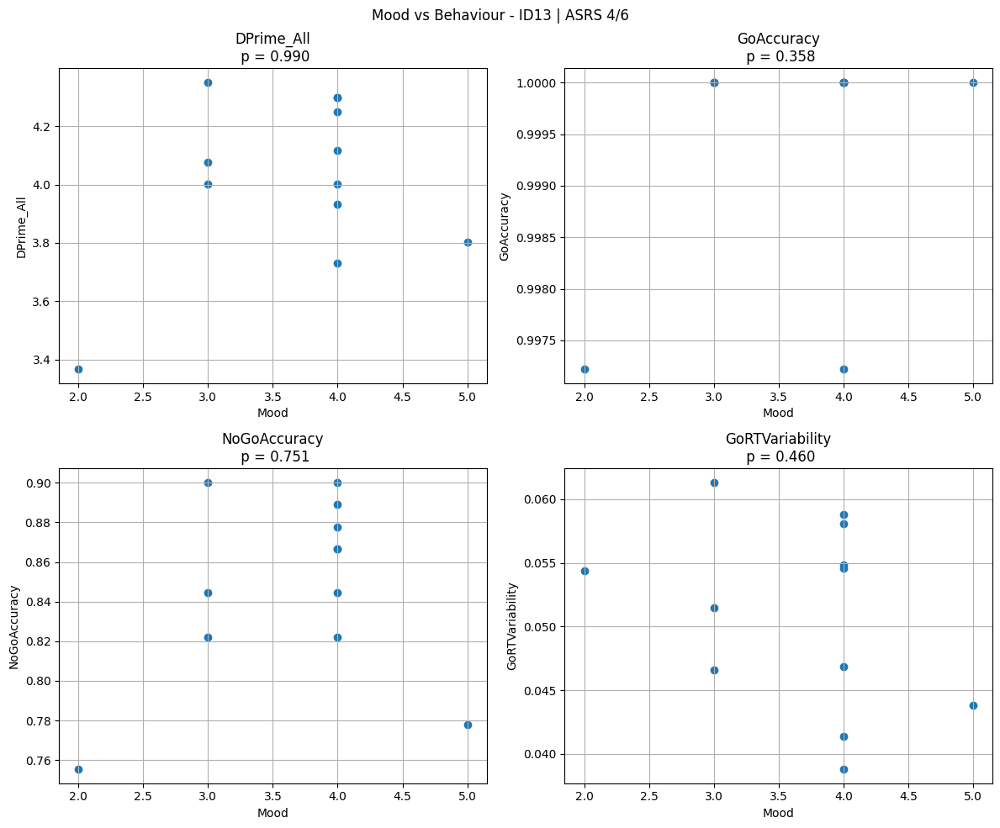

,Metric,n_A,n_B,Mean_A,Mean_B,Observed_Diff,NAP,TauU,Permutation_p
0,DPrime_All,9,7,3.864287,3.907013,0.042725,0.476190,-0.047619,0.4271
1,Variability_Go,9,7,0.069648,0.050300,0.019348,0.920635,0.841270,0.0013
2,Accuracy_NoGo,9,7,0.840535,0.830688,-0.009847,0.428571,-0.142857,0.6313


In [1044]:
df_id13 = pipeline(id = 13)
#display(df_clean_list)
sced_df = sced_metrics(df_id13)
display(sced_df)

#**STATISTICAL TECHNIQUES**

In [ ]:
def df_results_statistical(df):

    df_sign = df.copy()

    cols = ["RT_Go", "Omission", "Commission", "Accuracy"]

    for col in cols:
        df_sign[col] = df_sign[col].apply(lambda x: x if x < 0.05 else np.nan)

    #df_sign = df_sign.fillna("")

    return df_sign

In [ ]:
def get_statistical_table(week):
  all_results = []

  list_participants = get_list_participants(week = week)

  for participant in list_participants:
      id = participant[2:]

      results = pipeline_statistical_test(id=id, week = week)

      row = {
          "ID": id,

          "RT_Go": results["RT_Go"],
          "RT_Go_improved": results["RT_Go_improved"],

          "Omission": results["Omission"],
          "Omission_improved": results["Omission_improved"],

          "Commission": results["Commission"],
          "Commission_improved": results["Commission_improved"],

          "Accuracy": results["Accuracy"],
          "Accuracy_improved": results["Accuracy_improved"]
      }

      all_results.append(row)

  df_results = pd.DataFrame(all_results)
  return df_results

In [ ]:
#@title W1
df_results_statistical(df = get_statistical_table(week = "W1"))
#ID8 I CAN AUGMENT THE DIFFICULTY, ID10 MAYBE

['ID2', 'ID6', 'ID10', 'ID13', 'ID8', 'ID5']
['ID2', 'ID6', 'ID10', 'ID13', 'ID8', 'ID5']
['ID2', 'ID6', 'ID10', 'ID13', 'ID8', 'ID5']
['ID2', 'ID6', 'ID10', 'ID13', 'ID8', 'ID5']
['ID2', 'ID6', 'ID10', 'ID13', 'ID8', 'ID5']
['ID2', 'ID6', 'ID10', 'ID13', 'ID8', 'ID5']


,ID,RT_Go,RT_Go_improved,Omission,Omission_improved,Commission,Commission_improved,Accuracy,Accuracy_improved
0,2,NaN,False,NaN,True,NaN,True,NaN,True
1,6,8.146891e-11,True,NaN,True,NaN,True,NaN,True
2,10,NaN,False,1.652168e-18,True,NaN,True,5.850919e-16,True
3,13,1.394969e-13,True,NaN,True,NaN,False,NaN,False
4,8,5.508491e-03,True,1.503010e-17,True,NaN,True,1.642303e-08,True
5,5,7.104902e-05,True,NaN,True,NaN,False,NaN,False


In [ ]:
#@title W2
df_results_statistical(df = get_statistical_table(week = "W2"))
#ID8 I CAN AUGMENT THE DIFFICULTY, ID10 MAYBE

['ID2', 'ID5', 'ID6', 'ID8', 'ID10', 'ID13']
['ID2', 'ID5', 'ID6', 'ID8', 'ID10', 'ID13']
['ID2', 'ID5', 'ID6', 'ID8', 'ID10', 'ID13']
['ID2', 'ID5', 'ID6', 'ID8', 'ID10', 'ID13']
['ID2', 'ID5', 'ID6', 'ID8', 'ID10', 'ID13']
['ID2', 'ID5', 'ID6', 'ID8', 'ID10', 'ID13']


,ID,RT_Go,RT_Go_improved,Omission,Omission_improved,Commission,Commission_improved,Accuracy,Accuracy_improved
0,2,1.207159e-06,False,NaN,False,0.014154,True,0.014154,True
1,5,8.936662e-05,True,NaN,False,NaN,False,NaN,False
2,6,3.503116e-11,False,NaN,False,NaN,True,NaN,True
3,8,1.442729e-03,True,NaN,False,NaN,False,NaN,False
4,10,6.993802e-03,False,NaN,False,NaN,True,NaN,True
5,13,NaN,False,NaN,True,NaN,False,NaN,True


In [ ]:
def df_results_statistical_corrected_only(df):

    df_sign = df.copy()

    cols = ["RT_Go_corr", "Omission_corr", "Commission_corr", "Accuracy_corr"]

    for col in cols:
        df_sign[col] = df_sign[col].apply(
            lambda x: x if x < 0.05 else np.nan
        )

    df_final = df_sign[[
        "ID",
        "RT_Go_corr", "RT_Go_improved",
        "Omission_corr", "Omission_improved",
        "Commission_corr", "Commission_improved",
        "Accuracy_corr", "Accuracy_improved"
    ]]

    return df_final

In [ ]:
from statsmodels.stats.multitest import multipletests

def show_statistical_test(df_results):
  cols = ["RT_Go", "Omission", "Commission", "Accuracy"]

  #24
  p_values = df_results[cols].values.flatten()
  _, p_corrected, _, _ = multipletests(p_values, method='fdr_bh')
  p_corrected_matrix = np.array(p_corrected).reshape(df_results[cols].shape)

  for i, col in enumerate(cols):
      df_results[col + "_corr"] = p_corrected_matrix[:, i]

  df_sign = df_results_statistical_corrected_only(df_results)
  return df_sign

In [ ]:
#@title W1
df_sign = show_statistical_test(df_results = get_statistical_table(week = "W1"))
df_sign

['ID2', 'ID6', 'ID10', 'ID13', 'ID8', 'ID5']
['ID2', 'ID6', 'ID10', 'ID13', 'ID8', 'ID5']
['ID2', 'ID6', 'ID10', 'ID13', 'ID8', 'ID5']
['ID2', 'ID6', 'ID10', 'ID13', 'ID8', 'ID5']
['ID2', 'ID6', 'ID10', 'ID13', 'ID8', 'ID5']
['ID2', 'ID6', 'ID10', 'ID13', 'ID8', 'ID5']


,ID,RT_Go_corr,RT_Go_improved,Omission_corr,Omission_improved,Commission_corr,Commission_improved,Accuracy_corr,Accuracy_improved
0,2,NaN,False,NaN,True,NaN,True,NaN,True
1,6,3.910508e-10,True,NaN,True,NaN,True,NaN,True
2,10,NaN,False,3.965203e-17,True,NaN,True,4.680735e-15,True
3,13,8.369812e-13,True,NaN,True,NaN,False,NaN,False
4,8,1.652547e-02,True,1.803612e-16,True,NaN,True,6.569213e-08,True
5,5,2.435966e-04,True,NaN,True,NaN,False,NaN,False


In [ ]:
#@title W2
df_sign = show_statistical_test(df_results = get_statistical_table(week = "W2"))
df_sign

['ID2', 'ID5', 'ID6', 'ID8', 'ID10', 'ID13']
['ID2', 'ID5', 'ID6', 'ID8', 'ID10', 'ID13']
['ID2', 'ID5', 'ID6', 'ID8', 'ID10', 'ID13']
['ID2', 'ID5', 'ID6', 'ID8', 'ID10', 'ID13']
['ID2', 'ID5', 'ID6', 'ID8', 'ID10', 'ID13']
['ID2', 'ID5', 'ID6', 'ID8', 'ID10', 'ID13']


,ID,RT_Go_corr,RT_Go_improved,Omission_corr,Omission_improved,Commission_corr,Commission_improved,Accuracy_corr,Accuracy_improved
0,2,1.448590e-05,False,NaN,False,0.048528,True,0.048528,True
1,5,7.149330e-04,True,NaN,False,NaN,False,NaN,False
2,6,8.407480e-10,False,NaN,False,NaN,True,NaN,True
3,8,8.656373e-03,True,NaN,False,NaN,False,NaN,False
4,10,3.357025e-02,False,NaN,False,NaN,True,NaN,True
5,13,NaN,False,NaN,True,NaN,False,NaN,True
